# Example 4.4 — Transformations across seven target classes, one document at a time

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:59:42Z
- **Contents:** 2 exchanges · 44 tool calls · 1 figure · 3 code cells

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/`, the figures in `figures/` and the analysis code the notebook imports (`plot_transformation_effects.py`, `transformation_tables.py`). With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/4.4-transformations-by-target-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 4.4-transformations-by-target-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 4.4-transformations-by-target-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/4.4-transformations-by-target-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 4.4-transformations-by-target-notebook-rerun.ipynb 4.4-transformations-by-target-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Is the fluorine effect target-specific? Compare what adding a fluorine, a methyl and a chlorine do across a kinase, a protease, a hydrolase, a metalloenzyme, a GPCR, an ion channel and a nuclear receptor — and only count a pair when both compounds were measured in the same patent or paper.

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(1, 'search_targets', {'query': 'epidermal growth factor receptor', 'organism': 'Homo sapiens', 'limit': 4},
                  sha256='a55996f689d22835673edbc79a3ea21726f23b92656c61065a36b637ef0381f1')

**Call 1** · `search_targets` · recorded result · sha256 `a55996f689d2…`

_4 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 520 | Epidermal growth factor receptor | P00533 | P00533 | Homo sapiens | Receptor Kinase Domain | 23267 | 14127 | Epidermal growth factor receptor |
| polymer | 5143 | Receptor tyrosine-protein kinase erbB-4 | Q15303 | Q15303 | Homo sapiens | Protein | 512 | 399 | Epidermal growth factor receptor |
| polymer | 60 | Epidermal growth factor receptor \[T790M,L858R\] | P00533 | P00533\[T790M,L858R\] | Homo sapiens |  | 1536 | 1276 | Epidermal growth factor receptor (T790M/L858R) |
| polymer | 1058 | Epidermal growth factor receptor \[L858R,T790M,C797S\] | P00533 | P00533\[L858R,T790M,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 703 | 679 | Epidermal growth factor receptor \[L858R,T790M,C797S\] |


In [ ]:
# Call 2 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(2, 'search_targets', {'query': 'beta-secretase 1', 'organism': 'Homo sapiens', 'limit': 4},
                  sha256='6286144dba0c792c94fa9792f2a57a49ee12f94e70792ed38fbfef3b438a4e04')

**Call 2** · `search_targets` · recorded result · sha256 `6286144dba0c…`

_4 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 5093 | Beta-secretase 1 | P56817 | P56817 | Homo sapiens | Protein | 14808 | 10964 | Beta-secretase 1 |
| polymer | 198 | Beta-secretase 1 \[1-458\] | P56817 | P56817\[1-458\] | Homo sapiens |  | 549 | 541 | Beta-secretase 1 \[1-458\] |
| polymer | 512 | Beta-secretase 1 \[1-460\] | P56817 | P56817\[1-460\] | Homo sapiens | Protein | 195 | 169 | Beta-secretase 1 (BACE1) |
| polymer | 5986 | Isoform C of Beta-secretase 1 (BACE-I-457) | P56817 | P56817-3 | Homo sapiens | Enzyme | 166 | 163 | Beta-secretase 1 (BACE) |


In [ ]:
# Call 3 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(3, 'search_targets', {'query': 'acetylcholinesterase', 'organism': 'Homo sapiens', 'limit': 4},
                  sha256='60aa6ce0ec5bcb0b511280c41d326395cb9a65eb17d4858ad87d4c91439c961d')

**Call 3** · `search_targets` · recorded result · sha256 `60aa6ce0ec5b…`

_1 row_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 3619 | Acetylcholinesterase | P22303 | P22303 | Homo sapiens | Enzyme | 9820 | 7560 | Acetylcholinesterase |


In [ ]:
# Call 4 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(4, 'search_targets', {'query': 'carbonic anhydrase II', 'organism': 'Homo sapiens', 'limit': 4},
                  sha256='23ae2a6007bface58170b2ad5e37e33ccdc1975f60dcbf8cacb01b0fcdc39d0e')

**Call 4** · `search_targets` · recorded result · sha256 `23ae2a6007bf…`

_3 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 1193 | Carbonic anhydrase 2 | P00918 | P00918 | Homo sapiens | Enzyme | 15712 | 10535 | Carbonic anhydrase II (CAII) |
| polymer | 2920 | Carbonic anhydrase 3 | P07451 | P07451 | Homo sapiens | Enzyme | 575 | 342 | Carbonic Anhydrase III |
| polymer | 1277 | Carbonic anhydrase 2 \[F130V\] | P00918 | P00918\[F130V\] | Homo sapiens | Enzyme | 11 | 11 | Carbonic Anhydrase II Mutant (F130V) |


In [ ]:
# Call 5 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(5, 'search_targets', {'query': 'adenosine A2a receptor', 'organism': 'Homo sapiens', 'limit': 4},
                  sha256='0bbe6b1b17625336f4a157ffdac020c50141325948153c005fcc64a6f78462c5')

**Call 5** · `search_targets` · recorded result · sha256 `0bbe6b1b1762…`

_1 row_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 2130 | Adenosine receptor A2a | P29274 | P29274 | Homo sapiens | G Protein-Coupled Receptor (GPCR) | 11958 | 9910 | Adenosine A2A receptor (A2AAR) |


In [ ]:
# Call 6 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(6, 'search_targets', {'query': 'hERG', 'organism': 'Homo sapiens', 'limit': 4},
                  sha256='b14861d4039ba744ef6cb571201c65d3fcedfb8f7b5a191d71fc44c4fa44932a')

**Call 6** · `search_targets` · recorded result · sha256 `b14861d4039b…`

_2 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 2132 | Potassium voltage-gated channel subfamily H member 2 | Q12809 | Q12809 | Homo sapiens | Multi-pass membrane protein | 18767 | 14872 | HERG |
| polymer | 50001229 | Potassium voltage-gated channel subfamily H member 6 | Q9H252 | Q9H252 | Homo sapiens | PROTEIN | 1 | 1 | hERG2 |


In [ ]:
# Call 7 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(7, 'search_targets', {'query': 'RAR-related orphan receptor gamma', 'organism': 'Homo sapiens', 'limit': 4},
                  sha256='cf2a6a6581755d65007001f7836971eaac735ee0ac6a128f285354e5aa2d0959')

**Call 7** · `search_targets` · recorded result · sha256 `cf2a6a658175…`

_0 rows_

_(no rows)_


In [ ]:
# Call 8 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(8, 'search_targets', {'query': 'Nuclear receptor ROR-gamma', 'organism': 'Homo sapiens'},
                  sha256='6c91ffb3c7266cb27d1b83b174d45de8dc134048d44da00ce36d3549733f89d7')

**Call 8** · `search_targets` · recorded result · sha256 `6c91ffb3c726…`

_6 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 738 | Nuclear receptor ROR-gamma | P51449 | P51449 | Homo sapiens | Enzyme Catalytic Domain | 14722 | 9600 | Nuclear receptor ROR-gamma |
| polymer | 430 | Nuclear receptor ROR-gamma \[262-507\] | P51449 | P51449\[262-507\] | Homo sapiens | Enzyme Catalytic Domain | 2063 | 1925 | Nuclear receptor ROR-gamma |
| polymer | 673 | Isoform 2 of Nuclear receptor ROR-gamma (RORgT) | P51449 | P51449-2 | Homo sapiens | Protein | 1067 | 463 | Nuclear receptor ROR-gammaT |
| polymer | 363 | Nuclear receptor ROR-gamma \[238-497\] | P51449 | P51449\[238-497\] | Homo sapiens | Protein | 278 | 162 | Nuclear receptor ROR-gamma \[238-497\] |
| polymer | 9294 | Nuclear receptor ROR-gamma \[258-518,Y502F\] | P51449 | P51449\[258-518,Y502F\] | Homo sapiens | Enzyme | 83 | 43 | Nuclear receptor ROR-gamma \[258-518,Y502F\] |
| polymer | 9293 | Nuclear receptor ROR-gamma \[258-518\] | P51449 | P51449\[258-518\] | Homo sapiens | Enzyme | 68 | 41 | Nuclear receptor ROR-gamma \[258-518\] |


In [ ]:
# Call 9 · search_targets · ran 2026-11-24 04:55:29 UTC
await replay.call(9, 'search_targets', {'query': 'RORgamma', 'organism': 'Homo sapiens'},
                  sha256='6e9440e47974b85117e01259ec9b69f079f4200b6666b1b7cf4443ef0624a234')

**Call 9** · `search_targets` · recorded result · sha256 `6e9440e47974…`

_3 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 363 | Nuclear receptor ROR-gamma \[238-497\] | P51449 | P51449\[238-497\] | Homo sapiens | Protein | 278 | 162 | Retinoid-related orphan receptor gamma (RORgamma-LBD) |
| polymer | 9294 | Nuclear receptor ROR-gamma \[258-518,Y502F\] | P51449 | P51449\[258-518,Y502F\] | Homo sapiens | Enzyme | 83 | 43 | Retinoic acid-related nuclear receptor gamma t (RORgammat) |
| polymer | 9293 | Nuclear receptor ROR-gamma \[258-518\] | P51449 | P51449\[258-518\] | Homo sapiens | Enzyme | 68 | 41 | Retinoic acid-related nuclear receptor gamma t (RORgammat) |


In [ ]:
# Call 10 · matched_molecular_pairs · ran 2026-11-24 04:55:45 UTC
arguments = {
    'target_id': 520,
    'transformation': '[H][*:1] >> F[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(10, 'matched_molecular_pairs', arguments,
                  sha256='a9def1d01290f8cef52bbbd601b1ea9b455a378e2ced271da1ddbaf910feb691')

**Call 10** · `matched_molecular_pairs` · recorded result · sha256 `a9def1d01290…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 66,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_66 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1.55 | 0.028 | C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccc(\[\*:1\])cc34)n2)c(OC)cc1N(C)CCN(C)C | 50029668 | Osimertinib | 11.7 | 0.002 | 50260360 | CHEMBL4103912 | 10.15 | 0.07 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cn(C)c2ccccc12 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cn(C)c2ccc(F)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1.2 | 0.063 | CN(C)C/C=C(/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1O\[C@H\]1CCOC1)\[\*:1\] | 50322823 | AFATINIB | 11 | 0.01 | 50033373 | CHEMBL3357641 | 9.8 | 0.16 | CN(C)C/C=C/C(=O)Nc1cc2c(cc1O\[C@H\]3CCOC3)ncnc2Nc4ccc(c(c4)Cl)F | CN(C)C\\C=C(/F)C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1O\[C@H\]1CCOC1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.85 | 0.14 | CN1CCC(c2ccc(-c3cc4c(=O)n(C(C(=O)Nc5nccs5)c5ccccc5)cnc4cc3\[\*:1\])cc2)CC1 | 50600274 | CHEMBL5206902 | 9.7 | 0.2 | 50600283 | CHEMBL5178571 | 8.85 | 1.4 | CN1CCC(CC1)c1ccc(cc1)-c1ccc2ncn(C(C(=O)Nc3nccs3)c3ccccc3)c(=O)c2c1 | CN1CCC(CC1)c1ccc(cc1)-c1cc2c(cc1F)ncn(C(C(=O)Nc1nccs1)c1ccccc1)c2=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.67 | 4.7 | C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)c(\[\*:1\])c3)nc3\[nH\]ccc23)c1 | 50159347 | CHEMBL3787662 | 9.1 | 0.79 | 294480 | N-(3-((2-((3-fluoro-4-(4-methylpiperazin-1- yl)phenyl)amino)-7H-pyrrolo\[2,3-d\]- pyrimidin-4-yl)oxy)phenyl)acrylamide | 9.77 | 0.17 | C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)nc3\[nH\]ccc23)c1 | CN1CCN(CC1)c2ccc(cc2F)Nc3nc4c(cc\[nH\]4)c(n3)Oc5cccc(c5)NC(=O)C=C |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.65 | 4.5 | CN1CCC(c2ccc(-c3ccc4c(c3)C(=O)N(C(C(=O)Nc3nccs3)c3cccc(\[\*:1\])c3)C4)cc2)CC1 | 50600261 | CHEMBL5198812 | 9.05 | 0.9 | 50600259 | CHEMBL5182553 | 9.7 | 0.2 | CN1CCC(CC1)c1ccc(cc1)-c1ccc2CN(C(C(=O)Nc3nccs3)c3ccccc3)C(=O)c2c1 | CN1CCC(CC1)c1ccc(cc1)-c1ccc2CN(C(C(=O)Nc3nccs3)c3cccc(F)c3)C(=O)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.63 | 0.23 | COc1cc2ncnc3c2cc1OCCOCCOCCOc1cc(\[\*:1\])c(Cl)cc1N3 | 50602101 | CHEMBL5206110 | 9.52 | 0.3 | 50602103 | CHEMBL5180914 | 8.89 | 1.3 | COc1cc2c3cc1OCCOCCOCCOc4ccc(cc4Nc3ncn2)Cl | COc1cc2c3cc1OCCOCCOCCOc4cc(c(cc4Nc3ncn2)Cl)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.56 | 0.28 | C=CC(=O)Nc1ccc2ncnc(Nc3cccc(C)c3\[\*:1\])c2c1 | 50077244 | N-(4-m-Tolylamino-quinazolin-6-yl)-acrylamide | 9.38 | 0.42 | 50237049 | CHEMBL3133904 | 8.82 | 1.5 | Cc1cccc(Nc2ncnc3ccc(NC(=O)C=C)cc23)c1 | Cc1cccc(Nc2ncnc3ccc(NC(=O)C=C)cc23)c1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.53 | 3.4 | COc1cc(N2CCC(N3CC(CO)(\[\*:1\])C3)CC2)c(C)cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | 50618651 | CHEMBL5435775 | 9.47 | 0.34 | 50618655 | CHEMBL5415311 | 10 | 0.1 | COc1cc(N2CCC(CC2)N2CC(CO)C2)c(C)cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | COc1cc(N2CCC(CC2)N2CC(F)(CO)C2)c(C)cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.51 | 0.31 | COc1cc2ncnc(Nc3ccc(\[\*:1\])c(Cl)c3)c2cc1OC | 3532 | PD153035 Analog 31 | 9.51 | 0.31 | 4626 | Anilinoquinazoline deriv. 9 | 9 | 1 | COc1cc2c(cc1OC)ncnc2Nc3cccc(c3)Cl | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OC |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | CC(C)n1c(Nc2ccccc2)nc2cnc(Nc3ccc(C(=O)NN4CCN(C)CC4)cc3\[\*:1\])nc21 | 173427 | US9096601, 8-1 | 8.52 | 3 | 173430 | US9096601, 8-4 | 9 | 1 | CC(C)n5c(Nc1ccccc1)nc4cnc(Nc3ccc(C(=O)NN2CCN(C)CC2)cc3)nc45 | CC(C)n1c(Nc2ccccc2)nc2cnc(Nc3ccc(cc3F)C(=O)NN3CCN(C)CC3)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | CN(C)CCNCc1ccc(-c2cc3c(N\[C@H\](CO)c4ccccc4)ncnc3\[nH\]2)cc1\[\*:1\] | 50558403 | CHEMBL4748320 | 9.52 | 0.3 | 50558411 | CHEMBL4748367 | 10 | 0.1 | CN(C)CCNCc1ccc(-c2cc3c(N\[C@H\](CO)c4ccccc4)ncnc3\[nH\]2)cc1 | CN(C)CCNCc1ccc(-c2cc3c(N\[C@H\](CO)c4ccccc4)ncnc3\[nH\]2)cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.48 | 0.33 | OCc1ccc(-c2cc3c(N\[C@H\](CO)c4ccccc4)ncnc3\[nH\]2)cc1\[\*:1\] | 50558419 | CHEMBL4175024 | 9.7 | 0.2 | 50558412 | CHEMBL4789027 | 9.22 | 0.6 | OCc1ccc(-c2cc3c(N\[C@H\](CO)c4ccccc4)ncnc3\[nH\]2)cc1 | OCc1ccc(-c2cc3c(N\[C@H\](CO)c4ccccc4)ncnc3\[nH\]2)cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.48 | 0.33 | CN1CCC(c2ccc(-c3cc(\[\*:1\])c4ncn(C(C(=O)Nc5nccs5)c5ccccc5)c(=O)c4c3)cc2)CC1 | 50600274 | CHEMBL5206902 | 9.7 | 0.2 | 50600281 | CHEMBL5177272 | 9.22 | 0.6 | CN1CCC(CC1)c1ccc(cc1)-c1ccc2ncn(C(C(=O)Nc3nccs3)c3ccccc3)c(=O)c2c1 | CN1CCC(CC1)c1ccc(cc1)-c1cc(F)c2ncn(C(C(=O)Nc3nccs3)c3ccccc3)c(=O)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.48 | 0.33 | COc1cc(N2CCN(C)CC2)ccc1Nc1ncc(C(=O)Oc2ccc(\[\*:1\])cc2)c(-c2cn(C)c3ccccc23)n1 | 50615093 | CHEMBL5284924 | 10.3 | 0.05 | 50615094 | CHEMBL5285052 | 9.82 | 0.15 | COc1cc(ccc1Nc1ncc(C(=O)Oc2ccccc2)c(n1)-c1cn(C)c2ccccc12)N1CCN(C)CC1 | COc1cc(ccc1Nc1ncc(C(=O)Oc2ccc(F)cc2)c(n1)-c1cn(C)c2ccccc12)N1CCN(C)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.38 | 2.4 | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C(=C/CN1CCCCC1)\[\*:1\] | 112499 | DACOMITINIB | 9.19 | 0.64 | 50033375 | CHEMBL3357635 | 9.57 | 0.27 | COc1cc2c(cc1NC(=O)/C=C/CN3CCCCC3)c(ncn2)Nc4ccc(c(c4)Cl)F | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)C(\\F)=C\\CN1CCCCC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.33 | 0.47 | Nc1cc2sc3c(Nc4cccc(Br)c4)ncnc3c2cc1\[\*:1\] | 3772 | Benzothieno\[3,2-d\]pyrimidine deriv. 63 | 9.33 | 0.47 | 3773 | Benzothieno\[3,2-d\]pyrimidine deriv. 64 | 9 | 1 | Nc1ccc2c(c1)sc1c(Nc3cccc(Br)c3)ncnc21 | Nc1cc2sc3c(Nc4cccc(Br)c4)ncnc3c2cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.32 | 2.1 | C=CC(=O)Nc1ccc2ncnc(Nc3ccc(\[\*:1\])c(Cl)c3)c2c1 | 50077243 | N-\[4-(3-Chloro-phenylamino)-quinazolin-6-yl\]-acrylamide | 8.8 | 1.6 | 50077242 | N-\[4-(3-Chloro-4-fluoro-phenylamino)-quinazolin-6-yl\]-acrylamide | 9.12 | 0.75 | Clc1cccc(Nc2ncnc3ccc(NC(=O)C=C)cc23)c1 | Fc1ccc(Nc2ncnc3ccc(NC(=O)C=C)cc23)cc1Cl |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.31 | 0.49 | CN1CCN(c2ccc(-c3ccc4c(c3)C(=O)N(C(C(=O)Nc3nccs3)c3cccc(\[\*:1\])c3)C4)cc2)CC1 | 50600260 | CHEMBL5177306 | 9.05 | 0.9 | 50600262 | CHEMBL5176460 | 8.74 | 1.8 | CN1CCN(CC1)c1ccc(cc1)-c1ccc2CN(C(C(=O)Nc3nccs3)c3ccccc3)C(=O)c2c1 | CN1CCN(CC1)c1ccc(cc1)-c1ccc2CN(C(C(=O)Nc3nccs3)c3cccc(F)c3)C(=O)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C\[\*:1\])CC4)NN3)c3cccc4ncsc34)cc12 | 505786 | (S)-6-((benzo\[d\]thiazol-7-yl(1-(1- methylcyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)am ino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 9 | 1 | 505792 | (S)-6-((benzo\[d\]thiazol-7-yl(1-(1- (fluoromethyl)cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C)CC4)NN3)c3cccc4ncsc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(CF)CC4)NN3)c3cccc4ncsc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C45CC(C4)C5)NN3)c3ccc(\[\*:1\])c4ncccc34)cc12 | 506048 | (S)-6-(((1-(bicyclo\[1.1.1)pentan- 1-yl)-1H-1,2,3- triazol-4-yl)(quinolin-5- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 9 | 1 | 506164 | (S)-6-(((1-(bicyclo\[1.1.1\]pentan- 1-yl)-1H-1,2,3- triazol-4-yl)(8-fluoroquinolin- 5-yl)methyl)amino)- 4-(neopentylamino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C45CC(C4)C5)NN3)c3cccc4ncccc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C45CC(C4)C5)NN3)c3ccc(F)c4ncccc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)cccc2c1=O | 506221 | (S)-6-(( (Ml-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol- 4-yl)(2-methyl-1-oxo-1,2- dihydroisoquinolin-5- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 9 | 1 | 505982 | (S)-6-(((2-methyl-1- oxo-1,2-dihydroisoquinolin- 5-yl)(1-(1-(trifluoromethyl)- cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)F)CC4)NN3)cccc2c1=O | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)(F)F)CC4)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)\[\*:1\])CC4)NN3)cccc2c1=O | 506228 | (S)-6-(((1-(1-(fluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)(2-methyl-1-oxo-1,2- dihydroisoquinolin-5-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8-dicarbonitrile | 8.7 | 2 | 506221 | (S)-6-(( (Ml-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol- 4-yl)(2-methyl-1-oxo-1,2- dihydroisoquinolin-5- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 9 | 1 | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(CF)CC4)NN3)cccc2c1=O | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)F)CC4)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C\[\*:1\])CC4)NN3)cccc2c1=O | 506229 | (S)-6-(((2-methyl-1-oxo-1,2- dihydroisoquinolin- 5-yl)(1-(1-methylcyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8-dicarbonitrile | 9 | 1 | 506228 | (S)-6-(((1-(1-(fluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)(2-methyl-1-oxo-1,2- dihydroisoquinolin-5-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8-dicarbonitrile | 8.7 | 2 | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CC4)NN3)cccc2c1=O | Cn1ccc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(CF)CC4)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | CC(C)(CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C45CC(C4)C5)NN3)c3ccc(\[\*:1\])c4ncccc34)cc12)C(F)(F)F | 506247 | (S)-6-(((1-(bicyclo\[1.1.1\]pentan-1-yl)-1H- 1,2,3-triazol-4-yl)(quinolin-5- yl)methyl)amino)-4-((3,3,3-trifluoro-2,2- dimethylpropyl)amino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 506166 | (S)-6-(((1-(bicyclo\[1.1.1\]pentan- 1-yl)-1H-1,2,3- triazol-4-yl)(8-fluoroquinolin- 5-yl)methyl)amino)- 4-((3,3,3-trifluoro-2,2- dimethylpropyl)amino)quinoline- 3,8-dicarbonitrile | 9 | 1 | CC(C)(CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C45CC(C4)C5)NN3)c3cccc4ncccc34)cc12)C(F)(F)F | CC(C)(CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C45CC(C4)C5)NN3)c3ccc(F)c4ncccc34)cc12)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | CN1CCC(c2ccc(-c3ccc4ncn(C(C(=O)Nc5nccs5)c5ccccc5)c(=O)c4c3\[\*:1\])cc2)CC1 | 50600274 | CHEMBL5206902 | 9.7 | 0.2 | 50600282 | CHEMBL5196360 | 10 | 0.1 | CN1CCC(CC1)c1ccc(cc1)-c1ccc2ncn(C(C(=O)Nc3nccs3)c3ccccc3)c(=O)c2c1 | CN1CCC(CC1)c1ccc(cc1)-c1ccc2ncn(C(C(=O)Nc3nccs3)c3ccccc3)c(=O)c2c1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.28 | 1.9 | CN(C)C1CCN(c2ccc(Nc3cc4c(N5CCC(CO)CC5)nc(Nc5ccc(\[\*:1\])cc5)nc4cn3)nc2)CC1 | 50458058 | CHEMBL4206166 | 8.68 | 2.1 | 50458062 | CHEMBL4209019 | 8.96 | 1.1 | CN(C)C1CCN(CC1)c1ccc(Nc2cc3c(nc(Nc4ccccc4)nc3cn2)N2CCC(CO)CC2)nc1 | CN(C)C1CCN(CC1)c1ccc(Nc2cc3c(nc(Nc4ccc(F)cc4)nc3cn2)N2CCC(CO)CC2)nc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.24 | 1.7 | \[2H\]C(\[2H\])(\[2H\])C(\[2H\])(\[2H\])\[S+\](\[O-\])c1c(Nc2nc(Nc3cc(NC(=O)C=C)c(N(C)CCN(C)C)cc3OC)ncc2Cl)cccc1\[\*:1\] | 50654304 | CHEMBL6142200 | 8.68 | 2.1 | 50654307 | CHEMBL6143027 | 8.92 | 1.2 | \[2H\]C(\[2H\])(\[2H\])C(\[2H\])(\[2H\])\[S+\](\[O-\])c1ccccc1Nc1nc(Nc2cc(NC(=O)C=C)c(N(C)CCN(C)C)cc2OC)ncc1Cl | \[2H\]C(\[2H\])(\[2H\])C(\[2H\])(\[2H\])\[S+\](\[O-\])c1c(F)cccc1Nc1nc(Nc2cc(NC(=O)C=C)c(N(C)CCN(C)C)cc2OC)ncc1Cl |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.23 | 1.7 | CN(C)C1CCN(c2ccc(Nc3cc4c(N5CCOCC5)nc(Nc5ccc(F)cc5\[\*:1\])nc4cn3)nc2)CC1 | 50458060 | CHEMBL4215076 | 8.82 | 1.5 | 50458067 | CHEMBL4215080 | 9.05 | 0.9 | CN(C)C1CCN(CC1)c1ccc(Nc2cc3c(nc(Nc4ccc(F)cc4)nc3cn2)N2CCOCC2)nc1 | CN(C)C1CCN(CC1)c1ccc(Nc2cc3c(nc(Nc4ccc(F)cc4F)nc3cn2)N2CCOCC2)nc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.19 | 1.5 | C=CC(=O)N1CCCCCCn2cc(c3ccccc32)-c2ccnc(n2)Nc2cc1ccc2\[\*:1\] | 50405281 | CHEMBL5287438 | 9.47 | 0.34 | 50405287 | CHEMBL5290583 | 9.66 | 0.22 | C=CC(=O)N1CCCCCCn2cc(-c3ccnc(Nc4cccc1c4)n3)c1ccccc21 | Fc1ccc2cc1Nc1nccc(n1)-c1cn(CCCCCCN2C(=O)C=C)c2ccccc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | C=CC(=O)Nc1cc(Nc2ncc(\[\*:1\])c(-c3cnc4c(c3)c(Cl)cn4C)n2)c(OC)cc1N(C)CCN(C)C | 414541 | US10435400, Compound Z-54 | 8.7 | 2 | 414577 | US10435400, Compound Z-123 | 8.52 | 3 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cnc2n(C)cc(Cl)c2c1 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1ncc(F)c(n1)-c1cnc2n(C)cc(Cl)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@@H\](C3=CN(C4CC4)NN3)c3cccnc3\[\*:1\])cc12)c1ccccc1 | 505500 | 8-chloro-6-(((S)-(1-cyclopropyl-1H- 1,2,3-triazol-4-yl)(pyridin-3-yl)methyl- d)amino)-4-(((R)-1-phenyl propyl)amino)quinoline-3-carbonitrile | 8.7 | 2 | 505445 | 8-chloro-6-(((S)-(1-cyclopropyl-1H- 1,2,3-triazol-4-yl)(2-fluoropyridin- 3-yl)methyl-d)amino)-4-(((R)-1- phenylpropyl)amino)quinoline-3- carbonitrile | 8.52 | 3 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@@H\](C3=CN(C4CC4)NN3)c3cccnc3)cc12)c1ccccc1 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@@H\](C3=CN(C4CC4)NN3)c3cccnc3F)cc12)c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)c3cccc4ncsc34)cc12 | 505775 | (S)-6-((benzo\[d\]thiazol-7-yl(1-(1- (difluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505403 | (S)-6-((benzo\[d\]thiazol-7-yl(1-(1- (trifluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.52 | 3 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4ncsc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)(F)F)CC4)NN3)c3cccc4ncsc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)(F)\[\*:1\])CC2)NN1 | 505824 | (S)-6-(((1-(1-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(6-fluoro-2- methylpyridin-3-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505822 | (S)-6-(((6-fluoro-2- methylpyridin-3-yl)(1-(1- (trifluoromethyl)cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4-(neopentyl- amino)quinoline-3,8-dicarbonitrile | 8.52 | 3 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)(F)F)CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C\[\*:1\])CC2)NN1 | 505831 | (S)-8-chloro-6-(((6-fluoro-2-methylpyridin- 3-yl)(1-(1-methylcyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)- quinoline-3-carbonitrile | 8.7 | 2 | 505846 | (S)-8-chloro-6-(((6- fluoro-2-methylpyridin- 3-yl)(1-(1- (fluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4- yl)methyl)amino)-4- (neopentylamino)quinoline- 3-carbonitrile | 8.52 | 3 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C)CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(CF)CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)\[\*:1\])CC2)NN1 | 505846 | (S)-8-chloro-6-(((6- fluoro-2-methylpyridin- 3-yl)(1-(1- (fluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4- yl)methyl)amino)-4- (neopentylamino)quinoline- 3-carbonitrile | 8.52 | 3 | 505798 | (S)-8-chloro-6-(((1-(1-(difluoromethyl)- cyclopropyl)-1H-1,2,3-triazol-4-yl)(6- fluoro-2-methylpyridin-3-yl)methyl)- amino)-4-(neopentylamino)quinoline-3- carbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(CF)CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | Cn1cnc2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)c21 | 505874 | (S)-6-(((Ml-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(1-methyl-1H- benzo\[d\]imidazol-7-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505835 | (S)-6-(((1-methyl-1H-benzo\[d\]imidazol-7- yl)(1-(1-(trifluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.52 | 3 | Cn1cnc2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)F)CC4)NN3)c21 | Cn1cnc2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)(F)F)CC4)NN3)c21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)c3cccc4ccncc34)cc12 | 505888 | (S)-8-chloro-6-(((1-(1-(difluoromethyl)- cyclopropyl)-1H-1,2,3-triazol-4- yl)(isoquinolin-8-yl)methyl)amino)-4- (neopentylamino)quinoline-3-carbonitrile | 8.7 | 2 | 505884 | (S)-8-chloro-6-((isoquinolin-8-yl(1-(1- (trifluoromethyl)cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4-(neopentyl- amino)quinoline-3-carbonitrile | 8.52 | 3 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4ccncc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(C(F)(F)F)CC4)NN3)c3cccc4ccncc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | CN1NNc2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)c21 | 505910 | (S)-6-(((4-(1-1-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(1- methyl-1H-benzo\[d\] \[1,2,3\]triazol-7-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505878 | (S)-6-(((1-methyl-1H-benzo\[d\]\[1,2,3\]triazol- 7-yl)(1-(1-(trifluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.52 | 3 | CN1NNc2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)F)CC4)NN3)c21 | CN1NNc2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)(F)F)CC4)NN3)c21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | Cc1n\[nH\]c2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)c12 | 505922 | (S)-6-(((Hl-(difluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)(3-methyl-1H-indazol-4- yl)methyl)amino)-4- (neopentylamino)quinoline-3,8-dicarbonitrile | 8.7 | 2 | 505879 | (S)-6-(((3-methyl-1H-indazol-4- yl)(1-(1-(trifluoro- methyl)cyclopropyl)- 1H-1,2,3-triazol-4- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.52 | 3 | Cc1n\[nH\]c2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)F)CC4)NN3)c12 | Cc1n\[nH\]c2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C(F)(F)F)CC4)NN3)c12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | CCc1nc(\[\*:1\])ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 | 505957 | (S)-6-(((1-{1-(difluoromethyl)- cyclopropyl)-1H- 1,2,3-triazol-4-yl)(2-ethylpyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | 505948 | (S)-6-(((1-(1- (difluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)(2-ethyl-6- fluoropyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.52 | 3 | CCc1ncccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 | CCc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | CCc1ncccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)(F)\[\*:1\])CC2)NN1 | 505957 | (S)-6-(((1-{1-(difluoromethyl)- cyclopropyl)-1H- 1,2,3-triazol-4-yl)(2-ethylpyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | 505953 | (S)-6-(((2-ethylpyridin-3-yl)(1-(1-(trifluoro- methyl)cyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.52 | 3 | CCc1ncccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 | CCc1ncccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)(F)F)CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)C(F)\[\*:1\])NN1 | 505976 | (S)-6-(((1-{1-fluoro-2- methylpropan-2-yl)-1H- 1,2,3-triazol-4-yl)(6-fluoro- 2-methylpyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | 505941 | (S)-6-(((1-(1,1-difluoro-2- methylpropan-2-yl)- 1H-1,2,3-triazol-4-yl)(6- fluoro-2-methylpyridin- 3-yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.52 | 3 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)CF)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)C(F)F)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | C=CC(=O)Nc1ccc(OC)c(Nc2cc(-c3\[nH\]c(SC)nc3-c3cccc(NC(=O)c4c(\[\*:1\])ccc(O)c4CN4Cc5ccccc5C4=O)c3)ccn2)c1 | 50657777 | CHEMBL6160966 | 8.92 | 1.2 | 50657778 | CHEMBL6146710 | 8.8 | 1.6 | C=CC(=O)Nc1ccc(OC)c(Nc2cc(-c3\[nH\]c(SC)nc3-c3cccc(NC(=O)c4cccc(O)c4CN4Cc5ccccc5C4=O)c3)ccn2)c1 | C=CC(=O)Nc1ccc(OC)c(Nc2cc(-c3\[nH\]c(SC)nc3-c3cccc(NC(=O)c4c(F)ccc(O)c4CN4Cc5ccccc5C4=O)c3)ccn2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | C=CC(=O)Nc1cc2c(Nc3ccc(\[\*:1\])c(Br)c3)ncnc2cn1 | 4777 | 4-Anilinopyrido\[3,4-d\]pyrimidine 3 | 9.04 | 0.91 | 50077231 | N-\[4-(3-Bromo-4-fluoro-phenylamino)-pyrido\[3,4-d\]pyrimidin-6-yl\]-acrylamide | 9.14 | 0.72 | Brc1cccc(Nc2ncnc3cnc(NC(=O)C=C)cc23)c1 | Fc1ccc(Nc2ncnc3cnc(NC(=O)C=C)cc23)cc1Br |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.07 | 0.85 | C=CC(=O)Nc1ccc(\[\*:1\])c(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)c(C(N)=O)nc2CC)c1 | 170461 | US9085540, 1 | 8.89 | 1.3 | 170542 | US9085540, 82 | 8.82 | 1.5 | CCc1nc(C(N)=O)c(Nc2ccc(cc2)N2CCN(C)CC2)nc1Oc1cccc(NC(=O)C=C)c1 | CCc1nc(C(N)=O)c(Nc2ccc(cc2)N2CCN(C)CC2)nc1Oc1cc(NC(=O)C=C)ccc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | CNC/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)c(C#N)cnc2cc1OCC\[\*:1\] | 50326514 | (E)-4-(Methylamino)-but-2-enoic acid \[4-(3-chloro-4-fluorophenylamino)-3-cyano-7-ethoxy-quinoline-6-yl\]amide | 9.6 | 0.25 | 50326513 | (E)-4-Methylamino-but-2-enoicacid\[4-(3-chloro-4-fluorophenylamino)-3-cyano-7-(2-fluoroethoxy)-quinolin-6-yl\]-amide | 9.54 | 0.29 | CCOc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CNC | CNC\\C=C\\C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)c(cnc2cc1OCCF)C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.04 | 0.91 | C=CC(=O)Nc1ccc2ncnc(Nc3ccc(\[\*:1\])c(Br)c3)c2n1 | 50077230 | N-\[4-(3-Bromo-phenylamino)-pyrido\[3,2-d\]pyrimidin-6-yl\]-acrylamide | 8.96 | 1.1 | 50077234 | N-\[4-(3-Bromo-4-fluoro-phenylamino)-pyrido\[3,2-d\]pyrimidin-6-yl\]-acrylamide | 8.92 | 1.2 | Brc1cccc(Nc2ncnc3ccc(NC(=O)C=C)nc23)c1 | Fc1ccc(Nc2ncnc3ccc(NC(=O)C=C)nc23)cc1Br |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | C=CC(=O)Nc1ccc2ncnc(Nc3ccc(\[\*:1\])c(Br)c3)c2c1 | 4567 | BMC163482 Compound 1 | 9.15 | 0.7 | 50077238 | N-\[4-(3-Bromo-4-fluoro-phenylamino)-quinazolin-6-yl\]-acrylamide | 9.16 | 0.69 | C=CC(=O)Nc1ccc2c(c1)c(ncn2)Nc3cccc(c3)Br | Fc1ccc(Nc2ncnc3ccc(NC(=O)C=C)cc23)cc1Br |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | C=CC(=O)N1CCCCCCCn2cc(c3ccccc32)-c2ccnc(n2)Nc2cc1ccc2\[\*:1\] | 50405282 | CHEMBL5274514 | 9.26 | 0.55 | 50405288 | CHEMBL5286636 | 9.27 | 0.54 | C=CC(=O)N1CCCCCCCn2cc(-c3ccnc(Nc4cccc1c4)n3)c1ccccc21 | Fc1ccc2cc1Nc1nccc(n1)-c1cn(CCCCCCCN2C(=O)C=C)c2ccccc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CN1CCN(Cc2ccc(C(=O)N\[C@@H\]3\[C@H\]4Oc5ccc(Oc6ccnc7c6CCC(=O)N7)cc5\[C@@H\]34)cc2\[\*:1\])CC1 | 200335 | US9670231, 1.11 | 8.89 | 1.28 | 200489 | US9670231, 1.21 | 8.89 | 1.3 | CN1CCN(Cc2ccc(cc2)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| | CN1CCN(Cc2ccc(cc2F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1nc(\[\*:1\])ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(N\[C@H\](CCC#N)c3ccccc3)c2c1)C1=CN(C2CC2)NN1 | 505411 | 8-chloro-4-(((R)-3-cyano-1- phenylpropyl)amino)- 6-(((S)-(1-cyclopropyl-1H- 1,2,3-triazol-4-yl)(2- methylpyridin-3-yl)methyl)amino)- quinoline-3-carbonitrile | 9 | 1 | 505782 | 8-chloro-4-(((R)-3-cyano-1-phenyl- propyl)amino)-6-(((S)-(1-cyclopropyl- 1H-1,2,3-triazol-4-yl)(6-fluoro-2- methylpyridin-3-yl)methyl)amino)- quinoline-3-carbonitrile | 9 | 1 | Cc1ncccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(N\[C@H\](CCC#N)c3ccccc3)c2c1)C1=CN(C2CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(N\[C@H\](CCC#N)c3ccccc3)c2c1)C1=CN(C2CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@@H\](C3=CN(C4CC4)NN3)c3ccc(\[\*:1\])nc3)cc12)c1ccccc1 | 505500 | 8-chloro-6-(((S)-(1-cyclopropyl-1H- 1,2,3-triazol-4-yl)(pyridin-3-yl)methyl- d)amino)-4-(((R)-1-phenyl propyl)amino)quinoline-3-carbonitrile | 8.7 | 2 | 505446 | 8-chloro-6-(((S)-(1-cyclopropyl-1H- 1,2,3-triazol-4-yl)(6-fluoropyridin- 3-yl)methyl-d)amino)-4-(((R)-1- phenylpropyl-2,2,3,3,3-d5)amino)- quinoline-3-carbonitrile | 8.7 | 2 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@@H\](C3=CN(C4CC4)NN3)c3cccnc3)cc12)c1ccccc1 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@@H\](C3=CN(C4CC4)NN3)c3ccc(F)nc3)cc12)c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)\[\*:1\])CC4)NN3)c3cccc4ncsc34)cc12 | 505792 | (S)-6-((benzo\[d\]thiazol-7-yl(1-(1- (fluoromethyl)cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505775 | (S)-6-((benzo\[d\]thiazol-7-yl(1-(1- (difluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(CF)CC4)NN3)c3cccc4ncsc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4ncsc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=C(\[\*:1\])N(C2CC2)NN1 | 505805 | (S)-6-(((1-cyclopropyl-1H-1,2,3-triazol- 4-yl)(6-fluoro-2-methylpyridin-3- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | 506032 | (S)-6-(((1-cyclopropyl-5-fluoro- 1H-1,2,3-triazol- 4-yl)(6-fluoro-2-methylpyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=C(F)N(C2CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C\[\*:1\])CC2)NN1 | 505843 | (S)-6-(((6-fluoro-2-methylpyridin-3-yl)(1- (1-methylcyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | 505854 | (S)-6-(((6-fluoro-2-methylpyridin-3-yl)(1- (1-(fluoromethyl)cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C)CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(CF)CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)\[\*:1\])CC2)NN1 | 505854 | (S)-6-(((6-fluoro-2-methylpyridin-3-yl)(1- (1-(fluoromethyl)cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505824 | (S)-6-(((1-(1-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(6-fluoro-2- methylpyridin-3-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(CF)CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)C\[\*:1\])NN1 | 505881 | (S)-6-(((1-(tert-butyl)-1H-1,2,3-triazol-4- yl)(6-fluoro-2-methylpyridin-3-yl)methyl- )amino)-8-chloro-4-(neopentylamino)- quinoline-3-carbonitrile | 8.52 | 3 | 505882 | (S)-8-chloro-6-(((1-(1-fluoro-2-methyl- propan-2-yl)-1H-1,2,3-triazol-4-yl)(6- fluoro-2-methylpyridin-3-yl)methyl)amino)- 4-(neopentylamino)quinoline-3-carbonitrile | 8.52 | 3 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)C)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)CF)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3ccc(\[\*:1\])c4ncccc34)cc12 | 505901 | (S)-6-(((1-(1-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(quinolin-5- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | 506022 | (S)-6-(((1-(1- (difluoromethyl)cyciopropy\])-1H- 1,2,3-triazol-4-yl)(8- fluoroquinolin-5- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4ncccc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3ccc(F)c4ncccc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)c3cccc4cnccc34)cc12 | 505902 | (S)-6-(((4-(1-(1-(difluoromethyl)- cyclopropyl)-1H- 1,2,3-triazol-4-yl)(isoquinolin-5- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | 505821 | (S)-6-((isoquinolin-5-yl(1-(1- (trifluoromethyl)cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4cnccc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)(F)F)CC4)NN3)c3cccc4cnccc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3ccc(\[\*:1\])c4cnccc34)cc12 | 505902 | (S)-6-(((4-(1-(1-(difluoromethyl)- cyclopropyl)-1H- 1,2,3-triazol-4-yl)(isoquinolin-5- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | 506023 | (S)-6-(((H1-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(8-fluoroisoquinolin- 5-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4cnccc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3ccc(F)c4cnccc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)c3cccc4ccncc34)cc12 | 505903 | (S)-6-(((1-(1- (difluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)(isoquinolin-8-yl)methyl)- amino)-4-(neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505886 | (S)-6-((isoquinolin-8-yl(1-(1-(trifluoro- methyl)cyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4ccncc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)(F)F)CC4)NN3)c3cccc4ccncc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)C\[\*:1\])NN1 | 505940 | (S)-6-(((1-(tert-butyl)- 1H-1,2,3-triazol-4-yl)(6- fluoro-2-methylpyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | 505976 | (S)-6-(((1-{1-fluoro-2- methylpropan-2-yl)-1H- 1,2,3-triazol-4-yl)(6-fluoro- 2-methylpyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)C)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C(C)(C)CF)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(C(F)\[\*:1\])CC4)NN3)c3cccc4ccncc34)cc12 | 505945 | (S)-8-chloro-6-(((1-(1- (fluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(isoquinolin-8- yl)methyl)amino)-4- (neopentylamino)quinoline- 3-carbonitrile | 8.7 | 2 | 505888 | (S)-8-chloro-6-(((1-(1-(difluoromethyl)- cyclopropyl)-1H-1,2,3-triazol-4- yl)(isoquinolin-8-yl)methyl)amino)-4- (neopentylamino)quinoline-3-carbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(CF)CC4)NN3)c3cccc4ccncc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4ccncc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C(F)(F)F)c2c1)C1=C(\[\*:1\])N(C2(C)CC2)NN1 | 506196 | (S)-6-(((6-fluoro-2- methylpyridin-3-yl)(1-(1- methylcyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)-4-((3,3,3-trifluoro-2,2- dimethylpropyl)amino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 506213 | (S)-6-(((5-fluoro-1-(1- methylcyclopropyl)-1H- 1,2,3-triazol-4-yl)(6-fluoro- 2-methylpyridin- 3-yl)methyl)amino)-4- ((3,3,3-trifluoro-2,2- dimethylpropyl)amino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C(F)(F)F)c2c1)C1=CN(C2(C)CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C(F)(F)F)c2c1)C1=C(F)N(C2(C)CC2)NN1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)(F)\[\*:1\])CC4)NN3)c3cccc4c(=O)\[nH\]ccc34)cc12 | 506226 | (S)-6-(((1-(1-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(1-oxo-1,2- dihydroisoquinolin-5-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 506051 | (S)-4-(neopentylamino)-6-(((1-oxo-1,2- dihydroisoquinolin-5-yl)(4-(1-1- (trifluoromethyl)- cyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3cccc4c(=O)\[nH\]ccc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)(F)F)CC4)NN3)c3cccc4c(=O)\[nH\]ccc34)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Clc1cc(Nc2ncnc3cc4c(cc23)OCCOCCOCCO4)ccc1\[\*:1\] | 50391086 | CHEMBL2087358 | 8.7 | 2 | 50391088 | CHEMBL2087360 | 8.7 | 2 | Clc1cccc(Nc2ncnc3cc4OCCOCCOCCOc4cc23)c1 | Fc1ccc(Nc2ncnc3cc4OCCOCCOCCOc4cc23)cc1Cl |


In [ ]:
# Call 11 · matched_molecular_pairs · ran 2026-11-24 04:56:00 UTC
arguments = {
    'target_id': 520,
    'transformation': '[H][*:1] >> C[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(11, 'matched_molecular_pairs', arguments,
                  sha256='b15da0153c533c4c515033f3f7d82f709e474bfd1a2f0ab71637e002816365ce')

**Call 11** · `matched_molecular_pairs` · recorded result · sha256 `b15da0153c53…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 87,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_87 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.56 | 0.028 | Brc1cccc(Nc2ncnc3cc4nc(\[\*:1\])\[nH\]c4cc23)c1 | 3570 | Anilinopyrimidine deriv. 7a | 11.1 | 0.008 | 3571 | Imidazoquinazoline deriv. 9 | 9.54 | 0.29 | Brc1cccc(Nc2ncnc3cc4nc\[nH\]c4cc23)c1 | Cc1nc2cc3ncnc(Nc4cccc(Br)c4)c3cc2\[nH\]1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1 | 10 | O=C(C\[\*:1\])Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 | 50179509 | CHEMBL2031296 | 9 | 1 | 31826 | BMC163482 Compound 3 | 10 | 0.1 | CC(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 | CCC(=O)Nc1ccc2c(c1)c(ncn2)Nc3cccc(c3)Br |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.9 | 7.9 | O=C(C#C\[\*:1\])Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 | 50182695 | N-\[4-\[(3-bromophenyl)amino\]-6-quinazolinyl\]-2-propynamide | 8.8 | 1.6 | 4566 | 4-anilinoquinazoline deriv. 1 | 9.7 | 0.2 | Brc1cccc(Nc2ncnc3ccc(NC(=O)C#C)cc23)c1 | CC#CC(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.8 | 6.3 | C=CC(=O)Nc1cccc(-n2c(=O)n(CC\[\*:1\])c(=O)c3cnc(Nc4ccc(N5CCC(N(C)C)CC5)cc4OC)nc32)c1 | 50276123 | CHEMBL4126358 | 8.6 | 2.5 | 50276104 | CHEMBL4129646 | 9.4 | 0.4 | CCn1c(=O)n(-c2cccc(NC(=O)C=C)c2)c2nc(Nc3ccc(cc3OC)N3CCC(CC3)N(C)C)ncc2c1=O | CCCn1c(=O)n(-c2cccc(NC(=O)C=C)c2)c2nc(Nc3ccc(cc3OC)N3CCC(CC3)N(C)C)ncc2c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.75 | 5.6 | COc1cc(N2CCC(N3CC(CO)(\[\*:1\])C3)CC2)c(C)cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | 50618651 | CHEMBL5435775 | 9.47 | 0.34 | 50618654 | CHEMBL5393923 | 10.22 | 0.06 | COc1cc(N2CCC(CC2)N2CC(CO)C2)c(C)cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | COc1cc(N2CCC(CC2)N2CC(C)(CO)C2)c(C)cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.74 | 5.5 | C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OC\[\*:1\] | 50210162 | CHEMBL3883534 | 9 | 1 | 50383051 | CHEMBL2031302 | 9.74 | 0.18 | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)C=C | CCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)C=C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.7 | 0.2 | COCC1(\[\*:1\])CN(C2CCN(c3cc(OC)c(Nc4ncc(Br)c(Nc5ccc6nccnc6c5P(C)(C)=O)n4)cc3C)CC2)C1 | 50618649 | CHEMBL5434495 | 10.22 | 0.06 | 50618653 | CHEMBL5416489 | 9.52 | 0.3 | COCC1CN(C1)C1CCN(CC1)c1cc(OC)c(Nc2ncc(Br)c(Nc3ccc4nccnc4c3P(C)(C)=O)n2)cc1C | COCC1(C)CN(C1)C1CCN(CC1)c1cc(OC)c(Nc2ncc(Br)c(Nc3ccc4nccnc4c3P(C)(C)=O)n2)cc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.66 | 0.22 | C=CC(=O)Nc1cccc(N2C(=O)N(C)Cc3cnc(Nc4ccc(N5CCN(C)CC5)cc4\[\*:1\])nc32)c1 | 50383283 | CHEMBL2029428 | 9.37 | 0.43 | 50383287 | CHEMBL2029432 | 8.71 | 1.95 | CN1CCN(CC1)c1ccc(Nc2ncc3CN(C)C(=O)N(c4cccc(NC(=O)C=C)c4)c3n2)cc1 | CN1CCN(CC1)c1ccc(Nc2ncc3CN(C)C(=O)N(c4cccc(NC(=O)C=C)c4)c3n2)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.61 | 0.25 | CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCOCC\[\*:1\] | 332539 | (E)-N-(4-(3-chloro-4-fluorophenylamino)-7-(2-ethoxyethoxy)quinazolin-6-yl)-4-(dimethylamino)but-2-enamide | 9.16 | 0.69 | 332540 | (E)-N-(4-(3-chloro-4-fluorophenylamino)-7-(2-propoxyethoxy)quinazolin-6-yl)-4-(dimethylamino)but-2-enamide | 8.55 | 2.8 | CCOCCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN(C)C | CCCOCCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.6 | 4 | C=CC(=O)Nc1cccc(-n2c(=O)c(=O)n(C(C)\[\*:1\])c3cnc(Nc4ccc(N5CCN(C)CC5)cc4OC)nc32)c1 | 50532912 | CHEMBL4284780 | 8.92 | 1.2 | 50532914 | CHEMBL4293051 | 9.52 | 0.3 | CCn1c2cnc(Nc3ccc(cc3OC)N3CCN(C)CC3)nc2n(-c2cccc(NC(=O)C=C)c2)c(=O)c1=O | COc1cc(ccc1Nc1ncc2n(C(C)C)c(=O)c(=O)n(-c3cccc(NC(=O)C=C)c3)c2n1)N1CCN(C)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.6 | 4 | COc1cc(N2CCN(C)CC2)ccc1Nc1ncc(C(=O)OC(C)\[\*:1\])c(-c2cn(C)c3ccccc23)n1 | 50615098 | CHEMBL5278657 | 9.17 | 0.68 | 50615097 | CHEMBL5275642 | 9.77 | 0.17 | CCOC(=O)c1cnc(Nc2ccc(cc2OC)N2CCN(C)CC2)nc1-c1cn(C)c2ccccc12 | COc1cc(ccc1Nc1ncc(C(=O)OC(C)C)c(n1)-c1cn(C)c2ccccc12)N1CCN(C)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.57 | 0.27 | O=C(CC\[\*:1\])Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 | 31826 | BMC163482 Compound 3 | 10 | 0.1 | 50656500 | CHEMBL6134567 | 9.43 | 0.37 | CCC(=O)Nc1ccc2c(c1)c(ncn2)Nc3cccc(c3)Br | CCCC(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.52 | 0.3 | COc1cc(N2CCC(N3CC(N(C)C)C3)CC2)c(C\[\*:1\])cc1Nc1ncc(Cl)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | 50618660 | CHEMBL5396086 | 9.92 | 0.12 | 50618662 | CHEMBL5415418 | 9.4 | 0.4 | COc1cc(N2CCC(CC2)N2CC(C2)N(C)C)c(C)cc1Nc1ncc(Cl)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | CCc1cc(Nc2ncc(Cl)c(Nc3ccc4nccnc4c3P(C)(C)=O)n2)c(OC)cc1N1CCC(CC1)N1CC(C1)N(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.5 | 3.2 | C=CC(=O)Nc1cccc(-n2c(=O)n(C(C)\[\*:1\])c(=O)c3cnc(Nc4ccc(N5CCC(N(C)C)CC5)cc4OC)nc32)c1 | 50276123 | CHEMBL4126358 | 8.6 | 2.5 | 50276101 | CHEMBL4129781 | 9.1 | 0.8 | CCn1c(=O)n(-c2cccc(NC(=O)C=C)c2)c2nc(Nc3ccc(cc3OC)N3CCC(CC3)N(C)C)ncc2c1=O | COc1cc(ccc1Nc1ncc2c(n1)n(-c1cccc(NC(=O)C=C)c1)c(=O)n(C(C)C)c2=O)N1CCC(CC1)N(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.48 | 0.33 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(\[\*:1\])CC4)NN3)c3cccc4cnccc34)cc12 | 505794 | (S)-8-chloro-6-(((1-cyclopropyl-1H-1,2,3- triazol-4-yl)(isoquinolin-5- yl)methyl)amino)- 4-(neopentylamino)quinoline- 3-carbonitrile | 9 | 1 | 505915 | (S)-8-chloro-6-((isoquinolin-5-yl(1-(1- methylcyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentylamino)- quinoline-3-carbonitrile | 8.52 | 3 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccc4cnccc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(C)CC4)NN3)c3cccc4cnccc34)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.48 | 0.33 | C=CC(=O)N1CCC2(CC1)CNC(=O)c1cc(-c3nc(Nc4ccccc4OC)ncc3\[\*:1\])\[nH\]c12 | 50579857 | CHEMBL5077776 | 9.4 | 0.4 | 50579861 | CHEMBL5085118 | 8.92 | 1.2 | C=CC(=O)N1CCC2(CC1)CNC(=O)c1cc(-c3ccnc(Nc4ccccc4OC)n3)\[nH\]c12 | C=CC(=O)N1CCC2(CC1)CNC(=O)c1cc(-c3nc(Nc4ccccc4OC)ncc3C)\[nH\]c12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.45 | 2.8 | CN(C)CCn1ccc2cc(Nc3nccc(-c4sc(NS(=O)(=O)C\[\*:1\])nc4-c4ccc(F)cc4)n3)ccc21 | 50630522 | CHEMBL5407489 | 8.6 | 2.5 | 50630523 | CHEMBL5411886 | 9.05 | 0.9 | CN(C)CCn1ccc2cc(Nc3nccc(n3)-c3sc(NS(C)(=O)=O)nc3-c3ccc(F)cc3)ccc12 | CCS(=O)(=O)Nc1nc(c(s1)-c1ccnc(Nc2ccc3n(CCN(C)C)ccc3c2)n1)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.44 | 2.8 | COc1cc(N2CCC(N3CC(N(C)C)C3)CC2)c(C\[\*:1\])cc1Nc1ncc(Br)c(Nc2ccc3c(c2P(C)(C)=O)OCCO3)n1 | 50592746 | CHEMBL5206164 | 9.66 | 0.22 | 50592752 | CHEMBL5188940 | 10.1 | 0.08 | COc1cc(N2CCC(CC2)N2CC(C2)N(C)C)c(C)cc1Nc1ncc(Br)c(Nc2ccc3OCCOc3c2P(C)(C)=O)n1 | CCc1cc(Nc2ncc(Br)c(Nc3ccc4OCCOc4c3P(C)(C)=O)n2)c(OC)cc1N1CCC(CC1)N1CC(C1)N(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.4 | 0.4 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2ccc(NC3CCN(C\[\*:1\])CC3)cc21 | 717483 | US20250034165, Example 20 | 9.7 | 0.2 | 717518 | US20250034165, Example 55 | 9.3 | 0.5 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2ccc(NC3CCN(C)CC3)cc21 | CCN1CCC(Nc2ccc3c(c2)N2C\[C@H\](C4CC4)CCCOc4c(cnn4C)-c4cc(cc(C)n4)C(=O)/N=C/2N3)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.4 | 0.4 | CC(C)c1ccc(N2C\[C@H\](CS(C)(=O)=O)\[C@H\]2C)c2cnc(Nc3ccnc(N4CC\[C@@H\](O)\[C@\](F)(C\[\*:1\])C4)n3)cc12 | 50598683 | CHEMBL5196495 | 9.7 | 0.2 | 50598684 | CHEMBL5194722 | 9.3 | 0.5 | CC(C)c1ccc(N2C\[C@H\](CS(C)(=O)=O)\[C@H\]2C)c2cnc(Nc3ccnc(n3)N3CC\[C@@H\](O)\[C@@\](C)(F)C3)cc12 \|r\| | CC\[C@\]1(F)CN(CC\[C@H\]1O)c1nccc(Nc2cc3c(ccc(N4C\[C@H\](CS(C)(=O)=O)\[C@H\]4C)c3cn2)C(C)C)n1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.37 | 2.3 | O=C(/C=C/CNC1CC1)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OC\[\*:1\] | 50123170 | CHEMBL3622665 | 8.68 | 2.1 | 50123171 | CHEMBL3622664 | 9.05 | 0.9 | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CNC1CC1 | CCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CNC1CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.34 | 0.46 | CC(OCCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C=C/CN(C)C)\[\*:1\] | 332539 | (E)-N-(4-(3-chloro-4-fluorophenylamino)-7-(2-ethoxyethoxy)quinazolin-6-yl)-4-(dimethylamino)but-2-enamide | 9.16 | 0.69 | 332541 | (E)-N-(4-(3-chloro-4-fluorophenylamino)-7-(2-isopropoxyethoxy)quinazolin-6-yl)-4-(dimethylamino)but-2-enamide | 8.82 | 1.5 | CCOCCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN(C)C | CC(C)OCCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.34 | 0.46 | CCOc1nn(\[C@@H\](C)CO)c2c1/C=C/c1n\[nH\]c3cc(F)c(cc13)-c1cnn(C)c1O\[C@@H\](C)CN(C\[\*:1\])C2 | 790085 | (2S)-2-\[(10S,17E)-16-ethoxy-19-fluoro- 8,10,12-trimethyl-2,8,10,11,12,13- hexahydro-14H-3,5- ethenotripyrazolo\[3,4-f:3',4'-j:4\$#8243;,3\$#8243;- n\]\[1,4\]oxazacyclopentadecin-14- yl\]propan-1-ol | 9.11 | 0.77 | 790086 | (2S)-2-\[(10S,17E)-16-ethoxy-12-ethyl- 19-fluoro-8,10-dimethyl-2,8,10,11,12,13- hexahydro-14H-3,5- ethenotripyrazolo\|3,4-f:3',4'-j:4\$#8243;,3\$#8243;- n\]\[1,4\]oxazacyclopentadecin-14- yl\]propan-1-ol | 8.77 | 1.71 | CCOc1nn(\[C@@H\](C)CO)c2c1/C=C/c1n\[nH\]c3cc(F)c(cc13)-c1cnn(C)c1O\[C@@H\](C)CN(C)C2 | CCOc1nn(\[C@@H\](C)CO)c2c1/C=C/c1n\[nH\]c3cc(F)c(cc13)-c1cnn(C)c1O\[C@@H\](C)CN(CC)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | O=C1CCc2c(Oc3ccc4c(c3)\[C@H\]3\[C@H\](NC(=O)c5ccc(CN6CCN(C\[\*:1\])CC6)c(Br)c5)\[C@H\]3O4)ccnc2N1 | 200491 | US9670231, 1.23 | 8.96 | 1.1 | 200487 | US9670231, 1.19 | 9.26 | 0.55 | CN1CCN(Cc2ccc(cc2Br)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| | CCN1CCN(Cc2ccc(cc2Br)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccc4nc(\[\*:1\])sc34)cc12 | 504535 | (S)-6-((benzo\[d\]thiazol-7-yl(1- cyclopropyl-1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentyl- amino)quinoline-3,8-dicarbonitrile | 9 | 1 | 505778 | (S)-6-(((1-cyclopropyl-1H-1,2,3-triazol-4- yl)(2-methylbenzo\[d\]thiazol-7- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccc4ncsc34)cc12 | Cc1nc2cccc(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4CC4)NN3)c2s1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | N#CCC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccnc3\[\*:1\])cc12)c1ccccc1 | 505412 | 8-chloro-4-(((R)-3-cyano-1- phenylpropyl)amino)- 6-(((S)-(1-cyclopropyl-1H-1,2,3- triazol-4-yl)(pyridin-3- yl)methyl)amino)quinoline-3- carbonitrile | 8.7 | 2 | 505411 | 8-chloro-4-(((R)-3-cyano-1- phenylpropyl)amino)- 6-(((S)-(1-cyclopropyl-1H- 1,2,3-triazol-4-yl)(2- methylpyridin-3-yl)methyl)amino)- quinoline-3-carbonitrile | 9 | 1 | N#CCC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccnc3)cc12)c1ccccc1 | Cc1ncccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(N\[C@H\](CCC#N)c3ccccc3)c2c1)C1=CN(C2CC2)NN1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(\[\*:1\])CC4)NN3)c3cccc4cnccc34)cc12 | 505819 | (S)-6-(((1-cyclopropyl-1H-1,2,3-triazol-4- yl)(isoquinolin-5-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 9 | 1 | 505932 | (S)-6-((isoquinolin-5-yl(1-(1-methylcyclo- propyl)-1H-1,2,3-triazol-4-yl)methyl)amino)- 4-(neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccc4cnccc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C)CC4)NN3)c3cccc4cnccc34)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | C=CC(=O)Nc1cccc(-n2c(=O)c(=O)n(CC\[\*:1\])c3cnc(Nc4ccc(N5CCN(C)CC5)cc4OC)nc32)c1 | 50532912 | CHEMBL4284780 | 8.92 | 1.2 | 50532911 | CHEMBL4285217 | 9.22 | 0.6 | CCn1c2cnc(Nc3ccc(cc3OC)N3CCN(C)CC3)nc2n(-c2cccc(NC(=O)C=C)c2)c(=O)c1=O | CCCn1c2cnc(Nc3ccc(cc3OC)N3CCN(C)CC3)nc2n(-c2cccc(NC(=O)C=C)c2)c(=O)c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | OC\[C@@H\](Nc1ncnc2\[nH\]c(-c3ccccc3OC\[\*:1\])cc12)c1ccccc1 | 50558376 | CHEMBL4783569 | 9.4 | 0.4 | 50558393 | CHEMBL4776396 | 9.7 | 0.2 | COc1ccccc1-c1cc2c(N\[C@H\](CO)c3ccccc3)ncnc2\[nH\]1 | CCOc1ccccc1-c1cc2c(N\[C@H\](CO)c3ccccc3)ncnc2\[nH\]1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | CC(Oc1ccccc1-c1cc2c(N\[C@H\](C)c3ccccc3)ncnc2\[nH\]1)\[\*:1\] | 50558385 | CHEMBL4785569 | 9.52 | 0.3 | 50558386 | CHEMBL4746770 | 9.22 | 0.6 | CCOc1ccccc1-c1cc2c(N\[C@H\](C)c3ccccc3)ncnc2\[nH\]1 | CC(C)Oc1ccccc1-c1cc2c(N\[C@H\](C)c3ccccc3)ncnc2\[nH\]1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.29 | 1.9 | C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C\[\*:1\])CC4)cc3)c(C(N)=O)nc2CC)c1 | 170461 | US9085540, 1 | 8.89 | 1.3 | 170503 | US9085540, 43 | 9.18 | 0.66 | CCc1nc(C(N)=O)c(Nc2ccc(cc2)N2CCN(C)CC2)nc1Oc1cccc(NC(=O)C=C)c1 | CCN1CCN(CC1)c1ccc(Nc2nc(Oc3cccc(NC(=O)C=C)c3)c(CC)nc2C(N)=O)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.24 | 0.58 | C=C(C(=O)Nc1cc2c(Nc3cccc(Br)c3)ncnc2cn1)\[\*:1\] | 4777 | 4-Anilinopyrido\[3,4-d\]pyrimidine 3 | 9.04 | 0.91 | 4781 | 4-Anilinopyrido\[3,4-d\]pyrimidine 8 | 8.8 | 1.6 | Brc1cccc(Nc2ncnc3cnc(NC(=O)C=C)cc23)c1 | CC(=C)C(=O)Nc1cc2c(Nc3cccc(Br)c3)ncnc2cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.24 | 1.7 | O=C(/C=C/CN1C\[C@@H\]2OCCO\[C@@H\]2C1)Nc1cc2c(Nc3ccc(Cl)c(Cl)c3F)ncnc2cc1OC\[\*:1\] | 228124 | (e)-n-(4-((3,4-dichloro-2-fluorophenyl)amino)-7-methoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | 8.68 | 2.1 | 228125 | (e)-n-(4-((3,4-dichloro-2-fluorophenyl)amino)-7-ethoxyquinazolin-6-yl)-4-((4ar,7as)-tetrahydro-2h-\[1,4\]dioxino\[2,3-c\]pyrrol-6(3h)-yl)but-2-enamide | 8.92 | 1.2 | COc1cc2ncnc(Nc3ccc(Cl)c(Cl)c3F)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| | CCOc1cc2ncnc(Nc3ccc(Cl)c(Cl)c3F)c2cc1NC(=O)\\C=C\\CN1C\[C@H\]2OCCO\[C@H\]2C1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.24 | 1.7 | CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCOC\[\*:1\] | 50123196 | CHEMBL3622639 | 8.92 | 1.2 | 332539 | (E)-N-(4-(3-chloro-4-fluorophenylamino)-7-(2-ethoxyethoxy)quinazolin-6-yl)-4-(dimethylamino)but-2-enamide | 9.16 | 0.69 | COCCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN(C)C | CCOCCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.23 | 0.59 | C=C(C(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1)\[\*:1\] | 4567 | BMC163482 Compound 1 | 9.15 | 0.7 | 4595 | 4-anilinoquinazoline deriv. 17 | 8.92 | 1.2 | C=CC(=O)Nc1ccc2c(c1)c(ncn2)Nc3cccc(c3)Br | CC(=C)C(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.22 | 1.7 | COc1cc(C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6c5CCC(=O)N6)cc4\[C@@H\]23)ccc1CN1CCN(C\[\*:1\])CC1 | 200791 | US9670231, 1.72 | 8.52 | 3 | 200792 | US9670231, 1.73 | 8.74 | 1.8 | COc1cc(ccc1CN1CCN(C)CC1)C(=O)N\[C@@H\]1\[C@H\]2Oc3ccc(Oc4ccnc5NC(=O)CCc45)cc3\[C@@H\]12 \|r\| | CCN1CCN(Cc2ccc(cc2OC)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.22 | 0.6 | COc1cc(N2CCC(N3CCN(C)CC3)CC2)c(C\[\*:1\])cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | 561454 | US11390625, Example 34 | 9.89 | 0.13 | 561455 | US11390625, Example 41 | 9.67 | 0.212 | COc1cc(N2CCC(CC2)N2CCN(C)CC2)c(C)cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | CCc1cc(Nc2ncc(Br)c(Nc3ccc4nccnc4c3P(C)(C)=O)n2)c(OC)cc1N1CCC(CC1)N1CCN(C)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.2 | 1.6 | O=C1NCc2c(Oc3ccc4c(c3)\[C@H\]3\[C@H\](NC(=O)c5ccc(CN6CCN(C\[\*:1\])CC6)c(C(F)(F)F)c5)\[C@H\]3O4)ccnc2N1 | 200810 | US9670231, 2.7 | 9.17 | 0.67 | 200809 | US9670231, 2.6 | 9.37 | 0.43 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)NCc56)cc4\[C@@H\]23)CC1 \|r\| | CCN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)NCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.19 | 1.5 | C#Cc1cccc(Nc2ncnc3cc(OCCOC\[\*:1\])c(NC(=O)/C=C/CN(C)C)cc23)c1 | 50123203 | CHEMBL3622632 | 8.92 | 1.2 | 332542 | (E)-N-(7-(2-ethoxyethoxy)-4-(3-ethynylphenylamino)quinazolin-6-yl)-4-(dimethylamino)but-2-enamide | 9.11 | 0.771 | COCCOc1cc2ncnc(Nc3cccc(c3)C#C)c2cc1NC(=O)\\C=C\\CN(C)C | CCOCCOc1cc2ncnc(Nc3cccc(c3)C#C)c2cc1NC(=O)\\C=C\\CN(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C(C)(C)\[\*:1\])NN3)c3cccnc3)cc12)c1ccccc1 | 505542 | 8-chloro-6-(((S)-(1-isopropyl-1H- 1,2,3-triazol-4-yl)(pyridin-3- yl)methyl)amino)-4-(((R)-1-phenyl  propyl)amino)quinoline-3- carbonitrile | 8.7 | 2 | 505541 | 6-(((S)-(1-(tert-butyl)-1H-1,2,3-triazol- 4-yl)(pyridin-3-yl)methyl)amino)-8- chloro-4-(((R)-1- phenylpropyl)arnino)quinoline-3- carbonitrile | 8.52 | 3 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C(C)C)NN3)c3cccnc3)cc12)c1ccccc1 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C(C)(C)C)NN3)c3cccnc3)cc12)c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | N#Cc1cnc2c(Cl)cc(N\[C@H\](C3=CN(C4CCN(CC\[\*:1\])CC4)NN3)c3cncs3)cc2c1Nc1ccc(F)c(Cl)c1 | 505715 | (R)-8-chloro-4-((3-chloro-4-fluoro- phenyl)amino)-6-(((1-(1-ethylpiperidin- 4-yl)-1H-1,2,3-triazol-4-yl)(thiazol-5- yl)methyl)amino)quinoline-3- carbonitrile | 8.7 | 2 | 505710 | (R)-8-chloro-4-((3-chloro-4- fluorophenyl)amino)-6-(((1-(1- propylpiperidin-4-yl)-1H-1,2,3-triazol- 4-yl)(thiazol-5-yl)methyl)amino)- quinoline-3-carbonitrile | 8.52 | 3 | CCN1CCC(N2C=C(\[C@@H\](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)c3cncs3)NN2)CC1 | CCCN1CCC(N2C=C(\[C@@H\](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)c3cncs3)NN2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C(F)F)CC4)NN3)c3ccc(F)nc3C\[\*:1\])cc12 | 505824 | (S)-6-(((1-(1-(difluoromethyl)cyclopropyl)- 1H-1,2,3-triazol-4-yl)(6-fluoro-2- methylpyridin-3-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505948 | (S)-6-(((1-(1- (difluoromethyl)cyclopropyl)-1H- 1,2,3-triazol-4-yl)(2-ethyl-6- fluoropyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3,8-dicarbonitrile | 8.52 | 3 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 | CCc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)F)CC2)NN1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=C(\[\*:1\])N(C2CC2)NN1 | 506066 | (S)-8-chloro-6-(((1-cyclopropyl- 1H-1,2,3-triazol-4- yl)(6-fluoro-2-methylpyridin-3- yl)methyl)amino)- 4-(neopentylamino)quinoline- 3-carbonitrile | 8.7 | 2 | 505998 | (S)-8-chloro-6-(((1-cyclopropyl- 5-methyl-1H-1,2,3- triazol-4-yl)(6-fluoro-2- methylpyridin-3- yl)methyl)amino)-4- (neopentylamino)quinoline- 3-carbonitrile | 8.52 | 3 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2CC2)NN1 | CC1=C(\[C@@H\](Nc2cc(Cl)c3ncc(C#N)c(NCC(C)(C)C)c3c2)c2ccc(F)nc2C)NNN1C1CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.17 | 1.5 | CN1CCCN(c2ccc(Nc3ncc(Br)c(Nc4ccccc4NS(=O)(=O)C4CC4)n3)cc2\[\*:1\])CC1 | 50646573 | CHEMBL5590430 | 9.38 | 0.42 | 50646575 | CHEMBL5590689 | 9.55 | 0.28 | CN1CCCN(c2ccc(Nc3ncc(Br)c(Nc4ccccc4NS(=O)(=O)C4CC4)n3)cc2)CC1 | Cc1cc(Nc2ncc(Br)c(Nc3ccccc3NS(=O)(=O)C3CC3)n2)ccc1N1CCCN(C)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | O=C1CCc2c(Oc3ccc4c(c3)\[C@H\]3\[C@H\](NC(=O)c5ccc(CN6CCN(C\[\*:1\])CC6)c(C(F)(F)F)c5)\[C@H\]3O4)ccnc2N1 | 199995 | US9670231, 1.3 | 9.15 | 0.7 | 199967 | BDBM200762 | 9.3 | 0.5 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| | CCN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.14 | 0.72 | COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1N1CC2(CN(C\[\*:1\])C2)OC1=O | 504411 | US11040984, Compound 13 | 10.8 | 0.016 | 504414 | US11040984, Compound 25 | 10.66 | 0.022 | COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1N1CC2(CN(C)C2)OC1=O | CCN1CC2(C1)CN(C(=O)O2)c1cc2c(Nc3cccc(Cl)c3F)ncnc2cc1OC |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.14 | 1.4 | CCS(=O)(=O)n1cc(-c2nc(Nc3cc(Cl)c(N4CCC(N5CCN(C)CC5)CC4)cc3\[\*:1\])ncc2Cl)c2ccccc21 | 50605425 | CHEMBL5185922 | 8.66 | 2.2 | 50605422 | CHEMBL5180778 | 8.8 | 1.6 | CCS(=O)(=O)n1cc(-c2nc(Nc3ccc(N4CCC(CC4)N4CCN(C)CC4)c(Cl)c3)ncc2Cl)c2ccccc12 | CCS(=O)(=O)n1cc(-c2nc(Nc3cc(Cl)c(cc3C)N3CCC(CC3)N3CCN(C)CC3)ncc2Cl)c2ccccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.13 | 1.3 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2ccc(NC(CN(C)C)\[\*:1\])cc21 | 717491 | US20250034165, Example 28 | 9.35 | 0.45 | 717526 | US20250034165, Example 63 | 9.48 | 0.33 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2ccc(NCCN(C)C)cc21 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2ccc(NC(C)CN(C)C)cc21 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | COCC1CN(C2CCN(c3cc(OC)c(Nc4ncc(Br)c(Nc5ccc6c(c5P(C)(C)=O)OCCO6)n4)cc3C\[\*:1\])CC2)C1 | 50592745 | CHEMBL5188373 | 10.05 | 0.09 | 50592754 | CHEMBL5197545 | 9.92 | 0.12 | COCC1CN(C1)C1CCN(CC1)c1cc(OC)c(Nc2ncc(Br)c(Nc3ccc4OCCOc4c3P(C)(C)=O)n2)cc1C | CCc1cc(Nc2ncc(Br)c(Nc3ccc4OCCOc4c3P(C)(C)=O)n2)c(OC)cc1N1CCC(CC1)N1CC(COC)C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | COc1cc(N2CCC(N3CC(N(C)C)C3)CC2)c(C\[\*:1\])cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | 50592743 | CHEMBL5186680 | 10.22 | 0.06 | 50592741 | CHEMBL5180388 | 10.1 | 0.08 | COc1cc(N2CCC(CC2)N2CC(C2)N(C)C)c(C)cc1Nc1ncc(Br)c(Nc2ccc3nccnc3c2P(C)(C)=O)n1 | CCc1cc(Nc2ncc(Br)c(Nc3ccc4nccnc4c3P(C)(C)=O)n2)c(OC)cc1N1CCC(CC1)N1CC(C1)N(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.11 | 1.3 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2ccc(NC3CCN(C(C)\[\*:1\])CC3)cc21 | 717518 | US20250034165, Example 55 | 9.3 | 0.5 | 717517 | US20250034165, Example 54 | 9.41 | 0.39 | CCN1CCC(Nc2ccc3c(c2)N2C\[C@H\](C4CC4)CCCOc4c(cnn4C)-c4cc(cc(C)n4)C(=O)/N=C/2N3)CC1 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2ccc(NC3CCN(C(C)C)CC3)cc21 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | CCOc1nn(CCO)c2c1/C=C/c1n\[nH\]c3ccc(cc13)-c1cnn(C)c1O\[C@@H\](C)CN(C(C)\[\*:1\])C2 | 790061 | 2-\[(10S,17E)-16-ethoxy-12-ethyl-8,10- dimethyl-2,8,10,11,12,13-hexahydro- 14H-3,5-ethenotripyrazolo\[3,4-f:3',4'- j:4\$#8243;,3\$#8243;-n\]\[1,4\]oxazacyclopentadecin-14- yl\]ethan-1-ol | 9.17 | 0.67 | 790039 | 2-\[(10S,17E)-16-ethoxy-8,10-dimethyl- 12-(propan-2-yl)-2,8,10,11,12,13- hexahydro-14H-3,5- ethenotripyrazolo\[3,4-f:3',4'-j:4\$#8243;,3\$#8243;- n\]\[1,4\]oxazacyclopentadecin-14- yl\]ethan-1-ol | 9.06 | 0.87 | CCOc1nn(CCO)c2c1/C=C/c1n\[nH\]c3ccc(cc13)-c1cnn(C)c1O\[C@@H\](C)CN(CC)C2 | CCOc1nn(CCO)c2c1/C=C/c1n\[nH\]c3ccc(cc13)-c1cnn(C)c1O\[C@@H\](C)CN(C(C)C)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | COc1cc(N2CCC(N3CC(N(C)C\[\*:1\])C3)CC2)c(C)cc1Nc1ncc(Br)c(Nc2ccc3c(c2P(C)(C)=O)OCCO3)n1 | 50592746 | CHEMBL5206164 | 9.66 | 0.22 | 50592755 | CHEMBL5178971 | 9.55 | 0.28 | COc1cc(N2CCC(CC2)N2CC(C2)N(C)C)c(C)cc1Nc1ncc(Br)c(Nc2ccc3OCCOc3c2P(C)(C)=O)n1 | CCN(C)C1CN(C1)C1CCN(CC1)c1cc(OC)c(Nc2ncc(Br)c(Nc3ccc4OCCOc4c3P(C)(C)=O)n2)cc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | Cc1cc(C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6c5CCC(=O)N6)cc4\[C@@H\]23)ccc1CN1CCN(C\[\*:1\])CC1 | 200630 | US9670231, 1.58 | 8.92 | 1.2 | 200627 | US9670231, 1.57 | 8.82 | 1.5 | CN1CCN(Cc2ccc(cc2C)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| | CCN1CCN(Cc2ccc(cc2C)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | COC\[C@H\]1CCN1C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OC\[\*:1\] | 264129 | (R,E)-N-(4-(3-chloro-4-fluorophenylamino)-7-methoxyquinazolin-6-yl)-4-(2-(methoxymethyl)azetidin-1-yl)but-2-enamide | 8.8 | 1.6 | 264160 | (R,E)-N-(4-(3-chloro-4-fluorophenylamino)-7-ethoxyquinazolin-6-yl)-4-(2-(methoxymethyl)azetidin-1-yl)but-2-enamide | 8.7 | 2 | COC\[C@H\]1CCN1C\\C=C\\C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OC \|r\| | CCOc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN1CC\[C@@H\]1COC \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | O=C1Nc2nccc(Oc3ccc4c(c3)\[C@H\]3\[C@H\](NC(=O)c5ccc(CN6CCN(C\[\*:1\])CC6)c(C(F)(F)F)c5)\[C@H\]3O4)c2CO1 | 200801 | US9670231, 2.2 | 8.82 | 1.5 | 200800 | US9670231, 2.1 | 8.74 | 1.8 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)OCc56)cc4\[C@@H\]23)CC1 \|r\| | CCN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)OCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | CCS(=O)(=O)Nc1nc(-c2ccc(F)cc2)c(-c2ccnc(Nc3ccc(N4CCN(C\[\*:1\])CC4)cc3)n2)s1 | 50630530 | CHEMBL5420623 | 8.74 | 1.8 | 50630531 | CHEMBL5416812 | 8.66 | 2.2 | CCS(=O)(=O)Nc1nc(c(s1)-c1ccnc(Nc2ccc(cc2)N2CCN(C)CC2)n1)-c1ccc(F)cc1 | CCN1CCN(CC1)c1ccc(Nc2nccc(n2)-c2sc(NS(=O)(=O)CC)nc2-c2ccc(F)cc2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.07 | 1.2 | C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)c(C(N)=O)nc2CC)c1\[\*:1\] | 170461 | US9085540, 1 | 8.89 | 1.3 | 170475 | US9085540, 15 | 8.96 | 1.1 | CCc1nc(C(N)=O)c(Nc2ccc(cc2)N2CCN(C)CC2)nc1Oc1cccc(NC(=O)C=C)c1 | CCc1nc(C(N)=O)c(Nc2ccc(cc2)N2CCN(C)CC2)nc1Oc1cccc(NC(=O)C=C)c1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.07 | 0.85 | C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4)cc3)c(C(N)=O)nc2C(C)\[\*:1\])c1 | 170461 | US9085540, 1 | 8.89 | 1.3 | 170482 | US9085540, 22 | 8.82 | 1.5 | CCc1nc(C(N)=O)c(Nc2ccc(cc2)N2CCN(C)CC2)nc1Oc1cccc(NC(=O)C=C)c1 | CC(C)c1nc(C(N)=O)c(Nc2ccc(cc2)N2CCN(C)CC2)nc1Oc1cccc(NC(=O)C=C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.07 | 1.2 | C=CC(=O)N1CCC(c2nc(Nc3ccc(N4CCC(N5CCN(C)CC5)CC4)c(\[\*:1\])c3)c(C(N)=O)nc2CC)CC1 | 170529 | US9085540, 69 | 8.89 | 1.3 | 170484 | US9085540, 24 | 8.96 | 1.1 | CCc1nc(C(N)=O)c(Nc2ccc(cc2)N2CCC(CC2)N2CCN(C)CC2)nc1C1CCN(CC1)C(=O)C=C | CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(CC3)N3CCN(C)CC3)c(C)c2)nc1C1CCN(CC1)C(=O)C=C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.07 | 0.85 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NC3(\[\*:1\])CNC3)ccc21 | 717495 | US20250034165, Example 32 | 9.47 | 0.34 | 717497 | US20250034165, Example 34 | 9.4 | 0.4 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NC3CNC3)ccc21 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NC3(C)CNC3)ccc21 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NC(CN(C)C)\[\*:1\])ccc21 | 717505 | US20250034165, Example 42 | 9.17 | 0.68 | 717525 | US20250034165, Example 62 | 9.11 | 0.77 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NCCN(C)C)ccc21 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NC(C)CN(C)C)ccc21 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | O=C1CCc2c(Oc3ccc4c(c3)\[C@H\]3\[C@H\](NC(=O)c5ccc(CN6CCN(C\[\*:1\])CC6)c(Cl)c5)\[C@H\]3O4)ccnc2N1 | 200490 | US9670231, 1.22 | 9.1 | 0.8 | 200478 | US9670231, 1.18 | 9.15 | 0.7 | CN1CCN(Cc2ccc(cc2Cl)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| | CCN1CCN(Cc2ccc(cc2Cl)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.04 | 0.91 | O=C1CCc2c(Oc3ccc4c(c3)\[C@H\]3\[C@H\](NC(=O)c5ccc(CN6CCN(C\[\*:1\])CC6)c(F)c5)\[C@H\]3O4)ccnc2N1 | 200489 | US9670231, 1.21 | 8.89 | 1.3 | 199996 | US9670231, 1.4 | 8.85 | 1.4 | CN1CCN(Cc2ccc(cc2F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| | CCN1CCN(Cc2ccc(cc2F)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.03 | 1.1 | C=CC(=O)N1CCC\[C@@H\](Oc2nc(Nc3ccc(N4CCC(N5CCN(C)CC5)CC4)c(\[\*:1\])c3)c(C(N)=O)nc2CC)C1 | 170539 | US9085540, 79 | 8.89 | 1.3 | 170540 | US9085540, 80 | 8.92 | 1.2 | CCc1nc(C(N)=O)c(Nc2ccc(cc2)N2CCC(CC2)N2CCN(C)CC2)nc1O\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(CC3)N3CCN(C)CC3)c(C)c2)nc1O\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.03 | 1.1 | CN1CCN(Cc2ccc(C(=O)N\[C@@H\]3\[C@H\]4Oc5ccc(Oc6ccnc7c6CCC(=O)N7)cc5\[C@@H\]34)cc2\[\*:1\])CC1 | 200335 | US9670231, 1.11 | 8.89 | 1.28 | 200630 | US9670231, 1.58 | 8.92 | 1.2 | CN1CCN(Cc2ccc(cc2)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| | CN1CCN(Cc2ccc(cc2C)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.03 | 1.1 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NC(C3COC3)\[\*:1\])ccc21 | 717499 | US20250034165, Example 36 | 8.82 | 1.5 | 717500 | US20250034165, Example 37 | 8.85 | 1.4 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NCC3COC3)ccc21 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NC(C)C3COC3)ccc21 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1N1CC2(CN(CC\[\*:1\])C2)OC1=O | 504414 | US11040984, Compound 25 | 10.66 | 0.022 | 504415 | US11040984, Compound 30 | 10.68 | 0.021 | CCN1CC2(C1)CN(C(=O)O2)c1cc2c(Nc3cccc(Cl)c3F)ncnc2cc1OC | CCCN1CC2(C1)CN(C(=O)O2)c1cc2c(Nc3cccc(Cl)c3F)ncnc2cc1OC |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.02 | 0.95 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NCC3(\[\*:1\])COC3)ccc21 | 717499 | US20250034165, Example 36 | 8.82 | 1.5 | 717503 | US20250034165, Example 40 | 8.8 | 1.6 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NCC3COC3)ccc21 | Cc1cc2cc(n1)-c1cnn(C)c1OCCC\[C@@H\](C1CC1)CN1/C(=N/C2=O)Nc2cc(NCC3(C)COC3)ccc21 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(\[\*:1\])CC4)NN3)c3cccc4ncsc34)cc12 | 504535 | (S)-6-((benzo\[d\]thiazol-7-yl(1- cyclopropyl-1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentyl- amino)quinoline-3,8-dicarbonitrile | 9 | 1 | 505786 | (S)-6-((benzo\[d\]thiazol-7-yl(1-(1- methylcyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)am ino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 9 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccc4ncsc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C)CC4)NN3)c3cccc4ncsc34)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C(C)C)NN3)c3cccnc3\[\*:1\])cc12)c1ccccc1 | 505542 | 8-chloro-6-(((S)-(1-isopropyl-1H- 1,2,3-triazol-4-yl)(pyridin-3- yl)methyl)amino)-4-(((R)-1-phenyl  propyl)amino)quinoline-3- carbonitrile | 8.7 | 2 | 504514 | 8-chloro-6-(((S)-(1-isopropyl- 1H-1,2,3-triazol-4-yl)(2- methylpyridin-3- yl)rnethyl)amino)-4-(((R)-1- phenylpropyl)amino)quinoline-3- carbonitrile | 8.7 | 2 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C(C)C)NN3)c3cccnc3)cc12)c1ccccc1 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C(C)C)NN3)c3cccnc3C)cc12)c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4CCN(C(C)(C)C)CC4)NN3)c3cccnc3\[\*:1\])cc12)c1ccccc1 | 505610 | 6-(((SMM1-(tert-butyl)piperidin-4-yl)- 1H-1,2,3-triazol-4-yl)(pyridin-3- yl)methyl)amino)-8-chloro-4-(((R)-1- phenyl propyl)amino)quinoline-3- carbonitrile | 8.7 | 2 | 505572 | 6-(((S)-(1-(1-(tert-butyl)piperidin-4- yl)-1H-1,2,3-triazol-4-yl)(2- methylpyridin-3-yl)methyl)amino)- 8-chloro-4-(((R)-1- phenylpropyl)amino)quinoline-3- carbonitrile | 8.7 | 2 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4CCN(C(C)(C)C)CC4)NN3)c3cccnc3)cc12)c1ccccc1 | CC\[C@@H\](Nc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4CCN(C(C)(C)C)CC4)NN3)c3cccnc3C)cc12)c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)N1C=C(\[C@@H\](Nc2cc(Cl)c3ncc(C#N)c(Nc4ccc(F)c(Cl)c4)c3c2)c2csc3c2CCN(C\[\*:1\])C3)NN1 | 505684 | (S)-8-chloro-4-((3-chloro-4- fluorophenyl)amino)-6-(((1-isopropyl- 1H-1,2,3-triazol-4-yl)(6-methyl- 4,5,6,7-tetrahydrothieno\[2,3-c\]pyridin- 3-yl)methyl)amino)quinoline-3- carbonitrile | 8.52 | 3 | 505683 | (S)-8-chloro-4-((3-chloro-4- fluorophenyl)amino)-6-(((6-ethyl- 4,5,6,7-tetrahydrothieno\[2,3- c\]pyridin-3-yl)(1-isopropyl-1H-1,2,3- triazol-4-yl)methyl)amino)quinoline- 3-carbonitrile | 8.52 | 3 | CC(C)N1C=C(\[C@@H\](Nc2cc(Cl)c3ncc(C#N)c(Nc4ccc(F)c(Cl)c4)c3c2)c2csc3c2CCN(C)C3)NN1 | CCN1CCc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)C3=CN(C(C)C)NN3)csc2C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)(C)N1CCC(N2C=C(\[C@@H\](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)c3cccnc3\[\*:1\])NN2)CC1 | 505706 | (S)-6-(((1-(1-(tert-butyl)piperidin- 4-yl)-1H-1,2,3-triazol-4-yl)(pyridin- 3-yl)methyl)amino)-8-chloro-4-((3- chloro-4-fluorophenyl)amino)quin- oline-3-carbonitrile | 8.52 | 3 | 505635 | (S)-6-(((1-0-(tert-butyl)piperidin-4- yl)-1H-1,2,3-triazol-4-yl)(2-methyl- pyridin-3-yl)methyl)amino)-8- chloro-4-((3-chloro-4-fluorophenyl)- amino)quinoline-3-carbonitrile | 8.52 | 3 | CC(C)(C)N1CCC(N2C=C(\[C@@H\](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)c3cccnc3)NN2)CC1 | Cc1ncccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2c1)C1=CN(C2CCN(C(C)(C)C)CC2)NN1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(\[\*:1\])CC4)NN3)c3cccc4ncsc34)cc12 | 505769 | (S)-6-((benzo\[d\]thiazol-7-yl(1- cyclopropyl-1H-1,2,3-triazol-4- yl)methyl)amino)-8-chloro-4- (neopentylamino)quinoline-3- carbonitrile | 8.7 | 2 | 505785 | (S)-6-((benzo\[d\]thiazol-7-yl(1-(1- methylcyclopropyl)-1H-1,2,3-triazol- 4-yl)methyl)am ino)-8-chloro-4- (neopentylamino)quinoline-3-carbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccc4ncsc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(C)CC4)NN3)c3cccc4ncsc34)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(\[\*:1\])CC2)NN1 | 505805 | (S)-6-(((1-cyclopropyl-1H-1,2,3-triazol- 4-yl)(6-fluoro-2-methylpyridin-3- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | 505843 | (S)-6-(((6-fluoro-2-methylpyridin-3-yl)(1- (1-methylcyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C)CC2)NN1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(\[\*:1\])CC4)NN3)c3cccc4ncccc34)cc12 | 505818 | (S)-6-(((1-cyclopropyl-1H-1,2,3-triazol-4- yl)(quinolin-5-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | 505929 | (S)-6-(((1-(1-methylcyclopropyl)-1H-1,2,3- triazol-4-yl)(quinolin-5-yl)methyl)amino)- 4-(neopentylamino)quinoline-3,8- dicarbonitrile | 8.7 | 2 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4CC4)NN3)c3cccc4ncccc34)cc12 | CC(C)(C)CNc1c(C#N)cnc2c(C#N)cc(N\[C@H\](C3=CN(C4(C)CC4)NN3)c3cccc4ncccc34)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cn1ncc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(\[\*:1\])CC4)NN3)cccc21 | 505960 | (S)-6-(((1-cyclopropyl-1H-1,2,3- triazol-4-yl)(1- methyl-1H-indazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3,8-dicarbonitrile | 8.7 | 2 | 505880 | (S)-6-(((1-methyl-1H-indazol-4-yl)(1-(1- methylcyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentylamino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | Cn1ncc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4CC4)NN3)cccc21 | Cn1ncc2c(\[C@H\](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CC4)NN3)cccc21 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C45CC(C4)C5)NN3)c3cccc4c(=O)n(C\[\*:1\])ccc34)cc12 | 506062 | (S)-6-(((1-(bicyclo\[1.1.1\]pentan- 1-yl)-1H-1,2,3- triazol-4-yl)(2-(methyl-d3)-1-oxo-1,2- dihydroisoquinolin-5- yl)methyl)amino)-8-chloro- 4-(neopentylamino)quinoline- 3-carbonitrile | 8.7 | 2 | 506119 | (S)-6-(((1-(bicyclo\[1.1.1\]pentan- 1-yl)-1H-1,2,3-triazol- 4-yl)(2-ethyl-1-oxo-1,2- dihydroisoquinolin-5- yl)methyl)amino)-8-chloro-4- (neopentylamino)quinoline- 3-carbonitrile | 8.7 | 2 | Cn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C45CC(C4)C5)NN3)cccc2c1=O | CCn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C45CC(C4)C5)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(\[\*:1\])CC2)NN1 | 506066 | (S)-8-chloro-6-(((1-cyclopropyl- 1H-1,2,3-triazol-4- yl)(6-fluoro-2-methylpyridin-3- yl)methyl)amino)- 4-(neopentylamino)quinoline- 3-carbonitrile | 8.7 | 2 | 505831 | (S)-8-chloro-6-(((6-fluoro-2-methylpyridin- 3-yl)(1-(1-methylcyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)- quinoline-3-carbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(Cl)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C)CC2)NN1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(\[\*:1\])CC4)NN3)cccc2c1=O | 506095 | (S)-8-chloro-6-(((1-cyclopropyl-1H-1,2,3- triazol-4-yl)(2-methyl-1-oxo-1,2- dihydroisoquinolin-5-yl)methyl)amino)-4- (neopentylamino)quinoline-3-carbonitrile | 8.7 | 2 | 506126 | (S)-8-chloro-6-(((2-methyl-1-oxo-1,2- dihydroisoquinolin- 5-yl)(1-(1-methylcyclopropyl)- 1H-1,2,3-triazol-4- yl)methyl)amino)-4- (neopentylamino)quinoline-3- carbonitrile | 8.7 | 2 | Cn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4CC4)NN3)cccc2c1=O | Cn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CC4)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(n1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C45CC(C4)C5)NN3)cccc2c1=O)\[\*:1\] | 506119 | (S)-6-(((1-(bicyclo\[1.1.1\]pentan- 1-yl)-1H-1,2,3-triazol- 4-yl)(2-ethyl-1-oxo-1,2- dihydroisoquinolin-5- yl)methyl)amino)-8-chloro-4- (neopentylamino)quinoline- 3-carbonitrile | 8.7 | 2 | 506122 | (S)-6-(((1-(bicyclo\[1.1.1\]pentan- 1-yl)-1H-1,2,3- triazol-4-yl)(2-isopropyl-1- oxo-1,2- dihydroisoquinolin-5- yl)methyl)amino)-8-chloro- 4-(neopentylamino)quinoline- 3-carbonitrile | 8.7 | 2 | CCn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C45CC(C4)C5)NN3)cccc2c1=O | CC(C)n1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C45CC(C4)C5)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(n1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CC4)NN3)cccc2c1=O)\[\*:1\] | 506123 | (S)-8-chloro-6-(((2-ethyl-1-oxo-1,2- dihydroisoquinolin-5-yl)(1-(1- methylcyclopropyl)- 1H-1,2,3-triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3- carbonitrile | 8.7 | 2 | 506124 | (S)-8-chloro-6-(((2-isopropyl-1-oxo-1,2- dihydroisoquinolin-5-yl)(1-(1 -methylcyclopropyl)- 1H-1,2,3-triazol-4- yl)methyl)amino)-4-(neopentyl- amino)quinoline-3-carbonitrile | 8.7 | 2 | CCn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CC4)NN3)cccc2c1=O | CC(C)n1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CC4)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N\[C@H\](C3=CN(C4(C)CC4)NN3)c3cccc4c(=O)n(C\[\*:1\])ccc34)cc12 | 506126 | (S)-8-chloro-6-(((2-methyl-1-oxo-1,2- dihydroisoquinolin- 5-yl)(1-(1-methylcyclopropyl)- 1H-1,2,3-triazol-4- yl)methyl)amino)-4- (neopentylamino)quinoline-3- carbonitrile | 8.7 | 2 | 506123 | (S)-8-chloro-6-(((2-ethyl-1-oxo-1,2- dihydroisoquinolin-5-yl)(1-(1- methylcyclopropyl)- 1H-1,2,3-triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3- carbonitrile | 8.7 | 2 | Cn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CC4)NN3)cccc2c1=O | CCn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CC4)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(\[\*:1\])CCC4)NN3)cccc2c1=O | 506146 | (S)-8-chloro-6-(((1-cyclobutyl- 1H-1,2,3-triazol-4- yl)(2-methyl-1-oxo-1,2- dihydroisoquinolin-5- yl)methyl)amino)-4- (neopentylamino)quinoline- 3-carbonitrile | 8.7 | 2 | 506150 | (S)-8-chloro-6-(((2-methyl-1- oxo-1,2-dihydroiso- quinolin-5-yl)(1-(1- methylcyclobutyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4- (neopentylamino)quinoline-3- carbonitrile | 8.7 | 2 | Cn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4CCC4)NN3)cccc2c1=O | Cn1ccc2c(\[C@H\](Nc3cc(Cl)c4ncc(C#N)c(NCC(C)(C)C)c4c3)C3=CN(C4(C)CCC4)NN3)cccc2c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C(F)(F)F)c2c1)C1=C(F)N(C2(\[\*:1\])CC2)NN1 | 506214 | (S)-6-(((1-cyclopropyl-5- fluoro-1H-1,2,3-triazol- 4-yl)(6-fluoro-2-methylpyridin- 3-yl)methyl)amino)- 4-((3,3,3-trifluoro-2,2- dimethylpropyl)amino)quinoline- 3,8-dicarbonitrile | 8.7 | 2 | 506213 | (S)-6-(((5-fluoro-1-(1- methylcyclopropyl)-1H- 1,2,3-triazol-4-yl)(6-fluoro- 2-methylpyridin- 3-yl)methyl)amino)-4- ((3,3,3-trifluoro-2,2- dimethylpropyl)amino)- quinoline-3,8-dicarbonitrile | 8.7 | 2 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C(F)(F)F)c2c1)C1=C(F)N(C2CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C(F)(F)F)c2c1)C1=C(F)N(C2(C)CC2)NN1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CN(C)C/C=C/C(=O)Nc1ccc2ncnc(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2c1-c1cccc(\[\*:1\])c1 | 50643838 | CHEMBL5584189 | 8.54 | 2.9 | 50643841 | CHEMBL5565503 | 8.54 | 2.9 | CN(C)C/C=C/C(=O)Nc1ccc2ncnc(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2c1-c1ccccc1 | Cc1cccc(-c2c(NC(=O)/C=C/CN(C)C)ccc3ncnc(Nc4ccc(OCc5ccccn5)c(Cl)c4)c23)c1 |


In [ ]:
# Call 12 · matched_molecular_pairs · ran 2026-11-24 04:56:15 UTC
arguments = {
    'target_id': 520,
    'transformation': '[H][*:1] >> Cl[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(12, 'matched_molecular_pairs', arguments,
                  sha256='d83ab8f8a882ab89251f71cad9dcc2356c46c2588d8d29beacbbb4f4fdf09af0')

**Call 12** · `matched_molecular_pairs` · recorded result · sha256 `d83ab8f8a882…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 15,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_15 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.94 | 8.7 | COc1cc2nc(C)nc(NNCC(=O)Nc3ccc(\[\*:1\])cc3)c2cc1OC | 50667501 | CHEMBL6192121 | 8.77 | 1.7 | 50667502 | CHEMBL6192974 | 9.71 | 0.193 | COc1cc2nc(C)nc(NNCC(=O)Nc3ccccc3)c2cc1OC | COc1cc2nc(C)nc(NNCC(=O)Nc3ccc(Cl)cc3)c2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.82 | 0.15 | COc1cc2nc(C)nc(N/N=C/c3ccc(\[\*:1\])cc3)c2cc1OC | 50667495 | CHEMBL6190750 | 9.59 | 0.26 | 50667496 | CHEMBL6192047 | 8.77 | 1.7 | COc1cc2nc(C)nc(N/N=C/c3ccccc3)c2cc1OC | COc1cc2nc(C)nc(N/N=C/c3ccc(Cl)cc3)c2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.81 | 6.5 | C=CC(=O)N1CCC(Oc2cc3c(Nc4ccc(Cl)c(\[\*:1\])c4F)ncnc3cc2O\[C@H\]2CCOC2)CC1 | 50613862 | CHEMBL5268781 | 9.47 | 0.34 | 50613848 | CHEMBL5282641 | 10.28 | 0.053 | Fc1cc(Cl)ccc1Nc1ncnc2cc(O\[C@H\]3CCOC3)c(OC3CCN(CC3)C(=O)C=C)cc12 \|r\| | Fc1c(Cl)c(Cl)ccc1Nc1ncnc2cc(O\[C@H\]3CCOC3)c(OC3CCN(CC3)C(=O)C=C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.75 | 5.6 | C=CC(=O)Nc1cc(Nc2ncc(\[\*:1\])c(-c3cn(C4COC4)c4ccccc34)n2)c(OC)cc1N(C)CCN(C)C | 50557554 | CHEMBL4756020 | 9.02 | 0.95 | 50645677 | CHEMBL5583656 | 9.77 | 0.17 | COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cn(C2COC2)c2ccccc12 | C=CC(=O)Nc1cc(Nc2ncc(Cl)c(-c3cn(C4COC4)c4ccccc34)n2)c(OC)cc1N(C)CCN(C)C |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.58 | 3.8 | CCOC(=O)C1=C(C)NC(=Nc2nc(C)nc3cc(OC)c(OC)cc23)NC1c1ccc(\[\*:1\])cc1 | 50667512 | CHEMBL6192033 | 8.92 | 1.2 | 50667513 | CHEMBL6193697 | 9.5 | 0.313 | CCOC(=O)C1=C(C)N/C(=Nc2nc(C)nc3cc(OC)c(OC)cc23)NC1c1ccccc1 | CCOC(=O)C1=C(C)N/C(=Nc2nc(C)nc3cc(OC)c(OC)cc23)NC1c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.3 | 0.5 | C=CC(=O)N1CCC2(CC1)CNC(=O)c1cc(-c3nc(Nc4ccccc4OC)ncc3\[\*:1\])\[nH\]c12 | 50579857 | CHEMBL5077776 | 9.4 | 0.4 | 50579860 | CHEMBL5076067 | 9.1 | 0.8 | C=CC(=O)N1CCC2(CC1)CNC(=O)c1cc(-c3ccnc(Nc4ccccc4OC)n3)\[nH\]c12 | C=CC(=O)N1CCC2(CC1)CNC(=O)c1cc(-c3nc(Nc4ccccc4OC)ncc3Cl)\[nH\]c12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.29 | 0.51 | C=CC(=O)N1CCC(Oc2cc3c(Nc4ccc(\[\*:1\])c(Cl)c4F)ncnc3cc2O\[C@H\]2CCOC2)CC1 | 50613861 | CHEMBL5288888 | 10.57 | 0.027 | 50613848 | CHEMBL5282641 | 10.28 | 0.053 | Fc1c(Cl)cccc1Nc1ncnc2cc(O\[C@H\]3CCOC3)c(OC3CCN(CC3)C(=O)C=C)cc12 \|r\| | Fc1c(Cl)c(Cl)ccc1Nc1ncnc2cc(O\[C@H\]3CCOC3)c(OC3CCN(CC3)C(=O)C=C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.21 | 1.6 | CN1CCN(Cc2ccc(C(=O)N\[C@@H\]3\[C@H\]4Oc5ccc(Oc6ccnc7c6CCC(=O)N7)cc5\[C@@H\]34)cc2\[\*:1\])CC1 | 200335 | US9670231, 1.11 | 8.89 | 1.28 | 200490 | US9670231, 1.22 | 9.1 | 0.8 | CN1CCN(Cc2ccc(cc2)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| | CN1CCN(Cc2ccc(cc2Cl)C(=O)N\[C@@H\]2\[C@H\]3Oc4ccc(Oc5ccnc6NC(=O)CCc56)cc4\[C@@H\]23)CC1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.18 | 0.66 | N#Cc1cnc2c(Cl)cc(N\[C@H\](C3=CN(CCO)NN3)c3cccnc3\[\*:1\])cc2c1Nc1ccc(F)c(Cl)c1 | 505735 | (S)-8-chloro-4-((3-chloro-4-fluoro- phenyl)amino)-6-(((1-(2-hydroxyethyl)- 1H-1,2,3-triazol-4-yl)(pyridin-3- yl)methyl)amino)quinoline-3- carbonitrile | 8.7 | 2 | 505676 | (S)-8-chloro-4-((3-chloro-4- fluorophenyl)amino)-6-(((2- chloropyridin-3-yl)(1-(2-hydroxy- ethyl)-1H-1,2,3-triazol-4- yl)methyl)amino)quinoline-3- carbonitrile | 8.52 | 3 | N#Cc1cnc2c(Cl)cc(N\[C@H\](C3=CN(CCO)NN3)c3cccnc3)cc2c1Nc1ccc(F)c(Cl)c1 | N#Cc1cnc2c(Cl)cc(N\[C@H\](C3=CN(CCO)NN3)c3cccnc3Cl)cc2c1Nc1ccc(F)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.18 | 1.5 | CCN1CCC(N2C=C(\[C@@H\](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)c3cscc3\[\*:1\])NN2)CC1 | 505748 | (S)-8-chloro-4-((3-chloro-4-fluoro- phenyl)amino)-6-(((1-(1-ethylpiperidin-4- yl)-1H-1,2,3-triazol-4-yl)(thiophen-3- yl)methyl)amino)quinoline-3- carbonitrile | 8.52 | 3 | 505708 | (S)-8-chloro-4-((3-chloro-4- fluorophenyl)amino)-6-(((4- chlorothiophen-3- yl)(1-(1-ethylpiperidin- 4-yl)-1H-1,2,3-triazol-4-yl)methyl)- amino)quinoline-3-carbonitrile | 8.7 | 2 | CCN1CCC(N2C=C(\[C@@H\](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)c3ccsc3)NN2)CC1 | CCN1CCC(N2C=C(\[C@@H\](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)c3cscc3Cl)NN2)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.17 | 0.68 | CCS(=O)(=O)n1cc(-c2nc(Nc3ccc4c(ccn4CCN(C)C)c3)ncc2\[\*:1\])c2ccccc21 | 50621967 | CHEMBL5418390 | 8.72 | 1.9 | 50621968 | CHEMBL5435225 | 8.55 | 2.8 | CCS(=O)(=O)n1cc(-c2ccnc(Nc3ccc4n(CCN(C)C)ccc4c3)n2)c2ccccc12 | CCS(=O)(=O)n1cc(-c2nc(Nc3ccc4n(CCN(C)C)ccc4c3)ncc2Cl)c2ccccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.15 | 0.71 | C=CC(=O)N1CCC(C2CCNc3c(C(N)=O)c(-c4ccc(Oc5ccccc5)c(\[\*:1\])c4)nn32)CC1 | 249900 | US9447106, 27 | 8.92 | 1.2 | 250051 | US9447106, 173 | 8.77 | 1.7 | NC(=O)c1c2NCCC(C3CCN(CC3)C(=O)C=C)n2nc1-c1ccc(Oc2ccccc2)cc1 | NC(=O)c1c2NCCC(C3CCN(CC3)C(=O)C=C)n2nc1-c1ccc(Oc2ccccc2)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.07 | 0.85 | CN1CCN(C2CCN(c3cc(\[\*:1\])c(Nc4ncc(Cl)c(Nc5ccccc5P(C)(C)=O)n4)cc3Cl)CC2)CC1 | 50582238 | CHEMBL5076986 | 9.22 | 0.6 | 50582243 | CHEMBL5081174 | 9.15 | 0.7 | CN1CCN(CC1)C2CCN(CC2)c3ccc(cc3Cl)Nc4ncc(c(n4)Nc5ccccc5P(=O)(C)C)Cl | CN1CCN(CC1)C1CCN(CC1)c1cc(Cl)c(Nc2ncc(Cl)c(Nc3ccccc3P(C)(C)=O)n2)cc1Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.04 | 1.1 | COc1cc2nc(C)nc(NNC(=O)c3ccccc3\[\*:1\])c2cc1OC | 50667504 | CHEMBL6192749 | 9.21 | 0.617 | 50667505 | CHEMBL6193138 | 9.25 | 0.564 | COc1cc2nc(C)nc(NNC(=O)c3ccccc3)c2cc1OC | COc1cc2nc(C)nc(NNC(=O)c3ccccc3Cl)c2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C\[\*:1\])c2c1)C1=CN(C2(C(F)(F)F)CC2)NN1 | 505822 | (S)-6-(((6-fluoro-2- methylpyridin-3-yl)(1-(1- (trifluoromethyl)cyclopropyl)-1H-1,2,3- triazol-4-yl)methyl)amino)-4-(neopentyl- amino)quinoline-3,8-dicarbonitrile | 8.52 | 3 | 505988 | (S)-4-((3-chloro-2,2- dimethylpropyl)amino)-6-(((6- fluoro-2-methylpyridin-3-yl)(1- (1-(trifluoromethyl)- cyclopropyl)-1H-1,2,3-triazol-4- yl)methyl)amino)- quinoline-3,8-dicarbonitrile | 8.52 | 3 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)C)c2c1)C1=CN(C2(C(F)(F)F)CC2)NN1 | Cc1nc(F)ccc1\[C@H\](Nc1cc(C#N)c2ncc(C#N)c(NCC(C)(C)CCl)c2c1)C1=CN(C2(C(F)(F)F)CC2)NN1 |


In [ ]:
# Call 13 · matched_molecular_pairs · ran 2026-11-24 04:56:30 UTC
arguments = {
    'target_id': 5093,
    'transformation': '[H][*:1] >> F[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(13, 'matched_molecular_pairs', arguments,
                  sha256='6b8d3c3f5fe228c1547f86ada21d3b807b0bd4f054898114f4b14ac92cffb996')

**Call 13** · `matched_molecular_pairs` · recorded result · sha256 `6b8d3c3f5fe2…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 214,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_214 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -3.05 | 0.00089 | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c2F)CS1(=O)=O | 50012660 | US9273042, 5 | 12.05 | 0.0009 | 228443 | US9556135, 38 | 9 | 1 | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)CS1(=O)=O | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -2.93 | 0.0012 | CC1(C)C(N)=N\[C@\](C\[\*:1\])(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)CS1(=O)=O | 50012660 | US9273042, 5 | 12.05 | 0.0009 | 230025 | US9556135, 193 | 9.12 | 0.76 | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)CS1(=O)=O | CC1(C)C(N)=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -2.83 | 0.0015 | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc2F)CS1(=O)=O | 50012660 | US9273042, 5 | 12.05 | 0.0009 | 228439 | US9556135, 24 | 9.22 | 0.6 | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)CS1(=O)=O | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ncc(Cl)cc3F)ccc2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1.47 | 0.034 | CN(C)C(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705874 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-N,N,5-trimethyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 10.15 | 0.07 | 705800 | US20160046618, Example 926 | 8.68 | 2.1 | CN(C)C(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 | CN(C)C(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.25 | 17.8 | N#Cc1ccc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(c5ncc(\[\*:1\])cn5)C\[C@H\]3CSC(N)=N4)c2)nc1 | 589207 | US11548903, Example 135 | 8.37 | 4.3 | 589169 | US11548903, Example 102 | 9.62 | 0.241 | N#Cc1ccc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(c5ncccn5)C\[C@H\]3CSC(N)=N4)c2)nc1 | N#Cc1ccc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(c5ncc(F)cn5)C\[C@H\]3CSC(N)=N4)c2)nc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.93 | 8.5 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(C2=CCOCC2)cc1\[\*:1\] | 50061581 | CHEMBL3394058 | 8.59 | 2.6 | 50032737 | CHEMBL3354718 | 9.52 | 0.3 | NC1=N\[C@\]2(CO1)c1cc(C3=CCOCC3)ccc1Oc1ccc(-c3cccnc3F)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c(F)cc(C3=CCOCC3)cc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.92 | 8.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2cccnc2)nc1\[\*:1\] | 50061590 | CHEMBL3394054 | 8.6 | 2.5 | 50061890 | CHEMBL3394211 | 9.52 | 0.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(-c3cccnc3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2cccnc2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.81 | 6.5 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4CC4)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705927 | US20160046618, Example 1053 | 8.23 | 5.9 | 705895 | US20160046618, Example 1021 | 9.04 | 0.918 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4CC4)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4CC4)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.8 | 6.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccncc2)nc1\[\*:1\] | 50061591 | CHEMBL3394055 | 8.6 | 2.5 | 50061893 | CHEMBL3394212 | 9.4 | 0.4 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(-c3ccncc3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccncc2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.79 | 6.2 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c(F)c(\[\*:1\])c2)c(C)c1 | 705564 | US20160046618, Example 690 | 8.38 | 4.18 | 705565 | US20160046618, Example 691 | 9.17 | 0.673 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)c1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.78 | 0.17 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(C2=CCCOC2)nc1\[\*:1\] | 50061594 | CHEMBL3394041 | 9.3 | 0.5 | 50510991 | CHEMBL4564735 | 8.52 | 3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(C3=CCCOC3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(C2=CCCOC2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.75 | 5.6 | CC(=O)N\[C@@H\](Cc1ccc(F)c(\[\*:1\])c1)\[C@H\](O)CN\[C@H\]1C\[C@\]2(C\[C@H\](C)C2)Oc2ncc(CC(C)(C)C)cc21 | 50383845 | CHEMBL2031141 | 8.4 | 4 | 50383847 | CHEMBL2031143 | 9.15 | 0.7 | CC(=O)N\[C@@H\](Cc1ccc(F)cc1)\[C@H\](O)CN\[C@H\]1C\[C@\]2(C\[C@H\](C)C2)Oc2ncc(CC(C)(C)C)cc21 | CC(=O)N\[C@@H\](Cc1ccc(F)c(F)c1)\[C@H\](O)CN\[C@H\]1C\[C@\]2(C\[C@H\](C)C2)Oc2ncc(CC(C)(C)C)cc21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.73 | 5.4 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCc4nc(C)no4)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705882 | US20160046618, Example 1008 | 8.33 | 4.71 | 705888 | US20160046618, Example 1014 | 9.06 | 0.879 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCc4nc(C)no4)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCc4nc(C)no4)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.71 | 0.19 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCC(F)(F)\[\*:1\])C\[C@H\]21 | 705873 | (1S,5S,6S)-3-amino-N-(2,2-difluoroethyl)-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 10.05 | 0.09 | 705846 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-N-(2,2,2-trifluoroethyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.34 | 0.454 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCC(F)F)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCC(F)(F)F)C\[C@H\]21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.71 | 5.1 | CC1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)Cc2c(cncc2\[\*:1\])C(N)=N1 | 50569345 | CHEMBL4876909 | 8.89 | 1.3 | 50569350 | CHEMBL4861687 | 9.6 | 0.25 | CC1(Cc2ccncc2C(N)=N1)c1cc(NC(=O)c2ccc(cn2)C#N)ccc1F \|c:11\| | CC1(Cc2c(F)cncc2C(N)=N1)c1cc(NC(=O)c2ccc(cn2)C#N)ccc1F \|c:12\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.7 | 0.2 | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc2F)N=C(N)OC\[C@@H\]1F | 124132 | US8754075, 1 | 9.4 | 0.4 | 124138 | US8754075, 8 | 8.7 | 2 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)OC\[C@@H\]1F | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3F)ccc2F)N=C(N)OC\[C@@H\]1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.7 | 5 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)S\[C@@\]2(C(F)\[\*:1\])C\[C@@H\]12 | 705695 | US20160046618, Example 821 | 8.53 | 2.98 | 705692 | US20160046618, Example 818 | 9.23 | 0.587 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.7 | 5 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)ccc2F)N=C(N)S\[C@@\]2(C(F)\[\*:1\])C\[C@@H\]12 | 705699 | US20160046618, Example 825 | 8.45 | 3.57 | 705691 | US20160046618, Example 817 | 9.15 | 0.706 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)ccc2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)ccc2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.7 | 5 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c(F)c(\[\*:1\])c2)c(C)n1 | 705706 | US20160046618, Example 832 | 8.52 | 2.99 | 705736 | US20160046618, Example 862 | 9.22 | 0.598 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)n1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.7 | 5 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cccnc3\[\*:1\])ccc1O2 | 50032728 | CHEMBL3354704 | 8.4 | 4 | 50032733 | CHEMBL3354709 | 9.1 | 0.8 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cccnc3)ccc1O2 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cccnc3F)ccc1O2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.7 | 0.2 | C#CCOc1cnc(/C(F)=C/c2cc(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c(F)c(\[\*:1\])c2)cn1 | 50510783 | CHEMBL4470897 | 9 | 1 | 501285 | US11021493, Example 204 | 8.3 | 5 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 | C#CCOc1cnc(/C(F)=C/c2cc(F)c(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.7 | 0.2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCCC\[\*:1\])cn3)cc(F)c1F)N=C(N)S2 | 50510975 | CHEMBL4575413 | 8.96 | 1.1 | 705614 | US20160046618, Example 740 | 8.26 | 5.5 | CCCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCCCF)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.68 | 4.8 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCC(F)\[\*:1\])C\[C@H\]21 | 705914 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-N-(2-fluoroethyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.37 | 0.426 | 705873 | (1S,5S,6S)-3-amino-N-(2,2-difluoroethyl)-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 10.05 | 0.09 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCCF)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCC(F)F)C\[C@H\]21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.63 | 0.23 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)\[\*:1\])C\[C@@H\]23)c1 | 705677 | US20160046618, Example 803 | 9.19 | 0.643 | 705734 | US20160046618, Example 860 | 8.56 | 2.76 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c1 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.63 | 4.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(N2CCOCC2)nc1\[\*:1\] | 50061599 | CHEMBL3394046 | 8.89 | 1.3 | 50061738 | CHEMBL3394224 | 9.52 | 0.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(N3CCOCC3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(N2CCOCC2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.62 | 4.2 | COC1CCC2(CC1)Cc1ccc(-c3cc(C#N)cc(\[\*:1\])c3)cc1C21N=C(N)N(C)C1=O | 403754 | US10336717, Compound 4 | 8.4 | 4 | 195132 | US9212153, 192,Ex. 153 | 9.02 | 0.96 | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2cccc(c2)C#N)CC1 \|t:16\| | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2cc(F)cc(c2)C#N)CC1 \|t:16\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.62 | 4.2 | COC1CCC2(CC1)Cc1ccc(-c3cc(C#N)cc(\[\*:1\])c3)cc1C21N=C(N)N(C)C1=O | 50012617 | CHEMBL3260841 | 8.4 | 4 | 195132 | US9212153, 192,Ex. 153 | 9.02 | 0.96 | COC1CCC2(CC1)Cc1ccc(-c3cccc(C#N)c3)cc1C21N=C(N)N(C)C1=O | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2cc(F)cc(c2)C#N)CC1 \|t:16\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.62 | 4.2 | CC1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)Cc2c(ccnc2\[\*:1\])C(N)=N1 | 50569348 | CHEMBL4856179 | 8.82 | 1.5 | 50569349 | CHEMBL4865090 | 9.44 | 0.36 | CC1(Cc2cnccc2C(N)=N1)c1cc(NC(=O)c2ccc(cn2)C#N)ccc1F \|c:11\| | CC1(Cc2c(F)nccc2C(N)=N1)c1cc(NC(=O)c2ccc(cn2)C#N)ccc1F \|c:12\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.6 | 4 | C\[C@\]1(c2cc(NC(=O)c3ccc(OC\[\*:1\])cn3)ccc2F)N=C(N)OC\[C@@H\]1F | 124143 | US8754075, 13 | 8.4 | 4 | 124135 | US8754075, 5 | 9 | 1 | COc1ccc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)OC\[C@@H\]3F)c2)nc1 | C\[C@\]1(c2cc(NC(=O)c3ccc(OCF)cn3)ccc2F)N=C(N)OC\[C@@H\]1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.6 | 0.25 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2cccnc2\[\*:1\])nc1F | 50061890 | CHEMBL3394211 | 9.52 | 0.3 | 50061729 | CHEMBL3394215 | 8.92 | 1.2 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2cccnc2)nc1F | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2cccnc2F)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.59 | 3.9 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1cc(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c(F)c(\[\*:1\])c1 | 705711 | US20160046618, Example 837 | 8.6 | 2.53 | 705677 | US20160046618, Example 803 | 9.19 | 0.643 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c1 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.58 | 0.26 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1cc(\[\*:1\])c(-c3cc(Cl)cc(C#N)c3)cc1\[C@@\]21N=C(C)C(N)=N1 | 136738 | US8865911, 20d Isomer 1 | 9.2 | 0.63 | 155120 | US9000183, 6 Isomer 1 | 8.62 | 2.4 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(Cl)cc(C#N)c3)cc1\[C@@\]21N=C(C)C(N)=N1 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1cc(F)c(-c3cc(Cl)cc(C#N)c3)cc1\[C@@\]21N=C(C)C(N)=N1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.58 | 3.8 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705705 | US20160046618, Example 831 | 8.52 | 2.99 | 50510985 | CHEMBL4579155 | 9.1 | 0.8 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.58 | 3.8 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)N5CCOCC5)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705879 | N-(3-((1S,5S,6S)-3-amino-5-methyl-1-(morpholine-4-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-5-(prop-2-yn-1-yloxy)pyrazine-2-carboxamide | 9.42 | 0.384 | 705878 | N-(3-((1S,5S,6S)-3-amino-5-methyl-1-(morpholine-4-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4,5-difluorophenyl)-5-(prop-2-yn-1-yloxy)pyrazine-2-carboxamide | 10 | 0.1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)N5CCOCC5)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)N5CCOCC5)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.57 | 3.7 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C\[\*:1\])N=C(N)S\[C@H\]4C\[C@H\]43)c2)c(C)n1 | 705444 | US20160046618, Example 77 | 8.33 | 4.7 | 705451 | US20160046618, Example 84 | 8.9 | 1.25 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@H\]4C\[C@H\]43)c2)c(C)n1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)S\[C@H\]4C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.57 | 3.7 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)\[\*:1\])C\[C@@H\]45)c3)ncnc2c1 | 705698 | US20160046618, Example 824 | 8.52 | 2.99 | 705693 | US20160046618, Example 819 | 9.09 | 0.821 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)ncnc2c1 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)ncnc2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.56 | 3.6 | COc1cnc2c(Nc3ccc(F)c(\[C@\]4(C\[\*:1\])CS(=O)(=O)C(C)(C)C(N)=N4)c3)ncc(F)c2c1 | 228425 | US9556135, 50 | 8.7 | 2 | 229992 | US9556135, 159 | 9.26 | 0.55 | COc1cnc2c(Nc3ccc(F)c(\[C@\]4(C)CS(=O)(=O)C(C)(C)C(N)=N4)c3)ncc(F)c2c1 | COc1cnc2c(Nc3ccc(F)c(\[C@\]4(CF)CS(=O)(=O)C(C)(C)C(N)=N4)c3)ncc(F)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.55 | 3.5 | \[C-\]#\[N+\]c1cnc2c(Nc3ccc(F)c(\[C@\]4(C\[\*:1\])CS(=O)(=O)C(C)(C)C(N)=N4)c3)ncc(F)c2c1 | 228419 | US9556135, 76 | 8.7 | 2 | 229990 | US9556135, 157 | 9.25 | 0.56 | \[C-\]#\[N+\]c1cnc2c(Nc3ccc(F)c(\[C@\]4(C)CS(=O)(=O)C(C)(C)C(N)=N4)c3)ncc(F)c2c1 | \[C-\]#\[N+\]c1cnc2c(Nc3ccc(F)c(\[C@\]4(CF)CS(=O)(=O)C(C)(C)C(N)=N4)c3)ncc(F)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.55 | 3.5 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cc(\[\*:1\])c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | 705699 | US20160046618, Example 825 | 8.45 | 3.57 | 705676 | US20160046618, Example 802 | 9 | 0.992 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)ccc2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.53 | 3.4 | C#CCOc1cnc2c(Nc3cc(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c(F)c(\[\*:1\])c3)ncnc2c1 | 705698 | US20160046618, Example 824 | 8.52 | 2.99 | 705687 | US20160046618, Example 813 | 9.05 | 0.9 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)ncnc2c1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)ncnc2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.52 | 0.3 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c2F)N=C(N)S\[C@@\]2(C#N)C\[C@H\]21 | 705803 | US20160046618, Example 929 | 9.25 | 0.567 | 50510992 | CHEMBL4471141 | 8.73 | 1.88 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)S\[C@@\]2(C#N)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(C#N)C\[C@H\]21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.52 | 0.3 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705861 | US20160046618, Example 987 | 9.85 | 0.14 | 705788 | US20160046618, Example 914 | 9.33 | 0.464 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.51 | 3.2 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)\[\*:1\])C\[C@@H\]45)c3)nccc2n1 | 705697 | US20160046618, Example 823 | 9.1 | 0.791 | 705690 | US20160046618, Example 816 | 9.61 | 0.244 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)nccc2n1 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.51 | 3.2 | Cc1noc(C)c1\[C@@H\]1C\[C@@\](C)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2\[\*:1\])N=C(N)S1 | 50169365 | CHEMBL3806215 | 8.64 | 2.3 | 50169366 | CHEMBL3806322 | 9.15 | 0.7 | Cc1noc(C)c1\[C@@H\]1C\[C@@\](C)(c2cc(F)cc(NC(=O)c3ccc(Cl)cn3)c2)N=C(N)S1 | Cc1noc(C)c1\[C@@H\]1C\[C@@\](C)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.5 | 3.2 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705852 | (1S,5S,6S)-3-amino-5-(5-(5-((S)-but-3-yn-2-yloxy)pyrazine-2-carboxamido)-2-fluorophenyl)-N,5-dimethyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.46 | 0.344 | 705841 | US20160046618, Example 967 | 9.96 | 0.11 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC)C\[C@H\]43)c2)cn1 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | CN1C(N)=N\[C@\](C)(c2cc(C=C(F)c3cnc(Cl)cn3)cc(\[\*:1\])c2F)CS1(=O)=O | 501192 | US11021493, Example 111 | 8.52 | 3 | 501239 | US11021493, Example 158 | 9 | 1 | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3cnc(Cl)cn3)ccc2F)CS1(=O)=O | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3cnc(Cl)cn3)cc(F)c2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.48 | 0.33 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC(C)(C)C\[\*:1\])C\[C@H\]43)c2)cn1 | 705672 | US20160046618, Example 798 | 9.53 | 0.294 | 705880 | (1S,5S,6S)-3-amino-N-(1-fluoro-2-methylpropan-2-yl)-5-(2-fluoro-5-(5-(prop-2-yn-1-yloxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.05 | 0.885 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC(C)(C)C)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC(C)(C)CF)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(N2CCC(F)(F)C2)nc1\[\*:1\] | 50061585 | CHEMBL3394049 | 9.22 | 0.6 | 50061780 | CHEMBL3394226 | 9.7 | 0.2 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(N3CCC(F)(F)C3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(N2CCC(F)(F)C2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | Cc1cc(-c2cc3c(c(\[\*:1\])n2)Oc2ccc(-c4cccnc4F)cc2\[C@@\]32COC(N)=N2)ccn1 | 50061592 | CHEMBL3394056 | 8.62 | 2.4 | 50061728 | CHEMBL3394214 | 9.1 | 0.8 | Cc1cc(-c2cc3c(cn2)Oc2ccc(-c4cccnc4F)cc2\[C@@\]32COC(N)=N2)ccn1 | Cc1cc(-c2cc3c(c(F)n2)Oc2ccc(-c4cccnc4F)cc2\[C@@\]32COC(N)=N2)ccn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | CC(=O)N\[C@@H\](Cc1cccc(\[\*:1\])c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50392776 | CHEMBL2151151 | 8.52 | 3 | 50383838 | CHEMBL2030996 | 9 | 1 | CC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | CC(=O)N\[C@@H\](Cc1cccc(F)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.48 | 0.33 | Cc1cc(C#N)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)\[C@@\](C)(C(F)\[\*:1\])C(=N)N2)n1 | 50596252 | CHEMBL5190011 | 9 | 1 | 50596254 | CHEMBL5198665 | 8.52 | 3 | Cc1cc(cnc1C(=O)Nc1ccc(F)c(n1)\[C@\]1(C)CS(=O)(=O)\[C@@\](C)(CF)C(=N)N1)C#N \|r\| | Cc1cc(cnc1C(=O)Nc1ccc(F)c(n1)\[C@\]1(C)CS(=O)(=O)\[C@@\](C)(C(F)F)C(=N)N1)C#N \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.47 | 3 | C\[C@@\]1(c2cc(NC(=O)c3cnc(OC\[\*:1\])cn3)ccc2F)CCSC(N)=N1 | 50501819 | CHEMBL4561732 | 8.27 | 5.4 | 50501816 | CHEMBL4568202 | 8.74 | 1.8 | COc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C)CCSC(N)=N3)c2)cn1 | C\[C@@\]1(c2cc(NC(=O)c3cnc(OCF)cn3)ccc2F)CCSC(N)=N1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.46 | 2.9 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c(F)c(\[\*:1\])c2)c(C)c1 | 705564 | US20160046618, Example 690 | 8.38 | 4.18 | 705558 | US20160046618, Example 684 | 8.84 | 1.46 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)c1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.45 | 2.8 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(-c3ccnc(\[\*:1\])c3)cc12 | 50061591 | CHEMBL3394055 | 8.6 | 2.5 | 50061580 | CHEMBL3394057 | 9.05 | 0.9 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(-c3ccncc3)cc12 | c1cc(c(nc1)F)c2ccc3c(c2)\[C@@\]4(COC(=N4)N)c5cc(ncc5O3)c6ccnc(c6)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.43 | 2.7 | COc1cnc2c(Nc3ccc(F)c(\[C@\]4(C)CS(=O)(=O)C(C)(C)C(N)=N4)c3)ncc(\[\*:1\])c2c1 | 228400 | US9556135, 46 | 8.27 | 5.4 | 228425 | US9556135, 50 | 8.7 | 2 | COc1cnc2c(Nc3ccc(F)c(\[C@\]4(C)CS(=O)(=O)C(C)(C)C(N)=N4)c3)nccc2c1 | COc1cnc2c(Nc3ccc(F)c(\[C@\]4(C)CS(=O)(=O)C(C)(C)C(N)=N4)c3)ncc(F)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.43 | 0.37 | Cc1cc(OC(F)F)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C\[\*:1\])CS(=O)(=O)C(C)(C)C(N)=N2)c1 | 228868 | US9556135, 144 | 9.22 | 0.6 | 229050 | US9556135, 148 | 8.79 | 1.63 | Cc1cc(OC(F)F)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)C(C)(C)C(N)=N2)c1 | Cc1cc(OC(F)F)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(CF)CS(=O)(=O)C(C)(C)C(N)=N2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.42 | 0.38 | COc1cc(-c2ccc3c(c2)\[C@@\]2(N=C(C)C(N)=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)cc(C#N)c1\[\*:1\] | 136855 | US8865911, 289 | 9.08 | 0.84 | 136850 | US8865911, 87 | 8.66 | 2.2 | COc1cc(C#N)cc(-c2ccc3c(c2)\[C@@\]2(N=C(C)C(N)=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)c1 | COc1cc(-c2ccc3c(c2)\[C@@\]2(N=C(C)C(N)=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)cc(C#N)c1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.42 | 2.6 | C#CCOc1cnc2c(Nc3cc(\[C@@\]4(CF)N=C(N)S\[C@H\]5C\[C@H\]54)c(F)c(\[\*:1\])c3)nccc2n1 | 705636 | US20160046618, Example 762 | 8.52 | 3.03 | 705715 | US20160046618, Example 841 | 8.94 | 1.14 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(CF)N=C(N)S\[C@H\]5C\[C@H\]54)c3)nccc2n1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(CF)N=C(N)S\[C@H\]5C\[C@H\]54)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.41 | 2.6 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C(F)\[\*:1\])N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | 171399 | US9085576, 33 | 8.27 | 5.4 | 171477 | US9085576, 111 | 8.68 | 2.1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.41 | 0.39 | NC1=NC2(CCS1)c1cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc1Oc1c2cc(C2=CCOCC2)nc1F | 220854 | US9296759, 117 | 9 | 1 | 220856 | US9296759, 119 | 8.59 | 2.6 | NC1=NC2(CCS1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc1c2cc(C2=CCOCC2)nc1F | NC1=NC2(CCS1)c1cc(NC(=O)c3ncc(Cl)cc3F)ccc1Oc1c2cc(C2=CCOCC2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.41 | 0.39 | N#Cc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C\[\*:1\])N=C(N)S\[C@@\]5(CO)C\[C@H\]54)c3)nccc2c1 | 705420 | 8-((3-((1S,5S,6S)-3-amino-1-(hydroxymethyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4,5-difluorophenyl)amino)-1,7-naphthyridine-3-carbonitrile | 8.86 | 1.39 | 705414 | US20160046618, Example 48 | 8.45 | 3.57 | N#Cc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CO)C\[C@H\]54)c3)nccc2c1 | N#Cc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(CF)N=C(N)S\[C@@\]5(CO)C\[C@H\]54)c3)nccc2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | COC1CCC2(CC1)Cc1ccc(-c3ccc(\[\*:1\])c(Cl)c3)cc1C21N=C(N)N(C)C1=O | 195117 | US9212153, 177,Ex. 138 | 8.82 | 1.5 | 195118 | US9212153, 178,Ex. 139 | 9.22 | 0.6 | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2cccc(Cl)c2)CC1 \|t:16\| | COC1CCC2(CC1)Cc1ccc(-c3ccc(F)c(Cl)c3)cc1C21N=C(N)N(C)C1=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)\[\*:1\])C\[C@@H\]34)c2)c(C)c1 | 705564 | US20160046618, Example 690 | 8.38 | 4.18 | 705560 | US20160046618, Example 686 | 8.78 | 1.67 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)c1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | CC1(COc2cc(F)c3c(c2)\[C@\]2(COC(N)=N2)c2cc(-c4cccnc4\[\*:1\])ccc2O3)COC1 | 50032742 | CHEMBL3354713 | 9 | 1 | 50032744 | CHEMBL3354715 | 9.4 | 0.4 | CC1(COc2cc(F)c3c(c2)\[C@\]2(COC(N)=N2)c2cc(-c4cccnc4)ccc2O3)COC1 | CC1(COc2cc(F)c3c(c2)\[C@\]2(COC(N)=N2)c2cc(-c4cccnc4F)ccc2O3)COC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(N2CC\[C@@H\](F)C2)nc1\[\*:1\] | 50061587 | CHEMBL3394051 | 9.3 | 0.5 | 50061831 | CHEMBL3394227 | 9.7 | 0.2 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(N3CC\[C@@H\](F)C3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(N2CC\[C@@H\](F)C2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | CC(=O)N\[C@@H\](Cc1ccc(F)c(\[\*:1\])c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50383839 | CHEMBL2030997 | 8.3 | 5 | 50392782 | CHEMBL2151237 | 8.7 | 2 | CC(=O)N\[C@@H\](Cc1ccc(cc1)F)\[C@@H\](CN\[C@H\]2CC3(CCC3)Oc4c2cc(cn4)CC(C)(C)C)O | CC(=O)N\[C@@H\](Cc1ccc(F)c(F)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.38 | 0.42 | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3nccc4cc(Cl)cnc34)cc(\[\*:1\])c2F)CS1(=O)=O | 228399 | US9556135, 45 | 9.23 | 0.59 | 228415 | US9556135, 69 | 8.85 | 1.4 | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3nccc4cc(Cl)cnc34)ccc2F)CS1(=O)=O | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3nccc4cc(Cl)cnc34)cc(F)c2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.38 | 0.42 | CC#Cc1cncc(-c2cccc(\[C@@\]3(c4cc(C)c(=O)n(CC)c4)N=C(N)c4c(F)cc(\[\*:1\])cc43)c2)c1 | 50393088 | CHEMBL2152903 | 9.8 | 0.16 | 50398268 | CHEMBL2177303 | 9.42 | 0.38 | CC#Cc1cncc(-c2cccc(\[C@@\]3(c4cc(C)c(=O)n(CC)c4)N=C(N)c4c(F)cccc43)c2)c1 | CC#Cc1cncc(-c2cccc(\[C@@\]3(c4cc(C)c(=O)n(CC)c4)N=C(N)c4c(F)cc(F)cc43)c2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.37 | 2.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(C2=CCOCC2)nc1\[\*:1\] | 50061582 | CHEMBL3394039 | 9.15 | 0.7 | 50061735 | CHEMBL3394221 | 9.52 | 0.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(C3=CCOCC3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(C2=CCOCC2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.37 | 2.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(N2CCC(F)(F)CC2)nc1\[\*:1\] | 50061584 | CHEMBL3394048 | 9.15 | 0.7 | 50061775 | CHEMBL3394225 | 9.52 | 0.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(N3CCC(F)(F)CC3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(N2CCC(F)(F)CC2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.37 | 2.3 | COC\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 50559903 | CHEMBL4760131 | 8.26 | 5.53 | 705409 | US20160046618, Example 43 | 8.63 | 2.35 | COC\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(NC(=O)c3ccc(Cl)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.36 | 2.3 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | 705695 | US20160046618, Example 821 | 8.53 | 2.98 | 50510978 | CHEMBL4539909 | 8.89 | 1.28 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.36 | 0.44 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705847 | US20160046618, Example 973 | 9.39 | 0.404 | 705575 | US20160046618, Example 701 | 9.03 | 0.943 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.35 | 2.2 | Cc1cc(C#N)cnc1C(=O)Nc1cc(\[C@@\]2(CF)N=C(N)S\[C@@\]3(CO)C\[C@H\]32)c(F)c(\[\*:1\])c1 | 705410 | US20160046618, Example 44 | 8.59 | 2.55 | 705437 | US20160046618, Example 70 | 8.94 | 1.16 | Cc1cc(C#N)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(CF)N=C(N)S\[C@@\]3(CO)C\[C@H\]32)c1 | Cc1cc(C#N)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(CF)N=C(N)S\[C@@\]3(CO)C\[C@H\]32)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.35 | 2.2 | C#CCOc1cnc(C(=O)Nc2cnc(OC)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)\[\*:1\])C\[C@@H\]34)c2)cn1 | 705486 | US20160046618, Example 612 | 8.94 | 1.15 | 705863 | US20160046618, Example 989 | 9.29 | 0.518 | C#CCOc1cnc(C(=O)Nc2cnc(OC)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cnc(OC)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.35 | 2.2 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccnc(F)c2)nc1\[\*:1\] | 50061580 | CHEMBL3394057 | 9.05 | 0.9 | 50061731 | CHEMBL3394217 | 9.4 | 0.4 | c1cc(c(nc1)F)c2ccc3c(c2)\[C@@\]4(COC(=N4)N)c5cc(ncc5O3)c6ccnc(c6)F | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccnc(F)c2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.34 | 2.2 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C(F)\[\*:1\])N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | 171565 | US9085576, 199 | 8.66 | 2.2 | 171462 | US9085576, 96 | 9 | 1 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.34 | 2.2 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)\[\*:1\])C\[C@@H\]45)c3)nccc2n1 | 705680 | US20160046618, Example 806 | 9.31 | 0.489 | 705679 | US20160046618, Example 805 | 9.65 | 0.222 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)nccc2n1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.33 | 2.1 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c(F)c(\[\*:1\])c2)c(C)c1 | 705557 | US20160046618, Example 683 | 8.41 | 3.91 | 50510972 | CHEMBL4452318 | 8.74 | 1.8 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)c1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.33 | 2.1 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)\[\*:1\])cn3)cc(F)c1F)N=C(N)S2 | 705899 | US20160046618, Example 1025 | 8.77 | 1.69 | 50510985 | CHEMBL4579155 | 9.1 | 0.8 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)F)cn3)cc(F)c1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.33 | 2.1 | COCC(=O)N\[C@@H\](Cc1cc(-c2nccs2)cc(\[\*:1\])c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50397692 | CHEMBL2181892 | 8.39 | 4.1 | 50397712 | CHEMBL2181902 | 8.72 | 1.9 | COCC(=O)N\[C@@H\](Cc1cccc(c1)-c1nccs1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | COCC(=O)N\[C@@H\](Cc1cc(F)cc(c1)-c1nccs1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.32 | 2.1 | C#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(C(F)\[\*:1\])N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | 171645 | US9085576, 279 | 8.25 | 5.6 | 171587 | US9085576, 221 | 8.57 | 2.7 | C#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.32 | 2.1 | Cc1nc(OCC(F)(F)F)cnc1C(=O)Nc1cc(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c(F)c(\[\*:1\])c1 | 705497 | US20160046618, Example 623 | 8.24 | 5.75 | 705489 | US20160046618, Example 615 | 8.56 | 2.73 | Cc1nc(OCC(F)(F)F)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 | Cc1nc(OCC(F)(F)F)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.32 | 2.1 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(\[\*:1\])c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | 705700 | US20160046618, Example 826 | 8.76 | 1.74 | 705688 | US20160046618, Example 814 | 9.08 | 0.829 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.31 | 0.49 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(C#N)cc(C(F)(F)\[\*:1\])c3)cc1\[C@@\]21N=C(C)C(N)=N1 | 136849 | US8865911, 86 | 8.82 | 1.5 | 136848 | US8865911, 85 | 8.51 | 3.1 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(C#N)cc(C(F)F)c3)cc1\[C@@\]21N=C(C)C(N)=N1 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(C#N)cc(C(F)(F)F)c3)cc1\[C@@\]21N=C(C)C(N)=N1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.31 | 2 | CC1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)Cc2ncc(\[\*:1\])cc2C(N)=N1 | 50569346 | CHEMBL4847576 | 8.39 | 4.1 | 50510820 | CHEMBL4438044 | 8.7 | 2 | CC1(Cc2ncccc2C(N)=N1)c1cc(NC(=O)c2ccc(cn2)C#N)ccc1F \|c:11\| | CC1(Cc2ncc(F)cc2C(N)=N1)c1cc(NC(=O)c2ccc(cn2)C#N)ccc1F \|c:12\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | C\[C@\]1(c2cc(NC(=O)c3ccc(OC(F)\[\*:1\])cn3)ccc2F)N=C(N)OC\[C@@H\]1F | 124135 | US8754075, 5 | 9 | 1 | 124136 | US8754075, 6 | 8.7 | 2 | C\[C@\]1(c2cc(NC(=O)c3ccc(OCF)cn3)ccc2F)N=C(N)OC\[C@@H\]1F | C\[C@\]1(c2cc(NC(=O)c3ccc(OC(F)F)cn3)ccc2F)N=C(N)OC\[C@@H\]1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c(Cl)c(\[\*:1\])c2)cn1 | 171645 | US9085576, 279 | 8.25 | 5.6 | 171683 | US9085576, 317 | 8.55 | 2.8 | C#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(Cl)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c2F)\[C@@H\]2C\[C@\]2(CF)S1 | 705407 | N-(3-((1S,5S,6S)-3-amino-1,5-bis(fluoromethyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-5-chloro-2-pyridinecarboxamide | 8.64 | 2.27 | 705425 | N-(3-((1S,5S,6S)-3-amino-1,5-bis(fluoromethyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4,5-difluorophenyl)-5-chloro-2-pyridinecarboxamide | 8.94 | 1.14 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)\[C@@H\]2C\[C@\]2(CF)S1 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)\[C@@H\]2C\[C@\]2(CF)S1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccccc2)nc1\[\*:1\] | 50061588 | CHEMBL3394052 | 8.85 | 1.4 | 50061874 | CHEMBL3394210 | 9.15 | 0.7 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(-c3ccccc3)cc12 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccccc2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | CC(=O)N\[C@@H\](Cc1ccc(\[\*:1\])c(F)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50383838 | CHEMBL2030996 | 9 | 1 | 50392782 | CHEMBL2151237 | 8.7 | 2 | CC(=O)N\[C@@H\](Cc1cccc(F)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | CC(=O)N\[C@@H\](Cc1ccc(F)c(F)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.29 | 1.9 | C\[C@\]1(c2cc(NC(=O)c3ccc(OCC(F)(F)F)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)\[\*:1\])C\[C@@H\]12 | 705566 | US20160046618, Example 692 | 8.28 | 5.3 | 705569 | US20160046618, Example 695 | 8.57 | 2.72 | C\[C@\]1(c2cc(NC(=O)c3ccc(OCC(F)(F)F)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3ccc(OCC(F)(F)F)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.29 | 1.9 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705707 | US20160046618, Example 833 | 8.39 | 4.1 | 50510974 | CHEMBL4456863 | 8.68 | 2.09 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.27 | 0.54 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | 705692 | US20160046618, Example 818 | 9.23 | 0.587 | 50510980 | CHEMBL4457316 | 8.96 | 1.1 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.26 | 0.55 | C\[C@\]1(c2cc(/C=C(\\F)c3ccc(C#N)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)N3CCC(\[\*:1\])CC3)C\[C@H\]21 | 372742 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-5-methyl-1-(piperidine-1-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 9.06 | 0.863 | 372921 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-1-(4-fluoropiperidine-1-carbonyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 8.8 | 1.6 | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C(=O)N1CCCCC1)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:2\| | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C(=O)N1CCC(F)CC1)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:2\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.26 | 1.8 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCC\[\*:1\])C\[C@H\]21 | 705851 | (1S,5S,6S)-3-amino-N-ethyl-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.11 | 0.782 | 705914 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-N-(2-fluoroethyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.37 | 0.426 | CCNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCCF)C\[C@H\]21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | NC1=NC2(CCO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc1c2cc(-c2ccnc(F)c2)nc1\[\*:1\] | 220828 | US9296759, 94 | 8.8 | 1.6 | 220825 | US9296759, 91 | 9.05 | 0.9 | NC1=NC2(CCO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc1cnc(cc21)-c1ccnc(F)c1 \|t:1\| | NC1=NC2(CCO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc1c(F)nc(cc21)-c1ccnc(F)c1 \|t:1\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | C#Cc1cc(C\[C@H\](NC(=O)COC)\[C@H\](O)CN\[C@H\]2CC3(CCC3)Oc3ncc(CC(C)(C)C)cc32)cc(\[\*:1\])c1 | 50397688 | CHEMBL2181896 | 8.47 | 3.4 | 50397708 | CHEMBL2181906 | 8.72 | 1.9 | COCC(=O)N\[C@@H\](Cc1cccc(c1)C#C)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | COCC(=O)N\[C@@H\](Cc1cc(F)cc(c1)C#C)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.24 | 1.7 | COC1CCC2(CC1)Cc1ccc(-c3cc(Cl)cc(\[\*:1\])c3)cc1C21N=C(N)N(C)O1 | 195422 | US9212153, 5 | 8.35 | 4.5 | 195418 | US9212153, 1 | 8.59 | 2.6 | COC1CCC2(Cc3ccc(cc3C22ON(C)C(N)=N2)-c2cccc(Cl)c2)CC1 \|c:20\| | COC1CCC2(Cc3ccc(cc3C22ON(C)C(N)=N2)-c2cc(F)cc(Cl)c2)CC1 \|c:20\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.23 | 1.7 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCCOC4)nc(\[\*:1\])c2O3)cn1 | 220840 | US9296759, 104 | 8.51 | 3.1 | 220798 | US9296759, 66 | 8.74 | 1.8 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCCOC4)ncc2O3)cn1 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCCOC4)nc(F)c2O3)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.22 | 1.7 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c(F)c(\[\*:1\])c2)cn1 | 171461 | US9085576, 95 | 8.46 | 3.5 | 171477 | US9085576, 111 | 8.68 | 2.1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.22 | 0.6 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)\[\*:1\])C\[C@@H\]34)c2)c(C)c1 | 705565 | US20160046618, Example 691 | 9.17 | 0.673 | 705559 | US20160046618, Example 685 | 8.95 | 1.12 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)c1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.22 | 0.6 | CC(=O)N\[C@@H\](Cc1ccc(\[\*:1\])cc1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50392776 | CHEMBL2151151 | 8.52 | 3 | 50383839 | CHEMBL2030997 | 8.3 | 5 | CC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | CC(=O)N\[C@@H\](Cc1ccc(cc1)F)\[C@@H\](CN\[C@H\]2CC3(CCC3)Oc4c2cc(cn4)CC(C)(C)C)O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.22 | 0.6 | NC1=N\[C@@\]2(c3cc(NC(=O)c4cnc(OCF)cn4)ccc3F)CO\[C@@H\](C\[\*:1\])C\[C@H\]2CC1(F)F | 50545178 | CHEMBL4648883 | 8.82 | 1.5 | 50545179 | CHEMBL4636350 | 8.6 | 2.5 | C\[C@H\]1C\[C@H\]2CC(F)(F)C(N)=N\[C@@\]2(c2cc(NC(=O)c3cnc(OCF)cn3)ccc2F)CO1 | NC1=N\[C@@\]2(c3cc(NC(=O)c4cnc(OCF)cn4)ccc3F)CO\[C@@H\](CF)C\[C@H\]2CC1(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.21 | 1.6 | C#CCOc1cnc(C(=O)Nc2cc(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c(F)c(\[\*:1\])c2)cn1 | 214835 | US9296734, 35 | 8.64 | 2.3 | 214960 | US9296734, 154 | 8.85 | 1.4 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.21 | 1.6 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c2F)\[C@@H\]2C\[C@\]2(CO)S1 | 705403 | US20160046618, Example 37 | 8.48 | 3.32 | 705396 | US20160046618, Example 31 | 8.69 | 2.06 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)\[C@@H\]2C\[C@\]2(CO)S1 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)\[C@@H\]2C\[C@\]2(CO)S1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.21 | 1.6 | C#CCOc1cnc2c(Nc3cc(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c(F)c(\[\*:1\])c3)nccc2n1 | 705697 | US20160046618, Example 823 | 9.1 | 0.791 | 705680 | US20160046618, Example 806 | 9.31 | 0.489 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)nccc2n1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCOC(N)=N2)c2cc(-c4ccnc(F)c4)nc(\[\*:1\])c2O3)cn1 | 220827 | US9296759, 93 | 8.54 | 2.9 | 220826 | US9296759, 92 | 8.74 | 1.8 | COc1cnc(cn1)C(=O)Nc1ccc2Oc3cnc(cc3C3(CCOC(N)=N3)c2c1)-c1ccnc(F)c1 \|c:29\| | COc1cnc(cn1)C(=O)Nc1ccc2Oc3c(F)nc(cc3C3(CCOC(N)=N3)c2c1)-c1ccnc(F)c1 \|c:30\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.2 | 0.63 | N#Cc1cnc2c(Nc3cc(\[C@@\]4(CF)N=C(N)S\[C@@\]5(CO)C\[C@H\]54)c(F)c(\[\*:1\])c3)nccc2c1 | 705416 | US20160046618, Example 50 | 8.65 | 2.25 | 705414 | US20160046618, Example 48 | 8.45 | 3.57 | N#Cc1cnc2c(Nc3ccc(F)c(\[C@@\]4(CF)N=C(N)S\[C@@\]5(CO)C\[C@H\]54)c3)nccc2c1 | N#Cc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(CF)N=C(N)S\[C@@\]5(CO)C\[C@H\]54)c3)nccc2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c(F)c(\[\*:1\])c2)cn1 | 705694 | US20160046618, Example 820 | 9.5 | 0.319 | 50510977 | CHEMBL4577527 | 9.7 | 0.2 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.2 | 0.63 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c(F)c(\[\*:1\])c2)c(C)n1 | 705704 | US20160046618, Example 830 | 9.25 | 0.566 | 705735 | US20160046618, Example 861 | 9.05 | 0.889 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)\[\*:1\])cn3)cc(F)c1F)N=C(N)S2 | 705938 | US20160046618, Example 1064 | 8.57 | 2.7 | 705899 | US20160046618, Example 1025 | 8.77 | 1.69 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCCF)cn3)cc(F)c1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)F)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3c(\[\*:1\])ccnc3F)ccc1O2 | 50032733 | CHEMBL3354709 | 9.1 | 0.8 | 50032734 | CHEMBL3354710 | 9.3 | 0.5 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cccnc3F)ccc1O2 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3c(F)ccnc3F)ccc1O2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.19 | 1.5 | COC1CCC2(CC1)Cc1ccc(-c3ccc(\[\*:1\])c(C#N)c3)cc1C21N=C(N)N(C)C1=O | 403754 | US10336717, Compound 4 | 8.4 | 4 | 195119 | US9212153, 179,Ex. 140 | 8.59 | 2.6 | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2cccc(c2)C#N)CC1 \|t:16\| | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2ccc(F)c(c2)C#N)CC1 \|t:16\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.19 | 0.65 | COC\[C@\]12C\[C@H\]1\[C@@\](C\[\*:1\])(c1cc(Nc3nccc4cc(C#N)cnc34)cc(F)c1F)N=C(N)S2 | 705398 | US20160046618, Example 33 | 8.69 | 2.03 | 705413 | US20160046618, Example 47 | 8.5 | 3.18 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(Nc3nccc4cc(C#N)cnc34)cc(F)c1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(Nc3nccc4cc(C#N)cnc34)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.19 | 1.5 | COC1CCC2(CC1)Cc1ccc(-c3ccc(\[\*:1\])c(C#N)c3)cc1C21N=C(N)N(C)C1=O | 50012617 | CHEMBL3260841 | 8.4 | 4 | 195119 | US9212153, 179,Ex. 140 | 8.59 | 2.6 | COC1CCC2(CC1)Cc1ccc(-c3cccc(C#N)c3)cc1C21N=C(N)N(C)C1=O | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2ccc(F)c(c2)C#N)CC1 \|t:16\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | CCNc1cc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CNCc2cccc(C(F)(F)F)c2)c(\[\*:1\])c(N2CCCCS2(=O)=O)c1 | 26502 | BMCL181022 Compound 7 | 8.52 | 3 | 26788 | GSK188909 | 8.7 | 2 | CCNc1cc(cc(c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNCc1cccc(c1)C(F)(F)F)N1CCCCS1(=O)=O \|r\| | CCNc1cc(N2CCCCS2(=O)=O)c(F)c(c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNCc1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | NC1=NC2(CCO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc1c2cc(C2=CCCOC2)nc1\[\*:1\] | 220806 | US9296759, 59 | 8.52 | 3 | 220783 | US9296759, 39 | 8.7 | 2 | NC1=NC2(CCO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc1cnc(C3=CCCOC3)cc12 | NC1=NC2(CCO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc1c2cc(C2=CCCOC2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | Cc1cc(C#N)cnc1C#Cc1ccc(F)c(\[C@@\]2(C\[\*:1\])N=C(N)S\[C@@\]3(C(=O)N(C)C)C\[C@H\]32)c1 | 477920 | (1S,5S,6S)-3-amino-5-(5-((5-cyano-3-methyl-2-pyridinyl)ethynyl)-2-fluorophenyl)-N,N,5-trimethyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 8.52 | 3 | 477924 | (1S,5S,6S)-3-amino-5-(5-((5-cyano-3-methylpyridin-2-yl)ethynyl)-2-fluorophenyl)-5-(fluoromethyl)-N,N-dimethyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 8.7 | 2 | Cc1cc(C#N)cnc1C#Cc1ccc(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(=O)N(C)C)C\[C@H\]32)c1 | Cc1cc(C#N)cnc1C#Cc1ccc(F)c(\[C@@\]2(CF)N=C(N)S\[C@@\]3(C(=O)N(C)C)C\[C@H\]32)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C\[\*:1\])N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c2)cn1 | 705427 | US20160046618, Example 61 | 9.52 | 0.3 | 705450 | US20160046618, Example 83 | 9.34 | 0.46 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | CC(C)(C)COc1cnc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cccnc3\[\*:1\])ccc1O2 | 50031628 | CHEMBL3359748 | 9.22 | 0.6 | 50031627 | CHEMBL3359749 | 9.4 | 0.4 | CC(C)(C)COc1cnc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cccnc3)ccc1O2 | CC(C)(C)COc1cnc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cccnc3F)ccc1O2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.17 | 1.5 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c(F)c(\[\*:1\])c2)c(C)c1 | 705560 | US20160046618, Example 686 | 8.78 | 1.67 | 705559 | US20160046618, Example 685 | 8.95 | 1.12 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)c1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.16 | 0.69 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705859 | (1S,5S,6S)-3-amino-5-(5-(5-chloropicolinamido)-2-fluorophenyl)-N,5-dimethyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.56 | 0.276 | 50510983 | CHEMBL4475533 | 9.4 | 0.4 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)ccc1F)N=C(N)S2 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.15 | 1.4 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(C\[\*:1\])C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | 214997 | US9296734, 190 | 8.7 | 2 | 214960 | US9296734, 154 | 8.85 | 1.4 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.15 | 0.71 | C#CCOc1cnc2c(Nc3cc(\[C@@\]4(C)N=C(N)S\[C@@\]5(C#N)C\[C@H\]54)c(F)c(\[\*:1\])c3)ncnc2c1 | 705802 | US20160046618, Example 928 | 8.85 | 1.41 | 705795 | US20160046618, Example 921 | 8.7 | 1.98 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C#N)C\[C@H\]54)c3)ncnc2c1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C#N)C\[C@H\]54)c3)ncnc2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.14 | 1.4 | CC#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c(F)c(\[\*:1\])c2)cn1 | 171565 | US9085576, 199 | 8.66 | 2.2 | 171401 | US9085576, 35 | 8.8 | 1.6 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.14 | 1.4 | Cc1cc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)\[\*:1\])C\[C@@H\]23)c1 | 705519 | US20160046618, Example 645 | 8.47 | 3.37 | 705517 | US20160046618, Example 643 | 8.61 | 2.46 | Cc1cc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c1 | Cc1cc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.14 | 0.72 | C#C\[C@H\](C)Oc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C\[\*:1\])N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)nccc2n1 | 705701 | US20160046618, Example 827 | 9.11 | 0.771 | 705753 | US20160046618, Example 879 | 8.97 | 1.07 | C#C\[C@H\](C)Oc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)nccc2n1 | C#C\[C@H\](C)Oc1cnc2c(Nc3ccc(F)c(\[C@@\]4(CF)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.14 | 1.4 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)\[\*:1\])C\[C@@H\]34)c2)c(C)n1 | 705703 | US20160046618, Example 829 | 9.11 | 0.776 | 705704 | US20160046618, Example 830 | 9.25 | 0.566 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)n1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.14 | 0.72 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(C)C)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705930 | US20160046618, Example 1056 | 8.85 | 1.4 | 705902 | US20160046618, Example 1028 | 8.71 | 1.95 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(C)C)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(C)C)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.13 | 0.74 | COC\[C@\]12C\[C@H\]1\[C@@\](C\[\*:1\])(c1cc(NC(=O)c3ccc(Cl)cn3)ccc1F)N=C(N)S2 | 705707 | US20160046618, Example 833 | 8.39 | 4.1 | 50559903 | CHEMBL4760131 | 8.26 | 5.53 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(NC(=O)c3ccc(Cl)cn3)ccc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.13 | 0.74 | C#CCOc1cnc2c(Nc3cc(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(=O)NC)C\[C@H\]54)c(F)c(\[\*:1\])c3)nccc2n1 | 705853 | US20160046618, Example 979 | 9.5 | 0.315 | 705789 | US20160046618, Example 915 | 9.37 | 0.426 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(=O)NC)C\[C@H\]54)c3)nccc2n1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(=O)NC)C\[C@H\]54)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.13 | 0.74 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC(C)(C)C\[\*:1\])C\[C@H\]43)c2)cn1 | 705868 | US20160046618, Example 994 | 9.16 | 0.69 | 705893 | (1S,5S,6S)-3-amino-5-(5-(5-((S)-but-3-yn-2-yloxy)pyrazine-2-carboxamido)-2-fluorophenyl)-N-(1-fluoro-2-methylpropan-2-yl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.03 | 0.937 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC(C)(C)C)C\[C@H\]43)c2)cn1 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC(C)(C)CF)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.13 | 1.3 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)F)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705931 | US20160046618, Example 1057 | 8.64 | 2.3 | 705899 | US20160046618, Example 1025 | 8.77 | 1.69 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)F)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)F)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.13 | 1.3 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC\[\*:1\])cn3)cc(F)c1F)N=C(N)S2 | 50510989 | CHEMBL4593414 | 8.44 | 3.63 | 705938 | US20160046618, Example 1064 | 8.57 | 2.7 | CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCCF)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.13 | 0.74 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C\[\*:1\])N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 | 50510993 | CHEMBL4437161 | 9.7 | 0.2 | 705684 | N-(3-((1S,5S,6S)-3-amino-1,5-bis(fluoromethyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4,5-difluorophenyl)-5-(prop-2-yn-1-yloxy)pyrazine-2-carboxamide | 9.57 | 0.268 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | NC1=N\[C@@\]2(c3cc(NC(=O)c4ncc(F)cc4\[\*:1\])ccc3F)CN(c3ncc(F)cn3)C\[C@H\]2CS1 | 150688 | US8987254, 3 | 9.26 | 0.554 | 150693 | US8987254, 8 | 9.14 | 0.73 | NC1=N\[C@@\]2(c3cc(NC(=O)c4ccc(F)cn4)ccc3F)CN(c3ncc(F)cn3)C\[C@H\]2CS1 | NC1=N\[C@@\]2(c3cc(NC(=O)c4ncc(F)cc4F)ccc3F)CN(c3ncc(F)cn3)C\[C@H\]2CS1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | CN1C(N)=N\[C@\](C)(c2cc(C=C(F)c3cnc(OCc4ncco4)cn3)cc(\[\*:1\])c2F)CS1(=O)=O | 501197 | US11021493, Example 116 | 8.52 | 3 | 501247 | US11021493, Example 166 | 8.4 | 4 | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3cnc(OCc4ncco4)cn3)ccc2F)CS1(=O)=O | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3cnc(OCc4ncco4)cn3)cc(F)c2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.12 | 1.3 | Cc1nc(OCC(F)(F)F)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)\[\*:1\])C\[C@@H\]23)c1 | 705488 | US20160046618, Example 614 | 8.44 | 3.61 | 705489 | US20160046618, Example 615 | 8.56 | 2.73 | Cc1nc(OCC(F)(F)F)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c1 | Cc1nc(OCC(F)(F)F)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cc(\[\*:1\])c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | 705691 | US20160046618, Example 817 | 9.15 | 0.706 | 705740 | US20160046618, Example 866 | 9.03 | 0.941 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)ccc2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.12 | 1.3 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705696 | US20160046618, Example 822 | 9.58 | 0.264 | 50510993 | CHEMBL4437161 | 9.7 | 0.2 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.12 | 1.3 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCc4ncco4)nc3C)cc(\[\*:1\])c1F)N=C(N)S2 | 705709 | US20160046618, Example 835 | 8.52 | 3.05 | 705737 | US20160046618, Example 863 | 8.64 | 2.28 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCc4ncco4)nc3C)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCc4ncco4)nc3C)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1cc(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c(F)c(\[\*:1\])c1 | 705710 | US20160046618, Example 836 | 8.68 | 2.09 | 705734 | US20160046618, Example 860 | 8.56 | 2.76 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)\[\*:1\])cn3)ccc1F)N=C(N)S2 | 705931 | US20160046618, Example 1057 | 8.64 | 2.3 | 705705 | US20160046618, Example 831 | 8.52 | 2.99 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)F)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | CC(C)(C)Cc1cnc2c(c1)\[C@@H\](NC\[C@@H\](O)\[C@H\](Cc1ccc(F)cc1)NC(=O)C\[\*:1\])C\[C@\]1(C\[C@H\](O)C1)O2 | 50383854 | CHEMBL2031148 | 8.52 | 3 | 50383856 | CHEMBL2031150 | 8.4 | 4 | CC(=O)N\[C@@H\](Cc1ccc(F)cc1)\[C@H\](O)CN\[C@H\]1C\[C@\]2(C\[C@H\](O)C2)Oc2ncc(CC(C)(C)C)cc21 | CC(C)(C)Cc1cnc2c(c1)\[C@@H\](NC\[C@@H\](O)\[C@H\](Cc1ccc(F)cc1)NC(=O)CF)C\[C@\]1(C\[C@H\](O)C1)O2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | COc1cc(/C=C/c2nnc(-c3ccc(F)cc3\[\*:1\])o2)ccc1O | 50610558 | CHEMBL5269238 | 9.32 | 0.479 | 50610559 | CHEMBL5286535 | 9.2 | 0.624 | COc1cc(\\C=C\\c2nnc(o2)-c2ccc(F)cc2)ccc1O | COc1cc(\\C=C\\c2nnc(o2)-c2ccc(F)cc2F)ccc1O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.11 | 1.3 | CC#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(C(F)\[\*:1\])N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | 171651 | US9085576, 285 | 8.66 | 2.2 | 171581 | US9085576, 215 | 8.77 | 1.7 | CC#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.11 | 0.78 | COc1cnc(C(=O)Nc2ccc(\[\*:1\])c(\[C@\]34CN(c5ncc(F)cn5)C\[C@H\]3CSC(N)=N4)c2)cn1 | 400331 | US9999624, 2 | 9.32 | 0.482 | 400979 | US9999624, Compound 4 | 9.21 | 0.615 | COc1cnc(cn1)C(=O)Nc1cccc(c1)\[C@\]12CN(C\[C@H\]1CSC(N)=N2)c1ncc(F)cn1 \|c:28\| | COc1cnc(cn1)C(=O)Nc2ccc(c(c2)\[C@\]34CN(C\[C@H\]3CSC(=N4)N)c5ncc(cn5)F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.11 | 0.78 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C\[\*:1\])N=C(N)S\[C@H\]4C\[C@H\]43)c2)cn1 | 705388 | US20160046618, Example 23 | 9.33 | 0.47 | 50510782 | CHEMBL4454250 | 9.22 | 0.6 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@H\]4C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)S\[C@H\]4C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.11 | 1.3 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)\[\*:1\])C\[C@@H\]34)c2)c(C)c1 | 705558 | US20160046618, Example 684 | 8.84 | 1.46 | 705559 | US20160046618, Example 685 | 8.95 | 1.12 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)c1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.11 | 0.78 | C#CCOc1cnc2c(Nc3cc(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c(F)c(\[\*:1\])c3)ncnc2c1 | 705693 | US20160046618, Example 819 | 9.09 | 0.821 | 705819 | US20160046618, Example 945 | 8.98 | 1.05 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)ncnc2c1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)ncnc2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.11 | 1.3 | NC1=N\[C@\](C\[\*:1\])(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)\[C@@H\]2C\[C@\]2(CF)S1 | 705695 | US20160046618, Example 821 | 8.53 | 2.98 | 705407 | N-(3-((1S,5S,6S)-3-amino-1,5-bis(fluoromethyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-5-chloro-2-pyridinecarboxamide | 8.64 | 2.27 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)\[C@@H\]2C\[C@\]2(CF)S1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | Cc1cc(C#N)cnc1C(=O)Nc1ccc(\[\*:1\])c(\[C@\]2(C)CO\[C@@\](C)(C(F)(F)F)C(N)=N2)n1 | 116233 | US8637508, 8 | 8.3 | 5 | 116236 | US8637508, 11 | 8.4 | 4 | Cc1cc(C#N)cnc1C(=O)Nc1cccc(\[C@\]2(C)CO\[C@@\](C)(C(F)(F)F)C(N)=N2)n1 | Cc1cc(C#N)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CO\[C@@\](C)(C(F)(F)F)C(N)=N2)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | N#Cc1ccc(C(=O)Nc2ccc(\[\*:1\])c(\[C@\]34CN(c5ncc(F)cn5)C\[C@H\]3CSC(N)=N4)c2)nc1 | 150690 | US8987254, 5 | 9.35 | 0.45 | 150692 | US8987254, 7 | 9.45 | 0.358 | NC1=N\[C@\]2(CN(C\[C@H\]2CS1)c1ncc(F)cn1)c1cccc(NC(=O)c2ccc(cn2)C#N)c1 | NC1=N\[C@\]2(CN(C\[C@H\]2CS1)c1ncc(F)cn1)c1cc(NC(=O)c2ccc(cn2)C#N)ccc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | N#Cc1ccc(C(=O)Nc2ccc(\[\*:1\])c(\[C@\]34CN(c5ncc(F)cn5)C\[C@H\]3CSC(N)=N4)c2)nc1 | 150690 | US8987254, 5 | 9.35 | 0.45 | 400643 | N-\[3-\[(4aR,7aS)-2-Amino-6-(5-fluoropyrimidin-2-yl)-4,4a,5,7-tetrahydropyrrolo\[3,4-d\]\[1,3\]thiazin-7a-yl\]-4-fluoro-phenyl\]-5-cyano-pyridine-2-carboxamide hydrochloride | 9.45 | 0.358 | NC1=N\[C@\]2(CN(C\[C@H\]2CS1)c1ncc(F)cn1)c1cccc(NC(=O)c2ccc(cn2)C#N)c1 | N#Cc1ccc(C(=O)Nc2ccc(F)c(\[C@\]34CN(c5ncc(F)cn5)C\[C@H\]3CSC(N)=N4)c2)nc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | CCc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C\[\*:1\])CS(=O)(=O)C(C)(C)C(N)=N2)c1 | 228474 | US9556135, 196 | 8.74 | 1.81 | 228476 | US9556135, 197 | 8.84 | 1.46 | CCc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)C(C)(C)C(N)=N2)c1 | CCc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(CF)CS(=O)(=O)C(C)(C)C(N)=N2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | N#Cc1ccc(C(=O)Nc2ccc(\[\*:1\])c(\[C@\]34CN(c5ncc(F)cn5)C\[C@H\]3CSC(N)=N4)c2)nc1 | 400607 | US9999624, 6 | 9.35 | 0.45 | 150692 | US8987254, 7 | 9.45 | 0.358 | NC1=N\[C@\]2(CN(C\[C@H\]2CS1)c1ncc(F)cn1)c1cccc(NC(=O)c2ccc(cn2)C#N)c1 \|t:1\| | NC1=N\[C@\]2(CN(C\[C@H\]2CS1)c1ncc(F)cn1)c1cc(NC(=O)c2ccc(cn2)C#N)ccc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | N#Cc1ccc(C(=O)Nc2ccc(\[\*:1\])c(\[C@\]34CN(c5ncc(F)cn5)C\[C@H\]3CSC(N)=N4)c2)nc1 | 400607 | US9999624, 6 | 9.35 | 0.45 | 400643 | N-\[3-\[(4aR,7aS)-2-Amino-6-(5-fluoropyrimidin-2-yl)-4,4a,5,7-tetrahydropyrrolo\[3,4-d\]\[1,3\]thiazin-7a-yl\]-4-fluoro-phenyl\]-5-cyano-pyridine-2-carboxamide hydrochloride | 9.45 | 0.358 | NC1=N\[C@\]2(CN(C\[C@H\]2CS1)c1ncc(F)cn1)c1cccc(NC(=O)c2ccc(cn2)C#N)c1 \|t:1\| | N#Cc1ccc(C(=O)Nc2ccc(F)c(\[C@\]34CN(c5ncc(F)cn5)C\[C@H\]3CSC(N)=N4)c2)nc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | CN1C(N)=N\[C@\](C)(c2cc(C=C(F)c3ncc(C(F)(F)F)cc3Cl)cc(\[\*:1\])c2F)CS1(=O)=O | 501323 | US11021493, Example 242 | 8.3 | 5 | 501353 | US11021493, Example 272 | 8.4 | 4 | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ncc(C(F)(F)F)cc3Cl)ccc2F)CS1(=O)=O | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ncc(C(F)(F)F)cc3Cl)cc(F)c2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | C\[C@@\]1(c2cc(NC(=O)c3cnc(OC\[\*:1\])cn3)ccc2F)Cn2nc(C#N)cc2C(N)=N1 | 50583315 | CHEMBL5074068 | 8.54 | 2.9 | 50583324 | CHEMBL5082406 | 8.64 | 2.3 | COc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C)Cn4nc(C#N)cc4C(N)=N3)c2)cn1 | C\[C@@\]1(c2cc(NC(=O)c3cnc(OCF)cn3)ccc2F)Cn2nc(C#N)cc2C(N)=N1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.09 | 0.81 | CC#CCOc1cnc(C(=O)Nc2cc(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c(F)c(\[\*:1\])c2)cn1 | 214839 | US9296734, 39 | 9.15 | 0.7 | 214961 | US9296734, 155 | 9.06 | 0.87 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.09 | 1.2 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c(F)c(\[\*:1\])c2)c(C)n1 | 705493 | US20160046618, Example 619 | 8.36 | 4.39 | 705491 | US20160046618, Example 617 | 8.45 | 3.57 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.09 | 1.2 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(Cl)c(\[\*:1\])c(C#N)c3)cc1C21N=C(C)C(N)=N1 | 50393100 | CHEMBL2152915 | 9.14 | 0.72 | 50393107 | CHEMBL2152921 | 9.23 | 0.59 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(Cl)cc(C#N)c3)cc1C21N=C(C)C(N)=N1 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(Cl)c(F)c(C#N)c3)cc1C21N=C(C)C(N)=N1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C(F)\[\*:1\])COCC(N)=N2)c1 | 18751 | US8846658, 92 | 8.3 | 5 | 19476 | US8846658, 44 | 8.22 | 6 | Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(CF)COCC(N)=N2)c1 | Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C(F)F)COCC(N)=N2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | NC1=N\[C@@\]2(c3cccc(NC(=O)c4ncc(F)cc4\[\*:1\])c3)CN(c3ncc(F)cn3)C\[C@H\]2CS1 | 150686 | US8987254, 1 | 9.21 | 0.61 | 150691 | US8987254, 6 | 9.13 | 0.739 | NC1=N\[C@@\]2(c3cccc(NC(=O)c4ccc(F)cn4)c3)CN(c3ncc(F)cn3)C\[C@H\]2CS1 | NC1=N\[C@@\]2(c3cccc(NC(=O)c4ncc(F)cc4F)c3)CN(c3ncc(F)cn3)C\[C@H\]2CS1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | NC1=N\[C@@\]2(c3cc(NC(=O)c4cnc(CO)cn4)ccc3\[\*:1\])CN(c3ncc(F)cn3)C\[C@H\]2CS1 | 150687 | US8987254, 2 | 9.32 | 0.482 | 150689 | US8987254, 4 | 9.24 | 0.569 | NC1=N\[C@@\]2(c3cccc(NC(=O)c4cnc(CO)cn4)c3)CN(c3ncc(F)cn3)C\[C@H\]2CS1 | NC1=N\[C@@\]2(c3cc(NC(=O)c4cnc(CO)cn4)ccc3F)CN(c3ncc(F)cn3)C\[C@H\]2CS1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.08 | 1.2 | C\[C@@\]1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)C=C(C\[\*:1\])OC(N)=N1 | 153632 | US8999980, I-54 | 8.36 | 4.4 | 50457586 | CHEMBL4213486 | 8.44 | 3.6 | CC1=C\[C@@\](C)(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)N=C(N)O1 | C\[C@\]1(C=C(OC(=N1)N)CF)c2cc(ccc2F)NC(=O)c3ccc(cn3)C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | C\[C@\]1(c2cc(/C=C(\\F)c3ccc(C#N)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)N3CCC(F)(\[\*:1\])CC3)C\[C@H\]21 | 372921 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-1-(4-fluoropiperidine-1-carbonyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 8.8 | 1.6 | 372920 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-1-(4,4-difluoropiperidine-1-carbonyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 8.72 | 1.9 | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C(=O)N1CCC(F)CC1)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:2\| | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C(=O)N1CCC(F)(F)CC1)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:2\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)\[\*:1\])C\[C@@H\]34)c2)cn1 | 705696 | US20160046618, Example 822 | 9.58 | 0.264 | 705694 | US20160046618, Example 820 | 9.5 | 0.319 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.08 | 1.2 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)\[\*:1\])C\[C@@H\]23)c1 | 705711 | US20160046618, Example 837 | 8.6 | 2.53 | 705710 | US20160046618, Example 836 | 8.68 | 2.09 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c1 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.08 | 1.2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4CCC4)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705928 | US20160046618, Example 1054 | 8.85 | 1.4 | 705894 | N-(3-((1S,5S,6S)-3-amino-1-(methoxymethyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4,5-difluorophenyl)-5-(cyclobutylmethoxy)pyrazine-2-carboxamide | 8.93 | 1.18 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4CCC4)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4CCC4)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | CC(=O)N\[C@@H\](Cc1ccccc1\[\*:1\])\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50392776 | CHEMBL2151151 | 8.52 | 3 | 50392777 | CHEMBL2151152 | 8.44 | 3.6 | CC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | CC(=O)N\[C@@H\](Cc1ccccc1F)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.07 | 0.85 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)\[\*:1\])C\[C@@H\]45)c3)ncnc2c1 | 705687 | US20160046618, Example 813 | 9.05 | 0.9 | 705819 | US20160046618, Example 945 | 8.98 | 1.05 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)ncnc2c1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)ncnc2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.07 | 1.2 | C#Cc1ccc(\[\*:1\])c(C\[C@H\](NC(=O)COC)\[C@H\](O)CN\[C@H\]2CC3(CCC3)Oc3ncc(CC(C)(C)C)cc32)c1 | 50397688 | CHEMBL2181896 | 8.47 | 3.4 | 50397707 | CHEMBL2181907 | 8.54 | 2.9 | COCC(=O)N\[C@@H\](Cc1cccc(c1)C#C)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | COCC(=O)N\[C@@H\](Cc1cc(ccc1F)C#C)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.07 | 1.2 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)\[\*:1\])C\[C@@H\]12 | 50510978 | CHEMBL4539909 | 8.89 | 1.28 | 50510980 | CHEMBL4457316 | 8.96 | 1.1 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(Cl)c(\[\*:1\])c(C#N)c3)cc1\[C@@\]21N=C(C)C(N)=N1 | 136738 | US8865911, 20d Isomer 1 | 9.2 | 0.63 | 136863 | US8865911, 100 | 9.14 | 0.72 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(Cl)cc(C#N)c3)cc1\[C@@\]21N=C(C)C(N)=N1 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(Cl)c(F)c(C#N)c3)cc1\[C@@\]21N=C(C)C(N)=N1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.06 | 1.1 | C#CCOc1cnc(C(=O)Nc2cc(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c(F)c(\[\*:1\])c2)cn1 | 214844 | US9296734, 45 | 8.64 | 2.3 | 214997 | US9296734, 190 | 8.7 | 2 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | CC#CCOc1ccc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(C\[\*:1\])C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)nc1 | 214996 | US9296734, 189 | 8.52 | 3 | 214966 | US9296734, 160 | 8.46 | 3.5 | CC#CCOc1ccc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)nc1 | CC#CCOc1ccc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)nc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | C\[C@\]1(F)C(N)=N\[C@\](C)(c2cc(Nc3ncc(\[\*:1\])c4cc(Cl)cnc34)ccc2F)CS1(=O)=O | 229582 | US9556135, 174 | 9.48 | 0.33 | 230011 | US9556135, 178 | 9.42 | 0.38 | C\[C@\]1(F)C(N)=N\[C@\](C)(c2cc(Nc3nccc4cc(Cl)cnc34)ccc2F)CS1(=O)=O | C\[C@\]1(F)C(N)=N\[C@\](C)(c2cc(Nc3ncc(F)c4cc(Cl)cnc34)ccc2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.06 | 1.1 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4(C)CC4)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705923 | US20160046618, Example 1049 | 8.27 | 5.4 | 705935 | US20160046618, Example 1061 | 8.33 | 4.7 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4(C)CC4)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4(C)CC4)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.05 | 1.1 | NC1=N\[C@@\]2(c3cc(NC(=O)c4ccc(F)cn4)ccc3\[\*:1\])CN(c3ncc(F)cn3)C\[C@H\]2CS1 | 150686 | US8987254, 1 | 9.21 | 0.61 | 150688 | US8987254, 3 | 9.26 | 0.554 | NC1=N\[C@@\]2(c3cccc(NC(=O)c4ccc(F)cn4)c3)CN(c3ncc(F)cn3)C\[C@H\]2CS1 | NC1=N\[C@@\]2(c3cc(NC(=O)c4ccc(F)cn4)ccc3F)CN(c3ncc(F)cn3)C\[C@H\]2CS1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.05 | 1.1 | Cc1cc(Cl)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C\[\*:1\])N=C(N)S\[C@H\]3C\[C@H\]32)c1 | 705373 | US20160046618, Example 8 | 8.28 | 5.28 | 705445 | US20160046618, Example 78 | 8.33 | 4.64 | Cc1cc(Cl)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@H\]3C\[C@H\]32)c1 | Cc1cc(Cl)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(CF)N=C(N)S\[C@H\]3C\[C@H\]32)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.05 | 0.89 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705839 | US20160046618, Example 965 | 9.21 | 0.618 | 705883 | US20160046618, Example 1009 | 9.16 | 0.695 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.05 | 0.89 | COC\[C@\]12C\[C@H\]1\[C@@\](C\[\*:1\])(c1cc(NC(=O)c3ccc(Cl)cn3)cc(F)c1F)N=C(N)S2 | 50510974 | CHEMBL4456863 | 8.68 | 2.09 | 705409 | US20160046618, Example 43 | 8.63 | 2.35 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(F)c1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.05 | 1.1 | NC1=N\[C@\](C\[\*:1\])(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)\[C@@H\]2C\[C@\]2(CF)S1 | 50510978 | CHEMBL4539909 | 8.89 | 1.28 | 705425 | N-(3-((1S,5S,6S)-3-amino-1,5-bis(fluoromethyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4,5-difluorophenyl)-5-chloro-2-pyridinecarboxamide | 8.94 | 1.14 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)\[C@@H\]2C\[C@\]2(CF)S1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.04 | 1.1 | Cc1onc2c1CC1(CC2)Cc2ccc(-c3cc(Cl)cc(\[\*:1\])c3)cc2C12N=C(N)N(C)C2=O | 404165 | US10336717, Compound 465 | 8.92 | 1.2 | 195379 | US9212153, 463,Ex. 397 | 8.96 | 1.1 | CN1C(N)=NC2(C1=O)c1cc(ccc1CC21CCc2noc(C)c2C1)-c1cccc(Cl)c1 \|c:3\| | CN1C(N)=NC2(C1=O)c1cc(ccc1CC21CCc2noc(C)c2C1)-c1cc(F)cc(Cl)c1 \|c:3\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.04 | 1.1 | C#CCOc1cnc2c(Nc3cc(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c(F)c(\[\*:1\])c3)nccc2n1 | 705690 | US20160046618, Example 816 | 9.61 | 0.244 | 705679 | US20160046618, Example 805 | 9.65 | 0.222 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)nccc2n1 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.04 | 0.91 | C#Cc1cc(C\[C@H\](NC(=O)COC)\[C@H\](O)CN\[C@H\]2CC3(CCC3)Oc3ncc(CC(C)(C)C)cc32)ccc1\[\*:1\] | 50397688 | CHEMBL2181896 | 8.47 | 3.4 | 50397709 | CHEMBL2181905 | 8.43 | 3.7 | COCC(=O)N\[C@@H\](Cc1cccc(c1)C#C)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | COCC(=O)N\[C@@H\](Cc1ccc(F)c(c1)C#C)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.04 | 0.91 | C\[C@H\]1SC(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(OC(F)\[\*:1\])cn3)ccc2F)\[C@H\]1F | 50580213 | CHEMBL5093159 | 8.96 | 1.1 | 50510779 | CHEMBL4561476 | 8.92 | 1.2 | C\[C@H\]1SC(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(OCF)cn3)ccc2F)\[C@H\]1F | C\[C@H\]1SC(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(OC(F)F)cn3)ccc2F)\[C@H\]1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.03 | 1.1 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCOCC4)nc(\[\*:1\])c2O3)cn1 | 220839 | US9296759, 103 | 8.77 | 1.7 | 220799 | US9296759, 67 | 8.8 | 1.6 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCOCC4)ncc2O3)cn1 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCOCC4)nc(F)c2O3)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.03 | 1.1 | C#CCOc1cnc2c(Nc3cnc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)\[\*:1\])C\[C@@H\]45)c3)nccc2n1 | 705473 | US20160046618, Example 601 | 9.23 | 0.589 | 705527 | US20160046618, Example 653 | 9.26 | 0.544 | C#CCOc1cnc2c(Nc3cnc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(CF)C\[C@H\]54)c3)nccc2n1 | C#CCOc1cnc2c(Nc3cnc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cnc2F)N=C(N)S\[C@@\]2(C(F)\[\*:1\])C\[C@@H\]12 | 705474 | US20160046618, Example 602 | 9.06 | 0.871 | 705528 | US20160046618, Example 654 | 9.03 | 0.931 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cnc2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cnc2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)N5CCCC5)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705507 | US20160046618, Example 633 | 9.44 | 0.36 | 705808 | US20160046618, Example 934 | 9.41 | 0.393 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)N5CCCC5)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)N5CCCC5)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.03 | 1.1 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)\[\*:1\])C\[C@@H\]12 | 705676 | US20160046618, Example 802 | 9 | 0.992 | 705740 | US20160046618, Example 866 | 9.03 | 0.941 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.02 | 1 | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3ncc(\[\*:1\])c4cc(Cl)cnc34)ccc2F)CS1(=O)=O | 228399 | US9556135, 45 | 9.23 | 0.59 | 228414 | US9556135, 49 | 9.25 | 0.56 | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3nccc4cc(Cl)cnc34)ccc2F)CS1(=O)=O | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3ncc(F)c4cc(Cl)cnc34)ccc2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.02 | 1 | NC1=N\[C@\](C\[\*:1\])(c2cc(NC(=O)c3ccc(F)cn3)ccc2F)Cn2nncc21 | 338836 | US9751886, Compound 1 | 8.37 | 4.27 | 338844 | US9751886, Compound 9 | 8.39 | 4.07 | C\[C@@\]1(c2cc(NC(=O)c3ccc(F)cn3)ccc2F)Cn2nncc2C(N)=N1 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(F)cn3)ccc2F)Cn2nncc21 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.02 | 0.95 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)\[\*:1\])C\[C@@H\]34)c2)c(C)n1 | 705490 | US20160046618, Example 616 | 8.47 | 3.42 | 705491 | US20160046618, Example 617 | 8.45 | 3.57 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)n1 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.02 | 1 | C\[C@\]1(c2cc(Nc3ncnc4cc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)\[\*:1\])C\[C@@H\]12 | 705682 | US20160046618, Example 808 | 9.06 | 0.866 | 705686 | US20160046618, Example 812 | 9.08 | 0.827 | C\[C@\]1(c2cc(Nc3ncnc4cc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(Nc3ncnc4cc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.02 | 1 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C#N)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705801 | US20160046618, Example 927 | 9.58 | 0.266 | 705798 | US20160046618, Example 924 | 9.6 | 0.249 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C#N)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C#N)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.02 | 1 | C\[C@\]1(c2cc(NC(=O)c3cnc(OC\[\*:1\])cn3)ccc2F)N=C(N)O\[C@H\](CF)\[C@@H\]1F | 50462005 | CHEMBL4227313 | 8.8 | 1.6 | 204994 | I-27 | 8.82 | 1.5 | COc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)O\[C@H\](CF)\[C@@H\]3F)c2)cn1 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCF)cn3)ccc2F)N=C(N)O\[C@H\](CF)\[C@@H\]1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | NC1=N\[C@@\]2(c3cc(NC(=O)c4ncc(F)cc4F)ccc3\[\*:1\])CN(c3ncc(F)cn3)C\[C@H\]2CS1 | 150691 | US8987254, 6 | 9.13 | 0.739 | 150693 | US8987254, 8 | 9.14 | 0.73 | NC1=N\[C@@\]2(c3cccc(NC(=O)c4ncc(F)cc4F)c3)CN(c3ncc(F)cn3)C\[C@H\]2CS1 | NC1=N\[C@@\]2(c3cc(NC(=O)c4ncc(F)cc4F)ccc3F)CN(c3ncc(F)cn3)C\[C@H\]2CS1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.01 | 0.98 | C\[C@@\]1(c2cc(NC(=O)c3ccc(F)cn3)cc(\[\*:1\])c2F)Cn2nncc2C(N)=N1 | 338836 | US9751886, Compound 1 | 8.37 | 4.27 | 338843 | N-{3-\[(6R)-4-Amino-6-methyl-6,7-dihydro\[1,2,3\]triazolo\[1,5-a\]pyrazin-6-yl\]-4,5-difluorophenyl}-5-fluoropyridine-2-carboxamide | 8.36 | 4.37 | C\[C@@\]1(c2cc(NC(=O)c3ccc(F)cn3)ccc2F)Cn2nncc2C(N)=N1 | C\[C@@\]1(c2cc(NC(=O)c3ccc(F)cn3)cc(F)c2F)Cn2nncc2C(N)=N1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.01 | 0.98 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(CF)N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705419 | US20160046618, Example 53 | 9.35 | 0.45 | 705450 | US20160046618, Example 83 | 9.34 | 0.46 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705708 | US20160046618, Example 834 | 9.39 | 0.404 | 50510976 | CHEMBL4560579 | 9.4 | 0.4 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | C\[C@\]1(\[C@@H\]2C\[C@@\]2(SC(=N1)N)COC)c3cc(cc(c3F)F)NC(=O)c4cnc(cn4)OCC#C |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | N#Cc1ccc(C(=O)Nc2ccc(F)c(\[C@\]3(C\[\*:1\])CCSC(N)=N3)c2)nc1 | 50501811 | CHEMBL4535964 | 9.2 | 0.63 | 50567456 | CHEMBL4865251 | 9.21 | 0.62 | C\[C@@\]1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)CCSC(N)=N1 | N#Cc1ccc(C(=O)Nc2ccc(F)c(\[C@\]3(CF)CCSC(N)=N3)c2)nc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.01 | 0.98 | NC1=N\[C@\](C\[\*:1\])(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)\[C@@H\]2C\[C@\]2(CO)S1 | 50510979 | CHEMBL4575752 | 8.7 | 2 | 705396 | US20160046618, Example 31 | 8.69 | 2.06 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CO)C\[C@H\]21 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)cc(F)c2F)\[C@@H\]2C\[C@\]2(CO)S1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C\[\*:1\])C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | 214844 | US9296734, 45 | 8.64 | 2.3 | 214835 | US9296734, 35 | 8.64 | 2.3 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CN1C(N)=N\[C@\](C)(c2cc(C=C(F)c3ccc(C#N)cn3)cc(\[\*:1\])c2F)CS1(=O)=O | 501187 | US11021493, Example 106 | 9 | 1 | 501188 | US11021493, Example 107 | 9 | 1 | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ccc(C#N)cn3)ccc2F)CS1(=O)=O | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ccc(C#N)cn3)cc(F)c2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CN1C(N)=N\[C@\](C)(c2cc(C=C(F)c3ncc(C#N)cc3Cl)cc(\[\*:1\])c2F)CS1(=O)=O | 501350 | US11021493, Example 269 | 8.7 | 2 | 501357 | US11021493, Example 276 | 8.7 | 2 | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ncc(C#N)cc3Cl)ccc2F)CS1(=O)=O | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ncc(C#N)cc3Cl)cc(F)c2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1cc(C#N)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C\[\*:1\])N=C(N)S\[C@H\]3C\[C@H\]32)c1 | 705384 | US20160046618, Example 19 | 8.26 | 5.45 | 705378 | US20160046618, Example 13 | 8.26 | 5.48 | N#Cc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@H\]4C\[C@H\]43)c2)c(C)c1 | Cc1cc(C#N)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(CF)N=C(N)S\[C@H\]3C\[C@H\]32)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cncc(\[\*:1\])c3)ccc1O2 | 50032728 | CHEMBL3354704 | 8.4 | 4 | 50032731 | CHEMBL3354707 | 8.4 | 4 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cccnc3)ccc1O2 | CC(C)(C)COc1ccc2c(c1)\[C@\]1(COC(N)=N1)c1cc(-c3cncc(F)c3)ccc1O2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccc(\[\*:1\])nc2)nc1F | 50061890 | CHEMBL3394211 | 9.52 | 0.3 | 50061730 | CHEMBL3394216 | 9.52 | 0.3 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2cccnc2)nc1F | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccc(F)nc2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccnc(\[\*:1\])c2)nc1F | 50061893 | CHEMBL3394212 | 9.4 | 0.4 | 50061731 | CHEMBL3394217 | 9.4 | 0.4 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccncc2)nc1F | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccnc(F)c2)nc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)\[\*:1\])C\[C@@H\]34)c2)cn1 | 50510993 | CHEMBL4437161 | 9.7 | 0.2 | 50510977 | CHEMBL4577527 | 9.7 | 0.2 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 |


In [ ]:
# Call 14 · matched_molecular_pairs · ran 2026-11-24 04:56:43 UTC
arguments = {
    'target_id': 5093,
    'transformation': '[H][*:1] >> C[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(14, 'matched_molecular_pairs', arguments,
                  sha256='d039a1594229b2cc5f6e1ac7d5b500ab66abb301bc919dbb806692cf45f4b3ae')

**Call 14** · `matched_molecular_pairs` · recorded result · sha256 `d039a1594229…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 110,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_110 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -2.53 | 0.003 | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc2F)CS1(=O)=O | 50012660 | US9273042, 5 | 12.05 | 0.0009 | 228440 | US9556135, 25 | 9.52 | 0.3 | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)CS1(=O)=O | Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)C(C)(C)C(N)=N2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.31 | 0.049 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NC(C(F)F)\[\*:1\])C\[C@H\]21 | 705873 | (1S,5S,6S)-3-amino-N-(2,2-difluoroethyl)-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 10.05 | 0.09 | 705919 | (1S,5S,6S)-3-amino-N-(1,1-difluoropropan-2-yl)-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 8.74 | 1.81 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NCC(F)F)C\[C@H\]21 | CC(NC(=O)\[C@\]14C\[C@H\]1\[C@@\](C)(c3cc(NC(=O)c2cnc(OCC(F)(F)F)cn2)ccc3F)N=C(N)S4)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.15 | 0.071 | C#CCOc1cnc(C(=O)Nc2cnc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(\[\*:1\])n1 | 705478 | N-(5-((1S,5S,6S)-3-amino-1-(fluoromethyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-6-fluoropyridin-3-yl)-5-(prop-2-yn-1-yloxy)pyrazine-2-carboxamide | 9.49 | 0.32 | 705529 | US20160046618, Example 655 | 8.34 | 4.55 | C#CCOc1cnc(C(=O)Nc2cnc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cnc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.07 | 11.7 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705705 | US20160046618, Example 831 | 8.52 | 2.99 | 705939 | US20160046618, Example 1065 | 9.59 | 0.256 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(C)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.05 | 0.089 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(\[\*:1\])n1 | 705840 | US20160046618, Example 966 | 9.41 | 0.385 | 705493 | US20160046618, Example 619 | 8.36 | 4.39 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1 | 0.1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@H\]4C\[C@H\]43)c2)c(\[\*:1\])n1 | 705388 | US20160046618, Example 23 | 9.33 | 0.47 | 705444 | US20160046618, Example 77 | 8.33 | 4.7 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@H\]4C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@H\]4C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.94 | 0.11 | C=C(c1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)C(C)(C)C(N)=N2)c1)\[\*:1\] | 228473 | US9556135, 195 | 9.23 | 0.59 | 228472 | US9556135, 194 | 8.29 | 5.18 | C=Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)C(C)(C)C(N)=N2)c1 | C=C(C)c1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)C(C)(C)C(N)=N2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.88 | 0.13 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)OC\[C@@\]1(F)\[\*:1\] | 124132 | US8754075, 1 | 9.4 | 0.4 | 124170 | US8754075, 41 | 8.52 | 3 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)OC\[C@@H\]1F | C\[C@\]1(F)COC(N)=N\[C@\]1(C)c1cc(NC(=O)c2ccc(Cl)cn2)ccc1F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.87 | 0.13 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(\[\*:1\])n1 | 705708 | US20160046618, Example 834 | 9.39 | 0.404 | 705706 | US20160046618, Example 832 | 8.52 | 2.99 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.85 | 0.14 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(\[\*:1\])n1 | 705883 | US20160046618, Example 1009 | 9.16 | 0.695 | 705496 | US20160046618, Example 622 | 8.31 | 4.92 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | C#C\[C@H\](C)Oc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.78 | 0.17 | CC1(C)C(N)=N\[C@\](C)(c2cc(NC(=O)c3ncc(Cl)cc3C\[\*:1\])ccc2F)CS1(=O)=O | 228440 | US9556135, 25 | 9.52 | 0.3 | 228474 | US9556135, 196 | 8.74 | 1.81 | Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)C(C)(C)C(N)=N2)c1 | CCc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@\]2(C)CS(=O)(=O)C(C)(C)C(N)=N2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.73 | 0.19 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cnc(\[\*:1\])c(Cl)c3)cc1\[C@@\]21N=C(C)C(N)=N1 | 136740 | US8865911, 20e Isomer 1 | 8.96 | 1.1 | 136824 | US8865911, 61 | 8.23 | 5.9 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cncc(Cl)c3)cc1\[C@@\]21N=C(C)C(N)=N1 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cnc(C)c(Cl)c3)cc1\[C@@\]21N=C(C)C(N)=N1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.71 | 0.19 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4(\[\*:1\])CC4)cn3)cc(F)c1F)N=C(N)S2 | 705895 | US20160046618, Example 1021 | 9.04 | 0.918 | 705935 | US20160046618, Example 1061 | 8.33 | 4.7 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4CC4)cn3)cc(F)c1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4(C)CC4)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.67 | 4.7 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCc4nc(C)no4)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705882 | US20160046618, Example 1008 | 8.33 | 4.71 | 705918 | US20160046618, Example 1044 | 9 | 1 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCc4nc(C)no4)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCc4nc(C)no4)cn3)cc(C)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.65 | 0.22 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(\[\*:1\])n1 | 50510977 | CHEMBL4577527 | 9.7 | 0.2 | 705735 | US20160046618, Example 861 | 9.05 | 0.889 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.64 | 0.23 | C\[C@\]1(c2cc(NC(=O)c3ncc(OCC(F)(F)F)nc3\[\*:1\])cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | 705688 | US20160046618, Example 814 | 9.08 | 0.829 | 705488 | US20160046618, Example 614 | 8.44 | 3.61 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | Cc1nc(OCC(F)(F)F)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.63 | 0.23 | CC#Cc1cncc(-c2ccc3c(c2)C2(N=C(N)C(C\[\*:1\])=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)c1 | 50393099 | CHEMBL2152914 | 9.55 | 0.28 | 136830 | US8865911, 67 | 8.92 | 1.2 | CC#Cc1cncc(-c2ccc3c(c2)C2(N=C(C)C(N)=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)c1 | CC#Cc1cncc(-c2ccc3c(c2)C2(N=C(N)C(CC)=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.6 | 0.25 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C(F)F)COCC(N)=N3)c2)c(\[\*:1\])n1 | 134445 | US8846658, 164 | 9 | 1 | 134463 | US8846658, 182 | 8.4 | 4 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C(F)F)COCC(N)=N3)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C(F)F)COCC(N)=N3)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.6 | 0.25 | CC#C\[C@@H\](C\[\*:1\])Oc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 | 501289 | US11021493, Example 208 | 9 | 1 | 501280 | US11021493, Example 199 | 8.4 | 4 | CC#C\[C@@H\](C)Oc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 | CC#C\[C@@H\](CC)Oc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.55 | 0.28 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCOCC4)nc(F)c2O3)c(\[\*:1\])c1 | 220836 | US9296759, 101 | 8.82 | 1.5 | 220858 | US9296759, 121 | 8.27 | 5.4 | COc1ccc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCOCC4)nc(F)c2O3)nc1 | COc1cnc(C(=O)Nc2ccc3c(c2)C2(CCSC(N)=N2)c2cc(C4=CCOCC4)nc(F)c2O3)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.54 | 3.5 | NC1=N\[C@@\](c2cc(NC(=O)c3cnc(OCC#C\[\*:1\])cn3)ccc2F)(C(F)F)\[C@H\]2C\[C@H\]2O1 | 171461 | US9085576, 95 | 8.46 | 3.5 | 171462 | US9085576, 96 | 9 | 1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.54 | 3.5 | COc1nc(N2C\[C@H\]3CSC(N)=N\[C@@\]3(c3cc(C=C(F)c4ccc(C#N)cn4)ccc3F)C2)nc(\[\*:1\])c1F | 589206 | US11548903, Example 134 | 8.85 | 1.4 | 589202 | US11548903, Example 130 | 9.39 | 0.405 | COc1nc(N2C\[C@H\]3CSC(N)=N\[C@@\]3(c3cc(/C=C(F)c4ccc(C#N)cn4)ccc3F)C2)ncc1F | COc1nc(N2C\[C@H\]3CSC(N)=N\[C@@\]3(c3cc(/C=C(F)c4ccc(C#N)cn4)ccc3F)C2)nc(C)c1F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.53 | 3.4 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3cnc(OCC#C\[\*:1\])cn3)cc(F)c2F)\[C@H\]2C\[C@H\]2O1 | 171399 | US9085576, 33 | 8.27 | 5.4 | 171401 | US9085576, 35 | 8.8 | 1.6 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.53 | 0.3 | CC(C)(NC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2)\[\*:1\] | 705850 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-N-isopropyl-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.28 | 0.527 | 705876 | US20160046618, Example 1002 | 8.75 | 1.77 | CC(C)NC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 | CC(C)(C)NC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.52 | 0.3 | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3Cl)ccc2F)N=C(N)OC\[C@@\]1(F)\[\*:1\] | 124133 | US8754075, 2 | 9.22 | 0.6 | 124168 | US8754075, 39 | 8.7 | 2 | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3Cl)ccc2F)N=C(N)OC\[C@@H\]1F | C\[C@\]1(F)COC(N)=N\[C@\]1(C)c1cc(NC(=O)c2ncc(Cl)cc2Cl)ccc1F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.52 | 3.3 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC\[\*:1\])cn3)cc(F)c1F)N=C(N)S2 | 50510989 | CHEMBL4593414 | 8.44 | 3.63 | 50510975 | CHEMBL4575413 | 8.96 | 1.1 | CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | CCCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.51 | 3.2 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3cnc(OCC#C\[\*:1\])cn3)ccc2F)C\[C@@H\](C(F)(F)F)O1 | 214835 | US9296734, 35 | 8.64 | 2.3 | 214839 | US9296734, 39 | 9.15 | 0.7 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.51 | 3.2 | C\[C@\]1(c2cc(/C=C(\\F)c3cnc(OCC#C\[\*:1\])cn3)ccc2F)N=C(N)S\[C@@\]2(C(N)=O)C\[C@H\]21 | 372823 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-((Z)-2-fluoro-2-(5-(prop-2-yn-1-yloxy)pyrazin-2-yl)vinyl)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 8.89 | 1.3 | 372830 | (1S,5S,6S)-3-amino-5-(5-((Z)-2-(5-(but-2-yn-1-yloxy)pyrazin-2-yl)-2-fluorovinyl)-2-fluorophenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.4 | 0.4 | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C(N)=O)c1cc(\\C=C(/F)c2cnc(OCC#C)cn2)ccc1F \|t:2\| | CC#CCOc1cnc(cn1)C(\\F)=C\\c1ccc(F)c(c1)\[C@@\]1(C)N=C(N)S\[C@\]2(C\[C@@H\]12)C(N)=O \|t:25\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.51 | 0.31 | C#CCOc1cnc(C(=O)Nc2cnc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(\[\*:1\])n1 | 705733 | US20160046618, Example 859 | 9.1 | 0.799 | 705719 | US20160046618, Example 845 | 8.59 | 2.6 | C#CCOc1cnc(C(=O)Nc2cnc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cnc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.51 | 3.2 | C\[C@\]1(c2cc(Nc3nccc4nc(OCC#C\[\*:1\])cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(N)=O)C\[C@H\]21 | 705785 | US20160046618, Example 911 | 9.19 | 0.649 | 705794 | US20160046618, Example 920 | 9.7 | 0.201 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(N)=O)C\[C@H\]54)c3)nccc2n1 | CC#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(N)=O)C\[C@H\]54)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.49 | 0.32 | C\[C@H\]1C\[C@H\]2CSC(N)=N\[C@@\]2(c2nc(NC(=O)c3nn(C(F)F)cc3\[\*:1\])cs2)CO1 | 312938 | N-{2-\[(4aR,6S,8aR)-2-amino-6-methyl-4,4a,5,6-tetrahydropyrano\[3,4-d\]\[1,3\]thiazin-8a(8H)-yl\]-1,3-thiazol-4-yl}-1-(difluoromethyl)-1H-pyrazole-3-carboxamide | 9.19 | 0.64 | 223381 | US9315520, 96 | 8.7 | 2 | C\[C@H\]1C\[C@H\]2CSC(N)=N\[C@\]2(CO1)c1nc(NC(=O)c2ccn(n2)C(F)F)cs1 \|c:7\| | Cc1cn(C(F)F)nc1C(=O)Nc1csc(\[C@\]23CO\[C@@H\](C)C\[C@H\]2CSC(N)=N3)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.48 | 3 | NC1=N\[C@@\](c2cc(NC(=O)c3cnc(OCC#C\[\*:1\])cn3)ccc2F)(C(F)F)COC1 | 134448 | US8846658, 167 | 8.52 | 3 | 134445 | US8846658, 164 | 9 | 1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C(F)F)COCC(N)=N3)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(C(F)F)COCC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.48 | 3 | C\[C@\]1(c2cc(/C=C(\\F)c3cnc(OCC#C\[\*:1\])cn3)ccc2F)N=C(N)S\[C@@\]2(S(C)(=O)=O)C\[C@H\]21 | 372811 | (1R,5S,6S)-5-(2-fluoro-5-((Z)-2-fluoro-2-(5-(prop-2-yn-1-yloxy)pyrazin-2-yl)vinyl)phenyl)-5-methyl-1-(methylsulfonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-3-amine | 9.22 | 0.6 | 372815 | (1R,5S,6S)-5-(5-((Z)-2-(5-(but-2-yn-1-yloxy)pyrazin-2-yl)-2-fluorovinyl)-2-fluorophenyl)-5-methyl-1-(methylsulfonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-3-amine | 9.7 | 0.2 | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)S(C)(=O)=O)c1cc(\\C=C(/F)c2cnc(OCC#C)cn2)ccc1F \|t:2\| | CC#CCOc1cnc(cn1)C(\\F)=C\\c1ccc(F)c(c1)\[C@@\]1(C)N=C(N)S\[C@\]2(C\[C@@H\]12)S(C)(=O)=O \|t:25\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.48 | 3 | C\[C@\]1(c2cc(/C=C(\\F)c3cnc(OCC#C\[\*:1\])cn3)ccc2F)N=C(N)S\[C@@\]2(C#N)C\[C@H\]21 | 372829 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-((Z)-2-fluoro-2-(5-(prop-2-yn-1-yloxy)pyrazin-2-yl)vinyl)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carbonitrile | 8.92 | 1.2 | 372833 | (1S,5S,6S)-3-amino-5-(5-((Z)-2-(5-(but-2-yn-1-yloxy)pyrazin-2-yl)-2-fluorovinyl)-2-fluorophenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carbonitrile | 9.4 | 0.4 | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C#N)c1cc(\\C=C(/F)c2cnc(OCC#C)cn2)ccc1F \|t:2\| | CC#CCOc1cnc(cn1)C(\\F)=C\\c1ccc(F)c(c1)\[C@@\]1(C)N=C(N)S\[C@\]2(C\[C@@H\]12)C#N \|t:25\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.48 | 0.33 | C#C\[C@H\](C\[\*:1\])Oc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 | 501241 | US11021493, Example 160 | 9 | 1 | 501259 | US11021493, Example 178 | 8.52 | 3 | C#C\[C@H\](C)Oc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 | C#C\[C@H\](CC)Oc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.48 | 0.33 | C\[C@\]1(c2cc(Nc3nccc4nc(OCC#C\[\*:1\])cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | 705679 | US20160046618, Example 805 | 9.65 | 0.222 | 705742 | US20160046618, Example 868 | 9.17 | 0.671 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)nccc2n1 | CC#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.48 | 3 | C\[C@\]1(CF)C(=N)N\[C@\](C)(c2nc(NC(=O)c3ncc(C#N)cc3\[\*:1\])ccc2F)CS1(=O)=O | 50596248 | CHEMBL5194897 | 8.52 | 3 | 50596252 | CHEMBL5190011 | 9 | 1 | C\[C@\]1(CS(=O)(=O)\[C@@\](C)(CF)C(=N)N1)c1nc(NC(=O)c2ccc(cn2)C#N)ccc1F \|r\| | Cc1cc(cnc1C(=O)Nc1ccc(F)c(n1)\[C@\]1(C)CS(=O)(=O)\[C@@\](C)(CF)C(=N)N1)C#N \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.47 | 0.34 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(\[\*:1\])n1 | 705696 | US20160046618, Example 822 | 9.58 | 0.264 | 705703 | US20160046618, Example 829 | 9.11 | 0.776 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(CF)C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.46 | 0.35 | NC1=NC2(CCS1)c1cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc1Oc1c2cc(C2=CCOCC2)nc1F | 220854 | US9296759, 117 | 9 | 1 | 220859 | US9296759, 122 | 8.54 | 2.9 | NC1=NC2(CCS1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc1c2cc(C2=CCOCC2)nc1F | Cc1cc(Cl)cnc1C(=O)Nc1ccc2c(c1)C1(CCSC(N)=N1)c1cc(C3=CCOCC3)nc(F)c1O2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.45 | 0.35 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OC\[\*:1\])C\[C@H\]3CSC(N)=N4)c2)cn1 | 589192 | US11548903, Example 121 | 8.8 | 1.59 | 589194 | US11548903, Example 123 | 8.35 | 4.5 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OC)C\[C@H\]3CSC(N)=N4)c2)cn1 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OCC)C\[C@H\]3CSC(N)=N4)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.43 | 2.7 | CC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(/C=C(\\F)c3cnc(OCC#C\[\*:1\])cn3)ccc1F)N=C(N)S2 | 372818 | 1-((1S,5S,6S)-3-amino-5-(2-fluoro-5-((Z)-2-fluoro-2-(5-(prop-2-yn-1-yloxy)pyrazin-2-yl)vinyl)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-1-yl)ethanone | 8.23 | 5.9 | 372819 | 1-((1S,5S,6S)-3-amino-5-(5-((Z)-2-(5-(but-2-yn-1-yloxy)pyrazin-2-yl)-2-fluorovinyl)-2-fluorophenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-1-yl)ethanone | 8.66 | 2.2 | CC(=O)\[C@\]12C\[C@H\]1\[C@\](C)(N=C(N)S2)c1cc(\\C=C(/F)c2cnc(OCC#C)cn2)ccc1F \|t:9\| | CC#CCOc1cnc(cn1)C(\\F)=C\\c1ccc(F)c(c1)\[C@@\]1(C)N=C(N)S\[C@\]2(C\[C@@H\]12)C(C)=O \|t:25\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.43 | 0.37 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cncc(C#CC\[\*:1\])c3)cc1C21N=C(C)C(N)=N1 | 50393099 | CHEMBL2152914 | 9.55 | 0.28 | 50393106 | CHEMBL2152920 | 9.12 | 0.76 | CC#Cc1cncc(-c2ccc3c(c2)C2(N=C(C)C(N)=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)c1 | CCC#Cc1cncc(-c2ccc3c(c2)C2(N=C(C)C(N)=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.41 | 2.6 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3cnc(OCC#C\[\*:1\])cn3)ccc2Cl)\[C@H\]2C\[C@H\]2O1 | 171645 | US9085576, 279 | 8.25 | 5.6 | 171651 | US9085576, 285 | 8.66 | 2.2 | C#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(CF)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.41 | 0.39 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(\[\*:1\])c1 | 50510984 | CHEMBL4456778 | 9.15 | 0.7 | 50510972 | CHEMBL4452318 | 8.74 | 1.8 | C#CCOc1ccc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)nc1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.4 | 0.4 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NC3(\[\*:1\])CC3)C\[C@H\]21 | 705674 | US20160046618, Example 800 | 9.15 | 0.711 | 705915 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-N-(1-methylcyclopropyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 8.75 | 1.76 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NC3CC3)C\[C@H\]21 | CC5(NC(=O)\[C@\]14C\[C@H\]1\[C@@\](C)(c3cc(NC(=O)c2cnc(OCC(F)(F)F)cn2)ccc3F)N=C(N)S4)CC5 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.4 | 2.5 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(\[\*:1\])c1F)N=C(N)S2 | 705707 | US20160046618, Example 833 | 8.39 | 4.1 | 705940 | US20160046618, Example 1066 | 8.79 | 1.61 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(Cl)cn3)cc(C)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.4 | 2.5 | C\[C@\]1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)N=C(N)OC\[C@@\]1(F)\[\*:1\] | 50432608 | US8754075, 4 | 9 | 1 | 124167 | US8754075, 38 | 9.4 | 0.4 | C\[C@\]1(\[C@H\](COC(=N1)N)F)c2cc(ccc2F)NC(=O)c3ccc(cn3)C#N | C\[C@\]1(F)COC(N)=N\[C@\]1(C)c1cc(NC(=O)c2ccc(C#N)cn2)ccc1F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.39 | 0.41 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)\[\*:1\])cn3)cc(F)c1F)N=C(N)S2 | 705899 | US20160046618, Example 1025 | 8.77 | 1.69 | 705613 | US20160046618, Example 739 | 8.38 | 4.21 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)F)cn3)cc(F)c1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(C)(F)F)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.38 | 2.4 | CN(C)C(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(/C=C(\\F)c3cnc(OCC#C\[\*:1\])cn3)cnc1F)N=C(N)S2 | 372881 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-((Z)-2-fluoro-2-(5-(prop-2-yn-1-yloxy)pyrazin-2-yl)vinyl)pyridin-3-yl)-N,N,5-trimethyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 8.72 | 1.9 | 372883 | (1S,5S,6S)-3-amino-5-(5-((Z)-2-(5-(but-2-yn-1-yloxy)pyrazin-2-yl)-2-fluorovinyl)-2-fluoropyridin-3-yl)-N,N,5-trimethyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.1 | 0.8 | CN(C)C(=O)\[C@\]12C\[C@H\]1\[C@\](C)(N=C(N)S2)c1cc(\\C=C(/F)c2cnc(OCC#C)cn2)cnc1F \|t:11\| | CC#CCOc1cnc(cn1)C(\\F)=C\\c1cnc(F)c(c1)\[C@@\]1(C)N=C(N)S\[C@\]2(C\[C@@H\]12)C(=O)N(C)C \|t:25\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.36 | 2.3 | C#CCOc1cnc(C(=O)Nc2cc(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c(F)c(\[\*:1\])c2)cn1 | 214835 | US9296734, 35 | 8.64 | 2.3 | 215026 | US9296734, 218 | 9 | 1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(C)c(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.36 | 0.44 | C\[C@\]1(c2cc(/C=C(\\F)c3ccc(C#N)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)N3CCCC3\[\*:1\])C\[C@H\]21 | 372703 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-5-methyl-1-(pyrrolidine-1-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 9.17 | 0.673 | 372734 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-5-methyl-1-(2-methylpyrrolidine-1-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 8.81 | 1.56 | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C(=O)N1CCCC1)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:2\| | CC1CCCN1C(=O)\[C@\]12C\[C@H\]1\[C@\](C)(N=C(N)S2)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:15\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.35 | 0.45 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncc(\[\*:1\])o5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | 705740 | US20160046618, Example 866 | 9.03 | 0.941 | 705762 | US20160046618, Example 888 | 8.68 | 2.09 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncco5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | Cc1cnc(COc2cnc3c(Nc4cc(F)c(F)c(\[C@@\]5(C)N=C(N)S\[C@@\]6(C(F)F)C\[C@@H\]56)c4)nccc3n2)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.34 | 0.46 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(CF)N=C(N)S\[C@@\]5(c6ocnc6\[\*:1\])C\[C@@H\]45)c3)ncnc2c1 | 705656 | US20160046618, Example 782 | 9.24 | 0.577 | 705662 | US20160046618, Example 788 | 8.9 | 1.27 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(CF)N=C(N)S\[C@@\]5(c6cnco6)C\[C@@H\]45)c3)ncnc2c1 | C#CCOc1cnc2c(Nc3ccc(F)c(\[C@@\]4(CF)N=C(N)S\[C@@\]5(c6ocnc6C)C\[C@@H\]45)c3)ncnc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.33 | 0.47 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c2)c(\[\*:1\])n1 | 705419 | US20160046618, Example 53 | 9.35 | 0.45 | 705443 | US20160046618, Example 76 | 9.02 | 0.95 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(CO)C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.32 | 0.48 | \[2H\]C(\[2H\])(\[2H\])OC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCC#C)nc3\[\*:1\])cnc1F)N=C(N)S2 | 705725 | US20160046618, Example 851 | 9.24 | 0.574 | 705724 | US20160046618, Example 850 | 8.92 | 1.21 | \[2H\]C(\[2H\])(\[2H\])OC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC#C)cn3)cnc1F)N=C(N)S2 | \[2H\]C(\[2H\])(\[2H\])OC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCC#C)nc3C)cnc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.32 | 0.48 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)S\[C@H\]4C\[C@H\]43)c2)c(\[\*:1\])n1 | 50510782 | CHEMBL4454250 | 9.22 | 0.6 | 705451 | US20160046618, Example 84 | 8.9 | 1.25 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)S\[C@H\]4C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(CF)N=C(N)S\[C@H\]4C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.31 | 0.49 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(C#N)cc(C\[\*:1\])c3)cc1C21N=C(C)C(N)=N1 | 136834 | US8865911, 74 | 8.59 | 2.6 | 136859 | US8865911, 95 | 8.28 | 5.3 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(C)cc(C#N)c3)cc1C21N=C(C)C(N)=N1 | CCc1cc(C#N)cc(-c2ccc3c(c2)C2(N=C(C)C(N)=N2)\[C@\]2(CC\[C@H\](OC)CC2)C3)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | CC#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)c(\[\*:1\])c1 | 214996 | US9296734, 189 | 8.52 | 3 | 214995 | US9296734, 188 | 8.22 | 6 | CC#CCOc1ccc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)nc1 | CC#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(C)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccnc(\[\*:1\])c2)nc1F | 50061893 | CHEMBL3394212 | 9.4 | 0.4 | 50061728 | CHEMBL3394214 | 9.1 | 0.8 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccncc2)nc1F | Cc1cc(-c2cc3c(c(F)n2)Oc2ccc(-c4cccnc4F)cc2\[C@@\]32COC(N)=N2)ccn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | CN(c1cc2cc(c1)C(=O)N\[C@H\](\[C@H\](O)CNCc1cccc(C(C)(C)\[\*:1\])c1)COC/C=C/CCNC2=O)S(C)(=O)=O | 50387054 | CHEMBL2047033 | 8.64 | 2.3 | 50387056 | CHEMBL2047034 | 8.34 | 4.6 | CC(C)c1cccc(CNC\[C@@H\](O)\[C@@H\]2COC/C=C/CCNC(=O)c3cc(cc(N(C)S(C)(=O)=O)c3)C(=O)N2)c1 | CN(c1cc2cc(c1)C(=O)N\[C@H\](\[C@H\](O)CNCc1cccc(C(C)(C)C)c1)COC/C=C/CCNC2=O)S(C)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.28 | 0.52 | Cc1cc(C#N)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(CF)N=C(N)S\[C@@\]3(COC\[\*:1\])C\[C@H\]32)c1 | 705590 | US20160046618, Example 716 | 8.67 | 2.16 | 705589 | US20160046618, Example 715 | 8.39 | 4.09 | COC\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(NC(=O)c3ncc(C#N)cc3C)ccc1F)N=C(N)S2 | CCOC\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(NC(=O)c3ncc(C#N)cc3C)ccc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.28 | 0.52 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)NC\[\*:1\])C\[C@H\]21 | 705847 | US20160046618, Example 973 | 9.39 | 0.404 | 705851 | (1S,5S,6S)-3-amino-N-ethyl-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.11 | 0.782 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 | CCNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.28 | 0.52 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCc4ncco4)nc3\[\*:1\])cc(F)c1F)N=C(N)S2 | 50510986 | CHEMBL4459222 | 8.92 | 1.2 | 705737 | US20160046618, Example 863 | 8.64 | 2.28 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCc4ncco4)cn3)cc(F)c1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCc4ncco4)nc3C)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.27 | 0.54 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC\[\*:1\])C\[C@H\]43)c2)cn1 | 705861 | US20160046618, Example 987 | 9.85 | 0.14 | 705891 | (1S,5S,6S)-3-amino-N-ethyl-5-(2-fluoro-5-(5-(prop-2-yn-1-yloxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.58 | 0.266 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NC)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(=O)NCC)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.26 | 0.55 | CO\[C@H\]1CC\[C@@\]2(Cc3ccc(-c4cncnc4)cc3\[C@@\]23COC(N)=N3)C\[C@@H\]1C\[\*:1\] | 50264185 | CHEMBL4070299 | 8.96 | 1.1 | 50264186 | CHEMBL4067413 | 8.7 | 2 | CO\[C@H\]1CC\[C@@\]2(Cc3ccc(-c4cncnc4)cc3\[C@@\]23COC(N)=N3)C\[C@@H\]1C | CC\[C@H\]1C\[C@@\]2(CC\[C@@H\]1OC)Cc1ccc(-c3cncnc3)cc1\[C@@\]21COC(N)=N1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.25 | 0.56 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(\[\*:1\])n1 | 705694 | US20160046618, Example 820 | 9.5 | 0.319 | 705704 | US20160046618, Example 830 | 9.25 | 0.566 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.25 | 0.56 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(C)\[\*:1\])cn3)cc(F)c1F)N=C(N)S2 | 50510975 | CHEMBL4575413 | 8.96 | 1.1 | 705902 | US20160046618, Example 1028 | 8.71 | 1.95 | CCCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(C)C)cn3)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.24 | 1.7 | C\[C@H\]1C\[C@H\]2CSC(N)=N\[C@@\]2(c2nc(NC(=O)c3ncc(OC(F)F)cc3\[\*:1\])cs2)CO1 | 223395 | US9315520, 1 | 8.3 | 5 | 223400 | US9315520, 45 | 8.54 | 2.9 | C\[C@H\]1C\[C@H\]2CSC(N)=N\[C@@\]2(c2nc(NC(=O)c3ccc(OC(F)F)cn3)cs2)CO1 | Cc1cc(OC(F)F)cnc1C(=O)Nc1csc(\[C@\]23CO\[C@@H\](C)C\[C@H\]2CSC(N)=N3)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.23 | 1.7 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OC(C)\[\*:1\])C\[C@H\]3CSC(N)=N4)c2)cn1 | 589194 | US11548903, Example 123 | 8.35 | 4.5 | 589195 | US11548903, Example 124 | 8.58 | 2.62 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OCC)C\[C@H\]3CSC(N)=N4)c2)cn1 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OC(C)C)C\[C@H\]3CSC(N)=N4)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.21 | 1.6 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3cnc(OCC#C\[\*:1\])cn3)cc(F)c2F)C\[C@@H\](C(F)(F)F)O1 | 214960 | US9296734, 154 | 8.85 | 1.4 | 214961 | US9296734, 155 | 9.06 | 0.87 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@\]3(CF)C\[C@@H\](C(F)(F)F)OC(N)=N3)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.21 | 0.62 | C\[C@\]1(c2cc(NC(=O)c3ncc(OCC(F)(F)F)cc3\[\*:1\])cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | 705569 | US20160046618, Example 695 | 8.57 | 2.72 | 705553 | US20160046618, Example 679 | 8.36 | 4.35 | C\[C@\]1(c2cc(NC(=O)c3ccc(OCC(F)(F)F)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | Cc1cc(OCC(F)(F)F)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C(F)F)C\[C@@H\]23)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.21 | 0.62 | Cc1noc(COc2cnc(C(=O)Nc3cc(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c(F)c(\[\*:1\])c3)cn2)n1 | 705913 | US20160046618, Example 1039 | 9.03 | 0.941 | 705948 | US20160046618, Example 1075 | 8.82 | 1.52 | Cc1noc(COc2cnc(C(=O)Nc3ccc(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)cn2)n1 | Cc1noc(COc2cnc(C(=O)Nc3cc(C)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(C(F)F)C\[C@@H\]45)c3)cn2)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.2 | 1.6 | NC1=N\[C@@\](c2cc(NC(=O)c3cnc(OCC#C\[\*:1\])cn3)ccc2Cl)(C(F)F)\[C@H\]2C\[C@H\]2O1 | 171587 | US9085576, 221 | 8.57 | 2.7 | 171581 | US9085576, 215 | 8.77 | 1.7 | C#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(Cl)c(\[C@@\]3(C(F)F)N=C(N)O\[C@@H\]4C\[C@@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.2 | 1.6 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(Nc3nccc4nc(OCC#C\[\*:1\])cnc34)cc(F)c1F)N=C(N)S2 | 705501 | US20160046618, Example 627 | 8.94 | 1.14 | 705743 | US20160046618, Example 869 | 9.14 | 0.725 | C#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(COC)C\[C@H\]54)c3)nccc2n1 | CC#CCOc1cnc2c(Nc3cc(F)c(F)c(\[C@@\]4(C)N=C(N)S\[C@@\]5(COC)C\[C@H\]54)c3)nccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.2 | 1.6 | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc2F)N=C(N)CO\[C@@H\]1F | 50131807 | CHEMBL3634340 | 8.28 | 5.2 | 50131808 | CHEMBL3634341 | 8.48 | 3.3 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)CO\[C@@H\]1F | Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)CO\[C@@H\]2F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(\[\*:1\])n1 | 50510976 | CHEMBL4560579 | 9.4 | 0.4 | 705736 | US20160046618, Example 862 | 9.22 | 0.598 | C\[C@\]1(\[C@@H\]2C\[C@@\]2(SC(=N1)N)COC)c3cc(cc(c3F)F)NC(=O)c4cnc(cn4)OCC#C | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.17 | 1.5 | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc2F)N=C(N)C2(CC2)S(=O)(=O)\[C@@H\]1F | 230017 | US9556135, 200 | 8.89 | 1.3 | 228478 | US9556135, 204 | 9.06 | 0.87 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)C2(CC2)S(=O)(=O)\[C@@H\]1F | Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)C3(CC3)S(=O)(=O)\[C@@H\]2F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.17 | 1.5 | CC(NC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2)\[\*:1\] | 705851 | (1S,5S,6S)-3-amino-N-ethyl-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.11 | 0.782 | 705850 | (1S,5S,6S)-3-amino-5-(2-fluoro-5-(5-(2,2,2-trifluoroethoxy)pyrazine-2-carboxamido)phenyl)-N-isopropyl-5-methyl-2-thia-4-azabicyclo\[4.1.0\]hept-3-ene-1-carboxamide | 9.28 | 0.527 | CCNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 | CC(C)NC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC(F)(F)F)cn3)ccc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.16 | 0.69 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(c5ocnc5\[\*:1\])C\[C@@H\]34)c2)cn1 | 705654 | US20160046618, Example 780 | 9.66 | 0.22 | 705658 | N-(3-((1S,5S,6S)-3-amino-5-(fluoromethyl)-1-(4-methyloxazol-5-yl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-5-(prop-2-yn-1-yloxy)pyrazine-2-carboxamide | 9.5 | 0.318 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(c5cnco5)C\[C@@H\]34)c2)cn1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(CF)N=C(N)S\[C@@\]4(c5ocnc5C)C\[C@@H\]34)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.16 | 1.4 | C\[C@@\]1(S(=O)(=O)C\[\*:1\])CC\[C@@\](CF)(c2cc(NC(=O)c3cc4c(cn3)OC(F)(F)O4)ccc2F)N=C1N | 50579814 | CHEMBL5090362 | 8.41 | 3.9 | 50579806 | CHEMBL5092328 | 8.57 | 2.7 | C\[C@@\]1(S(C)(=O)=O)CC\[C@@\](CF)(c2cc(NC(=O)c3cc4c(cn3)OC(F)(F)O4)ccc2F)N=C1N | CCS(=O)(=O)\[C@@\]1(CC\[C@@\](N=C1N)(CF)c2cc(ccc2F)NC(=O)c3cc4c(cn3)OC(O4)(F)F)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc2F)N=C(N)C2(CC2)S(=O)(=O)\[C@H\]1F | 230018 | US9556135, 201 | 9.21 | 0.62 | 228479 | US9556135, 205 | 9.36 | 0.44 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)C2(CC2)S(=O)(=O)\[C@H\]1F | Cc1cc(Cl)cnc1C(=O)Nc1ccc(F)c(\[C@@\]2(C)N=C(N)C3(CC3)S(=O)(=O)\[C@H\]2F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | Cc1nc(COc2cnc3c(Nc4cc(F)c(F)c(\[C@@\]5(C)N=C(N)S\[C@@\]6(C(F)F)C\[C@@H\]56)c4)nccc3n2)c(\[\*:1\])o1 | 705744 | US20160046618, Example 870 | 8.81 | 1.56 | 705760 | US20160046618, Example 886 | 8.96 | 1.1 | Cc1nc(COc2cnc3c(Nc4cc(F)c(F)c(\[C@@\]5(C)N=C(N)S\[C@@\]6(C(F)F)C\[C@@H\]56)c4)nccc3n2)co1 | Cc1nc(COc2cnc3c(Nc4cc(F)c(F)c(\[C@@\]5(C)N=C(N)S\[C@@\]6(C(F)F)C\[C@@H\]56)c4)nccc3n2)c(C)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.15 | 0.71 | COCC(=O)N\[C@@H\](Cc1cccc(-c2nc(\[\*:1\])cs2)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50397692 | CHEMBL2181892 | 8.39 | 4.1 | 50397689 | CHEMBL2181895 | 8.24 | 5.7 | COCC(=O)N\[C@@H\](Cc1cccc(c1)-c1nccs1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | COCC(=O)N\[C@@H\](Cc1cccc(c1)-c1nc(C)cs1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.15 | 0.71 | CC(C)(C)Cc1cnc2c(c1)\[C@@H\](NC\[C@@H\](O)\[C@H\](Cc1cccc(-c3nccs3)c1)NC(=O)COC\[\*:1\])CC1(CCC1)O2 | 50397692 | CHEMBL2181892 | 8.39 | 4.1 | 50397704 | CHEMBL2181910 | 8.24 | 5.7 | COCC(=O)N\[C@@H\](Cc1cccc(c1)-c1nccs1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | CCOCC(=O)N\[C@@H\](Cc1cccc(c1)-c1nccs1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)\[C@@H\]2C\[C@\]2(c2ocnc2\[\*:1\])S1 | 705659 | US20160046618, Example 785 | 8.95 | 1.12 | 705661 | US20160046618, Example 787 | 9.07 | 0.847 | NC1=N\[C@\](CF)(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)\[C@@H\]2C\[C@\]2(c2cnco2)S1 | Cc1ncoc1\[C@\]12C\[C@H\]1\[C@@\](CF)(c1cc(NC(=O)c3ccc(Cl)cn3)ccc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2ccc(\[\*:1\])nc2)nc1F | 50061890 | CHEMBL3394211 | 9.52 | 0.3 | 50061965 | CHEMBL3394213 | 9.4 | 0.4 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1c2cc(-c2cccnc2)nc1F | Cc1ccc(-c2cc3c(c(F)n2)Oc2ccc(-c4cccnc4F)cc2\[C@@\]32COC(N)=N2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | CC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)\[\*:1\])cc21 | 50398312 | CHEMBL2177107 | 8.4 | 4 | 50392776 | CHEMBL2151151 | 8.52 | 3 | CC(C)Cc1cnc2OC3(CCC3)C\[C@H\](NC\[C@@H\](O)\[C@H\](Cc3ccccc3)NC(C)=O)c2c1 \|r\| | CC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | O=C1Cc2cc(N3C(=O)c4ccccc4C3=O)ccc2CN1C(=O)c1cccc(\[\*:1\])c1 | 50610551 | CHEMBL5279409 | 8.23 | 5.9 | 50610552 | CHEMBL5273978 | 8.35 | 4.5 | O=C(N1Cc2ccc(cc2CC1=O)N1C(=O)c2ccccc2C1=O)c1ccccc1 | Cc1cccc(c1)C(=O)N1Cc2ccc(cc2CC1=O)N1C(=O)c2ccccc2C1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cncc(Cl)c3)cc1C21N=C(N)C(C\[\*:1\])=N1 | 136739 | US8865911, 20e | 8.64 | 2.3 | 136829 | US8865911, 65 | 8.54 | 2.9 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cncc(Cl)c3)cc1C21N=C(C)C(N)=N1 | CCC1=NC2(N=C1N)c1cc(-c3cncc(Cl)c3)ccc1C\[C@\]21CC\[C@@H\](OC)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | C\[C@\]1(c2cc(NC(=O)c3ncc(OCC(F)(F)F)cc3\[\*:1\])cc(F)c2F)N=C(N)S\[C@@\]2(C#N)C\[C@H\]21 | 705886 | US20160046618, Example 1012 | 8.4 | 3.99 | 705889 | US20160046618, Example 1015 | 8.3 | 4.97 | C\[C@\]1(c2cc(NC(=O)c3ccc(OCC(F)(F)F)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(C#N)C\[C@H\]21 | Cc1cc(OCC(F)(F)F)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(C#N)C\[C@H\]32)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | CC(=O)N\[C@@H\](Cc1ccc(F)c(\[\*:1\])c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50383839 | CHEMBL2030997 | 8.3 | 5 | 50392783 | CHEMBL2151238 | 8.4 | 4 | CC(=O)N\[C@@H\](Cc1ccc(cc1)F)\[C@@H\](CN\[C@H\]2CC3(CCC3)Oc4c2cc(cn4)CC(C)(C)C)O | CC(=O)N\[C@@H\](Cc1ccc(F)c(C)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.08 | 1.2 | C\[C@@\]1(c2cc(NC(=O)c3ncc(C#N)cc3\[\*:1\])ccc2F)CO\[C@@\](C)(C(F)(F)F)C(N)=N1 | 134360 | US8846658, 73 | 8.22 | 6 | 50012653 | CHEMBL3261067 | 8.3 | 5 | C\[C@@\]1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)CO\[C@@\](C)(C(F)(F)F)C(N)=N1 | Cc1cc(cnc1C(=O)Nc2ccc(c(c2)\[C@@\]3(CO\[C@@\](C(=N3)N)(C)C(F)(F)F)C)F)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.07 | 1.2 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCC(F)(F)F)cc3\[\*:1\])cc(F)c1F)N=C(N)S2 | 705574 | US20160046618, Example 700 | 8.94 | 1.15 | 705576 | US20160046618, Example 702 | 9.01 | 0.986 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ccc(OCC(F)(F)F)cn3)cc(F)c1F)N=C(N)S2 | CNC(=O)\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3ncc(OCC(F)(F)F)cc3C)cc(F)c1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.07 | 1.2 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5nccc(\[\*:1\])n5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | 705758 | US20160046618, Example 884 | 8.37 | 4.27 | 705748 | US20160046618, Example 874 | 8.44 | 3.61 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5ncccn5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | Cc1ccnc(COc2cnc3c(Nc4cc(F)c(F)c(\[C@@\]5(C)N=C(N)S\[C@@\]6(C(F)F)C\[C@@H\]56)c4)nccc3n2)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.07 | 0.85 | C=C(COc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1)\[\*:1\] | 705910 | US20160046618, Example 1036 | 8.74 | 1.84 | 705904 | US20160046618, Example 1030 | 8.67 | 2.13 | C=CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | C=C(C)COc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.06 | 1.1 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c(F)c(\[\*:1\])c2)cn1 | 705708 | US20160046618, Example 834 | 9.39 | 0.404 | 705917 | US20160046618, Example 1043 | 9.45 | 0.352 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(C)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.04 | 1.1 | C\[C@\]1(c2cc(/C=C(\\F)c3ccc(C#N)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)N3CCC(\[\*:1\])CC3)C\[C@H\]21 | 372742 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-5-methyl-1-(piperidine-1-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 9.06 | 0.863 | 372743 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-5-methyl-1-(4-methylpiperidine-1-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 9.1 | 0.793 | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C(=O)N1CCCCC1)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:2\| | CC1CCN(CC1)C(=O)\[C@\]12C\[C@H\]1\[C@\](C)(N=C(N)S2)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:16\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.04 | 1.1 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5coc(\[\*:1\])n5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | 705741 | US20160046618, Example 867 | 8.77 | 1.71 | 705744 | US20160046618, Example 870 | 8.81 | 1.56 | C\[C@\]1(c2cc(Nc3nccc4nc(OCc5cocn5)cnc34)cc(F)c2F)N=C(N)S\[C@@\]2(C(F)F)C\[C@@H\]12 | Cc1nc(COc2cnc3c(Nc4cc(F)c(F)c(\[C@@\]5(C)N=C(N)S\[C@@\]6(C(F)F)C\[C@@H\]56)c4)nccc3n2)co1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.04 | 1.1 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4(\[\*:1\])CC4)cn3)ccc1F)N=C(N)S2 | 705927 | US20160046618, Example 1053 | 8.23 | 5.9 | 705923 | US20160046618, Example 1049 | 8.27 | 5.4 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4CC4)cn3)ccc1F)N=C(N)S2 | COC\[C@\]12C\[C@H\]1\[C@@\](C)(c1cc(NC(=O)c3cnc(OCC4(C)CC4)cn3)ccc1F)N=C(N)S2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.03 | 1.1 | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COC\[\*:1\])C\[C@H\]43)c2)cn1 | 50510976 | CHEMBL4560579 | 9.4 | 0.4 | 705920 | US20160046618, Example 1046 | 9.43 | 0.37 | C\[C@\]1(\[C@@H\]2C\[C@@\]2(SC(=N1)N)COC)c3cc(cc(c3F)F)NC(=O)c4cnc(cn4)OCC#C | C#CCOc1cnc(C(=O)Nc2cc(F)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(COCC)C\[C@H\]43)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OC(C)(C)\[\*:1\])C\[C@H\]3CSC(N)=N4)c2)cn1 | 589195 | US11548903, Example 124 | 8.58 | 2.62 | 589184 | US11548903, Example 116 | 8.6 | 2.53 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OC(C)C)C\[C@H\]3CSC(N)=N4)c2)cn1 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]34CN(C(=O)OC(C)(C)C)C\[C@H\]3CSC(N)=N4)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | C\[C@\]1(c2cc(NC(=O)c3ncc(OCc4ncco4)nc3\[\*:1\])cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | 705685 | US20160046618, Example 811 | 9.17 | 0.676 | 705677 | US20160046618, Example 803 | 9.19 | 0.643 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCc4ncco4)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | Cc1nc(OCc2ncco2)cnc1C(=O)Nc1cc(F)c(F)c(\[C@@\]2(C)N=C(N)S\[C@@\]3(CF)C\[C@H\]32)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(-c3ccnc(\[\*:1\])c3)cc12 | 50061591 | CHEMBL3394055 | 8.6 | 2.5 | 50061592 | CHEMBL3394056 | 8.62 | 2.4 | NC1=N\[C@@\]2(CO1)c1cc(-c3cccnc3F)ccc1Oc1cnc(-c3ccncc3)cc12 | Cc1cc(-c2cc3c(cn2)Oc2ccc(-c4cccnc4F)cc2\[C@@\]32COC(N)=N2)ccn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.01 | 0.98 | C#CCOc1cnc(C(=O)Nc2cc(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c(F)c(\[\*:1\])c2)cn1 | 705694 | US20160046618, Example 820 | 9.5 | 0.319 | 705945 | US20160046618, Example 1072 | 9.49 | 0.32 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 | C#CCOc1cnc(C(=O)Nc2cc(C)c(F)c(\[C@@\]3(C)N=C(N)S\[C@@\]4(C(F)F)C\[C@@H\]34)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.01 | 0.98 | CO\[C@@H\]1CC\[C@\]2(Cc3ccc(-c4cncnc4)cc3\[C@@\]23COC(N)=N3)C\[C@H\]1C\[\*:1\] | 50264195 | CHEMBL4103296 | 9.05 | 0.9 | 50264184 | CHEMBL4097477 | 9.04 | 0.91 | CO\[C@@H\]1CC\[C@\]2(Cc3ccc(-c4cncnc4)cc3\[C@@\]23COC(N)=N3)C\[C@H\]1C | CC\[C@@H\]1C\[C@\]2(CC\[C@H\]1OC)Cc1ccc(-c3cncnc3)cc1\[C@@\]21COC(N)=N1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | C\[C@\]1(c2cc(/C=C(\\F)c3ccc(C#N)cn3)ccc2F)N=C(N)S\[C@@\]2(C(=O)N3CCCC(\[\*:1\])C3)C\[C@H\]21 | 372742 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-5-methyl-1-(piperidine-1-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 9.06 | 0.863 | 372741 | 6-((Z)-2-(3-((1S,5S,6S)-3-amino-5-methyl-1-(3-methylpiperidine-1-carbonyl)-2-thia-4-azabicyclo\[4.1.0\]hept-3-en-5-yl)-4-fluorophenyl)-1-fluorovinyl)nicotinonitrile | 9.06 | 0.867 | C\[C@@\]1(N=C(N)S\[C@\]2(C\[C@@H\]12)C(=O)N1CCCCC1)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:2\| | CC1CCCN(C1)C(=O)\[C@\]12C\[C@H\]1\[C@\](C)(N=C(N)S2)c1cc(\\C=C(/F)c2ccc(cn2)C#N)ccc1F \|t:16\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(=O)N\[C@@H\](Cc1ccc(\[\*:1\])c(F)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc21 | 50383838 | CHEMBL2030996 | 9 | 1 | 50392770 | CHEMBL2151243 | 9 | 0.99 | CC(=O)N\[C@@H\](Cc1cccc(F)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| | CC(=O)N\[C@@H\](Cc1ccc(C)c(F)c1)\[C@H\](O)CN\[C@H\]1CC2(CCC2)Oc2ncc(CC(C)(C)C)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)(C)c1cccc(CN\[C@H\]2CS(=O)(=O)C\[C@@H\](Cc3cc(F)c(N)c(O\[C@H\](COC\[\*:1\])C(F)(F)F)c3)\[C@@H\]2O)c1 | 50386515 | CHEMBL2048053 | 8.7 | 2 | 50386513 | CHEMBL2048051 | 8.7 | 2 | COC\[C@@H\](Oc1cc(C\[C@@H\]2CS(=O)(=O)C\[C@H\](NCc3cccc(c3)C(C)(C)C)\[C@H\]2O)cc(F)c1N)C(F)(F)F \|r\| | CCOC\[C@H\](C(F)(F)F)Oc1cc(cc(c1N)F)C\[C@@H\]2CS(=O)(=O)C\[C@@H\](\[C@H\]2O)NCc3cccc(c3)C(C)(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | C\[C@\]1(c2cc(NC(=O)c3cnc(OCC#C\[\*:1\])cn3)ccc2F)N=C(N)OCC1(F)F | 50432615 | CHEMBL2347197 | 9 | 1 | 50432614 | CHEMBL2347198 | 9 | 1 | C#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)OCC3(F)F)c2)cn1 | CC#CCOc1cnc(C(=O)Nc2ccc(F)c(\[C@@\]3(C)N=C(N)OCC3(F)F)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC1(C)C(N)=N\[C@\](C)(c2cc(/C=C(\\F)c3cnc(OCC#C\[\*:1\])cn3)ccc2F)CS1(=O)=O | 50510783 | CHEMBL4470897 | 9 | 1 | 501235 | US11021493, Example 154 | 9 | 1 | C#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 | CC#CCOc1cnc(/C(F)=C/c2ccc(F)c(\[C@\]3(C)CS(=O)(=O)C(C)(C)C(N)=N3)c2)cn1 |


In [ ]:
# Call 15 · matched_molecular_pairs · ran 2026-11-24 04:56:56 UTC
arguments = {
    'target_id': 5093,
    'transformation': '[H][*:1] >> Cl[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(15, 'matched_molecular_pairs', arguments,
                  sha256='69eab08cee0c18a55617f9218c9c73a4deaf683d35e7b9ff0bce76c356231c98')

**Call 15** · `matched_molecular_pairs` · recorded result · sha256 `69eab08cee0c…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 17,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_17 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.79 | 0.16 | C\[C@H\]1C\[C@H\]2CSC(N)=N\[C@@\]2(c2nc(NC(=O)c3nn(C(F)F)cc3\[\*:1\])cs2)CO1 | 312938 | N-{2-\[(4aR,6S,8aR)-2-amino-6-methyl-4,4a,5,6-tetrahydropyrano\[3,4-d\]\[1,3\]thiazin-8a(8H)-yl\]-1,3-thiazol-4-yl}-1-(difluoromethyl)-1H-pyrazole-3-carboxamide | 9.19 | 0.64 | 312941 | N-{2-\[(4aR,6S,8aR)-2-amino-6-methyl-4,4a,5,6-tetrahydropyrano\[3,4-d\]\[1,3\]thiazin-8a(8H)-yl\]-1,3-thiazol-4-yl}-4-chloro-1-(difluoromethyl)-1H-pyrazole-3-carboxamide | 8.4 | 4 | C\[C@H\]1C\[C@H\]2CSC(N)=N\[C@\]2(CO1)c1nc(NC(=O)c2ccn(n2)C(F)F)cs1 \|c:7\| | C\[C@H\]1C\[C@H\]2CSC(N)=N\[C@\]2(CO1)c1nc(NC(=O)c2nn(cc2Cl)C(F)F)cs1 \|c:7\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.7 | 5 | COC1CCC2(CC1)Cc1ccc(-c3cc(C#N)cc(\[\*:1\])c3)cc1C21N=C(N)N(C)C1=O | 403754 | US10336717, Compound 4 | 8.4 | 4 | 195133 | US9212153, 193,Ex. 154 | 9.1 | 0.8 | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2cccc(c2)C#N)CC1 \|t:16\| | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2cc(Cl)cc(c2)C#N)CC1 \|t:16\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.7 | 5 | COC1CCC2(CC1)Cc1ccc(-c3cc(C#N)cc(\[\*:1\])c3)cc1C21N=C(N)N(C)C1=O | 50012617 | CHEMBL3260841 | 8.4 | 4 | 195133 | US9212153, 193,Ex. 154 | 9.1 | 0.8 | COC1CCC2(CC1)Cc1ccc(-c3cccc(C#N)c3)cc1C21N=C(N)N(C)C1=O | COC1CCC2(Cc3ccc(cc3C22N=C(N)N(C)C2=O)-c2cc(Cl)cc(c2)C#N)CC1 \|t:16\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.54 | 3.5 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(C#N)c(F)c(\[\*:1\])c3)cc1\[C@@\]21N=C(C)C(N)=N1 | 136744 | US8865911, 20g Isomer 1 | 8.6 | 2.5 | 136863 | US8865911, 100 | 9.14 | 0.72 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3ccc(F)c(C#N)c3)cc1\[C@@\]21N=C(C)C(N)=N1 | CO\[C@H\]1CC\[C@\]2(CC1)Cc1ccc(-c3cc(Cl)c(F)c(C#N)c3)cc1\[C@@\]21N=C(C)C(N)=N1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.48 | 0.33 | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc2F)N=C(N)OC\[C@@H\]1OCC(F)(F)F | 124174 | US8754075, 45 | 9 | 1 | 124177 | US8754075, 48 | 8.52 | 3 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)OC\[C@@H\]1OCC(F)(F)F | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3Cl)ccc2F)N=C(N)OC\[C@@H\]1OCC(F)(F)F |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.47 | 0.34 | C\[C@\]1(c2cc(NC(=O)c3ncc(C#N)cc3\[\*:1\])ccc2F)N=C(N)O\[C@H\](CF)\[C@@H\]1F | 204940 | I-25 | 9.24 | 0.58 | 50462001 | CHEMBL4227054 | 8.77 | 1.7 | C\[C@\]1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)N=C(N)O\[C@H\](CF)\[C@@H\]1F | C\[C@\]1(c2cc(NC(=O)c3ncc(C#N)cc3Cl)ccc2F)N=C(N)O\[C@H\](CF)\[C@@H\]1F |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.3 | 2 | C\[C@@\]1(c2cc(NC(=O)c3ncc(C#N)cc3\[\*:1\])ccc2F)C\[S@@\]2(=O)=NCCCCN2C(N)=N1 | 312913 | US9605006, 2 | 8.7 | 2 | 312921 | 3-Chloro-5-cyano-pyridine-2-carboxylic acid \[3-((3R,4aS)-1-amino-3-methyl-4a-oxo-3,4,6,7,8,9-hexahydro-4a 6-thia-2,5,9a-triaza-benzocyclohepten-3-yl)-4-fluoro-phenyl\]-amide | 9 | 1 | C\[C@@\]1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)C\[S@@\]2(=O)=NCCCCN2C(N)=N1 | C\[C@@\]1(c2cc(NC(=O)c3ncc(C#N)cc3Cl)ccc2F)C\[S@@\]2(=O)=NCCCCN2C(N)=N1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.3 | 0.5 | CN1C(N)=N\[C@\](C)(c2cc(C=C(F)c3ncc(C#N)cc3\[\*:1\])ccc2F)CS1(=O)=O | 501187 | US11021493, Example 106 | 9 | 1 | 501350 | US11021493, Example 269 | 8.7 | 2 | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ccc(C#N)cn3)ccc2F)CS1(=O)=O | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ncc(C#N)cc3Cl)ccc2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.3 | 0.5 | CN1C(N)=N\[C@\](C)(c2cc(C=C(F)c3ncc(C#N)cc3\[\*:1\])cc(F)c2F)CS1(=O)=O | 501188 | US11021493, Example 107 | 9 | 1 | 501357 | US11021493, Example 276 | 8.7 | 2 | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ccc(C#N)cn3)cc(F)c2F)CS1(=O)=O | CN1C(N)=N\[C@\](C)(c2cc(/C=C(F)c3ncc(C#N)cc3Cl)cc(F)c2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.3 | 0.5 | C\[C@\]1(c2cc(NC(=O)c3ncc(C#N)cc3\[\*:1\])ccc2F)N=C(N)OC\[C@@H\]1F | 50432608 | US8754075, 4 | 9 | 1 | 124137 | US8754075, 7 | 8.7 | 2 | C\[C@\]1(\[C@H\](COC(=N1)N)F)c2cc(ccc2F)NC(=O)c3ccc(cn3)C#N | C\[C@\]1(c2cc(NC(=O)c3ncc(C#N)cc3Cl)ccc2F)N=C(N)OC\[C@@H\]1F |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.25 | 1.8 | C\[C@\]1(c2cc(NC(=O)c3ncc(OCC(F)(F)F)cc3\[\*:1\])cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | 705566 | US20160046618, Example 692 | 8.28 | 5.3 | 705567 | US20160046618, Example 693 | 8.53 | 2.94 | C\[C@\]1(c2cc(NC(=O)c3ccc(OCC(F)(F)F)cn3)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 | C\[C@\]1(c2cc(NC(=O)c3ncc(OCC(F)(F)F)cc3Cl)cc(F)c2F)N=C(N)S\[C@@\]2(CF)C\[C@H\]21 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.18 | 0.66 | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3\[\*:1\])ccc2F)N=C(N)OC\[C@@H\]1F | 124132 | US8754075, 1 | 9.4 | 0.4 | 124133 | US8754075, 2 | 9.22 | 0.6 | C\[C@\]1(c2cc(NC(=O)c3ccc(Cl)cn3)ccc2F)N=C(N)OC\[C@@H\]1F | C\[C@\]1(c2cc(NC(=O)c3ncc(Cl)cc3Cl)ccc2F)N=C(N)OC\[C@@H\]1F |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.18 | 1.5 | C\[C@\]1(F)COC(N)=N\[C@\]1(C)c1cc(NC(=O)c2ncc(Cl)cc2\[\*:1\])ccc1F | 124170 | US8754075, 41 | 8.52 | 3 | 124168 | US8754075, 39 | 8.7 | 2 | C\[C@\]1(F)COC(N)=N\[C@\]1(C)c1cc(NC(=O)c2ccc(Cl)cn2)ccc1F | C\[C@\]1(F)COC(N)=N\[C@\]1(C)c1cc(NC(=O)c2ncc(Cl)cc2Cl)ccc1F |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.16 | 0.69 | C\[C@@\]1(c2cc(NC(=O)c3ncc(C#N)cc3\[\*:1\])ccc2F)C=CSC(N)=N1 | 210070 | US9270353, 17 | 8.96 | 1.1 | 116292 | US8637504, 59 | 8.8 | 1.6 | C\[C@\]1(C=CSC(=N1)N)c2cc(ccc2F)NC(=O)c3ccc(cn3)C#N | C\[C@@\]1(c2cc(NC(=O)c3ncc(C#N)cc3Cl)ccc2F)C=CSC(N)=N1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.14 | 0.72 | COc1cc(/C=C/c2nnc(-c3ccc(Cl)cc3\[\*:1\])o2)ccc1O | 50610556 | CHEMBL5266033 | 9.2 | 0.628 | 50610557 | CHEMBL5272625 | 9.06 | 0.864 | COc1cc(\\C=C\\c2nnc(o2)-c2ccc(Cl)cc2)ccc1O | COc1cc(\\C=C\\c2nnc(o2)-c2ccc(Cl)cc2Cl)ccc1O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.08 | 0.83 | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3ncc(\[\*:1\])c4cc(Cl)cnc34)ccc2F)CS1(=O)=O | 228399 | US9556135, 45 | 9.23 | 0.59 | 230001 | US9556135, 192 | 9.15 | 0.7 | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3nccc4cc(Cl)cnc34)ccc2F)CS1(=O)=O | CC1(C)C(N)=N\[C@\](C)(c2cc(Nc3ncc(Cl)c4cc(Cl)cnc34)ccc2F)CS1(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.03 | 0.93 | COC1CCC2(CC1)Cc1ccc(-c3cc(Cl)cc(\[\*:1\])c3)cc1C21N=C(N)N(C)O1 | 195422 | US9212153, 5 | 8.35 | 4.5 | 195423 | US9212153, 6 | 8.32 | 4.8 | COC1CCC2(Cc3ccc(cc3C22ON(C)C(N)=N2)-c2cccc(Cl)c2)CC1 \|c:20\| | COC1CCC2(Cc3ccc(cc3C22ON(C)C(N)=N2)-c2cc(Cl)cc(Cl)c2)CC1 \|c:20\| |


In [ ]:
# Call 16 · matched_molecular_pairs · ran 2026-11-24 04:57:12 UTC
arguments = {
    'target_id': 3619,
    'transformation': '[H][*:1] >> F[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(16, 'matched_molecular_pairs', arguments,
                  sha256='1c7222824f35c1cdaa1efcde71757f7dbdafab1d3eeec6ff5684292b6cb67cf7')

**Call 16** · `matched_molecular_pairs` · recorded result · sha256 `1c7222824f35…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 36,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_36 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -3.04 | 0.00091 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3cccc(\[\*:1\])c3)CC1)C2 | 50634776 | Donaz | 10.31 | 0.049 | 50204831 | CHEMBL3927363 | 7.27 | 54 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2 | COc1cc2CC(CC3CCN(Cc4cccc(F)c4)CC3)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -2.92 | 0.0012 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccc(\[\*:1\])cc3)CC1)C2 | 50634776 | Donaz | 10.31 | 0.049 | 50204754 | CHEMBL3985059 | 7.39 | 41 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2 | COc1cc2CC(CC3CCN(Cc4ccc(F)cc4)CC3)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -2.82 | 0.0015 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3\[\*:1\])CC1)C2 | 50634776 | Donaz | 10.31 | 0.049 | 50204751 | CHEMBL3943450 | 7.49 | 32 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2 | COc1cc2CC(CC3CCN(Cc4ccccc4F)CC3)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1.44 | 0.036 | Nc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 8961 | Cognex | 8.5 | 3.16 | 8992 | Tacrine Analogue 9 | 7.06 | 87 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2cc(F)ccc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1.39 | 0.041 | Nc1c2c(nc3cccc(\[\*:1\])c13)CCCC2 | 8961 | Cognex | 8.5 | 3.16 | 50279995 | 8-Fluoro-1,2,3,4-tetrahydro-acridin-9-ylamine | 7.11 | 78 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2cccc(F)c12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.26 | 18.2 | CCC1=CC2Cc3nc4cc(\[\*:1\])ccc4c(N)c3C(C1)C2 | 50107891 | (+/-) 15-ethyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.42 | 37.8 | 50094626 | rac-huprine H6 | 8.68 | 2.1 | CCC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cc(F)ccc4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.22 | 16.6 | CCC1=CC2Cc3nc4cc(\[\*:1\])cc(F)c4c(N)c3C(C1)C2 | 50094628 | 15-ethyl-5-fluoro-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 7.53 | 29.5 | 50094631 | 15-ethyl-5,7-difluoro-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 8.75 | 1.76 | CCC1=CC2Cc3nc4cccc(F)c4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cc(F)cc(F)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.21 | 16.2 | CC1=CC2Cc3nc4cc(\[\*:1\])cc(F)c4c(N)c3C(C1)C2 | 50079867 | 5-fluoro-15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 7.45 | 35.4 | 50094633 | 5,7-difluoro-15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 8.66 | 2.2 | CC1=CC2Cc3nc4cccc(F)c4c(N)c3C(C1)C2 | CC1=CC2Cc3nc4cc(F)cc(F)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.12 | 13.2 | CCC(C)n1cc(C(=O)C(F)(F)\[\*:1\])cn1 | 50124874 | CHEMBL3623556 | 7.07 | 86 | 50124881 | CHEMBL3623549 | 8.19 | 6.5 | CCC(C)n1cc(cn1)C(=O)C(F)F | CCC(C)n1cc(cn1)C(=O)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.1 | 12.6 | CCC(CC)n1cc(C(=O)C(F)(F)\[\*:1\])cn1 | 50124872 | CHEMBL3623558 | 7.54 | 29 | 50124879 | CHEMBL3623551 | 8.64 | 2.3 | CCC(CC)n1cc(cn1)C(=O)C(F)F | CCC(CC)n1cc(cn1)C(=O)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.05 | 11.2 | CC1=CC2Cc3nc4cc(\[\*:1\])ccc4c(N)c3C(C1)C2 | 50107892 | (+/-) 15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.29 | 51.6 | 50079861 | rac-huprine H2 | 8.34 | 4.58 | CC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 | CC1=CC2Cc3nc4cc(F)ccc4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.72 | 5.2 | Cc1cccc(\[\*:1\])c1 | 50008558 | Toluen | 8.28 | 5.2 | 50008564 | 1-Fluoro-3-methyl-benzene | 9 | 1 | Cc1ccccc1 | Cc1cccc(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.65 | 0.22 | O=C(CCC1CCN(Cc2ccc(\[\*:1\])cc2)CC1)c1ccc2c(c1)CCN2 | 50037138 | 3-(1-benzylpiperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.7 | 20 | 50039203 | 3-(1-(4-fluorobenzyl)piperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.05 | 89 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2NCCc2c1 | Fc1ccc(CN2CCC(CCC(=O)c3ccc4NCCc4c3)CC2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.41 | 2.6 | O=C(Nc1cncc(OCC2CCN(Cc3ccc(\[\*:1\])cc3)CC2)c1)c1ccnc(NC(=O)C2CC2)c1 | 50574586 | CHEMBL4863960 | 8.59 | 2.6 | 50574588 | CHEMBL4873612 | 9 | 1 | O=C(Nc1cc(ccn1)C(=O)Nc1cncc(OCC2CCN(Cc3ccccc3)CC2)c1)C1CC1 | Fc1ccc(CN2CCC(COc3cncc(NC(=O)c4ccnc(NC(=O)C5CC5)c4)c3)CC2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.33 | 0.47 | O=C(CCC1CCN(Cc2ccccc2\[\*:1\])CC1)c1ccc2c(c1)CCN2 | 50037138 | 3-(1-benzylpiperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.7 | 20 | 50039227 | 3-(1-(2-fluorobenzyl)piperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.37 | 43 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2NCCc2c1 | Fc1ccccc1CN1CCC(CCC(=O)c2ccc3NCCc3c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.32 | 2.1 | CC1=CC2Cc3nc4cc(F)cc(\[\*:1\])c4c(N)c3C(C1)C2 | 50079861 | rac-huprine H2 | 8.34 | 4.58 | 50094633 | 5,7-difluoro-15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 8.66 | 2.2 | CC1=CC2Cc3nc4cc(F)ccc4c(N)c3C(C1)C2 | CC1=CC2Cc3nc4cc(F)cc(F)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.28 | 1.9 | O=C(c1ccc(\[\*:1\])cc1)N(CCC1CCN(Cc2ccccc2)CC1)c1ccccc1 | 9408 | Piperidine Derivative 20 | 7.46 | 35 | 50004037 | N-(2-(1-benzylpiperidin-4-yl)ethyl)-4-fluoro-N-phenylbenzamide | 7.74 | 18 | O=C(N(CCC1CCN(Cc2ccccc2)CC1)c1ccccc1)c1ccccc1 | Fc1ccc(cc1)C(=O)N(CCC1CCN(Cc2ccccc2)CC1)c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.26 | 0.55 | Cc1ccccc1\[\*:1\] | 50008558 | Toluen | 8.28 | 5.2 | 50008541 | 1-Fluoro-2-methyl-benzene | 8.02 | 9.5 | Cc1ccccc1 | Cc1ccccc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.26 | 0.55 | Cc1ccc(\[\*:1\])cc1 | 50008558 | Toluen | 8.28 | 5.2 | 50008544 | 1-Fluoro-4-methyl-benzene | 8.02 | 9.5 | Cc1ccccc1 | Cc1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.26 | 0.55 | O=C(Nc1cncc(OCC2CCN(Cc3ccccc3\[\*:1\])CC2)c1)c1ccnc(NC(=O)C2CC2)c1 | 50574586 | CHEMBL4863960 | 8.59 | 2.6 | 50574587 | CHEMBL4865061 | 8.33 | 4.7 | O=C(Nc1cc(ccn1)C(=O)Nc1cncc(OCC2CCN(Cc3ccccc3)CC2)c1)C1CC1 | Fc1ccccc1CN1CCC(COc2cncc(NC(=O)c3ccnc(NC(=O)C4CC4)c3)c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | COc1cc2cc(C(=O)CCc3cc\[n+\](Cc4ccc(\[\*:1\])cc4)cc3)sc2cc1OC | 50117595 | 1-Benzyl-4-\[3-(5,6-dimethoxy-benzo\[b\]thiophen-2-yl)-3-oxo-propyl\]-pyridinium | 8.34 | 4.6 | 50117612 | 4-\[3-(5,6-Dimethoxy-benzo\[b\]thiophen-2-yl)-3-oxo-propyl\]-1-(4-fluoro-benzyl)-pyridinium | 8.59 | 2.6 | COc1cc2cc(sc2cc1OC)C(=O)CCc1cc\[n+\](Cc2ccccc2)cc1 | COc1cc2cc(sc2cc1OC)C(=O)CCc1cc\[n+\](Cc2ccc(F)cc2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | COc1cc2c(cc1OC)SC(C(=O)CCc1cc\[n+\](Cc3ccc(\[\*:1\])cc3)cc1)C2 | 50154771 | 1-Benzyl-4-\[3-(5,6-dimethoxy-2,3-dihydro-benzo\[b\]thiophen-2-yl)-3-oxo-propyl\]-pyridinium | 8.34 | 4.6 | 50154774 | 4-\[3-(5,6-Dimethoxy-2,3-dihydro-benzo\[b\]thiophen-2-yl)-3-oxo-propyl\]-1-(4-fluoro-benzyl)-pyridinium | 8.59 | 2.6 | COc1cc2CC(Sc2cc1OC)C(=O)CCc1cc\[n+\](Cc2ccccc2)cc1 | COc1cc2CC(Sc2cc1OC)C(=O)CCc1cc\[n+\](Cc2ccc(F)cc2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | CCOC(=O)C1=C(C)Nc2nc3c(c(N)c2\[C@H\]1c1ccc(\[\*:1\])cc1)CCCC3 | 50486452 | CHEMBL2234525 | 7.1 | 79 | 50486506 | CHEMBL2234526 | 7.28 | 52 | CCOC(=O)C1=C(C)Nc2nc3c(c(N)c2\[C@H\]1c1ccccc1)CCCC3 | CCOC(=O)C1=C(C)Nc2nc3c(c(N)c2\[C@H\]1c1ccc(F)cc1)CCCC3 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.17 | 1.5 | COc1cc(/C=C/c2nnc(-c3ccc(F)cc3\[\*:1\])o2)ccc1O | 50610558 | CHEMBL5269238 | 9.55 | 0.284 | 50610559 | CHEMBL5286535 | 9.72 | 0.19 | COc1cc(\\C=C\\c2nnc(o2)-c2ccc(F)cc2)ccc1O | COc1cc(\\C=C\\c2nnc(o2)-c2ccc(F)cc2F)ccc1O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.16 | 1.4 | CC1=CC2Cc3nc4cccc(\[\*:1\])c4c(N)c3C(C1)C2 | 50107892 | (+/-) 15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.29 | 51.6 | 50079867 | 5-fluoro-15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 7.45 | 35.4 | CC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 | CC1=CC2Cc3nc4cccc(F)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.16 | 0.69 | O=C(NCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2)Oc1ccc(-c2cc3cccnc3\[nH\]2)cc1 | 50640647 | CHEMBL5575345 | 7.68 | 21 | 50640649 | CHEMBL5562554 | 7.52 | 30 | O=C(NCCCCCCNc1c2c(nc3ccccc13)CCCC2)Oc1ccc(-c2cc3cccnc3\[nH\]2)cc1 | O=C(NCCCCCCNc1c2c(nc3cc(F)ccc13)CCCC2)Oc1ccc(-c2cc3cccnc3\[nH\]2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.11 | 1.3 | CCC1=CC2Cc3nc4cccc(\[\*:1\])c4c(N)c3C(C1)C2 | 50107891 | (+/-) 15-ethyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.42 | 37.8 | 50094628 | 15-ethyl-5-fluoro-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 7.53 | 29.5 | CCC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cccc(F)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | O=C(CCC1CCN(Cc2cccc(\[\*:1\])c2)CC1)c1ccc2c(c1)CCN2 | 50037138 | 3-(1-benzylpiperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.7 | 20 | 50039226 | 3-(1-(3-fluorobenzyl)piperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.8 | 16 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2NCCc2c1 | Fc1cccc(CN2CCC(CCC(=O)c3ccc4NCCc4c3)CC2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.09 | 0.81 | CC(=O)N(CCC1CCN(Cc2ccccc2)CC1)c1cccc(\[\*:1\])c1 | 50004027 | N-(2-(1-benzylpiperidin-4-yl)ethyl)-N-phenylacetamide | 7.28 | 52 | 50004028 | N-(2-(1-benzylpiperidin-4-yl)ethyl)-N-(3-fluorophenyl)acetamide | 7.19 | 65 | CC(=O)N(CCC1CCN(Cc2ccccc2)CC1)c1ccccc1 | CC(=O)N(CCC1CCN(Cc2ccccc2)CC1)c1cccc(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.09 | 1.2 | CC(C)(C)c1cccc(C(=O)C(F)(F)\[\*:1\])c1 | 50124876 | CHEMBL3623554 | 8.21 | 6.1 | 50281126 | 1-(3-tert-Butyl-phenyl)-2,2,2-trifluoro-ethanone | 8.3 | 5 | CC(C)(C)c1cccc(c1)C(=O)C(F)F | CC(C)(C)c1cccc(c1)C(=O)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.07 | 1.2 | CCC1=CC2Cc3nc4cc(F)cc(\[\*:1\])c4c(N)c3C(C1)C2 | 50094626 | rac-huprine H6 | 8.68 | 2.1 | 50094631 | 15-ethyl-5,7-difluoro-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 8.75 | 1.76 | CCC1=CC2Cc3nc4cc(F)ccc4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cc(F)cc(F)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.06 | 1.1 | Nc1c2c(nc3cccc(\[\*:1\])c13)CCCC2 | 50433314 | \[14C\]-Tacrine Monohydrate Monohydrochloride | 7.05 | 90 | 50279995 | 8-Fluoro-1,2,3,4-tetrahydro-acridin-9-ylamine | 7.11 | 78 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2cccc(F)c12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.06 | 1.1 | CCOC(=O)c1c(C)nc(N2CCN(S(=O)(=O)c3ccc(NC(C)=O)c(\[\*:1\])c3)CC2)nc1-c1ccc(OC)c(OC)c1 | 50563377 | CHEMBL4764274 | 7.05 | 89 | 50563379 | CHEMBL4752188 | 7.11 | 77 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)c(OC)c1)N1CCN(CC1)S(=O)(=O)c1ccc(NC(C)=O)cc1 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)c(OC)c1)N1CCN(CC1)S(=O)(=O)c1ccc(NC(C)=O)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.03 | 1.1 | COc1cc(N)c(\[\*:1\])cc1C(=O)CCC1CCN(CC2CCCCC2)CC1 | 327447 | 1-(4-amino-2-methoxyphenyl)-3-\[1-(cyclohexylmethyl)-4-piperidyl\]propan-1-one | 7.59 | 26 | 327448 | 1-(4-amino-5-fluoro-2-methoxyphenyl)-3-\[1-(cyclohexylmethyl)-4-piperidyl\]propan-1-one | 7.62 | 24 | COc1cc(N)ccc1C(=O)CCC1CCN(CC2CCCCC2)CC1 | COc1cc(N)c(F)cc1C(=O)CCC1CCN(CC2CCCCC2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | Nc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50433314 | \[14C\]-Tacrine Monohydrate Monohydrochloride | 7.05 | 90 | 8992 | Tacrine Analogue 9 | 7.06 | 87 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2cc(F)ccc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | CCOC(=O)c1c(C)nc(N2CCN(S(=O)(=O)c3ccc(N)c(\[\*:1\])c3)CC2)nc1-c1ccc(OC)c(OC)c1 | 50563389 | CHEMBL4750278 | 7.17 | 68 | 50563391 | CHEMBL4792354 | 7.18 | 66 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)c(OC)c1)N1CCN(CC1)S(=O)(=O)c1ccc(N)cc1 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)c(OC)c1)N1CCN(CC1)S(=O)(=O)c1ccc(N)c(F)c1 |


In [ ]:
# Call 17 · matched_molecular_pairs · ran 2026-11-24 04:57:26 UTC
arguments = {
    'target_id': 3619,
    'transformation': '[H][*:1] >> C[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(17, 'matched_molecular_pairs', arguments,
                  sha256='22f668ca6737498d13b97e91ded8d4eb6249979ad166373b27a523ba3d2756e8')

**Call 17** · `matched_molecular_pairs` · recorded result · sha256 `22f668ca6737…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 118,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_118 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -3.25 | 0.00056 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3cccc(\[\*:1\])c3)CC1)C2 | 50634776 | Donaz | 10.31 | 0.049 | 50029944 | 5,6-Dimethoxy-2-\[1-(3-methyl-benzyl)-piperidin-4-ylmethyl\]-indan-1-one; hydrochloride | 7.06 | 88 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2 | COc1cc2CC(CC3CCN(Cc4cccc(C)c4)CC3)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -2.34 | 0.0046 | CN1CC\[C@@\]2(C)c3cc(OC(=O)NC\[\*:1\])ccc3N(C)\[C@@H\]12 | 50004000 | Eserine | 9.37 | 0.43 | 50326246 | (3aS,8aR)-1,3a,8-trimethyl-1,2,3,3a,8,8a-hexahydropyrrolo\[2,3-b\]indol-5-yl ethylcarbamate | 7.03 | 94 | CNC(=O)Oc1ccc2N(C)\[C@H\]3N(C)CC\[C@@\]3(C)c2c1 \|r\| | CCNC(=O)Oc1ccc2N(C)\[C@H\]3N(C)CC\[C@@\]3(C)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.82 | 0.015 | CNC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(C)\[C@\]1(\[\*:1\])N2C | 50004000 | Eserine | 9.37 | 0.43 | 50596649 | CHEMBL591729 | 7.55 | 28 | CNC(=O)Oc1ccc2N(C)\[C@H\]3N(C)CC\[C@@\]3(C)c2c1 \|r\| | CNC(=O)Oc1ccc2N(C)\[C@@\]3(C)N(C)CC\[C@@\]3(C)c2c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.63 | 0.023 | CN(CCCOc1ccc2c(=O)c3ccccc3oc2c1)Cc1cccc(OC(=O)NC\[\*:1\])c1 | 10692 | Xanthostigmine | 9.52 | 0.3 | 10916 | aminoalkoxyheteroaryl deriv. 9 | 7.89 | 13 | CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 | CCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.57 | 0.027 | O=C(CNCCNc1c2c(nc3ccccc13)CCCC2)Nc1cc(-c2nc(OCC3CC3)c(C(=O)NC\[\*:1\])s2)ccn1 | 50556390 | CHEMBL4789145 | 8.92 | 1.2 | 50556407 | CHEMBL4761239 | 7.35 | 45 | CNC(=O)c1sc(nc1OCC1CC1)-c1ccnc(NC(=O)CNCCNc2c3CCCCc3nc3ccccc23)c1 | CCNC(=O)c1sc(nc1OCC1CC1)-c1ccnc(NC(=O)CNCCNc2c3CCCCc3nc3ccccc23)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.5 | 0.032 | Nc1c2c(nc3cccc(\[\*:1\])c13)CCCC2 | 8961 | Cognex | 8.5 | 3.16 | 50279983 | 8-Methyl-1,2,3,4-tetrahydro-acridin-9-ylamine | 7 | 99 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Cc1cccc2nc3CCCCc3c(N)c12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.36 | 0.044 | Nc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 8961 | Cognex | 8.5 | 3.16 | 8985 | Tacrine Analogue 2 | 7.14 | 72 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Cc1ccc2c(N)c3CCCCc3nc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.31 | 0.049 | CN1c2ccc(OC(=O)NC\[\*:1\])cc2\[C@\]2(C)CCOC12 | 10614 | Physovenine Carbamate 20a | 8.4 | 4 | 10616 | Physovenine Carbamate 21a | 7.09 | 82 | CNC(=O)Oc1ccc2N(C)C3OCC\[C@@\]3(C)c2c1 \|r\| | CCNC(=O)Oc1ccc2N(C)C3OCC\[C@@\]3(C)c2c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.3 | 20 | O=C(Nc1ccc2c(c1)CN(C(=O)c1cccc(\[\*:1\])c1)C(=O)C2)c1ccccc1 | 50456697 | CHEMBL4213792 | 9.29 | 0.51 | 50456688 | CHEMBL4218191 | 10.59 | 0.026 | O=C(Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1ccccc1)c1ccccc1 | Cc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3ccccc3)ccc2CC1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.3 | 0.05 | Cc1ccc(C(=O)c2coc3ccc(OCC(=O)Nc4ccc(\[\*:1\])cc4)cc23)cc1 | 50653615 | CHEMBL6078099 | 8.92 | 1.2 | 50653616 | CHEMBL6141735 | 7.62 | 24 | Cc1ccc(C(=O)c2coc3ccc(OCC(=O)Nc4ccccc4)cc23)cc1 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccc(C)cc4)c3c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.15 | 14.1 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(\[\*:1\])cc2)c1)Nc1ccc(Cl)cc1 | 50653623 | CHEMBL6143187 | 7.77 | 17 | 50653626 | CHEMBL6109014 | 8.92 | 1.2 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccc(Cl)cc1 | Cc1ccc(-c2\[nH\]ncc2-c2cc(OCC(=O)Nc3ccc(Cl)cc3)ccc2O)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.11 | 0.078 | O=C(COc1ccc2occ(C(=O)c3ccc(Cl)cc3)c2c1)Nc1ccc(\[\*:1\])cc1 | 50653618 | CHEMBL6108998 | 9.41 | 0.39 | 50653619 | CHEMBL6109012 | 8.3 | 5 | O=C(COc1ccc2occ(C(=O)c3ccc(Cl)cc3)c2c1)Nc1ccccc1 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccc(Cl)cc4)c3c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.08 | 12 | CC(C\[\*:1\])n1cc(C(=O)C(F)(F)F)cn1 | 50124882 | CHEMBL3623548 | 7.11 | 78 | 50124881 | CHEMBL3623549 | 8.19 | 6.5 | CC(C)n1cc(cn1)C(=O)C(F)(F)F | CCC(C)n1cc(cn1)C(=O)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.07 | 0.085 | CCCCNC(=O)Oc1cccc(CN(CCCOc2ccc3c(=O)c4ccccc4oc3c2)C(C)\[\*:1\])c1 | 10933 | aminoalkoxyheteroaryl deriv. 26 | 8.07 | 8.6 | 10939 | aminoalkoxyheteroaryl deriv. 32 | 7 | 100 | CCCCNC(=O)Oc1cccc(CN(CC)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 | CCCCNC(=O)Oc1cccc(CN(CCCOc2ccc3c(c2)oc2ccccc2c3=O)C(C)C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.03 | 0.093 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccc(\[\*:1\])cc1 | 50653612 | CHEMBL6145745 | 9.11 | 0.77 | 50653613 | CHEMBL6120269 | 8.08 | 8.3 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccccc1 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccccc4)c3c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.96 | 9.1 | O=C(CNCCNc1c2c(nc3ccccc13)CCCC2)Nc1cc(-c2nc(OCC3CC3)c(C(=O)NCC\[\*:1\])s2)ccn1 | 50556407 | CHEMBL4761239 | 7.35 | 45 | 50556408 | CHEMBL4746403 | 8.31 | 4.9 | CCNC(=O)c1sc(nc1OCC1CC1)-c1ccnc(NC(=O)CNCCNc2c3CCCCc3nc3ccccc23)c1 | CCCNC(=O)c1sc(nc1OCC1CC1)-c1ccnc(NC(=O)CNCCNc2c3CCCCc3nc3ccccc23)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.92 | 0.12 | CCCCNC(=O)Oc1cccc(CN(CCCOc2ccc3c(=O)c4ccccc4oc3c2)CC\[\*:1\])c1 | 10933 | aminoalkoxyheteroaryl deriv. 26 | 8.07 | 8.6 | 10936 | aminoalkoxyheteroaryl deriv. 29 | 7.15 | 70 | CCCCNC(=O)Oc1cccc(CN(CC)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 | CCCCNC(=O)Oc1cccc(CN(CCC)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.9 | 7.9 | Cc1ccc(-c2\[nH\]ncc2-c2cc(OCC(=O)Nc3ccc(\[\*:1\])cc3)ccc2O)cc1 | 50653624 | CHEMBL6120719 | 7.8 | 16 | 50653625 | CHEMBL6078348 | 8.7 | 2 | Cc1ccc(-c2\[nH\]ncc2-c2cc(OCC(=O)Nc3ccccc3)ccc2O)cc1 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccc(C)cc3)c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.88 | 0.13 | Cc1ccc(\[\*:1\])cc1 | 50008558 | Toluen | 8.28 | 5.2 | 50008567 | p-Xylol | 7.4 | 40 | Cc1ccccc1 | Cc1ccc(cc1)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.85 | 0.14 | CNC(=O)Oc1cccc(CN(CCCOc2ccc3c(=O)c4ccccc4oc3c2)CC\[\*:1\])c1 | 10932 | aminoalkoxyheteroaryl deriv. 25 | 9.25 | 0.56 | 10935 | aminoalkoxyheteroaryl deriv. 28 | 8.4 | 4 | CCN(CCCOc1ccc2c(c1)oc1ccccc1c2=O)Cc1cccc(OC(=O)NC)c1 | CCCN(CCCOc1ccc2c(c1)oc1ccccc1c2=O)Cc1cccc(OC(=O)NC)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.85 | 7.1 | c1ccc(CN2CCC(CCc3noc4ccc(\[\*:1\])cc34)CC2)cc1 | 50039716 | 3-(2-(1-benzylpiperidin-4-yl)ethyl)benzo\[d\]isoxazole | 7.26 | 54.95 | 50039728 | 3-(2-(1-benzylpiperidin-4-yl)ethyl)-5-methylbenzo\[d\]isoxazole | 8.11 | 7.76 | C(Cc1noc2ccccc12)C1CCN(Cc2ccccc2)CC1 | Cc1ccc2onc(CCC3CCN(Cc4ccccc4)CC3)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.82 | 0.15 | CN1CC\[C@@\]2(C)c3cc(OC(=O)NC\[\*:1\])ccc3N(C)\[C@@H\]12 | 11023 | Eserine | 7.85 | 14 | 50326246 | (3aS,8aR)-1,3a,8-trimethyl-1,2,3,3a,8,8a-hexahydropyrrolo\[2,3-b\]indol-5-yl ethylcarbamate | 7.03 | 94 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)NC)ccc1N2C \|r\| | CCNC(=O)Oc1ccc2N(C)\[C@H\]3N(C)CC\[C@@\]3(C)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.78 | 6 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccc(\[\*:1\])cc3)c2)cc1 | 50653622 | CHEMBL6102372 | 7.92 | 12 | 50653625 | CHEMBL6078348 | 8.7 | 2 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccccc3)c2)cc1 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccc(C)cc3)c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.65 | 4.5 | COC(=O)c1c\[n+\](Cc2ccccc2\[\*:1\])ccc1CC1Cc2cc(OC)c(OC)cc2C1=O | 50238236 | CHEMBL4068149 | 7.59 | 26 | 50238216 | CHEMBL4095535 | 8.24 | 5.8 | COC(=O)c1c\[n+\](Cc2ccccc2)ccc1CC1Cc2cc(OC)c(OC)cc2C1=O | COC(=O)c1c\[n+\](Cc2ccccc2C)ccc1CC1Cc2cc(OC)c(OC)cc2C1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.63 | 4.3 | CCCCNC(=O)Oc1cccc(CN(CCCOc2ccc3c(=O)c4ccccc4oc3c2)C\[\*:1\])c1 | 10918 | aminoalkoxyheteroaryl deriv. 11 | 7.44 | 36 | 10933 | aminoalkoxyheteroaryl deriv. 26 | 8.07 | 8.6 | CCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 | CCCCNC(=O)Oc1cccc(CN(CC)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.63 | 4.3 | COc1cc2cc(C(=O)CCc3cc\[n+\](CCOC\[\*:1\])cc3)sc2cc1OC | 50117620 | 4-\[3-(5,6-Dimethoxy-benzo\[b\]thiophen-2-yl)-3-oxo-propyl\]-1-(2-methoxy-ethyl)-pyridinium | 7.52 | 30 | 50117618 | 4-\[3-(5,6-Dimethoxy-benzo\[b\]thiophen-2-yl)-3-oxo-propyl\]-1-(2-ethoxy-ethyl)-pyridinium | 8.15 | 7 | COCC\[n+\]1ccc(CCC(=O)c2cc3cc(OC)c(OC)cc3s2)cc1 | CCOCC\[n+\]1ccc(CCC(=O)c2cc3cc(OC)c(OC)cc3s2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.63 | 4.3 | COc1cc2c(cc1OC)SC(C(=O)CCc1cc\[n+\](CCOC\[\*:1\])cc1)C2 | 50154768 | 4-\[3-(5,6-Dimethoxy-2,3-dihydro-benzo\[b\]thiophen-2-yl)-3-oxo-propyl\]-1-(2-methoxy-ethyl)-pyridinium | 7.52 | 30 | 50154780 | 4-\[3-(5,6-Dimethoxy-2,3-dihydro-benzo\[b\]thiophen-2-yl)-3-oxo-propyl\]-1-(2-ethoxy-ethyl)-pyridinium | 8.15 | 7 | COCC\[n+\]1ccc(CCC(=O)C2Cc3cc(OC)c(OC)cc3S2)cc1 | CCOCC\[n+\]1ccc(CCC(=O)C2Cc3cc(OC)c(OC)cc3S2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.59 | 3.9 | CCCCCCNC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(C\[\*:1\])C1C2 | 50005777 | (+/-)-Hexyl-carbamic acid 1,3a-dimethyl-1,2,3,3a,8,8a-hexahydro-1-aza-cyclopenta\[a\]inden-5-yl ester | 7.11 | 77 | 50005758 | (+)-Hexyl-carbamic acid 1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydro-1-aza-cyclopenta\[a\]inden-5-yl ester | 7.7 | 20 | CCCCCCNC(=O)Oc1ccc2CC3N(C)CC\[C@@\]3(C)c2c1 | CCCCCCNC(=O)Oc1ccc2CC3N(CC)CC\[C@@\]3(C)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.53 | 0.3 | Nc1ccc(C(=O)CCC2CCN(CC3CCCCC3)CC2)c(OC\[\*:1\])c1 | 327447 | 1-(4-amino-2-methoxyphenyl)-3-\[1-(cyclohexylmethyl)-4-piperidyl\]propan-1-one | 7.59 | 26 | 50657573 | CHEMBL6102364 | 7.06 | 87 | COc1cc(N)ccc1C(=O)CCC1CCN(CC2CCCCC2)CC1 | CCOc1cc(N)ccc1C(=O)CCC1CCN(CC2CCCCC2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.52 | 0.3 | CN1CC\[C@@\]2(C)c3cc(OC(=O)NC\[\*:1\])ccc3N(C)C12 | 10608 | Physostigmine | 7.55 | 27.9 | 10610 | Physostigmine Carbamate 16a | 7.03 | 94 | CNC(=O)Oc1ccc2N(C)C3N(C)CC\[C@@\]3(C)c2c1 \|r\| | CCNC(=O)Oc1ccc2N(C)C3N(C)CC\[C@@\]3(C)c2c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.52 | 0.3 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(Cl)cc2)c1)Nc1ccc(\[\*:1\])cc1 | 50653627 | CHEMBL6096570 | 8.24 | 5.8 | 50653628 | CHEMBL6134570 | 7.72 | 19 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(Cl)cc2)c1)Nc1ccccc1 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccc(Cl)cc3)c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.51 | 3.2 | CC(=O)c1c\[n+\](Cc2ccccc2C)ccc1CC1Cc2cc(C)c(\[\*:1\])cc2C1=O | 50238219 | CHEMBL4072999 | 7.04 | 91 | 50238220 | CHEMBL4074062 | 7.55 | 28 | CC(=O)c1c\[n+\](Cc2ccccc2C)ccc1CC1Cc2cc(C)ccc2C1=O | CC(=O)c1c\[n+\](Cc2ccccc2C)ccc1CC1Cc2cc(C)c(C)cc2C1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.51 | 3.2 | CN(CCCOc1ccc2c(=O)c3cccnc3oc2c1)Cc1cccc(OC(=O)NCCCCCC\[\*:1\])c1 | 50318860 | 3-((methyl(3-(5-oxo-5H-chromeno\[2,3-b\]pyridin-8-yloxy)propyl)amino)methyl)phenyl hexylcarbamate | 7.38 | 42 | 10922 | aminoalkoxyheteroaryl deriv. 15 | 7.89 | 13 | CCCCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ncccc2c3=O)c1 | CCCCCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ncccc2c3=O)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.49 | 0.32 | CCCCCCNC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(CC\[\*:1\])\[C@@H\]1C2 | 50038733 | (3aS,8aR)-1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl hexylcarbamate | 7.7 | 20 | 50318755 | (3aS,8aR)-3a-methyl-1-propyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl hexylcarbamate | 7.21 | 62 | CCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CC)CC\[C@@\]3(C)c2c1 | CCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CCC)CC\[C@@\]3(C)c2c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.48 | 0.33 | CN1CC\[C@@\]2(C)c3cc(OC(=O)NCCCCCCC\[\*:1\])ccc3N(C)\[C@@H\]12 | 10972 | Eptastigmine | 8.3 | 5 | 50014109 | (-)-Octyl-carbamic acid 1,3a,8-trimethyl-1,2,3,3a,8,8a-hexahydro-pyrrolo\[2,3-b\]indol-5-yl ester | 7.82 | 15 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)NCCCCCCC)ccc1N2C | CCCCCCCCNC(=O)Oc1ccc2N(C)\[C@H\]3N(C)CC\[C@@\]3(C)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.48 | 0.33 | CC(c1cccc(OC(=O)NCCc2c\[nH\]c3ccc(\[\*:1\])cc23)c1)N(C)C | 50653583 | CHEMBL6103076 | 7.62 | 24 | 50653584 | CHEMBL6101869 | 7.14 | 73 | CC(c1cccc(OC(=O)NCCc2c\[nH\]c3ccccc23)c1)N(C)C | Cc1ccc2\[nH\]cc(CCNC(=O)Oc3cccc(C(C)N(C)C)c3)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.47 | 3 | CCC(C\[\*:1\])n1cc(C(=O)C(F)F)cn1 | 50124874 | CHEMBL3623556 | 7.07 | 86 | 50124872 | CHEMBL3623558 | 7.54 | 29 | CCC(C)n1cc(cn1)C(=O)C(F)F | CCC(CC)n1cc(cn1)C(=O)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.47 | 3 | O=C(CCN(C\[\*:1\])C1CCCCC1)N1CCN(CCNc2c3c(nc4ccccc24)CCCC3)CC1 | 50389383 | CHEMBL2064464 | 7.83 | 14.9 | 50389382 | CHEMBL2064465 | 8.3 | 4.97 | CN(CCC(=O)N1CCN(CCNc2c3CCCCc3nc3ccccc23)CC1)C1CCCCC1 | CCN(CCC(=O)N1CCN(CCNc2c3CCCCc3nc3ccccc23)CC1)C1CCCCC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.46 | 0.35 | CN(C\[\*:1\])C(=O)Oc1cccc2c1CCC2N | 10742 | Aminoindan deriv. 13a | 8.05 | 9 | 10743 | Aminoindan deriv. 13b | 7.59 | 26 | CN(C)C(=O)Oc1cccc2C(N)CCc12 | CCN(C)C(=O)Oc1cccc2C(N)CCc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.46 | 0.35 | CCN1CC\[C@@\]2(C)c3cc(OC(=O)NCCCCCC\[\*:1\])ccc3C\[C@@H\]12 | 50038733 | (3aS,8aR)-1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl hexylcarbamate | 7.7 | 20 | 50318746 | (3aS,8aR)-1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl heptylcarbamate | 7.24 | 58 | CCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CC)CC\[C@@\]3(C)c2c1 | CCCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CC)CC\[C@@\]3(C)c2c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.46 | 0.35 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccc(\[\*:1\])cc4)c3c2)cc1 | 50653613 | CHEMBL6120269 | 8.08 | 8.3 | 50653616 | CHEMBL6141735 | 7.62 | 24 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccccc4)c3c2)cc1 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccc(C)cc4)c3c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.45 | 2.8 | CCC(C\[\*:1\])n1cc(C(=O)C(F)(F)F)cn1 | 50124881 | CHEMBL3623549 | 8.19 | 6.5 | 50124879 | CHEMBL3623551 | 8.64 | 2.3 | CCC(C)n1cc(cn1)C(=O)C(F)(F)F | CCC(CC)n1cc(cn1)C(=O)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.45 | 2.8 | CN(C)C(=O)Oc1cccc2c1cc(C(=O)OC\[\*:1\])c\[n+\]2C | 50238212 | CHEMBL4077952 | 7.7 | 20 | 50606806 | CHEMBL5219352 | 8.15 | 7 | COC(=O)c1c\[n+\](C)c2cccc(OC(=O)N(C)C)c2c1 | CCOC(=O)c1c\[n+\](C)c2cccc(OC(=O)N(C)C)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.44 | 0.36 | Cc1cc(NC(=O)Oc2ccc3c(c2)\[C@\]2(C)CCN(C)\[C@@H\]2N3C)cc(\[\*:1\])c1 | 10974 | Phenserine methyl analog 6 | 7.55 | 28 | 10982 | 3,5-dimethylphenserine | 7.11 | 78 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cccc(C)c3)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cc(C)cc(C)c3)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.42 | 2.6 | Cc1cccc(\[\*:1\])c1 | 50008558 | Toluen | 8.28 | 5.2 | 50008556 | m-Xylol | 8.7 | 2 | Cc1ccccc1 | Cc1cccc(c1)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.42 | 2.6 | O=C1Cc2cc(N3C(=O)c4ccccc4C3=O)ccc2CN1C(=O)c1cccc(\[\*:1\])c1 | 50610551 | CHEMBL5279409 | 7.18 | 66 | 50610552 | CHEMBL5273978 | 7.6 | 25 | O=C(N1Cc2ccc(cc2CC1=O)N1C(=O)c2ccccc2C1=O)c1ccccc1 | Cc1cccc(c1)C(=O)N1Cc2ccc(cc2CC1=O)N1C(=O)c2ccccc2C1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.41 | 0.39 | Cc1ccc(\[\*:1\])cc1NC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(C)\[C@@H\]1N2C | 10959 | tolserine | 8 | 10 | 10978 | 2,5-dimethylphenserine | 7.59 | 26 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3C)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cc(C)ccc3C)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.41 | 0.39 | CCCCCCCNC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(CC\[\*:1\])C1C2 | 50005761 | (+)-Heptyl-carbamic acid 1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydro-1-aza-cyclopenta\[a\]inden-5-yl ester | 7.44 | 36 | 50005762 | (+/-)-Heptyl-carbamic acid 3a-methyl-1-propyl-1,2,3,3a,8,8a-hexahydro-1-aza-cyclopenta\[a\]inden-5-yl ester | 7.03 | 93 | CCCCCCCNC(=O)Oc1ccc2CC3N(CC)CC\[C@@\]3(C)c2c1 | CCCCCCCNC(=O)Oc1ccc2CC3N(CCC)CC\[C@@\]3(C)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.4 | 0.4 | O=C(CCC1CCN(Cc2cccc(\[\*:1\])c2)CC1)c1ccc2c(c1)CCN2 | 50037138 | 3-(1-benzylpiperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.7 | 20 | 50039223 | 1-(indolin-5-yl)-3-(1-(3-methylbenzyl)piperidin-4-yl)propan-1-one | 7.3 | 50 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2NCCc2c1 | Cc1cccc(CN2CCC(CCC(=O)c3ccc4NCCc4c3)CC2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.4 | 0.4 | C\[C@@H\](c1cccc(OC(=O)NCCc2c\[nH\]c3ccc(\[\*:1\])cc23)c1)N(C)C | 50653588 | CHEMBL6144388 | 7.66 | 22 | 50653589 | CHEMBL6078196 | 7.26 | 55 | C\[C@@H\](c1cccc(OC(=O)NCCc2c\[nH\]c3ccccc23)c1)N(C)C | Cc1ccc2\[nH\]cc(CCNC(=O)Oc3cccc(\[C@H\](C)N(C)C)c3)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.38 | 2.4 | COc1cc2cc(-c3ccc(CN(Cc4ccccc4)C\[\*:1\])cc3)c(=O)oc2cc1OC | 10949 | AP2238 | 7.36 | 44 | 50218528 | AP-2243 | 7.74 | 18 | COc1cc2cc(-c3ccc(CN(C)Cc4ccccc4)cc3)c(=O)oc2cc1OC | CCN(Cc1ccccc1)Cc1ccc(cc1)-c1cc2cc(OC)c(OC)cc2oc1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.36 | 0.44 | Cc1c(NC(=O)Oc2ccc3c(c2)\[C@\]2(C)CCN(C)\[C@@H\]2N3C)cccc1\[\*:1\] | 10959 | tolserine | 8 | 10 | 10976 | 2,3-dimethylphenserine | 7.64 | 23 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3C)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cccc(C)c3C)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.36 | 0.44 | c1ccc(CN2CCC(CCNc3cc(CC\[\*:1\])c(-c4ccccc4)nn3)CC2)cc1 | 50102729 | N-(2-(1-benzylpiperidin-4-yl)ethyl)-5-ethyl-6-phenylpyridazin-3-amine | 7.57 | 27 | 50102743 | N-(2-(1-benzylpiperidin-4-yl)ethyl)-6-phenyl-5-propylpyridazin-3-amine | 7.21 | 61 | CCc1cc(NCCC2CCN(Cc3ccccc3)CC2)nnc1-c1ccccc1 | CCCc1cc(NCCC2CCN(Cc3ccccc3)CC2)nnc1-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.35 | 0.45 | COc1cc2c(cc1OC)CC(CC1CCN(CCNc3c4c(nc5cc(Cl)ccc35)CC3C=C(C\[\*:1\])CC4C3)CC1)C2 | 50610550 | CHEMBL5290959 | 7.89 | 13 | 50610548 | CHEMBL5276617 | 7.54 | 29 | COc1cc2CC(CC3CCN(CCNc4c5C6CC(Cc5nc5cc(Cl)ccc45)C=C(C)C6)CC3)Cc2cc1OC | CCC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCN1CCC(CC2Cc3cc(OC)c(OC)cc3C2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.34 | 2.2 | CN1CC\[C@@\]2(C)c3cc(OC(=O)Nc4ccccc4\[\*:1\])ccc3N(C)C12 | 10622 | (-)-Phenserine | 7.66 | 22 | 10611 | Physostigmine Carbamate 17a | 8 | 10 | CN1CC\[C@\]2(C)C1N(C)c1ccc(OC(=O)Nc3ccccc3)cc21 \|r\| | CN1CC\[C@\]2(C)C1N(C)c1ccc(OC(=O)Nc3ccccc3C)cc21 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.34 | 0.46 | CN(CCCOc1ccc2c(=O)c3ccccc3oc2c1)Cc1cccc(OC(=O)NCC\[\*:1\])c1 | 10916 | aminoalkoxyheteroaryl deriv. 9 | 7.89 | 13 | 10917 | aminoalkoxyheteroaryl deriv. 10 | 7.55 | 28 | CCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 | CCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.34 | 2.2 | Nc1c2c(nc3cc(F)ccc13)CC1C=C(C\[\*:1\])CC2C1 | 50079861 | rac-huprine H2 | 8.34 | 4.58 | 50094626 | rac-huprine H6 | 8.68 | 2.1 | CC1=CC2Cc3nc4cc(F)ccc4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cc(F)ccc4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.32 | 2.1 | CN1CC\[C@@\]2(C)c3cc(OC(=O)Nc4ccccc4\[\*:1\])ccc3N(C)\[C@@H\]12 | 10958 | phenserine | 7.68 | 21 | 10959 | tolserine | 8 | 10 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3C)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.32 | 2.1 | COc1cc2c(cc1OC)C(=O)C(Cc1cc\[n+\](Cc3ccccc3\[\*:1\])cc1C(C)=O)C2 | 50238225 | CHEMBL4060011 | 7.74 | 18 | 50238235 | CHEMBL4081915 | 8.06 | 8.8 | COc1cc2CC(Cc3cc\[n+\](Cc4ccccc4)cc3C(C)=O)C(=O)c2cc1OC | COc1cc2CC(Cc3cc\[n+\](Cc4ccccc4C)cc3C(C)=O)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | CNC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(C)\[C@\]1(\[\*:1\])N2C | 11023 | Eserine | 7.85 | 14 | 50596649 | CHEMBL591729 | 7.55 | 28 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)NC)ccc1N2C \|r\| | CNC(=O)Oc1ccc2N(C)\[C@@\]3(C)N(C)CC\[C@@\]3(C)c2c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2c(c1)CCN2CC\[\*:1\] | 50037173 | 3-(1-benzylpiperidin-4-yl)-1-(1-ethylindolin-5-yl)propan-1-one | 7.96 | 11 | 50037141 | 3-(1-benzylpiperidin-4-yl)-1-(1-propylindolin-5-yl)propan-1-one | 7.66 | 22 | CCN1CCc2cc(ccc12)C(=O)CCC1CCN(Cc2ccccc2)CC1 | CCCN1CCc2cc(ccc12)C(=O)CCC1CCN(Cc2ccccc2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | CCCCCCNC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(C\[\*:1\])\[C@@H\]1C2 | 50318745 | (3aS,8aR)-1,3a-dimethyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl hexylcarbamate | 8 | 10 | 50038733 | (3aS,8aR)-1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl hexylcarbamate | 7.7 | 20 | CCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(C)CC\[C@@\]3(C)c2c1 \|r\| | CCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CC)CC\[C@@\]3(C)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.28 | 0.52 | Cc1ccccc1\[\*:1\] | 50008558 | Toluen | 8.28 | 5.2 | 50008560 | o-Xylol | 8 | 10 | Cc1ccccc1 | Cc1ccccc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.28 | 0.52 | CC1CCN(Cc2ccccc2\[\*:1\])CC1 | 50008579 | 1-Benzyl-4-methyl-piperidine | 8.28 | 5.3 | 50008570 | 4-Methyl-1-(2-methyl-benzyl)-piperidine | 8 | 10 | CC1CCN(Cc2ccccc2)CC1 | CC1CCN(Cc2ccccc2C)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.27 | 0.54 | CNC(=O)Oc1cccc(CN(CCCOc2ccc3c(=O)c4ccccc4oc3c2)C\[\*:1\])c1 | 10692 | Xanthostigmine | 9.52 | 0.3 | 10932 | aminoalkoxyheteroaryl deriv. 25 | 9.25 | 0.56 | CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 | CCN(CCCOc1ccc2c(c1)oc1ccccc1c2=O)Cc1cccc(OC(=O)NC)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.26 | 0.55 | CCN1CC\[C@@\]2(C)c3cc(OC(=O)NCCCCCC\[\*:1\])ccc3CC12 | 50005758 | (+)-Hexyl-carbamic acid 1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydro-1-aza-cyclopenta\[a\]inden-5-yl ester | 7.7 | 20 | 50005761 | (+)-Heptyl-carbamic acid 1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydro-1-aza-cyclopenta\[a\]inden-5-yl ester | 7.44 | 36 | CCCCCCNC(=O)Oc1ccc2CC3N(CC)CC\[C@@\]3(C)c2c1 | CCCCCCCNC(=O)Oc1ccc2CC3N(CC)CC\[C@@\]3(C)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.26 | 1.8 | Cc1cccc(C(=O)N2Cc3cc(NC(=O)c4cccc(\[\*:1\])c4)ccc3CC2=O)c1 | 50456688 | CHEMBL4218191 | 10.59 | 0.026 | 50456692 | CHEMBL4209803 | 10.85 | 0.014 | Cc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3ccccc3)ccc2CC1=O | Cc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1cccc(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.25 | 1.8 | CN(C)C(=O)n1nc(-c2ccc(Cl)cc2)nc1SC\[\*:1\] | 50138750 | 3-(4-chlorophenyl)-N,N-dimethyl-5-(methylthio)-1H-1,2,4-triazole-1-carboxamide | 7 | 100 | 50138731 | 3-(4-chlorophenyl)-5-(ethylthio)-N,N-dimethyl-1H-1,2,4-triazole-1-carboxamide | 7.25 | 56 | CSc1nc(nn1C(=O)N(C)C)-c1ccc(Cl)cc1 | CCSc1nc(nn1C(=O)N(C)C)-c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.24 | 1.7 | CN1c2ccc(OC(=O)Nc3ccccc3\[\*:1\])cc2\[C@\]2(C)CC\[N+\](C)(C)C12 | 50321917 | (3aS)-1,1,3a,8-tetramethyl-5-(phenylcarbamoyloxy)-1,2,3,3a,8,8a-hexahydropyrrolo\[2,3-b\]indol-1-ium bromide | 7.6 | 25.4 | 50321918 | (3aS)-1,1,3a,8-tetramethyl-5-(o-tolylcarbamoyloxy)-1,2,3,3a,8,8a-hexahydropyrrolo\[2,3-b\]indol-1-ium bromide | 7.84 | 14.6 | CN1C2\[C@@\](C)(CC\[N+\]2(C)C)c2cc(OC(=O)Nc3ccccc3)ccc12 \|r\| | CN1C2\[C@@\](C)(CC\[N+\]2(C)C)c2cc(OC(=O)Nc3ccccc3C)ccc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.21 | 0.62 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2c(c1)CCN2CCCC\[\*:1\] | 50039222 | 3-(1-benzylpiperidin-4-yl)-1-(1-butylindolin-5-yl)propan-1-one | 7.54 | 29 | 50039231 | 3-(1-benzylpiperidin-4-yl)-1-(1-pentylindolin-5-yl)propan-1-one | 7.33 | 47 | CCCCN1CCc2cc(ccc12)C(=O)CCC1CCN(Cc2ccccc2)CC1 | CCCCCN1CCc2cc(ccc12)C(=O)CCC1CCN(Cc2ccccc2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.21 | 0.62 | CCCCCCCNC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(CC\[\*:1\])\[C@@H\]1C2 | 50318746 | (3aS,8aR)-1-ethyl-3a-methyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl heptylcarbamate | 7.24 | 58 | 50318754 | (3aS,8aR)-3a-methyl-1-propyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl heptylcarbamate | 7.03 | 93 | CCCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CC)CC\[C@@\]3(C)c2c1 \|r\| | CCCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CCC)CC\[C@@\]3(C)c2c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | \[N-\]=\[N+\]=NCCNc1c2c(nc3cc(Cl)ccc13)CC1C=C(C\[\*:1\])CC2C1 | 50298405 | (+/-)-N-(2-azidoethyl)-3-chloro-6,7,10,11-tetrahydro-12-ylamino-9-methyl-7,11-methanocyclooctan\[b\]-quinoline | 8.06 | 8.69 | 50298406 | (+/-)-N-(2-azidoethyl)-3-chloro-6,7,10,11-tetrahydro-12-ylamino-9-ethyl-7,11-methanocyclooctan\[b\]-quinoline | 7.86 | 13.7 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCN=\[N+\]=\[N-\])c3C(C1)C2 | CCC1=CC2Cc3nc4cc(Cl)ccc4c(NCCN=\[N+\]=\[N-\])c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | CC=C1\[C@H\]2C=C(C)C\[C@\]1(/N=C/c1ccc(O)c(OC\[\*:1\])c1)c1ccc(=O)\[nH\]c1C2 | 50304320 | (1R,9R)-13-Eth-(E)-ylidene-1-{\[1-(4-hydroxy-3-methoxy-phenyl)-methylidene\]-amino}-11-methyl-6-aza-tricyclo\[7.3.1.0\*2,7\*\]trideca-2(7),3,10-trien-5-one | 7.8 | 16 | 50304323 | (1R,9R)-1-{\[1-(3-Ethoxy-4-hydroxy-phenyl)-methylidene\]-amino}-13-eth-(E)-ylidene-11-methyl-6-aza-tricyclo\[7.3.1.0\*2,7\*\]trideca-2(7),3,10-trien-5-one | 7.6 | 25 | C/C=C1\[C@H\]2C=C(C)C\[C@\]1(/N=C/c1ccc(O)c(OC)c1)c1ccc(=O)\[nH\]c1C2 | C/C=C1\[C@H\]2C=C(C)C\[C@\]1(/N=C/c1ccc(O)c(OCC)c1)c1ccc(=O)\[nH\]c1C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.2 | 1.6 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccc(\[\*:1\])cc1 | 50653621 | CHEMBL6091891 | 7.72 | 19 | 50653622 | CHEMBL6102372 | 7.92 | 12 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccccc1 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccccc3)c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.19 | 0.65 | O=C(COc1ccc2occ(C(=O)c3ccc(\[\*:1\])cc3)c2c1)Nc1ccccc1 | 50653612 | CHEMBL6145745 | 9.11 | 0.77 | 50653615 | CHEMBL6078099 | 8.92 | 1.2 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccccc1 | Cc1ccc(C(=O)c2coc3ccc(OCC(=O)Nc4ccccc4)cc23)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | CC(c1ccccc1NC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(C)\[C@@H\]1N2C)\[\*:1\] | 10961 | homotolserine | 8 | 10 | 10973 | Phenserine analog 17 | 7.82 | 15 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3CC)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3C(C)C)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | COc1cc2c(cc1OC)C(c1cccc(\[N+\](=O)\[O-\])c1)N(CCCCCCc1cn(CCNc3c4c(nc5cc(Cl)ccc35)CC3C=C(C\[\*:1\])CC4C3)nn1)CC2 | 50298409 | (+/-)-3-chloro-6,7,10,11-tetrahydro-N-(2-(4-(6-(3,4-dihydro-6,7-dimethoxy-1-(3-nitrophenyl)isoquinolin-2(1H)-yl)hexyl)-1H-1,2,3-triazol-1-yl)-9-methyl)-12-amino-6,10-methanocycloocta\[b\]quinoline | 8.4 | 3.95 | 50298408 | (+/-)-3-chloro-6,7,10,11-tetrahydro-N-(2-(4-(6-(3,4-dihydro-6,7-dimethoxy-1-(4-nitrophenyl)isoquinolin-2(1H)-yl)hexyl)-1H-1,2,3-triazol-1-yl)-9-ethyl)-12-amino-6,10-methanocycloocta\[b\]quinoline | 8.22 | 5.96 | COc1cc2c(cc1OC)C(c1cccc(\[N+\](=O)\[O-\])c1)N(CCCCCCc1cn(CCNc3c4c(nc5cc(Cl)ccc35)CC3C=C(C)CC4C3)nn1)CC2 | CCC1=CC2Cc3nc4cc(Cl)ccc4c(NCCn4cc(CCCCCCN5CCc6cc(OC)c(OC)cc6C5c5cccc(\[N+\](=O)\[O-\])c5)nn4)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | CCCN1CC\[C@@\]2(C)c3cc(OC(=O)NCCCCCC\[\*:1\])ccc3C\[C@@H\]12 | 50318755 | (3aS,8aR)-3a-methyl-1-propyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl hexylcarbamate | 7.21 | 62 | 50318754 | (3aS,8aR)-3a-methyl-1-propyl-1,2,3,3a,8,8a-hexahydroindeno\[2,1-b\]pyrrol-5-yl heptylcarbamate | 7.03 | 93 | CCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CCC)CC\[C@@\]3(C)c2c1 \|r\| | CCCCCCCNC(=O)Oc1ccc2C\[C@H\]3N(CCC)CC\[C@@\]3(C)c2c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | COc1cc2c(cc1OC)CC(CC1CCN(CCCNc3c4c(nc5cc(Cl)ccc35)CC3C=C(C\[\*:1\])CC4C3)CC1)C2 | 50610549 | CHEMBL5276338 | 8.59 | 2.6 | 50610547 | CHEMBL5268897 | 8.41 | 3.9 | COc1cc2CC(CC3CCN(CCCNc4c5C6CC(Cc5nc5cc(Cl)ccc45)C=C(C)C6)CC3)Cc2cc1OC | CCC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCN1CCC(CC2Cc3cc(OC)c(OC)cc3C2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.16 | 1.4 | COc1cc2onc(CCC3CCN(Cc4ccccc4)CC3)c2cc1\[\*:1\] | 50039717 | 3-(2-(1-benzylpiperidin-4-yl)ethyl)-6-methoxybenzo\[d\]isoxazole | 8.08 | 8.3 | 50154794 | 3-\[2-(1-Benzyl-piperidin-4-yl)-ethyl\]-6-methoxy-5-methyl-benzo\[d\]isoxazole | 8.24 | 5.8 | COc1ccc2c(CCC3CCN(Cc4ccccc4)CC3)noc2c1 | COc1cc2onc(CCC3CCN(Cc4ccccc4)CC3)c2cc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.15 | 0.71 | Cc1cc(\[\*:1\])ccc1NC(=O)Oc1ccc2c(c1)\[C@\]1(C)CCN(C)\[C@@H\]1N2C | 10959 | tolserine | 8 | 10 | 10977 | 2,4-dimethylphenserine | 7.85 | 14 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3C)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccc(C)cc3C)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | OCCNc1c2c(nc3cc(Cl)ccc13)CC1C=C(C\[\*:1\])CC2C1 | 50298402 | (+/-)-N-(2-Hydroxyethyl)-3-chloro-6,7,10,11-tetrahydro-12-ylamino-9-methyl-7,11-methanocyclooctan\[b\]-quinoline | 8.02 | 9.66 | 50298403 | (+/-)-N-(2-Hydroxyethyl)-3-chloro-6,7,10,11-tetrahydro-12-ylamino-9-ethyl-7,11-methanocyclooctan\[b\]-quinoline | 8.17 | 6.75 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCO)c3C(C1)C2 | CCC1=CC2Cc3nc4cc(Cl)ccc4c(NCCO)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.14 | 0.72 | O=C(COc1ccc2occ(C(=O)c3ccc(\[\*:1\])cc3)c2c1)Nc1ccc(Cl)cc1 | 50653614 | CHEMBL6120776 | 7.8 | 16 | 50653617 | CHEMBL6120514 | 7.66 | 22 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccc(Cl)cc1 | Cc1ccc(C(=O)c2coc3ccc(OCC(=O)Nc4ccc(Cl)cc4)cc23)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | CN1CC\[C@@\]2(C)c3cc(OC(=O)Nc4cccc(\[\*:1\])c4)ccc3N(C)\[C@@H\]12 | 10958 | phenserine | 7.68 | 21 | 10974 | Phenserine methyl analog 6 | 7.55 | 28 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cccc(C)c3)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.13 | 1.3 | Cc1cc2c(CCC3CCN(Cc4ccccc4)CC3)noc2cc1\[\*:1\] | 50039728 | 3-(2-(1-benzylpiperidin-4-yl)ethyl)-5-methylbenzo\[d\]isoxazole | 8.11 | 7.76 | 50039729 | 3-(2-(1-benzylpiperidin-4-yl)ethyl)-5,6-dimethylbenzo\[d\]isoxazole | 8.24 | 5.75 | Cc1ccc2onc(CCC3CCN(Cc4ccccc4)CC3)c2c1 | Cc1cc2onc(CCC3CCN(Cc4ccccc4)CC3)c2cc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.13 | 1.3 | Nc1c2c(nc3ccccc13)CC1C=C(C\[\*:1\])CC2C1 | 50107892 | (+/-) 15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.29 | 51.6 | 50107891 | (+/-) 15-ethyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.42 | 37.8 | CC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.13 | 1.3 | O=C(Nc1ccc2c(c1)CN(C(=O)c1cccc(Cl)c1)C(=O)C2)c1cccc(\[\*:1\])c1 | 50456687 | CHEMBL4208866 | 10.55 | 0.028 | 50456696 | CHEMBL4214707 | 10.68 | 0.021 | Clc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3ccccc3)ccc2CC1=O | Cc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1cccc(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2c(c1)CCN2CCC\[\*:1\] | 50037141 | 3-(1-benzylpiperidin-4-yl)-1-(1-propylindolin-5-yl)propan-1-one | 7.66 | 22 | 50039222 | 3-(1-benzylpiperidin-4-yl)-1-(1-butylindolin-5-yl)propan-1-one | 7.54 | 29 | CCCN1CCc2cc(ccc12)C(=O)CCC1CCN(Cc2ccccc2)CC1 | CCCCN1CCc2cc(ccc12)C(=O)CCC1CCN(Cc2ccccc2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | Nc1c2c(nc3cc(Cl)ccc13)C\[C@H\]1C=C(C\[\*:1\])C\[C@@H\]2C1 | 50379273 | CHEMBL1994202 | 9.37 | 0.43 | 10597 | Huprine X | 9.49 | 0.32 | CC1=C\[C@H\]2C\[C@@H\](C1)c1c(C2)nc2cc(Cl)ccc2c1N \|t:1\| | CCC1=C\[C@@H\]2Cc3c(c(c4ccc(cc4n3)Cl)N)\[C@@H\](C2)C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | CN(CCCOc1ccc2c(=O)c3ccccc3oc2c1)Cc1cccc(OC(=O)NCCC\[\*:1\])c1 | 10917 | aminoalkoxyheteroaryl deriv. 10 | 7.55 | 28 | 10918 | aminoalkoxyheteroaryl deriv. 11 | 7.44 | 36 | CCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 | CCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | c1ccc(CN2CCC(CCNc3cc(C\[\*:1\])c(-c4ccccc4)nn3)CC2)cc1 | 50102726 | N-(2-(1-benzylpiperidin-4-yl)ethyl)-5-methyl-6-phenylpyridazin-3-amine | 7.68 | 21 | 50102729 | N-(2-(1-benzylpiperidin-4-yl)ethyl)-5-ethyl-6-phenylpyridazin-3-amine | 7.57 | 27 | Cc1cc(NCCC2CCN(Cc3ccccc3)CC2)nnc1-c1ccccc1 | CCc1cc(NCCC2CCN(Cc3ccccc3)CC2)nnc1-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.11 | 1.3 | COc1cc2c(cc1OC)C(=O)C(Cc1cc\[n+\](Cc3cccc(\[\*:1\])c3)cc1C(C)=O)C2 | 50238225 | CHEMBL4060011 | 7.74 | 18 | 50238224 | CHEMBL4094081 | 7.85 | 14 | COc1cc2CC(Cc3cc\[n+\](Cc4ccccc4)cc3C(C)=O)C(=O)c2cc1OC | COc1cc2CC(Cc3cc\[n+\](Cc4cccc(C)c4)cc3C(C)=O)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | CNC(=O)Oc1cccc(CN(CCCOc2ccc3c(=O)c4ccccc4oc3c2)C(C)\[\*:1\])c1 | 10932 | aminoalkoxyheteroaryl deriv. 25 | 9.25 | 0.56 | 10938 | aminoalkoxyheteroaryl deriv. 31 | 9.15 | 0.7 | CCN(CCCOc1ccc2c(c1)oc1ccccc1c2=O)Cc1cccc(OC(=O)NC)c1 | CNC(=O)Oc1cccc(CN(CCCOc2ccc3c(c2)oc2ccccc2c3=O)C(C)C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.09 | 0.81 | CN1c2ccc(OC(=O)Nc3ccccc3\[\*:1\])cc2\[C@\]2(C)CCNC12 | 10686 | (-)-N1-norphenserine | 7.86 | 13.8 | 50077259 | o-Tolyl-carbamic acid (S)-3a,8-dimethyl-1,2,3,3a,8,8a-hexahydro-pyrrolo\[2,3-b\]indol-5-yl ester | 7.77 | 17 | CN1C2NCC\[C@@\]2(C)c2cc(OC(=O)Nc3ccccc3)ccc12 \|r\| | CN1C2NCC\[C@@\]2(C)c2cc(OC(=O)Nc3ccccc3C)ccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | Cc1cccc(NC(=O)Oc2ccc3c(c2)\[C@\]2(C)CCN(C)\[C@@H\]2N3C)c1\[\*:1\] | 10974 | Phenserine methyl analog 6 | 7.55 | 28 | 10976 | 2,3-dimethylphenserine | 7.64 | 23 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cccc(C)c3)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cccc(C)c3C)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | Nc1c2c(nc3cc(F)cc(F)c13)CC1C=C(C\[\*:1\])CC2C1 | 50094633 | 5,7-difluoro-15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 8.66 | 2.2 | 50094631 | 15-ethyl-5,7-difluoro-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 8.75 | 1.76 | CC1=CC2Cc3nc4cc(F)cc(F)c4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cc(F)cc(F)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | Nc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50433314 | \[14C\]-Tacrine Monohydrate Monohydrochloride | 7.05 | 90 | 8985 | Tacrine Analogue 2 | 7.14 | 72 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Cc1ccc2c(N)c3CCCCc3nc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.08 | 1.2 | Nc1c2c(nc3cccc(F)c13)CC1C=C(C\[\*:1\])CC2C1 | 50079867 | 5-fluoro-15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 7.45 | 35.4 | 50094628 | 15-ethyl-5-fluoro-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 7.53 | 29.5 | CC1=CC2Cc3nc4cccc(F)c4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cccc(F)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.08 | 1.2 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(\[\*:1\])cc2)c1)Nc1ccccc1 | 50653621 | CHEMBL6091891 | 7.72 | 19 | 50653624 | CHEMBL6120719 | 7.8 | 16 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccccc1 | Cc1ccc(-c2\[nH\]ncc2-c2cc(OCC(=O)Nc3ccccc3)ccc2O)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | CCOC(=O)C1=C(C)Nc2nc3c(c(N)c2\[C@H\]1c1ccc(\[\*:1\])cc1)CCCC3 | 50486452 | CHEMBL2234525 | 7.1 | 79 | 50486489 | CHEMBL2234530 | 7.04 | 91 | CCOC(=O)C1=C(C)Nc2nc3c(c(N)c2\[C@H\]1c1ccccc1)CCCC3 | CCOC(=O)C1=C(C)Nc2nc3c(c(N)c2\[C@H\]1c1ccc(C)cc1)CCCC3 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | CC(CC\[\*:1\])n1cc(C(=O)C(F)(F)F)cn1 | 50124881 | CHEMBL3623549 | 8.19 | 6.5 | 50124880 | CHEMBL3623550 | 8.14 | 7.2 | CCC(C)n1cc(cn1)C(=O)C(F)(F)F | CCCC(C)n1cc(cn1)C(=O)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | Nc1c2c(nc3cccc(\[\*:1\])c13)CCCC2 | 50433314 | \[14C\]-Tacrine Monohydrate Monohydrochloride | 7.05 | 90 | 50279983 | 8-Methyl-1,2,3,4-tetrahydro-acridin-9-ylamine | 7 | 99 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Cc1cccc2nc3CCCCc3c(N)c12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | COc1ccccc1C(=O)Nc1ccc2c(c1)CN(C(=O)c1cccc(\[\*:1\])c1)C(=O)C2 | 50456698 | CHEMBL4209518 | 10.54 | 0.029 | 50456694 | CHEMBL4205144 | 10.59 | 0.026 | COc1ccccc1C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1ccccc1 | COc1ccccc1C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1cccc(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.04 | 1.1 | Cc1ccc(\[\*:1\])c(NC(=O)Oc2ccc3c(c2)\[C@\]2(C)CCN(C)\[C@@H\]2N3C)c1 | 10974 | Phenserine methyl analog 6 | 7.55 | 28 | 10978 | 2,5-dimethylphenserine | 7.59 | 26 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cccc(C)c3)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cc(C)ccc3C)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.04 | 0.91 | Cc1cc(NC(=O)Oc2ccc3c(c2)\[C@\]2(C)CCN(C)\[C@@H\]2N3C)ccc1\[\*:1\] | 10974 | Phenserine methyl analog 6 | 7.55 | 28 | 10981 | 3,4-dimethylphrnserine | 7.51 | 31 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3cccc(C)c3)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccc(C)c(C)c3)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.04 | 0.91 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2c(c1)CCN2C\[\*:1\] | 50037171 | 3-(1-benzylpiperidin-4-yl)-1-(1-methylindolin-5-yl)propan-1-one | 8 | 10 | 50037173 | 3-(1-benzylpiperidin-4-yl)-1-(1-ethylindolin-5-yl)propan-1-one | 7.96 | 11 | CN1CCc2cc(ccc12)C(=O)CCC1CCN(Cc2ccccc2)CC1 | CCN1CCc2cc(ccc12)C(=O)CCC1CCN(Cc2ccccc2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.04 | 0.91 | CN(CCCOc1ccc2c(\[\*:1\])cc(=O)oc2c1)Cc1cccc(OC(=O)NCCCCCc2ccccc2)c1 | 50386424 | CHEMBL2047528 | 7.13 | 74.9 | 50189331 | CHEMBL3828259 | 7.09 | 81 | CN(CCCOc1ccc2ccc(=O)oc2c1)Cc1cccc(OC(=O)NCCCCCc2ccccc2)c1 | CN(CCCOc1ccc2c(C)cc(=O)oc2c1)Cc1cccc(OC(=O)NCCCCCc2ccccc2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.04 | 0.91 | O=C(Nc1ccc2c(c1)CN(C(=O)c1cccc(\[\*:1\])c1)C(=O)C2)c1cccc(Cl)c1 | 50456689 | CHEMBL4205954 | 10.89 | 0.013 | 50456691 | CHEMBL4210316 | 10.85 | 0.014 | Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1ccccc1 | Cc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3cccc(Cl)c3)ccc2CC1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.02 | 0.95 | O=C(NCCCCCCNc1c2c(nc3ccccc13)CCCC2)c1cc2c(\[nH\]c3ccccc32)c(C\[\*:1\])n1 | 50099570 | CHEMBL3343885 | 7.03 | 93 | 50099596 | CHEMBL3343882 | 7.01 | 98 | Cc1nc(C(=O)NCCCCCCNc2c3c(nc4ccccc24)CCCC3)cc2c1\[nH\]c1ccccc12 | CCc1nc(C(=O)NCCCCCCNc2c3c(nc4ccccc24)CCCC3)cc2c1\[nH\]c1ccccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.02 | 0.95 | CC=C1\[C@H\]2C=C(C)C\[C@\]1(/N=C/C(=C/c1ccccc1)\[\*:1\])c1ccc(=O)\[nH\]c1C2 | 50304327 | 13-Ethylidene-11-methyl-1-\[3-phenyl-prop-2-enylideneamino\]-6-aza-tricyclo\[7.3.1.0\*2,7\*\]trideca-2(7),3,10-trien-5-one | 7.62 | 24 | 50304329 | 13-Ethylidene-11-methyl-1-\[2-methyl-3-phenyl-prop-2-enylideneamino\]-6-aza-tricyclo\[7.3.1.0\*2,7\*\]trideca-2(7),3,10-trien-5-one | 7.6 | 25 | C/C=C1\[C@H\]2C=C(C)C\[C@\]1(/N=C/C=C/c1ccccc1)c1ccc(=O)\[nH\]c1C2 | C/C=C1\[C@H\]2C=C(C)C\[C@\]1(/N=C/C(C)=C/c1ccccc1)c1ccc(=O)\[nH\]c1C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.01 | 1 | CN1CC\[C@@\]2(C)c3cc(OC(=O)Nc4ccccc4\[\*:1\])ccc3NC12 | 10688 | (-)-N8-norphenserine | 7.39 | 40.8 | 50077262 | o-Tolyl-carbamic acid (S)-1,3a-dimethyl-1,2,3,3a,8,8a-hexahydro-pyrrolo\[2,3-b\]indol-5-yl ester | 7.4 | 40 | CN1CC\[C@\]2(C)C1Nc1ccc(OC(=O)Nc3ccccc3)cc21 \|r\| | CN1CC\[C@\]2(C)C1Nc1ccc(OC(=O)Nc3ccccc3C)cc21 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.01 | 0.98 | O=C(NCCCCCCNc1c2c(nc3ccccc13)CCCC2)c1cc2c(\[nH\]c3ccccc32)c(\[\*:1\])n1 | 50099591 | CHEMBL3343922 | 7.04 | 92 | 50099570 | CHEMBL3343885 | 7.03 | 93 | O=C(NCCCCCCNc1c2c(nc3ccccc13)CCCC2)c1cc2c(cn1)\[nH\]c1ccccc12 | Cc1nc(C(=O)NCCCCCCNc2c3c(nc4ccccc24)CCCC3)cc2c1\[nH\]c1ccccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CNC(=O)Oc1cccc(CN(CCCCCOc2ccc3c(=O)c4ccccc4oc3c2)C\[\*:1\])c1 | 10913 | aminoalkoxyheteroaryl deriv. 6 | 9.09 | 0.82 | 50486319 | CHEMBL2236394 | 9.09 | 0.82 | CNC(=O)Oc1cccc(CN(C)CCCCCOc2ccc3c(c2)oc2ccccc2c3=O)c1 | CCN(CCCCCOc1ccc2c(c1)oc1ccccc1c2=O)Cc1cccc(OC(=O)NC)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CN1CC\[C@@\]2(C)c3cc(OC(=O)Nc4ccccc4C\[\*:1\])ccc3N(C)\[C@@H\]12 | 10959 | tolserine | 8 | 10 | 10961 | homotolserine | 8 | 10 | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3C)ccc1N2C \|r\| | \[H\]\[C@\]12N(C)CC\[C@@\]1(C)c1cc(OC(=O)Nc3ccccc3CC)ccc1N2C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CN(CCCOc1ccc2ccc(=O)oc2c1)Cc1cccc(OC(=O)NCCCCCC\[\*:1\])c1 | 50318863 | 3-((methyl(3-(2-oxo-2H-chromen-7-yloxy)propyl)amino)methyl)phenyl hexylcarbamate | 7.89 | 13 | 10925 | aminoalkoxyheteroaryl deriv. 18 | 7.89 | 13 | CCCCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3ccc(=O)oc3c2)c1 | CCCCCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3ccc(=O)oc3c2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CN(CCCOc1ccc2c(=O)ccoc2c1)Cc1cccc(OC(=O)NCCCCCC\[\*:1\])c1 | 50318866 | 3-((methyl(3-(4-oxo-4H-chromen-7-yloxy)propyl)amino)methyl)phenyl hexylcarbamate | 7.68 | 21 | 10928 | aminoalkoxyheteroaryl deriv. 21 | 7.68 | 21 | CCCCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)occc3=O)c1 | CCCCCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)occc3=O)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CN(CCCOc1ccc2c(=O)cc(-c3ccccc3)oc2c1)Cc1cccc(OC(=O)NCCCCCC\[\*:1\])c1 | 50318869 | 3-((methyl(3-(4-oxo-2-phenyl-4H-chromen-7-yloxy)propyl)amino)methyl)phenyl hexylcarbamate | 7.17 | 68 | 10931 | aminoalkoxyheteroaryl deriv. 24 | 7.17 | 68 | CCCCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc(cc3=O)-c2ccccc2)c1 | CCCCCCCNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(c2)oc(cc3=O)-c2ccccc2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | O=C(N/N=C/c1ccc(O)c(OC\[\*:1\])c1)c1ccc(Cl)nc1 | 50663938 | CHEMBL6165462 | 7.52 | 30 | 50663936 | CHEMBL6173905 | 7.52 | 30 | COc1cc(/C=N/NC(=O)c2ccc(Cl)nc2)ccc1O | CCOc1cc(/C=N/NC(=O)c2ccc(Cl)nc2)ccc1O |


In [ ]:
# Call 18 · matched_molecular_pairs · ran 2026-11-24 04:57:41 UTC
arguments = {
    'target_id': 3619,
    'transformation': '[H][*:1] >> Cl[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(18, 'matched_molecular_pairs', arguments,
                  sha256='005883c81c42cbac0e9bf586873838d283a06d9adf0dc9203e82f6fca56b241b')

**Call 18** · `matched_molecular_pairs` · recorded result · sha256 `005883c81c42…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 120,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_120 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -3.3 | 0.0005 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3\[\*:1\])CC1)C2 | 50634776 | Donaz | 10.31 | 0.049 | 50204835 | CHEMBL3933395 | 7.01 | 97 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2 | COc1cc2CC(CC3CCN(Cc4ccccc4Cl)CC3)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 2.2 | 158 | CC1=CC2Cc3nc4cc(\[\*:1\])ccc4c(N)c3C(C1)C2 | 50107892 | (+/-) 15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.29 | 51.6 | 10592 | Huprine Y.HCl | 9.49 | 0.32 | CC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1N \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.87 | 74.1 | CC1=CC2Cc3nc4cc(\[\*:1\])ccc4c(N)c3C(C1)C2 | 50107892 | (+/-) 15-methyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.29 | 51.6 | 50200340 | (+/-)-huprine Y-HCl | 9.16 | 0.69 | CC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 | CC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.86 | 72.4 | O=C(NCCCCCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2)c1cc(=O)c2cc(O)c(O)cc2o1 | 50380555 | CHEMBL2019052 | 8.19 | 6.5 | 50380547 | CHEMBL2019053 | 10.05 | 0.09 | Oc1cc2oc(cc(=O)c2cc1O)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | Oc1cc2oc(cc(=O)c2cc1O)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.8 | 63.1 | O=C(CCCCCCNc1c2c(nc3cccc(\[\*:1\])c13)CCCC2)NCCc1c\[nH\]c2ccccc12 | 9007 | Tacrine-Melatonin Hybrid 3b | 9.3 | 0.5 | 50523376 | CHEMBL4589980 | 11.1 | 0.008 | O=C(CCCCCCNc1c2c(nc3ccccc13)CCCC2)NCCc1c\[nH\]c2ccccc12 | O=C(CCCCCCNc1c2c(nc3cccc(Cl)c13)CCCC2)NCCc1c\[nH\]c2ccccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.78 | 60.3 | O=C(NCCCCCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2)c1cc(=O)c2ccccc2o1 | 50380537 | CHEMBL2019030 | 7.74 | 18 | 50380541 | CHEMBL2019032 | 9.52 | 0.3 | O=C(NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12)c1cc(=O)c2ccccc2o1 | Clc1ccc2c(NCCCCCCCCCCNC(=O)c3cc(=O)c4ccccc4o3)c3CCCCc3nc2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.7 | 0.02 | CC1=CC2Cc3nc4cc(\[\*:1\])ccc4c(NCCCCCCCCCCNc4c5c(nc6cc(Cl)ccc46)CCCC5)c3C(C1)C2 | 50108994 | CHEMBL3600555 | 8.82 | 1.5 | 50379272 | CHEMBL3216779 | 7.12 | 76.6 | CC1=CC2CC(C1)c1c(C2)nc2ccccc2c1NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.69 | 49 | Nc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50433314 | \[14C\]-Tacrine Monohydrate Monohydrochloride | 7.05 | 90 | 8987 | 6-chlorotacrine | 8.74 | 1.8 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.6 | 39.8 | O=C(Nc1ccc2c(c1)CN(C(=O)c1ccccc1)C(=O)C2)c1cccc(\[\*:1\])c1 | 50456697 | CHEMBL4213792 | 9.29 | 0.51 | 50456689 | CHEMBL4205954 | 10.89 | 0.013 | O=C(Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1ccccc1)c1ccccc1 | Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1ccccc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.54 | 34.7 | O=C1C(NCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)=CC(=O)c2c(O)cccc21 | 50028683 | CHEMBL3356534 | 7.6 | 25 | 50028685 | CHEMBL3356536 | 9.14 | 0.72 | Oc1cccc2C(=O)C(NCCNc3c4CCCCc4nc4ccccc34)=CC(=O)c12 \|c:29\| | c1cc2c(c(c1)O)C(=O)C=C(C2=O)NCCNc3c4ccc(cc4nc5c3CCCC5)Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.53 | 0.03 | CNC(=O)c1sc(-c2ccnc(NC(=O)CNCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)c2)nc1OCC1CC1 | 50556390 | CHEMBL4789145 | 8.92 | 1.2 | 50556405 | CHEMBL4777788 | 7.39 | 41 | CNC(=O)c1sc(nc1OCC1CC1)-c1ccnc(NC(=O)CNCCNc2c3CCCCc3nc3ccccc23)c1 | CNC(=O)c1sc(nc1OCC1CC1)-c1ccnc(NC(=O)CNCCNc2c3CCCCc3nc3cc(Cl)ccc23)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.51 | 32.4 | O=C(NCCCCCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2)c1cc(=O)c2c(O)cc(O)cc2o1 | 50380546 | CHEMBL2019047 | 8.64 | 2.3 | 50380558 | CHEMBL2019049 | 10.15 | 0.07 | Oc1cc(O)c2c(c1)oc(cc2=O)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | Oc1cc(O)c2c(c1)oc(cc2=O)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.5 | 0.032 | O=C(Nc1cncc(OCC2CCN(Cc3ccccc3\[\*:1\])CC2)c1)c1ccnc(NC(=O)C2CC2)c1 | 50574586 | CHEMBL4863960 | 8.59 | 2.6 | 50574589 | CHEMBL4867249 | 7.09 | 82 | O=C(Nc1cc(ccn1)C(=O)Nc1cncc(OCC2CCN(Cc3ccccc3)CC2)c1)C1CC1 | Clc1ccccc1CN1CCC(COc2cncc(NC(=O)c3ccnc(NC(=O)C4CC4)c3)c2)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.47 | 29.5 | O=C1C(Cl)=C(NCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)C(=O)c2ccccc21 | 50028693 | CHEMBL3356953 | 7.02 | 96 | 50028691 | CHEMBL3356951 | 8.49 | 3.2 | ClC1=C(NCCNc2c3CCCCc3nc3ccccc23)C(=O)c2ccccc2C1=O \|c:1\| | ClC1=C(NCCNc2c3CCCCc3nc3cc(Cl)ccc23)C(=O)c2ccccc2C1=O \|c:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.46 | 28.8 | COc1cc(O)c2c(=O)cc(C(=O)NCCCCCCCCCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)oc2c1 | 50380545 | CHEMBL2019046 | 9 | 1 | 50380559 | CHEMBL2019048 | 10.46 | 0.035 | COc1cc(O)c2c(c1)oc(cc2=O)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | COc1cc(O)c2c(c1)oc(cc2=O)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.44 | 27.5 | O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 10507 | tacrine-lipoic acid hybrid 2 | 8.16 | 6.96 | 10512 | tacrine-lipoic acid hybrid 7 | 9.6 | 0.25 | O=C(CCCCC1CCSS1)NCCCNc1c2CCCCc2nc2ccccc12 | Clc1ccc2c(NCCCNC(=O)CCCCC3CCSS3)c3CCCCc3nc2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.44 | 27.5 | COc1cc2c(cc1O)CCC(C)(CC(=O)NCCCCCCCCCNc1c3c(nc4cc(\[\*:1\])ccc14)CCCC3)O2 | 50560210 | CHEMBL4757922 | 7.24 | 58 | 50560218 | CHEMBL4797814 | 8.68 | 2.1 | COc1cc2OC(C)(CC(=O)NCCCCCCCCCNc3c4CCCCc4nc4ccccc34)CCc2cc1O | COc1cc2OC(C)(CC(=O)NCCCCCCCCCNc3c4CCCCc4nc4cc(Cl)ccc34)CCc2cc1O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.34 | 0.046 | Nc1c2c(nc3c(\[\*:1\])cccc13)CCCC2 | 8961 | Cognex | 8.5 | 3.16 | 50280623 | 5-Chloro-1,2,3,4-tetrahydro-acridin-9-ylamine | 7.16 | 69 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2c(Cl)cccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.31 | 0.049 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccc(\[\*:1\])cc1 | 50653612 | CHEMBL6145745 | 9.11 | 0.77 | 50653614 | CHEMBL6120776 | 7.8 | 16 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccccc1 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.31 | 0.049 | O=C(COc1ccc2occ(C(=O)c3ccc(Cl)cc3)c2c1)Nc1ccc(\[\*:1\])cc1 | 50653618 | CHEMBL6108998 | 9.41 | 0.39 | 50653620 | CHEMBL6078552 | 8.1 | 8 | O=C(COc1ccc2occ(C(=O)c3ccc(Cl)cc3)c2c1)Nc1ccccc1 | O=C(COc1ccc2occ(C(=O)c3ccc(Cl)cc3)c2c1)Nc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.28 | 19.1 | COc1cc2c(cc1O)CCC(C)(CC(=O)NCCCCCCCCNc1c3c(nc4cc(\[\*:1\])ccc14)CCCC3)O2 | 50560211 | CHEMBL4792460 | 7.15 | 70 | 50560217 | CHEMBL4787579 | 8.43 | 3.7 | COc1cc2OC(C)(CC(=O)NCCCCCCCCNc3c4CCCCc4nc4ccccc34)CCc2cc1O | COc1cc2OC(C)(CC(=O)NCCCCCCCCNc3c4CCCCc4nc4cc(Cl)ccc34)CCc2cc1O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.26 | 0.055 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 50027471 | CHEMBL3216554 | 8.38 | 4.2 | 50379272 | CHEMBL3216779 | 7.12 | 76.6 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.26 | 18.2 | O=C(Nc1ccc2c(c1)CN(C(=O)c1cccc(\[\*:1\])c1)C(=O)C2)c1ccccc1 | 50456697 | CHEMBL4213792 | 9.29 | 0.51 | 50456687 | CHEMBL4208866 | 10.55 | 0.028 | O=C(Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1ccccc1)c1ccccc1 | Clc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3ccccc3)ccc2CC1=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.26 | 0.055 | Cc1ccc(C(=O)c2coc3ccc(OCC(=O)Nc4ccc(\[\*:1\])cc4)cc23)cc1 | 50653615 | CHEMBL6078099 | 8.92 | 1.2 | 50653617 | CHEMBL6120514 | 7.66 | 22 | Cc1ccc(C(=O)c2coc3ccc(OCC(=O)Nc4ccccc4)cc23)cc1 | Cc1ccc(C(=O)c2coc3ccc(OCC(=O)Nc4ccc(Cl)cc4)cc23)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.25 | 17.8 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 9020 | Indole-Tacrine Heterodimer 3 | 7.15 | 70 | 9021 | Indole-Tacrine Heterodimer 4 | 8.4 | 4 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCNc1c2c(nc3ccccc13)CCCC2 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.18 | 15.1 | N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)NCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50099602 | CHEMBL3343931 | 7.02 | 96 | 50523387 | CHEMBL4556281 | 8.2 | 6.3 | N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)NCCCCCCNc1c2c(nc3ccccc13)CCCC2 | c1ccc2c(c1)c(c\[nH\]2)C\[C@@H\](C(=O)NCCCCCCNc3c4ccc(cc4nc5c3CCCC5)Cl)N |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.12 | 13.2 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 50379265 | CHEMBL3216116 | 7.36 | 43.3 | 50027470 | CHEMBL3216778 | 8.48 | 3.3 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.12 | 13.2 | Cc1ccc(-c2\[nH\]ncc2-c2cc(OCC(=O)Nc3ccc(\[\*:1\])cc3)ccc2O)cc1 | 50653624 | CHEMBL6120719 | 7.8 | 16 | 50653626 | CHEMBL6109014 | 8.92 | 1.2 | Cc1ccc(-c2\[nH\]ncc2-c2cc(OCC(=O)Nc3ccccc3)ccc2O)cc1 | Cc1ccc(-c2\[nH\]ncc2-c2cc(OCC(=O)Nc3ccc(Cl)cc3)ccc2O)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.11 | 12.9 | c1ccc2c(c1)Cc1c-2nc2ccccc2c1NCCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50351020 | CHEMBL1819175 | 7.85 | 14 | 50351015 | CHEMBL1819176 | 8.96 | 1.1 | C(CCCNc1c2Cc3ccccc3-c2nc2ccccc12)CCCNc1c2CCCCc2nc2ccccc12 | Clc1ccc2c(NCCCCCCCNc3c4Cc5ccccc5-c4nc4ccccc34)c3CCCCc3nc2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.1 | 12.6 | O=C(CCCCCCNc1c2c(nc3cc(Cl)cc(\[\*:1\])c13)CCCC2)NCCc1c\[nH\]c2ccccc12 | 9009 | Tacrine-Melatonin Hybrid 4b | 10 | 0.1 | 9012 | Tacrine-Melatonin Hybrid 6b | 11.1 | 0.008 | O=C(CCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2)NCCc1c\[nH\]c2ccccc12 | O=C(CCCCCCNc1c2c(nc3cc(Cl)cc(Cl)c13)CCCC2)NCCc1c\[nH\]c2ccccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.04 | 0.091 | Clc1ccc2c(NCCCCCCCNc3c4c(nc5cc(\[\*:1\])ccc35)-c3ccccc3C4)c3c(nc2c1)CCCC3 | 50351015 | CHEMBL1819176 | 8.96 | 1.1 | 50351016 | CHEMBL1819177 | 7.92 | 12 | Clc1ccc2c(NCCCCCCCNc3c4Cc5ccccc5-c4nc4ccccc34)c3CCCCc3nc2c1 | Clc1ccc2c(NCCCCCCCNc3c4CCCCc4nc4cc(Cl)ccc34)c3Cc4ccccc4-c3nc2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.01 | 10.2 | Cc1cc(=O)\[nH\]c2c1C(=O)C(NCCCCNc1c3c(nc4cc(\[\*:1\])ccc14)CCCC3)=CC2=O | 50618903 | CHEMBL5400395 | 7.24 | 58 | 50618906 | CHEMBL5423918 | 8.25 | 5.6 | Cc1cc(=O)\[nH\]c2c1C(=O)C(NCCCCNc1c3c(nc4ccccc14)CCCC3)=CC2=O | Cc1cc(=O)\[nH\]c2c1C(=O)C(NCCCCNc1c3c(nc4cc(Cl)ccc14)CCCC3)=CC2=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1 | 10 | O=C1C=C(NCCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)C(=O)c2ccccc21 | 50028680 | CHEMBL3356531 | 7.27 | 54 | 50028682 | CHEMBL3356533 | 8.27 | 5.4 | O=C1C=C(NCCCNc2c3CCCCc3nc3ccccc23)C(=O)c2ccccc12 \|t:2\| | Clc1ccc2c(NCCCNC3=CC(=O)c4ccccc4C3=O)c3CCCCc3nc2c1 \|t:11\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.98 | 9.5 | Nc1c2c(nc3cccc(\[\*:1\])c13)CCCC2 | 50433314 | \[14C\]-Tacrine Monohydrate Monohydrochloride | 7.05 | 90 | 50279984 | 8-Chloro-1,2,3,4-tetrahydro-acridin-9-ylamine | 8.03 | 9.3 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2cccc(Cl)c12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.97 | 0.11 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(Cl)cc2)c1)Nc1ccc(\[\*:1\])cc1 | 50653627 | CHEMBL6096570 | 8.24 | 5.8 | 50653629 | CHEMBL6144333 | 7.27 | 54 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(Cl)cc2)c1)Nc1ccccc1 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(Cl)cc2)c1)Nc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.96 | 9.1 | COc1cc2oc(C(=O)NCCCCCCCCCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)cc(=O)c2cc1OC | 50380543 | CHEMBL2019040 | 8.74 | 1.8 | 50380550 | CHEMBL2019041 | 9.7 | 0.2 | COc1cc2oc(cc(=O)c2cc1OC)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | COc1cc2oc(cc(=O)c2cc1OC)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.96 | 9.1 | COc1cc(CCCCCCCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)cc(OC)c1 | 50587054 | CHEMBL5088541 | 7.33 | 47 | 50587063 | CHEMBL5077234 | 8.29 | 5.1 | COc1cc(CCCCCCCCNc2c3CCCCc3nc3ccccc23)cc(OC)c1 | COc1cc(CCCCCCCCNc2c3CCCCc3nc3cc(Cl)ccc23)cc(OC)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.93 | 8.5 | CCC1=CC2Cc3nc4cc(\[\*:1\])cc(Cl)c4c(N)c3C(C1)C2 | 50094629 | 5-chloro-15-ethyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 7.93 | 11.7 | 50094630 | 5,7-dichloro-15-ethyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 8.86 | 1.39 | CCC1=CC2Cc3nc4cccc(Cl)c4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cc(Cl)cc(Cl)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.92 | 8.3 | COC(=O)c1c(CCCCCCCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)cccc1OC | 50587056 | CHEMBL5080685 | 7.68 | 21 | 50587057 | CHEMBL5078555 | 8.6 | 2.5 | COC(=O)c1c(CCCCCCCCNc2c3CCCCc3nc3ccccc23)cccc1OC | COC(=O)c1c(CCCCCCCCNc2c3CCCCc3nc3cc(Cl)ccc23)cccc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.9 | 7.9 | O=C(NCCCCCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2)c1cc(=O)c2cc(O)ccc2o1 | 50380544 | CHEMBL2019043 | 8.1 | 8 | 50380549 | CHEMBL2019044 | 9 | 1 | Oc1ccc2oc(cc(=O)c2c1)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | Oc1ccc2oc(cc(=O)c2c1)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.89 | 7.8 | COc1ccc2oc(C(=O)NCCCCCCCCCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)cc(=O)c2c1 | 50380553 | CHEMBL2019034 | 9.11 | 0.78 | 50380552 | CHEMBL2019035 | 10 | 0.1 | COc1ccc2oc(cc(=O)c2c1)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | COc1ccc2oc(cc(=O)c2c1)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.87 | 7.4 | O=C1C=C(NCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)C(=O)c2ccccc21 | 50028679 | CHEMBL3356530 | 7.85 | 14 | 50028681 | CHEMBL3356532 | 8.72 | 1.9 | O=C1C=C(NCCNc2c3CCCCc3nc3ccccc23)C(=O)c2ccccc12 \|t:2\| | Clc1ccc2c(NCCNC3=CC(=O)c4ccccc4C3=O)c3CCCCc3nc2c1 \|t:10\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.86 | 7.2 | Nc1c2c(nc3cc(\[\*:1\])ccc13)C1CCC2C1 | 50060470 | 9-Amino-1,4-methano-1,2,3,4-tetrahydroacridine | 7.49 | 32 | 50280625 | 7-chloro-10-azatetracyclo\[10.2.1.02,11.04,9\]pentadeca-2,4,6,8,10-pentaen-3-amine | 8.35 | 4.5 | Nc1c2C3CCC(C3)c2nc2ccccc12 | Nc1c2C3CCC(C3)c2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.84 | 0.14 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)cc12 | 132083 | US8841453, 14 | 8.93 | 1.18 | 132086 | US8841453, 18 | 8.09 | 8.1 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCNc3c4c(nc5ccccc35)CCCC4)cc12 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCNc3c4c(nc5cc(Cl)ccc35)CCCC4)cc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.84 | 6.9 | COc1cccc(CCCCCCCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)c1 | 50587055 | CHEMBL5091660 | 7.4 | 40 | 50587058 | CHEMBL5088557 | 8.24 | 5.7 | COc1cccc(CCCCCCCCNc2c3CCCCc3nc3ccccc23)c1 | COc1cccc(CCCCCCCCNc2c3CCCCc3nc3cc(Cl)ccc23)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.83 | 0.15 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)cc12 | 132084 | US8841453, 15 | 8.42 | 3.8 | 132087 | US8841453, 19 | 7.59 | 25.6 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCCCNc3c4c(nc5ccccc35)CCCC4)cc12 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCCCNc3c4c(nc5cc(Cl)ccc35)CCCC4)cc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.83 | 0.15 | O=C1C(NCCNc2c3c(nc4ccccc24)CCCC3)=C(\[\*:1\])C(=O)c2ccccc21 | 50028679 | CHEMBL3356530 | 7.85 | 14 | 50028693 | CHEMBL3356953 | 7.02 | 96 | O=C1C=C(NCCNc2c3CCCCc3nc3ccccc23)C(=O)c2ccccc12 \|t:2\| | ClC1=C(NCCNc2c3CCCCc3nc3ccccc23)C(=O)c2ccccc2C1=O \|c:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.82 | 6.6 | COc1cc(OC)c2c(=O)cc(C(=O)NCCCCCCCCCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)oc2c1 | 50380542 | CHEMBL2019037 | 8.64 | 2.3 | 50380551 | CHEMBL2019038 | 9.46 | 0.35 | COc1cc(OC)c2c(c1)oc(cc2=O)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 | COc1cc(OC)c2c(c1)oc(cc2=O)C(=O)NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.78 | 6 | COC(=O)c1c(O)cccc1CCCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50587059 | CHEMBL5092094 | 7.77 | 17 | 50587064 | CHEMBL5082773 | 8.55 | 2.8 | COC(=O)c1c(O)cccc1CCCCCCCCNc1c2CCCCc2nc2ccccc12 | COC(=O)c1c(O)cccc1CCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.74 | 5.5 | COc1cc2c(cc1OC)C(=O)C(Cc1cc\[n+\](Cc3cccc(\[\*:1\])c3)cc1C(C)=O)C2 | 50238225 | CHEMBL4060011 | 7.74 | 18 | 50238223 | CHEMBL4102333 | 8.48 | 3.3 | COc1cc2CC(Cc3cc\[n+\](Cc4ccccc4)cc3C(C)=O)C(=O)c2cc1OC | COc1cc2CC(Cc3cc\[n+\](Cc4cccc(Cl)c4)cc3C(C)=O)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.74 | 5.5 | Oc1c(CNCCCCCCCCCNc2c3c(nc4ccccc24)CCCC3)cc(\[\*:1\])c2cccnc12 | 50322766 | 7-{\[9-(1,2,3,4-Tetrahydroacridin-9-ylamino)nonylamino\]methyl}-quinolin-8-ol Dihydrochloride | 8.26 | 5.5 | 50322768 | 5-Chloro-7-{\[9-(1,2,3,4-tetrahydroacridin-9-ylamino)nonylamino\]methyl}quinolin-8-ol Dihydrochloride | 9 | 1 | Oc1c(CNCCCCCCCCCNc2c3CCCCc3nc3ccccc23)ccc2cccnc12 | Oc1c(CNCCCCCCCCCNc2c3CCCCc3nc3ccccc23)cc(Cl)c2cccnc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.74 | 5.5 | C#CCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50541051 | CHEMBL4633540 | 7.29 | 51 | 50541052 | CHEMBL4632951 | 8.03 | 9.4 | C#CCNc1c2CCCCc2nc2ccccc12 | Clc1ccc2c(NCC#C)c3CCCCc3nc2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.72 | 5.2 | CC1=CC2Cc3nc4cc(\[\*:1\])ccc4c(NCCCCCCCCCCCCNc4c5c(nc6ccccc46)CCCC5)c3C(C1)C2 | 50108993 | CHEMBL3600554 | 8 | 10 | 50108990 | CHEMBL3600551 | 8.72 | 1.9 | CC1=CC2CC(C1)c1c(C2)nc2ccccc2c1NCCCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.7 | 5 | O=C(CCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2)NCCc1c\[nH\]c2ccccc12 | 9007 | Tacrine-Melatonin Hybrid 3b | 9.3 | 0.5 | 9009 | Tacrine-Melatonin Hybrid 4b | 10 | 0.1 | O=C(CCCCCCNc1c2c(nc3ccccc13)CCCC2)NCCc1c\[nH\]c2ccccc12 | O=C(CCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2)NCCc1c\[nH\]c2ccccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.66 | 4.6 | Oc1cccc(CCCCCCCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)c1 | 50587066 | CHEMBL5073819 | 7.72 | 19 | 50587061 | CHEMBL5072428 | 8.38 | 4.2 | Oc1cccc(CCCCCCCCNc2c3CCCCc3nc3ccccc23)c1 | Oc1cccc(CCCCCCCCNc2c3CCCCc3nc3cc(Cl)ccc23)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.64 | 4.4 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)cc12 | 132071 | US8841453, 1 | 7.47 | 33.77 | 132074 | US8841453, 4 | 8.11 | 7.7 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCNc3c4c(nc5ccccc35)CCCC4)cc12 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCNc3c4c(nc5cc(Cl)ccc35)CCCC4)cc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.63 | 4.3 | O=C1C(Cl)=C(NCCCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)C(=O)c2ccccc21 | 50028694 | CHEMBL3356954 | 7.42 | 38 | 50028692 | CHEMBL3356952 | 8.05 | 8.9 | ClC1=C(NCCCNc2c3CCCCc3nc3ccccc23)C(=O)c2ccccc2C1=O \|c:1\| | ClC1=C(NCCCNc2c3CCCCc3nc3cc(Cl)ccc23)C(=O)c2ccccc2C1=O \|c:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.63 | 4.3 | CC1=CC2Cc3nc4ccccc4c(NCCCCCCCCCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 50108992 | CHEMBL3600553 | 8.19 | 6.5 | 50108994 | CHEMBL3600555 | 8.82 | 1.5 | CC1=CC2CC(C1)c1c(C2)nc2ccccc2c1NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2ccccc2c1NCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.62 | 0.24 | Cc1c(C)c2c(c(C)c1O)CCC(C)(C(=O)NCCCCCCNc1c3c(nc4cc(\[\*:1\])ccc14)CCCC3)O2 | 50073114 | CHEMBL3410954 | 7.62 | 24 | 50133471 | CHEMBL3632992 | 7 | 100 | Cc1c(C)c2OC(C)(CCc2c(C)c1O)C(=O)NCCCCCCNc1c2CCCCc2nc2ccccc12 | Cc1c(C)c2OC(C)(CCc2c(C)c1O)C(=O)NCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.58 | 0.26 | O=C(CCC1CCN(Cc2ccccc2\[\*:1\])CC1)c1ccc2c(c1)CCN2 | 50037138 | 3-(1-benzylpiperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.7 | 20 | 50039215 | 3-(1-(2-chlorobenzyl)piperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.12 | 76 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2NCCc2c1 | Clc1ccccc1CN1CCC(CCC(=O)c2ccc3NCCc3c2)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.57 | 3.7 | CNC(=O)c1sc(-c2ccnc(NC(=O)C3CC3)c2)nc1OCCOCc1cn(CCNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)nn1 | 50556400 | CHEMBL4779478 | 7.35 | 45 | 50556399 | CHEMBL4756424 | 7.92 | 12 | CNC(=O)c1sc(nc1OCCOCc1cn(CCNc2c3CCCCc3nc3ccccc23)nn1)-c1ccnc(NC(=O)C2CC2)c1 | CNC(=O)c1sc(nc1OCCOCc1cn(CCNc2c3CCCCc3nc3cc(Cl)ccc23)nn1)-c1ccnc(NC(=O)C2CC2)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.55 | 3.5 | CC\[N+\](CC)(CC)CCOc1cc(OCC\[N+\](CC)(CC)CC)c(C(=O)NCCCCCC(=O)NNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)cc1OCC\[N+\](CC)(CC)CC | 50225210 | N,N,N-triethyl-2-(5-(((6-(2-(1,2,3,4-tetrahydroacridin-9-yl)-hydrazino)-6-oxohexyl)amino)carbonyl)-2,3-bis((2-triethylammonio)ethoxy)phenoxy)ethanammonium tribromide hydrochloride | 7.63 | 23.2 | 50371197 | CHEMBL555247 | 8.18 | 6.54 | CC\[N+\](CC)(CC)CCOc1cc(OCC\[N+\](CC)(CC)CC)c(cc1OCC\[N+\](CC)(CC)CC)C(=O)NCCCCCC(=O)NNc1c2CCCCc2nc2ccccc12 | CC\[N+\](CC)(CC)CCOc1cc(OCC\[N+\](CC)(CC)CC)c(cc1OCC\[N+\](CC)(CC)CC)C(=O)NCCCCCC(=O)NNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.52 | 3.3 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(\[\*:1\])cc2)c1)Nc1ccccc1 | 50653621 | CHEMBL6091891 | 7.72 | 19 | 50653627 | CHEMBL6096570 | 8.24 | 5.8 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccccc1 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(Cl)cc2)c1)Nc1ccccc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.51 | 3.2 | CCC1=CC2Cc3nc4cccc(\[\*:1\])c4c(N)c3C(C1)C2 | 50107891 | (+/-) 15-ethyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine; hydrochloride | 7.42 | 37.8 | 50094629 | 5-chloro-15-ethyl-10-azatetracyclo\[11.3.1.02,11.04,9\]heptadeca-2(11),3,5,7,9,14-hexaen-3-amine | 7.93 | 11.7 | CCC1=CC2Cc3nc4ccccc4c(N)c3C(C1)C2 | CCC1=CC2Cc3nc4cccc(Cl)c4c(N)c3C(C1)C2 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.51 | 3.2 | COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)CC1)C2 | 50271140 | 9-\[(3-{4-\[(5,6-Dimethoxy-1-oxoindan-2-yl)methyl\]piperidin-1-yl}propyl)amino\]-1,2,3,4-tetrahydroacridine dihydrochloride | 9.06 | 0.88 | 50271142 | 6-Chloro-9-\[(3-{4-\[(5,6-Dimethoxy-1-oxoindan-2-yl)methyl\]piperidin-1-yl}propyl)amino\]-1,2,3,4-tetrahydroacridine dihydrochloride | 9.57 | 0.27 | COc1cc2CC(CC3CCN(CCCNc4c5CCCCc5nc5ccccc45)CC3)C(=O)c2cc1OC | COc1cc2CC(CC3CCN(CCCNc4c5CCCCc5nc5cc(Cl)ccc45)CC3)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.5 | 0.32 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(\[\*:1\])cc2)c1)Nc1ccc(Cl)cc1 | 50653623 | CHEMBL6143187 | 7.77 | 17 | 50653629 | CHEMBL6144333 | 7.27 | 54 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccc(Cl)cc1 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccc(Cl)cc2)c1)Nc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.49 | 0.32 | O=C(NCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2)Oc1ccc(-c2cc3cccnc3\[nH\]2)cc1 | 50640647 | CHEMBL5575345 | 7.68 | 21 | 50640651 | CHEMBL5566825 | 7.19 | 65 | O=C(NCCCCCCNc1c2c(nc3ccccc13)CCCC2)Oc1ccc(-c2cc3cccnc3\[nH\]2)cc1 | O=C(NCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2)Oc1ccc(-c2cc3cccnc3\[nH\]2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.48 | 3 | COc1nc(-c2ccnc(NC(=O)C3CC3)c2)sc1C(=O)NCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50465093 | CHEMBL4286601 | 8.2 | 6.3 | 50465100 | CHEMBL4282154 | 8.68 | 2.1 | COc1nc(sc1C(=O)NCCNc1c2CCCCc2nc2ccccc12)-c1ccnc(NC(=O)C2CC2)c1 | COc1nc(sc1C(=O)NCCNc1c2CCCCc2nc2cc(Cl)ccc12)-c1ccnc(NC(=O)C2CC2)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.47 | 0.34 | Nc1c2c(nc3cccc(\[\*:1\])c13)CCCC2 | 8961 | Cognex | 8.5 | 3.16 | 50279984 | 8-Chloro-1,2,3,4-tetrahydro-acridin-9-ylamine | 8.03 | 9.3 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2cccc(Cl)c12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.47 | 0.34 | O=C(CCC1CCN(Cc2cccc(\[\*:1\])c2)CC1)c1ccc2c(c1)CCN2 | 50037138 | 3-(1-benzylpiperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.7 | 20 | 50039204 | 3-(1-(3-chlorobenzyl)piperidin-4-yl)-1-(indolin-5-yl)propan-1-one | 7.23 | 59 | O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2NCCc2c1 | Clc1cccc(CN2CCC(CCC(=O)c3ccc4NCCc4c3)CC2)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.44 | 2.8 | C\[C@@H\](c1cccc(OC(=O)NCCc2c\[nH\]c3ccc(\[\*:1\])cc23)c1)N(C)C | 50653588 | CHEMBL6144388 | 7.66 | 22 | 50653592 | CHEMBL6102253 | 8.1 | 8 | C\[C@@H\](c1cccc(OC(=O)NCCc2c\[nH\]c3ccccc23)c1)N(C)C | C\[C@@H\](c1cccc(OC(=O)NCCc2c\[nH\]c3ccc(Cl)cc23)c1)N(C)C |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.43 | 2.7 | CC1=CC2Cc3nc4ccccc4c(NCCCCCCCCCCCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 50108993 | CHEMBL3600554 | 8 | 10 | 50108995 | CHEMBL3600556 | 8.43 | 3.7 | CC1=CC2CC(C1)c1c(C2)nc2ccccc2c1NCCCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2ccccc2c1NCCCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.41 | 0.39 | Nc1c2c(nc3c(\[\*:1\])cccc13)C1CCC2C1 | 50060470 | 9-Amino-1,4-methano-1,2,3,4-tetrahydroacridine | 7.49 | 32 | 50280626 | 8-chloro-10-azatetracyclo\[10.2.1.02,11.04,9\]pentadeca-2,4,6,8,10-pentaen-3-amine | 7.08 | 84 | Nc1c2C3CCC(C3)c2nc2ccccc12 | Nc1c2C3CCC(C3)c2nc2c(Cl)cccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.37 | 2.3 | CC\[N+\](CC)(CC)CCOc1cc(OCC\[N+\](CC)(CC)CC)cc(C(=O)NCCCCCC(=O)NNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)c1 | 50225215 | N,N,N-triethyl-2-(3-(((6-(2-(1,2,3,4-tetrahydroacridin-9-yl)-hydrazino)-6-oxohexyl)amino)carbonyl)-5-((2-triethylammonio)-ethoxy)phenoxy)ethanammonium dibromide hydrochloride | 7.8 | 15.8 | 50371199 | CHEMBL540132 | 8.17 | 6.75 | CC\[N+\](CC)(CC)CCOc1cc(OCC\[N+\](CC)(CC)CC)cc(c1)C(=O)NCCCCCC(=O)NNc1c2CCCCc2nc2ccccc12 | CC\[N+\](CC)(CC)CCOc1cc(OCC\[N+\](CC)(CC)CC)cc(c1)C(=O)NCCCCCC(=O)NNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.36 | 0.44 | COc1c(C(=O)CCC2CCN(CC3CCCCC3)CC2)cc(\[\*:1\])c2\[nH\]ccc12 | 50507210 | CHEMBL4454706 | 7.4 | 40 | 50507209 | CHEMBL4537101 | 7.04 | 91 | COc1c(C(=O)CCC2CCN(CC3CCCCC3)CC2)ccc2\[nH\]ccc12 | COc1c2cc\[nH\]c2c(cc1C(=O)CCC3CCN(CC3)CC4CCCCC4)Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.3 | 2 | COc1cc2c(cc1OC)CC(CC1CCN(CCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)CC1)C2 | 50271189 | 9-\[(2-{4-\[(5,6-Dimethoxyindan-2-yl)methyl\]piperidin-1-yl}ethyl)amino\]-1,2,3,4-tetrahydroacridine dihydrochloride | 8.29 | 5.13 | 50271191 | 6-Chloro-9-\[(2-{4-\[(5,6-dimethoxyindan-2-yl)methyl\]piperidin-1-yl}ethyl)amino\]-1,2,3,4-tetrahydroacridine dihydrochloride | 8.59 | 2.6 | COc1cc2CC(CC3CCN(CCNc4c5CCCCc5nc5ccccc45)CC3)Cc2cc1OC | COc1cc2CC(CC3CCN(CCNc4c5CCCCc5nc5cc(Cl)ccc45)CC3)Cc2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.3 | 2 | COc1cc2c(cc1OC)CC(CC1CCN(CCCNc3c4c(nc5cc(\[\*:1\])ccc35)CCCC4)CC1)C2 | 50271190 | 9-\[(3-{4-\[(5,6-dimethoxyindan-2-yl)methyl\]piperidin-1-yl}propyl)amino\]-1,2,3,4-tetrahydroacridine dihydrochloride | 8.67 | 2.16 | 50271192 | 6-Chloro-9-\[(3-{4-\[(5,6-dimethoxyindan-2-yl)methyl\]piperidin-1-yl}propyl)amino\]-1,2,3,4-tetrahydroacridine dihydrochloride | 8.97 | 1.06 | COc1cc2CC(CC3CCN(CCCNc4c5CCCCc5nc5ccccc45)CC3)Cc2cc1OC | COc1cc2CC(CC3CCN(CCCNc4c5CCCCc5nc5cc(Cl)ccc45)CC3)Cc2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.3 | 2 | O=C(Nc1ccc2c(c1)CN(C(=O)c1cccc(Cl)c1)C(=O)C2)c1cccc(\[\*:1\])c1 | 50456687 | CHEMBL4208866 | 10.55 | 0.028 | 50456690 | CHEMBL4217663 | 10.85 | 0.014 | Clc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3ccccc3)ccc2CC1=O | Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1cccc(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.3 | 2 | O=C(COc1ccc2occ(C(=O)c3ccc(\[\*:1\])cc3)c2c1)Nc1ccccc1 | 50653612 | CHEMBL6145745 | 9.11 | 0.77 | 50653618 | CHEMBL6108998 | 9.41 | 0.39 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccccc1 | O=C(COc1ccc2occ(C(=O)c3ccc(Cl)cc3)c2c1)Nc1ccccc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.3 | 2 | O=C(COc1ccc2occ(C(=O)c3ccc(\[\*:1\])cc3)c2c1)Nc1ccc(Cl)cc1 | 50653614 | CHEMBL6120776 | 7.8 | 16 | 50653620 | CHEMBL6078552 | 8.1 | 8 | O=C(COc1ccc2occ(C(=O)c3ccccc3)c2c1)Nc1ccc(Cl)cc1 | O=C(COc1ccc2occ(C(=O)c3ccc(Cl)cc3)c2c1)Nc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.28 | 1.9 | CCOC(=O)c1c(C)nc(N2CCN(S(=O)(=O)c3ccc(NC(C)=O)c(\[\*:1\])c3)CC2)nc1-c1ccc(OC)c(OC)c1 | 50563377 | CHEMBL4764274 | 7.05 | 89 | 50563378 | CHEMBL4790766 | 7.33 | 47 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)c(OC)c1)N1CCN(CC1)S(=O)(=O)c1ccc(NC(C)=O)cc1 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)c(OC)c1)N1CCN(CC1)S(=O)(=O)c1ccc(NC(C)=O)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.27 | 0.54 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCCCNc3c4c(nc5ccc(\[\*:1\])cc35)CCCC4)cc12 | 132084 | US8841453, 15 | 8.42 | 3.8 | 132088 | US8841453, 17 | 8.15 | 7 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCCCNc3c4c(nc5ccccc35)CCCC4)cc12 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCCCNc3c4c(nc5ccc(Cl)cc35)CCCC4)cc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.26 | 0.55 | CN(CCOCCNC(=S)NC(=O)c1ccc(Cl)c(\[\*:1\])c1)Cc1ccccc1 | 50032393 | N-(2-(2-(benzyl(methyl)amino)ethoxy)ethylcarbamothioyl)-4-chlorobenzamide | 7.52 | 30 | 50032382 | N-(2-(2-(benzyl(methyl)amino)ethoxy)ethylcarbamothioyl)-3,4-dichlorobenzamide | 7.26 | 55 | CN(CCOCCNC(=S)NC(=O)c1ccc(Cl)cc1)Cc1ccccc1 | CN(CCOCCNC(=S)NC(=O)c1ccc(Cl)c(Cl)c1)Cc1ccccc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.26 | 0.55 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCCCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 50108990 | CHEMBL3600551 | 8.72 | 1.9 | 50108991 | CHEMBL3600552 | 8.46 | 3.5 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.26 | 1.8 | Cc1cccc(C(=O)N2Cc3cc(NC(=O)c4cccc(\[\*:1\])c4)ccc3CC2=O)c1 | 50456688 | CHEMBL4218191 | 10.59 | 0.026 | 50456691 | CHEMBL4210316 | 10.85 | 0.014 | Cc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3ccccc3)ccc2CC1=O | Cc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3cccc(Cl)c3)ccc2CC1=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.25 | 1.8 | COc1nc(-c2ccnc(NC(=O)C3CC3)c2)sc1C(=O)NCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50465101 | CHEMBL4278686 | 8.19 | 6.4 | 50465096 | CHEMBL4293418 | 8.44 | 3.6 | COc1nc(sc1C(=O)NCCCNc1c2CCCCc2nc2ccccc12)-c1ccnc(NC(=O)C2CC2)c1 | COc1nc(sc1C(=O)NCCCNc1c2CCCCc2nc2cc(Cl)ccc12)-c1ccnc(NC(=O)C2CC2)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.25 | 1.8 | O=C(CCC1CCN(CC2CCCCC2)CC1)c1cc(\[\*:1\])c2\[nH\]ccc2c1 | 50507213 | CHEMBL4529710 | 7.29 | 51 | 50507211 | CHEMBL4444843 | 7.54 | 29 | O=C(CCC1CCN(CC2CCCCC2)CC1)c1ccc2\[nH\]ccc2c1 | O=C(CCC1CCN(CC2CCCCC2)CC1)c1cc(Cl)c2\[nH\]ccc2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.24 | 1.7 | Nc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 8961 | Cognex | 8.5 | 3.16 | 8987 | 6-chlorotacrine | 8.74 | 1.8 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.24 | 1.7 | COc1ccccc1C(=O)N1Cc2cc(NC(=O)c3cccc(\[\*:1\])c3)ccc2CC1=O | 50456699 | CHEMBL4213253 | 10.72 | 0.019 | 50456700 | CHEMBL4205425 | 10.96 | 0.011 | COc1ccccc1C(=O)N1Cc2cc(NC(=O)c3ccccc3)ccc2CC1=O | COc1ccccc1C(=O)N1Cc2cc(NC(=O)c3cccc(Cl)c3)ccc2CC1=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.23 | 0.59 | O=C1C(NCCNc2c3c(nc4cc(Cl)ccc24)CCCC3)=C(\[\*:1\])C(=O)c2ccccc21 | 50028681 | CHEMBL3356532 | 8.72 | 1.9 | 50028691 | CHEMBL3356951 | 8.49 | 3.2 | Clc1ccc2c(NCCNC3=CC(=O)c4ccccc4C3=O)c3CCCCc3nc2c1 \|t:10\| | ClC1=C(NCCNc2c3CCCCc3nc3cc(Cl)ccc23)C(=O)c2ccccc2C1=O \|c:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.23 | 1.7 | COc1ccccc1C(=O)Nc1ccc2c(c1)CN(C(=O)c1cccc(\[\*:1\])c1)C(=O)C2 | 50456698 | CHEMBL4209518 | 10.54 | 0.029 | 50456693 | CHEMBL4214430 | 10.77 | 0.017 | COc1ccccc1C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1ccccc1 | COc1ccccc1C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1cccc(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.23 | 1.7 | CC(c1cccc(OC(=O)NCCc2c\[nH\]c3ccc(\[\*:1\])cc23)c1)N(C)C | 50653583 | CHEMBL6103076 | 7.62 | 24 | 50653587 | CHEMBL6133076 | 7.85 | 14 | CC(c1cccc(OC(=O)NCCc2c\[nH\]c3ccccc23)c1)N(C)C | CC(c1cccc(OC(=O)NCCc2c\[nH\]c3ccc(Cl)cc23)c1)N(C)C |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.22 | 0.6 | O=C1C(NCCCNc2c3c(nc4cc(Cl)ccc24)CCCC3)=C(\[\*:1\])C(=O)c2ccccc21 | 50028682 | CHEMBL3356533 | 8.27 | 5.4 | 50028692 | CHEMBL3356952 | 8.05 | 8.9 | Clc1ccc2c(NCCCNC3=CC(=O)c4ccccc4C3=O)c3CCCCc3nc2c1 \|t:11\| | ClC1=C(NCCCNc2c3CCCCc3nc3cc(Cl)ccc23)C(=O)c2ccccc2C1=O \|c:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.22 | 1.7 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccc(\[\*:1\])cc4)c3c2)cc1 | 50653613 | CHEMBL6120269 | 8.08 | 8.3 | 50653619 | CHEMBL6109012 | 8.3 | 5 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccccc4)c3c2)cc1 | Cc1ccc(NC(=O)COc2ccc3occ(C(=O)c4ccc(Cl)cc4)c3c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.21 | 1.6 | COc1cc(N)c(\[\*:1\])cc1C(=O)CCC1CCN(CC2CCCCC2)CC1 | 327447 | 1-(4-amino-2-methoxyphenyl)-3-\[1-(cyclohexylmethyl)-4-piperidyl\]propan-1-one | 7.59 | 26 | 50079362 | US9663465, 9 | 7.8 | 16 | COc1cc(N)ccc1C(=O)CCC1CCN(CC2CCCCC2)CC1 | COc1cc(N)c(Cl)cc1C(=O)CCC1CCN(CC2CCCCC2)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.2 | 0.63 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccc(\[\*:1\])cc3)c2)cc1 | 50653622 | CHEMBL6102372 | 7.92 | 12 | 50653628 | CHEMBL6134570 | 7.72 | 19 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccccc3)c2)cc1 | Cc1ccc(NC(=O)COc2ccc(O)c(-c3cn\[nH\]c3-c3ccc(Cl)cc3)c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.19 | 1.5 | CC1=CC2Cc3nc4cc(\[\*:1\])ccc4c(NCCCCCCCCCCNc4c5c(nc6ccccc46)CCCC5)c3C(C1)C2 | 50108992 | CHEMBL3600553 | 8.19 | 6.5 | 50027471 | CHEMBL3216554 | 8.38 | 4.2 | CC1=CC2CC(C1)c1c(C2)nc2ccccc2c1NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCCNc1c2CCCCc2nc2ccccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.18 | 1.5 | N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)NCCCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50523371 | CHEMBL4456435 | 7.12 | 76 | 50523393 | CHEMBL4466307 | 7.3 | 50 | N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)NCCCCCCCCNc1c2c(nc3ccccc13)CCCC2 | N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)NCCCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.18 | 1.5 | COc1cc(/C=C/c2nnc(-c3ccc(Cl)cc3\[\*:1\])o2)ccc1O | 50610556 | CHEMBL5266033 | 9.48 | 0.334 | 50610557 | CHEMBL5272625 | 9.66 | 0.22 | COc1cc(\\C=C\\c2nnc(o2)-c2ccc(Cl)cc2)ccc1O | COc1cc(\\C=C\\c2nnc(o2)-c2ccc(Cl)cc2Cl)ccc1O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.15 | 1.4 | O=C1C(NCCCNc2c3c(nc4ccccc24)CCCC3)=C(\[\*:1\])C(=O)c2ccccc21 | 50028680 | CHEMBL3356531 | 7.27 | 54 | 50028694 | CHEMBL3356954 | 7.42 | 38 | O=C1C=C(NCCCNc2c3CCCCc3nc3ccccc23)C(=O)c2ccccc12 \|t:2\| | ClC1=C(NCCCNc2c3CCCCc3nc3ccccc23)C(=O)c2ccccc2C1=O \|c:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.14 | 1.4 | CC\[N+\](CC)(CC)CCOc1ccc(C(=O)NCCCCCC(=O)NNc2c3c(nc4cc(\[\*:1\])ccc24)CCCC3)cc1 | 50225209 | N,N,N-triethyl-2-(4-(((6-(2-(1,2,3,4-tetrahydroacridin-9-yl)-hydrazino)-6-oxohexyl)amino)carbonyl)phenoxy)ethanammoniumbromide hydrochloride | 8.12 | 7.61 | 50371198 | CHEMBL540131 | 8.26 | 5.44 | CC\[N+\](CC)(CC)CCOc1ccc(cc1)C(=O)NCCCCCC(=O)NNc1c2CCCCc2nc2ccccc12 | CC\[N+\](CC)(CC)CCOc1ccc(cc1)C(=O)NCCCCCC(=O)NNc1c2CCCCc2nc2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.12 | 1.3 | CCOC(=O)c1c(C)nc(N2CCN(S(=O)(=O)c3ccc(N)c(\[\*:1\])c3)CC2)nc1-c1ccc(OC)c(OC)c1 | 50563389 | CHEMBL4750278 | 7.17 | 68 | 50563390 | CHEMBL4800002 | 7.29 | 51 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)c(OC)c1)N1CCN(CC1)S(=O)(=O)c1ccc(N)cc1 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)c(OC)c1)N1CCN(CC1)S(=O)(=O)c1ccc(N)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.11 | 0.78 | Nc1c2c(nc3cccc(\[\*:1\])c13)C1CCC2C1 | 50060470 | 9-Amino-1,4-methano-1,2,3,4-tetrahydroacridine | 7.49 | 32 | 50280627 | 5-chloro-10-azatetracyclo\[10.2.1.02,11.04,9\]pentadeca-2,4,6,8,10-pentaen-3-amine | 7.38 | 42 | Nc1c2C3CCC(C3)c2nc2ccccc12 | Nc1c2C3CCC(C3)c2nc2cccc(Cl)c12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.11 | 1.3 | Nc1c2c(nc3c(\[\*:1\])cccc13)CCCC2 | 50433314 | \[14C\]-Tacrine Monohydrate Monohydrochloride | 7.05 | 90 | 50280623 | 5-Chloro-1,2,3,4-tetrahydro-acridin-9-ylamine | 7.16 | 69 | c1ccc2c(c1)c(c3c(n2)CCCC3)N | Nc1c2CCCCc2nc2c(Cl)cccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.09 | 0.81 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCNc3c4c(nc5ccc(\[\*:1\])cc35)CCCC4)cc12 | 132083 | US8841453, 14 | 8.93 | 1.18 | 132085 | US8841453, 16 | 8.84 | 1.43 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCNc3c4c(nc5ccccc35)CCCC4)cc12 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCCCCNc3c4c(nc5ccc(Cl)cc35)CCCC4)cc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.08 | 0.83 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 10585 | Huprine-Tacrine Heterodimer 17c | 9.48 | 0.33 | 10589 | Huprine-Tacrine Heterodimer 18c | 9.4 | 0.4 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.07 | 0.85 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCNc3c4c(nc5ccc(\[\*:1\])cc35)CCCC4)cc12 | 132071 | US8841453, 1 | 7.47 | 33.77 | 132081 | US8841453, 12 | 7.4 | 39.88 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCNc3c4c(nc5ccccc35)CCCC4)cc12 | CC(=O)NCCc1c\[nH\]c2ccc(OC(=O)NCCCCCCCNc3c4c(nc5ccc(Cl)cc35)CCCC4)cc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.06 | 1.1 | COc1cc2c(cc1OC)C(=O)C(Cc1cc\[n+\](Cc3cccc(\[\*:1\])c3)cc1C(C)=O)CC2 | 50291635 | CHEMBL4162015 | 7.62 | 24 | 50291636 | CHEMBL4169938 | 7.68 | 21 | COc1cc2CCC(Cc3cc\[n+\](Cc4ccccc4)cc3C(C)=O)C(=O)c2cc1OC | COc1cc2CCC(Cc3cc\[n+\](Cc4cccc(Cl)c4)cc3C(C)=O)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.05 | 1.1 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 10583 | Huprine-Tacrine Heterodimer 17a | 9.3 | 0.5 | 10587 | Huprine-Tacrine Heterodimer 18a | 9.35 | 0.45 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.05 | 1.1 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCN(C)CCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 10586 | Huprine-Tacrine Heterodimer 17d | 9.49 | 0.32 | 10590 | Huprine-Tacrine Heterodimer 18d | 9.54 | 0.29 | CN(CCCNc1c2CCCCc2nc2ccccc12)CCCNc1c2C3CC(Cc2nc2cc(Cl)ccc12)C=C(C)C3 \|t:45\| | CN(CCCNc1c2CCCCc2nc2cc(Cl)ccc12)CCCNc1c2C3CC(Cc2nc2cc(Cl)ccc12)C=C(C)C3 \|t:46\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.05 | 1.1 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccc(\[\*:1\])cc1 | 50653621 | CHEMBL6091891 | 7.72 | 19 | 50653623 | CHEMBL6143187 | 7.77 | 17 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccccc1 | O=C(COc1ccc(O)c(-c2cn\[nH\]c2-c2ccccc2)c1)Nc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.04 | 0.91 | O=C(Nc1ccc2c(c1)CN(C(=O)c1cccc(\[\*:1\])c1)C(=O)C2)c1cccc(Cl)c1 | 50456689 | CHEMBL4205954 | 10.89 | 0.013 | 50456690 | CHEMBL4217663 | 10.85 | 0.014 | Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1ccccc1 | Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1cccc(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.03 | 0.93 | O=c1\[nH\]c2cc(\[\*:1\])ccc2c(=O)n1CCC1CCN(Cc2ccccc2)CC1 | 50004018 | 3-\[2-(1-Benzyl-piperidin-4-yl)-ethyl\]-1H-quinazoline-2,4-dione | 8.38 | 4.2 | 50003999 | 3-\[2-(1-Benzyl-piperidin-4-yl)-ethyl\]-7-chloro-1H-quinazoline-2,4-dione | 8.35 | 4.5 | O=c1\[nH\]c2ccccc2c(=O)n1CCC1CCN(Cc2ccccc2)CC1 | O=c1\[nH\]c2cc(Cl)ccc2c(=O)n1CCC1CCN(Cc2ccccc2)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.03 | 1.1 | CC1=CC2Cc3nc4cc(\[\*:1\])ccc4c(NCCCCCCCCCCCCNc4c5c(nc6cc(Cl)ccc46)CCCC5)c3C(C1)C2 | 50108995 | CHEMBL3600556 | 8.43 | 3.7 | 50108991 | CHEMBL3600552 | 8.46 | 3.5 | CC1=CC2CC(C1)c1c(C2)nc2ccccc2c1NCCCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.03 | 0.93 | CCOC(=O)c1c(C)nc(N2CCN(S(=O)(=O)c3ccc(N)c(\[\*:1\])c3)CC2)nc1-c1ccc(OC)cc1 | 50563381 | CHEMBL4762860 | 7.14 | 72 | 50563382 | CHEMBL4743674 | 7.11 | 78 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)cc1)N1CCN(CC1)S(=O)(=O)c1ccc(N)cc1 | CCOC(=O)c1c(C)nc(nc1-c1ccc(OC)cc1)N1CCN(CC1)S(=O)(=O)c1ccc(N)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.01 | 1 | CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCNc4c5c(nc6cc(\[\*:1\])ccc46)CCCC5)c3C(C1)C2 | 10584 | Huprine-Tacrine Heterodimer 17b | 9.47 | 0.34 | 10588 | Huprine-Tacrine Heterodimer 18b | 9.48 | 0.33 | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCNc1c2CCCCc2nc2ccccc12 \|t:1\| | CC1=CC2CC(C1)c1c(C2)nc2cc(Cl)ccc2c1NCCCCCCCNc1c2CCCCc2nc2cc(Cl)ccc12 \|t:1\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | COc1cc2c(cc1OC)C(=O)C(Cc1cc\[n+\](Cc3ccccc3\[\*:1\])cc1C(C)=O)C2 | 50238225 | CHEMBL4060011 | 7.74 | 18 | 50238213 | CHEMBL4066548 | 7.74 | 18 | COc1cc2CC(Cc3cc\[n+\](Cc4ccccc4)cc3C(C)=O)C(=O)c2cc1OC | COc1cc2CC(Cc3cc\[n+\](Cc4ccccc4Cl)cc3C(C)=O)C(=O)c2cc1OC |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50318731 | 3-(1H-indol-3-yl)-N-(6-(1,2,3,4-tetrahydroacridin-9-ylamino)hexyl)propanamide | 10.7 | 0.02 | 9022 | Indole-Tacrine Heterodimer 5 | 10.7 | 0.02 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCCNc1c2c(nc3ccccc13)CCCC2 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCCCNc1c2c(nc3cc(\[\*:1\])ccc13)CCCC2 | 50318732 | 3-(1H-indol-3-yl)-N-(7-(1,2,3,4-tetrahydroacridin-9-ylamino)heptyl)propanamide | 10.22 | 0.06 | 9023 | Indole-Tacrine Heterodimer 6 | 10.22 | 0.06 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCCCNc1c2c(nc3ccccc13)CCCC2 | O=C(CCc1c\[nH\]c2ccccc12)NCCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | O=C(CCCCCCNc1c2c(nc3cc(\[\*:1\])cc(Cl)c13)CCCC2)NCCc1c\[nH\]c2ccccc12 | 50523376 | CHEMBL4589980 | 11.1 | 0.008 | 9012 | Tacrine-Melatonin Hybrid 6b | 11.1 | 0.008 | O=C(CCCCCCNc1c2c(nc3cccc(Cl)c13)CCCC2)NCCc1c\[nH\]c2ccccc12 | O=C(CCCCCCNc1c2c(nc3cc(Cl)cc(Cl)c13)CCCC2)NCCc1c\[nH\]c2ccccc12 |


In [ ]:
# Call 19 · matched_molecular_pairs · ran 2026-11-24 04:57:47 UTC
arguments = {
    'target_id': 1193,
    'transformation': '[H][*:1] >> F[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(19, 'matched_molecular_pairs', arguments,
                  sha256='f40979124efbec7382e7bd023353c69b2a049b9029e4a596261842f16ad136c7')

**Call 19** · `matched_molecular_pairs` · recorded result · sha256 `f40979124efb…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 36,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_36 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.22 | 16.6 | NS(=O)(=O)c1ccc(C(=O)N2CCc3cc(O)c(O)cc3C2c2ccc(\[\*:1\])cc2)cc1 | 50239281 | CHEMBL4100218 | 8.46 | 3.5 | 50239275 | CHEMBL4073364 | 9.68 | 0.21 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCc2cc(O)c(O)cc2C1c1ccccc1 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCc2cc(O)c(O)cc2C1c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1.19 | 0.065 | CC(=O)/C(=C\\c1ccc(\[\*:1\])cc1Cl)C(=O)Nc1ccc(S(N)(=O)=O)cc1 | 50527096 | CHEMBL4558452 | 9.44 | 0.36 | 50527084 | CHEMBL4451455 | 8.25 | 5.6 | CC(=O)C(=C/c1ccccc1Cl)\\C(=O)Nc1ccc(cc1)S(N)(=O)=O | CC(=O)C(=C/c1ccc(F)cc1Cl)\\C(=O)Nc1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1 | 0.1 | CC(=O)N1N=C(c2ccc(\[\*:1\])cc2)CC1c1c(C)nn(-c2ccc(S(N)(=O)=O)cc2)c1Cl | 50107375 | CHEMBL3601459 | 9.77 | 0.17 | 50107372 | CHEMBL3601462 | 8.77 | 1.7 | CC(=O)N1N=C(CC1c1c(C)nn(c1Cl)-c1ccc(cc1)S(N)(=O)=O)c1ccccc1 \|c:4\| | CC(=O)N1N=C(CC1c1c(C)nn(c1Cl)-c1ccc(cc1)S(N)(=O)=O)c1ccc(F)cc1 \|c:4\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.96 | 9.1 | NS(=O)(=O)c1ccc(C(=O)N2CCN(C(=O)c3cccc(\[\*:1\])c3)CC2)cc1 | 50538704 | CHEMBL4643115 | 8.43 | 3.7 | 50538706 | CHEMBL4649709 | 9.39 | 0.41 | c1ccc(cc1)C(=O)N2CCN(CC2)C(=O)c3ccc(cc3)S(=O)(=O)N | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCN(CC1)C(=O)c1cccc(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.8 | 0.16 | NS(=O)(=O)c1ccc(NC(=O)/C=C/c2ccc(\[\*:1\])c(F)c2)cc1 | 50261599 | CHEMBL4100697 | 9.2 | 0.63 | 50261607 | CHEMBL4068644 | 8.4 | 4 | NS(=O)(=O)c1ccc(NC(=O)\\C=C\\c2cccc(F)c2)cc1 | NS(=O)(=O)c1ccc(NC(=O)\\C=C\\c2ccc(F)c(F)c2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.78 | 6 | NS(=O)(=O)c1ccc(C(=O)N2CCN(Cc3ccc(\[\*:1\])cc3)CC2)cc1 | 50507823 | CHEMBL4450272 | 8.52 | 3 | 50507821 | CHEMBL4453778 | 9.3 | 0.5 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCN(Cc2ccccc2)CC1 | c1cc(ccc1CN2CCN(CC2)C(=O)c3ccc(cc3)S(=O)(=O)N)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.77 | 5.9 | COc1cc2c(cc1OC)C(c1ccc(\[\*:1\])cc1)N(C(=O)c1ccc(S(N)(=O)=O)cc1)CC2 | 50239271 | CHEMBL4069601 | 8.31 | 4.9 | 50239280 | CHEMBL4071251 | 9.08 | 0.84 | COc1cc2CCN(C(c3ccccc3)c2cc1OC)C(=O)c1ccc(cc1)S(N)(=O)=O | COc1cc2CCN(C(c3ccc(F)cc3)c2cc1OC)C(=O)c1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.74 | 0.18 | Cc1nc(N(C)C(=O)Cc2ccc(-c3ccccc3\[\*:1\])cc2)sc1S(N)(=O)=O | 50237365 | CHEMBL4090611 | 9.05 | 0.9 | 50237370 | CHEMBL4071722 | 8.31 | 4.9 | CN(C(=O)Cc1ccc(cc1)-c1ccccc1)c1nc(C)c(s1)S(N)(=O)=O | CN(C(=O)Cc1ccc(cc1)-c1ccccc1F)c1nc(C)c(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.65 | 4.5 | Cc1cc(OCc2cn(-c3ccc(S(N)(=O)=O)cc3)nn2)nc(N2CCN(c3ccc(\[\*:1\])cc3)CC2)n1 | 50566722 | CHEMBL4878733 | 8.43 | 3.7 | 50566724 | CHEMBL4857051 | 9.08 | 0.83 | Cc1cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)nc(n1)N1CCN(CC1)c1ccccc1 | Cc1cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)nc(n1)N1CCN(CC1)c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.58 | 0.26 | CC(=O)N1N=C(c2ccc(OS(N)(=O)=O)cc2)CC1c1ccc(\[\*:1\])cc1 | 50515814 | CHEMBL4540711 | 9.4 | 0.4 | 50515835 | CHEMBL4454540 | 8.82 | 1.5 | CC(=O)N1N=C(CC1c1ccccc1)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| | CC(=O)N1N=C(CC1c1ccc(F)cc1)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.55 | 3.5 | Nc1c(Br)cc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11623 | aminobenzolamide 17d | 9.15 | 0.7 | 11626 | aminobenzolamide 19 | 9.7 | 0.2 | Nc1ccc(cc1Br)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | Nc1c(F)cc(cc1Br)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.53 | 0.3 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccc(\[\*:1\])cc1 | 50180247 | CHEMBL3814242 | 9.1 | 0.8 | 50180244 | CHEMBL3814117 | 8.57 | 2.7 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccccc1 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | CC(=O)Nc1ccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11615 | aminobenzolamide 16a | 8.52 | 3 | 11616 | aminobenzolamide 16b | 9 | 1 | CC(=O)Nc1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | CC(=O)Nc1ccc(cc1F)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.44 | 2.8 | NS(=O)(=O)c1ccc(C(=O)N2CCC(C(=O)NCc3ccc(\[\*:1\])cc3)CC2)cc1 | 50621320 | CHEMBL5423705 | 8.41 | 3.9 | 50621330 | CHEMBL5400590 | 8.85 | 1.4 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccccc1 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | Nc1ccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 10870 | Aminobenzolamide 12 | 8.7 | 2 | 11621 | aminobenzolamide 17b | 9.1 | 0.8 | Nc1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | Nc1ccc(cc1F)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.37 | 2.3 | NS(=O)(=O)c1nnc(NS(=O)(=O)c2c(F)c(F)c(\[\*:1\])c(F)c2F)s1 | 50144828 | 5-(2,3,5,6-Tetrafluoro-benzenesulfonylamino)-\[1,3,4\]thiadiazole-2-sulfonic acid amide | 9.15 | 0.7 | 50094347 | 5-(perfluorophenylsulfonamido)-1,3,4-thiadiazole-2-sulfonamide | 9.52 | 0.3 | NS(=O)(=O)c1nnc(NS(=O)(=O)c2c(F)c(F)cc(F)c2F)s1 | NS(=O)(=O)c1nnc(NS(=O)(=O)c2c(F)c(F)c(F)c(F)c2F)s1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.33 | 0.47 | NS(=O)(=O)c1ccc(OCc2cn(-c3ccc(\[\*:1\])cc3)nn2)cc1 | 50197815 | CHEMBL3917661 | 8.92 | 1.2 | 50197814 | CHEMBL3890688 | 8.59 | 2.6 | NS(=O)(=O)c1ccc(OCc2cn(nn2)-c2ccccc2)cc1 | NS(=O)(=O)c1ccc(OCc2cn(nn2)-c2ccc(F)cc2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.31 | 0.49 | NS(=O)(=O)c1ccc(-n2nc(-c3ccc(F)c(\[\*:1\])c3)ccc2=O)cc1 | 50143815 | CHEMBL3759883 | 8.59 | 2.6 | 50143805 | CHEMBL3759344 | 8.28 | 5.2 | NS(=O)(=O)c1ccc(cc1)-n1nc(ccc1=O)-c1ccc(F)cc1 | NS(=O)(=O)c1ccc(cc1)-n1nc(ccc1=O)-c1ccc(F)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | Nc1c(Cl)cc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11622 | aminobenzolamide 17c | 9.22 | 0.6 | 11625 | aminobenzolamide 18 | 9.52 | 0.3 | Nc1ccc(cc1Cl)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | c1c(cc(c(c1F)N)Cl)S(=O)(=O)Nc2nnc(s2)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | Nc1c(I)cc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11624 | aminobenzolamide 17e | 9.22 | 0.6 | 11627 | aminobenzolamide 20 | 9.52 | 0.3 | Nc1ccc(cc1I)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | Nc1c(F)cc(cc1I)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | NS(=O)(=O)c1ccc(NC(=O)Cc2ccccc2Br)c(\[\*:1\])c1 | 50492465 | CHEMBL2402767 | 9.02 | 0.96 | 50492470 | CHEMBL2402771 | 8.72 | 1.9 | NS(=O)(=O)c1ccc(NC(=O)Cc2ccccc2Br)cc1 | NS(=O)(=O)c1ccc(NC(=O)Cc2ccccc2Br)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | NS(=O)(=O)c1ccc(-n2cc(-c3nc4ccccc4\[nH\]3)c(-c3ccc(\[\*:1\])cc3)n2)cc1 | 50174518 | CHEMBL3809038 | 8.57 | 2.7 | 50174429 | CHEMBL3808953 | 8.82 | 1.5 | NS(=O)(=O)c1ccc(-n2cc(-c3nc4ccccc4\[nH\]3)c(-c3ccccc3)n2)cc1 | NS(=O)(=O)c1ccc(-n2cc(-c3nc4ccccc4\[nH\]3)c(-c3ccc(F)cc3)n2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | NS(=O)(=O)c1ccc(NC(=O)/C=C/c2ccc(F)c(\[\*:1\])c2)cc1 | 50261600 | CHEMBL4098830 | 8.3 | 5 | 50261607 | CHEMBL4068644 | 8.4 | 4 | NS(=O)(=O)c1ccc(NC(=O)\\C=C\\c2ccc(F)cc2)cc1 | NS(=O)(=O)c1ccc(NC(=O)\\C=C\\c2ccc(F)c(F)c2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | NS(=O)(=O)c1ccc(-n2cc(Cn3cc(\[\*:1\])c(=O)\[nH\]c3=O)nn2)cc1 | 50280336 | CHEMBL4165727 | 9.07 | 0.85 | 50564139 | CHEMBL4785560 | 9.17 | 0.67 | NS(=O)(=O)c1ccc(-n2cc(Cn3ccc(=O)\[nH\]c3=O)nn2)cc1 | NS(=O)(=O)c1ccc(-n2cc(Cn3cc(F)c(=O)\[nH\]c3=O)nn2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.09 | 1.2 | NS(=O)(=O)c1ccc(-n2cc(COc3ccnc(N4CCN(c5ccc(\[\*:1\])cc5)CC4)n3)nn2)cc1 | 50566708 | CHEMBL4867643 | 9.1 | 0.8 | 50566710 | CHEMBL4862016 | 9.19 | 0.65 | NS(=O)(=O)c1ccc(cc1)-n1cc(COc2ccnc(n2)N2CCN(CC2)c2ccccc2)nn1 | NS(=O)(=O)c1ccc(cc1)-n1cc(COc2ccnc(n2)N2CCN(CC2)c2ccc(F)cc2)nn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.04 | 0.91 | NS(=O)(=O)c1ccc2nc(-n3cc(C(=O)O)c(-c4ccc(\[\*:1\])cc4)n3)sc2c1 | 50037243 | CHEMBL3356263 | 8.64 | 2.3 | 50037237 | CHEMBL3356265 | 8.6 | 2.5 | NS(=O)(=O)c1ccc2nc(sc2c1)-n1cc(C(O)=O)c(n1)-c1ccccc1 | NS(=O)(=O)c1ccc2nc(sc2c1)-n1cc(C(O)=O)c(n1)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | Cn1nc(S(N)(=O)=O)s/c1=N/C(=O)c1c(F)c(F)c(\[\*:1\])c(F)c1F | 50146749 | 2,3,5,6-Tetrafluoro-N-\[3-methyl-5-sulfamoyl-3H-\[1,3,4\]thiadiazol-(2E)-ylidene\]-benzamide | 8.85 | 1.4 | 50094392 | 2,3,4,5,6-Pentafluoro-N-(3-methyl-5-sulfamoyl-3H-\[1,3,4\]thiadiazol-2-ylidene)-benzamide | 8.82 | 1.5 | Cn1nc(s\\c1=N\\C(=O)c1c(F)c(F)cc(F)c1F)S(N)(=O)=O | Cn1nc(s\\c1=N\\C(=O)c1c(F)c(F)c(F)c(F)c1F)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | NS(=O)(=O)c1ccc2c(c1)C(=O)C(=O)N2Cc1ccc(\[\*:1\])cc1 | 50585408 | CHEMBL5091112 | 8.38 | 4.2 | 50585411 | CHEMBL5083309 | 8.35 | 4.5 | NS(=O)(=O)c1ccc2N(Cc3ccccc3)C(=O)C(=O)c2c1 | NS(=O)(=O)c1ccc2N(Cc3ccc(F)cc3)C(=O)C(=O)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.03 | 1.1 | NS(=O)(=O)c1ccc2c(c1)C(=O)C(=O)N2Cc1cc(C(F)(F)F)ccc1\[\*:1\] | 50585421 | CHEMBL5079968 | 8.24 | 5.8 | 50585423 | CHEMBL5090403 | 8.27 | 5.4 | NS(=O)(=O)c1ccc2N(Cc3cccc(c3)C(F)(F)F)C(=O)C(=O)c2c1 | NS(=O)(=O)c1ccc2N(Cc3cc(ccc3F)C(F)(F)F)C(=O)C(=O)c2c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.02 | 1 | NS(=O)(=O)c1nnc(NC(=O)c2c(F)c(F)c(\[\*:1\])c(F)c2F)s1 | 50144820 | 2,3,5,6-Tetrafluoro-N-(5-sulfamoyl-\[1,3,4\]thiadiazol-2-yl)-benzamide | 8.68 | 2.1 | 16670 | heterocyclic sulfonamide compound 35 | 8.7 | 2 | NS(=O)(=O)c1nnc(NC(=O)c2c(F)c(F)cc(F)c2F)s1 | NS(=O)(=O)c1nnc(NC(=O)c2c(F)c(F)c(F)c(F)c2F)s1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | COc1ccc(CC(=O)Nc2ccc(S(N)(=O)=O)cc2\[\*:1\])cc1 | 50492464 | CHEMBL2402768 | 9.1 | 0.79 | 50492462 | CHEMBL2402772 | 9.11 | 0.78 | COc1ccc(CC(=O)Nc2ccc(cc2)S(N)(=O)=O)cc1 | COc1ccc(CC(=O)Nc2ccc(cc2F)S(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC1(C)OB(c2ccc(NC(=S)Nc3ccc(S(N)(=O)=O)cc3\[\*:1\])cc2)OC1(C)C | 50167364 | 4-{3-\[4-(4,4,5,5-Tetramethyl-\[1,3,2\]dioxaborolan-2-yl)-phenyl\]-thioureido}-benzenesulfonamide | 8.29 | 5.1 | 50167372 | 3-Fluoro-4-{3-\[4-(4,4,5,5-tetramethyl-\[1,3,2\]dioxaborolan-2-yl)-phenyl\]-thioureido}-benzenesulfonamide | 8.29 | 5.1 | CC1(C)OB(OC1(C)C)c1ccc(NC(=S)Nc2ccc(cc2)S(N)(=O)=O)cc1 | CC1(C)OB(OC1(C)C)c1ccc(NC(=S)Nc2ccc(cc2F)S(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | COc1ccc(C2CC(c3ccc(\[\*:1\])cc3)=NN2c2ccc(S(N)(=O)=O)cc2)c(OC)c1OC | 50588838 | CHEMBL5171396 | 10.05 | 0.089 | 50588841 | CHEMBL5184836 | 10.05 | 0.089 | COc1ccc(C2CC(=NN2c2ccc(cc2)S(N)(=O)=O)c2ccccc2)c(OC)c1OC \|c:8\| | COc1ccc(C2CC(=NN2c2ccc(cc2)S(N)(=O)=O)c2ccc(F)cc2)c(OC)c1OC \|c:8\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | COc1cc(OC)c(C2CC(c3ccc(\[\*:1\])cc3)=NN2c2ccc(S(N)(=O)=O)cc2)cc1OC | 50588839 | CHEMBL5199462 | 10.05 | 0.089 | 50588842 | CHEMBL5192107 | 10.05 | 0.089 | COc1cc(OC)c(cc1OC)C1CC(=NN1c1ccc(cc1)S(N)(=O)=O)c1ccccc1 \|c:15\| | COc1cc(OC)c(cc1OC)C1CC(=NN1c1ccc(cc1)S(N)(=O)=O)c1ccc(F)cc1 \|c:15\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | COc1cc(C2CC(c3ccc(\[\*:1\])cc3)=NN2c2ccc(S(N)(=O)=O)cc2)cc(OC)c1OC | 50588840 | CHEMBL5185058 | 10.05 | 0.089 | 50588843 | CHEMBL5185054 | 10.05 | 0.089 | COc1cc(cc(OC)c1OC)C1CC(=NN1c1ccc(cc1)S(N)(=O)=O)c1ccccc1 \|c:15\| | COc1cc(cc(OC)c1OC)C1CC(=NN1c1ccc(cc1)S(N)(=O)=O)c1ccc(F)cc1 \|c:15\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc(N/C=C/C(=O)c2ccc(\[\*:1\])cc2)cc1 | 50588958 | CHEMBL5180852 | 9.32 | 0.48 | 50588959 | CHEMBL5192495 | 9.32 | 0.48 | NS(=O)(=O)c1ccc(N\\C=C\\C(=O)c2ccccc2)cc1 | NS(=O)(=O)c1ccc(N\\C=C\\C(=O)c2ccc(F)cc2)cc1 |


In [ ]:
# Call 20 · matched_molecular_pairs · ran 2026-11-24 04:57:53 UTC
arguments = {
    'target_id': 1193,
    'transformation': '[H][*:1] >> C[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(20, 'matched_molecular_pairs', arguments,
                  sha256='2b98bc74ffcf15885ba922a1a94467260dbce661388d318af473c53298743df9')

**Call 20** · `matched_molecular_pairs` · recorded result · sha256 `2b98bc74ffcf…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 79,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_79 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -2.35 | 0.0045 | NS(=O)(=O)c1nnc(NC(=O)C\[\*:1\])s1 | 10880 | AZA | 10.92 | 0.012 | 50331833 | 5-propylamido-2-sulfamoyl-1,3,4-thiadiazole | 8.57 | 2.7 | CC(=O)Nc1nnc(s1)S(=O)(=O)N | CCC(=O)Nc1nnc(s1)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.98 | 9.5 | C\[C@H\]1C\[C@H\](NC\[\*:1\])c2cc(S(N)(=O)=O)sc2S1(=O)=O | 50041041 | (4S-TRANS)-4-(METHYLAMINO)-5,6-DIHYDRO-6-METHYL-4H-THIENO(2,3-B)THIOPYRAN-2-SULFONAMIDE-7,7-DIOXIDE | 8.72 | 1.9 | 10884 | Dorzolamide (DRZ) | 9.7 | 0.199526 | CN\[C@H\]1C\[C@H\](C)S(=O)(=O)c2sc(cc12)S(N)(=O)=O | CCN\[C@H\]1C\[C@@H\](S(=O)(=O)c2c1cc(s2)S(=O)(=O)N)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.96 | 9.1 | NS(=O)(=O)c1ccc(C(=O)N2CCCCC2\[\*:1\])cc1 | 50507827 | CHEMBL4553372 | 8.24 | 5.7 | 50507828 | CHEMBL4462670 | 9.2 | 0.63 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCCCC1 | CC1CCCCN1C(=O)c1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.88 | 7.6 | NS(=O)(=O)c1ccc(-n2nc(\[\*:1\])c3ccccc3c2=O)cc1 | 50523351 | CHEMBL4592596 | 9.64 | 0.23 | 50523342 | CHEMBL4527427 | 10.52 | 0.03 | NS(=O)(=O)c1ccc(cc1)-n1ncc2ccccc2c1=O | Cc1nn(-c2ccc(cc2)S(N)(=O)=O)c(=O)c2ccccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.86 | 7.2 | NS(=O)(=O)c1ccc(C(=O)N2CCC(\[\*:1\])CC2)cc1 | 50507827 | CHEMBL4553372 | 8.24 | 5.7 | 50507826 | CHEMBL4532154 | 9.1 | 0.79 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCCCC1 | CC1CCN(CC1)C(=O)c1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.82 | 0.15 | NS(=O)(=O)OCCCCCCCCCC\[\*:1\] | 33280 | aliphatic sulfamate, 2 | 9.15 | 0.7 | 50136096 | Sulfamic acid undecyl ester | 8.33 | 4.7 | CCCCCCCCCCOS(=O)(=O)N | CCCCCCCCCCCOS(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.8 | 6.3 | NS(=O)(=O)c1ccc(CCCC\[\*:1\])cc1 | 50423788 | 4-Butylbenzenesulfonamide | 11.3 | 0.005 | 50423789 | 4-Pentylbenzenesulfonamide | 12.1 | 0.0008 | CCCCc1ccc(cc1)S(=O)(=O)N | CCCCCc1ccc(cc1)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.79 | 0.16 | Cc1cc(-c2ccccc2)c(\[\*:1\])c(C)\[n+\]1-c1ccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1 | 14722 | Sulfonamide, 8 | 9.7 | 0.2 | 14737 | pyridinium-containing sulfonamide analog 14u | 8.91 | 1.24 | Cc1cc(cc(C)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 | Cc1cc(c(C)c(C)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.78 | 0.17 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccc(\[\*:1\])cc1 | 50180247 | CHEMBL3814242 | 9.1 | 0.8 | 50180239 | CHEMBL3814664 | 8.32 | 4.8 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccccc1 | Cc1ccc(C2C3=C(CC(C)(C)CC3=O)N(c3ccc(C(=O)Nc4nnc(S(N)(=O)=O)s4)cc3)C3=C2C(=O)CC(C)(C)C3)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.78 | 6 | NS(=O)(=O)c1ccc(CCC\[\*:1\])cc1 | 50423787 | 4-Propylbenzenesulfonamide | 10.52 | 0.03 | 50423788 | 4-Butylbenzenesulfonamide | 11.3 | 0.005 | CCCc1ccc(cc1)S(=O)(=O)N | CCCCc1ccc(cc1)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.77 | 5.9 | CCN\[C@H\]1C\[C@@H\](CC\[\*:1\])S(=O)(=O)c2sc(S(N)(=O)=O)cc21 | 50041048 | (4S,6R)-6-Ethyl-4-ethylamino-7,7-dioxo-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide | 9 | 1 | 50041037 | (4S,6R)-4-Ethylamino-7,7-dioxo-6-propyl-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide | 9.77 | 0.17 | CCN\[C@H\]1C\[C@@H\](CC)S(=O)(=O)c2sc(cc12)S(N)(=O)=O | CCC\[C@@H\]1C\[C@H\](NCC)c2cc(sc2S1(=O)=O)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.71 | 5.1 | NS(=O)(=O)c1nnc(NC(=O)CC\[\*:1\])s1 | 50331833 | 5-propylamido-2-sulfamoyl-1,3,4-thiadiazole | 8.57 | 2.7 | 50331834 | 5-butyramido-2-sulfamoyl-1,3,4-thiadiazole | 9.28 | 0.52 | CCC(=O)Nc1nnc(s1)S(=O)(=O)N | CCCC(=O)Nc1nnc(s1)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.69 | 0.2 | Cc1cccc(\[\*:1\])c1\[Te\]Cc1ccc(S(N)(=O)=O)cc1 | 50511590 | CHEMBL4587627 | 9.17 | 0.67 | 50511591 | CHEMBL4453472 | 8.48 | 3.3 | Cc1ccccc1\[Te\]Cc1ccc(cc1)S(N)(=O)=O | Cc1cccc(C)c1\[Te\]Cc1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.67 | 0.21 | NS(=O)(=O)c1ccc(-n2cc(COc3cc(\[\*:1\])nc(N4CCN(c5ccccc5)CC4)n3)nn2)cc1 | 50566708 | CHEMBL4867643 | 9.1 | 0.8 | 50566722 | CHEMBL4878733 | 8.43 | 3.7 | NS(=O)(=O)c1ccc(cc1)-n1cc(COc2ccnc(n2)N2CCN(CC2)c2ccccc2)nn1 | Cc1cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)nc(n1)N1CCN(CC1)c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.66 | 4.6 | CC(C(=O)Nc1nnc(S(N)(=O)=O)s1)\[\*:1\] | 50331833 | 5-propylamido-2-sulfamoyl-1,3,4-thiadiazole | 8.57 | 2.7 | 50331835 | 5-(2-methyl-propylamido)-2-sulfamoyl-1,3,4-thiadiazole | 9.23 | 0.59 | CCC(=O)Nc1nnc(s1)S(=O)(=O)N | CC(C)C(=O)Nc1nnc(s1)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.59 | 3.9 | NS(=O)(=O)c1ccc(NC(=O)CN2C(=O)NC3(CCCC(\[\*:1\])C3)C2=O)cc1 | 50513292 | CHEMBL4541654 | 8.51 | 3.1 | 50513293 | CHEMBL4471521 | 9.1 | 0.8 | c1cc(ccc1NC(=O)CN2C(=O)C3(CCCCC3)NC2=O)S(=O)(=O)N | CC1CCCC2(C1)NC(=O)N(CC(=O)Nc1ccc(cc1)S(N)(=O)=O)C2=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.53 | 0.3 | NS(=O)(=O)c1nnc(NS(=O)(=O)c2ccc(-\[n+\]3c(CC\[\*:1\])cc(-c4ccccc4)cc3-c3ccccc3)cc2)s1 | 14728 | pyridinium-containing sulfonamide analog 14k | 8.94 | 1.14 | 14729 | pyridinium-containing sulfonamide analog 14m | 8.41 | 3.9 | CCc1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 | CCCc1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.52 | 3.3 | NS(=O)(=O)c1cc2c(s1)S(=O)(=O)CCC2NC\[\*:1\] | 50017732 | 4-Methylamino-7,7-dioxo-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide; hydrochloride | 8.64 | 2.3 | 50017729 | 4-Ethylamino-7,7-dioxo-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide; hydrochloride | 9.16 | 0.69 | CNC1CCS(=O)(=O)c2sc(cc12)S(N)(=O)=O | CCNC1CCS(=O)(=O)c2sc(cc12)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.52 | 0.3 | COc1ccccc1N1CCN(c2nc(OCc3cn(-c4ccc(S(N)(=O)=O)cc4)nn3)cc(\[\*:1\])n2)CC1 | 50566711 | CHEMBL4864782 | 8.92 | 1.2 | 50566725 | CHEMBL4879177 | 8.4 | 4 | COc1ccccc1N1CCN(CC1)c1nccc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 | COc1ccccc1N1CCN(CC1)c1nc(C)cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.51 | 0.31 | CC(c1cc(-c2ccccc2)cc(-c2ccccc2)\[n+\]1-c1ccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1)\[\*:1\] | 14728 | pyridinium-containing sulfonamide analog 14k | 8.94 | 1.14 | 14730 | pyridinium-containing sulfonamide analog 14n | 8.43 | 3.74 | CCc1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 | CC(C)c1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.5 | 0.32 | CC(=O)N1N=C(c2ccc(\[\*:1\])cc2)CC1c1c(C)nn(-c2ccc(S(N)(=O)=O)cc2)c1Cl | 50107375 | CHEMBL3601459 | 9.77 | 0.17 | 50107374 | CHEMBL3601460 | 9.27 | 0.54 | CC(=O)N1N=C(CC1c1c(C)nn(c1Cl)-c1ccc(cc1)S(N)(=O)=O)c1ccccc1 \|c:4\| | CC(=O)N1N=C(CC1c1c(C)nn(c1Cl)-c1ccc(cc1)S(N)(=O)=O)c1ccc(C)cc1 \|c:4\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.42 | 2.6 | CCN1CCN(c2nc(OCc3cn(-c4ccc(S(N)(=O)=O)cc4)nn3)cc(\[\*:1\])n2)CC1 | 50566702 | CHEMBL4866641 | 9.07 | 0.86 | 50566716 | CHEMBL4858154 | 9.49 | 0.32 | CCN1CCN(CC1)c1nccc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 | CCN1CCN(CC1)c1nc(C)cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.33 | 2.1 | CCN\[C@H\]1C\[C@H\](CC\[\*:1\])S(=O)(=O)c2sc(S(N)(=O)=O)cc21 | 50041027 | (4S,6S)-6-Ethyl-4-ethylamino-7,7-dioxo-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide | 9.52 | 0.3 | 50041045 | (4S,6S)-4-Ethylamino-7,7-dioxo-6-propyl-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide | 9.85 | 0.14 | CCN\[C@H\]1C\[C@H\](CC)S(=O)(=O)c2sc(cc12)S(N)(=O)=O | CCC\[C@H\]1C\[C@H\](NCC)c2cc(sc2S1(=O)=O)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.31 | 0.49 | NS(=O)(=O)c1ccc(-n2cc(COc3cc(\[\*:1\])nc(N4CCOCC4)n3)nn2)cc1 | 50566698 | CHEMBL4849138 | 9.37 | 0.43 | 50566712 | CHEMBL4846669 | 9.06 | 0.87 | NS(=O)(=O)c1ccc(cc1)-n1cc(COc2ccnc(n2)N2CCOCC2)nn1 | Cc1cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)nc(n1)N1CCOCC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.29 | 1.9 | NS(=O)(=O)c1ccc(CN(Cc2cccc(NCC(=O)O)c2)S(=O)(=O)c2ccc(\[\*:1\])cc2)cc1 | 50640719 | CHEMBL5593042 | 8.35 | 4.5 | 50640721 | CHEMBL5573882 | 8.64 | 2.3 | c1ccc(cc1)S(=O)(=O)N(Cc2ccc(cc2)S(=O)(=O)N)Cc3cccc(c3)NCC(=O)O | Cc1ccc(S(=O)(=O)N(Cc2ccc(S(N)(=O)=O)cc2)Cc2cccc(NCC(=O)O)c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.28 | 1.9 | Cc1cc(OCc2cn(-c3ccc(S(N)(=O)=O)cc3)nn2)nc(N2CCN(C\[\*:1\])CC2)n1 | 50566713 | CHEMBL4861411 | 9.21 | 0.61 | 50566716 | CHEMBL4858154 | 9.49 | 0.32 | CN1CCN(CC1)c1nc(C)cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 | CCN1CCN(CC1)c1nc(C)cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.26 | 1.8 | CC(CNC1CCS(=O)(=O)c2sc(S(N)(=O)=O)cc21)\[\*:1\] | 50017728 | 7,7-Dioxo-4-propylamino-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide; hydrochloride | 8.96 | 1.1 | 50017725 | MK-417 | 9.22 | 0.6 | CCCNC1CCS(=O)(=O)c2sc(cc12)S(N)(=O)=O | CC(C)CNC1CCS(=O)(=O)c2sc(cc12)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.22 | 0.6 | NS(=O)(=O)c1cc2c(s1)S(=O)(=O)CCC2NCCC\[\*:1\] | 50017728 | 7,7-Dioxo-4-propylamino-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide; hydrochloride | 8.96 | 1.1 | 50017726 | 4-Butylamino-7,7-dioxo-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide; hydrochloride | 8.74 | 1.8 | CCCNC1CCS(=O)(=O)c2sc(cc12)S(N)(=O)=O | CCCCNC1CCS(=O)(=O)c2sc(cc12)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.22 | 1.7 | NS(=O)(=O)c1ccc(CC\[\*:1\])cc1 | 50415863 | CHEMBL358263 | 10.3 | 0.05 | 50423787 | 4-Propylbenzenesulfonamide | 10.52 | 0.03 | CCc1ccc(cc1)S(=O)(=O)N | CCCc1ccc(cc1)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.21 | 1.6 | NS(=O)(=O)c1ccc2nc(NC(=O)CSC(=S)N3CCN(C\[\*:1\])CC3)sc2c1 | 50624917 | CHEMBL5409853 | 8.39 | 4.1 | 50624918 | CHEMBL5398870 | 8.6 | 2.5 | CN1CCN(CC1)C(=S)SCC(=O)Nc1nc2ccc(cc2s1)S(N)(=O)=O | CCN1CCN(CC1)C(=S)SCC(=O)Nc1nc2ccc(cc2s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | CC(N1C(CN2CCOCC2)=Cc2cc(S(N)(=O)=O)sc2S1(=O)=O)\[\*:1\] | 11400 | Compound 17b1 | 9.68 | 0.21 | 11409 | Compound 17d1 | 9.48 | 0.33 | CCN1C(CN2CCOCC2)=Cc2cc(sc2S1(=O)=O)S(N)(=O)=O \|c:11\| | CC(C)N1C(CN2CCOCC2)=Cc2cc(sc2S1(=O)=O)S(N)(=O)=O \|c:12\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | NS(=O)(=O)c1cc2c(s1)S(=O)(=O)CCC2NCC\[\*:1\] | 50017729 | 4-Ethylamino-7,7-dioxo-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide; hydrochloride | 9.16 | 0.69 | 50017728 | 7,7-Dioxo-4-propylamino-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide; hydrochloride | 8.96 | 1.1 | CCNC1CCS(=O)(=O)c2sc(cc12)S(N)(=O)=O | CCCNC1CCS(=O)(=O)c2sc(cc12)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.19 | 0.65 | NS(=O)(=O)c1ccc(OCC(O)C\[Te\]c2ccccc2\[\*:1\])cc1 | 50515558 | CHEMBL4535036 | 9.38 | 0.42 | 50515563 | CHEMBL4436769 | 9.19 | 0.64 | NS(=O)(=O)c1ccc(OCC(O)C\[Te\]c2ccccc2)cc1 | Cc1ccccc1\[Te\]CC(O)COc1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.19 | 1.5 | NS(=O)(=O)c1ccc(-n2cc(COc3cc(\[\*:1\])nc(N4CCN(Cc5ccccc5)CC4)n3)nn2)cc1 | 50566705 | CHEMBL4852495 | 8.85 | 1.4 | 50566719 | CHEMBL4860125 | 9.04 | 0.92 | NS(=O)(=O)c1ccc(cc1)-n1cc(COc2ccnc(n2)N2CCN(Cc3ccccc3)CC2)nn1 | Cc1cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)nc(n1)N1CCN(Cc2ccccc2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | CCN\[C@H\]1C\[C@H\](C\[\*:1\])S(=O)(=O)c2sc(S(N)(=O)=O)cc21 | 10884 | Dorzolamide (DRZ) | 9.7 | 0.199526 | 50041027 | (4S,6S)-6-Ethyl-4-ethylamino-7,7-dioxo-4,5,6,7-tetrahydro-7lambda\*6\*-thieno\[2,3-b\]thiopyran-2-sulfonic acid amide | 9.52 | 0.3 | CCN\[C@H\]1C\[C@@H\](S(=O)(=O)c2c1cc(s2)S(=O)(=O)N)C | CCN\[C@H\]1C\[C@H\](CC)S(=O)(=O)c2sc(cc12)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | NS(=O)(=O)c1ccc(-c2ccccc2\[\*:1\])cc1 | 210935 | 4-(phenyl)-bezenesulfonamide (4a) | 9.1 | 0.79 | 210936 | 4-(2-methylphenyl)-bezenesulfonamide (4b) | 8.92 | 1.2 | NS(=O)(=O)c1ccc(cc1)-c1ccccc1 | Cc1ccccc1-c1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | NS(=O)(=O)c1ccc(-n2cc(COc3cccc(\[\*:1\])c3)nn2)cc1 | 50197816 | CHEMBL3918252 | 9 | 1 | 50197819 | CHEMBL3979541 | 8.82 | 1.5 | NS(=O)(=O)c1ccc(cc1)-n1cc(COc2ccccc2)nn1 | Cc1cccc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.17 | 0.68 | NS(=O)(=O)Oc1ccc(\[\*:1\])cc1 | 50098106 | PHENYLSULFAMATE | 8.89 | 1.3 | 50098101 | Sulfamic acid p-tolyl ester | 8.72 | 1.9 | NS(=O)(=O)Oc1ccccc1 | Cc1ccc(OS(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | Cc1cc(\[\*:1\])cc2c(=O)n(CCc3ccc(S(N)(=O)=O)cc3)c(S)nc12 | 50190139 | CHEMBL3828646 | 8.92 | 1.2 | 50190138 | CHEMBL3828605 | 9.07 | 0.86 | Cc1cccc2c1nc(S)n(CCc1ccc(cc1)S(N)(=O)=O)c2=O | Cc1cc(C)c2nc(S)n(CCc3ccc(cc3)S(N)(=O)=O)c(=O)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.14 | 1.4 | COCCN(CCOC)CC1=Cc2cc(S(N)(=O)=O)sc2S(=O)(=O)N1CC\[\*:1\] | 11401 | Compound 17b2 | 9.68 | 0.21 | 11407 | Compound 17c2 | 9.82 | 0.15 | CCN1C(CN(CCOC)CCOC)=Cc2cc(sc2S1(=O)=O)S(N)(=O)=O \|c:13\| | CCCN1C(CN(CCOC)CCOC)=Cc2cc(sc2S1(=O)=O)S(N)(=O)=O \|c:14\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | NS(=O)(=O)c1ccc(OCC(O)C\[Te\]c2ccc(\[\*:1\])cc2)cc1 | 50515558 | CHEMBL4535036 | 9.38 | 0.42 | 50515559 | CHEMBL4435078 | 9.25 | 0.56 | NS(=O)(=O)c1ccc(OCC(O)C\[Te\]c2ccccc2)cc1 | Cc1ccc(\[Te\]CC(O)COc2ccc(cc2)S(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | NS(=O)(=O)c1ccc(-n2cc(COc3ccnc(N4CCN(C\[\*:1\])CC4)n3)nn2)cc1 | 50566699 | CHEMBL4879111 | 9.2 | 0.63 | 50566702 | CHEMBL4866641 | 9.07 | 0.86 | CN1CCN(CC1)c1nccc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 | CCN1CCN(CC1)c1nccc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | NS(=O)(=O)c1ccc(NC(=S)NC(C(=O)O)C(O)\[\*:1\])cc1 | 50094809 | 3-Hydroxy-2-\[3-(4-sulfamoyl-phenyl)-thioureido\]-propionic acid | 8.52 | 3 | 50094807 | 3-Hydroxy-2-\[3-(4-sulfamoyl-phenyl)-thioureido\]-butyric acid | 8.4 | 4 | NS(=O)(=O)c1ccc(NC(=S)NC(CO)C(O)=O)cc1 | CC(O)C(NC(=S)Nc1ccc(cc1)S(N)(=O)=O)C(O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | CN(C)CC(OC(=O)c1ccc(S(=O)(=O)/N=c2/sc(S(N)(=O)=O)nn2C)cc1)\[\*:1\] | 50135622 | 4-\[3-Methyl-5-sulfamoyl-3H-\[1,3,4\]thiadiazol-(2E)-ylidenesulfamoyl\]-benzoic acid 2-dimethylamino-ethyl ester | 8.62 | 2.4 | 50135603 | 4-\[3-Methyl-5-sulfamoyl-3H-\[1,3,4\]thiadiazol-(2E)-ylidenesulfamoyl\]-benzoic acid 2-dimethylamino-1-methyl-ethyl ester | 8.74 | 1.8 | CN(C)CCOC(=O)c1ccc(cc1)S(=O)(=O)\\N=c1\\sc(nn1C)S(N)(=O)=O | CC(CN(C)C)OC(=O)c1ccc(cc1)S(=O)(=O)\\N=c1\\sc(nn1C)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | CN(C)CC(OC(=O)c1cccc(S(=O)(=O)/N=c2/sc(S(N)(=O)=O)nn2C)c1)\[\*:1\] | 50135627 | 3-\[3-Methyl-5-sulfamoyl-3H-\[1,3,4\]thiadiazol-(2E)-ylidenesulfamoyl\]-benzoic acid 2-dimethylamino-ethyl ester | 8.54 | 2.9 | 50135611 | 3-\[3-Methyl-5-sulfamoyl-3H-\[1,3,4\]thiadiazol-(2E)-ylidenesulfamoyl\]-benzoic acid 2-dimethylamino-1-methyl-ethyl ester | 8.66 | 2.2 | CN(C)CCOC(=O)c1cccc(c1)S(=O)(=O)\\N=c1\\sc(nn1C)S(N)(=O)=O | CC(CN(C)C)OC(=O)c1cccc(c1)S(=O)(=O)\\N=c1\\sc(nn1C)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | NS(=O)(=O)c1cc2c(s1)S(=O)(=O)N(CC\[\*:1\])C(CN1CCOCC1)=C2 | 11400 | Compound 17b1 | 9.68 | 0.21 | 11406 | Compound 17c1 | 9.57 | 0.27 | CCN1C(CN2CCOCC2)=Cc2cc(sc2S1(=O)=O)S(N)(=O)=O \|c:11\| | CCCN1C(CN2CCOCC2)=Cc2cc(sc2S1(=O)=O)S(N)(=O)=O \|c:12\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | NS(=O)(=O)c1ccc(-n2cc(COc3cc(\[\*:1\])nc(N4CCN(c5ccc(F)cc5)CC4)n3)nn2)cc1 | 50566710 | CHEMBL4862016 | 9.19 | 0.65 | 50566724 | CHEMBL4857051 | 9.08 | 0.83 | NS(=O)(=O)c1ccc(cc1)-n1cc(COc2ccnc(n2)N2CCN(CC2)c2ccc(F)cc2)nn1 | Cc1cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)nc(n1)N1CCN(CC1)c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | NS(=O)(=O)c1nnc(NS(=O)(=O)c2ccc(-\[n+\]3c(CCC\[\*:1\])cc(-c4ccccc4)cc3-c3ccccc3)cc2)s1 | 14729 | pyridinium-containing sulfonamide analog 14m | 8.41 | 3.9 | 14731 | pyridinium-containing sulfonamide analog 14o | 8.31 | 4.95 | CCCc1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 | CCCCc1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | CC(C\[\*:1\])C(NC(=S)Nc1ccc(S(N)(=O)=O)cc1)C(=O)O | 50094806 | 3-Methyl-2-\[3-(4-sulfamoyl-phenyl)-thioureido\]-butyric acid | 8.3 | 5 | 50094836 | 3-Methyl-2-\[3-(4-sulfamoyl-phenyl)-thioureido\]-pentanoic acid | 8.4 | 4 | CC(C)C(NC(=S)Nc1ccc(cc1)S(N)(=O)=O)C(O)=O | CCC(C)C(NC(=S)Nc1ccc(cc1)S(N)(=O)=O)C(O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | NS(=O)(=O)OCc1ccc(\[\*:1\])cc1 | 50136093 | Sulfamic acid benzyl ester | 8.47 | 3.4 | 50136080 | Sulfamic acid 4-methyl-benzyl ester | 8.57 | 2.7 | NS(=O)(=O)OCc1ccccc1 | Cc1ccc(COS(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | NS(=O)(=O)c1ccc(\[Se\]CC(O)C\[Se\]c2ccccc2\[\*:1\])cc1 | 50574149 | CHEMBL4875348 | 8.3 | 5 | 50574150 | CHEMBL4848929 | 8.4 | 4 | NS(=O)(=O)c1ccc(\[Se\]CC(O)C\[Se\]c2ccccc2)cc1 | Cc1ccccc1\[Se\]CC(O)C\[Se\]c1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | NS(=O)(=O)c1cc2c(s1)S(=O)(=O)N(C\[\*:1\])C(CN1CCOCC1)=C2 | 11397 | Comound 17a1 | 9.59 | 0.26 | 11400 | Compound 17b1 | 9.68 | 0.21 | CN1C(CN2CCOCC2)=Cc2cc(sc2S1(=O)=O)S(N)(=O)=O \|c:10\| | CCN1C(CN2CCOCC2)=Cc2cc(sc2S1(=O)=O)S(N)(=O)=O \|c:11\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.07 | 0.85 | Cc1cc(C)\[n+\](-c2ccc(S(=O)(=O)Nc3nnc(S(N)(=O)=O)s3)cc2)c(C)c1\[\*:1\] | 14718 | pyridinium-containing sulfonamide analog 14a | 9.59 | 0.26 | 14736 | pyridinium-containing sulfonamide analog 14t | 9.52 | 0.3 | Cc1cc(C)\[n+\](c(C)c1)-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | Cc1cc(C)\[n+\](c(C)c1C)-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.07 | 1.2 | NS(=O)(=O)c1ccc(-n2cc(-c3nc4ccccc4\[nH\]3)c(-c3ccc(\[\*:1\])cc3)n2)cc1 | 50174518 | CHEMBL3809038 | 8.57 | 2.7 | 50174348 | CHEMBL3810298 | 8.64 | 2.3 | NS(=O)(=O)c1ccc(-n2cc(-c3nc4ccccc4\[nH\]3)c(-c3ccccc3)n2)cc1 | Cc1ccc(-c2nn(-c3ccc(S(N)(=O)=O)cc3)cc2-c2nc3ccccc3\[nH\]2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccc(C\[\*:1\])cc1 | 50180239 | CHEMBL3814664 | 8.32 | 4.8 | 50180238 | CHEMBL3814802 | 8.26 | 5.5 | Cc1ccc(C2C3=C(CC(C)(C)CC3=O)N(c3ccc(C(=O)Nc4nnc(S(N)(=O)=O)s4)cc3)C3=C2C(=O)CC(C)(C)C3)cc1 | CCc1ccc(C2C3=C(CC(C)(C)CC3=O)N(c3ccc(C(=O)Nc4nnc(S(N)(=O)=O)s4)cc3)C3=C2C(=O)CC(C)(C)C3)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | CCOC(=O)N1CCN(c2nc(OCc3cn(-c4ccc(S(N)(=O)=O)cc4)nn3)cc(\[\*:1\])n2)CC1 | 50566709 | CHEMBL4874163 | 8.47 | 3.4 | 50566723 | CHEMBL4863936 | 8.41 | 3.9 | CCOC(=O)N1CCN(CC1)c1nccc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 | CCOC(=O)N1CCN(CC1)c1nc(C)cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | NS(=O)(=O)c1ccc(NCc2ccc(\[\*:1\])cc2)cc1 | 50013789 | BENZYLSULFAMIDE | 8.77 | 1.7 | 50143605 | CHEMBL3758188 | 8.72 | 1.9 | NS(=O)(=O)c1ccc(NCc2ccccc2)cc1 | Cc1ccc(CNc2ccc(cc2)S(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | CC(C)(C(=O)Nc1nnc(S(N)(=O)=O)s1)\[\*:1\] | 50331835 | 5-(2-methyl-propylamido)-2-sulfamoyl-1,3,4-thiadiazole | 9.23 | 0.59 | 16668 | heterocyclic sulfonamide compound 33 | 9.18 | 0.66 | CC(C)C(=O)Nc1nnc(s1)S(=O)(=O)N | CC(C)(C)C(=O)Nc1nnc(s1)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.04 | 0.91 | CC(C)(c1cc(-c2ccccc2)cc(-c2ccccc2)\[n+\]1-c1ccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1)\[\*:1\] | 14730 | pyridinium-containing sulfonamide analog 14n | 8.43 | 3.74 | 14732 | pyridinium-containing sulfonamide analog 14p | 8.39 | 4.11 | CC(C)c1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 | CC(C)(C)c1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.04 | 1.1 | NS(=O)(=O)c1ccc(Nc2nc(C(=O)OCCOC\[\*:1\])cs2)cc1 | 50596541 | CHEMBL5198223 | 8.24 | 5.8 | 50596542 | CHEMBL5193373 | 8.28 | 5.3 | COCCOC(=O)c1csc(Nc2ccc(cc2)S(N)(=O)=O)n1 | CCOCCOC(=O)c1csc(Nc2ccc(cc2)S(N)(=O)=O)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.04 | 1.1 | NS(=O)(=O)c1ccc(NC(=O)CSc2ccc(-c3ccc(\[\*:1\])cc3)nn2)cc1 | 50642791 | CHEMBL5565560 | 8.25 | 5.6 | 50642795 | CHEMBL5569593 | 8.29 | 5.1 | NS(=O)(=O)c1ccc(NC(=O)CSc2ccc(-c3ccccc3)nn2)cc1 | Cc1ccc(-c2ccc(SCC(=O)Nc3ccc(S(N)(=O)=O)cc3)nn2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.03 | 1.1 | CN(C)CC(OC(=O)c1ccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1)\[\*:1\] | 50135609 | 4-(5-Sulfamoyl-\[1,3,4\]thiadiazol-2-ylsulfamoyl)-benzoic acid 2-dimethylamino-ethyl ester | 8.82 | 1.5 | 50135629 | 4-(5-Sulfamoyl-\[1,3,4\]thiadiazol-2-ylsulfamoyl)-benzoic acid 2-dimethylamino-1-methyl-ethyl ester | 8.85 | 1.4 | CN(C)CCOC(=O)c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | CC(CN(C)C)OC(=O)c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | NS(=O)(=O)c1nnc(NS(=O)(=O)c2ccc(-\[n+\]3c(C\[\*:1\])cc(-c4ccccc4)cc3-c3ccccc3)cc2)s1 | 14727 | pyridinium-containing sulfonamide analog 14j | 8.92 | 1.21 | 14728 | pyridinium-containing sulfonamide analog 14k | 8.94 | 1.14 | Cc1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 | CCc1cc(cc(-c2ccccc2)\[n+\]1-c1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | CN(C)CC(OC(=O)c1cccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)c1)\[\*:1\] | 50135626 | 3-(5-Sulfamoyl-\[1,3,4\]thiadiazol-2-ylsulfamoyl)-benzoic acid 2-dimethylamino-ethyl ester | 8.68 | 2.1 | 50135620 | 3-(5-Sulfamoyl-\[1,3,4\]thiadiazol-2-ylsulfamoyl)-benzoic acid 2-dimethylamino-1-methyl-ethyl ester | 8.7 | 2 | CN(C)CCOC(=O)c1cccc(c1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | CC(CN(C)C)OC(=O)c1cccc(c1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.01 | 1 | NS(=O)(=O)c1nnc(NS(=O)(=O)c2ccc(-\[n+\]3c(-c4ccccc4)cc(\[\*:1\])cc3-c3ccccc3)cc2)s1 | 14735 | pyridinium-containing sulfonamide analog 14s | 8.31 | 4.93 | 14733 | pyridinium-containing sulfonamide analog 14q | 8.32 | 4.78 | NS(=O)(=O)c1nnc(NS(=O)(=O)c2ccc(cc2)-\[n+\]2c(cccc2-c2ccccc2)-c2ccccc2)s1 | Cc1cc(-c2ccccc2)\[n+\](-c2ccc(cc2)S(=O)(=O)Nc2nnc(s2)S(N)(=O)=O)c(c1)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.01 | 1 | COCCOCCN(CCOC)C(c1cc2cc(S(N)(=O)=O)sc2s1)\[\*:1\] | 50012207 | 5-{\[\[2-(2-Methoxy-ethoxy)-ethyl\]-(2-methoxy-ethyl)-amino\]-methyl}-thieno\[2,3-b\]thiophene-2-sulfonic acid amide; hydrochloride | 8.8 | 1.58 | 50012208 | 5-{1-\[\[2-(2-Methoxy-ethoxy)-ethyl\]-(2-methoxy-ethyl)-amino\]-ethyl}-thieno\[2,3-b\]thiophene-2-sulfonic acid amide; hydrochloride | 8.81 | 1.54 | COCCOCCN(CCOC)Cc1cc2cc(sc2s1)S(N)(=O)=O | COCCOCCN(CCOC)C(C)c1cc2cc(sc2s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.01 | 1 | CN1CCN(c2nc(OCc3cn(-c4ccc(S(N)(=O)=O)cc4)nn3)cc(\[\*:1\])n2)CC1 | 50566699 | CHEMBL4879111 | 9.2 | 0.63 | 50566713 | CHEMBL4861411 | 9.21 | 0.61 | CN1CCN(CC1)c1nccc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 | CN1CCN(CC1)c1nc(C)cc(OCc2cn(nn2)-c2ccc(cc2)S(N)(=O)=O)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.01 | 1 | NS(=O)(=O)c1ccc(C(=O)N2CCC(C(=O)NCc3ccc(\[\*:1\])cc3)CC2)cc1 | 50621320 | CHEMBL5423705 | 8.41 | 3.9 | 50621322 | CHEMBL5428119 | 8.42 | 3.8 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccccc1 | Cc1ccc(CNC(=O)C2CCN(CC2)C(=O)c2ccc(cc2)S(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc2nc(-n3cc(C(=O)O)c(-c4ccc(\[\*:1\])cc4)n3)sc2c1 | 50037243 | CHEMBL3356263 | 8.64 | 2.3 | 50037239 | CHEMBL3352855 | 8.64 | 2.3 | NS(=O)(=O)c1ccc2nc(sc2c1)-n1cc(C(O)=O)c(n1)-c1ccccc1 | Cc1ccc(cc1)-c1nn(cc1C(O)=O)-c1nc2ccc(cc2s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc(N/N=C2\\C(=O)N(C\[\*:1\])c3ccccc32)cc1 | 50504621 | CHEMBL4514789 | 8.52 | 3 | 50504622 | CHEMBL4475897 | 8.52 | 3 | CN1C(=O)\\C(=N/Nc2ccc(cc2)S(N)(=O)=O)c2ccccc12 | CCN1C(=O)\\C(=N/Nc2ccc(cc2)S(N)(=O)=O)c2ccccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc(CCNC(=O)CSc2nc3ccc(\[\*:1\])cc3c(=O)n2Cc2ccccc2)cc1 | 50588855 | CHEMBL5180853 | 9.14 | 0.73 | 50588857 | CHEMBL5176194 | 9.14 | 0.73 | NS(=O)(=O)c1ccc(CCNC(=O)CSc2nc3ccccc3c(=O)n2Cc2ccccc2)cc1 | Cc1ccc2nc(SCC(=O)NCCc3ccc(cc3)S(N)(=O)=O)n(Cc3ccccc3)c(=O)c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cc1ccc2nc(SC(C(=O)NCCc3ccc(S(N)(=O)=O)cc3)\[\*:1\])n(Cc3ccccc3)c(=O)c2c1 | 50588857 | CHEMBL5176194 | 9.14 | 0.73 | 50588858 | CHEMBL5181041 | 9.14 | 0.73 | Cc1ccc2nc(SCC(=O)NCCc3ccc(cc3)S(N)(=O)=O)n(Cc3ccccc3)c(=O)c2c1 | CC(Sc1nc2ccc(C)cc2c(=O)n1Cc1ccccc1)C(=O)NCCc1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc(NCC(=O)N/N=C2\\C(=O)N(C\[\*:1\])c3ccccc32)cc1 | 50588866 | CHEMBL5177593 | 8.52 | 3 | 50588867 | CHEMBL5175756 | 8.52 | 3 | CN1C(=O)\\C(=N/NC(=O)CNc2ccc(cc2)S(N)(=O)=O)c2ccccc12 | CCN1C(=O)\\C(=N/NC(=O)CNc2ccc(cc2)S(N)(=O)=O)c2ccccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C\[\*:1\])\[C@@H\](NC(=O)OC(C)(C)C)C(=O)NCCc1ccc(S(N)(=O)=O)cc1 | 50588887 | CHEMBL5174070 | 9.3 | 0.5 | 50588888 | CHEMBL5193738 | 9.3 | 0.5 | CC(C)\[C@@H\](NC(=O)OC(C)(C)C)C(=O)NCCc1ccc(cc1)S(N)(=O)=O \|r\| | CCC(C)\[C@@H\](NC(=O)OC(C)(C)C)C(=O)NCCc1ccc(cc1)S(N)(=O)=O \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | NS(=O)(=O)c1cccc(N/C=C/C(=O)c2ccc(\[\*:1\])cc2)c1 | 50588949 | CHEMBL5177824 | 9.32 | 0.48 | 50588952 | CHEMBL5171339 | 9.32 | 0.48 | NS(=O)(=O)c1cccc(N\\C=C\\C(=O)c2ccccc2)c1 | Cc1ccc(cc1)C(=O)\\C=C\\Nc1cccc(c1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc(N/C=C/C(=O)c2ccc(\[\*:1\])cc2)cc1 | 50588958 | CHEMBL5180852 | 9.32 | 0.48 | 50588962 | CHEMBL5209465 | 9.32 | 0.48 | NS(=O)(=O)c1ccc(N\\C=C\\C(=O)c2ccccc2)cc1 | Cc1ccc(cc1)C(=O)\\C=C\\Nc1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(=O)C1=C(C)N(CC(O)C\[\*:1\])C(=S)NC1c1ccccc1 | 50589019 | CHEMBL5199705 | 8.38 | 4.2 | 50589021 | CHEMBL5187269 | 8.38 | 4.2 | CC(O)CN1C(=S)NC(C(C(C)=O)=C1C)c1ccccc1 \|c:12\| | CCC(O)CN1C(=S)NC(C(C(C)=O)=C1C)c1ccccc1 \|c:13\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | C=C(C)C(=O)OCCOC(=O)C1=C(C)N(CCCCO)C(=S)NC1c1ccc(\[\*:1\])cc1 | 50589026 | CHEMBL5207753 | 8.38 | 4.2 | 50589011 | CHEMBL5175133 | 8.38 | 4.2 | CC(=C)C(=O)OCCOC(=O)C1=C(C)N(CCCCO)C(=S)NC1c1ccccc1 \|c:11\| | CC(=C)C(=O)OCCOC(=O)C1=C(C)N(CCCCO)C(=S)NC1c1ccc(C)cc1 \|c:11\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Brc1ccc(/N=N/c2c(-c3ccccc3)nn(C\[\*:1\])c2-c2ccccc2)cc1 | 50589063 | CHEMBL5170411 | 9.17 | 0.68 | 50589064 | CHEMBL5182781 | 9.17 | 0.68 | Cn1nc(c(\\N=N\\c2ccc(Br)cc2)c1-c1ccccc1)-c1ccccc1 | CCn1nc(c(\\N=N\\c2ccc(Br)cc2)c1-c1ccccc1)-c1ccccc1 |


In [ ]:
# Call 21 · matched_molecular_pairs · ran 2026-11-24 04:57:59 UTC
arguments = {
    'target_id': 1193,
    'transformation': '[H][*:1] >> Cl[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(21, 'matched_molecular_pairs', arguments,
                  sha256='a9335105c9107700bc25876c3abb178f20b9d1c5ee35294fe6983a2715adda83')

**Call 21** · `matched_molecular_pairs` · recorded result · sha256 `a9335105c910…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 52,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_52 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.17 | 14.8 | CCN1CCN(c2cnn(-c3ccc(S(N)(=O)=O)cc3)c(=O)c2\[\*:1\])CC1 | 50523334 | CHEMBL4436840 | 8.37 | 4.3 | 50523352 | CHEMBL4567068 | 9.54 | 0.29 | CCN1CCN(CC1)c1cnn(-c2ccc(cc2)S(N)(=O)=O)c(=O)c1 | CCN1CCN(CC1)c1cnn(-c2ccc(cc2)S(N)(=O)=O)c(=O)c1Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.08 | 12 | NS(=O)(=O)c1ccc(C(=O)N2CCc3cc(O)c(O)cc3C2c2ccc(\[\*:1\])cc2)cc1 | 50239281 | CHEMBL4100218 | 8.46 | 3.5 | 50239277 | CHEMBL4081248 | 9.54 | 0.29 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCc2cc(O)c(O)cc2C1c1ccccc1 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCc2cc(O)c(O)cc2C1c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.08 | 12 | CC(=O)/C(=C\\c1ccccc1\[\*:1\])C(=O)Nc1ccc(S(N)(=O)=O)cc1 | 50527082 | CHEMBL4447914 | 8.36 | 4.4 | 50527096 | CHEMBL4558452 | 9.44 | 0.36 | CC(=O)C(=C/c1ccccc1)\\C(=O)Nc1ccc(cc1)S(N)(=O)=O | CC(=O)C(=C/c1ccccc1Cl)\\C(=O)Nc1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1 | 10 | CC(=N\\NC(=O)c1ccc(\[\*:1\])cc1)/C(=N/Nc1ccc(S(N)(=O)=O)cc1)N1CCCCC1 | 50495063 | CHEMBL3098521 | 8.24 | 5.8 | 50495058 | CHEMBL3098522 | 9.24 | 0.57 | C\\C(=N/NC(=O)c1ccccc1)\\C(=N\\Nc1ccc(cc1)S(N)(=O)=O)\\N1CCCCC1 | C\\C(=N/NC(=O)c1ccc(Cl)cc1)\\C(=N\\Nc1ccc(cc1)S(N)(=O)=O)\\N1CCCCC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.95 | 8.9 | NS(=O)(=O)c1ccc(NC(=O)CSc2ccc(-c3ccc(\[\*:1\])cc3)nn2)cc1 | 50642791 | CHEMBL5565560 | 8.25 | 5.6 | 50642793 | CHEMBL5572099 | 9.2 | 0.63 | NS(=O)(=O)c1ccc(NC(=O)CSc2ccc(-c3ccccc3)nn2)cc1 | NS(=O)(=O)c1ccc(NC(=O)CSc2ccc(-c3ccc(Cl)cc3)nn2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.89 | 7.8 | NS(=O)(=O)c1ccc(-n2ncc(N3CCOCC3)c(\[\*:1\])c2=O)cc1 | 50523335 | CHEMBL4577540 | 9.26 | 0.55 | 50523339 | CHEMBL4542010 | 10.15 | 0.07 | NS(=O)(=O)c1ccc(cc1)-n1ncc(cc1=O)N1CCOCC1 | NS(=O)(=O)c1ccc(cc1)-n1ncc(N2CCOCC2)c(Cl)c1=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.88 | 7.6 | Nc1onc(-c2ccc(\[\*:1\])cc2)c1C(=O)Nc1ccc(S(N)(=O)=O)cc1 | 50211596 | CHEMBL3978103 | 8.34 | 4.6 | 50211601 | CHEMBL3889623 | 9.22 | 0.6 | Nc1onc(c1C(=O)Nc1ccc(cc1)S(N)(=O)=O)-c1ccccc1 | Nc1onc(c1C(=O)Nc1ccc(cc1)S(N)(=O)=O)-c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.85 | 7.1 | CC(=O)/C(=C\\c1ccc(\[\*:1\])cc1)C(=O)Nc1ccc(S(N)(=O)=O)cc1 | 50527082 | CHEMBL4447914 | 8.36 | 4.4 | 50527086 | CHEMBL4458973 | 9.21 | 0.61 | CC(=O)C(=C/c1ccccc1)\\C(=O)Nc1ccc(cc1)S(N)(=O)=O | CC(=O)C(=C/c1ccc(Cl)cc1)\\C(=O)Nc1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.74 | 0.18 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccc(\[\*:1\])cc1 | 50180247 | CHEMBL3814242 | 9.1 | 0.8 | 50180243 | CHEMBL3815152 | 8.36 | 4.4 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccccc1 | CC1(C)CC(=O)C2=C(C1)N(c1ccc(C(=O)Nc3nnc(S(N)(=O)=O)s3)cc1)C1=C(C(=O)CC(C)(C)C1)C2c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.55 | 0.28 | NS(=O)(=O)c1ccc(-n2cc(Cn3cc(F)c(=O)\[nH\]c3=O)nn2)c(\[\*:1\])c1 | 50564139 | CHEMBL4785560 | 9.17 | 0.67 | 50564141 | CHEMBL4785285 | 8.62 | 2.4 | NS(=O)(=O)c1ccc(-n2cc(Cn3cc(F)c(=O)\[nH\]c3=O)nn2)cc1 | NS(=O)(=O)c1ccc(-n2cc(Cn3cc(F)c(=O)\[nH\]c3=O)nn2)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.52 | 3.3 | Nc1ccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 10870 | Aminobenzolamide 12 | 8.7 | 2 | 11622 | aminobenzolamide 17c | 9.22 | 0.6 | Nc1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | Nc1ccc(cc1Cl)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.48 | 3 | CC(=O)Nc1ccc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11615 | aminobenzolamide 16a | 8.52 | 3 | 11617 | aminobenzolamide 16c | 9 | 1 | CC(=O)Nc1ccc(cc1)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | CC(=O)Nc1ccc(cc1Cl)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.42 | 2.6 | Nc1c(F)cc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11621 | aminobenzolamide 17b | 9.1 | 0.8 | 11625 | aminobenzolamide 18 | 9.52 | 0.3 | Nc1ccc(cc1F)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | c1c(cc(c(c1F)N)Cl)S(=O)(=O)Nc2nnc(s2)S(=O)(=O)N |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.39 | 0.41 | O=C(CSc1nnc(Nc2ccccc2)s1)N/N=C/c1ccc(-c2ccc(Cl)cc2\[\*:1\])o1 | 50252992 | CHEMBL4100496 | 9.57 | 0.27 | 50252996 | CHEMBL4097972 | 9.18 | 0.66 | Clc1ccc(cc1)-c1ccc(\\C=N\\NC(=O)CSc2nnc(Nc3ccccc3)s2)o1 | Clc1ccc(-c2ccc(\\C=N\\NC(=O)CSc3nnc(Nc4ccccc4)s3)o2)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.34 | 2.2 | CC(=O)N1N=C(c2ccc(OS(N)(=O)=O)cc2)CC1c1cc(Cl)ccc1\[\*:1\] | 50515804 | CHEMBL4581991 | 9.06 | 0.87 | 50515838 | CHEMBL4459675 | 9.4 | 0.4 | CC(=O)N1N=C(CC1c1cccc(Cl)c1)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| | CC(=O)N1N=C(CC1c1cc(Cl)ccc1Cl)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.34 | 0.46 | CC(=O)N1N=C(c2ccc(OS(N)(=O)=O)cc2)CC1c1cccc(\[\*:1\])c1 | 50515814 | CHEMBL4540711 | 9.4 | 0.4 | 50515804 | CHEMBL4581991 | 9.06 | 0.87 | CC(=O)N1N=C(CC1c1ccccc1)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| | CC(=O)N1N=C(CC1c1cccc(Cl)c1)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.33 | 0.47 | NS(=O)(=O)c1ccc(NC(=O)N2CCN(c3ccc(\[\*:1\])c(Cl)c3)CC2)cc1 | 50116578 | CHEMBL3609199 | 8.6 | 2.5 | 50116580 | CHEMBL3609201 | 8.27 | 5.4 | NS(=O)(=O)c1ccc(NC(=O)N2CCN(CC2)c2cccc(Cl)c2)cc1 | NS(=O)(=O)c1ccc(NC(=O)N2CCN(CC2)c2ccc(Cl)c(Cl)c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.2 | 1.6 | NS(=O)(=O)c1ccc(CCNC(=\[Se\])Nc2ccccc2\[\*:1\])cc1 | 50457342 | CHEMBL4205129 | 8.26 | 5.5 | 50457335 | CHEMBL4218419 | 8.46 | 3.5 | NS(=O)(=O)c1ccc(CCNC(=\[Se\])Nc2ccccc2)cc1 | NS(=O)(=O)c1ccc(CCNC(=\[Se\])Nc2ccccc2Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.18 | 0.66 | CC(=O)N1N=C(c2ccc(\[\*:1\])cc2)CC1c1c(C)nn(-c2ccc(S(N)(=O)=O)cc2)c1Cl | 50107375 | CHEMBL3601459 | 9.77 | 0.17 | 50107371 | CHEMBL3601463 | 9.59 | 0.26 | CC(=O)N1N=C(CC1c1c(C)nn(c1Cl)-c1ccc(cc1)S(N)(=O)=O)c1ccccc1 \|c:4\| | CC(=O)N1N=C(CC1c1c(C)nn(c1Cl)-c1ccc(cc1)S(N)(=O)=O)c1ccc(Cl)cc1 \|c:4\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.18 | 0.66 | NS(=O)(=O)c1ccc(C(=O)N2CCN(C(=O)c3ccccc3\[\*:1\])CC2)cc1 | 50538704 | CHEMBL4643115 | 8.43 | 3.7 | 50538708 | CHEMBL4632436 | 8.25 | 5.6 | c1ccc(cc1)C(=O)N2CCN(CC2)C(=O)c3ccc(cc3)S(=O)(=O)N | c1ccc(c(c1)C(=O)N2CCN(CC2)C(=O)c3ccc(cc3)S(=O)(=O)N)Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.12 | 0.76 | Nc1c(I)cc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11624 | aminobenzolamide 17e | 9.22 | 0.6 | 11630 | aminobenzolamide 23 | 9.1 | 0.8 | Nc1ccc(cc1I)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | Nc1c(Cl)cc(cc1I)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.12 | 0.76 | Nc1c(C(=O)N/N=C2\\C(=O)Nc3ccc(\[\*:1\])cc32)cnn1-c1ccc(S(N)(=O)=O)cc1 | 50130739 | CHEMBL3633549 | 8.54 | 2.9 | 50130740 | CHEMBL3633550 | 8.42 | 3.8 | Nc1c(cnn1-c1ccc(cc1)S(N)(=O)=O)C(=O)N\\N=C1/C(=O)Nc2ccccc12 | Nc1c(cnn1-c1ccc(cc1)S(N)(=O)=O)C(=O)N\\N=C1/C(=O)Nc2ccc(Cl)cc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.12 | 1.3 | NS(=O)(=O)c1ccc(-n2ncc(N3CCCCCC3)c(\[\*:1\])c2=O)cc1 | 50523344 | CHEMBL4566532 | 10.1 | 0.08 | 50523332 | CHEMBL4569531 | 10.22 | 0.06 | NS(=O)(=O)c1ccc(cc1)-n1ncc(cc1=O)N1CCCCCC1 | NS(=O)(=O)c1ccc(cc1)-n1ncc(N2CCCCCC2)c(Cl)c1=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.09 | 1.2 | NS(=O)(=O)c1ccc(NC(=O)NNS(=O)(=O)c2ccc(\[\*:1\])cc2)cc1 | 50054650 | CHEMBL3323205 | 8.37 | 4.3 | 50054648 | CHEMBL3323207 | 8.46 | 3.5 | NS(=O)(=O)c1ccc(NC(=O)NNS(=O)(=O)c2ccccc2)cc1 | NS(=O)(=O)c1ccc(NC(=O)NNS(=O)(=O)c2ccc(Cl)cc2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.09 | 0.81 | CC(=O)/C(=N\\Nc1ccc(\[\*:1\])cc1)C(=O)Nc1ccc(S(N)(=O)=O)cc1 | 50527088 | CHEMBL4525908 | 8.37 | 4.3 | 50527090 | CHEMBL4483065 | 8.28 | 5.2 | CC(=O)C(=N/Nc1ccccc1)\\C(=O)Nc1ccc(cc1)S(N)(=O)=O | CC(=O)C(=N/Nc1ccc(Cl)cc1)\\C(=O)Nc1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.08 | 1.2 | Nc1c(Cl)cc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11622 | aminobenzolamide 17c | 9.22 | 0.6 | 11628 | aminobenzolamide 21 | 9.3 | 0.5 | Nc1ccc(cc1Cl)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | Nc1c(Cl)cc(cc1Cl)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.07 | 1.2 | Nc1c(Br)cc(S(=O)(=O)Nc2nnc(S(N)(=O)=O)s2)cc1\[\*:1\] | 11623 | aminobenzolamide 17d | 9.15 | 0.7 | 11629 | aminobenzolamide 22 | 9.22 | 0.6 | Nc1ccc(cc1Br)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O | Nc1c(Cl)cc(cc1Br)S(=O)(=O)Nc1nnc(s1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.07 | 1.2 | NS(=O)(=O)Oc1ccc(\[\*:1\])cc1 | 50098106 | PHENYLSULFAMATE | 8.89 | 1.3 | 50098102 | Sulfamic acid 4-chloro-phenyl ester | 8.96 | 1.1 | NS(=O)(=O)Oc1ccccc1 | NS(=O)(=O)Oc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.05 | 1.1 | NS(=O)(=O)c1ccc(NCc2cc(Cl)cc(\[\*:1\])c2O)cc1 | 50140309 | CHEMBL248691 | 8.59 | 2.6 | 50139130 | CHEMBL3758586 | 8.64 | 2.3 | NS(=O)(=O)c1ccc(NCc2cc(Cl)ccc2O)cc1 | NS(=O)(=O)c1ccc(NCc2cc(Cl)cc(Cl)c2O)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.05 | 0.89 | COc1cc2c(cc1OC)C(c1ccc(\[\*:1\])cc1)N(C(=O)c1ccc(S(N)(=O)=O)cc1)CC2 | 50239271 | CHEMBL4069601 | 8.31 | 4.9 | 50239272 | CHEMBL4098299 | 8.26 | 5.5 | COc1cc2CCN(C(c3ccccc3)c2cc1OC)C(=O)c1ccc(cc1)S(N)(=O)=O | COc1cc2CCN(C(c3ccc(Cl)cc3)c2cc1OC)C(=O)c1ccc(cc1)S(N)(=O)=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.04 | 0.91 | NS(=O)(=O)c1ccc(C(=O)N2CCC(C(=O)NCc3ccc(Cl)c(\[\*:1\])c3)CC2)cc1 | 50621326 | CHEMBL5429247 | 8.42 | 3.8 | 50621328 | CHEMBL5416330 | 8.38 | 4.2 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccc(Cl)cc1 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.03 | 0.93 | NS(=O)(=O)c1ccc(-n2ncc(C(=O)N/N=C3\\C(=O)Nc4ccc(\[\*:1\])cc43)c2-c2ccccc2)cc1 | 50130751 | CHEMBL3633383 | 8.37 | 4.3 | 50130752 | CHEMBL3633384 | 8.34 | 4.6 | NS(=O)(=O)c1ccc(cc1)-n1ncc(C(=O)N\\N=C2/C(=O)Nc3ccccc23)c1-c1ccccc1 | NS(=O)(=O)c1ccc(cc1)-n1ncc(C(=O)N\\N=C2/C(=O)Nc3ccc(Cl)cc23)c1-c1ccccc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.03 | 1.1 | NS(=O)(=O)c1ccc(-n2cc(-c3nc4ccccc4\[nH\]3)c(-c3ccc(\[\*:1\])cc3)n2)cc1 | 50174518 | CHEMBL3809038 | 8.57 | 2.7 | 50174426 | CHEMBL3808553 | 8.6 | 2.5 | NS(=O)(=O)c1ccc(-n2cc(-c3nc4ccccc4\[nH\]3)c(-c3ccccc3)n2)cc1 | NS(=O)(=O)c1ccc(-n2cc(-c3nc4ccccc4\[nH\]3)c(-c3ccc(Cl)cc3)n2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.03 | 1.1 | COc1ccc(CC(=O)Nc2ccc(S(N)(=O)=O)cc2\[\*:1\])cc1 | 50492464 | CHEMBL2402768 | 9.1 | 0.79 | 50492460 | CHEMBL2402776 | 9.13 | 0.74 | COc1ccc(CC(=O)Nc2ccc(cc2)S(N)(=O)=O)cc1 | COc1ccc(CC(=O)Nc2ccc(cc2Cl)S(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.03 | 1.1 | NS(=O)(=O)c1ccc2c(c1)C(=O)C(=O)N2Cc1ccc(F)cc1\[\*:1\] | 50585411 | CHEMBL5083309 | 8.35 | 4.5 | 50585416 | CHEMBL5075846 | 8.38 | 4.2 | NS(=O)(=O)c1ccc2N(Cc3ccc(F)cc3)C(=O)C(=O)c2c1 | NS(=O)(=O)c1ccc2N(Cc3ccc(F)cc3Cl)C(=O)C(=O)c2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.02 | 1 | NS(=O)(=O)c1ccc(NC(=O)Cc2ccccc2Br)c(\[\*:1\])c1 | 50492465 | CHEMBL2402767 | 9.02 | 0.96 | 50492461 | CHEMBL2402775 | 9.04 | 0.91 | NS(=O)(=O)c1ccc(NC(=O)Cc2ccccc2Br)cc1 | NS(=O)(=O)c1ccc(NC(=O)Cc2ccccc2Br)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.02 | 0.95 | NS(=O)(=O)c1ccc2c(c1)C(=O)C(=O)N2Cc1ccc(\[\*:1\])cc1 | 50585408 | CHEMBL5091112 | 8.38 | 4.2 | 50585415 | CHEMBL5090178 | 8.36 | 4.4 | NS(=O)(=O)c1ccc2N(Cc3ccccc3)C(=O)C(=O)c2c1 | NS(=O)(=O)c1ccc2N(Cc3ccc(Cl)cc3)C(=O)C(=O)c2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.02 | 0.95 | NS(=O)(=O)c1ccc(C(=O)N2CCC(C(=O)NCc3ccccc3\[\*:1\])CC2)cc1 | 50621320 | CHEMBL5423705 | 8.41 | 3.9 | 50621325 | CHEMBL5420340 | 8.39 | 4.1 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccccc1 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccccc1Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.02 | 1 | NS(=O)(=O)c1ccc(C(=O)N2CCC(C(=O)NCc3ccc(\[\*:1\])cc3Cl)CC2)cc1 | 50621325 | CHEMBL5420340 | 8.39 | 4.1 | 50621327 | CHEMBL5438146 | 8.41 | 3.9 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccccc1Cl | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccc(Cl)cc1Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.01 | 1 | CC1(C)OB(c2ccc(NC(=S)Nc3ccc(S(N)(=O)=O)cc3\[\*:1\])cc2)OC1(C)C | 50167364 | 4-{3-\[4-(4,4,5,5-Tetramethyl-\[1,3,2\]dioxaborolan-2-yl)-phenyl\]-thioureido}-benzenesulfonamide | 8.29 | 5.1 | 50167371 | 3-Chloro-4-{3-\[4-(4,4,5,5-tetramethyl-\[1,3,2\]dioxaborolan-2-yl)-phenyl\]-thioureido}-benzenesulfonamide | 8.3 | 5 | CC1(C)OB(OC1(C)C)c1ccc(NC(=S)Nc2ccc(cc2)S(N)(=O)=O)cc1 | CC1(C)OB(OC1(C)C)c1ccc(NC(=S)Nc2ccc(cc2Cl)S(N)(=O)=O)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.01 | 0.98 | O=C(CSc1nnc(Nc2ccccc2)s1)N/N=C/c1ccc(-c2ccc(\[\*:1\])cc2Cl)o1 | 50252998 | CHEMBL4105008 | 9.19 | 0.64 | 50252996 | CHEMBL4097972 | 9.18 | 0.66 | Clc1ccccc1-c1ccc(\\C=N\\NC(=O)CSc2nnc(Nc3ccccc3)s2)o1 | Clc1ccc(-c2ccc(\\C=N\\NC(=O)CSc3nnc(Nc4ccccc4)s3)o2)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.01 | 1 | NS(=O)(=O)c1ccc(C(=O)N2CCC(C(=O)NCc3ccc(\[\*:1\])cc3)CC2)cc1 | 50621320 | CHEMBL5423705 | 8.41 | 3.9 | 50621326 | CHEMBL5429247 | 8.42 | 3.8 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccccc1 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.01 | 0.98 | NS(=O)(=O)c1ccc(C(=O)N2CCC(C(=O)NCc3ccc(Cl)cc3\[\*:1\])CC2)cc1 | 50621326 | CHEMBL5429247 | 8.42 | 3.8 | 50621327 | CHEMBL5438146 | 8.41 | 3.9 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccc(Cl)cc1 | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(CC1)C(=O)NCc1ccc(Cl)cc1Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc(C(=O)N2CCC(O)(c3ccc(\[\*:1\])cc3)CC2)cc1 | 50507830 | CHEMBL4547604 | 9.22 | 0.6 | 50507834 | CHEMBL4442611 | 9.22 | 0.6 | c1ccc(cc1)C2(CCN(CC2)C(=O)c3ccc(cc3)S(=O)(=O)N)O | NS(=O)(=O)c1ccc(cc1)C(=O)N1CCC(O)(CC1)c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | CC(=O)N1N=C(c2ccc(OS(N)(=O)=O)cc2)CC1c1ccccc1\[\*:1\] | 50515814 | CHEMBL4540711 | 9.4 | 0.4 | 50515815 | CHEMBL4559197 | 9.4 | 0.4 | CC(=O)N1N=C(CC1c1ccccc1)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| | CC(=O)N1N=C(CC1c1ccccc1Cl)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | CC(=O)N1N=C(c2ccc(OS(N)(=O)=O)cc2)CC1c1cc(\[\*:1\])ccc1Cl | 50515815 | CHEMBL4559197 | 9.4 | 0.4 | 50515838 | CHEMBL4459675 | 9.4 | 0.4 | CC(=O)N1N=C(CC1c1ccccc1Cl)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| | CC(=O)N1N=C(CC1c1cc(Cl)ccc1Cl)c1ccc(OS(N)(=O)=O)cc1 \|c:4\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc2c(c1)C(=O)C(=O)N2Cc1ccc(Cl)c(\[\*:1\])c1 | 50585415 | CHEMBL5090178 | 8.36 | 4.4 | 50585419 | CHEMBL5070510 | 8.36 | 4.4 | NS(=O)(=O)c1ccc2N(Cc3ccc(Cl)cc3)C(=O)C(=O)c2c1 | NS(=O)(=O)c1ccc2N(Cc3ccc(Cl)c(Cl)c3)C(=O)C(=O)c2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | COc1ccc(C2CC(c3ccc(\[\*:1\])cc3)=NN2c2ccc(S(N)(=O)=O)cc2)c(OC)c1OC | 50588838 | CHEMBL5171396 | 10.05 | 0.089 | 50588844 | CHEMBL5201830 | 10.05 | 0.089 | COc1ccc(C2CC(=NN2c2ccc(cc2)S(N)(=O)=O)c2ccccc2)c(OC)c1OC \|c:8\| | COc1ccc(C2CC(=NN2c2ccc(cc2)S(N)(=O)=O)c2ccc(Cl)cc2)c(OC)c1OC \|c:8\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | COc1cc(OC)c(C2CC(c3ccc(\[\*:1\])cc3)=NN2c2ccc(S(N)(=O)=O)cc2)cc1OC | 50588839 | CHEMBL5199462 | 10.05 | 0.089 | 50588845 | CHEMBL5204111 | 10.05 | 0.089 | COc1cc(OC)c(cc1OC)C1CC(=NN1c1ccc(cc1)S(N)(=O)=O)c1ccccc1 \|c:15\| | COc1cc(OC)c(cc1OC)C1CC(=NN1c1ccc(cc1)S(N)(=O)=O)c1ccc(Cl)cc1 \|c:15\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | COc1cc(C2CC(c3ccc(\[\*:1\])cc3)=NN2c2ccc(S(N)(=O)=O)cc2)cc(OC)c1OC | 50588840 | CHEMBL5185058 | 10.05 | 0.089 | 221998 | 4-\[3-(4-Chloro-phenyl)-5-(3,4,5-trimethoxy-phenyl)-4,5-dihydropyrazol-1-yl\]-benzene-sulfonamide (10b) | 10.05 | 0.089 | COc1cc(cc(OC)c1OC)C1CC(=NN1c1ccc(cc1)S(N)(=O)=O)c1ccccc1 \|c:15\| | COc1cc(cc(OC)c1OC)C1CC(=NN1c1ccc(cc1)S(N)(=O)=O)c1ccc(Cl)cc1 \|c:15\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | NS(=O)(=O)c1cccc(N/C=C/C(=O)c2ccc(\[\*:1\])cc2)c1 | 50588949 | CHEMBL5177824 | 9.32 | 0.48 | 50588950 | CHEMBL5202849 | 9.32 | 0.48 | NS(=O)(=O)c1cccc(N\\C=C\\C(=O)c2ccccc2)c1 | NS(=O)(=O)c1cccc(N\\C=C\\C(=O)c2ccc(Cl)cc2)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | NS(=O)(=O)c1ccc(N/C=C/C(=O)c2ccc(\[\*:1\])cc2)cc1 | 50588958 | CHEMBL5180852 | 9.32 | 0.48 | 50588960 | CHEMBL5186367 | 9.32 | 0.48 | NS(=O)(=O)c1ccc(N\\C=C\\C(=O)c2ccccc2)cc1 | NS(=O)(=O)c1ccc(N\\C=C\\C(=O)c2ccc(Cl)cc2)cc1 |


In [ ]:
# Call 22 · matched_molecular_pairs · ran 2026-11-24 04:58:07 UTC
arguments = {
    'target_id': 2130,
    'transformation': '[H][*:1] >> F[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(22, 'matched_molecular_pairs', arguments,
                  sha256='be0536797078c9689c93bc2665890a610cdea1f05d7d143e7ab6be29f64589a4')

**Call 22** · `matched_molecular_pairs` · recorded result · sha256 `be0536797078…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 92,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_92 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1.16 | 0.069 | Cc1cc(-c2sc(NC(=O)N3CC(C)(O)C3)nc2-c2cccc(C#N)c2)c(\[\*:1\])c(C)n1 | 618731 | US20230293517, Example 4.9 | 9.85 | 0.14 | 618837 | US20230293517, Example 6.67 | 8.69 | 2.06 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC(C)(O)C2)nc1-c1cccc(c1)C#N | Cc1cc(-c2sc(NC(=O)N3CC(C)(O)C3)nc2-c2cccc(c2)C#N)c(F)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1.08 | 0.083 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(\[\*:1\])c(F)cc2n1 | 50139748 | CHEMBL3763717 | 9.52 | 0.3 | 50139777 | CHEMBL3764260 | 8.44 | 3.6 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2ccc(F)cc2n1 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(F)c(F)cc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.97 | 0.11 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCC(O)(C\[\*:1\])CC3)nc12 | 50011294 | TOZADENANT | 9.52 | 0.3 | 50563134 | CHEMBL4746388 | 8.55 | 2.8 | CC1(CCN(CC1)C(=O)Nc2nc3c(ccc(c3s2)N4CCOCC4)OC)O | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCC(O)(CF)CC3)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.9 | 0.13 | Cc1cc(-c2c(-c3ccc(\[\*:1\])cc3)nc(N)n3c(=O)n(C\[C@H\]4CCCO4)nc23)cc(CO)n1 | 616140 | US20230271964, Example 2-29 | 9.3 | 0.501 | 616142 | US20230271964, Example 2-31 | 8.4 | 3.98 | Cc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(C\[C@H\]1CCCO1)c2=O)-c1ccccc1 | Cc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(C\[C@H\]1CCCO1)c2=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.82 | 0.15 | Cc1cc(-c2sc(NC(=O)N3CCS(=O)CC3)nc2-c2cccc(C#N)c2)c(\[\*:1\])c(C)n1 | 618746 | US20230293517, Example 4.24 | 9.74 | 0.18 | 618912 | N-\[4-(3-Cyanophenyl)-5-(3-fluoro-2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-1-oxo-1,4-thiazinane-4-carboxamide | 8.92 | 1.19 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCS(=O)CC2)nc1-c1cccc(c1)C#N | Cc1cc(-c2sc(NC(=O)N3CCS(=O)CC3)nc2-c2cccc(c2)C#N)c(F)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.82 | 0.15 | Cc1cc(-c2sc(NC(=O)N3CCC4(CC3)CNC4=O)nc2-c2cccc(C#N)c2)c(\[\*:1\])c(C)n1 | 618790 | US20230293517, Example 6.20 | 9.85 | 0.14 | 618839 | US20230293517, Example 6.69 | 9.03 | 0.94 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCC3(CNC3=O)CC2)nc1-c1cccc(c1)C#N | Cc1cc(-c2sc(NC(=O)N3CCC4(CNC4=O)CC3)nc2-c2cccc(c2)C#N)c(F)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.7 | 0.2 | Cc1cc(-c2c(-c3ccc(\[\*:1\])cc3)nc(N)n3c(=O)n(Cc4ccn(C)n4)nc23)cc(CO)n1 | 616088 | US20230271964, Example 1-45 | 9.3 | 0.501 | 616095 | US20230271964, Example 1-52 | 8.6 | 2.51 | Cc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1ccn(C)n1)c2=O)-c1ccccc1 | Cc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1ccn(C)n1)c2=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.69 | 0.2 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)c(\[\*:1\])c(C)n1 | 618734 | N-\[4-(3-Cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.59 | 0.26 | 618875 | US20230293517, Example 6.105 | 8.9 | 1.27 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(c2)C#N)c(F)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.66 | 4.6 | Cc1cc(-c2nnc(N)nc2-c2ccc(\[\*:1\])cc2)cc(C)n1 | 50382492 | CHEMBL2024115 | 8.11 | 7.76 | 50382493 | CHEMBL2024116 | 8.77 | 1.7 | Cc1cc(cc(C)n1)-c1nnc(N)nc1-c1ccccc1 | Cc1cc(cc(C)n1)-c1nnc(N)nc1-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.63 | 0.23 | Nc1nc(-c2ccccc2)c2c(n1)-c1cc(Cc3cncc(\[\*:1\])c3)ccc1C2=O | 50394722 | CHEMBL2165807 | 9.52 | 0.3 | 50394720 | CHEMBL2165799 | 8.89 | 1.3 | Nc1nc2-c3cc(Cc4cccnc4)ccc3C(=O)c2c(n1)-c1ccccc1 | Nc1nc2-c3cc(Cc4cncc(F)c4)ccc3C(=O)c2c(n1)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.61 | 4.1 | Nc1nc2c3c(ccc2c2nc(CCN4CCCC(C(F)(F)F)(\[\*:1\])C4)nn12)OC(F)(F)O3 | 508618 | 2,2-difluoro-8-{2-\[3-(trifluoromethyl) piperidin-1-yl\]ethyl}\[1,3\]dioxolo\[4,5- h\]\[1,2,4\]triazolo\[1,5-c\]quinazolin-5- amine | 8.44 | 3.6 | 508630 | US11046714, Example 72 | 9.05 | 0.9 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3CCCC(C3)C(F)(F)F)nn12 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3CCCC(F)(C3)C(F)(F)F)nn12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.6 | 0.25 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(\[\*:1\])ccc2n1 | 50139653 | CHEMBL3765818 | 8.96 | 1.1 | 50139751 | CHEMBL3764467 | 8.36 | 4.4 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2ccccc2n1 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(F)ccc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.56 | 3.6 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2ccc(\[\*:1\])cc2n1 | 50139653 | CHEMBL3765818 | 8.96 | 1.1 | 50139748 | CHEMBL3763717 | 9.52 | 0.3 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2ccccc2n1 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2ccc(F)cc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.55 | 3.5 | Cc1cc(-c2nnc(N)nc2-c2ccc(\[\*:1\])cc2)cc(Cl)n1 | 493749 | US10988455, Example 1(lvi) | 8.22 | 6.03 | 493757 | US10988455, Example 1(xcv) | 8.77 | 1.7 | Cc1cc(cc(Cl)n1)-c1nnc(N)nc1-c1ccccc1 | Cc1cc(cc(Cl)n1)-c1nnc(N)nc1-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.55 | 0.28 | Cc1cc(-c2sc(NC(=O)N3CCC(C)(C#N)CC3)nc2-c2cccc(C#N)c2)c(\[\*:1\])c(C)n1 | 618770 | 4-Cyano-N-\[4-(3-cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-4-methyl-piperidine-1-carboxamide | 9.92 | 0.12 | 618836 | US20230293517, Example 6.66 | 9.37 | 0.43 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCC(C)(CC2)C#N)nc1-c1cccc(c1)C#N | Cc1cc(-c2sc(NC(=O)N3CCC(C)(CC3)C#N)nc2-c2cccc(c2)C#N)c(F)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.54 | 3.5 | COc1ccc(N2CCN(CCn3c(=O)n(C)c4c3nc(N)n3nc(-c5ccco5)nc43)CC2)c(\[\*:1\])c1 | 50457099 | CHEMBL4213177 | 9.68 | 0.21 | 50457098 | CHEMBL4217582 | 10.22 | 0.06 | COc1ccc(cc1)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 | COc1ccc(N2CCN(CCn3c4nc(N)n5nc(nc5c4n(C)c3=O)-c3ccco3)CC2)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.52 | 0.3 | Cc1cc(-c2sc(NC(=O)N3CC(C)(C#N)C3)nc2-c2cccc(C#N)c2)c(\[\*:1\])c(C)n1 | 618777 | US20230293517, Example 6.7 | 9.96 | 0.11 | 618838 | US20230293517, Example 6.68 | 9.44 | 0.36 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC(C)(C2)C#N)nc1-c1cccc(c1)C#N | Cc1cc(-c2sc(NC(=O)N3CC(C)(C3)C#N)nc2-c2cccc(c2)C#N)c(F)c(C)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.5 | 0.32 | Cc1cc(-c2c(-c3ccc(\[\*:1\])cc3)nc(N)n3c(=O)n(Cc4ncoc4C)nc23)cc(C)n1 | 616065 | US20230271964, Example 1-22 | 10.1 | 0.079 | 616074 | US20230271964, Example 1-31 | 9.6 | 0.251 | Cc1ocnc1Cn1nc2c(-c3cc(C)nc(C)c3)c(nc(N)n2c1=O)-c1ccccc1 | Cc1ocnc1Cn1nc2c(-c3cc(C)nc(C)c3)c(nc(N)n2c1=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.5 | 0.32 | COc1cc(-c2c(-c3ccc(\[\*:1\])cc3)nc(N)n3c(=O)n(Cc4ncoc4C)nc23)cc(CO)n1 | 616103 | US20230271964, Example 1-60 | 10.1 | 0.079 | 616107 | US20230271964, Example 1-64 | 9.6 | 0.251 | COc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1ncoc1C)c2=O)-c1ccccc1 | COc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1ncoc1C)c2=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.5 | 0.32 | Cc1ocnc1Cn1nc2c(-c3cc(C)c4\[nH\]ncc4c3)c(-c3ccc(\[\*:1\])cc3)nc(N)n2c1=O | 792984 | 5-amino-8-(7-methyl-1H-indazol-5-yl)-2-\[(5-methyloxazol-4-yl)methyl\]-7-phenyl-\[1,2,4\]triazolo\[4,3-c\]pyrimidin-3-one | 10.1 | 0.079 | 792983 | 5-amino-7-(4-fluorophenyl)-8-(7-methyl-1H-indazol-5-yl)-2-\[(5-methyloxazol-4-yl)methyl\]-\[1,2,4\]triazolo\[4,3-c\]pyrimidin-3-one | 9.6 | 0.251 | Cc1ocnc1Cn1nc2c(-c3cc(C)c4\[nH\]ncc4c3)c(-c3ccccc3)nc(N)n2c1=O | Cc1ocnc1Cn1nc2c(-c3cc(C)c4\[nH\]ncc4c3)c(-c3ccc(F)cc3)nc(N)n2c1=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.49 | 3.1 | Nc1nnc(-c2cc(Cl)nc(C\[\*:1\])c2)c(-c2ccccc2)n1 | 493749 | US10988455, Example 1(lvi) | 8.22 | 6.03 | 493770 | US10988455, Example 1(clxxxi) | 8.71 | 1.95 | Cc1cc(cc(Cl)n1)-c1nnc(N)nc1-c1ccccc1 | Nc1nnc(-c2cc(Cl)nc(CF)c2)c(n1)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | Nc1nc2c3c(ccc2c2nc(CCN4CCC(F)(\[\*:1\])CC4)nn12)OC(F)(F)O3 | 508555 | 2,2-difluoro-8-\[2-(4- fluoropiperidin-1-yl)ethyl\] \[1,3\]dioxolo\[4,5-h\]\[1,2,4\] triazolo\[1,5-c\]quinazolin-5- amine | 8.11 | 7.8 | 508558 | 8-\[2-(4,4-difluoropiperidin-1- yl)ethyl\]-2,2-difluoro\[1,3\] dioxolo\[4,5-h\]\[1,2,4\]triazolo \[1,5-c\]quinazolin-5-amine | 8.59 | 2.6 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3CCC(F)CC3)nn12 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3CCC(F)(F)CC3)nn12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | COCCOc1ccc(N2CCN(CCn3c(=O)n(C)c4c3nc(N)n3nc(-c5nccs5)nc43)CC2)cc1\[\*:1\] | 50457088 | CHEMBL4208426 | 8.92 | 1.2 | 50457086 | CHEMBL4215754 | 9.4 | 0.4 | COCCOc1ccc(cc1)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2nccs2)CC1 | COCCOc1ccc(cc1F)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2nccs2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | COCCOc1ccc(N2CCN(CCn3c(=O)n(C)c4c3nc(N)n3nc(-c5nccs5)nc43)CC2)c(\[\*:1\])c1 | 50457088 | CHEMBL4208426 | 8.92 | 1.2 | 50594659 | CHEMBL5182249 | 9.4 | 0.4 | COCCOc1ccc(cc1)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2nccs2)CC1 | COCCOc1ccc(N2CCN(CCn3c4nc(N)n5nc(nc5c4n(C)c3=O)-c3nccs3)CC2)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.42 | 2.6 | Nc1nc2c(cnn2CCN2CCN(c3ccccc3\[\*:1\])CC2)c2nc(-c3ccco3)nn12 | 50202993 | 2-furan-2-yl-7-\[2-(4-phenyl-piperazin-1-yl)-ethyl\]-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.8 | 1.6 | 50202996 | 7-{2-\[4-(2-fluoro-phenyl)-piperazin-1-yl\]-ethyl}-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9.22 | 0.6 | Nc1nc2n(CCN3CCN(CC3)c3ccccc3)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3ccccc3F)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.4 | 0.4 | Cc1ocnc1Cn1nc2c(-c3cc(C)\[n+\](\[O-\])c(C)c3)c(-c3ccc(\[\*:1\])cc3)nc(N)n2c1=O | 616077 | US20230271964, Example 1-34 | 9.2 | 0.631 | 616080 | US20230271964, Example 1-37 | 8.8 | 1.58 | Cc1ocnc1Cn1nc2c(-c3cc(C)\[n+\](\[O-\])c(C)c3)c(nc(N)n2c1=O)-c1ccccc1 | Cc1ocnc1Cn1nc2c(-c3cc(C)\[n+\](\[O-\])c(C)c3)c(nc(N)n2c1=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | Cc1cc(-c2c(-c3ccc(\[\*:1\])cc3)nc(N)n3c(=O)n(Cc4nccn4C)nc23)cc(CO)n1 | 616084 | US20230271964, Example 1-41 | 9.1 | 0.794 | 616093 | US20230271964, Example 1-50 | 9.5 | 0.316 | Cc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1nccn1C)c2=O)-c1ccccc1 | Cc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1nccn1C)c2=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | COc1cc(-c2c(-c3ccc(\[\*:1\])cc3)nc(N)n3c(=O)n(Cc4nccn4C)nc23)cc(CO)n1 | 616104 | US20230271964, Example 1-61 | 9.6 | 0.251 | 616108 | US20230271964, Example 1-65 | 10 | 0.1 | COc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1nccn1C)c2=O)-c1ccccc1 | COc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1nccn1C)c2=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.4 | 0.4 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3ccc(\[\*:1\])c(F)c3)nc12 | 50235043 | CHEMBL4095424 | 9.02 | 0.95 | 50235046 | CHEMBL4065326 | 8.62 | 2.4 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3cccc(F)c3)nc12 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3ccc(F)c(F)c3)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.37 | 2.3 | Nc1nc2c(cnn2CCN2CCN(c3ccc(F)c(F)c3\[\*:1\])CC2)c2nc(-c3ccco3)nn12 | 50202988 | 7-{2-\[4-(3,4-difluoro-phenyl)-piperazin-1-yl\]-ethyl}-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.85 | 1.4 | 50202985 | 2-furan-2-yl-7-{2-\[4-(2,3,4-trifluoro-phenyl)-piperazin-1-yl\]-ethyl}-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9.22 | 0.6 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)c(F)c3)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)c(F)c3F)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.36 | 2.3 | COc1cccc2c(C(=O)NCc3ncc(F)cc3\[\*:1\])nc(N)nc12 | 303261 | 2-amino-N-\[(5-fluoro-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 8.18 | 6.6 | 303264 | 2-amino-N-\[(3,5- difluoro-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 8.54 | 2.9 | COc1cccc2c(C(=O)NCc3ccc(F)cn3)nc(N)nc12 | COc1cccc2c(C(=O)NCc3ncc(F)cc3F)nc(N)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.34 | 2.2 | Cc1cc(-c2sc(NC(=O)N3CCC(C#N)(\[\*:1\])CC3)nc2-c2cccc(C#N)c2)cc(C)n1 | 618723 | 4-Cyano-N-\[4-(3-cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]piperidine-1-carboxamide | 9.96 | 0.11 | 618729 | US20230293517, Example 4.7 | 10.3 | 0.05 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCC(CC2)C#N)nc1-c1cccc(c1)C#N | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCC(F)(CC2)C#N)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.34 | 2.2 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cccc(\[\*:1\])c2n1 | 50139653 | CHEMBL3765818 | 8.96 | 1.1 | 50139655 | CHEMBL3764083 | 9.3 | 0.5 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2ccccc2n1 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cccc(F)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.34 | 2.2 | Nc1nc(C(=O)NCc2ccccc2\[\*:1\])cc(-c2ccco2)n1 | 50294502 | 2-amino-N-benzyl-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.12 | 7.6 | 50294503 | 2-amino-N-(2-fluorobenzyl)-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.46 | 3.5 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccc1 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.33 | 2.1 | Nc1nc(-c2ccco2)c2ncn(Cc3ccc(C(F)(F)F)cc3\[\*:1\])c2n1 | 50165056 | 6-Furan-2-yl-9-(4-trifluoromethyl-benzyl)-9H-purin-2-ylamine | 8.22 | 6 | 50165064 | 9-(2-Fluoro-4-trifluoromethyl-benzyl)-6-furan-2-yl-9H-purin-2-ylamine | 8.55 | 2.8 | Nc1nc(-c2ccco2)c2ncn(Cc3ccc(cc3)C(F)(F)F)c2n1 | Nc1nc(-c2ccco2)c2ncn(Cc3ccc(cc3F)C(F)(F)F)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.33 | 0.47 | Cc1cc(-c2nnc(N)nc2-c2ccccc2\[\*:1\])cc(C(F)(F)F)n1 | 50382498 | CHEMBL2024119 | 8.59 | 2.57 | 493771 | US10988455, Example 1(cxci) | 8.26 | 5.5 | Cc1cc(cc(n1)C(F)(F)F)-c1nnc(N)nc1-c1ccccc1 | Cc1cc(cc(n1)C(F)(F)F)-c1nnc(N)nc1-c1ccccc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.31 | 0.49 | COc1cccc2c(C(=O)NCc3ncc(\[\*:1\])cc3F)nc(N)nc12 | 303260 | 2-amino-N-\[(3-fluoro-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 8.85 | 1.4 | 303264 | 2-amino-N-\[(3,5- difluoro-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 8.54 | 2.9 | COc1cccc2c(C(=O)NCc3ncccc3F)nc(N)nc12 | COc1cccc2c(C(=O)NCc3ncc(F)cc3F)nc(N)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | COc1cccc2c1nc(N)n1nc(\[C@@H\]3CCCN(CC(F)(F)\[\*:1\])C3)nc21 | 471620 | (R)-2-(1-(2,2- difluoroethyl)piperidin-3- yl)-7-methoxy- \[1,2,4\]triazolo\[1,5- c\]quinazolin-5-amine | 9.4 | 0.4 | 471640 | US10822338, Example 23 | 9.1 | 0.8 | COc1cccc2c3nc(nn3c(N)nc12)\[C@@H\]1CCCN(CC(F)F)C1 \|r\| | COc1cccc2c3nc(nn3c(N)nc12)\[C@@H\]1CCCN(CC(F)(F)F)C1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | Cn1ccnc1Cn1nc2c(-c3cc(Cl)nc(CO)c3)c(-c3ccc(\[\*:1\])cc3)nc(N)n2c1=O | 616098 | US20230271964, Example 1-55 | 9.8 | 0.158 | 616101 | US20230271964, Example 1-58 | 9.5 | 0.316 | Cn1ccnc1Cn1nc2c(-c3cc(Cl)nc(CO)c3)c(nc(N)n2c1=O)-c1ccccc1 | Cn1ccnc1Cn1nc2c(-c3cc(Cl)nc(CO)c3)c(nc(N)n2c1=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | CC(=O)Nc1cc(-c2cc(OC3CCN(C)C3)cc(\[\*:1\])c2)nc(-n2nc(C)cc2C)n1 | 50275803 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-(1-methylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 8.7 | 2 | 50275961 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-fluoro-5-(1-methylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 9 | 1 | CN1CCC(C1)Oc1cccc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C | CN1CCC(C1)Oc1cc(F)cc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | CC(=O)Nc1cc(-c2cc(O\[C@@H\]3CCN(C)C3)cc(\[\*:1\])c2)nc(-n2nc(C)cc2C)n1 | 50275912 | (R)-N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-(1-methylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 8.4 | 4 | 50275962 | (R)-N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-fluoro-5-(1-methylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 8.7 | 2 | CN1CC\[C@H\](C1)Oc1cccc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C \|r\| | CN1CC\[C@H\](C1)Oc1cc(F)cc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | CC(=O)Nc1cc(-c2cc(O\[C@H\]3CCN(C)C3)cc(\[\*:1\])c2)nc(-n2nc(C)cc2C)n1 | 50275913 | (S)-N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-(1-methylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 8.7 | 2 | 50275963 | (S)-N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-fluoro-5-(1-methylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 9 | 1 | CN1CC\[C@@H\](C1)Oc1cccc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C \|r\| | CN1CC\[C@@H\](C1)Oc1cc(F)cc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | Nc1nc(-c2ccco2)c2cnn(Cc3c(F)cccc3\[\*:1\])c2n1 | 50377529 | CHEMBL403252 | 8.4 | 4 | 50377528 | CHEMBL402409 | 8.7 | 2 | Nc1nc(-c2ccco2)c2cnn(Cc3ccccc3F)c2n1 | Nc1nc(-c2ccco2)c2cnn(Cc3c(F)cccc3F)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.27 | 1.9 | COCCOc1ccc(N2CCN(CCn3cnc4c3nc(N)n3nc(-c5cccc(\[\*:1\])c5)nc43)CC2)cc1 | 50202785 | 3-(2-(4-(4-(2-methoxyethoxy)phenyl)piperazin-1-yl)ethyl)-8-phenyl-3H-\[1,2,4\]triazolo\[1,5-g\]purin-5-amine | 8.43 | 3.7 | 50202768 | 8-(3-fluorophenyl)-3-(2-(4-(4-(2-methoxyethoxy)phenyl)piperazin-1-yl)ethyl)-3H-\[1,2,4\]triazolo\[1,5-g\]purin-5-amine | 8.7 | 2 | COCCOc1ccc(cc1)N1CCN(CCn2cnc3c4nc(nn4c(N)nc23)-c2ccccc2)CC1 | COCCOc1ccc(cc1)N1CCN(CCn2cnc3c2nc(N)n2nc(nc32)-c2cccc(F)c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.27 | 0.54 | S=c1sc2c(ncn3nc(-c4ccco4)nc23)n1-c1ccc(\[\*:1\])cc1 | 50315542 | 8-(2-Thioxo-7(3-phenyl)-2-(2-furyl)thiazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 8.96 | 1.1 | 50315543 | 8-(2-Thioxo-7(3-p fluorophenyl)-2-(2-furyl)thiazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 8.69 | 2.02 | S=c1sc2c(ncn3nc(nc23)-c2ccco2)n1-c1ccccc1 | Fc1ccc(cc1)-n1c2ncn3nc(nc3c2sc1=S)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.26 | 0.55 | Nc1nc2c(cnn2CCN2CCN(c3c(F)cc(F)cc3\[\*:1\])CC2)c2nc(-c3ccco3)nn12 | 50202990 | SCH-412348 | 9.22 | 0.6 | 50202999 | 2-furan-2-yl-7-{2-\[4-(2,4,6-trifluoro-phenyl)-piperazin-1-yl\]-ethyl}-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.96 | 1.1 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)cc3F)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3c(F)cc(F)cc3F)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cc(C(F)(F)\[\*:1\])n1 | 618867 | US20230293517, Example 6.97 | 9.64 | 0.23 | 618869 | US20230293517, Example 6.99 | 9.89 | 0.13 | Cc1cc(cc(n1)C(F)F)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | Cc1cc(cc(n1)C(F)(F)F)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.25 | 0.56 | Cc1cc(-c2nnc(N)nc2-c2ccc(\[\*:1\])cc2)cc(C(F)(F)F)n1 | 50382498 | CHEMBL2024119 | 8.59 | 2.57 | 50382496 | CHEMBL2024120 | 8.34 | 4.57 | Cc1cc(cc(n1)C(F)(F)F)-c1nnc(N)nc1-c1ccccc1 | Cc1cc(cc(n1)C(F)(F)F)-c1nnc(N)nc1-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.24 | 1.7 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3ccc(F)c(\[\*:1\])c3)nc12 | 50235042 | CHEMBL4068032 | 8.38 | 4.2 | 50235046 | CHEMBL4065326 | 8.62 | 2.4 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3ccc(F)cc3)nc12 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3ccc(F)c(F)c3)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.23 | 0.59 | COCCOc1ccc(N2CCN(CCn3c(=O)n(C)c4c3nc(N)n3nc(-c5ccco5)nc43)CC2)cc1\[\*:1\] | 50457087 | CHEMBL4205341 | 9.38 | 0.42 | 50457095 | CHEMBL4212740 | 9.15 | 0.7 | COCCOc1ccc(cc1)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 | COCCOc1ccc(cc1F)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.22 | 1.7 | Nc1nc2c(cnn2CCN2CCN(c3ccc(F)cc3\[\*:1\])CC2)c2nc(-c3ccco3)nn12 | 50202992 | 7-{2-\[4-(4-fluoro-phenyl)-piperazin-1-yl\]-ethyl}-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9 | 1 | 50202990 | SCH-412348 | 9.22 | 0.6 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)cc3)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)cc3F)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.22 | 1.7 | Nc1nc(-c2ccco2)c2ncn(Cc3c(F)cccc3\[\*:1\])c2n1 | 50377512 | CHEMBL260209 | 8.3 | 5 | 50165069 | 9-(2,6-difluorobenzyl)-6-(furan-2-yl)-9H-purin-2-amine | 8.52 | 3 | Nc1nc(-c2ccco2)c2ncn(Cc3ccccc3F)c2n1 | Nc1nc(-c2ccco2)c2ncn(Cc3c(F)cccc3F)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.21 | 1.6 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cc(C\[\*:1\])n1 | 618734 | N-\[4-(3-Cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.59 | 0.26 | 618949 | US20230293517, Example 16.6 | 9.8 | 0.16 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | Cc1cc(cc(CF)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.21 | 1.6 | Cc1cc(-c2sc(NC(=O)N3CCS(=O)CC3)nc2-c2cccc(C#N)c2)cc(C(F)(F)\[\*:1\])n1 | 618789 | US20230293517, Example 6.19 | 9.21 | 0.61 | 618945 | US20230293517, Example 16.2 | 9.42 | 0.38 | Cc1cc(cc(n1)C(F)F)-c1sc(NC(=O)N2CCS(=O)CC2)nc1-c1cccc(c1)C#N | Cc1cc(cc(n1)C(F)(F)F)-c1sc(NC(=O)N2CCS(=O)CC2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.21 | 1.6 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3ccc(F)cc3\[\*:1\])nc12 | 50235042 | CHEMBL4068032 | 8.38 | 4.2 | 50235044 | CHEMBL4103179 | 8.59 | 2.6 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3ccc(F)cc3)nc12 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C(C)(C)Oc3ccc(F)cc3F)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.2 | 0.63 | Nc1nc(-c2ccc(\[\*:1\])cc2)c(-c2cc(Cl)nc(CO)c2)c2nn(C\[C@H\]3CCCO3)c(=O)n12 | 616143 | US20230271964, Example 2-32 | 9.6 | 0.251 | 616145 | US20230271964, Example 2-34 | 9.4 | 0.398 | Nc1nc(-c2ccccc2)c(-c2cc(Cl)nc(CO)c2)c2nn(C\[C@H\]3CCCO3)c(=O)n12 | Nc1nc(-c2ccc(F)cc2)c(-c2cc(Cl)nc(CO)c2)c2nn(C\[C@H\]3CCCO3)c(=O)n12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.2 | 0.63 | COc1cc(-c2c(-c3ccc(\[\*:1\])cc3)nc(N)n3c(=O)n(C\[C@H\]4CCCO4)nc23)cc(CO)n1 | 616146 | US20230271964, Example 2-35 | 9.2 | 0.631 | 616148 | US20230271964, Example 2-37 | 9 | 1 | COc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(C\[C@H\]1CCCO1)c2=O)-c1ccccc1 | COc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(C\[C@H\]1CCCO1)c2=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | Nc1nc2c(cnn2CCN2CCN(c3ccc(\[\*:1\])cc3)CC2)c2nc(-c3ccco3)nn12 | 50202993 | 2-furan-2-yl-7-\[2-(4-phenyl-piperazin-1-yl)-ethyl\]-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.8 | 1.6 | 50202992 | 7-{2-\[4-(4-fluoro-phenyl)-piperazin-1-yl\]-ethyl}-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9 | 1 | Nc1nc2n(CCN3CCN(CC3)c3ccccc3)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)cc3)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | Nc1nc(C(=O)NCc2cccc(\[\*:1\])c2)cc(-c2ccco2)n1 | 50294502 | 2-amino-N-benzyl-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.12 | 7.6 | 50294504 | 2-amino-N-(3-fluorobenzyl)-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.32 | 4.8 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccc1 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1cccc(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.19 | 1.5 | Nc1nnc(-c2cc(Cl)nc(C(F)\[\*:1\])c2)c(-c2ccccc2)n1 | 493770 | US10988455, Example 1(clxxxi) | 8.71 | 1.95 | 493769 | US10988455, Example 1(clxxx) | 8.9 | 1.26 | Nc1nnc(-c2cc(Cl)nc(CF)c2)c(n1)-c1ccccc1 | Nc1nnc(-c2cc(Cl)nc(c2)C(F)F)c(n1)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | COc1cccc(-c2cc(NC(C)=O)nc(-n3nc(C)cc3C)n2)c1\[\*:1\] | 26234 | pyrazolylpyrimidine derivative, 6d | 9.04 | 0.92 | 26235 | pyrazolylpyrimidine derivative, 6e | 9.22 | 0.6 | COc1cccc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C | COc1cccc(c1F)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | Nc1nc2c3c(ccc2c2nc(\[C@@H\]4CCCN(CC(F)(F)\[\*:1\])C4)nn12)OC(F)(F)O3 | 508705 | US11046714, Example 139 | 8.82 | 1.5 | 508704 | US11046714, Example 138 | 9 | 1 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(nn12)\[C@@H\]1CCCN(CC(F)F)C1 \|r\| | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(nn12)\[C@@H\]1CCCN(CC(F)(F)F)C1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | COc1c(-c2cc(NC(C)=O)nc(-n3nc(C)cc3C)n2)cccc1\[\*:1\] | 50275660 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(2-methoxyphenyl)pyrimidin-4-yl)acetamide | 8.7 | 2 | 50275800 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-fluoro-2-methoxyphenyl)pyrimidin-4-yl)acetamide | 8.52 | 3 | COc1ccccc1-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C | COc1c(F)cccc1-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.16 | 0.69 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cc(C(F)\[\*:1\])n1 | 618949 | US20230293517, Example 16.6 | 9.8 | 0.16 | 618867 | US20230293517, Example 6.97 | 9.64 | 0.23 | Cc1cc(cc(CF)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | Cc1cc(cc(n1)C(F)F)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.16 | 0.69 | Nc1nc(-c2ccc(\[\*:1\])cc2)c2c(n1)-c1c(CN3CCCC3)cccc1C2=O | 50316992 | 2-amino-4-phenyl-9-(pyrrolidin-1-ylmethyl)-5H-indeno\[1,2-d\]pyrimidin-5-one | 8.6 | 2.5 | 50316993 | 2-amino-4-(4-fluorophenyl)-9-(pyrrolidin-1-ylmethyl)-5H-indeno\[1,2-d\]pyrimidin-5-one | 8.44 | 3.6 | Nc1nc2-c3c(cccc3CN3CCCC3)C(=O)c2c(n1)-c1ccccc1 | Nc1nc2-c3c(cccc3CN3CCCC3)C(=O)c2c(n1)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.15 | 1.4 | CCNC(=O)\[C@H\]1O\[C@@H\](n2cnc3c(N)nc(NCCN4CCN(c5cccc(\[\*:1\])c5F)CC4)nc32)\[C@H\](O)\[C@@H\]1O | 50079329 | CHEMBL3416792 | 8.11 | 7.8 | 50079322 | CHEMBL3416798 | 8.26 | 5.5 | CCNC(=O)\[C@H\]1O\[C@H\](\[C@H\](O)\[C@@H\]1O)n1cnc2c(N)nc(NCCN3CCN(CC3)c3ccccc3F)nc12 \|r\| | CCNC(=O)\[C@H\]1O\[C@H\](\[C@H\](O)\[C@@H\]1O)n1cnc2c(N)nc(NCCN3CCN(CC3)c3cccc(F)c3F)nc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.15 | 0.71 | Nc1nc2c(cnn2CCN2CCN(c3ccc(F)c(\[\*:1\])c3)CC2)c2nc(-c3ccco3)nn12 | 50202992 | 7-{2-\[4-(4-fluoro-phenyl)-piperazin-1-yl\]-ethyl}-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9 | 1 | 50202988 | 7-{2-\[4-(3,4-difluoro-phenyl)-piperazin-1-yl\]-ethyl}-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.85 | 1.4 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)cc3)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)c(F)c3)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.12 | 1.3 | COc1ccc(CC(=O)Nc2cc(-n3nc(C)cc3C)nc(-c3ccc(C)o3)n2)cc1\[\*:1\] | 50372560 | CHEMBL428072 | 8.4 | 4 | 50372566 | CHEMBL270880 | 8.52 | 3 | COc1ccc(CC(=O)Nc2cc(nc(n2)-c2ccc(C)o2)-n2nc(C)cc2C)cc1 | COc1ccc(CC(=O)Nc2cc(nc(n2)-c2ccc(C)o2)-n2nc(C)cc2C)cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | Nc1nc(-c2ccco2)c2cnn(Cc3ccccc3\[\*:1\])c2n1 | 50377549 | CHEMBL259418 | 8.52 | 3 | 50377529 | CHEMBL403252 | 8.4 | 4 | Nc1nc(-c2ccco2)c2cnn(Cc3ccccc3)c2n1 | Nc1nc(-c2ccco2)c2cnn(Cc3ccccc3F)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | Cn1c(=O)n(CCN2CCN(c3ccc(C#N)c(\[\*:1\])c3)CC2)c2nc(N)n3nc(-c4ccco4)nc3c21 | 50457105 | CHEMBL4212278 | 9.52 | 0.3 | 50457091 | CHEMBL4207104 | 9.4 | 0.4 | Cn1c2c3nc(nn3c(N)nc2n(CCN2CCN(CC2)c2ccc(cc2)C#N)c1=O)-c1ccco1 | Cn1c2c(nc(N)n3nc(nc23)-c2ccco2)n(CCN2CCN(CC2)c2ccc(C#N)c(F)c2)c1=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.11 | 0.78 | Nc1cc(\[\*:1\])ccc1NC(=O)c1ccc(CCn2ncc3c2nc(N)n2nc(-c4ccco4)nc32)cc1 | 50580276 | CHEMBL5076343 | 8.66 | 2.2 | 50580311 | CHEMBL5089891 | 8.55 | 2.8 | Nc1ccccc1NC(=O)c1ccc(CCn2ncc3c2nc(N)n2nc(nc32)-c2ccco2)cc1 | Nc1cc(F)ccc1NC(=O)c1ccc(CCn2ncc3c2nc(N)n2nc(nc32)-c2ccco2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.1 | 0.79 | Cc1cc(-c2c(-c3ccc(\[\*:1\])cc3)nc(N)n3c(=O)n(Cc4ncoc4C)nc23)cc(CO)n1 | 616082 | US20230271964, Example 1-39 | 9.5 | 0.316 | 616094 | US20230271964, Example 1-51 | 9.4 | 0.398 | Cc1ocnc1Cn1nc2c(-c3cc(C)nc(CO)c3)c(nc(N)n2c1=O)-c1ccccc1 | Cc1ocnc1Cn1nc2c(-c3cc(C)nc(CO)c3)c(nc(N)n2c1=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.1 | 0.79 | Cc1ocnc1Cn1nc2c(-c3cc(Cl)nc(CO)c3)c(-c3ccc(\[\*:1\])cc3)nc(N)n2c1=O | 616097 | US20230271964, Example 1-54 | 10 | 0.1 | 616102 | US20230271964, Example 1-59 | 9.9 | 0.126 | Cc1ocnc1Cn1nc2c(-c3cc(Cl)nc(CO)c3)c(nc(N)n2c1=O)-c1ccccc1 | Cc1ocnc1Cn1nc2c(-c3cc(Cl)nc(CO)c3)c(nc(N)n2c1=O)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | COCCOc1ccc(N2CCN(CCn3ncc4c3nc(N)n3nc(-c5ccco5)nc43)CC2)c(\[\*:1\])c1 | 50202986 | preladenant | 9.3 | 0.5 | 50202991 | 7-(2-{4-\[2-fluoro-4-(2-methoxy-ethoxy)-phenyl\]-piperazin-1-yl}-ethyl)-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9.4 | 0.4 | COCCOc1ccc(cc1)N1CCN(CCn2ncc3c2nc(N)n2nc(nc32)-c2ccco2)CC1 | COCCOc1ccc(N2CCN(CCn3ncc4c3nc(N)n3nc(nc43)-c3ccco3)CC2)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.1 | 0.79 | Cc1cc(C)n(-c2cc(NC(=O)COc3cc(CN(C)C)cc(\[\*:1\])c3)nc(-c3ccc(C)o3)n2)n1 | 50237064 | N-(6-(3,5-dimethyl-1H-pyrazol-1-yl)-2-(5-methylfuran-2-yl)pyrimidin-4-yl)-2-(3-((dimethylamino)methyl)phenoxy)acetamide | 9.4 | 0.4 | 50237076 | N-(6-(3,5-dimethyl-1H-pyrazol-1-yl)-2-(5-methylfuran-2-yl)pyrimidin-4-yl)-2-(3-((dimethylamino)methyl)-5-fluorophenoxy)acetamide | 9.3 | 0.5 | CN(C)Cc1cccc(OCC(=O)Nc2cc(nc(n2)-c2ccc(C)o2)-n2nc(C)cc2C)c1 | CN(C)Cc1cc(F)cc(OCC(=O)Nc2cc(nc(n2)-c2ccc(C)o2)-n2nc(C)cc2C)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.1 | 0.79 | COCCOc1cc(\[\*:1\])c(N2CCN(CCn3c(=O)n(C)c4c3nc(N)n3nc(-c5ccco5)nc43)CC2)cc1F | 50457095 | CHEMBL4212740 | 9.15 | 0.7 | 50457102 | CHEMBL4205030 | 9.05 | 0.9 | COCCOc1ccc(cc1F)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 | COCCOc1cc(F)c(cc1F)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.09 | 1.2 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCC(\[\*:1\])CC3)nc12 | 50563124 | CHEMBL4750049 | 8.22 | 6 | 50563128 | CHEMBL4783723 | 8.31 | 4.9 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCCCC3)nc12 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCC(F)CC3)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | Nc1nc2c3c(ccc2c2nc(CCN4CC(F)(\[\*:1\])C4)nn12)OC(F)(F)O3 | 508538 | 2,2-difluoro-8-\[2-(3- fluoroazetidin-1-yl)ethyl\] \[1,3\]dioxolo\[4,5-h\]\[1,2,4\] triazolo\[1,5-c\]quinazolin-5- amine | 8.6 | 2.5 | 508543 | 8-\[2-(3,3-difluoroazetidin-1- yl)ethyl\]-2,2-difluoro\[1,3\] dioxolo\[4,5-h\]\[1,2,4\]triazolo \[1,5-c\]quinazolin-5-amine | 8.52 | 3 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3CC(F)C3)nn12 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3CC(F)(F)C3)nn12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.08 | 1.2 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(F)c(\[\*:1\])cc2n1 | 50139751 | CHEMBL3764467 | 8.36 | 4.4 | 50139777 | CHEMBL3764260 | 8.44 | 3.6 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(F)ccc2n1 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(F)c(F)cc2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.07 | 0.85 | Cc1cc(C)n(-c2cc(NC(=O)COc3cc(CN4CCOCC4)cc(\[\*:1\])c3)nc(-c3ccc(C)o3)n2)n1 | 50237095 | N-(6-(3,5-dimethyl-1H-pyrazol-1-yl)-2-(5-methylfuran-2-yl)pyrimidin-4-yl)-2-(3-(morpholinomethyl)phenoxy)acetamide | 8.92 | 1.2 | 50237086 | N-(6-(3,5-dimethyl-1H-pyrazol-1-yl)-2-(5-methylfuran-2-yl)pyrimidin-4-yl)-2-(3-fluoro-5-(morpholinomethyl)phenoxy)acetamide | 8.85 | 1.4 | Cc1cc(C)n(n1)-c1cc(NC(=O)COc2cccc(CN3CCOCC3)c2)nc(n1)-c1ccc(C)o1 | Cc1cc(C)n(n1)-c1cc(NC(=O)COc2cc(F)cc(CN3CCOCC3)c2)nc(n1)-c1ccc(C)o1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.07 | 1.2 | COCCOc1c(F)cc(N2CCN(CCn3c(=O)n(C)c4c3nc(N)n3nc(-c5ccco5)nc43)CC2)cc1\[\*:1\] | 50457095 | CHEMBL4212740 | 9.15 | 0.7 | 50457108 | CHEMBL4216716 | 9.22 | 0.6 | COCCOc1ccc(cc1F)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 | COCCOc1c(F)cc(cc1F)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | Nc1nc(-c2ccc(\[\*:1\])cc2)c2c(n1)-c1c(CN3CCOCC3)cccc1C2=O | 50317022 | 2-amino-9-(morpholinomethyl)-4-phenyl-5H-indeno\[1,2-d\]pyrimidin-5-one | 8.48 | 3.3 | 50317023 | 2-amino-4-(4-fluorophenyl)-9-(morpholinomethyl)-5H-indeno\[1,2-d\]pyrimidin-5-one | 8.42 | 3.8 | Nc1nc2-c3c(cccc3CN3CCOCC3)C(=O)c2c(n1)-c1ccccc1 | Nc1nc2-c3c(cccc3CN3CCOCC3)C(=O)c2c(n1)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.05 | 1.1 | COCCOc1ccc(N2CCN(CCn3cnc4c3nc(N)n3nc(-c5ccco5)nc43)CC2)c(\[\*:1\])c1 | 50202773 | 8-(furan-2-yl)-3-(2-(4-(4-(2-methoxyethoxy)phenyl)piperazin-1-yl)ethyl)-3H-\[1,2,4\]triazolo\[1,5-g\]purin-5-amine | 9.05 | 0.9 | 50202769 | 3-(2-(4-(2-fluoro-4-(2-methoxyethoxy)phenyl)piperazin-1-yl)ethyl)-8-(furan-2-yl)-3H-\[1,2,4\]triazolo\[1,5-g\]purin-5-amine | 9.1 | 0.8 | COCCOc1ccc(cc1)N1CCN(CCn2cnc3c2nc(N)n2nc(nc32)-c2ccco2)CC1 | COCCOc1ccc(N2CCN(CCn3cnc4c3nc(N)n3nc(nc43)-c3ccco3)CC2)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | Cc1cc(-c2nnc(N)nc2-c2ccccc2)cc(C(F)(F)\[\*:1\])n1 | 493768 | US10988455, Example 1(clxxix) | 8.62 | 2.4 | 50382498 | CHEMBL2024119 | 8.59 | 2.57 | Cc1cc(cc(n1)C(F)F)-c1nnc(N)nc1-c1ccccc1 | Cc1cc(cc(n1)C(F)(F)F)-c1nnc(N)nc1-c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCCC(\[\*:1\])C3)nc12 | 50563124 | CHEMBL4750049 | 8.22 | 6 | 50563129 | CHEMBL4785362 | 8.19 | 6.4 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCCCC3)nc12 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCCC(F)C3)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.01 | 0.98 | Cc1ccc(-c2nc(NC(=O)COc3ccccc3\[\*:1\])cc(-c3nccs3)n2)o1 | 50237073 | N-(2-(5-methylfuran-2-yl)-6-(thiazol-2-yl)pyrimidin-4-yl)-2-phenoxyacetamide | 8.13 | 7.4 | 50237070 | 2-(2-fluorophenoxy)-N-(2-(5-methylfuran-2-yl)-6-(thiazol-2-yl)pyrimidin-4-yl)acetamide | 8.12 | 7.5 | Cc1ccc(o1)-c1nc(NC(=O)COc2ccccc2)cc(n1)-c1nccs1 | Cc1ccc(o1)-c1nc(NC(=O)COc2ccccc2F)cc(n1)-c1nccs1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Nc1nc2c3c(ccc2c2nc(C4CCCN(c5cc(F)cc(\[\*:1\])c5)C4)nn12)OC(F)(F)O3 | 508708 | US11046714, Example 142 | 8.92 | 1.2 | 508710 | (R or S)-8-\[1-(3,5-difluorophenyl) piperidin-3-yl\]-2,2-difluoro\[1,3\] dioxolo\[4,5-h\]\[1,2,4\]triazolo\[1,5- c\]quinazolin-5-amine (faster eluting a) | 8.92 | 1.2 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(nn12)C1CCCN(C1)c1cccc(F)c1 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(nn12)C1CCCN(C1)c1cc(F)cc(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | COc1cccc2c(C(=O)NCc3nc(C)ccc3\[\*:1\])nc(N)nc12 | 50201017 | CHEMBL3941632 | 9.3 | 0.5 | 303255 | 2-amino-N-\[(3-fluoro-6- methyl-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 9.3 | 0.5 | COc1cccc2c(nc(N)nc12)C(=O)NCc1cccc(C)n1 | COc1cccc2c(C(=O)NCc3nc(C)ccc3F)nc(N)nc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Nc1nc2c(cnn2CCN2CCN(c3ccc(F)c(\[\*:1\])c3F)CC2)c2nc(-c3ccco3)nn12 | 50202990 | SCH-412348 | 9.22 | 0.6 | 50202985 | 2-furan-2-yl-7-{2-\[4-(2,3,4-trifluoro-phenyl)-piperazin-1-yl\]-ethyl}-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9.22 | 0.6 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)cc3F)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)c(F)c3F)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Nc1nc2c(cnn2CCN2CCN(c3ccc(\[\*:1\])cc3F)CC2)c2nc(-c3ccco3)nn12 | 50202996 | 7-{2-\[4-(2-fluoro-phenyl)-piperazin-1-yl\]-ethyl}-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9.22 | 0.6 | 50202990 | SCH-412348 | 9.22 | 0.6 | Nc1nc2n(CCN3CCN(CC3)c3ccccc3F)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3ccc(F)cc3F)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccc(\[\*:1\])cc3)c2n1 | 50239036 | 2-amino-N-benzyl-6-(furan-2-yl)-9H-purine-9-carboxamide | 9 | 1 | 50377558 | CHEMBL429144 | 9 | 1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccccc3)c2n1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccc(F)cc3)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(=O)Nc1cc(-c2cc(O)cc(\[\*:1\])c2)nc(-n2nc(C)cc2C)n1 | 50275801 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-hydroxyphenyl)pyrimidin-4-yl)acetamide | 8.7 | 2 | 50275745 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-fluoro-5-hydroxyphenyl)pyrimidin-4-yl)acetamide | 8.7 | 2 | CC(=O)Nc1cc(nc(n1)-n1nc(C)cc1C)-c1cccc(O)c1 | CC(=O)Nc1cc(nc(n1)-n1nc(C)cc1C)-c1cc(O)cc(F)c1 |


In [ ]:
# Call 23 · matched_molecular_pairs · ran 2026-11-24 04:58:15 UTC
arguments = {
    'target_id': 2130,
    'transformation': '[H][*:1] >> C[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(23, 'matched_molecular_pairs', arguments,
                  sha256='dea498e980184a4fe30d1ef62595e5f07a54cb60db88b18c3af438ee2e996287')

**Call 23** · `matched_molecular_pairs` · recorded result · sha256 `dea498e98018…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 123,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_123 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -2.26 | 0.0055 | N#Cc1sc(=S)n(CC\[\*:1\])c1/N=C/c1ccc(Br)cc1 | 50493151 | CHEMBL2419139 | 11 | 0.01 | 50493147 | CHEMBL2419138 | 8.74 | 1.8 | CCn1c(\\N=C\\c2ccc(Br)cc2)c(sc1=S)C#N | CCCn1c(\\N=C\\c2ccc(Br)cc2)c(sc1=S)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.79 | 0.016 | Cc1nc(\[\*:1\])nc2ccc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cc12 | 761398 | US20250243194, Example 7.29 | 10.05 | 0.09 | 761400 | N-\[4-(3-Cyanophenyl)-5-(2,4-dimethylquinazolin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 8.26 | 5.45 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cc12 | Cc1nc(C)c2cc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)ccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.23 | 17 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cn2c(\[\*:1\])cnc12 | 761420 | N-\[4-(3-Cyanophenyl)-5-(8-methylimidazo\[1,2-a\]pyridin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 8.73 | 1.88 | 761409 | N-\[4-(3-Cyanophenyl)-5-(3,8-dimethylimidazo\[1,2-a\]pyridin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.96 | 0.11 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cn2ccnc12 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cn2c(C)cnc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.1 | 12.6 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCC(O)(\[\*:1\])CC3)nc12 | 50563126 | CHEMBL4783617 | 8.42 | 3.8 | 50011294 | TOZADENANT | 9.52 | 0.3 | COc1ccc(N2CCOCC2)c2sc(NC(=O)N3CCC(O)CC3)nc12 | CC1(CCN(CC1)C(=O)Nc2nc3c(ccc(c3s2)N4CCOCC4)OC)O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.99 | 0.1 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccc3nc(\[\*:1\])ncc3c2)c1 | 761401 | N-\[4-(3-Cyanophenyl)-5-quinazolin-6-yl-thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.07 | 0.85 | 761399 | N-\[4-(3-Cyanophenyl)-5-(2-methylquinazolin-7-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 8.08 | 8.4 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccc3ncncc3c2)c1 | Cc1ncc2cc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)ccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.98 | 9.5 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccc3ncnc(\[\*:1\])c3c2)c1 | 761401 | N-\[4-(3-Cyanophenyl)-5-quinazolin-6-yl-thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.07 | 0.85 | 761398 | US20250243194, Example 7.29 | 10.05 | 0.09 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccc3ncncc3c2)c1 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.97 | 9.3 | S=c1sc2c(ncn3nc(-c4ccco4)nc23)n1CC\[\*:1\] | 50315538 | 8-(2-Thioxo-7(3-ethyl)-2-(2-furyl)thiazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 8.45 | 3.56 | 50315539 | 8-(2-Thioxo-7(3-propyl)-2-(2-furyl)thiazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 9.42 | 0.38 | CCn1c2ncn3nc(nc3c2sc1=S)-c1ccco1 | CCCn1c2ncn3nc(nc3c2sc1=S)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.9 | 7.9 | Cc1cc(-c2c(-c3ccccc3)nc(N)n3c(=O)n(Cc4ncoc4\[\*:1\])nc23)cc(C)n1 | 616053 | US20230271964, Example 1-10 | 9.2 | 0.631 | 616065 | US20230271964, Example 1-22 | 10.1 | 0.079 | Cc1cc(cc(C)n1)-c1c(nc(N)n2c1nn(Cc1cocn1)c2=O)-c1ccccc1 | Cc1ocnc1Cn1nc2c(-c3cc(C)nc(C)c3)c(nc(N)n2c1=O)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.87 | 0.13 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2cc(\[\*:1\])nc3\[nH\]ccc23)c1 | 761355 | N-\[4-(3-Cyanophenyl)-5-(1H-pyrrolo\[2,3-b\]pyridin-4-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9 | 1 | 761425 | N-\[4-(3-Cyanophenyl)-5-(6-methyl-1H-pyrrolo\[2,3-b\]pyridin-4-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 8.13 | 7.4 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccnc3\[nH\]ccc23)c1 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)c2cc\[nH\]c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.77 | 0.17 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2\[\*:1\])cc(C)n1 | 618734 | N-\[4-(3-Cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.59 | 0.26 | 618849 | US20230293517, Example 6.79 | 8.82 | 1.5 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(C#N)c1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.75 | 0.18 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2cc(\[\*:1\])c3nccn3c2)c1 | 761417 | N-\[4-(3-Cyanophenyl)-5-imidazo\[1,2-a\]pyridin-6-yl-thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.48 | 0.33 | 761420 | N-\[4-(3-Cyanophenyl)-5-(8-methylimidazo\[1,2-a\]pyridin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 8.73 | 1.88 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccc3nccn3c2)c1 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cn2ccnc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.73 | 5.4 | Nc1nc2c3c(ccc2c2nc(CC(N4Cc5cccnc5C4)\[\*:1\])nn12)OC(F)(F)O3 | 508525 | US11046714, Example 6 | 8.19 | 6.5 | 508651 | 8-\[(2R or 2S)-2-(5,7-dihydro-6H- pyrrolo\[3,4-b\]pyridin-6-yl)propyl\]- 2,2-difluoro\[1,3\]dioxolo\[4,5- h\]\[1,2,4\]triazolo\[1,5-c\]quinazolin- 5-amine (faster eluting a) | 8.92 | 1.2 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3Cc4cccnc4C3)nn12 | CC(Cc1nc2c3ccc4OC(F)(F)Oc4c3nc(N)n2n1)N1Cc2cccnc2C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.71 | 0.19 | Cc1nc(-c2nc(N(C)C)nc3ccsc23)sc1\[\*:1\] | 50377502 | CHEMBL406315 | 8.89 | 1.3 | 50377482 | CHEMBL259442 | 8.18 | 6.6 | CN(C)c1nc(-c2nc(C)cs2)c2sccc2n1 | CN(C)c1nc(-c2nc(C)c(C)s2)c2sccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.7 | 5 | Cc1cc(-c2c(-c3ccccc3)nc(N)n3c(=O)n(Cc4ncoc4\[\*:1\])nc23)cc(CO)n1 | 616085 | US20230271964, Example 1-42 | 8.8 | 1.58 | 616082 | US20230271964, Example 1-39 | 9.5 | 0.316 | Cc1cc(cc(CO)n1)-c1c(nc(N)n2c1nn(Cc1cocn1)c2=O)-c1ccccc1 | Cc1ocnc1Cn1nc2c(-c3cc(C)nc(CO)c3)c(nc(N)n2c1=O)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.68 | 4.8 | COc1cccc2c1nc(N)n1nc(CN3CCN(c4sc(C)nc4\[\*:1\])C\[C@H\]3C)nc21 | 50108681 | CHEMBL3596516 | 8.17 | 6.7 | 50108680 | CHEMBL3596517 | 8.85 | 1.4 | COc1cccc2c3nc(CN4CCN(C\[C@H\]4C)c4cnc(C)s4)nn3c(N)nc12 \|r\| | COc1cccc2c3nc(CN4CCN(C\[C@H\]4C)c4sc(C)nc4C)nn3c(N)nc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.65 | 4.5 | COc1cccc2c(C(=O)NCc3nc(\[\*:1\])ccc3C)nc(N)nc12 | 303259 | 2-amino-8-methoxy-N- \[(3-methyl-2- pyridyl)methyl\]quinazoline- 4-carboxamide | 9.05 | 0.9 | 303246 | 2-amino-N-\[(3,6- dimethyl-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 9.7 | 0.2 | COc1cccc2c(C(=O)NCc3ncccc3C)nc(N)nc12 | COc1cccc2c(C(=O)NCc3nc(C)ccc3C)nc(N)nc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.65 | 4.5 | COc1cccc2c(C(=O)NCc3cccn(C\[\*:1\])c3=O)nc(N)nc12 | 303297 | 2-amino-8-methoxy-N- \[(1-methyl-2-oxo-3- pyridyl)methyl\]quinazoline- 4-carboxamide | 9.05 | 0.9 | 303248 | 2-amino-N-\[(1-ethyl-2- oxo-3-pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 9.7 | 0.2 | COc1cccc2c(C(=O)NCc3cccn(C)c3=O)nc(N)nc12 | CCn1cccc(CNC(=O)c2nc(N)nc3c(OC)cccc23)c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.64 | 4.4 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C3(C)CCC(O)(\[\*:1\])CC3)nc12 | 50235052 | CHEMBL4099688 | 8.96 | 1.1 | 50235053 | CHEMBL4064207 | 9.6 | 0.25 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C3(C)CCC(O)CC3)nc12 | COc1ccc(N2CCOCC2)c2sc(NC(=O)C3(C)CCC(C)(O)CC3)nc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.62 | 0.24 | N#Cc1sc(=S)n(CCC\[\*:1\])c1/N=C/c1ccc(Br)cc1 | 50493147 | CHEMBL2419138 | 8.74 | 1.8 | 50493148 | CHEMBL2419137 | 8.12 | 7.6 | CCCn1c(\\N=C\\c2ccc(Br)cc2)c(sc1=S)C#N | CCCCn1c(\\N=C\\c2ccc(Br)cc2)c(sc1=S)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.54 | 3.5 | Nc1nc(C(=O)NCc2ccccc2\[\*:1\])cc(-c2ccco2)n1 | 50294502 | 2-amino-N-benzyl-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.12 | 7.6 | 50294507 | 2-amino-6-(furan-2-yl)-N-(2-methylbenzyl)pyrimidine-4-carboxamide | 8.66 | 2.2 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccc1 | Cc1ccccc1CNC(=O)c1cc(nc(N)n1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.51 | 0.31 | Cc1cc(-c2sc(NC(=O)N3CCC(C)(C#N)CC3)nc2-c2cccc(C#N)c2\[\*:1\])cc(C)n1 | 618770 | 4-Cyano-N-\[4-(3-cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-4-methyl-piperidine-1-carboxamide | 9.92 | 0.12 | 618955 | 4-Cyano-N-\[4-(3-cyano-2-methyl-phenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-4-methyl-piperidine-1-carboxamide | 9.41 | 0.39 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCC(C)(CC2)C#N)nc1-c1cccc(c1)C#N | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCC(C)(CC2)C#N)nc1-c1cccc(C#N)c1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.5 | 0.32 | COC(COc1ccc(N2CCN(CCn3ncc4c3nc(N)n3nc(-c5ccco5)nc43)CC2)cc1)\[\*:1\] | 50202986 | preladenant | 9.3 | 0.5 | 50202983 | 2-furan-2-yl-7-(2-{4-\[4-(2-methoxy-propoxy)-phenyl\]-piperazin-1-yl}-ethyl)-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.8 | 1.6 | COCCOc1ccc(cc1)N1CCN(CCn2ncc3c2nc(N)n2nc(nc32)-c2ccco2)CC1 | COC(C)COc1ccc(cc1)N1CCN(CCn2ncc3c2nc(N)n2nc(nc32)-c2ccco2)CC1 \|w:2.2\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.5 | 3.2 | S=c1sc2c(ncn3nc(-c4ccco4)nc23)n1CCC\[\*:1\] | 50315539 | 8-(2-Thioxo-7(3-propyl)-2-(2-furyl)thiazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 9.42 | 0.38 | 50315540 | 8-(2-Thioxo-7(3-butyl)-2-(2-furyl),thiazolo,\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 9.92 | 0.12 | CCCn1c2ncn3nc(nc3c2sc1=S)-c1ccco1 | CCCCn1c2ncn3nc(nc3c2sc1=S)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.49 | 0.32 | Cc1cc(-c2sc(NC(=O)N3CCN(C\[\*:1\])CC3)nc2-c2cccc(C#N)c2)cc(C)n1 | 618722 | N-\[4-(3-Cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-4-methyl-piperazine-1-carboxamide | 9 | 1.01 | 618830 | US20230293517, Example 6.60 | 8.51 | 3.09 | CN1CCN(CC1)C(=O)Nc1nc(c(s1)-c1cc(C)nc(C)c1)-c1cccc(c1)C#N | CCN1CCN(CC1)C(=O)Nc1nc(c(s1)-c1cc(C)nc(C)c1)-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.48 | 3 | Nc1cc(C(=O)N2CCCCC2\[\*:1\])cc2nc(-c3ccc(Br)o3)nn12 | 50147638 | \[5-Amino-2-(5-bromo-furan-2-yl)-\[1,2,4\]triazolo\[1,5-a\]pyridin-7-yl\]-piperidin-1-yl-methanone | 8.22 | 6 | 50147656 | \[5-Amino-2-(5-bromo-furan-2-yl)-\[1,2,4\]triazolo\[1,5-a\]pyridin-7-yl\]-(2-methyl-piperidin-1-yl)-methanone | 8.7 | 2 | Nc1cc(cc2nc(nn12)-c1ccc(Br)o1)C(=O)N1CCCCC1 | CC1CCCCN1C(=O)c1cc(N)n2nc(nc2c1)-c1ccc(Br)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.47 | 3 | Nc1nc(C(=O)NCc2cccc(\[\*:1\])c2)cc(-c2ccco2)n1 | 50294502 | 2-amino-N-benzyl-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.12 | 7.6 | 50294508 | 2-amino-6-(furan-2-yl)-N-(3-methylbenzyl)pyrimidine-4-carboxamide | 8.59 | 2.6 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccc1 | Cc1cccc(CNC(=O)c2cc(nc(N)n2)-c2ccco2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.46 | 2.9 | Cc1cc(-c2sc(NC(=O)N3CC(O)(\[\*:1\])C3)nc2-c2cccc(C#N)c2)cc(C)n1 | 618752 | US20230293517, Example 4.30 | 9.39 | 0.41 | 618731 | US20230293517, Example 4.9 | 9.85 | 0.14 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC(O)C2)nc1-c1cccc(c1)C#N | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC(C)(O)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.45 | 2.8 | COc1cccc2c(C(=O)NCc3nc(\[\*:1\])ccc3F)nc(N)nc12 | 303260 | 2-amino-N-\[(3-fluoro-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 8.85 | 1.4 | 303255 | 2-amino-N-\[(3-fluoro-6- methyl-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 9.3 | 0.5 | COc1cccc2c(C(=O)NCc3ncccc3F)nc(N)nc12 | COc1cccc2c(C(=O)NCc3nc(C)ccc3F)nc(N)nc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.42 | 2.6 | Cc1cc(-c2sc(NC(=O)N3CC\[C@@\](C#N)(\[\*:1\])C3)nc2-c2cccc(C#N)c2)cc(C)n1 | 618730 | US20230293517, Example 4.8 | 9.43 | 0.37 | 618965 | (3S)-3-cyano-N-\[4-(3-cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-3-methyl-pyrrolidine-1-carboxamide | 9.85 | 0.14 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC\[C@@H\](C2)C#N)nc1-c1cccc(c1)C#N \|r\| | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC\[C@@\](C)(C2)C#N)nc1-c1cccc(c1)C#N \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.41 | 2.6 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cc(C\[\*:1\])n1 | 618734 | N-\[4-(3-Cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.59 | 0.26 | 618952 | US20230293517, Example 16.9 | 10 | 0.1 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | CCc1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.41 | 0.39 | CC(Oc1ccc(-c2cn3c(=O)n(-c4ccccc4)nc3c(N)n2)cc1)\[\*:1\] | 50238381 | CHEMBL4064795 | 8.54 | 2.9 | 50238380 | CHEMBL4079325 | 8.13 | 7.4 | CCOc1ccc(cc1)-c1cn2c(nn(-c3ccccc3)c2=O)c(N)n1 | CC(C)Oc1ccc(cc1)-c1cn2c(nn(-c3ccccc3)c2=O)c(N)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.4 | 0.4 | Cc1oc(\[\*:1\])nc1Cn1nc2c(-c3cc(C)\[n+\](\[O-\])c(C)c3)c(-c3ccc(F)cc3)nc(N)n2c1=O | 616080 | US20230271964, Example 1-37 | 8.8 | 1.58 | 616078 | US20230271964, Example 1-35 | 8.4 | 3.98 | Cc1ocnc1Cn1nc2c(-c3cc(C)\[n+\](\[O-\])c(C)c3)c(nc(N)n2c1=O)-c1ccc(F)cc1 | Cc1nc(Cn2nc3c(-c4cc(C)\[n+\](\[O-\])c(C)c4)c(nc(N)n3c2=O)-c2ccc(F)cc2)c(C)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.4 | 2.5 | COc1cccc2c(C(=O)NCc3nc(C)ccc3\[\*:1\])nc(N)nc12 | 50201017 | CHEMBL3941632 | 9.3 | 0.5 | 303246 | 2-amino-N-\[(3,6- dimethyl-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 9.7 | 0.2 | COc1cccc2c(nc(N)nc12)C(=O)NCc1cccc(C)n1 | COc1cccc2c(C(=O)NCc3nc(C)ccc3C)nc(N)nc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.4 | 2.5 | Nc1nc(-c2ccc(OC\[\*:1\])cc2)cn2c(=O)n(-c3ccccc3)nc12 | 50238388 | CHEMBL4079360 | 8.14 | 7.2 | 50238381 | CHEMBL4064795 | 8.54 | 2.9 | COc1ccc(cc1)-c1cn2c(nn(-c3ccccc3)c2=O)c(N)n1 | CCOc1ccc(cc1)-c1cn2c(nn(-c3ccccc3)c2=O)c(N)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.4 | 2.5 | Nc1nc2c(cnn2CCc2ccc(-c3ccc(\[\*:1\])nc3)cc2)c2nc(-c3ccco3)nn12 | 50252061 | 2-Furan-2-yl-7-\[2-(4-pyridin-3-yl-phenyl)-ethyl\]-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.82 | 1.5 | 50252063 | 2-Furan-2-yl-7-{2-\[4-(6-methyl-pyridin-3-yl)-phenyl\]-ethyl}-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9.22 | 0.6 | Nc1nc2n(CCc3ccc(cc3)-c3cccnc3)ncc2c2nc(nn12)-c1ccco1 | Cc1ccc(cn1)-c1ccc(CCn2ncc3c4nc(nn4c(N)nc23)-c2ccco2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.4 | 0.4 | CN(C)c1nc(-c2ncc(\[\*:1\])s2)c2sccc2n1 | 50377501 | CHEMBL402464 | 8.64 | 2.3 | 50377483 | CHEMBL407064 | 8.24 | 5.7 | CN(C)c1nc(-c2nccs2)c2sccc2n1 | CN(C)c1nc(-c2ncc(C)s2)c2sccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.38 | 2.4 | Nc1nc2c(cnn2CCN2CCc3ncc(\[\*:1\])cc3C2)c2nc(-c3ccco3)nn12 | 50243698 | 7-\[2-(7,8-Dihydro-5H-\[1,6\]naphthyridin-6-yl)-ethyl\]-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.32 | 4.8 | 50242873 | 2-Furan-2-yl-7-\[2-(3-methyl-7,8-dihydro-5H-\[1,6\]naphthyridin-6-yl)-ethyl\]-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.7 | 2 | Nc1nc2n(CCN3CCc4ncccc4C3)ncc2c2nc(nn12)-c1ccco1 | Cc1cnc2CCN(CCn3ncc4c3nc(N)n3nc(nc43)-c3ccco3)Cc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.34 | 0.46 | Cc1cc(-c2sc(NC(=O)N3CC(C#N)(\[\*:1\])C3)nc2-c2cccc(C#N)c2)cc(C)n1 | 618748 | US20230293517, Example 4.26 | 10.3 | 0.05 | 618777 | US20230293517, Example 6.7 | 9.96 | 0.11 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC(C2)C#N)nc1-c1cccc(c1)C#N | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC(C)(C2)C#N)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.34 | 2.2 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccc3ncc(\[\*:1\])n3c2)c1 | 761417 | N-\[4-(3-Cyanophenyl)-5-imidazo\[1,2-a\]pyridin-6-yl-thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.48 | 0.33 | 761413 | N-\[4-(3-Cyanophenyl)-5-(3-methylimidazo\[1,2-a\]pyridin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.82 | 0.15 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccc3nccn3c2)c1 | Cc1cnc2ccc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cn12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.34 | 0.46 | CC(C)(c1nc(-c2nccs2)c2sccc2n1)\[\*:1\] | 50238959 | 2-isopropyl-4-(thiazol-2-yl)thieno\[3,2-d\]pyrimidine | 8.85 | 1.4 | 50377475 | CHEMBL406049 | 8.51 | 3.1 | CC(C)c1nc(-c2nccs2)c2sccc2n1 | CC(C)(C)c1nc(-c2nccs2)c2sccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.33 | 2.1 | Cc1cc(-c2sc(NC(=O)N3CCC(C#N)(\[\*:1\])CC3)nc2-c2cccc(C#N)c2)cc(CO)n1 | 618908 | US20230293517, Example 9.6 | 9.29 | 0.51 | 618961 | 4-Cyano-N-\[4-(3-cyanophenyl)-5-\[2-(hydroxymethyl)-6-methyl-4-pyridyl\]thiazol-2-yl\]-4-methyl-piperidine-1-carboxamide | 9.62 | 0.24 | Cc1cc(cc(CO)n1)-c1sc(NC(=O)N2CCC(CC2)C#N)nc1-c1cccc(c1)C#N | Cc1cc(cc(CO)n1)-c1sc(NC(=O)N2CCC(C)(CC2)C#N)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.31 | 0.49 | Cc1ncnc2c(\[\*:1\])cc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cc12 | 761398 | US20250243194, Example 7.29 | 10.05 | 0.09 | 761411 | N-\[4-(3-Cyanophenyl)-5-(4,8-dimethylquinazolin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.74 | 0.18 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cc12 | Cc1ncnc2c(C)cc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.31 | 2 | CC(CCn1cc2c(nc(N)n3nc(-c4ccco4)nc23)n1)\[\*:1\] | 50051242 | 8-Butyl-2-furan-2-yl-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.8 | 1.6 | 50094688 | 2-(furan-2-yl)-8-isopentyl-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-amine | 9.11 | 0.78 | CCCCn1cc2c(n1)nc(N)n1nc(nc21)-c1ccco1 | CC(C)CCn1cc2c(n1)nc(N)n1nc(nc21)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.31 | 2 | Nc1nc2ccc(Cl)cc2n2c(=O)c(-c3ccc(\[\*:1\])cc3)nn12 | 50224350 | 4-amino-8-chloro-2-phenyl-3,3a,5,9b-tetraaza-cyclopenta\[a\]naphthalen-1-one | 8.33 | 4.7 | 50224363 | 4-amino-8-chloro-2-p-tolyl-3,3a,5,9b-tetraaza-cyclopenta\[a\]naphthalen-1-one | 8.64 | 2.3 | Nc1nc2ccc(Cl)cc2n2n1nc(-c1ccccc1)c2=O | Cc1ccc(cc1)-c1nn2c(N)nc3ccc(Cl)cc3n2c1=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.31 | 2 | CC(CCn1cc2c(nc(NC(=O)Cc3cccs3)n3nc(-c4ccco4)nc23)n1)\[\*:1\] | 50298527 | 5-\[(2-Thienylmethyl)carbonyl\]amino-8-n-butyl-2-(2-furyl)-pyrazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 8.38 | 4.15 | 50298500 | N-(2-(furan-2-yl)-8-isopentyl-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-yl)-2-(thiophen-2-yl)acetamide | 8.69 | 2.03 | CCCCn1cc2c(n1)nc(NC(=O)Cc1cccs1)n1nc(nc21)-c1ccco1 | CC(C)CCn1cc2c(n1)nc(NC(=O)Cc1cccs1)n1nc(nc21)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.31 | 2 | Nc1ncnc2c1nc(-c1ccco1)n2C\[\*:1\] | 50494430 | CHEMBL3087716 | 8.12 | 7.5 | 50494431 | CHEMBL3087715 | 8.43 | 3.7 | Cn1c(nc2c(N)ncnc12)-c1ccco1 | CCn1c(nc2c(N)ncnc12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | Cc1ccc(-c2cc(C(=O)NCc3ccc(\[\*:1\])n3C)nc(N)n2)o1 | 35833 | pyrimidine-4-carboxamide, 115 | 8.6 | 2.5 | 35835 | pyrimidine-4-carboxamide, 117 | 8.3 | 5 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1cccn1C | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1ccc(C)n1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | Cc1cc(-c2c(-c3ccccc3)nc(N)n3c(=O)n(Cc4coc(\[\*:1\])n4)nc23)cc(C)n1 | 616053 | US20230271964, Example 1-10 | 9.2 | 0.631 | 616058 | US20230271964, Example 1-15 | 8.9 | 1.26 | Cc1cc(cc(C)n1)-c1c(nc(N)n2c1nn(Cc1cocn1)c2=O)-c1ccccc1 | Cc1nc(Cn2nc3c(-c4cc(C)nc(C)c4)c(nc(N)n3c2=O)-c2ccccc2)co1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | Cc1cc(-c2c(-c3ccccc3)nc(N)n3c(=O)n(Cc4cc(\[\*:1\])on4)nc23)cc(C)n1 | 616056 | US20230271964, Example 1-13 | 8.9 | 1.26 | 616057 | US20230271964, Example 1-14 | 9.2 | 0.631 | Cc1cc(cc(C)n1)-c1c(nc(N)n2c1nn(Cc1ccon1)c2=O)-c1ccccc1 | Cc1cc(Cn2nc3c(-c4cc(C)nc(C)c4)c(nc(N)n3c2=O)-c2ccccc2)no1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | Nc1cc(C(=O)N2CCCC(\[\*:1\])C2)cc2nc(-c3ccc(Br)o3)nn12 | 50147638 | \[5-Amino-2-(5-bromo-furan-2-yl)-\[1,2,4\]triazolo\[1,5-a\]pyridin-7-yl\]-piperidin-1-yl-methanone | 8.22 | 6 | 50147655 | \[5-Amino-2-(5-bromo-furan-2-yl)-\[1,2,4\]triazolo\[1,5-a\]pyridin-7-yl\]-(3-methyl-piperidin-1-yl)-methanone | 8.52 | 3 | Nc1cc(cc2nc(nn12)-c1ccc(Br)o1)C(=O)N1CCCCC1 | CC1CCCN(C1)C(=O)c1cc(N)n2nc(nc2c1)-c1ccc(Br)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | Cn1c(-n2nccn2)nc2c(N)nc(CCCC\[\*:1\])nc21 | 50176058 | ST-1535 | 8.18 | 6.6 | 50176055 | 9-Methyl-2-pentyl-8-\[1,2,3\]triazol-2-yl-9H-purin-6-ylamine | 8.48 | 3.3 | CCCCc1nc(N)c2nc(-n3nccn3)n(C)c2n1 | CCCCCc1nc(N)c2nc(-n3nccn3)n(C)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | CC1=C(C(=O)OC(C)\[\*:1\])C(c2ncco2)n2c(nc3ccccc32)N1 | 50542171 | CHEMBL4645754 | 8.7 | 2 | 50542172 | CHEMBL4632760 | 9 | 1 | CCOC(=O)C1=C(C)Nc2nc3ccccc3n2C1c1ncco1 \|c:5\| | CC(C)OC(=O)C1=C(C)Nc2nc3ccccc3n2C1c1ncco1 \|c:6\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.27 | 1.9 | COCCOC(c1ccc2cc(CCn3ncc4c3nc(N)n3nc(-c5ccco5)nc43)ccc2n1)\[\*:1\] | 50252164 | 2-Furan-2-yl-7-{2-\[2-(2-methoxy-ethoxymethyl)-quinolin-6-yl\]-ethyl}-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.55 | 2.8 | 50252165 | 2-Furan-2-yl-7-(2-{2-\[1-(2-methoxy-ethoxy)-ethyl\]-quinolin-6-yl}-ethyl)-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.82 | 1.5 | COCCOCc1ccc2cc(CCn3ncc4c3nc(N)n3nc(nc43)-c3ccco3)ccc2n1 | COCCOC(C)c1ccc2cc(CCn3ncc4c3nc(N)n3nc(nc43)-c3ccco3)ccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.26 | 1.8 | Nc1nc(N(CCc2ccc(C(=O)NO)cc2)C\[\*:1\])nc2nc(-c3ccco3)nn12 | 50580284 | CHEMBL5080630 | 8.36 | 4.4 | 50580285 | CHEMBL5087228 | 8.62 | 2.4 | CN(CCc1ccc(cc1)C(=O)NO)c1nc(N)n2nc(nc2n1)-c1ccco1 | CCN(CCc1ccc(cc1)C(=O)NO)c1nc(N)n2nc(nc2n1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.25 | 0.56 | N#Cc1cccc(-c2nc(NC(=O)N3CC4(COC4)C3)sc2-c2ccc3ncnc(C\[\*:1\])c3c2)c1 | 761398 | US20250243194, Example 7.29 | 10.05 | 0.09 | 761404 | N-\[4-(3-Cyanophenyl)-5-(4-ethylquinazolin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.8 | 0.16 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cc12 | CCc1ncnc2ccc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.25 | 1.8 | Nc1nc2c(cnn2CCc2ccc3nc(C(N4CCOCC4)\[\*:1\])ccc3c2)c2nc(-c3ccco3)nn12 | 50252166 | 2-Furan-2-yl-7-\[2-(2-morpholin-4-ylmethyl-quinolin-6-yl)-ethyl\]-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.64 | 2.3 | 50252210 | 2-Furan-2-yl-7-{2-\[2-(1-morpholin-4-yl-ethyl)-quinolin-6-yl\]-ethyl}-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.89 | 1.3 | Nc1nc2n(CCc3ccc4nc(CN5CCOCC5)ccc4c3)ncc2c2nc(nn12)-c1ccco1 | CC(N1CCOCC1)c1ccc2cc(CCn3ncc4c3nc(N)n3nc(nc43)-c3ccco3)ccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.25 | 1.8 | CN(C)c1nc(-c2nc(\[\*:1\])cs2)c2sccc2n1 | 50377501 | CHEMBL402464 | 8.64 | 2.3 | 50377502 | CHEMBL406315 | 8.89 | 1.3 | CN(C)c1nc(-c2nccs2)c2sccc2n1 | CN(C)c1nc(-c2nc(C)cs2)c2sccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.24 | 0.58 | Cc1ccc(-c2cc(C(=O)NCc3nccn3CC\[\*:1\])nc(N)n2)o1 | 35837 | pyrimidine-4-carboxamide, 119 | 8.46 | 3.5 | 35838 | pyrimidine-4-carboxamide, 120 | 8.22 | 6 | CCn1ccnc1CNC(=O)c1cc(nc(N)n1)-c1ccc(C)o1 | CCCn1ccnc1CNC(=O)c1cc(nc(N)n1)-c1ccc(C)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.23 | 0.59 | COc1cccc2c(C(=O)NCc3ncc(\[\*:1\])cc3C)nc(N)nc12 | 303259 | 2-amino-8-methoxy-N- \[(3-methyl-2- pyridyl)methyl\]quinazoline- 4-carboxamide | 9.05 | 0.9 | 303263 | 2-amino-N-\[(3,5- dimethyl-2- pyridyl)methyl\]-8- methoxy-quinazoline-4- carboxamide | 8.82 | 1.5 | COc1cccc2c(C(=O)NCc3ncccc3C)nc(N)nc12 | COc1cccc2c(C(=O)NCc3ncc(C)cc3C)nc(N)nc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.22 | 1.7 | COCCOc1ccc(N2CCN(CCN(C\[\*:1\])c3cc4nc(-c5ccco5)nn4c(N)n3)CC2)cc1 | 50256202 | 2-(furan-2-yl)-N7-(2-(4-(4-(2-methoxyethoxy)phenyl)piperazin-1-yl)ethyl)-N7-methyl-\[1,2,4\]triazolo\[1,5-c\]pyrimidine-5,7-diamine | 8.6 | 2.5 | 50256299 | N7-ethyl-2-(furan-2-yl)-N7-(2-(4-(4-(2-methoxyethoxy)phenyl)piperazin-1-yl)ethyl)-\[1,2,4\]triazolo\[1,5-c\]pyrimidine-5,7-diamine | 8.82 | 1.5 | COCCOc1ccc(cc1)N1CCN(CCN(C)c2cc3nc(nn3c(N)n2)-c2ccco2)CC1 | CCN(CCN1CCN(CC1)c1ccc(OCCOC)cc1)c1cc2nc(nn2c(N)n1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.2 | 1.6 | Cc1ccc(-c2cc(C(=O)NCc3cccc(\[\*:1\])n3)nc(N)n2)o1 | 35786 | pyrimidine-4-carboxamide, 27 | 8.4 | 4 | 35829 | pyrimidine-4-carboxamide, 111 | 8.6 | 2.5 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1ccccn1 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1cccc(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | Cc1ccc(-c2cc(C(=O)NCc3nccn3C(C)\[\*:1\])nc(N)n2)o1 | 35837 | pyrimidine-4-carboxamide, 119 | 8.46 | 3.5 | 35839 | pyrimidine-4-carboxamide, 121 | 8.26 | 5.5 | CCn1ccnc1CNC(=O)c1cc(nc(N)n1)-c1ccc(C)o1 | CC(C)n1ccnc1CNC(=O)c1cc(nc(N)n1)-c1ccc(C)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | Cc1cc(-c2c(-c3ccc(F)cc3)nc(N)n3c(=O)n(Cc4nc(\[\*:1\])oc4C)nc23)cc(CO)n1 | 616094 | US20230271964, Example 1-51 | 9.4 | 0.398 | 616096 | US20230271964, Example 1-53 | 9.2 | 0.631 | Cc1ocnc1Cn1nc2c(-c3cc(C)nc(CO)c3)c(nc(N)n2c1=O)-c1ccc(F)cc1 | Cc1nc(Cn2nc3c(-c4cc(C)nc(CO)c4)c(nc(N)n3c2=O)-c2ccc(F)cc2)c(C)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.2 | 1.6 | Nc1nc2nn(CCC\[\*:1\])cc2c2nc(-c3ccco3)nn12 | 50082416 | 2-(furan-2-yl)-8-propyl-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-amine | 8.6 | 2.51 | 50051242 | 8-Butyl-2-furan-2-yl-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.8 | 1.6 | CCCn1cc2c(n1)nc(N)n1nc(nc21)-c1ccco1 | CCCCn1cc2c(n1)nc(N)n1nc(nc21)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.19 | 1.5 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cc(C(C)(O)\[\*:1\])n1 | 618917 | N-\[4-(3-Cyanophenyl)-5-\[2-(1-hydroxyethyl)-6-methyl-4-pyridyl\]thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.36 | 0.44 | 618916 | N-\[4-(3-Cyanophenyl)-5-\[2-(1-hydroxy-1-methyl-ethyl)-6-methyl-4-pyridyl\]thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.55 | 0.28 | CC(O)c1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | Cc1cc(cc(n1)C(C)(C)O)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.19 | 0.65 | Nc1nc(C(=O)NCc2cccc(\[\*:1\])c2)c2cccc(F)c2n1 | 50139778 | CHEMBL3764613 | 8.27 | 5.4 | 50139780 | CHEMBL3763215 | 8.08 | 8.4 | Nc1nc(C(=O)NCc2ccccc2)c2cccc(F)c2n1 | Cc1cccc(CNC(=O)c2nc(N)nc3c(F)cccc23)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.18 | 1.5 | Nc1nc(C(=O)NCc2ncccc2\[\*:1\])cc(-c2ccco2)n1 | 35785 | pyrimidine-4-carboxamide, 25 | 8.37 | 4.3 | 35784 | pyrimidine-4-carboxamide, 19 | 8.55 | 2.8 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccn1 | Cc1cccnc1CNC(=O)c1cc(nc(N)n1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.18 | 1.5 | Cc1nc(\[\*:1\])c2cc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)ccc2n1 | 761399 | N-\[4-(3-Cyanophenyl)-5-(2-methylquinazolin-7-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 8.08 | 8.4 | 761400 | N-\[4-(3-Cyanophenyl)-5-(2,4-dimethylquinazolin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 8.26 | 5.45 | Cc1ncc2cc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)ccc2n1 | Cc1nc(C)c2cc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)ccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | COc1cccc2c(C(=O)NCc3nc(C(C)(C)O)ccc3\[\*:1\])nc(N)nc12 | 50200984 | CHEMBL3932655 | 9.4 | 0.4 | 50201020 | CHEMBL3951425 | 9.22 | 0.6 | COc1cccc2c(nc(N)nc12)C(=O)NCc1cccc(n1)C(C)(C)O | COc1cccc2c(nc(N)nc12)C(=O)NCc1nc(ccc1C)C(C)(C)O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | Nc1nc(N(CCc2ccc(F)cc2)C\[\*:1\])cc2nc(-c3ccco3)nn12 | 50256093 | N7-(4-fluorophenethyl)-2-(furan-2-yl)-N7-methyl-\[1,2,4\]triazolo\[1,5-c\]pyrimidine-5,7-diamine | 8.7 | 2 | 50256094 | N7-ethyl-N7-(4-fluorophenethyl)-2-(furan-2-yl)-\[1,2,4\]triazolo\[1,5-c\]pyrimidine-5,7-diamine | 8.52 | 3 | CN(CCc1ccc(F)cc1)c1cc2nc(nn2c(N)n1)-c1ccco1 | CCN(CCc1ccc(F)cc1)c1cc2nc(nn2c(N)n1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | CC(=O)Nc1cc(-c2cccc(OC3CCN(C\[\*:1\])C3)c2)nc(-n2nc(C)cc2C)n1 | 50275803 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-(1-methylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 8.7 | 2 | 50275856 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-(1-ethylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 8.52 | 3 | CN1CCC(C1)Oc1cccc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C | CCN1CCC(C1)Oc1cccc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.17 | 1.5 | Nc1nc2nn(C\[\*:1\])cc2c2nc(-c3ccco3)nn12 | 50094701 | 2-(furan-2-yl)-8-methyl-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-amine | 8.55 | 2.8 | 50082417 | 8-ethyl-2-(2-furyl)-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-amine | 8.72 | 1.9 | Cn1cc2c(n1)nc(N)n1nc(nc21)-c1ccco1 | CCn1cc2c(n1)nc(N)n1nc(nc21)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.17 | 1.5 | COc1ccccc1Cn1cc2nc(-c3ccc(\[\*:1\])o3)nc(N)c2n1 | 50168099 | CHEMBL3798766 | 8.27 | 5.4 | 50168108 | CHEMBL3799351 | 8.44 | 3.6 | COc1ccccc1Cn1cc2nc(nc(N)c2n1)-c1ccco1 | COc1ccccc1Cn1cc2nc(nc(N)c2n1)-c1ccc(C)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.17 | 0.68 | CCC(=O)N\[C@H\]1C\[C@@H\](n2cnc3c(NC(CC)CC)nc(NCCc4cn(C(C)\[\*:1\])cn4)nc32)\[C@H\](O)\[C@@H\]1O | 50309481 | N-((2S,3S,4R,5R)-5-(2-(2-(1-ethyl-1H-imidazol-4-yl)ethylamino)-6-(pentan-3-ylamino)-9H-purin-9-yl)-3,4-dihydroxytetrahydrofuran-2-yl)propionamide | 8.27 | 5.4 | 50309482 | N-((2S,3S,4R,5R)-3,4-dihydroxy-5-(2-(2-(1-isopropyl-1H-imidazol-4-yl)ethylamino)-6-(pentan-3-ylamino)-9H-purin-9-yl)tetrahydrofuran-2-yl)propionamide | 8.1 | 8 | CCC(CC)Nc1nc(NCCc2cn(CC)cn2)nc2n(cnc12)\[C@@H\]1C\[C@H\](NC(=O)CC)\[C@@H\](O)\[C@H\]1O \|r\| | CCC(CC)Nc1nc(NCCc2cn(cn2)C(C)C)nc2n(cnc12)\[C@@H\]1C\[C@H\](NC(=O)CC)\[C@@H\](O)\[C@H\]1O \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.15 | 0.71 | Nc1nc2c3c(ccc2c2nc(CN4CC(F)(C\[\*:1\])C4)nn12)OC(F)(F)O3 | 508675 | 2,2-difluoro-8-\[(3-fluoro-3- methylazetidin-1-yl)methyl\]\[1,3\] dioxolo\[4,5-h\]\[1,2,4\]triazolo\[1,5- c\]quinazolin-5-amine | 8.85 | 1.4 | 508676 | 8-\[(3-ethyl-3-fluoroazetidin-1- yl)methyl\]-2,2-difluoro\[1,3\] dioxolo\[4,5-h\]\[1,2,4\]triazolo\[1,5- c\]quinazolin-5-amine | 8.7 | 2 | CC1(F)CN(Cc2nc3c4ccc5OC(F)(F)Oc5c4nc(N)n3n2)C1 | CCC1(F)CN(Cc2nc3c4ccc5OC(F)(F)Oc5c4nc(N)n3n2)C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.15 | 0.71 | Cc1cc(-c2sc(NC(=O)N3CC\[C@\](C#N)(\[\*:1\])C3)nc2-c2cccc(C#N)c2)cc(C)n1 | 618732 | US20230293517, Example 4.10 | 9.42 | 0.38 | 618964 | (3R)-3-Cyano-N-\[4-(3-cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-3-methyl-pyrrolidine-1-carboxamide | 9.27 | 0.54 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC\[C@H\](C2)C#N)nc1-c1cccc(c1)C#N \|r\| | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CC\[C@\](C)(C2)C#N)nc1-c1cccc(c1)C#N \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cc(C(O)\[\*:1\])n1 | 618902 | N-\[4-(3-Cyanophenyl)-5-\[2-(hydroxymethyl)-6-methyl-4-pyridyl\]thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.21 | 0.61 | 618917 | N-\[4-(3-Cyanophenyl)-5-\[2-(1-hydroxyethyl)-6-methyl-4-pyridyl\]thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.36 | 0.44 | Cc1cc(cc(CO)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | CC(O)c1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | Nc1nc(-c2ccc(\[\*:1\])o2)nc2sc(-c3ccco3)nc12 | 50508674 | CHEMBL4559969 | 8.47 | 3.4 | 50508672 | CHEMBL4439172 | 8.62 | 2.4 | Nc1nc(nc2sc(nc12)-c1ccco1)-c1ccco1 | Cc1ccc(o1)-c1nc(N)c2nc(sc2n1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.14 | 1.4 | Cc1cnc2c(\[\*:1\])cc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cn12 | 761413 | N-\[4-(3-Cyanophenyl)-5-(3-methylimidazo\[1,2-a\]pyridin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.82 | 0.15 | 761409 | N-\[4-(3-Cyanophenyl)-5-(3,8-dimethylimidazo\[1,2-a\]pyridin-6-yl)thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.96 | 0.11 | Cc1cnc2ccc(-c3sc(NC(=O)N4CC5(COC5)C4)nc3-c3cccc(C#N)c3)cn12 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cn2c(C)cnc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | Nc1nc2c3c(ccc2c2nc(CC(N4CC(F)(F)C4)\[\*:1\])nn12)OC(F)(F)O3 | 508543 | 8-\[2-(3,3-difluoroazetidin-1- yl)ethyl\]-2,2-difluoro\[1,3\] dioxolo\[4,5-h\]\[1,2,4\]triazolo \[1,5-c\]quinazolin-5-amine | 8.52 | 3 | 508654 | (R or S)-8-\[2-(3,3-difluoroazetidin- 1-yl)propyl\]-2,2-difluoro\[1,3\] dioxolo\[4,5-h\]\[1,2,4\]triazolo\[1,5-c\] quinazolin-5-amine (faster eluting b) | 8.39 | 4.1 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3CC(F)(F)C3)nn12 | CC(Cc1nc2c3ccc4OC(F)(F)Oc4c3nc(N)n2n1)N1CC(F)(F)C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | Cc1ccc(-c2cc(C(=O)NCc3ncccc3\[\*:1\])nc(N)n2)o1 | 35786 | pyrimidine-4-carboxamide, 27 | 8.4 | 4 | 35843 | pyrimidine-4-carboxamide, 28 | 8.52 | 3 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1ccccn1 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1ncccc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | Nc1nc2nn(CC\[\*:1\])cc2c2nc(-c3ccco3)nn12 | 50082417 | 8-ethyl-2-(2-furyl)-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-amine | 8.72 | 1.9 | 50082416 | 2-(furan-2-yl)-8-propyl-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-amine | 8.6 | 2.51 | CCn1cc2c(n1)nc(N)n1nc(nc21)-c1ccco1 | CCCn1cc2c(n1)nc(N)n1nc(nc21)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | Cc1cc(C)n(-c2cc(NC(=O)COc3cccc(CN(C)C\[\*:1\])c3)nc(-c3ccc(C)o3)n2)n1 | 50237064 | N-(6-(3,5-dimethyl-1H-pyrazol-1-yl)-2-(5-methylfuran-2-yl)pyrimidin-4-yl)-2-(3-((dimethylamino)methyl)phenoxy)acetamide | 9.4 | 0.4 | 50237083 | N-(6-(3,5-dimethyl-1H-pyrazol-1-yl)-2-(5-methylfuran-2-yl)pyrimidin-4-yl)-2-(3-((ethyl(methyl)amino)methyl)phenoxy)acetamide | 9.52 | 0.3 | CN(C)Cc1cccc(OCC(=O)Nc2cc(nc(n2)-c2ccc(C)o2)-n2nc(C)cc2C)c1 | CCN(C)Cc1cccc(OCC(=O)Nc2cc(nc(n2)-c2ccc(C)o2)-n2nc(C)cc2C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | COc1ccc(CC(=O)Nc2cc(-n3nc(C)cc3C)nc(-c3ccc(C)o3)n2)cc1\[\*:1\] | 50372560 | CHEMBL428072 | 8.4 | 4 | 50372565 | CHEMBL401865 | 8.52 | 3 | COc1ccc(CC(=O)Nc2cc(nc(n2)-c2ccc(C)o2)-n2nc(C)cc2C)cc1 | COc1ccc(CC(=O)Nc2cc(nc(n2)-c2ccc(C)o2)-n2nc(C)cc2C)cc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | CCc1nc(-c2nc(\[\*:1\])cs2)c2sccc2n1 | 50377492 | CHEMBL407650 | 8.8 | 1.6 | 50377491 | CHEMBL259323 | 8.68 | 2.1 | CCc1nc(-c2nccs2)c2sccc2n1 | CCc1nc(-c2nc(C)cs2)c2sccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | Nc1nc2c3c(ccc2c2nc(CCN4CC(F)(\[\*:1\])C4)nn12)OC(F)(F)O3 | 508538 | 2,2-difluoro-8-\[2-(3- fluoroazetidin-1-yl)ethyl\] \[1,3\]dioxolo\[4,5-h\]\[1,2,4\] triazolo\[1,5-c\]quinazolin-5- amine | 8.6 | 2.5 | 508539 | 2,2-difluoro-8-\[2-(3-fluoro-3- methylazetidin-1-yl)ethyl\] \[1,3\]dioxolo\[4,5-h\]\[1,2,4\] triazolo\[1,5-c\]quinazolin-5- amine | 8.49 | 3.2 | Nc1nc2c3OC(F)(F)Oc3ccc2c2nc(CCN3CC(F)C3)nn12 | CC1(F)CN(CCc2nc3c4ccc5OC(F)(F)Oc5c4nc(N)n3n2)C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | Cc1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cc(C(C)\[\*:1\])n1 | 618952 | US20230293517, Example 16.9 | 10 | 0.1 | 618951 | US20230293517, Example 16.8 | 9.89 | 0.13 | CCc1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | CC(C)c1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | COc1cncc(-c2cc(NC(=O)C\[\*:1\])nc(-n3nc(C)cc3C)n2)c1 | 26237 | pyrazolylpyrimidine derivative, 6g | 8.64 | 2.3 | 26241 | pyrazolylpyrimidine derivative, 9b | 8.74 | 1.8 | COc1cncc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C | CCC(=O)Nc1cc(nc(n1)-n1nc(C)cc1C)-c1cncc(OC)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | Cc1cc(-c2c(-c3ccccc3)nc(N)n3c(=O)n(Cc4nnc(\[\*:1\])o4)nc23)cc(C)n1 | 616070 | US20230271964, Example 1-27 | 8.1 | 7.94 | 616060 | US20230271964, Example 1-17 | 8.2 | 6.31 | Cc1cc(cc(C)n1)-c1c(nc(N)n2c1nn(Cc1nnco1)c2=O)-c1ccccc1 | Cc1nnc(Cn2nc3c(-c4cc(C)nc(C)c4)c(nc(N)n3c2=O)-c2ccccc2)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | Cc1cc(-c2c(-c3ccc(F)cc3)nc(N)n3c(=O)n(Cc4nc(\[\*:1\])oc4C)nc23)cc(C)n1 | 616074 | US20230271964, Example 1-31 | 9.6 | 0.251 | 616075 | US20230271964, Example 1-32 | 9.5 | 0.316 | Cc1ocnc1Cn1nc2c(-c3cc(C)nc(C)c3)c(nc(N)n2c1=O)-c1ccc(F)cc1 | Cc1nc(Cn2nc3c(-c4cc(C)nc(C)c4)c(nc(N)n3c2=O)-c2ccc(F)cc2)c(C)o1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | COC\[C@H\]1CCCN1c1cc(NC(=O)C\[\*:1\])nc(-n2nc(C)cc2C)n1 | 50266416 | N-\[2-(3,5-Dimethylpyrazol-1-yl)-6-(2-(R)-methoxymethylpyrrolidin-1-yl)pyrimidin-4-yl\]acetamide | 8.33 | 4.7 | 50255246 | N-\[2-(3,5-Dimethylpyrazol-1-yl)-6-((R)-2-methoxymethylpyrrolidin-1-yl)pyrimidin-4-yl\]propionamide | 8.23 | 5.9 | COC\[C@H\]1CCCN1c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C \|r\| | CCC(=O)Nc1cc(nc(n1)-n1nc(C)cc1C)N1CCC\[C@@H\]1COC \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | O=C(C\[\*:1\])Nc1cc(-c2ccco2)nc(-c2ccco2)n1 | 50335694 | N-2,6-difuran-2-yl)pyrimidin-4-yl)acetamide | 8.09 | 8.1 | 50335695 | N-2,6-difuran-2-yl)pyrimidin-4-yl)propionamide | 8.19 | 6.4 | CC(=O)Nc1cc(nc(n1)-c1ccco1)-c1ccco1 | CCC(=O)Nc1cc(nc(n1)-c1ccco1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | COCC(C)(Oc1ccc(N2CCN(CCn3c(=O)n(C)c4c3nc(N)n3nc(-c5ccco5)nc43)CC2)cc1)\[\*:1\] | 50457107 | CHEMBL4209408 | 9.4 | 0.4 | 50457094 | CHEMBL4204531 | 9.3 | 0.5 | COCC(C)Oc1ccc(cc1)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 | COCC(C)(C)Oc1ccc(cc1)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.09 | 0.81 | CC(CCn1cc2c(nc(NC(=O)Cc3ccsc3)n3nc(-c4ccco4)nc23)n1)\[\*:1\] | 50298526 | 5-\[(3-Thienylmethyl)carbonyl\]amino-8-n-butyl-2-(2-furyl)-pyrazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 8.5 | 3.13 | 50298499 | N-(2-(furan-2-yl)-8-isopentyl-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-yl)-2-(thiophen-3-yl)acetamide | 8.41 | 3.88 | CCCCn1cc2c(n1)nc(NC(=O)Cc1ccsc1)n1nc(nc21)-c1ccco1 | CC(C)CCn1cc2c(n1)nc(NC(=O)Cc1ccsc1)n1nc(nc21)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | Cc1ccc(\[\*:1\])c(CNC(=O)c2cc(-c3ccc(C)o3)nc(N)n2)n1 | 35829 | pyrimidine-4-carboxamide, 111 | 8.6 | 2.5 | 35830 | pyrimidine-4-carboxamide, 112 | 8.52 | 3 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1cccc(C)n1 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1nc(C)ccc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | Cc1ccc(-c2cc(C(=O)NCc3ccc(\[\*:1\])c(C)n3)nc(N)n2)o1 | 35829 | pyrimidine-4-carboxamide, 111 | 8.6 | 2.5 | 35832 | pyrimidine-4-carboxamide, 114 | 8.52 | 3 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1cccc(C)n1 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1ccc(C)c(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CCN(C(C#N)\[\*:1\])CC4)nc3-c3cccc(C#N)c3)cc12 | 761383 | US20250243194, Example 7.15 | 9.74 | 0.18 | 761371 | US20250243194, Example 7.5 | 9.68 | 0.21 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CCN(CC#N)CC4)nc3-c3cccc(C#N)c3)cc12 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CCN(C(C)C#N)CC4)nc3-c3cccc(C#N)c3)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | CCC(=O)N\[C@H\]1C\[C@@H\](n2cnc3c(NCC(c4ccccc4)c4ccccc4)nc(NCCc4cn(C\[\*:1\])cn4)nc32)\[C@H\](O)\[C@@H\]1O | 50309479 | N-((2S,3S,4R,5R)-5-(6-(2,2-diphenylethylamino)-2-(2-(1-methyl-1H-imidazol-4-yl)ethylamino)-9H-purin-9-yl)-3,4-dihydroxytetrahydrofuran-2-yl)propionamide | 8.34 | 4.6 | 50309480 | N-((2S,3S,4R,5R)-5-(6-(2,2-diphenylethylamino)-2-(2-(1-ethyl-1H-imidazol-4-yl)ethylamino)-9H-purin-9-yl)-3,4-dihydroxytetrahydrofuran-2-yl)propionamide | 8.28 | 5.2 | CCC(=O)N\[C@H\]1C\[C@H\](\[C@H\](O)\[C@@H\]1O)n1cnc2c(NCC(c3ccccc3)c3ccccc3)nc(NCCc3cn(C)cn3)nc12 \|r\| | CCC(=O)N\[C@H\]1C\[C@H\](\[C@H\](O)\[C@@H\]1O)n1cnc2c(NCC(c3ccccc3)c3ccccc3)nc(NCCc3cn(CC)cn3)nc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | Cc1sc(-c2nc(N(C)C)nc3ccsc23)nc1\[\*:1\] | 50377483 | CHEMBL407064 | 8.24 | 5.7 | 50377482 | CHEMBL259442 | 8.18 | 6.6 | CN(C)c1nc(-c2ncc(C)s2)c2sccc2n1 | CN(C)c1nc(-c2nc(C)c(C)s2)c2sccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | CC(Sc1nc(-n2cccn2)nc(N)c1Br)\[\*:1\] | 128306 | US8796284, 36 | 8.1 | 8 | 128307 | US8796284, 38 | 8.15 | 7 | CCSc1nc(nc(N)c1Br)-n1cccn1 | CC(C)Sc1nc(nc(N)c1Br)-n1cccn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | Nc1nc(N(CCN2CCN(c3ccc(F)cc3F)CC2)C\[\*:1\])cc2nc(-c3ccco3)nn12 | 50152233 | N7-(2-(4-(2,4-difluorophenyl)piperazin-1-yl)ethyl)-2-(furan-2-yl)-N7-methyl-\[1,2,4\]triazolo\[1,5-c\]pyrimidine-5,7-diamine | 9 | 1 | 50256298 | N7-(2-(4-(2,4-difluorophenyl)piperazin-1-yl)ethyl)-N7-ethyl-2-(furan-2-yl)-\[1,2,4\]triazolo\[1,5-c\]pyrimidine-5,7-diamine | 9.05 | 0.9 | CN(CCN1CCN(CC1)c1ccc(F)cc1F)c1cc2nc(nn2c(N)n1)-c1ccco1 | CCN(CCN1CCN(CC1)c1ccc(F)cc1F)c1cc2nc(nn2c(N)n1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | Nc1nc2c(cnn2CCc2ccc3nc(C\[\*:1\])ccc3c2)c2nc(-c3ccco3)nn12 | 50252113 | 2-Furan-2-yl-7-\[2-(2-methyl-quinolin-6-yl)-ethyl\]-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.62 | 2.4 | 50252163 | 7-\[2-(2-Ethyl-quinolin-6-yl)-ethyl\]-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.57 | 2.7 | Cc1ccc2cc(CCn3ncc4c5nc(nn5c(N)nc34)-c3ccco3)ccc2n1 | CCc1ccc2cc(CCn3ncc4c5nc(nn5c(N)nc34)-c3ccco3)ccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | CC(=O)Nc1cc(-c2cc(C)cc(\[\*:1\])c2)nc(-n2nc(C)cc2C)n1 | 50275694 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-m-tolylpyrimidin-4-yl)acetamide | 8.15 | 7 | 50275743 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3,5-dimethylphenyl)pyrimidin-4-yl)acetamide | 8.1 | 8 | CC(=O)Nc1cc(nc(n1)-n1nc(C)cc1C)-c1cccc(C)c1 | CC(=O)Nc1cc(nc(n1)-n1nc(C)cc1C)-c1cc(C)cc(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | O=C(CC\[\*:1\])Nc1cc(-c2ccco2)nc(-c2ccco2)n1 | 50335695 | N-2,6-difuran-2-yl)pyrimidin-4-yl)propionamide | 8.19 | 6.4 | 50335696 | N-2,6-difuran-2-yl)pyrimidin-4-yl)butyramide | 8.24 | 5.7 | CCC(=O)Nc1cc(nc(n1)-c1ccco1)-c1ccco1 | CCCC(=O)Nc1cc(nc(n1)-c1ccco1)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | CC(c1nc(-c2nccs2)c2sccc2n1)\[\*:1\] | 50377492 | CHEMBL407650 | 8.8 | 1.6 | 50238959 | 2-isopropyl-4-(thiazol-2-yl)thieno\[3,2-d\]pyrimidine | 8.85 | 1.4 | CCc1nc(-c2nccs2)c2sccc2n1 | CC(C)c1nc(-c2nccs2)c2sccc2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | N#Cc1sc(=S)n(CCC\[\*:1\])c1/N=C/c1ccc(F)cc1 | 50493154 | CHEMBL2419147 | 10.52 | 0.03 | 50493157 | CHEMBL2419146 | 10.57 | 0.027 | CCCn1c(\\N=C\\c2ccc(F)cc2)c(sc1=S)C#N | CCCCn1c(\\N=C\\c2ccc(F)cc2)c(sc1=S)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.04 | 0.91 | Cc1cc(-c2sc(NC(=O)N3CCC(C#N)(\[\*:1\])CC3)nc2-c2cccc(C#N)c2)cc(C)n1 | 618723 | 4-Cyano-N-\[4-(3-cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]piperidine-1-carboxamide | 9.96 | 0.11 | 618770 | 4-Cyano-N-\[4-(3-cyanophenyl)-5-(2,6-dimethyl-4-pyridyl)thiazol-2-yl\]-4-methyl-piperidine-1-carboxamide | 9.92 | 0.12 | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCC(CC2)C#N)nc1-c1cccc(c1)C#N | Cc1cc(cc(C)n1)-c1sc(NC(=O)N2CCC(C)(CC2)C#N)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.03 | 0.93 | Cc1cccnc1CNC(=O)c1cc(-c2ccc(\[\*:1\])o2)nc(N)n1 | 35784 | pyrimidine-4-carboxamide, 19 | 8.55 | 2.8 | 35843 | pyrimidine-4-carboxamide, 28 | 8.52 | 3 | Cc1cccnc1CNC(=O)c1cc(nc(N)n1)-c1ccco1 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1ncccc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.03 | 1.1 | Nc1nc(C(=O)NCc2ccccn2)cc(-c2ccc(\[\*:1\])o2)n1 | 35785 | pyrimidine-4-carboxamide, 25 | 8.37 | 4.3 | 35786 | pyrimidine-4-carboxamide, 27 | 8.4 | 4 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccn1 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1ccccn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.03 | 0.93 | Nc1nc2c3c(ccc2c2nc(CCN4CC(F)(C\[\*:1\])C4)nn12)OC(F)(F)O3 | 508539 | 2,2-difluoro-8-\[2-(3-fluoro-3- methylazetidin-1-yl)ethyl\] \[1,3\]dioxolo\[4,5-h\]\[1,2,4\] triazolo\[1,5-c\]quinazolin-5- amine | 8.49 | 3.2 | 508541 | 8-\[2-(3-ethyl-3-fluoroazetidin- 1-yl)ethyl\]-2,2-difluoro\[1,3\] dioxolo\[4,5-h\]\[1,2,4\]triazolo \[1,5-c\]quinazolin-5-amine | 8.46 | 3.5 | CC1(F)CN(CCc2nc3c4ccc5OC(F)(F)Oc5c4nc(N)n3n2)C1 | CCC1(F)CN(CCc2nc3c4ccc5OC(F)(F)Oc5c4nc(N)n3n2)C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.02 | 0.95 | COc1cncc(-c2cc(NC(=O)OC\[\*:1\])nc(-n3nc(C)cc3C)n2)c1 | 26242 | pyrazolylpyrimidine derivative, 9c | 8.13 | 7.4 | 26243 | pyrazolylpyrimidine derivative, 9d | 8.11 | 7.8 | COC(=O)Nc1cc(nc(n1)-n1nc(C)cc1C)-c1cncc(OC)c1 | CCOC(=O)Nc1cc(nc(n1)-n1nc(C)cc1C)-c1cncc(OC)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.02 | 0.95 | COc1cccc2c1nc(N)n1nc(\[C@@H\]3CCCN(c4nnc(\[\*:1\])s4)C3)nc21 | 471637 | (R)-2-(1-(1,3,4- thiadiazol-2- yl)piperidin-3-yl)-7- methoxy- \[1,2,4\]triazolo\[1,5- c\]quinazolin-5-amine | 8.72 | 1.9 | 471636 | US10822338, Example 19 | 8.7 | 2 | COc1cccc2c3nc(nn3c(N)nc12)\[C@@H\]1CCCN(C1)c1nncs1 \|r\| | COc1cccc2c3nc(nn3c(N)nc12)\[C@@H\]1CCCN(C1)c1nnc(C)s1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | COC(c1cc(-c2sc(NC(=O)N3CC4(COC4)C3)nc2-c2cccc(C#N)c2)cc(C)n1)\[\*:1\] | 618958 | N-\[4-(3-Cyanophenyl)-5-\[2-(methoxymethyl)-6-methyl-4-pyridyl\]thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.68 | 0.21 | 618959 | N-\[4-(3-Cyanophenyl)-5-\[2-(1-methoxyethyl)-6-methyl-4-pyridyl\]thiazol-2-yl\]-2-oxa-6-azaspiro\[3.3\]heptane-6-carboxamide | 9.7 | 0.2 | COCc1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N | COC(C)c1cc(cc(C)n1)-c1sc(NC(=O)N2CC3(COC3)C2)nc1-c1cccc(c1)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CCN(C(C)(C#N)\[\*:1\])CC4)nc3-c3cccc(C#N)c3)cc12 | 761371 | US20250243194, Example 7.5 | 9.68 | 0.21 | 761367 | US20250243194, Example 7.2 | 9.7 | 0.2 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CCN(C(C)C#N)CC4)nc3-c3cccc(C#N)c3)cc12 | Cc1ncnc2ccc(-c3sc(NC(=O)N4CCN(C(C)(C)C#N)CC4)nc3-c3cccc(C#N)c3)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | COCC(Oc1ccc(N2CCN(CCn3c(=O)n(C)c4c3nc(N)n3nc(-c5ccco5)nc43)CC2)cc1)\[\*:1\] | 50457087 | CHEMBL4205341 | 9.38 | 0.42 | 50457107 | CHEMBL4209408 | 9.4 | 0.4 | COCCOc1ccc(cc1)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 | COCC(C)Oc1ccc(cc1)N1CCN(CCn2c3nc(N)n4nc(nc4c3n(C)c2=O)-c2ccco2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cc1ccc(-c2cc(C(=O)NCc3nc(\[\*:1\])ccc3C)nc(N)n2)o1 | 35843 | pyrimidine-4-carboxamide, 28 | 8.52 | 3 | 35830 | pyrimidine-4-carboxamide, 112 | 8.52 | 3 | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1ncccc1C | Cc1ccc(o1)-c1cc(nc(N)n1)C(=O)NCc1nc(C)ccc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | C\[C@\](C(=O)NC1CCC(O)(\[\*:1\])CC1)(c1ccccc1)n1ncc2c1nc(N)n1nc(-c3ccco3)nc21 | 577292 | US11472811, Example 76B | 8.8 | 1.6 | 577283 | US11472811, Example 69B | 8.8 | 1.6 | C\[C@\](C(=O)NC1CCC(O)CC1)(c1ccccc1)n1ncc2c1nc(N)n1nc(-c3ccco3)nc21 | CC1(O)CCC(NC(=O)\[C@@\](C)(c2ccccc2)n2ncc3c2nc(N)n2nc(-c4ccco4)nc32)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cc1cc(C)n(-c2cc(NC(=O)COc3ccc(\[\*:1\])cc3CN(C)C)nc(-c3ccc(C)o3)n2)n1 | 50237085 | N-(6-(3,5-dimethyl-1H-pyrazol-1-yl)-2-(5-methylfuran-2-yl)pyrimidin-4-yl)-2-(2-((dimethylamino)methyl)phenoxy)acetamide | 9 | 1 | 50237088 | N-(6-(3,5-dimethyl-1H-pyrazol-1-yl)-2-(5-methylfuran-2-yl)pyrimidin-4-yl)-2-(2-((dimethylamino)methyl)-4-methylphenoxy)acetamide | 9 | 1 | CN(C)Cc1ccccc1OCC(=O)Nc1cc(nc(n1)-c1ccc(C)o1)-n1nc(C)cc1C | CN(C)Cc1cc(C)ccc1OCC(=O)Nc1cc(nc(n1)-c1ccc(C)o1)-n1nc(C)cc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccc(\[\*:1\])cc3)c2n1 | 50239036 | 2-amino-N-benzyl-6-(furan-2-yl)-9H-purine-9-carboxamide | 9 | 1 | 50377557 | CHEMBL264432 | 9 | 1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccccc3)c2n1 | Cc1ccc(CNC(=O)n2cnc3c(nc(N)nc23)-c2ccco2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3cccc(\[\*:1\])c3)c2n1 | 50239036 | 2-amino-N-benzyl-6-(furan-2-yl)-9H-purine-9-carboxamide | 9 | 1 | 50377566 | CHEMBL259049 | 9 | 1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccccc3)c2n1 | Cc1cccc(CNC(=O)n2cnc3c(nc(N)nc23)-c2ccco2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(=O)Nc1cc(-c2cccc(OC3CCN(C(C)\[\*:1\])C3)c2)nc(-n2nc(C)cc2C)n1 | 50275856 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-(1-ethylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 8.52 | 3 | 50275857 | N-(2-(3,5-dimethyl-1H-pyrazol-1-yl)-6-(3-(1-isopropylpyrrolidin-3-yloxy)phenyl)pyrimidin-4-yl)acetamide | 8.52 | 3 | CCN1CCC(C1)Oc1cccc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C | CC(C)N1CCC(C1)Oc1cccc(c1)-c1cc(NC(C)=O)nc(n1)-n1nc(C)cc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | O=C(Cc1ccc2ccccc2c1)Nc1nc2nn(CCC\[\*:1\])cc2c2nc(-c3ccco3)nn12 | 50298530 | 5-\[(beta-Naphthylmethyl)carbonyl\]amino-8-n-propyl-2-(2-furyl)-pyrazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 8.1 | 7.99 | 50298498 | N-(8-butyl-2-(furan-2-yl)-8H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-yl)-2-(naphthalen-2-yl)acetamide | 8.1 | 7.94 | CCCn1cc2c(n1)nc(NC(=O)Cc1ccc3ccccc3c1)n1nc(nc21)-c1ccco1 | CCCCn1cc2c(n1)nc(NC(=O)Cc1ccc3ccccc3c1)n1nc(nc21)-c1ccco1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Nc1nc(-c2ccco2)c2cnn(Cc3cccc(\[\*:1\])c3)c2n1 | 50377549 | CHEMBL259418 | 8.52 | 3 | 50377540 | CHEMBL402172 | 8.52 | 3 | Nc1nc(-c2ccco2)c2cnn(Cc3ccccc3)c2n1 | Cc1cccc(Cn2ncc3c(nc(N)nc23)-c2ccco2)c1 |


In [ ]:
# Call 24 · matched_molecular_pairs · ran 2026-11-24 04:58:23 UTC
arguments = {
    'target_id': 2130,
    'transformation': '[H][*:1] >> Cl[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(24, 'matched_molecular_pairs', arguments,
                  sha256='e500846ca6b2cd829d1230230c18e811ee440395d204e450de6763bc5b95e19c')

**Call 24** · `matched_molecular_pairs` · recorded result · sha256 `e500846ca6b2…`

```json
{
  "affinity_type": "Ki",
  "n_compounds": 1500,
  "n_pairs": 21,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_21 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -1.74 | 0.018 | Nc1nc(-c2ccc(\[\*:1\])cc2)c2c(n1)-c1ccccc1C2=O | 50161342 | 2-Amino-4-phenyl-indeno\[1,2-d\]pyrimidin-5-one | 10 | 0.1 | 50317013 | 2-amino-4-(4-chlorophenyl)-5H-indeno\[1,2-d\]pyrimidin-5-one | 8.26 | 5.5 | Nc1nc2-c3ccccc3C(=O)c2c(n1)-c1ccccc1 | Nc1nc2-c3ccccc3C(=O)c2c(n1)-c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.46 | 28.8 | S=c1sc2c(ncn3nc(-c4ccco4)nc23)n1-c1cccc(\[\*:1\])c1 | 50315542 | 8-(2-Thioxo-7(3-phenyl)-2-(2-furyl)thiazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 8.96 | 1.1 | 50315545 | 8-(2-Thioxo-7(3-m-chlorophenyl)-2-(2-furyl)thiazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 10.42 | 0.038 | S=c1sc2c(ncn3nc(nc23)-c2ccco2)n1-c1ccccc1 | Clc1cccc(c1)-n1c2ncn3nc(nc3c2sc1=S)-c1ccco1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.86 | 7.2 | S=c1sc2c(ncn3nc(-c4ccco4)nc23)n1-c1ccc(\[\*:1\])cc1 | 50315542 | 8-(2-Thioxo-7(3-phenyl)-2-(2-furyl)thiazolo\[4,3-e\]1,2,4-triazolo\[1,5-c\]pyrimidine | 8.96 | 1.1 | 50315544 | 8-(2-Thioxo-7(3-p-chlorophenyl.)-2-(2-furyl)thiazolo\[4,3-e\]1, 2 4-triazolo\[1,5-c\]pyrimidine | 9.82 | 0.152 | S=c1sc2c(ncn3nc(nc23)-c2ccco2)n1-c1ccccc1 | Clc1ccc(cc1)-n1c2ncn3nc(nc3c2sc1=S)-c1ccco1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.63 | 4.3 | Nc1nc2c(ncn2CCN2CCN(c3cccc(\[\*:1\])c3)CC2)c2nc(-c3ccco3)nn12 | 50202787 | 8-(furan-2-yl)-3-(2-(4-phenylpiperazin-1-yl)ethyl)-3H-\[1,2,4\]triazolo\[1,5-g\]purin-5-amine | 8.77 | 1.7 | 50202788 | 3-(2-(4-(3-chlorophenyl)piperazin-1-yl)ethyl)-8-(furan-2-yl)-3H-\[1,2,4\]triazolo\[1,5-g\]purin-5-amine | 9.4 | 0.4 | Nc1nc2n(CCN3CCN(CC3)c3ccccc3)cnc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3cccc(Cl)c3)cnc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.5 | 3.2 | Nc1nc2c(cnn2CCN2CCN(c3ccc(\[\*:1\])cc3)CC2)c2nc(-c3ccco3)nn12 | 50202993 | 2-furan-2-yl-7-\[2-(4-phenyl-piperazin-1-yl)-ethyl\]-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.8 | 1.6 | 50202994 | 7-{2-\[4-(4-chloro-phenyl)-piperazin-1-yl\]-ethyl}-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 9.3 | 0.5 | Nc1nc2n(CCN3CCN(CC3)c3ccccc3)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCN(CC3)c3ccc(Cl)cc3)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.48 | 3 | Nc1nc(-c2ccco2)c2cnn(Cc3cccc(\[\*:1\])c3)c2n1 | 50377549 | CHEMBL259418 | 8.52 | 3 | 50377538 | CHEMBL257757 | 9 | 1 | Nc1nc(-c2ccco2)c2cnn(Cc3ccccc3)c2n1 | Nc1nc(-c2ccco2)c2cnn(Cc3cccc(Cl)c3)c2n1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.48 | 3 | Nc1nc(-c2ccccc2)c2c(n1)-c1cc(Cc3cnccc3\[\*:1\])ccc1C2=O | 50394722 | CHEMBL2165807 | 9.52 | 0.3 | 50394718 | CHEMBL2165801 | 10 | 0.1 | Nc1nc2-c3cc(Cc4cccnc4)ccc3C(=O)c2c(n1)-c1ccccc1 | Nc1nc2-c3cc(Cc4cnccc4Cl)ccc3C(=O)c2c(n1)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.47 | 3 | Nc1nc(C(=O)NCc2ccccc2\[\*:1\])cc(-c2ccco2)n1 | 50294502 | 2-amino-N-benzyl-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.12 | 7.6 | 50294505 | 2-amino-N-(2-chlorobenzyl)-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.59 | 2.6 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccc1 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccc1Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.44 | 0.36 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cccc(\[\*:1\])c2n1 | 50139653 | CHEMBL3765818 | 8.96 | 1.1 | 50139752 | CHEMBL3764434 | 8.52 | 3 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2ccccc2n1 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cccc(Cl)c2n1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.34 | 0.46 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(\[\*:1\])cc(Cl)c2n1 | 50139752 | CHEMBL3764434 | 8.52 | 3 | 50139776 | CHEMBL3764338 | 8.18 | 6.6 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cccc(Cl)c2n1 | Nc1nc(C(=O)NCc2cccc3cccnc23)c2cc(Cl)cc(Cl)c2n1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.31 | 2 | Nc1nc(C(=O)NCc2cccc(\[\*:1\])c2)cc(-c2ccco2)n1 | 50294502 | 2-amino-N-benzyl-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.12 | 7.6 | 50294506 | 2-amino-N-(3-chlorobenzyl)-6-(furan-2-yl)pyrimidine-4-carboxamide | 8.43 | 3.7 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1ccccc1 | Nc1nc(cc(n1)-c1ccco1)C(=O)NCc1cccc(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.3 | 0.5 | Nc1nc(-c2ccc(\[\*:1\])o2)c2c(n1)-c1ccccc1C2=O | 50317007 | 2-amino-4-(furan-2-yl)-5H-indeno\[1,2-d\]pyrimidin-5-one | 10 | 0.1 | 50317008 | 2-amino-4-(5-chlorofuran-2-yl)-5H-indeno\[1,2-d\]pyrimidin-5-one | 9.7 | 0.2 | Nc1nc2-c3ccccc3C(=O)c2c(n1)-c1ccco1 | Nc1nc2-c3ccccc3C(=O)c2c(n1)-c1ccc(Cl)o1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.22 | 0.6 | OC1CS\[C@@H\](n2cnc3c(NCc4cccc(I)c4)nc(\[\*:1\])nc32)\[C@H\]1O | 156373 | US9018371, 14 | 8.6 | 2.5 | 156364 | US9018371, 4 | 8.38 | 4.16 | OC1CS\[C@H\](\[C@H\]1O)n1cnc2c(NCc3cccc(I)c3)ncnc12 \|r\| | OC1CS\[C@H\](\[C@H\]1O)n1cnc2c(NCc3cccc(I)c3)nc(Cl)nc12 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.22 | 0.6 | Nc1nc2c(cnn2CCN2CCc3ccc(\[\*:1\])cc3CC2)c2nc(-c3ccco3)nn12 | 50243659 | 2-Furan-2-yl-7-\[2-(1,2,4,5-tetrahydro-benzo\[d\]azepin-3-yl)-ethyl\]-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.7 | 2 | 50243695 | 7-\[2-(7-Chloro-1,2,4,5-tetrahydro-benzo\[d\]azepin-3-yl)-ethyl\]-2-furan-2-yl-7H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5-ylamine | 8.48 | 3.3 | Nc1nc2n(CCN3CCc4ccccc4CC3)ncc2c2nc(nn12)-c1ccco1 | Nc1nc2n(CCN3CCc4ccc(Cl)cc4CC3)ncc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.21 | 1.6 | CCNC(=O)\[C@H\]1O\[C@@H\](n2cnc3c(N)nc(NCCN4CCN(c5ccc(\[\*:1\])cc5F)CC4)nc32)\[C@H\](O)\[C@@H\]1O | 50079329 | CHEMBL3416792 | 8.11 | 7.8 | 50079321 | CHEMBL3416799 | 8.32 | 4.8 | CCNC(=O)\[C@H\]1O\[C@H\](\[C@H\](O)\[C@@H\]1O)n1cnc2c(N)nc(NCCN3CCN(CC3)c3ccccc3F)nc12 \|r\| | CCNC(=O)\[C@H\]1O\[C@H\](\[C@H\](O)\[C@@H\]1O)n1cnc2c(N)nc(NCCN3CCN(CC3)c3ccc(Cl)cc3F)nc12 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.12 | 0.76 | C=Cn1ncc2c1nc(N)n1c(=O)n(Cc3cccc(\[\*:1\])c3)nc21 | 50340052 | 5-amino-2-benzyl-7-vinyl-2H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[4,3-c\]pyrimidin-3(7H)-one | 9.52 | 0.3 | 50340051 | 5-amino-2-(3-chlorobenzyl)-7-vinyl-2H-pyrazolo\[4,3-e\]\[1,2,4\]triazolo\[4,3-c\]pyrimidin-3(7H)-one | 9.4 | 0.4 | Nc1nc2n(C=C)ncc2c2nn(Cc3ccccc3)c(=O)n12 | Nc1nc2n(C=C)ncc2c2nn(Cc3cccc(Cl)c3)c(=O)n12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.05 | 0.89 | Nc1nc2c(ncn2Cc2ccccc2\[\*:1\])c2nc(-c3ccco3)nn12 | 50202772 | 3-benzyl-8-(furan-2-yl)-3H-\[1,2,4\]triazolo\[1,5-g\]purin-5-amine | 8.82 | 1.5 | 50202765 | 3-(2-chlorobenzyl)-8-(furan-2-yl)-3H-\[1,2,4\]triazolo\[1,5-g\]purin-5-amine | 8.77 | 1.7 | Nc1nc2n(Cc3ccccc3)cnc2c2nc(nn12)-c1ccco1 | Nc1nc2n(Cc3ccccc3Cl)cnc2c2nc(nn12)-c1ccco1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.04 | 0.91 | OC1CS\[C@@H\](n2cnc3c(NCc4cccc(Cl)c4)nc(\[\*:1\])nc32)\[C@H\]1O | 156371 | US9018371, 12 | 8.82 | 1.5 | 156362 | US9018371, 2 | 8.78 | 1.66 | OC1CS\[C@H\](\[C@H\]1O)n1cnc2c(NCc3cccc(Cl)c3)ncnc12 \|r\| | OC1CS\[C@H\](\[C@H\]1O)n1cnc2c(NCc3cccc(Cl)c3)nc(Cl)nc12 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.01 | 0.98 | OC1CS\[C@@H\](n2cnc3c(NCc4cccc(F)c4)nc(\[\*:1\])nc32)\[C@H\]1O | 156370 | US9018371, 11 | 8.14 | 7.3 | 156361 | US9018371, 1 | 8.13 | 7.4 | OC1CS\[C@H\](\[C@H\]1O)n1cnc2c(NCc3cccc(F)c3)ncnc12 \|r\| | OC1CS\[C@H\](\[C@H\]1O)n1cnc2c(NCc3cccc(F)c3)nc(Cl)nc12 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | Nc1ncc(-c2ccc(O)c(\[\*:1\])c2)c(-c2ccccc2)n1 | 50210801 | CHEMBL3969553 | 8.89 | 1.3 | 50210813 | CHEMBL3916315 | 8.89 | 1.3 | Nc1ncc(-c2ccc(O)cc2)c(n1)-c1ccccc1 | Nc1ncc(-c2ccc(O)c(Cl)c2)c(n1)-c1ccccc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccccc3\[\*:1\])c2n1 | 50239036 | 2-amino-N-benzyl-6-(furan-2-yl)-9H-purine-9-carboxamide | 9 | 1 | 50377556 | CHEMBL411034 | 9 | 1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccccc3)c2n1 | Nc1nc(-c2ccco2)c2ncn(C(=O)NCc3ccccc3Cl)c2n1 |


In [ ]:
# Call 25 · matched_molecular_pairs · ran 2026-11-24 04:58:36 UTC
arguments = {
    'target_id': 2132,
    'transformation': '[H][*:1] >> F[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(25, 'matched_molecular_pairs', arguments,
                  sha256='f608de6bb04855b3e5ab84c45edaeeb1c6267bcc48cec2ad572406c354a117e2')

**Call 25** · `matched_molecular_pairs` · recorded result · sha256 `f608de6bb048…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 95,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_95 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 2.92 | 832 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(F)cnc2cc1\[\*:1\] | 50020250 | CHEMBL3288810 | 6.22 | 600 | 50082380 | CHEMBL3422952 | 9.14 | 0.73 | COc1ccc2ncc(F)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(F)cnc2cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 2.92 | 832 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(F)cnc2cc1\[\*:1\] | 50082303 | CHEMBL3305005 | 6.22 | 600 | 50082380 | CHEMBL3422952 | 9.14 | 0.73 | COc1ccc2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(F)cnc2cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 2.35 | 224 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)ccnc2cc1\[\*:1\] | 50082306 | CHEMBL3422755 | 6.25 | 560 | 50082391 | CHEMBL3422965 | 8.6 | 2.5 | COc1ccc2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)ccnc2cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -2.3 | 0.005 | COc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3\[\*:1\])CC2)cc1 | 24226 | Hismanal | 9.05 | 0.9 | 50451597 | CHEMBL4208355 | 6.75 | 178 | COc1ccc(cc1)CCN2CCC(CC2)Nc3nc4ccccc4n3Cc5ccc(cc5)F | COc1ccc(CCN2CCC(CC2)Nc2nc3ccccc3n2Cc2ccc(F)cc2F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.55 | 35.5 | FC(F)Oc1cc(-c2cnn(Cc3cc\[nH\]n3)c2)ccc1\[\*:1\] | 311033 | USRE49517, Example 94 | 6.55 | 279 | 50201028 | CHEMBL3954438 | 8.1 | 8.01 | FC(F)Oc1cccc(-c2cnn(Cc3cc\[nH\]n3)c2)c1 | Fc1ccc(-c2cnn(Cc3cc\[nH\]n3)c2)cc1OC(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.51 | 32.4 | O=C1NCCN1CCN1CCC(c2cn(-c3ccc(\[\*:1\])cc3)c3ccc(Cl)cc23)CC1 | 50127989 | 1-{2-\[4-(5-Chloro-1-phenyl-1H-indol-3-yl)-piperidin-1-yl\]-ethyl}-imidazolidin-2-one | 7.06 | 87.1 | 50001786 | Sertindole | 8.57 | 2.7 | Clc1ccc2n(cc(C3CCN(CCN4CCNC4=O)CC3)c2c1)-c1ccccc1 | Fc1ccc(cc1)-n1cc(C2CCN(CCN3CCNC3=O)CC2)c2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 1.04 | 11 | Cc1cc(C#Cc2cccc(\[\*:1\])c2)cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl | 688429 | tert-butyl N-\[4-chloro-3-\[\[3-methyl- 5-(2-phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.85 | 140 | 688397 | tert-butyl N-\[4-chloro-3-\[\[5-\[2-(3- fluorophenyl)ethynyl\]-3-methyl-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 7.89 | 13 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)C#Cc1ccccc1 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)C#Cc1cccc(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -1 | 0.1 | COc1cc2ncc(\[\*:1\])c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2nc1OC | 50082390 | CHEMBL3422964 | 8.85 | 1.4 | 50082379 | CHEMBL3421646 | 7.85 | 14 | COc1cc2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2nc1OC | COc1cc2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2nc1OC |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.98 | 9.5 | Cc1cc(C#Cc2ccccc2)cnc1NC(=O)c1cc(C(=O)N2CC(F)(\[\*:1\])C2)ccc1Cl | 688474 | 2-chloro-5-(3-fluoroazetidine-1- carbonyl)-N-\[3-methyl-5-(2- phenylethynyl)-2-pyridyl\]benzamide | 6.41 | 390 | 688417 | 2-chloro-5-(3,3-difluoroazetidine-1- carbonyl)-N-\[3-methyl-5-(2- phenylethynyl)-2-pyridyl\]benzamide | 7.39 | 41 | Cc1cc(cnc1NC(=O)c1cc(ccc1Cl)C(=O)N1CC(F)C1)C#Cc1ccccc1 | Cc1cc(cnc1NC(=O)c1cc(ccc1Cl)C(=O)N1CC(F)(F)C1)C#Cc1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.97 | 9.3 | Cc1cc(C#Cc2ccc(\[\*:1\])cc2)cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl | 688429 | tert-butyl N-\[4-chloro-3-\[\[3-methyl- 5-(2-phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.85 | 140 | 688409 | tert-butyl N-\[4-chloro-3-\[\[5-\[2-(4- fluorophenyl)ethynyl\]-3-methyl-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 7.82 | 15 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)C#Cc1ccccc1 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)C#Cc1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.87 | 0.13 | Cc1cc(-n2cc(Cn3ccnc3CC\[\*:1\])nn2)ccc1Cl | 396863 | US9981950, Example 70 | 8.74 | 1.84 | 396868 | US9981950, Example 75 | 7.87 | 13.5 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(C)c1 | Cc1cc(ccc1Cl)-n1cc(Cn2ccnc2CCF)nn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.75 | 0.18 | Clc1ccc(-n2cc(Cn3ccnc3CC\[\*:1\])nn2)cc1Cl | 396826 | US9981950, Example 33 | 8.33 | 4.65 | 396834 | US9981950, Example 41 | 7.58 | 26.2 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 | FCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.74 | 5.5 | C\[C@@H\]1Cc2c(ccc3\[nH\]nc(\[\*:1\])c23)\[C@@H\](c2cnc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)F | 300976 | N-(1-(3- fluoropropyl) azetidin-3-yl)-5- ((6S,8R)-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)pyrazin-2- amine | 8.42 | 3.8 | 300972 | 5-((6S,8R)-1- fluoro-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyrazin-2- amine | 9.16 | 0.69 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2cnc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]nc(F)c23)\[C@@H\](c2cnc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.66 | 0.22 | Cc1ncoc1-c1nnc(SCCCN2CC3CC3(c3ccc(Cl)cc3\[\*:1\])C2)n1C | 50312272 | 5-(5-(3-(1-(4-chlorophenyl)-3-azabicyclo\[3.1.0\]hexan-3-yl)propylthio)-4-methyl-4H-1,2,4-triazol-3-yl)-4-methyloxazole | 6.96 | 110 | 50415714 | CHEMBL1081747 | 6.3 | 501 | Cc1ncoc1-c1nnc(SCCCN2CC3CC3(C2)c2ccc(Cl)cc2)n1C | Cc1ncoc1-c1nnc(SCCCN2CC3CC3(C2)c2ccc(Cl)cc2F)n1C |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.65 | 0.22 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2\[\*:1\])N1CC1(F)CC1 | 300924 | 6-((6S,8R)-7-((1-fluorocyclopropyl)methyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-N-(1-(3-fluoropropyl)azetidin-3-yl)pyridin-3-amine | 8.19 | 6.5 | 300952 | 5-fluoro-6-((6S,8R)-7-((1-fluorocyclopropyl)methyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-N-(1-(3-fluoropropyl)azetidin-3-yl)pyridin-3-amine | 7.54 | 29 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC1(F)CC1 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC1(F)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.6 | 4 | CC1OC2(CCN(CCc3ccc(\[\*:1\])cc3)CC2)CN(c2ccccc2)C1=O | 50514234 | CHEMBL4541206 | 6.4 | 400 | 50514233 | CHEMBL4544352 | 7 | 100 | CC1OC2(CCN(CCc3ccccc3)CC2)CN(C1=O)c1ccccc1 | CC1OC2(CCN(CCc3ccc(F)cc3)CC2)CN(C1=O)c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.58 | 0.26 | FC(F)Oc1cc(-n2cc(Cn3ccnc3CC\[\*:1\])nn2)ccc1Cl | 396889 | US9981950, Example 96 | 8.8 | 1.6 | 396892 | US9981950, Example 99 | 8.22 | 6.02 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(OC(F)F)c1 | FCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(OC(F)F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.58 | 0.26 | Cc1cc(C#Cc2ccccc2\[\*:1\])cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl | 688429 | tert-butyl N-\[4-chloro-3-\[\[3-methyl- 5-(2-phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.85 | 140 | 688443 | tert-butyl N-\[4-chloro-3-\[\[5-\[2-(2- fluorophenyl)ethynyl\]-3-methyl-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.27 | 540 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)C#Cc1ccccc1 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)C#Cc1ccccc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.58 | 3.8 | Cc1cc(C#Cc2cccc(\[\*:1\])c2)cnc1NC(=O)c1cc(NC(=O)C2COCCO2)ccc1Cl | 688432 | N-\[4-chloro-3-\[\[3-methyl-5-(2- phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]-1,4- dioxane-2-carboxamide | 6.59 | 260 | 688414 | N-\[4-chloro-3-\[\[5-\[2-(3- fluorophenyl)ethynyl\]-3-methyl-2- pyridyl\]carbamoyl\]phenyl\]-1,4- dioxane-2-carboxamide | 7.17 | 68 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)C2COCCO2)ccc1Cl)C#Cc1ccccc1 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)C2COCCO2)ccc1Cl)C#Cc1cccc(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.55 | 0.28 | Cc1nccn1Cc1cn(-c2ccc(Cl)c(C(F)(F)\[\*:1\])c2)nn1 | 396882 | US9981950, Example 89 | 8.47 | 3.37 | 396849 | US9981950, Example 56 | 7.92 | 11.9 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(c1)C(F)F | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(c1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.54 | 0.29 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(OC3CN(CCCF)C3)cc2\[\*:1\])N1CC(F)(F)CO | 300992 | 2,2-difluoro-3- ((6S,8R)-6-(5- ((1-(3- fluoropropyl) azetidin-3- yl)oxy)pyridin- 2-yl)-8- methyl- 3,6,8,9- tetrahydro-7H- pyrazolo\[4,3- f\]isoquinolin- 7-yl)propan-1- ol | 8.68 | 2.1 | 300993 | 2,2-difluoro-3- ((6S,8R)-6-(3- fluoro-5-((1- (3- fluoropropyl) azetidin-3- yl)oxy)pyridin- 2-yl)-8- methyl- 3,6,8,9- tetrahydro-7H- pyrazolo\[4,3- f\]isoquinolin- 7-yl)propan-1- ol | 8.14 | 7.2 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(OC3CN(CCCF)C3)cn2)N1CC(F)(F)CO | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(OC3CN(CCCF)C3)cc2F)N1CC(F)(F)CO |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.54 | 3.5 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(\[\*:1\])cnc2cc1F | 50082391 | CHEMBL3422965 | 8.6 | 2.5 | 50082380 | CHEMBL3422952 | 9.14 | 0.73 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)ccnc2cc1F | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(F)cnc2cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.53 | 3.4 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(\[\*:1\])n2)N1CC(F)F | 300959 | 6-((6S,8R)-7-(2,2-difluoroethyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-N-(1-(3-fluoropropyl)azetidin-3-yl)pyridin-3-amine | 8.39 | 4.1 | 300981 | 6-((6S,8R)-7- (2,2- difluoroethyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-2-fluoro- N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.92 | 1.2 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)n2)N1CC(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.5 | 0.32 | Cc1ncoc1-c1nnc(SCCCN2\[C@@H\]3CC\[C@H\]2C\[C@@H\](c2ccc(C(F)(F)F)cc2\[\*:1\])C3)n1C | 50328440 | 8-(3-{\[4-Methyl-5-(4-methyl-1,3-oxazol-5-yl)-4H-1,2,4-triazol-3-yl\]thio}propyl)-3-\[4-(trifluoromethyl)phenyl\]-8-azabicyclo\[3.2.1\]-octane | 6.8 | 158.49 | 50417124 | CHEMBL1257448 | 6.3 | 501.19 | Cc1ncoc1-c1nnc(SCCCN2\[C@@H\]3CC\[C@H\]2C\[C@@H\](c2ccc(C(F)(F)F)cc2)C3)n1C | Cc1ncoc1-c1nnc(SCCCN2\[C@@H\]3CC\[C@H\]2C\[C@@H\](c2ccc(C(F)(F)F)cc2F)C3)n1C |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.5 | 0.32 | CCC(NC(=O)c1ccc(Cl)cc1)\[C@H\]1\[C@@H\]2C\[C@@H\](n3cnc4cc(F)cc(\[\*:1\])c43)C\[C@@H\]21 | 50578649 | CHEMBL4866113 | 6.74 | 180 | 50578654 | CHEMBL4852566 | 6.24 | 570 | \[H\]\[C@@\]12C\[C@H\](C\[C@\]1(\[H\])\[C@H\]2C(CC)NC(=O)c1ccc(Cl)cc1)n1cnc2cc(F)ccc12 \|r\| | \[H\]\[C@@\]12C\[C@H\](C\[C@\]1(\[H\])\[C@H\]2C(CC)NC(=O)c1ccc(Cl)cc1)n1cnc2cc(F)cc(F)c12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.49 | 3.1 | Cc1cc(C#Cc2ccc(\[\*:1\])cc2)cnc1NC(=O)c1cc(NC(=O)C2COCCO2)ccc1Cl | 688432 | N-\[4-chloro-3-\[\[3-methyl-5-(2- phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]-1,4- dioxane-2-carboxamide | 6.59 | 260 | 688415 | N-\[4-chloro-3-\[\[5-\[2-(4- fluorophenyl)ethynyl\]-3-methyl-2- pyridyl\]carbamoyl\]phenyl\]-1,4- dioxane-2-carboxamide | 7.08 | 83 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)C2COCCO2)ccc1Cl)C#Cc1ccccc1 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)C2COCCO2)ccc1Cl)C#Cc1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.48 | 3 | Clc1ccc(-n2cc(Cn3ccnc3C3CC3)nn2)cc1\[\*:1\] | 396822 | US9981950, Example 29 | 7.02 | 95.8 | 396854 | US9981950, Example 61 | 7.5 | 31.7 | Clc1ccc(cc1)-n1cc(Cn2ccnc2C2CC2)nn1 | Fc1cc(ccc1Cl)-n1cc(Cn2ccnc2C2CC2)nn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.47 | 0.34 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(\[\*:1\])c2)N1CC(F)(F)F | 300961 | 1-(3-Fluoropropyl)-N-(4-((6R,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)phenyl)azetidin-3-amine | 9.09 | 0.81 | 300975 | N-(2-fluoro-4- ((6R,8R)-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)phenyl)-1- (3- fluoropropyl) azetidin-3- amine | 8.62 | 2.4 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cc2)N1CC(F)(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)c2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.46 | 0.35 | O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2cc(\[\*:1\])c(Cl)cc2o1 | 50197124 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-chloro-4-oxo-4H-chromene-2-carboxamide | 8.44 | 3.6 | 50197144 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-chloro-6-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.98 | 10.5 | Clc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 | Fc1cc2c(cc1Cl)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.45 | 0.35 | Cc1cc(C#Cc2ccccc2)cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)cc(\[\*:1\])c1Cl | 688429 | tert-butyl N-\[4-chloro-3-\[\[3-methyl- 5-(2-phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.85 | 140 | 688436 | tert-butyl N-\[4-chloro-3-fluoro-5-\[\[3- methyl-5-(2-phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.4 | 400 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)C#Cc1ccccc1 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)cc(F)c1Cl)C#Cc1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.45 | 2.8 | O=c1cc(OCc2cccc(\[\*:1\])c2)ccn1-c1ccc(OCCN2CCCC2)cc1 | 50333597 | 4-(Benzyloxy)-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]phenyl}-pyridin-2(1H)-one | 8.09 | 8.1 | 50333614 | 4-\[(3-Fluorobenzyl)oxy\]-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]-phenyl}pyridin-2(1H)-one | 8.54 | 2.9 | O=c1cc(OCc2ccccc2)ccn1-c1ccc(OCCN2CCCC2)cc1 | Fc1cccc(COc2ccn(-c3ccc(OCCN4CCCC4)cc3)c(=O)c2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.44 | 0.36 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(F)(F)\[\*:1\] | 300955 | N-(4-((6S,8R)-7-(2,2-difluoroethyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-3-methoxyphenyl)-1-(3-fluoropropyl)azetidin-3-amine | 8.68 | 2.1 | 300962 | 1-(3-fluoropropyl)-N-(3-methoxy-4-((6S,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)phenyl)azetidin-3-amine | 8.24 | 5.7 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(F)F | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.44 | 0.36 | COc1ccc(CN2CCC(NC(=O)c3cc(=O)c4ccc(F)cc4o3)CC2)c(\[\*:1\])c1 | 50197120 | N-\[1-\[(4-methoxybenzyl)methyl\]piperidin-4-yl\]-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 8.27 | 5.4 | 50197129 | N-\[1-\[(2-fluoro-4-methoxybenzyl)methyl\]piperidin-4-yl\]-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.83 | 14.7 | COc1ccc(CN2CCC(CC2)NC(=O)c2cc(=O)c3ccc(F)cc3o2)cc1 | COc1ccc(CN2CCC(CC2)NC(=O)c2cc(=O)c3ccc(F)cc3o2)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.43 | 2.7 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)\[\*:1\] | 300959 | 6-((6S,8R)-7-(2,2-difluoroethyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-N-(1-(3-fluoropropyl)azetidin-3-yl)pyridin-3-amine | 8.39 | 4.1 | 300969 | N-(1-(3- fluoropropyl) azetidin-3-yl)-6- ((6S,8R)-6- deuterio-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)pyridin-3- amine | 8.82 | 1.5 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.41 | 0.39 | Cc1cc(C#Cc2ccccc2)cnc1NC(=O)c1c(Cl)ccc(NC(=O)OC(C)(C)C)c1\[\*:1\] | 688429 | tert-butyl N-\[4-chloro-3-\[\[3-methyl- 5-(2-phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.85 | 140 | 688435 | tert-butyl N-\[4-chloro-2-fluoro-3-\[\[3- methyl-5-(2-phenylethynyl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.44 | 360 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)C#Cc1ccccc1 | Cc1cc(cnc1NC(=O)c1c(Cl)ccc(NC(=O)OC(C)(C)C)c1F)C#Cc1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.4 | 2.5 | N#Cc1ccc(CCN2CCN(CCc3ccc4c(c3)COC4=O)CC2)cc1\[\*:1\] | 50391768 | CHEMBL2146871 | 6.37 | 430 | 50391781 | CHEMBL2146873 | 6.77 | 170 | O=C1OCc2cc(CCN3CCN(CCc4ccc(cc4)C#N)CC3)ccc12 | Fc1cc(CCN2CCN(CCc3ccc4C(=O)OCc4c3)CC2)ccc1C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.4 | 0.4 | N#Cc1cc(NC(=O)COc2ccc(C(=O)c3cc(Cl)ccc3Br)cc2)ccc1\[\*:1\] | 50562537 | CHEMBL4797829 | 7.55 | 28 | 50562527 | CHEMBL4777849 | 7.15 | 70 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2cccc(c2)C#N)cc1 | Fc1ccc(NC(=O)COc2ccc(cc2)C(=O)c2cc(Cl)ccc2Br)cc1C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.39 | 0.41 | FC(F)(c1cc(-n2cc(Cn3ccnc3C3CC3)nn2)ccc1Cl)\[\*:1\] | 396883 | US9981950, Example 90 | 7.81 | 15.4 | 396859 | US9981950, Example 66 | 7.42 | 38 | FC(F)c1cc(ccc1Cl)-n1cc(Cn2ccnc2C2CC2)nn1 | FC(F)(F)c1cc(ccc1Cl)-n1cc(Cn2ccnc2C2CC2)nn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.39 | 2.5 | O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2cc(\[\*:1\])c(F)cc2o1 | 50197139 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.82 | 15.1 | 50197136 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-6,7-difluoro-4-oxo-4H-chromene-2-carboxamide | 8.21 | 6.2 | Fc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 | Fc1cc2oc(cc(=O)c2cc1F)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.38 | 2.4 | C\[C@@H\]1Cc2c(ccc3\[nH\]nc(\[\*:1\])c23)\[C@@H\](c2ccc(OC3CN(CCCF)C3)cn2)N1CC(F)(F)CO | 300992 | 2,2-difluoro-3- ((6S,8R)-6-(5- ((1-(3- fluoropropyl) azetidin-3- yl)oxy)pyridin- 2-yl)-8- methyl- 3,6,8,9- tetrahydro-7H- pyrazolo\[4,3- f\]isoquinolin- 7-yl)propan-1- ol | 8.68 | 2.1 | 436275 | 2,2-difluoro-3- ((6S,8R)-1- fluoro-6-(5- ((1-(3- fluoropropyl)aze- tidin-3- yl)amino)pyridin- 2-yl)-8- methyl- 3,6,8,9- tetrahydro-7H- pyrazolo\[4,3- f\]isoquinolin- 7-yl)propan-1- ol | 9.06 | 0.88 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(OC3CN(CCCF)C3)cn2)N1CC(F)(F)CO | C\[C@@H\]1Cc2c(ccc3\[nH\]nc(F)c23)\[C@@H\](c2ccc(OC3CN(CCCF)C3)cn2)N1CC(F)(F)CO |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.38 | 2.4 | O=C(COc1ccc(C(=O)c2cc(Cl)ccc2Br)cc1)Nc1ccnc(\[\*:1\])c1 | 50562525 | CHEMBL4791562 | 7.36 | 44 | 50562526 | CHEMBL4779384 | 7.74 | 18 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2ccncc2)cc1 | Fc1cc(NC(=O)COc2ccc(cc2)C(=O)c2cc(Cl)ccc2Br)ccn1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.36 | 0.44 | O=C1COc2ccc(CNC34CCC(CCc5c(\[\*:1\])cnc6cc(C(F)(F)F)cnc56)(CC3)OC4)nc2N1 | 50082445 | CHEMBL3422978 | 9.41 | 0.39 | 50082385 | CHEMBL3422959 | 9.05 | 0.89 | O=C1COc2ccc(CNC34CCC(CCc5ccnc6cc(C(F)(F)F)cnc56)(CC3)OC4)nc2N1 | Fc1cnc2cc(cnc2c1CCC12CCC(CC1)(CO2)NCc1ccc2OCC(=O)Nc2n1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.35 | 2.2 | CC(C)(C)OC(=O)Nc1ccc(Cl)c(C(=O)Nc2ncc(-c3cnn(-c4ccc(\[\*:1\])cc4)c3)cc2F)c1 | 688498 | tert-butyl N-\[4-chloro-3-\[\[3-fluoro-5- (1-phenylpyrazol-4-yl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.54 | 290 | 688493 | tert-butyl (4-chloro-3-((3-fluoro-5-(1- (4-fluorophenyl)-1H-pyrazol-4 yl)pyridin-2- yl)carbamoyl)phenyl)carbamate | 6.89 | 130 | CC(C)(C)OC(=O)Nc1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1F)-c1cnn(c1)-c1ccccc1 | CC(C)(C)OC(=O)Nc1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1F)-c1cnn(c1)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.35 | 0.45 | O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2ccc(\[\*:1\])cc2o1 | 50197114 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-4-oxo-4H-chromene-2-carboxamide | 8.17 | 6.7 | 50197139 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.82 | 15.1 | O=C(NC1CCN(Cc2ccc3OCOc3c2)CC1)c1cc(=O)c2ccccc2o1 | Fc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.34 | 2.2 | N#Cc1cccc(NC(=O)COc2ccc(C(=O)c3cc(Cl)ccc3Br)cc2)c1\[\*:1\] | 50562537 | CHEMBL4797829 | 7.55 | 28 | 50562534 | CHEMBL4791914 | 7.89 | 13 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2cccc(c2)C#N)cc1 | Fc1c(NC(=O)COc2ccc(cc2)C(=O)c2cc(Cl)ccc2Br)cccc1C#N |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.33 | 2.1 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(N(C)C3CN(CCCF)C3)cn2)N1CC(F)(F)\[\*:1\] | 300977 | 6-((6S,8R)-7- (2,2- difluoroethyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3-yl)- N- methylpyridin- 3-amine | 8.39 | 4.1 | 300968 | N-(1-(3- fluoropropyl) azetidin-3-yl)- N-methyl-6- ((6S,8R)-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)pyridin-3- amine | 8.72 | 1.9 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(N(C)C3CN(CCCF)C3)cn2)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(N(C)C3CN(CCCF)C3)cn2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.32 | 2.1 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(C)(C)\[\*:1\] | 301003 | N-(1-(3- fluoropropyl) azetidin-3-yl)-6-  ((6S,8R)-7- isobutyl-8- methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)pyridin-3- amine | 8.05 | 8.9 | 300997 | 6-((6S,8R)-7- (2-fluoro-2- methylpropyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.37 | 4.3 | CC(C)CN1\[C@H\](c2ccc(NC3CN(CCCF)C3)cn2)c2ccc3\[nH\]ncc3c2C\[C@H\]1C | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(C)(C)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)\[\*:1\] | 300980 | 6-((6S,8R)-7- (2,2- difluoroethyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-5-fluoro- N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.44 | 3.6 | 300964 | 5-fluoro-N-(1-(3-fluoropropyl)azetidin-3-yl)-6-((6S,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)pyridin-3-amine | 8.74 | 1.8 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | O=c1ccc2ncc(F)c3c2n1C\[C@@\]3(O)CC12CCC(NC/C(=C/c3cc(F)ccc3F)\[\*:1\])(CC1)CO2 | 50084125 | CHEMBL3425935 | 8.1 | 8 | 50084144 | CHEMBL3425938 | 7.8 | 16 | O=c1ccc2ncc(F)c3c2n1C\[C@@\]3(O)CC12CCC(NC/C=C/c3cc(F)ccc3F)(CC1)CO2 | O=c1ccc2ncc(F)c3c2n1C\[C@@\]3(O)CC12CCC(NC/C(F)=C/c3cc(F)ccc3F)(CC1)CO2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.29 | 1.9 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(C)(F)\[\*:1\] | 301001 | 1-(3- fluoropropyl)- N-(4-((6S,8R)- 7-(2- fluoropropyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-3- methoxyphenyl) azetidin-3- amine | 8.3 | 5 | 300953 | N-(4-((6S,8R)-7-(2,2-difluoropropyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-3-methoxyphenyl)-1-(3-fluoropropyl)azetidin-3-amine | 8.59 | 2.6 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(C)F | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(C)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.28 | 1.9 | O=c1cc(OCc2ccccc2\[\*:1\])ccn1-c1ccc(OCCN2CCCC2)cc1 | 50333597 | 4-(Benzyloxy)-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]phenyl}-pyridin-2(1H)-one | 8.09 | 8.1 | 50333613 | 4-\[(2-Fluorobenzyl)oxy\]-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]-phenyl}pyridin-2(1H)-one | 8.37 | 4.3 | O=c1cc(OCc2ccccc2)ccn1-c1ccc(OCCN2CCCC2)cc1 | Fc1ccccc1COc1ccn(-c2ccc(OCCN3CCCC3)cc2)c(=O)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.27 | 0.54 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2\[\*:1\])N1CC(F)(F)CO | 300950 | 2,2-difluoro-3-((6S,8R)-6-(5-((1-(3-fluoropropyl)azetidin-3-yl)amino)pyridin-2-yl)-8-methyl-3,6,8,9-tetrahydro-7H-pyrazolo\[4,3-f\]isoquinolin-7-yl)propan-1-ol | 8.16 | 6.9 | 300965 | 2,2-Difluoro-3-((6S,8R)-6-(3-fluoro-5-((1-(3-fluoropropyl)azetidin-3-yl)amino)pyridin-2-yl)-8-methyl-3,6,8,9-tetrahydro-7H-pyrazolo\[4,3-f\]isoquinolin-7-yl)propan-1-ol | 7.89 | 13 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)CO | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)CO |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.27 | 1.9 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cc2)N1CC(F)(F)\[\*:1\] | 300982 | N-(4-((6R,8R)- 7-(2,2- difluoroethyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)phenyl)-1- (3- fluoropropyl) azetidin-3- amine | 8.82 | 1.5 | 300961 | 1-(3-Fluoropropyl)-N-(4-((6R,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)phenyl)azetidin-3-amine | 9.09 | 0.81 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cc2)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cc2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.26 | 1.8 | COc1cc(C)c2ncc(\[\*:1\])c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50082409 | CHEMBL3422967 | 8.28 | 5.2 | 50082381 | CHEMBL3422953 | 8.54 | 2.9 | COc1cc(C)c2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1cc(C)c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.25 | 0.56 | O=c1n(Cc2ccc(Cl)cc2\[\*:1\])c2sc3c(c2c2ncnn12)CCN(CC1CCOCC1)C3 | 289617 | 6-(4-Chlorobenzyl)-9-((tetrahydro-2H-pyran-4-yl)methyl)-8,9,10,11-tetrahydropyrido\[4',3':4,5\]thieno\[3,2-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5(6H)-one | 6.46 | 350 | 289641 | 6-(4-Chloro-2-fluorobenzyl)-9-((tetrahydro-2H-pyran-4-yl)methyl)-8,9,10,11-tetrahydropyrido\[4',3':4,5\]thieno\[3,2-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5 (6H)-one | 6.21 | 610 | Clc1ccc(Cn2c3sc4CN(CC5CCOCC5)CCc4c3c3ncnn3c2=O)cc1 | Fc1cc(Cl)ccc1Cn1c2sc3CN(CC4CCOCC4)CCc3c2c2ncnn2c1=O |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | Cc1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396817 | US9981950, Example 24 | 7.42 | 38.4 | 396843 | US9981950, Example 50 | 7.67 | 21.2 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.25 | 0.56 | Cc1cc(S(C)(=O)=O)nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(\[\*:1\])cnc12 | 50082433 | CHEMBL3422974 | 8.17 | 6.7 | 50082384 | CHEMBL3422958 | 7.92 | 12 | Cc1cc(S(C)(=O)=O)nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)ccnc12 | Cc1cc(S(C)(=O)=O)nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(F)cnc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.23 | 1.7 | C\[C@@H\]1Cc2c(ccc3\[nH\]nc(\[\*:1\])c23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)n2)N1CC(F)(F)F | 300963 | 2-fluoro-N-(1-(3-fluoropropyl)azetidin-3-yl)-6-((6S,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)pyridin-3-amine | 8.8 | 1.6 | 300973 | 2-fluoro-6- ((6S,8R)-1- fluoro-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 9.03 | 0.94 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)n2)N1CC(F)(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]nc(F)c23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)n2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.23 | 1.7 | O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2cc(\[\*:1\])ccc2o1 | 50197114 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-4-oxo-4H-chromene-2-carboxamide | 8.17 | 6.7 | 50197113 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-6-fluoro-4-oxo-4H-chromene-2-carboxamide | 8.4 | 4 | O=C(NC1CCN(Cc2ccc3OCOc3c2)CC1)c1cc(=O)c2ccccc2o1 | Fc1ccc2oc(cc(=O)c2c1)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.22 | 0.6 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)c(\[\*:1\])c1 | 50400519 | CHEMBL2204941 | 6.42 | 377 | 50154520 | CHEMBL3775050 | 6.2 | 634 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.2 | 0.63 | C\[C@H\]1C\[C@@H\]1C(=O)Nc1ccc(Cl)c(C(=O)Nc2ncc(C#Cc3cccc(\[\*:1\])c3)cc2F)c1 | 688394 | 2-chloro-N-\[3-fluoro-5-(2- phenylethynyl)-2-pyridyl\]-5- \[\[(1S,2S)-2- methylcyclopropanecarbonyl\]amino\] benzamide | 8.3 | 5 | 688396 | 2-chloro-N-\[3-fluoro-5-\[2-(3- fluorophenyl)ethynyl\]-2-pyridyl\]-5- \[\[(1S,2S)-2- methylcyclopropanecarbonyl\]amino\] benzamide | 8.1 | 8 | C\[C@H\]1C\[C@@H\]1C(=O)Nc1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1F)C#Cc1ccccc1 \|r\| | C\[C@H\]1C\[C@@H\]1C(=O)Nc1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1F)C#Cc1cccc(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.2 | 0.63 | COc1ccc(CN2CCC(NC(=O)c3cc(=O)c4ccc(F)cc4o3)CC2)cc1\[\*:1\] | 50197120 | N-\[1-\[(4-methoxybenzyl)methyl\]piperidin-4-yl\]-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 8.27 | 5.4 | 50197123 | N-(1-(3-fluoro-4-methoxybenzyl)piperidin-4-yl)-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 8.07 | 8.5 | COc1ccc(CN2CCC(CC2)NC(=O)c2cc(=O)c3ccc(F)cc3o2)cc1 | COc1ccc(CN2CCC(CC2)NC(=O)c2cc(=O)c3ccc(F)cc3o2)cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.19 | 0.65 | O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2cc(F)c(\[\*:1\])cc2o1 | 50197113 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-6-fluoro-4-oxo-4H-chromene-2-carboxamide | 8.4 | 4 | 50197136 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-6,7-difluoro-4-oxo-4H-chromene-2-carboxamide | 8.21 | 6.2 | Fc1ccc2oc(cc(=O)c2c1)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 | Fc1cc2oc(cc(=O)c2cc1F)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | COc1cc(NC2CN(CCCF)C2)c(\[\*:1\])cc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC1(F)CC1 | 300930 | N-(4-((6S,8R)-7-((1-fluorocyclopropyl)methyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-3-methoxyphenyl)-1-(3-fluoropropyl)azetidin-3-amine | 8.06 | 8.8 | 300987 | N-(2-fluoro-4- ((6S,8R)-7-((1- fluorocyclo- propyl)methyl)-8- methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-5- methoxyphenyl)- 1-(3- fluoropropyl) azetidin-3- amine | 8.24 | 5.7 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC1(F)CC1 | COc1cc(NC2CN(CCCF)C2)c(F)cc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC1(F)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | CC1OC2(CCN(CCc3cccc(\[\*:1\])c3)CC2)CN(c2ccccc2)C1=O | 50514234 | CHEMBL4541206 | 6.4 | 400 | 50514259 | CHEMBL4534193 | 6.22 | 600 | CC1OC2(CCN(CCc3ccccc3)CC2)CN(C1=O)c1ccccc1 | CC1OC2(CCN(CCc3cccc(F)c3)CC2)CN(C1=O)c1ccccc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.17 | 1.5 | CC(F)(F)c1cc(-c2cnn(Cc3cc\[nH\]n3)c2)ccc1\[\*:1\] | 311032 | USRE49517, Example 93 | 7.6 | 25.2 | 310990 | USRE49517, Example 44 | 7.77 | 17.1 | CC(F)(F)c1cccc(-c2cnn(Cc3cc\[nH\]n3)c2)c1 | CC(F)(F)c1cc(-c2cnn(Cc3cc\[nH\]n3)c2)ccc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.17 | 1.5 | O=C1COc2ccc(CNC34CCC(CCc5c(\[\*:1\])cnc6cc(Cl)cnc56)(CC3)OC4)nc2N1 | 50082517 | CHEMBL3422980 | 8.31 | 4.9 | 50082387 | CHEMBL3422961 | 8.48 | 3.3 | O=C1COc2ccc(CNC34CCC(CCc5ccnc6cc(Cl)cnc56)(CC3)OC4)nc2N1 | O=C1COc2ccc(CNC34CCC(CCc5c(F)cnc6cc(Cl)cnc56)(CC3)OC4)nc2N1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.17 | 1.5 | c1cc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc(\[\*:1\])c1 | 50389590 | CHEMBL2069502 | 6.42 | 380 | 50154533 | CHEMBL3774817 | 6.59 | 258 | c1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 | Fc1cccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.15 | 0.71 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2cnc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)\[\*:1\] | 300984 | 5-((6S,8R)-7- (2,2- difluoroethyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyrazin-2- amine | 8.57 | 2.7 | 300976 | N-(1-(3- fluoropropyl) azetidin-3-yl)-5- ((6S,8R)-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)pyrazin-2- amine | 8.42 | 3.8 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2cnc(NC3CN(CCCF)C3)cn2)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2cnc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.14 | 0.72 | COc1cc2oc(C(=O)NC3CCN(Cc4ccc5c(c4)OCO5)CC3)cc(=O)c2cc1\[\*:1\] | 50185042 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-methoxy-4-oxo-4H-chromene-2-carboxamide | 7.94 | 11.5 | 50197135 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-6-fluoro-7-methoxy-4-oxo-4H-chromene-2-carboxamide | 7.8 | 15.9 | COc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 | COc1cc2oc(cc(=O)c2cc1F)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.13 | 0.74 | Fc1cc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)ccc1\[\*:1\] | 50154533 | CHEMBL3774817 | 6.59 | 258 | 50154521 | CHEMBL3775532 | 6.46 | 350 | Fc1cccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)c1 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.13 | 0.74 | O=C(O\[C@H\]1CN2CCC1CC2)N1CCc2ccccc2\[C@@H\]1c1ccc(\[\*:1\])cc1 | 50370682 | SOLIFENACIN | 6.6 | 251 | 50609447 | CHEMBL5284728 | 6.47 | 340 | O=C(O\[C@H\]1CN2CCC1CC2)N1CCc2ccccc2\[C@@H\]1c1ccccc1 | O=C(O\[C@H\]1CN2CCC1CC2)N1CCc2ccccc2\[C@@H\]1c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)n2)N1CC(F)(F)\[\*:1\] | 300981 | 6-((6S,8R)-7- (2,2- difluoroethyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-2-fluoro- N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.92 | 1.2 | 300963 | 2-fluoro-N-(1-(3-fluoropropyl)azetidin-3-yl)-6-((6S,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)pyridin-3-amine | 8.8 | 1.6 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)n2)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)n2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2c(F)cc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)\[\*:1\] | 300983 | N-(4-((6S,8R)- 7-(2,2- difluoroethyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-3,5- difluorophenyl)- 1-(3- fluoropropyl) azetidin-3- amine | 8.82 | 1.5 | 300933 | N-(3,5-difluoro-4-((6S,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)phenyl)-1-(3-fluoropropyl)azetidin-3-amine | 8.7 | 2 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2c(F)cc(NC3CN(CCCF)C3)cc2F)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2c(F)cc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | Cc1ncoc1-c1nnc(SCCCN2CC\[C@\]3(C\[C@H\]3c3ccc(C(F)(F)F)cc3\[\*:1\])C2)n1C | 50192235 | CHEMBL3913607 | 6.72 | 191 | 50192247 | CHEMBL3935776 | 6.6 | 251 | Cc1ncoc1-c1nnc(SCCCN2CC\[C@\]3(C\[C@H\]3c3ccc(cc3)C(F)(F)F)C2)n1C \|r\| | Cc1ncoc1-c1nnc(SCCCN2CC\[C@\]3(C\[C@H\]3c3ccc(cc3F)C(F)(F)F)C2)n1C \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.11 | 1.3 | C\[C@@H\]1Cc2c(ccc3\[nH\]nc(\[\*:1\])c23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)F | 300964 | 5-fluoro-N-(1-(3-fluoropropyl)azetidin-3-yl)-6-((6S,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)pyridin-3-amine | 8.74 | 1.8 | 300967 | 5-Fluoro-6-((6S,8R)-1-fluoro-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-N-(1-(3-fluoropropyl)azetidin-3-yl)pyridin-3-amine | 8.85 | 1.4 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]nc(F)c23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.11 | 0.78 | Fc1cc(\[\*:1\])ccc1-c1c\[nH\]c(\[C@H\]2Cc3c(\[nH\]c4ccccc34)\[C@@H\](C3CCOCC3)N2)n1 | 50154532 | CHEMBL3774495 | 6.31 | 495 | 50154520 | CHEMBL3775050 | 6.2 | 634 | Fc1ccccc1-c1c\[nH\]c(\[C@H\]2Cc3c(\[nH\]c4ccccc34)\[C@@H\](C3CCOCC3)N2)n1 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.11 | 0.78 | c1ccc(\[\*:1\])c(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)c1 | 50389590 | CHEMBL2069502 | 6.42 | 380 | 50154532 | CHEMBL3774495 | 6.31 | 495 | c1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 | Fc1ccccc1-c1c\[nH\]c(\[C@H\]2Cc3c(\[nH\]c4ccccc34)\[C@@H\](C3CCOCC3)N2)n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2\[\*:1\])N1CC(F)(F)F | 300969 | N-(1-(3- fluoropropyl) azetidin-3-yl)-6- ((6S,8R)-6- deuterio-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)pyridin-3- amine | 8.82 | 1.5 | 300964 | 5-fluoro-N-(1-(3-fluoropropyl)azetidin-3-yl)-6-((6S,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)pyridin-3-amine | 8.74 | 1.8 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | Cc1ncoc1-c1nnc(SCCCN2CC\[C@@\]3(C\[C@@H\]3c3ccc(C(F)(F)F)cc3\[\*:1\])C2)n1C | 50192309 | CHEMBL3944642 | 6.43 | 372 | 50192098 | CHEMBL3901587 | 6.35 | 447 | Cc1ncoc1-c1nnc(SCCCN2CC\[C@@\]3(C\[C@@H\]3c3ccc(cc3)C(F)(F)F)C2)n1C \|r\| | Cc1ncoc1-c1nnc(SCCCN2CC\[C@@\]3(C\[C@@H\]3c3ccc(cc3F)C(F)(F)F)C2)n1C \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.07 | 1.2 | CC1(C)Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)\[\*:1\] | 301007 | (S)-6-(7-(2,2- difluoroethyl)- 8,8-dimethyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.47 | 3.4 | 301006 | (S)-6-(8,8- dimethyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.54 | 2.9 | CC1(C)Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)F | CC1(C)Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.07 | 1.2 | c1ccc2c3c(\[nH\]c2c1)C(C1CCCCC1)N\[C@@H\](c1nc(-c2ccc(\[\*:1\])cn2)c\[nH\]1)C3 | 50091559 | CHEMBL3582312 | 6.7 | 200 | 50091556 | CHEMBL3582316 | 6.77 | 170 | c1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)C(C4CCCCC4)N3)n2)nc1 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)C(C4CCCCC4)N3)n2)nc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | O=C(NCc1ccc(\[\*:1\])cc1)N(c1ccc(Br)cc1)C1CCN(C2CCCC2)CC1 | 50314292 | 3-benzyl-1-(4-bromophenyl)-1-(1-cyclopentylpiperidin-4-yl)urea | 6.75 | 178 | 50314294 | 1-(4-bromophenyl)-1-(1-cyclopentylpiperidin-4-yl)-3-(4-fluorobenzyl)urea | 6.69 | 202 | Brc1ccc(cc1)N(C1CCN(CC1)C1CCCC1)C(=O)NCc1ccccc1 | Fc1ccc(CNC(=O)N(C2CCN(CC2)C2CCCC2)c2ccc(Br)cc2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.05 | 1.1 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2\[\*:1\])N1CC(F)F | 300959 | 6-((6S,8R)-7-(2,2-difluoroethyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-N-(1-(3-fluoropropyl)azetidin-3-yl)pyridin-3-amine | 8.39 | 4.1 | 300980 | 6-((6S,8R)-7- (2,2- difluoroethyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-5-fluoro- N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.44 | 3.6 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ncc(NC3CN(CCCF)C3)cc2F)N1CC(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.04 | 0.91 | O=c1cc(OCc2ccc(\[\*:1\])cc2)ccn1-c1ccc(OCCN2CCCC2)cc1 | 50333597 | 4-(Benzyloxy)-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]phenyl}-pyridin-2(1H)-one | 8.09 | 8.1 | 50301081 | 4-(4-fluorobenzyloxy)-1-(4-(2-(pyrrolidin-1-yl)ethoxy)phenyl)pyridin-2(1H)-one | 8.05 | 9 | O=c1cc(OCc2ccccc2)ccn1-c1ccc(OCCN2CCCC2)cc1 | Fc1ccc(COc2ccn(-c3ccc(OCCN4CCCC4)cc3)c(=O)c2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.04 | 1.1 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1\[\*:1\] | 50400519 | CHEMBL2204941 | 6.42 | 377 | 50154521 | CHEMBL3775532 | 6.46 | 350 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | COc1ccc2ncc(\[\*:1\])c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50082306 | CHEMBL3422755 | 6.25 | 560 | 50020250 | CHEMBL3288810 | 6.22 | 600 | COc1ccc2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1ccc2ncc(F)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | COc1ccc2ncc(\[\*:1\])c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50082306 | CHEMBL3422755 | 6.25 | 560 | 50082303 | CHEMBL3305005 | 6.22 | 600 | COc1ccc2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1ccc2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.03 | 0.93 | O=C(NC1CCN(Cc2cccc(\[\*:1\])c2)CC1)c1cc(=O)c2ccc(F)cc2o1 | 50197118 | N-\[1-benzylpiperidin-4-yl\]-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.7 | 19.9 | 50197119 | N-\[1-\[(3-fluorobenzyl)methyl\]piperidin-4-yl\]-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.67 | 21.2 | Fc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2ccccc2)CC1 | Fc1cccc(CN2CCC(CC2)NC(=O)c2cc(=O)c3ccc(F)cc3o2)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.02 | 0.95 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(\[\*:1\])n2)N1CC(F)(F)F | 300969 | N-(1-(3- fluoropropyl) azetidin-3-yl)-6- ((6S,8R)-6- deuterio-8- methyl-7- (2,2,2- trifluoroethyl)- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)pyridin-3- amine | 8.82 | 1.5 | 300963 | 2-fluoro-N-(1-(3-fluoropropyl)azetidin-3-yl)-6-((6S,8R)-8-methyl-7-(2,2,2-trifluoroethyl)-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)pyridin-3-amine | 8.8 | 1.6 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)c(F)n2)N1CC(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.02 | 0.95 | Cc1cc(-c2cnn(-c3ccc(\[\*:1\])cc3)c2)cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl | 688494 | tert-butyl N-\[4-chloro-3-\[\[3-methyl- 5-(1-phenylpyrazol-4-yl)-2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.72 | 190 | 688495 | tert-butyl N-\[4-chloro-3-\[\[5-\[1-(4- fluorophenyl)pyrazol-4-yl\]-3-methyl- 2- pyridyl\]carbamoyl\]phenyl\]carbamate | 6.7 | 200 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)-c1cnn(c1)-c1ccccc1 | Cc1cc(cnc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl)-c1cnn(c1)-c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | O=c1ccc2ncc(F)c3c2n1C\[C@@\]3(O)CC12CCC(NC/C=C/c3ccc(\[\*:1\])cc3)(CC1)CO2 | 50084145 | CHEMBL3425939 | 7.19 | 64 | 50084126 | CHEMBL3425936 | 7.19 | 64 | O=c1ccc2ncc(F)c3c2n1C\[C@@\]3(O)CC12CCC(NC/C=C/c3ccccc3)(CC1)CO2 | O=c1ccc2ncc(F)c3c2n1C\[C@@\]3(O)CC12CCC(NC/C=C/c3ccc(F)cc3)(CC1)CO2 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | Cc1ncoc1-c1nnc(SCCCN2CC3CCN(c4ccc(C(F)(F)F)cc4\[\*:1\])C3C2)n1C | 50154902 | CHEMBL3774540 | 6.7 | 200 | 50154843 | CHEMBL3775226 | 6.7 | 199 | Cc1ncoc1-c1nnc(SCCCN2CC3CCN(C3C2)c2ccc(cc2)C(F)(F)F)n1C | Cc1ncoc1-c1nnc(SCCCN2CC3CCN(C3C2)c2ccc(cc2F)C(F)(F)F)n1C |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | c1ccc2c3c(\[nH\]c2c1)\[C@@H\](C1CCOCC1)N\[C@@H\](c1nc(-c2ccc(\[\*:1\])cc2)c\[nH\]1)C3 | 50389590 | CHEMBL2069502 | 6.42 | 380 | 50400519 | CHEMBL2204941 | 6.42 | 377 | c1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 | Fc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | N#Cc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(C#N)c(\[\*:1\])c3)CC2)cc1 | 50577255 | CHEMBL4870175 | 7.3 | 50 | 50577259 | CHEMBL4867115 | 7.3 | 50 | N#Cc1ccc(CCN2CCC(CC2)Nc2nc3ccccc3n2Cc2ccc(cc2)C#N)cc1 | Fc1cc(Cn2c(NC3CCN(CCc4ccc(cc4)C#N)CC3)nc3ccccc23)ccc1C#N |


In [ ]:
# Call 26 · matched_molecular_pairs · ran 2026-11-24 04:58:48 UTC
arguments = {
    'target_id': 2132,
    'transformation': '[H][*:1] >> C[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(26, 'matched_molecular_pairs', arguments,
                  sha256='b221f855b7feb5c4c6eba16717554240920c87c931a5b30419d3485bfe6f3066')

**Call 26** · `matched_molecular_pairs` · recorded result · sha256 `b221f855b7fe…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 122,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_122 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 2.52 | 331 | CCOc1cc(\[\*:1\])c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50113830 | CHEMBL3605140 | 6.4 | 400 | 50082382 | CHEMBL3422954 | 8.92 | 1.2 | CCOc1ccc2ncc(F)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 | CCOc1cc(C)c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 2.32 | 209 | COc1cc(\[\*:1\])c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50020250 | CHEMBL3288810 | 6.22 | 600 | 50082381 | CHEMBL3422953 | 8.54 | 2.9 | COc1ccc2ncc(F)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 | COc1cc(C)c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 2.32 | 209 | COc1cc(\[\*:1\])c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50082303 | CHEMBL3305005 | 6.22 | 600 | 50082381 | CHEMBL3422953 | 8.54 | 2.9 | COc1ccc2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1cc(C)c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 2.03 | 107 | COc1cc(\[\*:1\])c2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50082306 | CHEMBL3422755 | 6.25 | 560 | 50082409 | CHEMBL3422967 | 8.28 | 5.2 | COc1ccc2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1cc(C)c2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.85 | 0.014 | CC(C)(c1nccn1Cc1cn(-c2ccc(Cl)c(Cl)c2)nn1)\[\*:1\] | 396828 | US9981950, Example 35 | 8.13 | 7.4 | 396831 | US9981950, Example 38 | 6.28 | 526 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 | CC(C)(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.37 | 23.4 | Cc1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396817 | US9981950, Example 24 | 7.42 | 38.4 | 396848 | US9981950, Example 55 | 8.79 | 1.64 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.37 | 0.043 | CC(C)(c1nccn1Cc1cn(-c2ccc(Cl)c(OC(F)F)c2)nn1)\[\*:1\] | 396890 | US9981950, Example 97 | 8.51 | 3.12 | 396888 | US9981950, Example 95 | 7.14 | 72.9 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(OC(F)F)c1 | CC(C)(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(OC(F)F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.24 | 17.4 | CC(C)c1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396816 | US9981950, Example 23 | 7.11 | 77.4 | 396864 | US9981950, Example 71 | 8.35 | 4.47 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.15 | 14.1 | CCc1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396818 | US9981950, Example 25 | 7.59 | 25.8 | 396863 | US9981950, Example 70 | 8.74 | 1.84 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 1.1 | 12.6 | O=C(\[C@@H\]1C\[C@H\]1c1ccc(C(F)(F)F)cc1)N1CCN(S(=O)(=O)c2cc(-c3cn\[nH\]c3\[\*:1\])cc(C(F)(F)F)c2)CC1 | 50267776 | (4-(3-(1H-pyrazol-4-yl)-5-(trifluoromethyl)phenylsulfonyl)piperazin-1-yl)((1R,2R)-2-(4-(trifluoromethyl)phenyl)cyclopropyl)methanone | 6.3 | 500 | 50267777 | (4-(3-(3-methyl-1H-pyrazol-4-yl)-5-(trifluoromethyl)phenylsulfonyl)piperazin-1-yl)((1R,2R)-2-(4-(trifluoromethyl)phenyl)cyclopropyl)methanone | 7.4 | 40 | O=C(\[C@@H\]1C\[C@H\]1c1ccc(C(F)(F)F)cc1)N1CCN(S(=O)(=O)c2cc(-c3cn\[nH\]c3)cc(C(F)(F)F)c2)CC1 | Cc1\[nH\]ncc1-c1cc(C(F)(F)F)cc(S(=O)(=O)N2CCN(C(=O)\[C@@H\]3C\[C@H\]3c3ccc(C(F)(F)F)cc3)CC2)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -1.08 | 0.083 | CC(C)(c1nccn1Cc1cn(-c2ccc(F)c(C(F)F)c2)nn1)\[\*:1\] | 396877 | US9981950, Example 84 | 7.96 | 11 | 396880 | US9981950, Example 87 | 6.88 | 131 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F | CC(C)(C)c1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.99 | 0.1 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3C(c2ccccc2)\[\*:1\])c1 | 50325855 | exo-3-((1R,3s,5S)-8-benzyl-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.21 | 0.61 | 50327265 | endo-3-(8-(1-phenylethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.22 | 6 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2ccccc2)c1 | CC(c1ccccc1)N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.9 | 0.13 | Cc1ccccc1C(N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2)\[\*:1\] | 50327250 | endo-3-(8-(2-methylbenzyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.21 | 0.62 | 50327267 | endo-3-(8-(1-o-tolylethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.31 | 4.9 | Cc1ccccc1CN1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 | Cc1ccccc1C(C)N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.89 | 7.8 | Clc1ccc(-n2cc(Cn3ccnc3C3CC3)nn2)cc1\[\*:1\] | 396822 | US9981950, Example 29 | 7.02 | 95.8 | 396858 | US9981950, Example 65 | 7.91 | 12.4 | Clc1ccc(cc1)-n1cc(Cn2ccnc2C2CC2)nn1 | Cc1cc(ccc1Cl)-n1cc(Cn2ccnc2C2CC2)nn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.83 | 0.15 | O=C(N\[C@H\]1CC\[C@@\]2(O)\[C@H\]3Cc4ccc(O)c5c4\[C@@\]2(CCN3CC2CC2)\[C@H\]1O5)c1cccc2cc(\[\*:1\])\[nH\]c12 | 494073 | US10988481, Compound 6 | 10.68 | 0.021 | 50616086 | CHEMBL5432371 | 9.85 | 0.14 | O=C(N\[C@H\]1CC\[C@@\]2(O)\[C@H\]3Cc4ccc(O)c5c4\[C@@\]2(CCN3CC2CC2)\[C@H\]1O5)c1cccc2cc\[nH\]c12 | Cc1cc2cccc(C(=O)N\[C@H\]3CC\[C@@\]4(O)\[C@H\]5Cc6ccc(O)c7c6\[C@@\]4(CCN5CC4CC4)\[C@H\]3O7)c2\[nH\]1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.82 | 6.6 | O=\[N+\](\[O-\])c1ccc(CCN2CCN(CCc3ccc(\[N+\](=O)\[O-\])cc3)C(\[\*:1\])C2)cc1 | 50391770 | US9073882, 1 | 8.3 | 5 | 50391763 | CHEMBL2146867 | 9.12 | 0.76 | \[O-\]\[N+\](=O)c1ccc(CCN2CCN(CCc3ccc(cc3)\[N+\](\[O-\])=O)CC2)cc1 | CC1CN(CCc2ccc(cc2)\[N+\](\[O-\])=O)CCN1CCc1ccc(cc1)\[N+\](\[O-\])=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.79 | 0.16 | Cc1ccc(C(N2\[C@@H\]3CC\[C@H\]2C\[C@H\](Oc2cccc(C(N)=O)c2)C3)\[\*:1\])s1 | 50327244 | 3-Endo-(8-((5-methylthiophen-2-yl)methyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.59 | 0.26 | 50327266 | endo-3-(8-(1-(5-methylthiophen-2-yl)ethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.8 | 1.6 | Cc1ccc(CN2\[C@@H\]3CC\[C@H\]2C\[C@H\](Oc2cccc(C(N)=O)c2)C3)s1 | Cc1ccc(C(C)N2\[C@@H\]3CC\[C@H\]2C\[C@H\](Oc2cccc(C(N)=O)c2)C3)s1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.74 | 0.18 | Cc1cc(OCc2ccccc2)cc(\[\*:1\])c1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl | 688426 | tert-butyl (3-((4-(benzyloxy)-2- methylphenyl)carbamoyl)-4- chlorophenyl)carbamate | 7.18 | 66 | 688489 | tert-butyl (3-((4-(benzyloxy)-2,6- dimethylphenyl)carbamoyl)-4- chlorophenyl)carbamate | 6.44 | 360 | Cc1cc(OCc2ccccc2)ccc1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl | Cc1cc(OCc2ccccc2)cc(C)c1NC(=O)c1cc(NC(=O)OC(C)(C)C)ccc1Cl |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.71 | 0.19 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)C(C)(C)\[\*:1\])CC2)c2ncccc2c1 | 50262496 | CHEMBL4102287 | 7.04 | 91 | 50262497 | CHEMBL4084325 | 6.33 | 468 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)C(C)C)CC2)c2ncccc2c1 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)C(C)(C)C)CC2)c2ncccc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.69 | 0.2 | FC(F)Oc1cc(-c2cnn(Cc3cn\[nH\]c3\[\*:1\])c2)ccc1Cl | 50201023 | CHEMBL3927856 | 8.08 | 8.23 | 310962 | USRE49517, Example 16 | 7.39 | 41.1 | FC(F)Oc1cc(-c2cnn(Cc3cn\[nH\]c3)c2)ccc1Cl | Cc1\[nH\]ncc1Cn1cc(-c2ccc(Cl)c(OC(F)F)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.64 | 4.4 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2ccc(\[\*:1\])cc2)c1 | 50325855 | exo-3-((1R,3s,5S)-8-benzyl-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.21 | 0.61 | 50327248 | endo-3-(8-(4-methylbenzyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.85 | 0.14 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2ccccc2)c1 | Cc1ccc(CN2\[C@@H\]3CC\[C@H\]2C\[C@H\](Oc2cccc(C(N)=O)c2)C3)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.6 | 4 | CC1(\[\*:1\])OC2(CCN(CCc3ccccc3)CC2)CN(c2ccccc2)C1=O | 50514234 | CHEMBL4541206 | 6.4 | 400 | 50514273 | CHEMBL4516327 | 7 | 100 | CC1OC2(CCN(CCc3ccccc3)CC2)CN(C1=O)c1ccccc1 | CC1(C)OC2(CCN(CCc3ccccc3)CC2)CN(C1=O)c1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.59 | 0.26 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)C\[\*:1\])CC2)c2ncccc2c1 | 50262520 | CHEMBL4098192 | 7.7 | 20 | 50262492 | CHEMBL4088036 | 7.11 | 78 | CCCCc1cc(OC2CCN(CCCCNS(C)(=O)=O)CC2)c2ncccc2c1 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)CC)CC2)c2ncccc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.58 | 3.8 | c1ccc2c3c(\[nH\]c2c1)\[C@@H\](C1CCOCC1)N\[C@@H\](c1nc(-c2ccc(\[\*:1\])cc2)c\[nH\]1)C3 | 50389590 | CHEMBL2069502 | 6.42 | 380 | 50154530 | CHEMBL3774791 | 7 | 101 | c1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 | Cc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.57 | 0.27 | Cc1\[nH\]nc(\[\*:1\])c1Cn1cc(-c2ccc(Cl)c(OC(F)F)c2)cn1 | 310962 | USRE49517, Example 16 | 7.39 | 41.1 | 311027 | USRE49517, Example 88 | 6.82 | 152 | Cc1\[nH\]ncc1Cn1cc(-c2ccc(Cl)c(OC(F)F)c2)cn1 | Cc1n\[nH\]c(C)c1Cn1cc(-c2ccc(Cl)c(OC(F)F)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.56 | 0.28 | FC(F)Oc1cc(-c2cnn(Cc3ccn(C\[\*:1\])n3)c2)ccc1Cl | 50201021 | CHEMBL3966599 | 7.11 | 78.4 | 310955 | USRE49517, Example 8 | 6.55 | 281 | Cn1ccc(Cn2cc(cn2)-c2ccc(Cl)c(OC(F)F)c2)n1 | CCn1ccc(Cn2cc(cn2)-c2ccc(Cl)c(OC(F)F)c2)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.49 | 3.1 | O=C(COc1ccc(C(=O)c2cc(Cl)ccc2Br)cc1)Nc1ccncc1\[\*:1\] | 50562525 | CHEMBL4791562 | 7.36 | 44 | 50562532 | CHEMBL4790592 | 7.85 | 14 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2ccncc2)cc1 | Cc1cnccc1NC(=O)COc1ccc(cc1)C(=O)c1cc(Cl)ccc1Br |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.48 | 0.33 | CC(c1nccn1Cc1cn(-c2ccc(Cl)cc2)nn1)\[\*:1\] | 396818 | US9981950, Example 25 | 7.59 | 25.8 | 396816 | US9981950, Example 23 | 7.11 | 77.4 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.45 | 0.35 | CC(c1nccn1Cc1cn(-c2cccc(OC(F)(F)F)c2)nn1)\[\*:1\] | 396865 | US9981950, Example 72 | 7.94 | 11.4 | 396866 | US9981950, Example 73 | 7.49 | 32.7 | CCc1nccn1Cc1cn(nn1)-c1cccc(OC(F)(F)F)c1 | CC(C)c1nccn1Cc1cn(nn1)-c1cccc(OC(F)(F)F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.45 | 0.35 | Cc1cc(C#Cc2ccccc2)cnc1NC(=O)c1cc(-c2c(\[\*:1\])cnn2C)ccc1Cl | 688462 | 2-chloro-N-\[3-methyl-5-(2- phenylethynyl)-2-pyridyl\]-5-(2- methylpyrazol-3-yl)benzamide | 6.8 | 160 | 688477 | 2-chloro-5-(2,4-dimethylpyrazol-3- yl)-N-\[3-methyl-5-(2-phenylethynyl)- 2-pyridyl\]benzamide | 6.35 | 450 | Cc1cc(cnc1NC(=O)c1cc(ccc1Cl)-c1ccnn1C)C#Cc1ccccc1 | Cc1cnn(C)c1-c1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1C)C#Cc1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.43 | 0.37 | CC(c1nccn1Cc1cn(-c2ccc(F)c(C(F)F)c2)nn1)\[\*:1\] | 396876 | US9981950, Example 83 | 8.39 | 4.11 | 396877 | US9981950, Example 84 | 7.96 | 11 | CCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.42 | 0.38 | CCCCc1cc(OC2CCN(CCC(S(=O)(=O)CC)\[\*:1\])CC2)c2ncccc2c1 | 50262495 | CHEMBL4098917 | 7.12 | 76 | 50262518 | CHEMBL4068414 | 6.7 | 199 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)CC)CC2)c2ncccc2c1 | CCCCc1cc(OC2CCN(CCC(C)S(=O)(=O)CC)CC2)c2ncccc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.42 | 2.6 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)CC\[\*:1\])CC2)c2ncccc2c1 | 50262495 | CHEMBL4098917 | 7.12 | 76 | 50262537 | CHEMBL4080880 | 7.54 | 29 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)CC)CC2)c2ncccc2c1 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)CCC)CC2)c2ncccc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.41 | 2.6 | FC(F)(F)Oc1cccc(Nc2nnc3n2CCOc2ccc(-c4ccnc(\[\*:1\])c4)cc2-3)c1 | 50558168 | CHEMBL4755454 | 6.22 | 605 | 50558167 | CHEMBL4798957 | 6.63 | 236 | FC(F)(F)Oc1cccc(Nc2nnc3-c4cc(ccc4OCCn23)-c2ccncc2)c1 | Cc1cc(ccn1)-c1ccc2OCCn3c(Nc4cccc(OC(F)(F)F)c4)nnc3-c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.39 | 0.41 | Fc1ccc(-c2cnn(Cc3cc(CC\[\*:1\])\[nH\]n3)c2)cc1C(F)F | 310986 | USRE49517, Example 40 | 7.33 | 47 | 310987 | USRE49517, Example 41 | 6.94 | 114 | CCc1cc(Cn2cc(-c3ccc(F)c(C(F)F)c3)cn2)n\[nH\]1 | CCCc1cc(Cn2cc(-c3ccc(F)c(C(F)F)c3)cn2)n\[nH\]1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.39 | 0.41 | Cc1cc(-n2cc(Cn3ccnc3C(C)\[\*:1\])nn2)ccc1Cl | 396863 | US9981950, Example 70 | 8.74 | 1.84 | 396864 | US9981950, Example 71 | 8.35 | 4.47 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(C)c1 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.39 | 0.41 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3C(c2ccncc2)\[\*:1\])c1 | 50327251 | endo-3-(8-(pyridin-4-ylmethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.82 | 1.5 | 50327272 | endo-3-(8-(1-(pyridin-4-yl)ethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.43 | 3.7 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2ccncc2)c1 | CC(c1ccncc1)N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.38 | 2.4 | Cc1cc(OC\[\*:1\])nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c(F)cnc12 | 50082381 | CHEMBL3422953 | 8.54 | 2.9 | 50082382 | CHEMBL3422954 | 8.92 | 1.2 | COc1cc(C)c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | CCOc1cc(C)c2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.37 | 0.43 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@\](c2ccc(NC3CN(CCCF)C3)cn2)(\[\*:1\])N1CC(F)F | 300959 | 6-((6S,8R)-7-(2,2-difluoroethyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-N-(1-(3-fluoropropyl)azetidin-3-yl)pyridin-3-amine | 8.39 | 4.1 | 300978 | 6-((6S,8R)-7- (2,2- difluoroethyl)- 6,8-dimethyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.02 | 9.6 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)F | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@\](C)(c2ccc(NC3CN(CCCF)C3)cn2)N1CC(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.34 | 2.2 | CS(=O)(=O)Nc1ccc(OC\[C@@H\](O)CN(CCc2ccc(Cl)c(Cl)c2)C\[\*:1\])cc1 | 50253002 | (S)-1-(4-Methanesulfonamidophenoxy)-3-(N-methyl-3,4-dichlorophenylethylamino)-2-propanol | 6.43 | 370 | 50253003 | (S)-1-(4-Methanesulfonamidophenoxy)-3-(N-ethyl-3,4-dichlorophenylethylamino)-2-propanol | 6.77 | 170 | CN(CCc1ccc(Cl)c(Cl)c1)C\[C@H\](O)COc1ccc(NS(C)(=O)=O)cc1 \|r\| | CCN(CCc1ccc(c(c1)Cl)Cl)C\[C@@H\](COc2ccc(cc2)NS(=O)(=O)C)O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.34 | 0.46 | c1ccc2c(c1)O\[C@H\](c1ccc(OCCCN3CCCC3)cc1)\[C@H\](C\[\*:1\])S2 | 50296182 | cis-1-(3-(4-(3-methyl-2,3-dihydrobenzo\[b\]\[1,4\]oxathiin-2-yl)phenoxy)propyl)pyrrolidine | 8.3 | 5 | 50296183 | cis-1-(3-(4-(3-ethyl-2,3-dihydrobenzo\[b\]\[1,4\]oxathiin-2-yl)phenoxy)propyl)pyrrolidine | 7.96 | 11 | C\[C@@H\]1Sc2ccccc2O\[C@@H\]1c1ccc(OCCCN2CCCC2)cc1 \|r\| | CC\[C@@H\]1Sc2ccccc2O\[C@@H\]1c1ccc(OCCCN2CCCC2)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.34 | 2.2 | N#Cc1ccc(\[\*:1\])c(NC(=O)COc2ccc(C(=O)c3cc(Cl)ccc3Br)cc2)c1 | 50562537 | CHEMBL4797829 | 7.55 | 28 | 50562533 | CHEMBL4799702 | 7.89 | 13 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2cccc(c2)C#N)cc1 | Cc1ccc(cc1NC(=O)COc1ccc(cc1)C(=O)c1cc(Cl)ccc1Br)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.33 | 0.47 | FC(F)Oc1cc(-c2cnn(Cc3cc(CC\[\*:1\])\[nH\]n3)c2)ccc1Cl | 310960 | USRE49517, Example 14 | 7.12 | 76.2 | 310961 | USRE49517, Example 15 | 6.79 | 163 | CCc1cc(Cn2cc(-c3ccc(Cl)c(OC(F)F)c3)cn2)n\[nH\]1 | CCCc1cc(Cn2cc(-c3ccc(Cl)c(OC(F)F)c3)cn2)n\[nH\]1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.33 | 0.47 | CC(c1nccn1Cc1cn(-c2ccc(Cl)c(C(F)F)c2)nn1)\[\*:1\] | 396884 | US9981950, Example 91 | 8.61 | 2.43 | 396885 | US9981950, Example 92 | 8.28 | 5.24 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(c1)C(F)F | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(c1)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | COc1ccc2ncc(F)c(CCC34CCC(NCc5cc(\[\*:1\])c6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50020250 | CHEMBL3288810 | 6.22 | 600 | 50113633 | CHEMBL3604691 | 6.52 | 300 | COc1ccc2ncc(F)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 | COc1ccc2ncc(F)c(CCC34CCC(NCc5cc(C)c6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | COc1ccc2ncc(F)c(CCC34CCC(NCc5cc(\[\*:1\])c6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50082303 | CHEMBL3305005 | 6.22 | 600 | 50113633 | CHEMBL3604691 | 6.52 | 300 | COc1ccc2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1ccc2ncc(F)c(CCC34CCC(NCc5cc(C)c6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)CC(C)\[\*:1\])CC2)c2ncccc2c1 | 50262538 | CHEMBL4059750 | 7.06 | 87 | 50262527 | CHEMBL4082646 | 7.36 | 44 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)CCC)CC2)c2ncccc2c1 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)CC(C)C)CC2)c2ncccc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.29 | 0.51 | Fc1ccc(-n2cc(Cn3ccnc3CC\[\*:1\])nn2)cc1Cl | 396835 | US9981950, Example 42 | 8.3 | 5.02 | 396836 | US9981950, Example 43 | 8.01 | 9.84 | CCc1nccn1Cc1cn(nn1)-c1ccc(F)c(Cl)c1 | CCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.29 | 0.51 | CC(c1nccn1Cc1cn(-c2ccc(Cl)c(OC(F)F)c2)nn1)\[\*:1\] | 396889 | US9981950, Example 96 | 8.8 | 1.6 | 396890 | US9981950, Example 97 | 8.51 | 3.12 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(OC(F)F)c1 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(OC(F)F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.26 | 0.55 | Clc1ccc(-n2cc(Cn3ccnc3CC\[\*:1\])nn2)cc1 | 396818 | US9981950, Example 25 | 7.59 | 25.8 | 396811 | US9981950, Example 18 | 7.33 | 46.6 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.26 | 1.8 | CS(=O)(=O)Nc1ccc(OC\[C@@H\](O)CN(CCC\[\*:1\])CCc2ccc(Cl)c(Cl)c2)cc1 | 50253031 | (S)-1-(4-Methanesulfonamidophenoxy)3-(N-propyl-3,4-dichlorophenylethylamino)-2-propanol | 6.89 | 130 | 50253032 | (S)-1-(4-Methanesulfonamidophenoxy)-3-(N-butyl-3,4-dichlorophenylethylamino)-2-propanol | 7.15 | 70 | CCCN(CCc1ccc(c(c1)Cl)Cl)C\[C@@H\](COc2ccc(cc2)NS(=O)(=O)C)O | CCCCN(CCc1ccc(c(c1)Cl)Cl)C\[C@@H\](COc2ccc(cc2)NS(=O)(=O)C)O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.26 | 1.8 | CC(c1ncn(CC(=O)N2CCN(c3sc(C(F)(F)F)nc3-c3cnc(C(F)(F)F)nc3)C\[C@H\]2CO)n1)\[\*:1\] | 50613182 | CHEMBL5272456 | 7.28 | 52 | 610138 | 1-{(S)-2-Hydroxymethyl-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-2-(3-isopropyl-\[1,2,4\]triazol-1-yl)-ethanone | 7.54 | 29 | CCc1ncn(CC(=O)N2CCN(C\[C@H\]2CO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| | CC(C)c1ncn(CC(=O)N2CCN(C\[C@H\]2CO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.25 | 1.8 | OCCc1nccn1Cc1cn(-c2ccc(F)c(C(F)(F)\[\*:1\])c2)nn1 | 396881 | US9981950, Example 88 | 7.84 | 14.5 | 396899 | US9981950, Example 106 | 8.09 | 8.08 | OCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F | CC(F)(F)c1cc(ccc1F)-n1cc(Cn2ccnc2CCO)nn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.25 | 1.8 | Fc1cc2c(cn1)C1(CCN(Cc3ccc(/C(=N/OC\[\*:1\])c4ccc(F)c(F)c4)cc3)CC1)OC2 | 50301704 | (Z)-(3,4-difluorophenyl)(4-((6-fluoro-1H-spiro\[furo\[3,4-c\]pyridine-3,4'-piperidine\]-1'-yl)methyl)phenyl)methanone O-methyl oxime | 6.6 | 250 | 50301705 | (Z)-(3,4-difluorophenyl)(4-((6-fluoro-1H-spiro\[furo\[3,4-c\]pyridine-3,4'-piperidine\]-1'-yl)methyl)phenyl)methanone O-ethyl oxime | 6.85 | 140 | CO\\N=C(\\c1ccc(CN2CCC3(CC2)OCc2cc(F)ncc32)cc1)c1ccc(F)c(F)c1 | CCO\\N=C(\\c1ccc(CN2CCC3(CC2)OCc2cc(F)ncc32)cc1)c1ccc(F)c(F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.24 | 0.58 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cc2OC\[\*:1\])N1CC1(F)CC1 | 300930 | N-(4-((6S,8R)-7-((1-fluorocyclopropyl)methyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-3-methoxyphenyl)-1-(3-fluoropropyl)azetidin-3-amine | 8.06 | 8.8 | 300954 | N-(3-ethoxy-4-((6S,8R)-7-((1-fluorocyclopropyl)methyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)phenyl)-1-(3-fluoropropyl)azetidin-3-amine | 7.82 | 15 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC1(F)CC1 | CCOc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC1(F)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.24 | 1.7 | O=C(Cn1ccc(C\[\*:1\])n1)N1CCN(c2sc(C(F)(F)F)nc2-c2cnc(C(F)(F)F)nc2)C\[C@H\]1CCO | 610443 | 1-{(R)-2-(2-Hydroxy-ethyl)-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-2-(3-methyl-pyrazol-1-yl)-ethanone | 8.3 | 5 | 610444 | 2-(3-Ethyl-pyrazol-1-yl)-1-{(R)-2-(2-hydroxy-ethyl)-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-ethanone | 8.54 | 2.9 | Cc1ccn(CC(=O)N2CCN(C\[C@H\]2CCO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 | CCc1ccn(CC(=O)N2CCN(C\[C@H\]2CCO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.24 | 1.7 | Cc1nc(\[\*:1\])c(-c2ccc(Cl)c(C(=O)Nc3ncc(C#Cc4ccccc4)cc3C)c2)s1 | 688476 | 2-chloro-N-\[3-methyl-5-(2- phenylethynyl)-2-pyridyl\]-5-(2- methylthiazol-5-yl)benzamide | 6.35 | 450 | 688471 | 2-chloro-5-(2,4-dimethylthiazol-5- yl)-N-\[3-methyl-5-(2-phenylethynyl)- 2-pyridyl\]benzamide | 6.59 | 260 | Cc1ncc(s1)-c1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1C)C#Cc1ccccc1 | Cc1nc(C)c(s1)-c1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1C)C#Cc1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.23 | 0.59 | Fc1ccc(-c2cnn(Cc3ccn(C\[\*:1\])n3)c2)cc1C(F)F | 310977 | USRE49517, Example 31 | 6.58 | 264 | 310984 | USRE49517, Example 38 | 6.35 | 443 | Cn1ccc(Cn2cc(cn2)-c2ccc(F)c(c2)C(F)F)n1 | CCn1ccc(Cn2cc(cn2)-c2ccc(F)c(c2)C(F)F)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.23 | 1.7 | CC(c1ncn(CC(=O)N2CCN(c3sc(C(F)(F)F)nc3-c3cnc(C(F)(F)F)nc3)C\[C@H\]2CCO)n1)\[\*:1\] | 610436 | 2-(3-Ethyl-\[1,2,4\]triazol-1-yl)-1-{(R)-2-(2-hydroxy-ethyl)-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-ethanone | 8.01 | 9.8 | 610438 | 1-{(R)-2-(2-Hydroxy-ethyl)-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-2-(3-isopropyl-\[1,2,4\]triazol-1-yl)-ethanone | 8.24 | 5.8 | CCc1ncn(CC(=O)N2CCN(C\[C@H\]2CCO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 | CC(C)c1ncn(CC(=O)N2CCN(C\[C@H\]2CCO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.23 | 0.59 | Cn1cc(-c2ccc(Cl)c(C(=O)Nc3ncc(C#Cc4ccccc4)cc3F)c2)c(\[\*:1\])n1 | 688460 | 2-chloro-N-\[3-fluoro-5-(2- phenylethynyl)-2-pyridyl\]-5-(1- methylpyrazol-4-yl)benzamide | 6.89 | 130 | 688469 | 2-chloro-5-(1,3-dimethylpyrazol-4- yl)-N-\[3-fluoro-5-(2-phenylethynyl)- 2-pyridyl\]benzamide | 6.66 | 220 | Cn1cc(cn1)-c1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1F)C#Cc1ccccc1 | Cc1nn(C)cc1-c1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1F)C#Cc1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.23 | 1.7 | CC(c1ncn(CC(=O)N2CCN(c3sc(C(F)(F)F)nc3-c3cnc(C(F)(F)F)nc3)C\[C@H\]2C)n1)\[\*:1\] | 50613169 | CHEMBL5276329 | 7.92 | 12 | 50613172 | CHEMBL5274429 | 8.15 | 7 | CCc1ncn(CC(=O)N2CCN(C\[C@H\]2C)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| | CC(C)c1ncn(CC(=O)N2CCN(C\[C@H\]2C)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.22 | 0.6 | COc1ccc2ncc(F)c(CCC34CCC(NCc5nc6c(c(C)c5\[\*:1\])OCC(=O)N6)(CC3)CO4)c2n1 | 50113633 | CHEMBL3604691 | 6.52 | 300 | 50113634 | CHEMBL3604692 | 6.3 | 500 | COc1ccc2ncc(F)c(CCC34CCC(NCc5cc(C)c6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1ccc2ncc(F)c(CCC34CCC(NCc5nc6c(c(C)c5C)OCC(=O)N6)(CC3)CO4)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.22 | 0.6 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)C(C)\[\*:1\])CC2)c2ncccc2c1 | 50262492 | CHEMBL4088036 | 7.11 | 78 | 50262526 | CHEMBL4060765 | 6.89 | 129 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)CC)CC2)c2ncccc2c1 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)C(C)C)CC2)c2ncccc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.22 | 1.7 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2ccc(\[\*:1\])s2)c1 | 50327243 | endo-3-(8-(thiophen-2-ylmethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.37 | 0.43 | 50327244 | 3-Endo-(8-((5-methylthiophen-2-yl)methyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.59 | 0.26 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2cccs2)c1 | Cc1ccc(CN2\[C@@H\]3CC\[C@H\]2C\[C@H\](Oc2cccc(C(N)=O)c2)C3)s1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.21 | 0.62 | Clc1ccc(-n2cc(Cn3ccnc3CC\[\*:1\])nn2)cc1Cl | 396826 | US9981950, Example 33 | 8.33 | 4.65 | 396827 | US9981950, Example 34 | 8.12 | 7.67 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 | CCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.21 | 1.6 | O=\[N+\](\[O-\])c1ccc(CCN2CCN(CC(c3ccc(\[N+\](=O)\[O-\])cc3)\[\*:1\])CC2)cc1 | 50391770 | US9073882, 1 | 8.3 | 5 | 50391764 | CHEMBL2146865 | 8.51 | 3.1 | \[O-\]\[N+\](=O)c1ccc(CCN2CCN(CCc3ccc(cc3)\[N+\](\[O-\])=O)CC2)cc1 | CC(CN1CCN(CCc2ccc(cc2)\[N+\](\[O-\])=O)CC1)c1ccc(cc1)\[N+\](\[O-\])=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | CC(c1nccn1Cc1cn(-c2ccc(Cl)c(Cl)c2)nn1)\[\*:1\] | 396826 | US9981950, Example 33 | 8.33 | 4.65 | 396828 | US9981950, Example 35 | 8.13 | 7.4 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | FC(F)(F)Oc1cccc(-n2cc(Cn3ccnc3C\[\*:1\])nn2)c1 | 396850 | US9981950, Example 57 | 8.14 | 7.21 | 396865 | US9981950, Example 72 | 7.94 | 11.4 | Cc1nccn1Cc1cn(nn1)-c1cccc(OC(F)(F)F)c1 | CCc1nccn1Cc1cn(nn1)-c1cccc(OC(F)(F)F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.18 | 1.5 | Fc1ccc(-c2cnn(Cc3cn\[nH\]c3C\[\*:1\])c2)cc1C(F)F | 310988 | USRE49517, Example 42 | 6.69 | 202 | 310989 | USRE49517, Example 43 | 6.87 | 134 | Cc1\[nH\]ncc1Cn1cc(-c2ccc(F)c(C(F)F)c2)cn1 | CCc1\[nH\]ncc1Cn1cc(-c2ccc(F)c(C(F)F)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.18 | 1.5 | O=C(Cn1ccc(C\[\*:1\])n1)N1CCN(c2sc(C(F)(F)F)nc2-c2cnc(C(F)(F)F)nc2)C\[C@H\]1CO | 610446 | 1-{(S)-2-Hydroxymethyl-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-2-(3-methyl-pyrazol-1-yl)-ethanone | 7.89 | 13 | 610448 | 2-(3-Ethyl-pyrazol-1-yl)-1-{(S)-2-hydroxymethyl-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-ethanone | 8.07 | 8.6 | Cc1ccn(CC(=O)N2CCN(C\[C@H\]2CO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 | CCc1ccn(CC(=O)N2CCN(C\[C@H\]2CO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.18 | 1.5 | O=C1COc2ccc(CNC34CCC(CCc5c(F)cnc6ccc(OC\[\*:1\])nc56)(CC3)OC4)nc2N1 | 50020250 | CHEMBL3288810 | 6.22 | 600 | 50113830 | CHEMBL3605140 | 6.4 | 400 | COc1ccc2ncc(F)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 | CCOc1ccc2ncc(F)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.18 | 1.5 | O=C1COc2ccc(CNC34CCC(CCc5c(F)cnc6ccc(OC\[\*:1\])nc56)(CC3)OC4)nc2N1 | 50082303 | CHEMBL3305005 | 6.22 | 600 | 50113830 | CHEMBL3605140 | 6.4 | 400 | COc1ccc2ncc(F)c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | CCOc1ccc2ncc(F)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.17 | 1.5 | Clc1ccc(-n2cc(Cn3ccnc3C\[\*:1\])nn2)cc1 | 396817 | US9981950, Example 24 | 7.42 | 38.4 | 396818 | US9981950, Example 25 | 7.59 | 25.8 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.16 | 1.4 | FC(F)(F)c1cccc(Nc2nnc3n2CCOc2ccc(-c4ccnc(\[\*:1\])c4)cc2-3)c1 | 50558171 | CHEMBL4790150 | 6.25 | 557 | 50558170 | CHEMBL4788072 | 6.41 | 388 | FC(F)(F)c1cccc(Nc2nnc3-c4cc(ccc4OCCn23)-c2ccncc2)c1 | Cc1cc(ccn1)-c1ccc2OCCn3c(Nc4cccc(c4)C(F)(F)F)nnc3-c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | Cn1cc(Cn2cc(-c3ccc(F)c(C(F)(F)\[\*:1\])c3)cn2)cn1 | 310979 | USRE49517, Example 33 | 6.43 | 371 | 310991 | USRE49517, Example 45 | 6.58 | 261 | Cn1cc(Cn2cc(cn2)-c2ccc(F)c(c2)C(F)F)cn1 | Cn1cc(Cn2cc(cn2)-c2ccc(F)c(c2)C(C)(F)F)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | Fc1ccc(-n2cc(Cn3ccnc3C\[\*:1\])nn2)cc1Cl | 396844 | US9981950, Example 51 | 8.15 | 7.01 | 396835 | US9981950, Example 42 | 8.3 | 5.02 | Cc1nccn1Cc1cn(nn1)-c1ccc(F)c(Cl)c1 | CCc1nccn1Cc1cn(nn1)-c1ccc(F)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | C\[C@@H\]1CN(c2sc(C(F)(F)F)nc2-c2cnc(C(F)(F)F)nc2)CCN1C(=O)Cn1cnc(C\[\*:1\])n1 | 50613167 | CHEMBL5274784 | 7.77 | 17 | 50613169 | CHEMBL5276329 | 7.92 | 12 | C\[C@@H\]1CN(CCN1C(=O)Cn1cnc(C)n1)c1sc(nc1-c1cnc(nc1)C(F)(F)F)C(F)(F)F \|r\| | CCc1ncn(CC(=O)N2CCN(C\[C@H\]2C)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.15 | 1.4 | CC(c1ncn(CC(=O)N2CCN(c3sc(C(F)(F)F)nc3-c3cnc(C(F)(F)F)nc3)C\[C@@H\]2CCO)n1)\[\*:1\] | 50613185 | CHEMBL5281798 | 7.57 | 27 | 50613186 | CHEMBL5269005 | 7.72 | 19 | CCc1ncn(CC(=O)N2CCN(C\[C@@H\]2CCO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| | CC(C)c1ncn(CC(=O)N2CCN(C\[C@@H\]2CCO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.14 | 0.72 | FC(F)Oc1cc(-c2cnn(Cc3cn\[nH\]c3C\[\*:1\])c2)ccc1Cl | 310962 | USRE49517, Example 16 | 7.39 | 41.1 | 50201026 | CHEMBL3983077 | 7.25 | 56 | Cc1\[nH\]ncc1Cn1cc(-c2ccc(Cl)c(OC(F)F)c2)cn1 | CCc1\[nH\]ncc1Cn1cc(-c2ccc(Cl)c(OC(F)F)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.14 | 1.4 | FC(F)c1cc(-n2cc(Cn3ccnc3C\[\*:1\])nn2)ccc1Cl | 396882 | US9981950, Example 89 | 8.47 | 3.37 | 396884 | US9981950, Example 91 | 8.61 | 2.43 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(c1)C(F)F | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(c1)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.14 | 0.72 | O=C(COc1ccc(C(=O)c2cc(Cl)ccc2Br)cc1)Nc1ccnc(\[\*:1\])c1 | 50562525 | CHEMBL4791562 | 7.36 | 44 | 50562531 | CHEMBL4781970 | 7.22 | 60 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2ccncc2)cc1 | Cc1cc(NC(=O)COc2ccc(cc2)C(=O)c2cc(Cl)ccc2Br)ccn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.14 | 1.4 | CCc1nc(\[\*:1\])n(CC(=O)N2CCN(c3sc(C(F)(F)F)nc3-c3cnc(C(F)(F)F)nc3)C\[C@H\]2C)n1 | 50613169 | CHEMBL5276329 | 7.92 | 12 | 50613165 | CHEMBL5290851 | 8.06 | 8.7 | CCc1ncn(CC(=O)N2CCN(C\[C@H\]2C)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| | CCc1nc(C)n(CC(=O)N2CCN(C\[C@H\]2C)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | CCc1oc(CCc2cc(N3CCOCC3)cc(NC(C)\[\*:1\])n2)nc1C | 50295987 | N-ethyl-6-(2-(5-ethyl-4-methyloxazol-2-yl)ethyl)-4-morpholinopyridin-2-amine | 6.4 | 400 | 50295990 | 6-(2-(5-ethyl-4-methyloxazol-2-yl)ethyl)-N-isopropyl-4-morpholinopyridin-2-amine | 6.27 | 540 | CCNc1cc(cc(CCc2nc(C)c(CC)o2)n1)N1CCOCC1 | CCc1oc(CCc2cc(cc(NC(C)C)n2)N2CCOCC2)nc1C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@\]1(\[\*:1\])c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(F)F | 300955 | N-(4-((6S,8R)-7-(2,2-difluoroethyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-3-methoxyphenyl)-1-(3-fluoropropyl)azetidin-3-amine | 8.68 | 2.1 | 300979 | N-(4-((6S,8R)- 7-(2,2- difluoroethyl)- 6,8-dimethyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-3- methoxyphenyl)- 1-(3- fluoropropyl) azetidin-3- amine | 8.8 | 1.6 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(F)F | COc1cc(NC2CN(CCCF)C2)ccc1\[C@\]1(C)c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | FC(F)Oc1cc(-n2cc(Cn3ccnc3C\[\*:1\])nn2)ccc1Cl | 396886 | US9981950, Example 93 | 8.92 | 1.2 | 396889 | US9981950, Example 96 | 8.8 | 1.6 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(OC(F)F)c1 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(OC(F)F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | CCOC(=O)N1CCC(CN2CCC3(CC2)CN(C(=O)NC\[\*:1\])c2ncccc23)CC1 | 50044632 | CHEMBL3310800 | 6.52 | 300 | 50044630 | CHEMBL3310798 | 6.64 | 230 | CCOC(=O)N1CCC(CN2CCC3(CN(C(=O)NC)c4ncccc34)CC2)CC1 | CCNC(=O)N1CC2(CCN(CC3CCN(CC3)C(=O)OCC)CC2)c2cccnc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | CS(=O)(=O)Nc1ccc(OC\[C@@H\](O)CN(CCc2ccc(Cl)c(Cl)c2)CC\[\*:1\])cc1 | 50253003 | (S)-1-(4-Methanesulfonamidophenoxy)-3-(N-ethyl-3,4-dichlorophenylethylamino)-2-propanol | 6.77 | 170 | 50253031 | (S)-1-(4-Methanesulfonamidophenoxy)3-(N-propyl-3,4-dichlorophenylethylamino)-2-propanol | 6.89 | 130 | CCN(CCc1ccc(c(c1)Cl)Cl)C\[C@@H\](COc2ccc(cc2)NS(=O)(=O)C)O | CCCN(CCc1ccc(c(c1)Cl)Cl)C\[C@@H\](COc2ccc(cc2)NS(=O)(=O)C)O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.11 | 1.3 | CC(c1ccccc1)(N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2)\[\*:1\] | 50327265 | endo-3-(8-(1-phenylethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.22 | 6 | 50327270 | endo-3-(8-(2-phenylpropan-2-yl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.33 | 4.7 | CC(c1ccccc1)N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 | CC(C)(c1ccccc1)N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.11 | 1.3 | O=\[N+\](\[O-\])c1ccc(CCN2CCN(C(Cc3ccc(\[N+\](=O)\[O-\])cc3)\[\*:1\])CC2)cc1 | 50391770 | US9073882, 1 | 8.3 | 5 | 50391760 | CHEMBL2146866 | 8.41 | 3.9 | \[O-\]\[N+\](=O)c1ccc(CCN2CCN(CCc3ccc(cc3)\[N+\](\[O-\])=O)CC2)cc1 | CC(Cc1ccc(cc1)\[N+\](\[O-\])=O)N1CCN(CCc2ccc(cc2)\[N+\](\[O-\])=O)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | CCc1\[nH\]ncc1Cn1cc(-c2ccc(F)c(C(F)(F)\[\*:1\])c2)cn1 | 310989 | USRE49517, Example 43 | 6.87 | 134 | 310992 | USRE49517, Example 46 | 6.97 | 106 | CCc1\[nH\]ncc1Cn1cc(-c2ccc(F)c(C(F)F)c2)cn1 | CCc1\[nH\]ncc1Cn1cc(-c2ccc(F)c(C(C)(F)F)c2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | Fc1ccc(-n2cc(Cn3ccnc3CCC\[\*:1\])nn2)cc1Cl | 396836 | US9981950, Example 43 | 8.01 | 9.84 | 396838 | US9981950, Example 45 | 8.11 | 7.68 | CCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(Cl)c1 | CCCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | Fc1ccc(-n2cc(Cn3ccnc3CCC\[\*:1\])nn2)cc1C(F)F | 396878 | US9981950, Example 85 | 8.47 | 3.4 | 396879 | US9981950, Example 86 | 8.37 | 4.29 | CCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F | CCCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | Nc1nccn1Cc1cn(-c2ccc(Cl)c(C(F)(F)\[\*:1\])c2)nn1 | 396903 | US9981950, Example 113A | 9.19 | 0.65 | 398608 | US10323021, Example 114 | 9.29 | 0.51 | Nc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(c1)C(F)F | CC(F)(F)c1cc(ccc1Cl)-n1cc(Cn2ccnc2N)nn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.09 | 0.81 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(F)(F)\[\*:1\] | 300955 | N-(4-((6S,8R)-7-(2,2-difluoroethyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-3-methoxyphenyl)-1-(3-fluoropropyl)azetidin-3-amine | 8.68 | 2.1 | 300953 | N-(4-((6S,8R)-7-(2,2-difluoropropyl)-8-methyl-6,7,8,9-tetrahydro-3H-pyrazolo\[4,3-f\]isoquinolin-6-yl)-3-methoxyphenyl)-1-(3-fluoropropyl)azetidin-3-amine | 8.59 | 2.6 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(F)F | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(C)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(C)(F)\[\*:1\] | 300999 | 6-((6S,8R)-7- (2- fluoropropyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.28 | 5.3 | 300997 | 6-((6S,8R)-7- (2-fluoro-2- methylpropyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-N-(1-(3- fluoropropyl) azetidin-3- yl)pyridin-3- amine | 8.37 | 4.3 | CC(F)CN1\[C@H\](c2ccc(NC3CN(CCCF)C3)cn2)c2ccc3\[nH\]ncc3c2C\[C@H\]1C | C\[C@@H\]1Cc2c(ccc3\[nH\]ncc23)\[C@@H\](c2ccc(NC3CN(CCCF)C3)cn2)N1CC(C)(C)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.09 | 0.81 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(C)(F)\[\*:1\] | 301001 | 1-(3- fluoropropyl)- N-(4-((6S,8R)- 7-(2- fluoropropyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-3- methoxyphenyl) azetidin-3- amine | 8.3 | 5 | 300998 | N-(4-((6S,8R)- 7-(2-fluoro-2- methylpropyl)- 8-methyl- 6,7,8,9- tetrahydro-3H- pyrazolo\[4,3- f\]isoquinolin- 6-yl)-3- methoxyphenyl)- 1-(3- fluoropropyl) azetidin-3- amine | 8.21 | 6.1 | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(C)F | COc1cc(NC2CN(CCCF)C2)ccc1\[C@@H\]1c2ccc3\[nH\]ncc3c2C\[C@@H\](C)N1CC(C)(C)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | CC(c1ccccc1\[\*:1\])N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 | 50327265 | endo-3-(8-(1-phenylethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.22 | 6 | 50327267 | endo-3-(8-(1-o-tolylethyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 8.31 | 4.9 | CC(c1ccccc1)N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 | Cc1ccccc1C(C)N1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | C\[C@@H\]1CN(c2sc(C(F)(F)F)nc2-c2cnc(C(F)(F)F)nc2)CCN1C(=O)Cn1ncnc1C\[\*:1\] | 50613168 | CHEMBL5273485 | 7.8 | 16 | 50613170 | CHEMBL5268766 | 7.89 | 13 | C\[C@@H\]1CN(CCN1C(=O)Cn1ncnc1C)c1sc(nc1-c1cnc(nc1)C(F)(F)F)C(F)(F)F \|r\| | CCc1ncnn1CC(=O)N1CCN(C\[C@H\]1C)c1sc(nc1-c1cnc(nc1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.08 | 1.2 | Clc1ccc(-n2cc(Cn3ccnc3CCC\[\*:1\])nn2)cc1 | 396811 | US9981950, Example 18 | 7.33 | 46.6 | 396820 | US9981950, Example 27 | 7.41 | 38.9 | CCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CCCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.08 | 1.2 | Fc1ccc(-n2cc(Cn3ccnc3CC\[\*:1\])nn2)cc1C(F)F | 396876 | US9981950, Example 83 | 8.39 | 4.11 | 396878 | US9981950, Example 85 | 8.47 | 3.4 | CCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F | CCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)C(C)\[\*:1\])CC2)c2ncccc2c1 | 50262495 | CHEMBL4098917 | 7.12 | 76 | 50262496 | CHEMBL4102287 | 7.04 | 91 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)CC)CC2)c2ncccc2c1 | CCCCc1cc(OC2CCN(CCCS(=O)(=O)C(C)C)CC2)c2ncccc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | CCc1oc(CCc2cc(N3CCOCC3)cc(NCC\[\*:1\])n2)nc1C | 50295987 | N-ethyl-6-(2-(5-ethyl-4-methyloxazol-2-yl)ethyl)-4-morpholinopyridin-2-amine | 6.4 | 400 | 50295989 | 6-(2-(5-ethyl-4-methyloxazol-2-yl)ethyl)-4-morpholino-N-propylpyridin-2-amine | 6.32 | 480 | CCNc1cc(cc(CCc2nc(C)c(CC)o2)n1)N1CCOCC1 | CCCNc1cc(cc(CCc2nc(C)c(CC)o2)n1)N1CCOCC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.07 | 1.2 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2cccc(\[\*:1\])c2)c1 | 50325855 | exo-3-((1R,3s,5S)-8-benzyl-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.21 | 0.61 | 50327249 | endo-3-(8-(3-methylbenzyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.28 | 0.52 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2ccccc2)c1 | Cc1cccc(CN2\[C@@H\]3CC\[C@H\]2C\[C@H\](Oc2cccc(C(N)=O)c2)C3)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.07 | 1.2 | FC(F)(F)c1cccc(Nc2nnc3n2CCOc2ccc(-c4ccnc(C\[\*:1\])c4)cc2-3)c1 | 50558170 | CHEMBL4788072 | 6.41 | 388 | 50558169 | CHEMBL4752684 | 6.48 | 334 | Cc1cc(ccn1)-c1ccc2OCCn3c(Nc4cccc(c4)C(F)(F)F)nnc3-c2c1 | CCc1cc(ccn1)-c1ccc2OCCn3c(Nc4cccc(c4)C(F)(F)F)nnc3-c2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | O=C(Cn1cnc(C\[\*:1\])n1)N1CCN(c2sc(C(F)(F)F)nc2-c2cnc(C(F)(F)F)nc2)C\[C@H\]1CCO | 610439 | 1-{(R)-2-(2-Hydroxy-ethyl)-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-2-(3-methyl-\[1,2,4\]triazol-1-yl)-ethanone | 8.07 | 8.5 | 610436 | 2-(3-Ethyl-\[1,2,4\]triazol-1-yl)-1-{(R)-2-(2-hydroxy-ethyl)-4-\[2-trifluoromethyl-4-(2-trifluoromethyl-pyrimidin-5-yl)-thiazol-5-yl\]-piperazin-1-yl}-ethanone | 8.01 | 9.8 | Cc1ncn(CC(=O)N2CCN(C\[C@H\]2CCO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 | CCc1ncn(CC(=O)N2CCN(C\[C@H\]2CCO)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.06 | 1.1 | Cc1cc(C#Cc2ccccc2)cnc1NC(=O)c1cc(-c2cn(C)nc2\[\*:1\])ccc1Cl | 688479 | 2-chloro-N-\[3-methyl-5-(2- phenylethynyl)-2-pyridyl\]-5-(1- methylpyrazol-4-yl)benzamide | 6.33 | 470 | 688475 | 2-chloro-5-(1,3-dimethylpyrazol-4- yl)-N-\[3-methyl-5-(2-phenylethynyl)- 2-pyridyl\]benzamide | 6.39 | 410 | Cc1cc(cnc1NC(=O)c1cc(ccc1Cl)-c1cnn(C)c1)C#Cc1ccccc1 | Cc1nn(C)cc1-c1ccc(Cl)c(c1)C(=O)Nc1ncc(cc1C)C#Cc1ccccc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | Cc1cc(-n2cc(Cn3ccnc3C\[\*:1\])nn2)ccc1Cl | 396848 | US9981950, Example 55 | 8.79 | 1.64 | 396863 | US9981950, Example 70 | 8.74 | 1.84 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(C)c1 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(C)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)CC\[\*:1\])CC2)c2ncccc2c1 | 50262492 | CHEMBL4088036 | 7.11 | 78 | 50262538 | CHEMBL4059750 | 7.06 | 87 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)CC)CC2)c2ncccc2c1 | CCCCc1cc(OC2CCN(CCCCNS(=O)(=O)CCC)CC2)c2ncccc2c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.04 | 1.1 | Clc1ccc(-n2cc(Cn3ccnc3CCC\[\*:1\])nn2)cc1Cl | 396827 | US9981950, Example 34 | 8.12 | 7.67 | 396830 | US9981950, Example 37 | 8.16 | 6.84 | CCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 | CCCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.03 | 0.93 | Fc1ccc(-n2cc(Cn3ccnc3C\[\*:1\])nn2)cc1C(F)F | 396874 | US9981950, Example 81 | 8.42 | 3.83 | 396876 | US9981950, Example 83 | 8.39 | 4.11 | Cc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F | CCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.03 | 0.93 | Cc1nccn1Cc1cn(-c2ccc(F)c(C(F)(F)\[\*:1\])c2)nn1 | 396874 | US9981950, Example 81 | 8.42 | 3.83 | 396898 | US9981950, Example 105 | 8.39 | 4.05 | Cc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F | Cc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(C)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.03 | 0.93 | Nc1nccn1Cc1cn(-c2ccc(F)c(C(F)(F)\[\*:1\])c2)nn1 | 396904 | US9981950, Example 113B | 9.32 | 0.48 | 396905 | US9981950, Example 114 | 9.29 | 0.51 | Nc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F | CC(F)(F)c1cc(ccc1F)-n1cc(Cn2ccnc2N)nn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.03 | 1.1 | CCc1nc(\[\*:1\])nn1CC(=O)N1CCN(c2sc(C(F)(F)F)nc2-c2cnc(C(F)(F)F)nc2)C\[C@H\]1C | 50613170 | CHEMBL5268766 | 7.89 | 13 | 50613166 | CHEMBL5290634 | 7.92 | 12 | CCc1ncnn1CC(=O)N1CCN(C\[C@H\]1C)c1sc(nc1-c1cnc(nc1)C(F)(F)F)C(F)(F)F \|r\| | CCc1nc(C)nn1CC(=O)N1CCN(C\[C@H\]1C)c1sc(nc1-c1cnc(nc1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.03 | 0.93 | C\[C@@H\]1CN(c2sc(C(F)(F)F)nc2-c2cnc(C(F)(F)F)nc2)CCN1C(=O)Cn1cnc(C(C)(C)\[\*:1\])n1 | 50613172 | CHEMBL5274429 | 8.15 | 7 | 50613173 | CHEMBL5277205 | 8.12 | 7.5 | CC(C)c1ncn(CC(=O)N2CCN(C\[C@H\]2C)c2sc(nc2-c2cnc(nc2)C(F)(F)F)C(F)(F)F)n1 \|r\| | C\[C@@H\]1CN(CCN1C(=O)Cn1cnc(n1)C(C)(C)C)c1sc(nc1-c1cnc(nc1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | Fc1ccc(-c2cnn(Cc3cc\[nH\]n3)c2)cc1C(F)(F)\[\*:1\] | 310981 | USRE49517, Example 35 | 7.75 | 17.6 | 310990 | USRE49517, Example 44 | 7.77 | 17.1 | Fc1ccc(-c2cnn(Cc3cc\[nH\]n3)c2)cc1C(F)F | CC(F)(F)c1cc(-c2cnn(Cc3cc\[nH\]n3)c2)ccc1F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | Clc1ccc(-n2cc(Cn3ccnc3C\[\*:1\])nn2)cc1Cl | 396825 | US9981950, Example 32 | 8.31 | 4.92 | 396826 | US9981950, Example 33 | 8.33 | 4.65 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.01 | 1 | Cn1nc(\[\*:1\])cc1Cn1cc(-c2ccc(Cl)c(OC(F)F)c2)cn1 | 310952 | USRE49517, Example 5 | 6.83 | 148 | 310950 | USRE49517, Example 3 | 6.84 | 146 | Cn1nccc1Cn1cc(cn1)-c1ccc(Cl)c(OC(F)F)c1 | Cc1cc(Cn2cc(cn2)-c2ccc(Cl)c(OC(F)F)c2)n(C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | N#Cc1ccnc(C2=NC(c3ccc(F)cc3)(c3ccc(F)cc3)\[C@H\](CC\[\*:1\])N2)c1 | 50249754 | 2-\[(5S)-5-Ethyl-4,4-bis(4-fluorophenyl)-4,5-dihydro-1H-imidazol-2-yl\]-4-pyridinecarbonitrile | 6.31 | 490 | 50249755 | 2-\[(5S)-4,4-Bis(4-fluorophenyl)-5-propyl-4,5-dihydro-1H-imidazol-2-yl\]-4-pyridinecarbonitrile | 6.31 | 490 | CC\[C@@H\]1NC(c2cc(C#N)ccn2)=NC1(c1ccc(F)cc1)c1ccc(F)cc1 | CCC\[C@@H\]1NC(c2cc(C#N)ccn2)=NC1(c1ccc(F)cc1)c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | OC(c1ccc(CN2CCC3(CC2)OCc2cc(F)ncc23)cc1)(c1ccc(F)c(F)c1)\[\*:1\] | 50301699 | rac-(3,4-difluorophenyl)(4-((6-fluoro-1H-spiro\[furo\[3,4-c\]pyridine-3,4'-piperidine\]-1'-yl)methyl)phenyl)methanol | 6.28 | 520 | 50301700 | rac-1-(3,4-difluorophenyl)-1-(4-((6-fluoro-1H-spiro\[furo\[3,4-c\]pyridine-3,4'-piperidine\]-1'-yl)methyl)phenyl)ethanol | 6.28 | 530 | OC(c1ccc(CN2CCC3(CC2)OCc2cc(F)ncc32)cc1)c1ccc(F)c(F)c1 | CC(O)(c1ccc(CN2CCC3(CC2)OCc2cc(F)ncc32)cc1)c1ccc(F)c(F)c1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2ccccc2\[\*:1\])c1 | 50325855 | exo-3-((1R,3s,5S)-8-benzyl-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.21 | 0.61 | 50327250 | endo-3-(8-(2-methylbenzyl)-8-azabicyclo\[3.2.1\]octan-3-yloxy)benzamide | 9.21 | 0.62 | NC(=O)c1cccc(O\[C@@H\]2C\[C@H\]3CC\[C@@H\](C2)N3Cc2ccccc2)c1 | Cc1ccccc1CN1\[C@@H\]2CC\[C@H\]1C\[C@H\](Oc1cccc(C(N)=O)c1)C2 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cc1c(C(=O)CC#N)oc2ccc(\[\*:1\])cc12 | 50504113 | CHEMBL4537540 | 7.52 | 30 | 50504110 | CHEMBL4577458 | 7.52 | 30 | Cc1c(oc2ccccc12)C(=O)CC#N | Cc1c(oc2ccc(C)cc12)C(=O)CC#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | O=C1C(C\[\*:1\])OC2(CCN(CCc3ccccc3)CC2)CN1c1ccccc1 | 50514234 | CHEMBL4541206 | 6.4 | 400 | 50514248 | CHEMBL4515812 | 6.4 | 400 | CC1OC2(CCN(CCc3ccccc3)CC2)CN(C1=O)c1ccccc1 | CCC1OC2(CCN(CCc3ccccc3)CC2)CN(C1=O)c1ccccc1 |


In [ ]:
# Call 27 · matched_molecular_pairs · ran 2026-11-24 04:59:00 UTC
arguments = {
    'target_id': 2132,
    'transformation': '[H][*:1] >> Cl[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(27, 'matched_molecular_pairs', arguments,
                  sha256='cd9257190a574d1eb2e041fcfb86cac12e7d5ffcf3c6429cacfe91dcca524472')

**Call 27** · `matched_molecular_pairs` · recorded result · sha256 `cd9257190a57…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 31,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_31 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 2.13 | 135 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)ccnc2cc1\[\*:1\] | 50082306 | CHEMBL3422755 | 6.25 | 560 | 50082389 | CHEMBL3422963 | 8.38 | 4.2 | COc1ccc2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1nc2c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)ccnc2cc1Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 2.07 | 117 | CCCCCCCN(CC)CCCCc1ccc(\[\*:1\])cc1 | 50494735 | CHEMBL3093958 | 6.3 | 506 | 50095760 | CHEMBL3093959 | 8.37 | 4.3 | CCCCCCCN(CC)CCCCc1ccccc1 | CCCCCCCN(CC)CCCCc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.73 | 53.7 | FC(F)Oc1cc(-c2cnn(Cc3cc\[nH\]n3)c2)ccc1\[\*:1\] | 311033 | USRE49517, Example 94 | 6.55 | 279 | 50201022 | CHEMBL3897632 | 8.28 | 5.21 | FC(F)Oc1cccc(-c2cnn(Cc3cc\[nH\]n3)c2)c1 | FC(F)Oc1cc(-c2cnn(Cc3cc\[nH\]n3)c2)ccc1Cl |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 1.02 | 10.5 | CC(C)c1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396816 | US9981950, Example 23 | 7.11 | 77.4 | 396828 | US9981950, Example 35 | 8.13 | 7.4 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CC(C)c1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.9 | 7.9 | Cc1cc(-c2ccc3c(c2)CCN(CCCSc2nnc(-c4ccc(\[\*:1\])c(Cl)c4)n2C)CC3)no1 | 50411396 | CHEMBL244278 | 7.1 | 79.43 | 50411390 | CHEMBL397222 | 8 | 10 | Cc1cc(no1)-c1ccc2CCN(CCCSc3nnc(-c4cccc(Cl)c4)n3C)CCc2c1 | Cc1cc(no1)-c1ccc2CCN(CCCSc3nnc(-c4ccc(Cl)c(Cl)c4)n3C)CCc2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.89 | 7.8 | Cc1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396817 | US9981950, Example 24 | 7.42 | 38.4 | 396825 | US9981950, Example 32 | 8.31 | 4.92 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.79 | 6.2 | CCCc1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396811 | US9981950, Example 18 | 7.33 | 46.6 | 396827 | US9981950, Example 34 | 8.12 | 7.67 | CCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.75 | 5.6 | CCCCc1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396820 | US9981950, Example 27 | 7.41 | 38.9 | 396830 | US9981950, Example 37 | 8.16 | 6.84 | CCCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CCCCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.74 | 5.5 | CCc1nccn1Cc1cn(-c2ccc(Cl)c(\[\*:1\])c2)nn1 | 396818 | US9981950, Example 25 | 7.59 | 25.8 | 396826 | US9981950, Example 33 | 8.33 | 4.65 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)cc1 | CCc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.73 | 5.4 | Clc1ccc(-n2cc(Cn3ccnc3C3CC3)nn2)cc1\[\*:1\] | 396822 | US9981950, Example 29 | 7.02 | 95.8 | 396829 | US9981950, Example 36 | 7.75 | 17.9 | Clc1ccc(cc1)-n1cc(Cn2ccnc2C2CC2)nn1 | Clc1ccc(cc1Cl)-n1cc(Cn2ccnc2C2CC2)nn1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.68 | 4.8 | O=c1cc(OCc2ccc(\[\*:1\])cc2)ccn1-c1ccc(OCCN2CCCC2)cc1 | 50333597 | 4-(Benzyloxy)-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]phenyl}-pyridin-2(1H)-one | 8.09 | 8.1 | 50333615 | 4-\[(4-Chlorobenzyl)oxy\]-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]-phenyl}pyridin-2(1H)-one | 8.77 | 1.7 | O=c1cc(OCc2ccccc2)ccn1-c1ccc(OCCN2CCCC2)cc1 | Clc1ccc(COc2ccn(-c3ccc(OCCN4CCCC4)cc3)c(=O)c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.66 | 4.6 | COc1cccc(CN2CCCCCCC2)c1OCc1csc(-c2ccc(\[\*:1\])cc2)n1 | 50166802 | 1-\[3-Methoxy-2-(2-phenyl-thiazol-4-ylmethoxy)-benzyl\]-azocane | 6.74 | 180 | 50166788 | 1-{2-\[2-(4-Chloro-phenyl)-thiazol-4-ylmethoxy\]-3-methoxy-benzyl}-azocane | 7.4 | 40 | COc1cccc(CN2CCCCCCC2)c1OCc1csc(n1)-c1ccccc1 | COc1cccc(CN2CCCCCCC2)c1OCc1csc(n1)-c1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.63 | 4.3 | O=c1cc(OCc2cccc(\[\*:1\])c2)ccn1-c1ccc(OCCN2CCCC2)cc1 | 50333597 | 4-(Benzyloxy)-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]phenyl}-pyridin-2(1H)-one | 8.09 | 8.1 | 50333618 | 4-\[(3-Chlorobenzyl)oxy\]-1-{4-\[2-(pyrrolidin-1-yl)ethoxy\]-phenyl}pyridin-2(1H)-one | 8.72 | 1.9 | O=c1cc(OCc2ccccc2)ccn1-c1ccc(OCCN2CCCC2)cc1 | Clc1cccc(COc2ccn(-c3ccc(OCCN4CCCC4)cc3)c(=O)c2)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.6 | 4 | N#Cc1ccc2cc1Oc1cccc(c1)C(c1cccc(\[\*:1\])c1)N1CC\[C@@H\](NCc3cncn3C2)C1=O | 14001 | Diastereomer A ( (R,R) or (S,R)) | 6.49 | 320 | 14003 | Diastereomer A ( (R,R) or (S,R)) | 7.09 | 82 | N#Cc1ccc2cc1Oc1cccc(c1)C(c1ccccc1)N1CC\[C@@H\](NCc3cncn3C2)C1=O | N#Cc1ccc2cc1Oc1cccc(c1)C(c1cccc(Cl)c1)N1CC\[C@@H\](NCc3cncn3C2)C1=O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.56 | 3.6 | CCCCCCCN(CC)C/C=C/Cc1ccc(\[\*:1\])cc1 | 50095761 | CHEMBL3093953 | 6.75 | 176 | 50494716 | CHEMBL3093986 | 7.31 | 49 | CCCCCCCN(CC)C\\C=C\\Cc1ccccc1 | CCCCCCCN(CC)C\\C=C\\Cc1ccc(Cl)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.55 | 3.5 | N#Cc1ccc(CCN2CCN(CCc3ccc4c(c3)COC4=O)CC2)cc1\[\*:1\] | 50391768 | CHEMBL2146871 | 6.37 | 430 | 50391786 | CHEMBL2146874 | 6.92 | 120 | O=C1OCc2cc(CCN3CCN(CCc4ccc(cc4)C#N)CC3)ccc12 | Clc1cc(CCN2CCN(CCc3ccc4C(=O)OCc4c3)CC2)ccc1C#N |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.42 | 0.38 | O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2cc(F)c(\[\*:1\])cc2o1 | 50197113 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-6-fluoro-4-oxo-4H-chromene-2-carboxamide | 8.4 | 4 | 50197144 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-chloro-6-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.98 | 10.5 | Fc1ccc2oc(cc(=O)c2c1)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 | Fc1cc2c(cc1Cl)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.42 | 2.6 | c1ccc2c3c(\[nH\]c2c1)\[C@@H\](C1CCOCC1)N\[C@@H\](c1nc(-c2ccc(\[\*:1\])cc2)c\[nH\]1)C3 | 50389590 | CHEMBL2069502 | 6.42 | 380 | 50154531 | CHEMBL3774866 | 6.84 | 144 | c1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 | Clc1ccc(-c2c\[nH\]c(\[C@H\]3Cc4c(\[nH\]c5ccccc45)\[C@@H\](C4CCOCC4)N3)n2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.41 | 2.6 | O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccc(\[\*:1\])cc23)CC1 | 50001778 | 1-(2-{4-\[1-(4-Fluoro-phenyl)-1H-indol-3-yl\]-piperidin-1-yl}-ethyl)-imidazolidin-2-one | 8.16 | 6.92 | 50001786 | Sertindole | 8.57 | 2.7 | Fc1ccc(cc1)-n1cc(C2CCN(CCN3CCNC3=O)CC2)c2ccccc12 | Fc1ccc(cc1)-n1cc(C2CCN(CCN3CCNC3=O)CC2)c2cc(Cl)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.41 | 2.6 | O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2cc(\[\*:1\])c(Cl)cc2o1 | 50197124 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-chloro-4-oxo-4H-chromene-2-carboxamide | 8.44 | 3.6 | 50185040 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-6,7-dichloro-4-oxo-4H-chromene-2-carboxamide | 8.85 | 1.4 | Clc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 | Clc1cc2oc(cc(=O)c2cc1Cl)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.4 | 2.5 | Cc1cc(-c2ccc3c(c2)CCN(CCCSc2nnc(-c4ccc(Cl)c(\[\*:1\])c4)n2C)CC3)no1 | 50411387 | CHEMBL244279 | 7.6 | 25.12 | 50411390 | CHEMBL397222 | 8 | 10 | Cc1cc(no1)-c1ccc2CCN(CCCSc3nnc(-c4ccc(Cl)cc4)n3C)CCc2c1 | Cc1cc(no1)-c1ccc2CCN(CCCSc3nnc(-c4ccc(Cl)c(Cl)c4)n3C)CCc2c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.38 | 2.4 | FC(F)(F)c1cc(-n2cc(Cn3ccnc3C3CC3)nn2)ccc1\[\*:1\] | 396861 | US9981950, Example 68 | 7.04 | 91.6 | 396859 | US9981950, Example 66 | 7.42 | 38 | FC(F)(F)c1cccc(c1)-n1cc(Cn2ccnc2C2CC2)nn1 | FC(F)(F)c1cc(ccc1Cl)-n1cc(Cn2ccnc2C2CC2)nn1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.27 | 1.9 | O=C(NC1CCN(Cc2ccc3c(c2)OCO3)CC1)c1cc(=O)c2ccc(\[\*:1\])cc2o1 | 50197114 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-4-oxo-4H-chromene-2-carboxamide | 8.17 | 6.7 | 50197124 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-chloro-4-oxo-4H-chromene-2-carboxamide | 8.44 | 3.6 | O=C(NC1CCN(Cc2ccc3OCOc3c2)CC1)c1cc(=O)c2ccccc2o1 | Clc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.24 | 1.7 | COc1ccc2ncc(\[\*:1\])c(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | 50082306 | CHEMBL3422755 | 6.25 | 560 | 50082304 | CHEMBL3422754 | 6.49 | 320 | COc1ccc2nccc(CCC34CCC(NCc5ccc6c(n5)NC(=O)CO6)(CC3)CO4)c2n1 | COc1ccc2ncc(Cl)c(CCC34CCC(CC3)(CO4)NCc3ccc4OCC(=O)Nc4n3)c2n1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.22 | 1.7 | O=c1n(Cc2ccc(\[\*:1\])cc2)c2sc3c(c2c2ncnn12)CCN(CC1CCOCC1)C3 | 50237799 | CHEMBL4069196 | 6.24 | 570 | 289617 | 6-(4-Chlorobenzyl)-9-((tetrahydro-2H-pyran-4-yl)methyl)-8,9,10,11-tetrahydropyrido\[4',3':4,5\]thieno\[3,2-e\]\[1,2,4\]triazolo\[1,5-c\]pyrimidin-5(6H)-one | 6.46 | 350 | O=c1n(Cc2ccccc2)c2sc3CN(CC4CCOCC4)CCc3c2c2ncnn12 | Clc1ccc(Cn2c3sc4CN(CC5CCOCC5)CCc4c3c3ncnn3c2=O)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.16 | 1.4 | Cc1nccn1Cc1cn(-c2ccc(\[\*:1\])c(C(F)(F)F)c2)nn1 | 396851 | US9981950, Example 58 | 7.76 | 17.4 | 396849 | US9981950, Example 56 | 7.92 | 11.9 | Cc1nccn1Cc1cn(nn1)-c1cccc(c1)C(F)(F)F | Cc1nccn1Cc1cn(nn1)-c1ccc(Cl)c(c1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.15 | 1.4 | O=C(COc1ccc(C(=O)c2cc(Cl)ccc2Br)cc1)Nc1ccc(\[\*:1\])c(C(=O)NCC2CC2)c1 | 50562529 | CHEMBL4800393 | 7.59 | 26 | 50562536 | CHEMBL4748494 | 7.74 | 18 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2cccc(c2)C(=O)NCC2CC2)cc1 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2ccc(Cl)c(c2)C(=O)NCC2CC2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.05 | 1.1 | O=C(NC1CCN(Cc2cc3c(cc2\[\*:1\])OCO3)CC1)c1cc(=O)c2ccc(F)cc2o1 | 50197139 | N-\[1-(1,3-benzodioxol-5-ylmethyl)piperidin-4-yl\]-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.82 | 15.1 | 50197146 | N-{1-\[(6-chloro-1,3-benzodioxol-5-yl)methyl\]piperidin-4-yl}-7-fluoro-4-oxo-4H-chromene-2-carboxamide | 7.87 | 13.5 | Fc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2ccc3OCOc3c2)CC1 | Fc1ccc2c(c1)oc(cc2=O)C(=O)NC1CCN(Cc2cc3OCOc3cc2Cl)CC1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.03 | 1.1 | CC(C)(Cc1ccc2ccccc2c1)NC\[C@@H\](O)COc1cccc(\[\*:1\])c1C#N | 50175387 | (R)-2-(2-hydroxy-3-(2-methyl-1-(naphthalen-2-yl)propan-2-ylamino)propoxy)benzonitrile | 8.49 | 3.2 | 50161093 | 2-Chloro-6-\[(R)-3-(1,1-dimethyl-2-naphthalen-2-yl-ethylamino)-2-hydroxy-propoxy\]-benzonitrile | 8.52 | 3 | CC(C)(Cc1ccc2ccccc2c1)NC\[C@@H\](O)COc1ccccc1C#N | CC(C)(Cc1ccc2ccccc2c1)NC\[C@H\](COc3cccc(c3C#N)Cl)O |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.02 | 1 | O=C(COc1ccc(C(=O)c2cc(\[\*:1\])ccc2Br)cc1)Nc1cccnc1 | 50499725 | CHEMBL3740963 | 7.44 | 36 | 50562530 | CHEMBL4750212 | 7.46 | 35 | Brc1ccccc1C(=O)c1ccc(OCC(=O)Nc2cccnc2)cc1 | Clc1ccc(Br)c(c1)C(=O)c1ccc(OCC(=O)Nc2cccnc2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | Cc1c(C(=O)CC#N)oc2ccc(\[\*:1\])cc12 | 50504113 | CHEMBL4537540 | 7.52 | 30 | 50504111 | CHEMBL4443436 | 7.52 | 30 | Cc1c(oc2ccccc12)C(=O)CC#N | Cc1c(oc2ccc(Cl)cc12)C(=O)CC#N |


In [ ]:
# Call 28 · matched_molecular_pairs · ran 2026-11-24 04:59:14 UTC
arguments = {
    'target_id': 738,
    'transformation': '[H][*:1] >> F[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(28, 'matched_molecular_pairs', arguments,
                  sha256='2670cd6711525c85698047d053df3c1c711bdb82d2cc1c4c3902ac55fb1b6623')

**Call 28** · `matched_molecular_pairs` · recorded result · sha256 `2670cd671152…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 99,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_99 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.96 | 0.11 | O=C(O)c1cc(F)c(-n2cc(C(=O)c3c(Cl)cccc3Cl)c3ccccc32)c(\[\*:1\])c1 | 50512498 | CHEMBL4570491 | 8.96 | 1.1 | 50512510 | CHEMBL4561072 | 8 | 10 | OC(=O)c1ccc(c(F)c1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2ccccc12 | O=C(O)c1cc(F)c(-n2cc(C(=O)c3c(Cl)cccc3Cl)c3ccccc32)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.94 | 8.7 | C\[C@@H\](C(=O)N1CCC(c2cn(C)c3ccc(NS(=O)(=O)c4ccccc4\[\*:1\])cc23)CC1)C(C)(C)C | 411413 | (R)-N-(1-methyl-3-(1-(2,3,3- trimethylbutanoyl)piperidin-4-yl)-1H-indol-5- yl)benzenesulfonamide | 8.06 | 8.7 | 411412 | (R)-2-fluoro-N-(1-methyl-3-(1-(2,3,3- trimethylbutanoyl)piperidin-4-yl)-1H-indol-5- yl)benzenesulfonamide | 9 | 1 | C\[C@@H\](C(=O)N1CCC(CC1)c1cn(C)c2ccc(NS(=O)(=O)c3ccccc3)cc12)C(C)(C)C \|r\| | C\[C@@H\](C(=O)N1CCC(CC1)c1cn(C)c2ccc(NS(=O)(=O)c3ccccc3F)cc12)C(C)(C)C \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.63 | 4.3 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(\[\*:1\])c(C)c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328486 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((3- (methylsulfonyl)phenyl)sulfonyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin- 6-yl)carbamate | 8.03 | 9.28 | 328480 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((4- fluoro-3-methylphenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.66 | 2.19 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1cccc(C)c1 \|r\| | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(C)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.6 | 0.25 | O=C(O)c1ccc(-n2cc(C(=O)c3c(Cl)cccc3Cl)c3cccc(F)c32)c(\[\*:1\])c1 | 364370 | 4-\[3-(2,6-dichlorobenzoyl)-7-fluoro-1H-indol-1-yl\]benzoic acid | 9 | 1 | 364371 | 4-\[3-\[2-chloro-6-(trifluoromethyl)benzoyl\]-1 H-indol-1-yl\]benzoic 4-\[3-(2,6-dichlorobenzoyl)-7-fluoro-1H-indol-1-yl\]-3-fluoro-benzoic acid | 8.4 | 4 | OC(=O)c1ccc(cc1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2cccc(F)c12 | OC(=O)c1ccc(c(F)c1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2cccc(F)c12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.56 | 0.28 | O=C(O)c1ccc(-n2cc(C(=O)c3c(Cl)cccc3Cl)c3cccc(\[\*:1\])c32)c(F)c1 | 50512498 | CHEMBL4570491 | 8.96 | 1.1 | 364371 | 4-\[3-\[2-chloro-6-(trifluoromethyl)benzoyl\]-1 H-indol-1-yl\]benzoic 4-\[3-(2,6-dichlorobenzoyl)-7-fluoro-1H-indol-1-yl\]-3-fluoro-benzoic acid | 8.4 | 4 | OC(=O)c1ccc(c(F)c1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2ccccc12 | OC(=O)c1ccc(c(F)c1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2cccc(F)c12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.55 | 3.5 | O=C(O)c1ccc(N2C=C(C(=O)c3c(Cl)cccc3Cl)C3C=CC=C(\[\*:1\])C32)c(F)c1 | 363752 | US9855229, Compound 6 | 8.66 | 2.18 | 363753 | US9855229, Compound 7 | 9.21 | 0.615 | O=C(O)c1ccc(N2C=C(C(=O)c3c(Cl)cccc3Cl)C3C=CC=CC32)c(F)c1 | O=C(O)c1ccc(N2C=C(C(=O)c3c(Cl)cccc3Cl)C3C=CC=C(F)C32)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.42 | 0.38 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3c(ccn3CCc3ccc(\[\*:1\])cc3)c2)cc1 | 50446290 | CHEMBL3109228 | 8.52 | 3 | 50446289 | CHEMBL3109229 | 8.1 | 8 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3n(CCc4ccccc4)ccc3c2)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3n(CCc4ccc(F)cc4)ccc3c2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.4 | 0.4 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(F)c23)c(\[\*:1\])c1 | 332431 | 4-(1-(2- chloro-6- cyclopropyl- benzoyl)-4- fluoro-1H- indazol-3- yl)-3-fluoro- benzoic acid | 8.7 | 2 | 332518 | 4-(1-(2-chloro-6- cyclopropylbenzoyl)-4- fluoro-1H-indazol-3-yl)- 3,5-difluorobenzoic acid | 8.3 | 5 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(F)c23)c(F)c1 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(F)c23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.4 | 0.4 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3ccccc23)c(\[\*:1\])c1 | 332433 | 4-(1-(2- chloro-6- cyclopropyl- benzoyl)-1H- indazol-3- yl)-3-fluoro- benzoic acid | 8.7 | 2 | 332517 | 4-(1-(2-chloro-6- cyclopropylbenzoyl)-1H- indazol-3-yl)-3,5- difluorobenzoic acid | 8.3 | 5 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3ccccc23)c(F)c1 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3ccccc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.37 | 0.43 | Cc1nn(C(F)F)cc1S(=O)(=O)N1C\[C@H\](CNS(=O)(=O)C2CC2)Oc2c1cc(NC(=O)OC(C)(C)C)cc2\[\*:1\] | 328821 | (S)-4-((6-((tert- butoxycarbonyl)amino)-2- (cyclopropanesulfonamidomethyl)-2H- benzo\[b\]\[1,4\]oxazin-4(3H)- yl)sulfonyl)-1-(difluoromethyl)-3- methyl-1H-pyrazole | 8.4 | 3.96 | 328885 | (S)-tert-butyl (2- (cyclopropanesulfonamidomethyl)-4-((1- (difluoromethyl)-3-methyl-1H-pyrazol-4- yl)sulfonyl)-8-fluoro-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.03 | 9.26 | Cc1nn(cc1S(=O)(=O)N1C\[C@H\](CNS(=O)(=O)C2CC2)Oc2ccc(NC(=O)OC(C)(C)C)cc12)C(F)F \|r\| | Cc1nn(cc1S(=O)(=O)N1C\[C@H\](CNS(=O)(=O)C2CC2)Oc2c(F)cc(NC(=O)OC(C)(C)C)cc12)C(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.37 | 0.43 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C(F)(F)F)c3cccc(\[\*:1\])c23)cc1 | 50106301 | CHEMBL3598140 | 8.89 | 1.3 | 50509564 | CHEMBL4584679 | 8.52 | 3 | OC(=O)c1ccc(cc1)-c1nn(C(=O)c2c(Cl)cccc2C(F)(F)F)c2ccccc12 | OC(=O)c1ccc(cc1)-c1nn(C(=O)c2c(Cl)cccc2C(F)(F)F)c2cccc(F)c12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.35 | 0.45 | CC(C)(OC(=O)Nc1cc2c(c(\[\*:1\])c1)O\[C@@H\](CCC(=O)O)CN2S(=O)(=O)c1cncc(C(F)(F)F)c1)C(F)(F)F | 344470 | (S)-3-(6-((((1,1,1-trifluoro- 2-methylpropan-2- yl)oxy)carbonyl)amino)-4- ((5- (trifluoromethyl)pyridin-3- yl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | 344695 | 3-\[(2S)-8-fluoro-6-{\[(2,2,2- trifluoro-1,1- dimethylethoxy)carbonyl\]ami- no}-4-{\[5- (trifluoromethyl)pyridin-3- yl\]sulfonyl}-3,4-dihydro-2H- 1,4-benzoxazin-2- yl\]propanoic acid | 8.05 | 9.01 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cncc(c1)C(F)(F)F)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1cc(F)c2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cncc(c1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.35 | 2.2 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)c1ccccc1\[\*:1\] | 383414 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethylbenzenesulfonamide | 8.03 | 9.3 | 383408 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-2- fluorobenzenesulfonamide | 8.38 | 4.2 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)c1ccccc1 \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)c1ccccc1F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.34 | 0.46 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)c1ccc(\[\*:1\])cc1F | 383408 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-2- fluorobenzenesulfonamide | 8.38 | 4.2 | 383406 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-2,4- difluorobenzenesulfonamide | 8.04 | 9.1 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)c1ccccc1F \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)c1ccc(F)cc1F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.33 | 2.1 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328473 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(acetamidomethyl)-4-((4-fluorophenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8 | 9.95 | 328478 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-(3,4- difluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.33 | 4.63 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | CC\[C@H\]1CC\[C@H\](c2ccccc2)S(=O)(=O)N1Cc1cc(\[\*:1\])c(N2C\[C@@H\]3\[C@H\](C2)\[C@H\]3n2cnnc2)cc1F | 338462 | (3S,6R)-3-ethyl-2-\[\[2-fluoro-4- \[(1R,5S)-6-(1,2,4-triazol-4-yl)-3- azabicyclo\[3.1.0\]hexan-3- yl\]phenyl\]methyl\]-6-phenyl- thiazinane 1,1-dioxide | 8.7 | 2 | 338460 | (3S,6R)-2-\[\[2,5-difluoro-4-\[(1R,5S)- 6-(1,2,4-triazol-4-yl)-3- azabicyclo\[3.1.0\]hexan-3- yl\]phenyl\]methyl\]-3-ethyl-6- phenyl-thiazinane 1,1-dioxide | 9 | 1 | CC\[C@H\]1CC\[C@H\](c2ccccc2)S(=O)(=O)N1Cc1ccc(cc1F)N1C\[C@H\]2\[C@@H\](C1)\[C@@H\]2n1cnnc1 \|r\| | CC\[C@H\]1CC\[C@H\](c2ccccc2)S(=O)(=O)N1Cc1cc(F)c(cc1F)N1C\[C@H\]2\[C@@H\](C1)\[C@@H\]2n1cnnc1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | O=S1(=O)\[C@@H\](c2ccccc2)CCCCN1Cc1cc(\[\*:1\])c(N2C\[C@@H\]3\[C@H\](C2)\[C@H\]3n2cnnc2)cc1F | 338469 | (7R)-2-\[\[2-fluoro-4-\[(1R,5S)-6- (1,2,4-triazol-4-yl)-3- azabicyclo\[3.1.0\]hexan-3- yl\]phenyl\]methyl\]-7-phenyl- thiazepane 1,1-dioxide | 8.7 | 2 | 338467 | (7R)-2-\[\[2,5-difluoro-4-\[(1R,5S)- 6-(1,2,4-triazol-4-yl)-3- azabicyclo\[3.1.0\]hexan-3- yl\]phenyl\]methyl\]-7-phenyl- thiazepane 1,1-dioxide | 9 | 1 | Fc1cc(ccc1CN1CCCC\[C@H\](c2ccccc2)S1(=O)=O)N1C\[C@H\]2\[C@@H\](C1)\[C@@H\]2n1cnnc1 \|r\| | Fc1cc(N2C\[C@H\]3\[C@@H\](C2)\[C@@H\]3n2cnnc2)c(F)cc1CN1CCCC\[C@H\](c2ccccc2)S1(=O)=O \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.3 | 2 | COc1cc(S(=O)(=O)N2C\[C@H\](CCC(=O)O)Oc3ccc(NC(=O)OC(C)(C)C(F)(F)F)cc32)ccc1\[\*:1\] | 344466 | (S)-3-(4-((3- methoxyphenyl)sulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.1 | 8 | 344460 | (S)-3-(4-((4-fluoro-3- methoxyphenyl)sulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | COc1cccc(c1)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | COc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | O=C(O)C1CC=C(c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c3c2CCC(C(=O)Nc2ncccc2\[\*:1\])C3)CC1 | 385475 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl) cyclopropyl)benzoyl)-6- (pyridin-2- ylcarbamoyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.7 | 2 | 385473 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclopropyl) benzoyl)-6-((3- fluoropyridin-2- yl)carbamoyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.4 | 4 | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2(CC2)C(F)(F)F)c2CC(CCc12)C(=O)Nc1ccccn1 \|c:6\| | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2(CC2)C(F)(F)F)c2CC(CCc12)C(=O)Nc1ncccc1F \|c:6\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | COC1CN(C(=O)C2CCc3c(C4=CCC(C)(C(=O)O)CC4)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)\[\*:1\])CC4)c3C2)C1 | 385512 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (difluoromethyl)cyclo- propyl)benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol-3- yl)-1-methylcyclohex-3- ene-1-carboxylic acid | 9 | 1 | 385511 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol-3- yl)-1-methylcyclohex-3- ene-1-carboxylic acid | 8.7 | 2 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(C)(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)F \|t:20\| | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(C)(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F \|t:20\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.3 | 0.5 | CC(C)(CC\[\*:1\])NS(=O)(=O)c1ccc(-c2sc(C(=O)N\[C@H\]3C\[C@H\](C(=O)O)C3)nc2CC2CCCCC2)c2ccccc12 | 392136 | US10301272, Example 14/6 | 9.15 | 0.71 | 392168 | trans-3-(4-(Cyclohexylmethyl-5-(4-(N-(4-fluoro-2-methylbutan-2-yl)sulfamoyl)naphthalen-1-yl)thiazole-2-carboxamido)cyclobutanecarboxylic acid | 8.85 | 1.4 | CCC(C)(C)NS(=O)(=O)c1ccc(-c2sc(C(=O)N\[C@H\]3C\[C@H\](C(=O)O)C3)nc2CC2CCCCC2)c2ccccc12 | CC(C)(CCF)NS(=O)(=O)c1ccc(-c2sc(C(=O)N\[C@H\]3C\[C@H\](C(=O)O)C3)nc2CC2CCCCC2)c2ccccc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.29 | 0.51 | Cc1cc(S(=O)(=O)N2C\[C@H\](CCC(=O)O)Oc3ccc(NC(=O)OC(C)(C)C(F)(F)F)cc32)c(\[\*:1\])cc1F | 344461 | (S)-3-(4-((4-fluoro-3- methylphenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | 344496 | (S)-3-(4-((2,4-difluoro-5- methylphenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.11 | 7.71 | Cc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | Cc1cc(c(F)cc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.29 | 0.51 | C\[C@H\](C\[C@H\]1CN(S(=O)(=O)c2cccc(OC(F)(F)\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)C(=O)O | 344543 | (S or R)-3-((S)-4-((3- (difluoromethoxy)phenyl) sulfonyl)-6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-2-yl)-2- methylpropanoic acid | 8.28 | 5.25 | 344547 | (R or S)-2-methyl-3-((S)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)-4- ((3- (trifluoromethoxy)phenyl) sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 7.99 | 10.2 | C\[C@H\](C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1cccc(OC(F)F)c1)C(O)=O \|r\| | C\[C@H\](C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1cccc(OC(F)(F)F)c1)C(O)=O \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.28 | 1.9 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNS(=O)(=O)C1CC1)O2 | 328815 | (S)-tert-butyl (2- (cyclopropanesulfonamidomethyl)-4- ((4-fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.1 | 7.89 | 328812 | (S)-tert-butyl (2- (cyclopropanesulfonamidomethyl)-4- ((3,4-difluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.38 | 4.16 | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.28 | 0.52 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)c1cc(\[\*:1\])ccc1F | 383408 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-2- fluorobenzenesulfonamide | 8.38 | 4.2 | 383430 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-2,5- difluorobenzenesulfonamide | 8.1 | 7.9 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)c1ccccc1F \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)c1cc(F)ccc1F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | Cc1cc(S(=O)(=O)N2C\[C@H\](CCC(=O)O)Oc3ccc(NC(=O)OC(C)(C)C(F)(F)F)cc32)ccc1\[\*:1\] | 344468 | (S)-3-(4-(m-tolylsulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.15 | 7 | 344461 | (S)-3-(4-((4-fluoro-3- methylphenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | Cc1cccc(c1)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | Cc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.25 | 1.8 | O=C(N\[C@@H\]1CC\[C@@\]2(S(=O)(=O)c3ccc(F)cc3)c3ccc(C(F)(C(F)(F)F)C(F)(F)F)cc3CC\[C@@H\]12)C1(\[\*:1\])CCS(=O)(=O)CC1 | 414262 | US10435369, Example 149 | 8.05 | 9 | 414411 | 4-fluoro-N-((3R,3aS,9bS)-9b-((4-fluorophenyl)sulfonyl)-7-(perfluoropropan-2-yl)-2,3,3a,4,5,9b-hexahydro-1H-cyclopenta\[a\]naphthalen-3-yl)tetrahydro-2H-thiopyran-4-carboxamide 1,1-dioxide and N-((3R,3aS,9bS)-9b-((4-fluorophenyl)sulfonyl)-7-(perfluoropropan-2-yl)-2,3,3a4,5,9b-hexahydro-1H-cyclopenta\[a\]naphthalen-3-yl)-3,6-dihydro-2H-thiopyran-4-carboxamide 1,1-dioxide | 8.3 | 5 | Fc1ccc(cc1)S(=O)(=O)\[C@@\]12CC\[C@@H\](NC(=O)C3CCS(=O)(=O)CC3)\[C@@H\]1CCc1cc(ccc21)C(F)(C(F)(F)F)C(F)(F)F \|r\| | Fc1ccc(cc1)S(=O)(=O)\[C@@\]12CC\[C@@H\](NC(=O)C3(F)CCS(=O)(=O)CC3)\[C@@H\]1CCc1cc(ccc21)C(F)(C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.25 | 0.56 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)\[\*:1\])CC3)c3cccnc23)c(F)c1 | 435135 | 4-(1-(2-chloro-6-(1- (difluoromethyl)cyclo- propyl)benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3-yl)-3- fluorobenzoic acid | 8.85 | 1.4 | 50615659 | CHEMBL5272739 | 8.6 | 2.5 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)F)c3cccnc23)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)(F)F)c3cccnc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.23 | 0.59 | CC(C)(OC(=O)Nc1cc2c(c(\[\*:1\])c1)O\[C@@H\](CCC(=O)O)CN2S(=O)(=O)c1ccc(F)c(C(F)(F)F)c1)C(F)(F)F | 344442 | (S)-3-(4-((4-fluoro-3-(trifluoromethyl)phenyl)sulfonyl)-6-((((1,1,1-trifluoro-2-methylpropan-2-yl)oxy)carbonyl)amino)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-2-yl)propanoic acid (4) | 8.22 | 6 | 344686 | (S)-3-(8-fluoro-4-((4-fluoro-3-(trifluoromethyl)phenyl)sulfonyl)-6-((((1,1,1-trifluoro-2-methylpropan-2-yl)oxy)carbonyl)amino)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-2-yl)propanoic acid | 7.99 | 10.2 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(c1)C(F)(F)F)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1cc(F)c2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(c1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.23 | 0.59 | CC(C)(OC(=O)Nc1cc2c(c(\[\*:1\])c1)O\[C@@H\](CCC(=O)O)CN2S(=O)(=O)c1cccc(C(F)(F)F)c1)C(F)(F)F | 344447 | (S)-3-(6-((((1,1,1-trifluoro- 2-methylpropan-2- yl)oxy)carbonyl)amino)-4- ((3- (trifluoromethyl)phenyl) sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.22 | 6 | 344691 | 3-\[(2S)-8-fluoro-6-{\[(2,2,2- trifluoro-1,1- dimethylethoxy)carbonyl\]ami- no}-4-{\[3- (trifluoromethyl)phenyl\]sulfo- nyl}-3,4-dihydro-2H-1,4- benzoxazin-2-yl\]propanoic acid | 7.99 | 10.2 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(c1)C(F)(F)F)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1cc(F)c2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(c1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.23 | 1.7 | Cc1c(\[\*:1\])ccc(C2(C(F)(F)F)CC2)c1C(=O)n1nc(-c2ccc(C(=O)O)cc2F)c2ncccc21 | 435134 | 3-fluoro-4-(1-(2- methyl-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3- yl)benzoic acid | 8.39 | 4.1 | 435140 | 3-fluoro-4-(1-(3- fluoro-2-methyl-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3- yl)benzoic acid | 8.62 | 2.4 | Cc1cccc(c1C(=O)n1nc(-c2ccc(cc2F)C(O)=O)c2ncccc12)C1(CC1)C(F)(F)F | Cc1c(F)ccc(c1C(=O)n1nc(-c2ccc(cc2F)C(O)=O)c2ncccc12)C1(CC1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.22 | 0.6 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cc(C(F)(F)F)cc(\[\*:1\])c1)C\[C@H\](CCC(=O)O)O2)C(F)(F)F | 344447 | (S)-3-(6-((((1,1,1-trifluoro- 2-methylpropan-2- yl)oxy)carbonyl)amino)-4- ((3- (trifluoromethyl)phenyl) sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.22 | 6 | 344493 | (S)-3-(4-((3-fluoro-5- (trifluoromethyl)phenyl) sulfonyl)-6-((((1,1,1-trifluoro- 2-methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8 | 9.93 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(c1)C(F)(F)F)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cc(F)cc(c1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.22 | 1.7 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)Cc1cc(F)ccc1\[\*:1\] | 383405 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-1-(3- fluorophenyl)methanesulfonamide | 8.32 | 4.8 | 383433 | 1-(2,5-difluorophenyl)-N- (((5R,8S)-3-(2,6-difluorophenyl)- 9,9-dimethyl-5,6,7,8-tetrahydro- 5,8-methanocinnolin-8- yl)methyl)-N- ethylmethanesulfonamide | 8.54 | 2.9 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1cccc(F)c1 \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1cc(F)ccc1F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.22 | 1.7 | O=C(O)c1ccc(-c2nn(C(=O)c3c(C4(C(F)(F)F)CC4)ccc(\[\*:1\])c3Cl)c3cccnc23)c(F)c1 | 50615659 | CHEMBL5272739 | 8.6 | 2.5 | 435137 | 4-(1-(2-chloro-3- fluoro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3-yl)-3- fluorobenzoic acid | 8.82 | 1.5 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)(F)F)c3cccnc23)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)c(F)ccc3C3(CC3)C(F)(F)F)c3cccnc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.21 | 0.62 | CC\[C@H\](NS(=O)(=O)c1ccc(-c2sc(-c3noc(CC(C)(C)OC=O)n3)nc2CC2CCC2)c(C(F)(F)\[\*:1\])c1F)C(F)(F)F | 285795 | US10080744, Example 11/6 | 8.36 | 4.4 | 285796 | US10080744, Example 11/7 | 8.15 | 7 | CC\[C@H\](NS(=O)(=O)c1ccc(-c2sc(nc2CC2CCC2)-c2noc(CC(C)(C)OC=O)n2)c(C(F)F)c1F)C(F)(F)F \|r\| | CC\[C@H\](NS(=O)(=O)c1ccc(-c2sc(nc2CC2CCC2)-c2noc(CC(C)(C)OC=O)n2)c(c1F)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.21 | 1.6 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)cc2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc(\[\*:1\])c2O1 | 328473 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(acetamidomethyl)-4-((4-fluorophenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8 | 9.95 | 328882 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(acetamidomethyl)-8-fluoro-4-((4-fluorophenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.21 | 6.22 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc(F)c2O1)S(=O)(=O)c1ccc(F)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.21 | 0.62 | CCn1cc(S(=O)(=O)N2C\[C@H\](CCC(=O)O)Oc3c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc3\[\*:1\])c(Cl)n1 | 344449 | (S)-3-(4-((3-chloro-1-ethyl- 1H-pyrazol-4-yl)sulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.22 | 6 | 344689 | 3-\[(2S)-4-\[(3-chloro-1-ethyl- 1H-pyrazol-4-yl)sulfonyl\]-8- fluoro-6-{\[(2,2,2-trifluoro- 1,1- dimethylethoxy)carbonyl\]ami- no}-3,4-dihydro-2H-1,4- benzoxazin-2-yl\]propanoic acid | 8.01 | 9.68 | CCn1cc(c(Cl)n1)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | CCn1cc(c(Cl)n1)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2c(F)cc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.21 | 1.6 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)\[\*:1\])CC3)c3c2OCCC3)c(F)c1 | 359606 | US10221142, Example 37A | 8.51 | 3.1 | 359607 | 4-\[1-({2-chloro-6-\[1- (trifluoromethyl)cyclo propyl\]phenyl}carbon yl)-1,5,6,7- tetrahydropyrano\[3,2- c\]pyrazol-3-yl\]-3- fluorobenzoic acid | 8.72 | 1.9 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)F)c3CCCOc23)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)(F)F)c3CCCOc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(\[\*:1\])c(Cl)c1)C\[C@H\](CCC(=O)O)O2)C(F)(F)F | 344467 | (S)-3-(4-((3- chlorophenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.1 | 8 | 344446 | (S)-3-(4-((3-chloro-4- fluorophenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.3 | 5 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(Cl)c1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.2 | 0.63 | COC1CN(C(=O)C2CCc3c(-c4ccc(C(=O)O)cc4F)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)\[\*:1\])CC4)c3C2)C1 | 359544 | 4-{(6R or S)-1-({2- chloro-6-\[1- (difluoromethyl)cyclo propyl\]phenyl}car- bonyl)-6-\[(3- methoxyazetidin-1- yl)carbonyl\]-4,5,6,7- tetrahydro-1H- indazol-3-yl}-3- fluorobenzoic acid | 9.3 | 0.5 | 359539 | 4-{(6R or S)-1-({2-  chloro-6-\[1- (trifluoromethyl)cyclo- propyl\]phenyl}car- bonyl)-6-\[(3- methoxyazetidin-1- yl)carbonyl\]-4,5,6,7- tetrahydro-1H- indazol-3-yl}-3- fluorobenzoic acid | 9.1 | 0.8 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)F | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccc(\[\*:1\])cc3C#N)c(Cl)c2)cc1 | 50112364 | CHEMBL3609410 | 8.2 | 6.3 | 50112363 | CHEMBL3609411 | 8.4 | 4 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3C#N)c(Cl)c2)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccc(F)cc3C#N)c(Cl)c2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.2 | 1.6 | O=C(O)c1ccc(-n2cc(C(=O)c3c(Cl)cccc3Cl)c3cccc(\[\*:1\])c32)cc1 | 50512490 | CHEMBL4454027 | 8.8 | 1.6 | 364370 | 4-\[3-(2,6-dichlorobenzoyl)-7-fluoro-1H-indol-1-yl\]benzoic acid | 9 | 1 | OC(=O)c1ccc(cc1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2ccccc12 | OC(=O)c1ccc(cc1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2cccc(F)c12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.19 | 0.65 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)C1COC1)O2)C(F)(F)F | 328711 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2- ((oxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.31 | 4.92 | 328787 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3,4- difluorophenyl)sulfonyl)-2- ((oxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.12 | 7.59 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3COC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3COC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(F)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.19 | 1.5 | C\[C@@H\](C(=O)N1CCC(c2cn(C)c3ccc(NS(=O)(=O)c4ccc(\[\*:1\])cc4)cc23)CC1)C(C)(C)C | 411413 | (R)-N-(1-methyl-3-(1-(2,3,3- trimethylbutanoyl)piperidin-4-yl)-1H-indol-5- yl)benzenesulfonamide | 8.06 | 8.7 | 411394 | (R)-4-fiuoro-N-(1-methyl-3-(1-(2,3,3- trimethylbutanoyl)piperidin-4-yl)-1H-indol-5- yl)benzenesulfonamide | 8.25 | 5.6 | C\[C@@H\](C(=O)N1CCC(CC1)c1cn(C)c2ccc(NS(=O)(=O)c3ccccc3)cc12)C(C)(C)C \|r\| | C\[C@@H\](C(=O)N1CCC(CC1)c1cn(C)c2ccc(NS(=O)(=O)c3ccc(F)cc3)cc12)C(C)(C)C \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(OC(F)(F)\[\*:1\])c1)C\[C@H\](CCC(=O)O)O2)C(F)(F)F | 344465 | (S)-3-(4-((3- (difluoromethoxy)phenyl) sulfonyl)-6-((((1,1,1- trifluoro-2-methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | 344464 | (S)-3-(6-((((1,1,1-trifluoro- 2-methylpropan-2- yl)oxy)carbonyl)amino)-4- ((3- (trifluoromethoxy)phenyl) sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.22 | 6 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(OC(F)F)c1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(OC(F)(F)F)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | O=C(O)C1CC=C(c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3c2CCC(C(=O)N2CC(\[\*:1\])C2)C3)CC1 | 385393 | 4-((R or S)-6-(azetidine- 1-carbonyl)-1-(2- chloro-6- cyclopropylbenzoyl)- 4,5,6,7-tetrahydro-1H- indazol-3-yl)cyclohex- 3-ene-1-carboxylic acid | 8.7 | 2 | 385394 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-(3-fluoroazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.52 | 3 | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CC(CCc12)C(=O)N1CCC1 \|c:6\| | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CC(CCc12)C(=O)N1CC(F)C1 \|c:6\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.18 | 0.66 | O=C(O)C1CC=C(c2nn(C(=O)c3c(C4CC4)ccc(\[\*:1\])c3Cl)c3c2CCC(C(=O)N2CC4(CCCO4)C2)C3)CC1 | 385415 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-(5-oxa-2- azaspiro\[3.4\]octane-2- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.7 | 2 | 385455 | 4-((R or S)-1-(2- chloro-6-cyclopropyl- 3-fluorobenzoyl)-6- (5-oxa-2- azaspiro\[3.4\]octane-2- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 8.52 | 3 | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CC(CCc12)C(=O)N1CC2(C1)CCCO2 \|c:6\| | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)c(F)ccc2C2CC2)c2CC(CCc12)C(=O)N1CC2(C1)CCCO2 \|c:6\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | O=C(O)C1CC=C(c2nn(C(=O)c3c(C4CC4)ccc(\[\*:1\])c3Cl)c3c2CCC(C(=O)N2CC4(CCOC4)C2)C3)CC1 | 385431 | 4-((R or S)-2-chloro- 6-cyclopropylbenzoyl)- 6-(6-oxa-2- azaspiro\[3.4\]octane-2- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.52 | 3 | 385452 | 4-((R or S)-1-(2- chloro-6-cyclopropyl- 3-fluorobenzoyl)-6- (6-oxa-2- azaspiro\[3.4\]octane-1- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 8.7 | 2 | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CC(CCc12)C(=O)N1CC2(C1)CCOC2 \|c:6\| | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)c(F)ccc2C2CC2)c2CC(CCc12)C(=O)N1CC2(C1)CCOC2 \|c:6\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.18 | 1.5 | O=C(O)C1CC=C(c2nn(C(=O)c3c(C4CC4)ccc(\[\*:1\])c3Cl)c3c2CCC(C(=O)N2CC(N4CC(F)C4)C2)C3)CC1 | 385436 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-(3-fluoro-\[1,3'- biazetidine\]-1'- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.22 | 6 | 385451 | 4-((R or S)-1-(2- chloro-6-cyclopropyl- 3-fluorobenzoyl)-6- (3-fluoro-\[1,3'- biazetidine\]-1'- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 8.4 | 4 | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CC(CCc12)C(=O)N1CC(C1)N1CC(F)C1 \|c:6\| | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)c(F)ccc2C2CC2)c2CC(CCc12)C(=O)N1CC(C1)N1CC(F)C1 \|c:6\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.17 | 0.68 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(\[\*:1\])c(C(F)(F)F)c2)c2cc(NC(=O)OC(C)(C)C)ccc2O1 | 328435 | (S)-tert-butyl (2- (acetamidomethyl)-4-((3- (trifluoromethyl)phenyl)sulfonyl)- 3,4-dihydro-2H- (benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.57 | 2.7 | 328448 | (S)-tert-butyl (2- (acetamidomethyl)-4-((4-fluoro-3- (trifluoromethyl)phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.4 | 3.99 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)c(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.16 | 1.4 | Cn1cc(C2CCN(C(=O)C3CCCC3)CC2)c2c(C(F)(F)F)c(NC(=O)c3ccc(\[\*:1\])c(C#N)c3)cnc21 | 189897 | US9920054, Example 23 | 8.33 | 4.7 | 189874 | US9920054, Example 3 | 8.49 | 3.2 | Cn1cc(C2CCN(CC2)C(=O)C2CCCC2)c2c(c(NC(=O)c3cccc(c3)C#N)cnc12)C(F)(F)F | Cn1cc(C2CCN(CC2)C(=O)C2CCCC2)c2c(c(NC(=O)c3ccc(F)c(c3)C#N)cnc12)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.16 | 0.69 | Cc1cc(S(=O)(=O)N2C\[C@H\](CCC(=O)O)Oc3c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc3\[\*:1\])ccc1F | 344461 | (S)-3-(4-((4-fluoro-3- methylphenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | 344687 | 3-\[(2S)-8-fluoro-4-\[(4- fluoro-3- methylphenyl)sulfonyl\]-6- {\[(2,2,2-trifluoro-1,1- dimethylethoxy)carbonyl\]ami- no}-3,4-dihydro-2H-1,4- benzoxazin-2-yl\]propanoic acid | 8.24 | 5.71 | Cc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | Cc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2c(F)cc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.16 | 1.4 | O=C(O)c1ccc(-n2cc(C(=O)c3c(Cl)cccc3Cl)c3ccccc32)c(\[\*:1\])c1 | 50512490 | CHEMBL4454027 | 8.8 | 1.6 | 50512498 | CHEMBL4570491 | 8.96 | 1.1 | OC(=O)c1ccc(cc1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2ccccc12 | OC(=O)c1ccc(c(F)c1)-n1cc(C(=O)c2c(Cl)cccc2Cl)c2ccccc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.15 | 1.4 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(\[\*:1\])c(Cl)c2)c2cc(NC(=O)OC(C)(C)C)ccc2O1 | 328434 | (S)-tert-butyl (2- (acetamidomethyl)-4-((3- chlorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin- 6-yl)carbamate | 8.22 | 6.09 | 328446 | (S)-tert-butyl (2- (acetamidomethyl)-4-((3-chloro- 4-fluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin- 6-yl)carbamate | 8.37 | 4.25 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(Cl)c1 \|r\| | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.14 | 1.4 | CC(C)(C)OC(=O)Nc1cc2c(c(\[\*:1\])c1)O\[C@@H\](CNS(=O)(=O)C1CC1)CN2S(=O)(=O)c1ccc(F)cc1 | 328815 | (S)-tert-butyl (2- (cyclopropanesulfonamidomethyl)-4- ((4-fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.1 | 7.89 | 328884 | (S)-tert-butyl (2- (cyclopropanesulfonamidomethyl)-8-fluoro- 4-((4-fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.24 | 5.7 | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)(C)OC(=O)Nc1cc(F)c2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.14 | 0.72 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)Cc1cccc(\[\*:1\])c1 | 383443 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-1- phenylmethanesulfonamide | 8.46 | 3.5 | 383405 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-1-(3- fluorophenyl)methanesulfonamide | 8.32 | 4.8 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1ccccc1 \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1cccc(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.14 | 0.72 | O=C(O)c1ccc(-c2nn(C(=O)c3c(C4(C(F)(F)\[\*:1\])CC4)ccc(F)c3Cl)c3cccnc23)c(F)c1 | 435139 | 4-(1-(2-chloro-6-(1- (difluoromethyl)cyclo- propyl)-3- fluorobenzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3-yl)-3- fluorobenzoic acid | 8.96 | 1.1 | 435137 | 4-(1-(2-chloro-3- fluoro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3-yl)-3- fluorobenzoic acid | 8.82 | 1.5 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)c(F)ccc3C3(CC3)C(F)F)c3cccnc23)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)c(F)ccc3C3(CC3)C(F)(F)F)c3cccnc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.13 | 1.3 | CC(=O)NC(C)(C)C\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 352754 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(2-acetamido-2-methylpropyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.25 | 5.67 | 352758 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(2-acetamido-2-methylpropyl)-4- ((3,4-difluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.38 | 4.17 | CC(=O)NC(C)(C)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(=O)NC(C)(C)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.13 | 0.74 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)c1c(F)cccc1\[\*:1\] | 383408 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-2- fluorobenzenesulfonamide | 8.38 | 4.2 | 383422 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-2,6- difluorobenzenesulfonamide | 8.25 | 5.64 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)c1ccccc1F \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)c1c(F)cccc1F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | CC(C)C(=O)N1CCC(c2cn(C)c3ncc(NC(=O)c4ccc(\[\*:1\])c(C#N)c4)c(C(F)(F)F)c23)CC1 | 189877 | US9920054, Example 5 | 8.39 | 4.1 | 189881 | US9920054, Example 9 | 8.27 | 5.4 | CC(C)C(=O)N1CCC(CC1)c1cn(C)c2ncc(NC(=O)c3cccc(c3)C#N)c(c12)C(F)(F)F | CC(C)C(=O)N1CCC(CC1)c1cn(C)c2ncc(NC(=O)c3ccc(F)c(c3)C#N)c(c12)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccnc23)c(\[\*:1\])c1 | 332411 | 4-(1-(2-chloro-6-cyclopropylbenzoyl)-1H-pyrazolo\[4,3-b\]pyridin-3-yl)-3-fluorobenzoic acid | 8.22 | 6 | 332516 | 4-(1-(2-chloro-6-cyclopropylbenzoyl)-1H-pyrazolo\[4,3-b\]pyridin-3-yl)-3,5-difluorobenzoic acid | 8.1 | 8 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccnc23)c(F)c1 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccnc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.12 | 0.76 | CN(C)\[C@@H\]1CCN(C(=O)C2CCc3c(C4=CCC(C(=O)O)CC4)nn(C(=O)c4c(C5CC5)ccc(\[\*:1\])c4Cl)c3C2)C1 | 385430 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-((R)-3- (dimethylamino) pyrrolidine-1-carbonyl)- 4,5,6,7-tetrahydro-1H- indazol-3-yl)cyclohex- 3-ene-1-carboxylic acid | 8.52 | 3 | 385450 | 4-((R or S)-1-(2- chloro-6-cyclopropyl- 3-fluorobenzoyl)-6- ((R)-3- (dimethylamino) pyrrolidine-1-carbonyl)- 4,5,6,7-tetrahydro- 1H-indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 8.4 | 4 | CN(C)\[C@@H\]1CCN(C(=O)C2CCc3c(C4=CCC(C(=O)O)CC4)nn(C(=O)c4c(Cl)cccc4C4CC4)c3C2)C1 | CN(C)\[C@@H\]1CCN(C(=O)C2CCc3c(C4=CCC(C(=O)O)CC4)nn(C(=O)c4c(C5CC5)ccc(F)c4Cl)c3C2)C1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.11 | 1.3 | O=C(O)c1ccc(-c2nn(C(=O)c3c(C4(C(F)F)CC4)ccc(\[\*:1\])c3Cl)c3cccnc23)c(F)c1 | 435135 | 4-(1-(2-chloro-6-(1- (difluoromethyl)cyclo- propyl)benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3-yl)-3- fluorobenzoic acid | 8.85 | 1.4 | 435139 | 4-(1-(2-chloro-6-(1- (difluoromethyl)cyclo- propyl)-3- fluorobenzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3-yl)-3- fluorobenzoic acid | 8.96 | 1.1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)F)c3cccnc23)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)c(F)ccc3C3(CC3)C(F)F)c3cccnc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.1 | 1.3 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc(F)c2O1 | 328882 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(acetamidomethyl)-8-fluoro-4-((4-fluorophenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.21 | 6.22 | 328888 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2- (acetamidomethyl)-4-((3,4- difluorophenyl)sulfonyl)-8-fluoro-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.31 | 4.87 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc(F)c2O1)S(=O)(=O)c1ccc(F)cc1 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc(F)c2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.1 | 0.79 | CC(C)(C\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)NS(C)(=O)=O | 352757 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-(2- methyl-2-(methylsulfonamido)propyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.34 | 4.52 | 352761 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3,4-difluorophenyl)sulfonyl)-2-(2- methyl-2-(methylsulfonamido)propyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.24 | 5.76 | CC(C)(C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1)NS(C)(=O)=O \|r\| | CC(C)(C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(F)c1)NS(C)(=O)=O \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.09 | 0.81 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(Cl)c1)C\[C@H\](CNC(=O)C1(\[\*:1\])CCOCC1)O2)C(F)(F)F | 328751 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2- ((tetrahydro-2H-pyran-4- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.29 | 5.16 | 328784 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((4- fluorotetrahydro-2H-pyran-4- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.2 | 6.26 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3CCOCC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(F)CCOCC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.09 | 0.81 | O=C(O)c1cc(\[\*:1\])c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3c2CCCC3)cc1O | 359487 | 4-(1-(2-chloro-6- cyclopropylbenzoyl)-4,5,6,7- tetrahydro-1H-indazol-3-yl)-2- hydroxybenzoic acid | 8.77 | 1.7 | 359497 | US10221142, Example 2A | 8.68 | 2.1 | OC(=O)c1ccc(cc1O)-c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CCCCc12 | OC(=O)c1cc(F)c(cc1O)-c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CCCCc12 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.09 | 1.2 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)Cc1ccccc1\[\*:1\] | 383443 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-1- phenylmethanesulfonamide | 8.46 | 3.5 | 383442 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-1-(2- fluorophenyl)methanesulfonamide | 8.55 | 2.8 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1ccccc1 \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1ccccc1F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.09 | 0.81 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3OC(F)(F)\[\*:1\])c(Cl)c2)cc1 | 50044254 | CHEMBL3314017 | 8.49 | 3.2 | 50112367 | CHEMBL3609407 | 8.4 | 4 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3OC(F)F)c(Cl)c2)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3OC(F)(F)F)c(Cl)c2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | CC(C)C(=O)N1CC\[C@@H\](c2cn(C)c3ncc(NC(=O)c4cccc(C#N)c4\[\*:1\])c(C(F)(F)F)c23)\[C@@H\](C)C1 | 190324 | US9920054, Example 80 | 8.37 | 4.3 | 190326 | US9920054, Example 82 | 8.29 | 5.1 | CC(C)C(=O)N1CC\[C@H\](\[C@@H\](C)C1)c1cn(C)c2ncc(NC(=O)c3cccc(c3)C#N)c(c12)C(F)(F)F \|r\| | CC(C)C(=O)N1CC\[C@H\](\[C@@H\](C)C1)c1cn(C)c2ncc(NC(=O)c3cccc(C#N)c3F)c(c12)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.08 | 0.83 | CC(=O)N\[C@@H\](C)\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328563 | 1,1,1-trifluoro-2-mehtylpropan-2-yl ((R or S)-2-((S or R)-1-acetamidoethyl)-4- ((4-fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.31 | 4.92 | 328558 | 1,1,1-trifluoro-2-methylpropan-2-yl ((R)-2-((S or R)-1-acetamidoethyl)-4- ((3,4-difluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.23 | 5.9 | C\[C@H\](NC(C)=O)\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | C\[C@H\](NC(C)=O)\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.08 | 1.2 | COC(=O)C\[C@H\]1CN(S(=O)(=O)c2ccc(\[\*:1\])c(C(F)(F)F)c2)c2cc(NC(=O)OC(C)(C)C)ccc2O1 | 352588 | (S)-methyl 2-(6-((tert-butoxycarbonyl)amino)-4-((3-(trifluoromethyl)phenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-2-yl)acetate | 8.42 | 3.76 | 352590 | (S)-methyl 2-(6-((tert- butoxycarbonyl)amino)-4-((4-fluoro-3- (trifluoromethyl)phenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-2- yl)acetate | 8.5 | 3.13 | COC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F | COC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)c(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.07 | 1.2 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(F)c2)c2cc(NC(=O)OC(C)(C)C)cc(\[\*:1\])c2O1 | 328445 | (S)-tert-butyl (2- (acetamidomethyl)-4-((3,4- difluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin- 6-yl)carbamate | 8.08 | 8.26 | 328887 | (S)-tert-butyl (2-(acetamidomethyl)-4-((3,4- difluorophenyl)sulfonyl)-8-fluoro-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.15 | 7.1 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)cc(F)c2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.07 | 0.85 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(C(F)\[\*:1\])CC3)c3cccnc23)c(F)c1 | 435136 | 4-(1-(2-chloro-6-(1- (fluoromethyl)cyclo- propyl)benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3-yl)-3- fluorobenzoic acid | 8.92 | 1.2 | 435135 | 4-(1-(2-chloro-6-(1- (difluoromethyl)cyclo- propyl)benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3-yl)-3- fluorobenzoic acid | 8.85 | 1.4 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CF)CC3)c3cccnc23)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)F)c3cccnc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)\[C@@H\]1C\[C@@H\]1C#N)O2)C(F)(F)F | 328742 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((S)-2-(((1R,2S)-2- cyanocyclopropane- carboxamido)methyl)-4-((4- fluorophenyl)sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.4 | 3.94 | 328788 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((S)-2-(((1R,2S)-2- cyanocyclopropane- carboxamido)methyl)-4-((3,4- difluorophenyl)sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.34 | 4.59 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)\[C@@H\]3C\[C@@H\]3C#N)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)\[C@@H\]3C\[C@@H\]3C#N)CN(c2c1)S(=O)(=O)c1ccc(F)c(F)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | CC(C)(OC(=O)Nc1cc2c(c(\[\*:1\])c1)O\[C@@H\](CCC(=O)O)CN2S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F | 344446 | (S)-3-(4-((3-chloro-4- fluorophenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.3 | 5 | 344692 | 3-\[(2S)-4-\[(3-chloro-4- fluorophenyl)sulfonyl\]-8- fluoro-6-{\[(2,2,2-trifluoro- 1,1- dimethylethoxy)carbonyl\]ami- no}-3,4-dihydro-2H-1,4- benzoxazin-2-yl\]propanoic acid | 8.24 | 5.7 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1cc(F)c2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.06 | 0.87 | CCOc1nn(CC)cc1S(=O)(=O)N1C\[C@H\](CCC(=O)O)Oc2c1cc(NC(=O)OC(C)(C)C(F)(F)F)cc2\[\*:1\] | 344532 | 3-(4-\[(3-ethoxy-1-ethyl-1H- pyrazol-4-yl)sulfonyl\]-6- {\[(2,2,2-trifluoro-1,1- dimethylethoxy)carbonyl\] amino}-3,4-dihydro-2H-1,4- benzoxazin-2-yl)propanoic acid | 8.16 | 6.96 | 344690 | 3-\[(2S)-4-\[(3-ethoxy-1-ethyl- 1H-pyrazol-4-yl)sulfonyl\]-8- fluoro-6-{\[(2,2,2-trifluoro- 1,1- dimethylethoxy)carbonyl\]ami- no}-3,4-dihydro-2H-1,4- benzoxazin-2-yl\]propanoic acid | 8.1 | 7.92 | CCOc1nn(CC)cc1S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | CCOc1nn(CC)cc1S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2c(F)cc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.05 | 0.89 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2cccc(OC(F)(F)\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328494 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((3- (difluoromethoxy)phenyl)sulfonyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin- 6-yl)carbamate | 8.59 | 2.57 | 328495 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((3- (trifluoromethoxy)phenyl)sulfonyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin- 6-yl)carbamate | 8.54 | 2.86 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1cccc(OC(F)F)c1 \|r\| | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1cccc(OC(F)(F)F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.05 | 1.1 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(\[\*:1\])c(C3CC3)c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328552 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(acetamidomethyl)-4-((3-cyclopropylphenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.61 | 2.48 | 328551 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(acetamidomethyl)-4-((3-cyclopropyl-4-fluorophenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.66 | 2.19 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1cccc(c1)C1CC1 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(c1)C1CC1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.05 | 1.1 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(\[\*:1\])c(C3CC3)c1)C\[C@H\](CCC(=O)O)O2)C(F)(F)F | 344474 | (S)-3-(4-((3- cyclopropylphenyl)sulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.1 | 8 | 344530 | 3-\[(2S)-4-\[(3-cyclopropyl-4- fluorophenyl)sulfonyl\]-6- {\[(2,2,2-trifluoro-1,1- dimethylethoxy)carbonyl\] amino}-3,4-dihydro-2H-1,4- benzoxazin-2-yl\]propanoic acid | 8.15 | 7.11 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(c1)C1CC1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(c1)C1CC1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.05 | 0.89 | CNS(=O)(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 352512 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-(((N-methylsulfamoyl)amino)methyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.57 | 2.72 | 352537 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3,4-difluorophenyl)sulfonyl)-2- (((N-methylsulfamoyl)amino)methyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.52 | 3.04 | CNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 | CNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.05 | 1.1 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)\[\*:1\])CC3)c3c2CCC(C(=O)N2CCC4(COC4)C2)C3)c(F)c1 | 359550 | 4-\[(6R or S)-1-({2- chloro-6-\[1- (difluoromethyl)cyclo propyl\]phenyl}car- bonyl)-6-(2-oxa-6- azaspiro\[3.4\]oct-6- ylcarbonyl)-4,5,6,7- tetrahydro-1H- indazol-3-yl\]-3- fluorobenzoic acid | 9.1 | 0.8 | 359535 | US10221142, Example 21A | 9.15 | 0.7 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)F)c3CC(CCc23)C(=O)N2CCC3(COC3)C2)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)(F)F)c3CC(CCc23)C(=O)N2CCC3(COC3)C2)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.04 | 0.91 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(OC(C)(C)c3ccc(Cl)cc3Cl)c(\[\*:1\])c2)cc1 | 363749 | US9855229, Compound 3 | 8.26 | 5.52 | 363750 | US9855229, Compound 4 | 8.22 | 5.99 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(OC(C)(C)c3ccc(Cl)cc3Cl)cc2)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(OC(C)(C)c3ccc(Cl)cc3Cl)c(F)c2)cc1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.04 | 1.1 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)Cc1ccc(\[\*:1\])cc1F | 383442 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-1-(2- fluorophenyl)methanesulfonamide | 8.55 | 2.8 | 383417 | 1-(2,4-difluorophenyl)-N- (((5R,8S)-3-(2,6-difluorophenyl)- 9,9-dimethyl-5,6,7,8-tetrahydro- 5,8-methanocinnolin-8- yl)methyl)-N- ethylmethanesulfonamide | 8.59 | 2.6 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1ccccc1F \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1ccc(F)cc1F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.02 | 0.95 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(F)c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc(\[\*:1\])c2O1 | 328478 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-(3,4- difluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.33 | 4.63 | 328888 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2- (acetamidomethyl)-4-((3,4- difluorophenyl)sulfonyl)-8-fluoro-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.31 | 4.87 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc(F)c2O1)S(=O)(=O)c1ccc(F)c(F)c1 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.02 | 0.95 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNS(=O)(=O)C1CC1)O2)C(F)(F)F | 328804 | US9663502, 35 | 8.38 | 4.14 | 328806 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(cyclopropanesulfonamidomethyl)- 4-((3,4-difluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.36 | 4.38 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(F)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0.01 | 1 | COc1cc(S(=O)(=O)N2C\[C@H\](CCC(=O)O)Oc3c2cc(NC(=O)OC(C)(C)C(F)(F)F)cc3\[\*:1\])ccc1F | 344460 | (S)-3-(4-((4-fluoro-3- methoxyphenyl)sulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | 344688 | 3-\[(2S)-8-fluoro-4-\[(4- fluoro-3- methoxyphenyl)sulfonyl\]-6- {\[(2,2,2-trifluoro-1,1- dimethylethoxy)carbonyl\]ami- no}-3,4-dihydro-2H-1,4- benzoxazin-2-yl\]propanoic acid | 8.41 | 3.9 | COc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | COc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2c(F)cc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | -0.01 | 0.98 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(-c4c(F)cccc4F)nnc31)C2(C)C)S(=O)(=O)Cc1cc(\[\*:1\])ccc1F | 383442 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-1-(2- fluorophenyl)methanesulfonamide | 8.55 | 2.8 | 383433 | 1-(2,5-difluorophenyl)-N- (((5R,8S)-3-(2,6-difluorophenyl)- 9,9-dimethyl-5,6,7,8-tetrahydro- 5,8-methanocinnolin-8- yl)methyl)-N- ethylmethanesulfonamide | 8.54 | 2.9 | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1ccccc1F \|r\| | CCN(C\[C@@\]12CC\[C@@H\](c3cc(nnc13)-c1c(F)cccc1F)C2(C)C)S(=O)(=O)Cc1cc(F)ccc1F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CCC3)c3cccnc23)c(\[\*:1\])c1 | 332432 | 4-(1-(2- chloro-6- cyclobutyl- benzoyl)-1H- pyrazolo\[4,3- b\]pyridin-3- yl)-3-fluoro- benzoic acid | 8.52 | 3 | 332520 | 4-(1-(2-chloro-6-cyclobutylbenzoyl)-1H-pyrazolo\[4,3-b\]pyridin-3-yl)-3,5-dilluorobenzoic acid | 8.52 | 3 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CCC3)c3cccnc23)c(F)c1 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CCC3)c3cccnc23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(\[\*:1\])c23)c(F)c1 | 332433 | 4-(1-(2- chloro-6- cyclopropyl- benzoyl)-1H- indazol-3- yl)-3-fluoro- benzoic acid | 8.7 | 2 | 332431 | 4-(1-(2- chloro-6- cyclopropyl- benzoyl)-4- fluoro-1H- indazol-3- yl)-3-fluoro- benzoic acid | 8.7 | 2 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3ccccc23)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(F)c23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(\[\*:1\])c23)c(F)c1 | 332517 | 4-(1-(2-chloro-6- cyclopropylbenzoyl)-1H- indazol-3-yl)-3,5- difluorobenzoic acid | 8.3 | 5 | 332518 | 4-(1-(2-chloro-6- cyclopropylbenzoyl)-4- fluoro-1H-indazol-3-yl)- 3,5-difluorobenzoic acid | 8.3 | 5 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3ccccc23)c(F)c1 | O=C(O)c1cc(F)c(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(F)c23)c(F)c1 |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(\[\*:1\])c(C(F)(F)F)c1)C\[C@H\](CCC(=O)O)O2)C(F)(F)F | 344447 | (S)-3-(6-((((1,1,1-trifluoro- 2-methylpropan-2- yl)oxy)carbonyl)amino)-4- ((3- (trifluoromethyl)phenyl) sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.22 | 6 | 344442 | (S)-3-(4-((4-fluoro-3-(trifluoromethyl)phenyl)sulfonyl)-6-((((1,1,1-trifluoro-2-methylpropan-2-yl)oxy)carbonyl)amino)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-2-yl)propanoic acid (4) | 8.22 | 6 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(c1)C(F)(F)F)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(c1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | CC(C)(OC(=O)Nc1cc(F)c2c(c1)N(S(=O)(=O)c1ccc(\[\*:1\])c(C(F)(F)F)c1)C\[C@H\](CCC(=O)O)O2)C(F)(F)F | 344691 | 3-\[(2S)-8-fluoro-6-{\[(2,2,2- trifluoro-1,1- dimethylethoxy)carbonyl\]ami- no}-4-{\[3- (trifluoromethyl)phenyl\]sulfo- nyl}-3,4-dihydro-2H-1,4- benzoxazin-2-yl\]propanoic acid | 7.99 | 10.2 | 344686 | (S)-3-(8-fluoro-4-((4-fluoro-3-(trifluoromethyl)phenyl)sulfonyl)-6-((((1,1,1-trifluoro-2-methylpropan-2-yl)oxy)carbonyl)amino)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-2-yl)propanoic acid | 7.99 | 10.2 | CC(C)(OC(=O)Nc1cc(F)c2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(c1)C(F)(F)F)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1cc(F)c2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(c1)C(F)(F)F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | COC1(C)CN(C(=O)C2CCc3c(-c4ccc(C(=O)O)cc4F)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)\[\*:1\])CC4)c3C2)C1 | 359548 | 4-{(6R or S)-1-({2- chloro-6-\[1- (difluoromethyl)cyclo propyl\]phenyl}car- bonyl)-6-\[(3-methoxy- 3-methylazetidin-1- yl)carbonyl\]-4,5,6,7- tetrahydro-1H- indazol-3-yl}-3- fluorobenzoic acid | 9.22 | 0.6 | 359545 | 4-{(6R or S)-1-({2- chloro-6-\[1- (trifluoromethyl)cyclo- propyl\]phenyl}car- bonyl)-6-\[(3-methoxy- 3-methylazetidin-1- yl)carbonyl\]-4,5,6,7- tetrahydro-1H- indazol-3-yl}-3- fluorobenzoic acid | 9.22 | 0.6 | COC1(C)CN(C1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)F | COC1(C)CN(C1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | COC1CN(C(=O)C2CCc3c(C4=CCC(C(=O)O)CC4)nn(C(=O)c4c(C5CC5)ccc(\[\*:1\])c4Cl)c3C2)C1 | 385391 | US10287272, Example 1B | 8.7 | 2 | 385454 | 4-((R or S)-1-(2- chloro-6-cyclopropyl- 3-fluorobenzoyl)-6- (3-methoxyazetidine- 1-carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 8.7 | 2 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1CC1 \|t:20\| | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)c(F)ccc1C1CC1 \|t:20\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | O=C(O)C1CC=C(c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3c2CCC(C(=O)N2CC(F)(\[\*:1\])C2)C3)CC1 | 385394 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-(3-fluoroazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.52 | 3 | 385395 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-(3,3- difluoroazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.52 | 3 | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CC(CCc12)C(=O)N1CC(F)C1 \|c:6\| | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2CC(CCc12)C(=O)N1CC(F)(F)C1 \|c:6\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | COC1CN(C(=O)C2CCc3c(C4=CCC(C(=O)O)CC4)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)\[\*:1\])CC4)c3C2)C1 | 385486 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (difluoromethyl)cyclopropyl) benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | 385491 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)F \|t:20\| | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F \|t:20\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | O=C(O)C1CC=C(c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)\[\*:1\])CC3)c3c2CCC(C(=O)N2CCC4(COC4)C2)C3)CC1 | 385507 | 4-((R or S)-1-(2- chloro-6-(1- (difluoromethyl)cyclo- propyl)benzoyl)-6-(2- oxa-6- azaspiro\[3.4\]octane-6- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.7 | 2 | 385489 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclopropyl) benzoyl)-6-(2-oxa- 6-azaspiro\[3.4\]octane-6- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.7 | 2 | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2(CC2)C(F)F)c2CC(CCc12)C(=O)N1CCC2(COC2)C1 \|c:6\| | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2(CC2)C(F)(F)F)c2CC(CCc12)C(=O)N1CCC2(COC2)C1 \|c:6\| |
| \[H\]\[\*:1\] \>\> F\[\*:1\] | 0 | 1 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C(F)(F)F)c3cccc(F)c23)c(\[\*:1\])c1 | 50509564 | CHEMBL4584679 | 8.52 | 3 | 50509558 | CHEMBL4449356 | 8.52 | 3 | OC(=O)c1ccc(cc1)-c1nn(C(=O)c2c(Cl)cccc2C(F)(F)F)c2cccc(F)c12 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C(F)(F)F)c3cccc(F)c23)c(F)c1 |


In [ ]:
# Call 29 · matched_molecular_pairs · ran 2026-11-24 04:59:28 UTC
arguments = {
    'target_id': 738,
    'transformation': '[H][*:1] >> C[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(29, 'matched_molecular_pairs', arguments,
                  sha256='e15d6d6c44f14368588e562361788e0db5a4bfafca108390dc414fb26cad1836')

**Call 29** · `matched_molecular_pairs` · recorded result · sha256 `e15d6d6c44f1…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 105,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_105 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.66 | 4.6 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328473 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(acetamidomethyl)-4-((4-fluorophenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8 | 9.95 | 328480 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((4- fluoro-3-methylphenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.66 | 2.19 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(C)c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.62 | 4.2 | C\[C@@H\](C(=O)N1CCC(c2cn(C)c3ccc(NS(=O)(=O)c4ccc(\[\*:1\])cc4)cc23)CC1)C(C)(C)C | 411413 | (R)-N-(1-methyl-3-(1-(2,3,3- trimethylbutanoyl)piperidin-4-yl)-1H-indol-5- yl)benzenesulfonamide | 8.06 | 8.7 | 411409 | (R)-4-methyl-N-(1-methyl-3-(1-(2,3,3- trimethylbutanoyl)piperidin-4-yl)-1H-indol-5- yl)benzenesulfonamide | 8.68 | 2.1 | C\[C@@H\](C(=O)N1CCC(CC1)c1cn(C)c2ccc(NS(=O)(=O)c3ccccc3)cc12)C(C)(C)C \|r\| | C\[C@@H\](C(=O)N1CCC(CC1)c1cn(C)c2ccc(NS(=O)(=O)c3ccc(C)cc3)cc12)C(C)(C)C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.59 | 0.26 | CC1(c2cc(C(=O)N\[C@@H\](C\[\*:1\])C(F)(F)F)cc(-c3sc(C(=O)N\[C@H\]4C\[C@H\](C(=O)O)C4)nc3CC3CCCCC3)c2)CC1 | 392102 | US10301272, Example 8/7 | 8.92 | 1.2 | 50271674 | CHEMBL4129790 | 8.33 | 4.7 | C\[C@H\](NC(=O)c1cc(-c2sc(C(=O)N\[C@H\]3C\[C@H\](C(=O)O)C3)nc2CC2CCCCC2)cc(C2(C)CC2)c1)C(F)(F)F | CC\[C@H\](NC(=O)c1cc(-c2sc(C(=O)N\[C@H\]3C\[C@H\](C(=O)O)C3)nc2CC2CCCCC2)cc(C2(C)CC2)c1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.55 | 3.5 | CC(O)(CC(=O)N\[C@@H\]1CC\[C@@\]2(S(=O)(=O)c3ccc(F)cc3)c3ccc(C(F)(C(F)(F)F)C(F)(F)F)cc3CC\[C@@H\]12)\[\*:1\] | 414280 | US10435369, Example 167 | 8.15 | 7 | 414277 | US10435369, Example 164 | 8.7 | 2 | CC(O)CC(=O)N\[C@@H\]1CC\[C@@\]2(S(=O)(=O)c3ccc(F)cc3)c3ccc(C(F)(C(F)(F)F)C(F)(F)F)cc3CC\[C@@H\]12 | CC(C)(O)CC(=O)N\[C@@H\]1CC\[C@@\]2(\[C@H\]1CCc1cc(ccc21)C(F)(C(F)(F)F)C(F)(F)F)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.43 | 2.7 | CC(C)(Cc1nc(CC2CCC2)c(-c2ccc(S(=O)(=O)N\[C@@H\](C\[\*:1\])C(F)(F)F)c(Cl)c2Cl)s1)C(=O)O | 50543663 | CHEMBL4647734 | 8.37 | 4.3 | 50543664 | CHEMBL4647899 | 8.8 | 1.6 | C\[C@H\](NS(=O)(=O)c1ccc(-c2sc(CC(C)(C)C(O)=O)nc2CC2CCC2)c(Cl)c1Cl)C(F)(F)F \|r\| | CC\[C@H\](NS(=O)(=O)c1ccc(-c2sc(CC(C)(C)C(O)=O)nc2CC2CCC2)c(Cl)c1Cl)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.38 | 0.42 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnc(NS(=O)(=O)C\[\*:1\])nc3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497655 | N-\[5-\[6-\[(1S,8R)-5-(2,6-difluorophenyl)- 11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrimidin-2- yl\]methanesulfonamide | 8.38 | 4.2 | 497742 | N-\[5-\[6-\[1S,8R)-5-(2,6-difluorophenyl)- 11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrimidin-2- yl\]ethanesulfonamide | 8 | 10 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnc(NS(C)(=O)=O)nc3)n1)c1nnc(-c3c(F)cccc3F)cc12 | CCS(=O)(=O)Nc1ncc(-c2cccc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.35 | 0.45 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnn(C\[C@H\](O)C\[\*:1\])c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497573 | (2S)-1-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]propan- 2-ol | 8.52 | 3 | 497591 | (2S)-1-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]butan-2- ol | 8.17 | 6.8 | C\[C@@H\](O)Cn1cc(-c2cccc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 | CC\[C@@H\](O)Cn1cc(-c2cccc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.34 | 2.2 | CC(C)(Cc1nnc(-c2nc(CC3CCCCC3)c(-c3ccc(S(=O)(=O)N\[C@@H\](C\[\*:1\])C(F)(F)F)c(F)c3C(F)F)s2)o1)C(=O)O | 285757 | US10080744, Example 3/24 | 8.1 | 8 | 285759 | US10080744, Example 3/26 | 8.44 | 3.6 | C\[C@H\](NS(=O)(=O)c1ccc(-c2sc(nc2CC2CCCCC2)-c2nnc(CC(C)(C)C(O)=O)o2)c(C(F)F)c1F)C(F)(F)F \|r\| | CC\[C@H\](NS(=O)(=O)c1ccc(-c2sc(nc2CC2CCCCC2)-c2nnc(CC(C)(C)C(O)=O)o2)c(C(F)F)c1F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.31 | 0.49 | O=C(CN1CCC(\[\*:1\])CC1)Nc1sc2c(c1C(=O)NCc1ccccc1)CCCC2 | 50622137 | CHEMBL5439193 | 8.66 | 2.2 | 50622139 | CHEMBL5401795 | 8.35 | 4.5 | O=C(CN1CCCCC1)Nc1sc2CCCCc2c1C(=O)NCc1ccccc1 | CC1CCN(CC(=O)Nc2sc3CCCCc3c2C(=O)NCc2ccccc2)CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | O=C(C1CCc2c(C3=CCC(C(=O)O)(\[\*:1\])CC3)nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c2C1)N1CC2(CCCO2)C1 | 385484 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclopropyl) benzoyl)-6-(5-oxa- 2-azaspiro\[3.4\]octane-2- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | 385509 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-(5-oxa- 2-azaspiro\[3.4\]octane-2- carbonyl)-4,5,6,7- tetrahydro-1H-indazol-3- yl)-1-methylcyclohex-3- ene-1-carboxylic acid | 8.7 | 2 | OC(=O)C1CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2(CC2)C(F)(F)F)c2CC(CCc12)C(=O)N1CC2(C1)CCCO2 \|c:6\| | CC1(CCC(=CC1)c1nn(C(=O)c2c(Cl)cccc2C2(CC2)C(F)(F)F)c2CC(CCc12)C(=O)N1CC2(C1)CCCO2)C(O)=O \|c:4\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | CN(C)\[C@@H\]1CCN(C(=O)C2CCc3c(C4=CCC(C(=O)O)(\[\*:1\])CC4)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)F)CC4)c3C2)C1 | 385485 | (R o rS)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclopropyl) benzoyl)-6-((R)-3- (dimethylamino)pyrrolidine- 1-carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | 385510 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-((R)-3- (dimethylamino)pyrrol- idine-1-carbonyl)-4,5,6,7- tetrahydro-1H-indazol-3- yl)-1-methylcyclohex-3- ene-1-carboxylic acid | 8.7 | 2 | CN(C)\[C@@H\]1CCN(C(=O)C2CCc3c(C4=CCC(C(=O)O)CC4)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)F)CC4)c3C2)C1 | CN(C)\[C@@H\]1CCN(C(=O)C2CCc3c(C4=CCC(C)(C(=O)O)CC4)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)F)CC4)c3C2)C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | COC1CN(C(=O)C2CCc3c(C4=CCC(C(=O)O)(\[\*:1\])CC4)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)F)CC4)c3C2)C1 | 385491 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | 385511 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol-3- yl)-1-methylcyclohex-3- ene-1-carboxylic acid | 8.7 | 2 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F \|t:20\| | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(C)(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F \|t:20\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.3 | 0.5 | O=C(O)C1CC=C(c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c3c2CCC(C(=O)N2CC(O)(\[\*:1\])C2)C3)CC1 | 385504 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-(3- hydroxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | 385505 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-(3- hydroxy-3- methylazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.7 | 2 | OC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F \|t:19\| | CC1(O)CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F \|t:20\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | O=C1CCC(C(=O)N\[C@@H\]2CC\[C@@\]3(S(=O)(=O)c4ccc(F)cc4)c4ccc(C(F)(C(F)(F)F)C(F)(F)F)cc4CC\[C@@H\]23)(\[\*:1\])N1 | 414276 | US10435369, Example 163 | 8.1 | 8 | 414267 | US10435369, Example 154 | 8.4 | 4 | O=C1CCC(C(=O)N\[C@@H\]2CC\[C@@\]3(S(=O)(=O)c4ccc(F)cc4)c4ccc(C(F)(C(F)(F)F)C(F)(F)F)cc4CC\[C@@H\]23)N1 | CC1(C(=O)N\[C@@H\]2CC\[C@@\]3(S(=O)(=O)c4ccc(F)cc4)c4ccc(C(F)(C(F)(F)F)C(F)(F)F)cc4CC\[C@@H\]23)CCC(=O)N1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.3 | 2 | CC(C)(O)C(=O)NC(\[C@@H\]1CC\[C@@\]2(S(=O)(=O)c3ccc(F)cc3)c3ccc(C(F)(C(F)(F)F)C(F)(F)F)cc3CC\[C@@H\]12)\[\*:1\] | 414336 | N-(((3R,3aS,9bS)-9b-((4-fluorophenyl)sulfonyl)-7-(perfluoropropan-2-yl)-2,3,3a,4,5,9b-hexahydro-1H-cyclopenta\[a\]naphthalen-3-yl)methyl)-2-hydroxy-2-methylpropanamide and N-(((3R,3aS,9bS)-9b-((4-aminophenyl)sulfonyl)-7-(perfluoropropan-2-yl)-2,3,3a,4,5,9b-hexahydro-1H-cyclopenta\[a\]naphthalen-3-yl)methyl)-2-hydroxy-2-methylpropanamide trifluoroacetate | 8.22 | 6 | 414378 | US10435369, Example 265 | 8.52 | 3 | CC(C)(O)C(=O)NC\[C@@H\]1CC\[C@@\]2(\[C@H\]1CCc1cc(ccc21)C(F)(C(F)(F)F)C(F)(F)F)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(NC(=O)C(C)(C)O)\[C@@H\]1CC\[C@@\]2(\[C@H\]1CCc1cc(ccc21)C(F)(C(F)(F)F)C(F)(F)F)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.29 | 0.51 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNS(=O)(=O)NC\[\*:1\])O2)C(F)(F)F | 352512 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-(((N-methylsulfamoyl)amino)methyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.57 | 2.72 | 352534 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(((N-ethylsulfamoyl)amino)methyl)- 4-((4-fluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.28 | 5.3 | CNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 | CCNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.28 | 0.52 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CC(=O)N1CC(\[\*:1\])C1)O2 | 352653 | (S)-tert-butyl (2-(2- (azetidin-1-yl)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.27 | 5.41 | 359778 | US10221146, Example 37AQ | 7.99 | 10.2 | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CC(=O)N3CCC3)CN(c2c1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CC1CN(C1)C(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.28 | 0.52 | CN(C(=O)C1CCc2c(-c3ccc(C(=O)O)cc3F)nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c2C1)C(c1ccn\[nH\]1)\[\*:1\] | 359555 | (R or S)-4-(6-(((1H- pyrazol-5- yl)methyl)(methyl)car- bamoyl)-1-(2- chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)- 4,5,6,7-tetrahydro- 1H-indazol-3-yl)-3- fluorobenzoic acid | 9.05 | 0.9 | 359554 | 4-((6R or S)-6-((1- (1H-pyrazol-5- yl)ethyl)(methyl)car- bamoyl)-1-(2-chloro- 6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)- 4,5,6,7-tetrahydro- 1H-indazol-3-yl)-3- fluorobenzoic acid | 8.77 | 1.7 | CN(Cc1ccn\[nH\]1)C(=O)C1CCc2c(-c3ccc(C(=O)O)cc3F)nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c2C1 | CC(c1ccn\[nH\]1)N(C)C(=O)C1CCc2c(-c3ccc(C(=O)O)cc3F)nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c2C1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.27 | 1.9 | CC(C)(O)CNC(=O)c1nc(C(=O)N(C\[\*:1\])C2CCC2)c(-c2ccc(C(O)(C(F)(F)F)C(F)(F)F)c(Cl)c2Cl)s1 | 310628 | US10150762, Example 2/13 | 8.03 | 9.4 | 310630 | US10150762, Example 2/15 | 8.3 | 5 | CN(C1CCC1)C(=O)c1nc(sc1-c1ccc(c(Cl)c1Cl)C(O)(C(F)(F)F)C(F)(F)F)C(=O)NCC(C)(C)O | CCN(C1CCC1)C(=O)c1nc(sc1-c1ccc(c(Cl)c1Cl)C(O)(C(F)(F)F)C(F)(F)F)C(=O)NCC(C)(C)O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.27 | 0.54 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnn(C\[C@@H\](O)C\[\*:1\])c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497572 | (2R)-1-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]propan- 2-ol | 8.43 | 3.7 | 497590 | (2R)-1-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]butan-2- ol | 8.16 | 6.9 | C\[C@H\](O)Cn1cc(-c2cccc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 | CC\[C@H\](O)Cn1cc(-c2cccc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.26 | 0.55 | CC(CNC(=O)C\[C@H\]1CN(S(=O)(=O)c2cccc(C(F)(F)F)c2)c2cc(NC(=O)OC(C)(C)C)ccc2O1)\[\*:1\] | 352643 | (S)-tert-butyl  (2-(2-oxo-2- (propylamino) ethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.36 | 4.38 | 352624 | (S)-tert-butyl (2-(2- (isobutylamino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.1 | 7.9 | CCCNC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CC(C)CNC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.24 | 0.58 | CCN(C\[C@@\]12CC\[C@@H\](/C(=C/C(=N)c3c(F)cccc3F)C1=N)C2(C)C)C(=O)c1nc(\[\*:1\])co1 | 383449 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyloxazole-2-carboxamide | 8.34 | 4.6 | 383456 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-4-methyloxazole-2- carboxamide | 8.1 | 7.9 | CCN(C\[C@@\]12CC\[C@@H\](\\C(=C\\C(=N)c3c(F)cccc3F)C1=N)C2(C)C)C(=O)c1ncco1 \|r\| | CCN(C\[C@@\]12CC\[C@@H\](\\C(=C\\C(=N)c3c(F)cccc3F)C1=N)C2(C)C)C(=O)c1nc(C)co1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.23 | 0.59 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(Cl)c1)C\[C@H\](CNS(=O)(=O)NC\[\*:1\])O2)C(F)(F)F | 352525 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(((N-methylsulfamoyl)amino)methyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.27 | 5.42 | 352532 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(((N-ethylsulfamoyl)amino)methyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.04 | 9.19 | CNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| | CCNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.23 | 0.59 | CCN(C\[C@@\]12CC\[C@@H\](/C(=C/C(=N)c3c(F)cccc3F)C1=N)C2(C)C)C(=O)c1ncc(\[\*:1\])o1 | 383449 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyloxazole-2-carboxamide | 8.34 | 4.6 | 383455 | N-(((5R,8S)-3-(2,6- difluorophenyl)-9,9-dimethyl- 5,6,7,8-tetrahydro-5,8- methanocinnolin-8-yl)methyl)-N- ethyl-5-methyloxazole-2- carboxamide | 8.11 | 7.7 | CCN(C\[C@@\]12CC\[C@@H\](\\C(=C\\C(=N)c3c(F)cccc3F)C1=N)C2(C)C)C(=O)c1ncco1 \|r\| | CCN(C\[C@@\]12CC\[C@@H\](\\C(=C\\C(=N)c3c(F)cccc3F)C1=N)C2(C)C)C(=O)c1ncc(C)o1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.23 | 1.7 | C\[C@@H\](c1coc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)n1)S(=O)(=O)C\[\*:1\] | 497512 | 2-\[6-\[(1S,8R)-5-(2,6-difluorophenyl)- 11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]-4-\[(1R)-1- methylsulfonylethyl\]oxazole | 8.01 | 9.7 | 497575 | 2-\[6-\[(1S,8R)-5-(2,6-difluorophenyl)- 11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]-4-\[(1R)-1- ethylsulfonylethyl\]oxazole | 8.24 | 5.8 | C\[C@@H\](c1coc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)n1)S(C)(=O)=O | CCS(=O)(=O)\[C@@H\](C)c1coc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.23 | 0.59 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnc(NS(C)(=O)=O)nc3\[\*:1\])n1)c1nnc(-c3c(F)cccc3F)cc12 | 497655 | N-\[5-\[6-\[(1S,8R)-5-(2,6-difluorophenyl)- 11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrimidin-2- yl\]methanesulfonamide | 8.38 | 4.2 | 497727 | N-\[4-methyl-5-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrimidin-2- yl\]methanesulfonamide | 8.15 | 7 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnc(NS(C)(=O)=O)nc3)n1)c1nnc(-c3c(F)cccc3F)cc12 | Cc1nc(NS(C)(=O)=O)ncc1-c1cccc(\[C@@\]23CC\[C@@H\](c4cc(-c5c(F)cccc5F)nnc42)C3(C)C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.22 | 0.6 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(Cl)c1)C\[C@H\](CNC(=O)C1(\[\*:1\])CCCO1)O2)C(F)(F)F | 328771 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((3-chloro-4- fluorophenyl)sulfonyl)-2- ((tetrahydrofuran-2- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.35 | 4.47 | 328758 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((3-chloro-4- fluorophenyl)sulfonyl)-2-((2- methyltetrahydrofuran-2- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.13 | 7.49 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3CCCO3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)CCCO3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.22 | 1.7 | CCn1cc(S(=O)(=O)N2C\[C@H\](CNS(=O)(=O)C3CC3)Oc3ccc(NC(=O)OC(C)(C)C(F)(F)F)cc32)c(OC\[\*:1\])n1 | 328823 | 4-(((S)-2- (cyclopropanesulfonamidomethyl)-6- ((((1,1,1-trifluoro-2-methylpropan-2- yl)oxy)carbonyl)amino)-2H- benzo\[b\]\[1,4\]oxazin-4(3H)- yl)sulfonyl)-1-ethyl-3-methoxy-1H- pyrazole | 8.06 | 8.61 | 328826 | (S)-4-((2- (cyclopropanesulfonamidomethyl)-6- ((((1,1,1-trifluoro-2-methylpropan-2- yl)oxy)carbonyl)amino)-2H- benzo\[b\]\[1,4\]oxazin-4(3H)- yl)sulfonyl)-3-ethoxy-1-ethyl-1H- pyrazole | 8.28 | 5.23 | CCn1cc(c(OC)n1)S(=O)(=O)N1C\[C@H\](CNS(=O)(=O)C2CC2)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | CCOc1nn(CC)cc1S(=O)(=O)N1C\[C@H\](CNS(=O)(=O)C2CC2)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.22 | 0.6 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNS(=O)(=O)NC(C)(C)\[\*:1\])O2)C(F)(F)F | 352535 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-(((N- isopropylsulfamoyl)amino)methyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.22 | 6 | 352536 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(((N-(tert- butyl)sulfamoyl)amino)methyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8 | 10.1 | CC(C)NS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)(C)NS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.22 | 1.7 | Cn1cc(C2CCN(C(=O)C3CCCC3)CC2)c2c(\[\*:1\])c(NC(=O)c3cccc(C#N)c3)ccc21 | 50466893 | CHEMBL4291727 | 8.26 | 5.5 | 50466890 | CHEMBL4290728 | 8.48 | 3.3 | Cn1cc(C2CCN(CC2)C(=O)C2CCCC2)c2cc(NC(=O)c3cccc(c3)C#N)ccc12 | Cc1c(ccc2c1c(cn2C)C3CCN(CC3)C(=O)C4CCCC4)NC(=O)c5cccc(c5)C#N |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.21 | 0.62 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CS(=O)(=O)NC\[\*:1\])O2 | 359684 | (R)-tert-butyl (2-((pyridin-2-ylsulfonyl)methyl)-4-((3-(trifluoromethyl)phenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate (18) | 8.48 | 3.28 | 352563 | (R)-tert-butyl (2-((N- ethylsulfamoyl)methyl)-4-((3- (trifluoromethyl)phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.27 | 5.33 | CNS(=O)(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CCNS(=O)(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.21 | 0.62 | \[2H\]C(\[2H\])(\[2H\])N(C(=O)c1c(F)cccc1Cl)c1ccc(-c2cc(NC(=O)C\[\*:1\])nn2C(C)C)cc1N1CC2CC2C1 | 50105928 | CHEMBL3598047 | 8.52 | 3 | 50105988 | CHEMBL3598056 | 8.31 | 4.9 | \[2H\]C(\[2H\])(\[2H\])N(C(=O)c1c(F)cccc1Cl)c1ccc(cc1N1CC2CC2C1)-c1cc(NC(C)=O)nn1C(C)C | \[2H\]C(\[2H\])(\[2H\])N(C(=O)c1c(F)cccc1Cl)c1ccc(cc1N1CC2CC2C1)-c1cc(NC(=O)CC)nn1C(C)C |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNS(=O)(=O)C1(\[\*:1\])CC1)O2)C(F)(F)F | 328804 | US9663502, 35 | 8.38 | 4.14 | 328845 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (4-((4-fluorophenyl)sulfonyl)-2-((1- methylcyclopropanesulfonamido) methyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.18 | 6.6 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3(C)CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.2 | 1.6 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(-c3ccccc3OC(F)(F)F)c(\[\*:1\])c2)cc1 | 50112590 | CHEMBL3609397 | 8.1 | 7.9 | 50112586 | CHEMBL3609399 | 8.3 | 5 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(cc2)-c2ccccc2OC(F)(F)F)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(C)c2)-c2ccccc2OC(F)(F)F)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.2 | 0.63 | CCn1c2ccccc2c2cc(NC(=O)CC(CC(=O)Nc3ccc(C#N)cc3)\[\*:1\])ccc21 | 50460097 | CHEMBL4228650 | 8.32 | 4.8 | 50460080 | CHEMBL4224762 | 8.12 | 7.5 | CCn1c2ccccc2c2cc(NC(=O)CCCC(=O)Nc3ccc(cc3)C#N)ccc12 | CCn1c2ccccc2c2cc(NC(=O)CC(C)CC(=O)Nc3ccc(cc3)C#N)ccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.19 | 0.65 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CC(=O)N1CCC1\[\*:1\])O2 | 352653 | (S)-tert-butyl (2-(2- (azetidin-1-yl)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.27 | 5.41 | 352650 | tert-butyl ((2S)-2-(2- (2-methylazetidin-1- yl)-2-oxoethyl)-4-((3- (trifluoromethyl) phenyl)sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.08 | 8.41 | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CC(=O)N3CCC3)CN(c2c1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CC1CCN1C(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.18 | 1.5 | CCn1cc(S(=O)(=O)N2C\[C@H\](CNC(C)=O)Oc3ccc(NC(=O)OC(C)(C)C(F)(F)F)cc32)c(OC\[\*:1\])n1 | 328511 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((1-ethyl- 3-methoxy-1H-pyrazol-4- yl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.06 | 8.7 | 328512 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((3- ethoxy-1-ethyl-1H-pyrazol-4- yl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.24 | 5.81 | CCn1cc(c(OC)n1)S(=O)(=O)N1C\[C@H\](CNC(C)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | CCOc1nn(CC)cc1S(=O)(=O)N1C\[C@H\](CNC(C)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.18 | 1.5 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNC(=O)C(C)(C)\[\*:1\])O2 | 328677 | (S)-tert-butyl (4-((4-fluorophenyl)sulfonyl)- 2-(isobutyramidomethyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.1 | 7.87 | 328673 | (S)-tert-butyl (4-((4-fluorophenyl)sulfonyl)- 2-(pivalamidomethyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.28 | 5.2 | CC(C)C(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C(C)(C)C)CN(c2c1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.18 | 0.66 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNS(=O)(=O)CC\[\*:1\])O2)C(F)(F)F | 328846 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(ethylsulfonamidomethyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.3 | 5.04 | 328852 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (4-((4-fluorophenyl)sulfonyl)-2- (propylsulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.12 | 7.53 | CCS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CCCS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.17 | 1.5 | O=C(N\[C@@H\]1CC\[C@@\]2(S(=O)(=O)c3ccc(F)cc3)c3ccc(C(F)(C(F)(F)F)C(F)(F)F)cc3CC\[C@@H\]12)C1CCS(=O)(=O)C(\[\*:1\])C1 | 414262 | US10435369, Example 149 | 8.05 | 9 | 414248 | US10435369, Example 135 | 8.22 | 6 | Fc1ccc(cc1)S(=O)(=O)\[C@@\]12CC\[C@@H\](NC(=O)C3CCS(=O)(=O)CC3)\[C@@H\]1CCc1cc(ccc21)C(F)(C(F)(F)F)C(F)(F)F \|r\| | CC1CC(CCS1(=O)=O)C(=O)N\[C@@H\]1CC\[C@@\]2(\[C@H\]1CCc1cc(ccc21)C(F)(C(F)(F)F)C(F)(F)F)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.17 | 0.68 | COc1ccc2c(c1)CCN(C(=O)CC(C)(CC(=O)O)\[\*:1\])\[C@H\]2C(=O)Nc1cc(F)c(\[Si\](C)(C)C)c(F)c1 | 50452843 | CHEMBL4217478 | 8.42 | 3.8 | 50452842 | CHEMBL4210727 | 8.25 | 5.6 | COc1ccc2\[C@@H\](N(CCc2c1)C(=O)CC(C)CC(O)=O)C(=O)Nc1cc(F)c(c(F)c1)\[Si\](C)(C)C \|r\| | COc1ccc2\[C@@H\](N(CCc2c1)C(=O)CC(C)(C)CC(O)=O)C(=O)Nc1cc(F)c(c(F)c1)\[Si\](C)(C)C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.16 | 0.69 | CC(=O)N\[C@@H\](C\[\*:1\])\[C@H\]1CN(S(=O)(=O)c2ccc(F)cc2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328563 | 1,1,1-trifluoro-2-mehtylpropan-2-yl ((R or S)-2-((S or R)-1-acetamidoethyl)-4- ((4-fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.31 | 4.92 | 328951 | 1,1,1-trifluoro-2-methylpropan-2-yl ((R)- 2-((R or S)-1-acetamidopropyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.15 | 7.05 | C\[C@H\](NC(C)=O)\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC\[C@H\](NC(C)=O)\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.16 | 1.4 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3cnn(C\[C@H\](O)C\[\*:1\])c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497521 | (2S)-1-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]pyrazol-1- yl\]propan-2-ol | 8.19 | 6.5 | 497559 | (2S)-1-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]pyrazol-1-yl\]butan- 2-ol | 8.35 | 4.5 | C\[C@@H\](O)Cn1cc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 | CC\[C@@H\](O)Cn1cc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.15 | 0.71 | CCn1ncc(CNC(=O)C\[C@H\]2CN(S(=O)(=O)c3cccc(C(F)(F)F)c3)c3cc(NC(=O)OC(C)(C)C)ccc3O2)c1\[\*:1\] | 352633 | (S)-tert-butyl (2- (2-(((1-ethyl-1H- pyrazol-4-yl)methyl) amino)-2-oxoethyl)- 4-((3-(trifluoromethyl) phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.16 | 6.86 | 352634 | (S)-tert-butyl (2-(2- (((1-ethyl-5-methyl- 1H-pyrazol-4-yl) methyl)amino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.01 | 9.68 | CCn1cc(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)cn1 \|r\| | CCn1ncc(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)c1C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.15 | 0.71 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3ccn(CCS(=O)(=O)C\[\*:1\])n3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497562 | (1S,8R)-5-(2,6-difluorophenyl)-11,11- dimethyl-1-\[6-\[1-(2- methylsulfonylethyl)pyrazol-3-yl\]pyrazin- 2-yl\]-3,4-diazatricyclo\[6.2.1.02,7\]undeca- 2(7),3,5-triene | 8.34 | 4.6 | 497563 | (1S,8R)-5-(2,6-difluorophenyl)-1-\[6-\[1-(2- ethylsulfonylethyl)pyrazol-3-yl\]pyrazin-2- yl\]-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- triene | 8.19 | 6.4 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3ccn(CCS(C)(=O)=O)n3)n1)c1nnc(-c3c(F)cccc3F)cc12 | CCS(=O)(=O)CCn1ccc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.14 | 0.72 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNC(=O)CC\[\*:1\])O2 | 328675 | (S)-tert-butyl (4-((4-fluorophenyl)sulfonyl)- 2-(propionamidomethyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.14 | 7.18 | 328676 | (S)-tert-butyl (2-(butyramidomethyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8 | 9.99 | CCC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CCCC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.14 | 0.72 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNC(=O)C1CC1\[\*:1\])O2)C(F)(F)F | 328679 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2- (cyclopropanecarboxamidomethyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.15 | 7 | 328686 | 1,1,1-trifluoro-2-methylpropan-2-yl ((2S)-4- ((4-fluorophenyl)sulfonyl)-2-((2- methylcyclopropanecarboxamido)methyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.01 | 9.76 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC1CC1C(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.14 | 0.72 | Cn1ncc(CNC(=O)C\[C@H\]2CN(S(=O)(=O)c3cccc(C(F)(F)F)c3)c3cc(NC(=O)OC(C)(C)C)ccc3O2)c1\[\*:1\] | 352626 | (S)-tert-butyl (2-(2- (((1-methyl-1H- pyrazol-4-yl)methyl) amino)-2-oxoethyl)- 4-((3-(trifluoromethyl) phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.24 | 5.74 | 352635 | (S)-tert-butyl (2-(2- (((1,5-dimethyl-1H- pyrazol-4-yl)methyl) amino)-2-oxoethyl)- 4-((3-(trifluoromethyl) phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.1 | 8.03 | Cn1cc(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)cn1 \|r\| | Cc1c(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)cnn1C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.14 | 0.72 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CC(=O)NOC\[\*:1\])O2 | 359821 | (S)-(2-(2-(methoxyamino)-2-oxoethyl)-4-((3-(trifluoromethyl)phenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamic acid (44) | 8.39 | 4.07 | 352707 | (S)-tert-butyl (2-(2- (ethoxyamino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.25 | 5.59 | CONC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CCONC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | COc1cc(S(=O)(=O)N2C\[C@H\](C\[C@H\](C\[\*:1\])C(=O)O)Oc3ccc(NC(=O)OC(C)(C)C(F)(F)F)cc32)ccc1F | 344544 | (S or R)-3-((S)-4-((4-fluoro- 3-methoxyphenyl)sulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-2-yl)-2- methylpropanoic acid | 8.22 | 6.08 | 344578 | (R or S)-2-(((S)-4-((4-fluoro- 3-methoxyphenyl)sulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)methyl)butanoic acid | 8.09 | 8.04 | COc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](C\[C@H\](C)C(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | CC\[C@@H\](C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(OC)c1)C(O)=O \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | CC(C(=O)NCC\[C@H\]1CN(S(=O)(=O)c2cccc(C(F)(F)F)c2)c2cc(NC(=O)OC(C)(C)C)ccc2O1)\[\*:1\] | 352729 | (S)-tert-butyl (2-(2-propionamidoethyl)-4- ((3-(trifluoromethyl)phenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.39 | 4.07 | 352732 | (S)-tert-butyl (2-(2-isobutyramidoethyl)- 4-((3-(trifluoromethyl)phenyl)sulfonyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.26 | 5.51 | CCC(=O)NCC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CC(C)C(=O)NCC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.13 | 0.74 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)CC(CC(O)\[\*:1\])O2 | 352775 | tert-butyl (2-(2-hydroxyethyl)-4-((3-(trifluoromethyl)phenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.45 | 3.56 | 352726 | tert-butyl (2-(2-hydroxypropyl)-4-((3-(trifluoromethyl)phenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.32 | 4.83 | CC(C)(C)OC(=O)Nc1ccc2OC(CCO)CN(c2c1)S(=O)(=O)c1cccc(c1)C(F)(F)F | CC(O)CC1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | Cc1cc(S(=O)(=O)N2C\[C@H\](C\[C@H\](C\[\*:1\])C(=O)O)Oc3ccc(NC(=O)OC(C)(C)C(F)(F)F)cc32)ccc1F | 344550 | (S or R)-3-((S)-4-((4-fluoro- 3-methylphenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-2-yl)-2- methylpropanoic acid | 8.1 | 7.96 | 344570 | (R or S)-2-(((S)-4-((4-fluoro- 3-methylphenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)methyl)butanoic acid | 7.98 | 10.4 | C\[C@@H\](C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(C)c1)C(O)=O \|r\| | CC\[C@@H\](C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(C)c1)C(O)=O \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | COC1(\[\*:1\])CN(C(=O)C2CCc3c(-c4ccc(C(=O)O)cc4F)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)F)CC4)c3C2)C1 | 359539 | 4-{(6R or S)-1-({2-  chloro-6-\[1- (trifluoromethyl)cyclo- propyl\]phenyl}car- bonyl)-6-\[(3- methoxyazetidin-1- yl)carbonyl\]-4,5,6,7- tetrahydro-1H- indazol-3-yl}-3- fluorobenzoic acid | 9.1 | 0.8 | 359545 | 4-{(6R or S)-1-({2- chloro-6-\[1- (trifluoromethyl)cyclo- propyl\]phenyl}car- bonyl)-6-\[(3-methoxy- 3-methylazetidin-1- yl)carbonyl\]-4,5,6,7- tetrahydro-1H- indazol-3-yl}-3- fluorobenzoic acid | 9.22 | 0.6 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F | COC1(C)CN(C1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.12 | 0.76 | O=C(O)C1CC=C(c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3c2CCC(C(=O)N2CC(O)(\[\*:1\])C2)C3)CC1 | 385396 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-(3-hydroxyazetidine- 1-carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.52 | 3 | 385399 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-(3-hydroxy-3- methylazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.4 | 4 | OC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1CC1 \|t:19\| | CC1(O)CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1CC1 \|t:20\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | CC(C)(C\[\*:1\])NS(=O)(=O)c1ccc(-c2sc(C(=O)N\[C@H\]3C\[C@H\](C(=O)O)C3)nc2CC2CCCCC2)c2ccccc12 | 392076 | US10301272, Example 7/9 | 9.03 | 0.94 | 392136 | US10301272, Example 14/6 | 9.15 | 0.71 | CC(C)(C)NS(=O)(=O)c1ccc(-c2sc(C(=O)N\[C@H\]3C\[C@H\](C(=O)O)C3)nc2CC2CCCCC2)c2ccccc12 | CCC(C)(C)NS(=O)(=O)c1ccc(-c2sc(C(=O)N\[C@H\]3C\[C@H\](C(=O)O)C3)nc2CC2CCCCC2)c2ccccc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.12 | 1.3 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnn(C\[C@@\](O)(CO)\[\*:1\])c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497603 | (2S)-3-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]propane- 1,2-diol | 8.07 | 8.5 | 497709 | (2R)-2-methyl-3-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]propane- 1,2-diol | 8.19 | 6.4 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnn(C\[C@@H\](O)CO)c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnn(C\[C@@\](C)(O)CO)c3)n1)c1nnc(-c3c(F)cccc3F)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNS(=O)(=O)C\[\*:1\])O2)C(F)(F)F | 328837 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2- (methylsulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.41 | 3.93 | 328846 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(ethylsulfonamidomethyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.3 | 5.04 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(C)(=O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CCS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(CNS(C)(=O)=O)c(\[\*:1\])o3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497502 | N-\[\[2-\[6-\[(1S,8R)-5-(2,6-difluorophenyl)- 11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]oxazol-4- yl\]methyl\]methanesulfonamide | 8.2 | 6.3 | 497632 | N-\[\[5-methyl-2-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]oxazol-4- yl\]methyl\]methanesulfonamide | 8.09 | 8.2 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(CNS(C)(=O)=O)co3)n1)c1nnc(-c3c(F)cccc3F)cc12 | Cc1oc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)nc1CNS(C)(=O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.11 | 0.78 | \[2H\]C(\[2H\])(\[2H\])N(C(=O)c1c(F)cccc1Cl)c1ccc(-c2cc(NC(C)=O)nn2C(C2CC2)\[\*:1\])cc1N1CC2CC2C1 | 50106007 | CHEMBL3598074 | 8.19 | 6.4 | 50106008 | CHEMBL3598075 | 8.08 | 8.4 | \[2H\]C(\[2H\])(\[2H\])N(C(=O)c1c(F)cccc1Cl)c1ccc(cc1N1CC2CC2C1)-c1cc(NC(C)=O)nn1CC1CC1 | \[2H\]C(\[2H\])(\[2H\])N(C(=O)c1c(F)cccc1Cl)c1ccc(cc1N1CC2CC2C1)-c1cc(NC(C)=O)nn1C(C)C1CC1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | O=C(Cc1ccc(S(=O)(=O)C\[\*:1\])cc1)Nc1ccc(-c2ccc(Cl)cc2OC(F)(F)F)c(Cl)c1 | 50112360 | CHEMBL3609414 | 8.1 | 7.9 | 50112359 | CHEMBL3609415 | 8.2 | 6.3 | CS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(Cl)c2)-c2ccc(Cl)cc2OC(F)(F)F)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(Cl)c2)-c2ccc(Cl)cc2OC(F)(F)F)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.1 | 1.3 | O=C(Cc1ccc(S(=O)(=O)C\[\*:1\])cc1)Nc1cc(Cl)c(-c2ccccc2OC(F)(F)F)c(Cl)c1 | 50112366 | CHEMBL3609408 | 8.3 | 5 | 50112367 | CHEMBL3609407 | 8.4 | 4 | CS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3OC(F)(F)F)c(Cl)c2)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3OC(F)(F)F)c(Cl)c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.1 | 0.79 | COc1ccc2c(c1)CCN(C(=O)CC(CC(=O)O)\[\*:1\])\[C@H\]2C(=O)Nc1cc(F)c(\[Si\](C)(C)C)c(F)c1 | 50452853 | CHEMBL4087736 | 8.52 | 3 | 50452843 | CHEMBL4217478 | 8.42 | 3.8 | COc1ccc2\[C@@H\](N(CCc2c1)C(=O)CCCC(O)=O)C(=O)Nc1cc(F)c(c(F)c1)\[Si\](C)(C)C \|r\| | COc1ccc2\[C@@H\](N(CCc2c1)C(=O)CC(C)CC(O)=O)C(=O)Nc1cc(F)c(c(F)c1)\[Si\](C)(C)C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CC(=O)NCc1ccn(C\[\*:1\])n1)O2 | 352632 | (S)-tert-butyl (2-(2- (((1-methyl-1H- pyrazol-3-yl)methyl) amino)-2-oxoethyl)- 4-((3-(trifluoromethyl) phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.26 | 5.46 | 352630 | (S)-tert-butyl (2- (2-(((1-ethyl-1H- pyrazol-3-yl)methyl) amino)-2-oxoethyl)- 4-((3-(trifluoromethyl) phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.35 | 4.47 | Cn1ccc(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)n1 \|r\| | CCn1ccc(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)n1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.09 | 0.81 | Cc1c(CNC(=O)C\[C@H\]2CN(S(=O)(=O)c3cccc(C(F)(F)F)c3)c3cc(NC(=O)OC(C)(C)C)ccc3O2)cnn1C\[\*:1\] | 352635 | (S)-tert-butyl (2-(2- (((1,5-dimethyl-1H- pyrazol-4-yl)methyl) amino)-2-oxoethyl)- 4-((3-(trifluoromethyl) phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.1 | 8.03 | 352634 | (S)-tert-butyl (2-(2- (((1-ethyl-5-methyl- 1H-pyrazol-4-yl) methyl)amino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.01 | 9.68 | Cc1c(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)cnn1C \|r\| | CCn1ncc(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)c1C \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.09 | 0.81 | CC(ONC(=O)C\[C@H\]1CN(S(=O)(=O)c2cccc(C(F)(F)F)c2)c2cc(NC(=O)OC(C)(C)C)ccc2O1)\[\*:1\] | 352707 | (S)-tert-butyl (2-(2- (ethoxyamino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.25 | 5.59 | 352711 | (S)-tert-butyl (2-(2- (isopropoxyamino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H-benzo\[b\] \[1,4\]oxazin-6-yl)carbamate | 8.16 | 6.85 | CCONC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CC(C)ONC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | C\[C@H\](c1coc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)n1)S(=O)(=O)C\[\*:1\] | 497513 | 2-\[6-\[(1S,8R)-5-(2,6-difluorophenyl)- 11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]-4-\[(1S)-1- methylsulfonylethyl\]oxazole | 8.06 | 8.8 | 497576 | 2-\[6-\[(1S,8R)-5-(2,6-difluorophenyl)- 11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]-4-\[(1S)-1- ethylsulfonylethyl\]oxazole | 8.15 | 7 | C\[C@H\](c1coc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)n1)S(C)(=O)=O | CCS(=O)(=O)\[C@H\](C)c1coc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.09 | 1.2 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3cnn(CCS(=O)(=O)C\[\*:1\])c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497520 | (1S,8R)-5-(2,6-difluorophenyl)-11,11- dimethyl-1-\[6-\[1-(2- methylsulfonylethyl)pyrazol-4-yl\]pyrazin- 2-yl\]-3,4-diazatricyclo\[6.2.1.02,7\] undeca-2(7),3,5-triene | 8.29 | 5.1 | 497554 | (1S,8R)-5-(2,6-difluorophenyl)-1-\[6-\[1-(2- ethylsulfonylethyl)pyrazol-4-yl\]pyrazin-2- yl\]-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- triene | 8.38 | 4.2 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3cnn(CCS(C)(=O)=O)c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | CCS(=O)(=O)CCn1cc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.09 | 0.81 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3OC(F)(F)F)c(\[\*:1\])c2)cc1 | 50044255 | CHEMBL3314016 | 8.49 | 3.2 | 50112368 | CHEMBL3609406 | 8.4 | 4 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(Cl)c2)-c2ccccc2OC(F)(F)F)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(C)c(-c3ccccc3OC(F)(F)F)c(Cl)c2)cc1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | CC(C)C(=O)N1CCC(c2cn(C)c3ncc(NC(=O)c4ccc(\[\*:1\])c(C#N)c4)c(C(F)(F)F)c23)CC1 | 189877 | US9920054, Example 5 | 8.39 | 4.1 | 189879 | US9920054, Example 7 | 8.31 | 4.9 | CC(C)C(=O)N1CCC(CC1)c1cn(C)c2ncc(NC(=O)c3cccc(c3)C#N)c(c12)C(F)(F)F | CC(C)C(=O)N1CCC(CC1)c1cn(C)c2ncc(NC(=O)c3ccc(C)c(c3)C#N)c(c12)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(Cl)c1)C\[C@H\](CNC(=O)C1(C\[\*:1\])COC1)O2)C(F)(F)F | 328756 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((3- methyloxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.41 | 3.87 | 328783 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((3- ethyloxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.33 | 4.67 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)COC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| | CCC1(COC1)C(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CC(=O)NCc1cnn(C\[\*:1\])c1)O2 | 352626 | (S)-tert-butyl (2-(2- (((1-methyl-1H- pyrazol-4-yl)methyl) amino)-2-oxoethyl)- 4-((3-(trifluoromethyl) phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.24 | 5.74 | 352633 | (S)-tert-butyl (2- (2-(((1-ethyl-1H- pyrazol-4-yl)methyl) amino)-2-oxoethyl)- 4-((3-(trifluoromethyl) phenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.16 | 6.86 | Cn1cc(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)cn1 \|r\| | CCn1cc(CNC(=O)C\[C@H\]2CN(c3cc(NC(=O)OC(C)(C)C)ccc3O2)S(=O)(=O)c2cccc(c2)C(F)(F)F)cn1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.08 | 0.83 | COC1(\[\*:1\])CN(C(=O)C2CCc3c(-c4ccc(C(=O)O)cc4F)nn(C(=O)c4c(Cl)cccc4C4(C(F)F)CC4)c3C2)C1 | 359544 | 4-{(6R or S)-1-({2- chloro-6-\[1- (difluoromethyl)cyclo propyl\]phenyl}car- bonyl)-6-\[(3- methoxyazetidin-1- yl)carbonyl\]-4,5,6,7- tetrahydro-1H- indazol-3-yl}-3- fluorobenzoic acid | 9.3 | 0.5 | 359548 | 4-{(6R or S)-1-({2- chloro-6-\[1- (difluoromethyl)cyclo propyl\]phenyl}car- bonyl)-6-\[(3-methoxy- 3-methylazetidin-1- yl)carbonyl\]-4,5,6,7- tetrahydro-1H- indazol-3-yl}-3- fluorobenzoic acid | 9.22 | 0.6 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)F | COC1(C)CN(C1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.07 | 1.2 | Cn1cc(C2CCN(C(=O)C3CCCC3)CC2)c2c(C(F)(F)F)c(NC(=O)c3ccc(\[\*:1\])c(C#N)c3)cnc21 | 189897 | US9920054, Example 23 | 8.33 | 4.7 | 189873 | US9920054, Example 2 | 8.4 | 4 | Cn1cc(C2CCN(CC2)C(=O)C2CCCC2)c2c(c(NC(=O)c3cccc(c3)C#N)cnc12)C(F)(F)F | Cc1ccc(cc1C#N)C(=O)Nc1cnc2n(C)cc(C3CCN(CC3)C(=O)C3CCCC3)c2c1C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.07 | 0.85 | COc1cc(S(=O)(=O)N2C\[C@H\](CCC(=O)O)Oc3ccc(NC(=O)OC(C)(C\[\*:1\])C(F)(F)F)cc32)ccc1F | 344460 | (S)-3-(4-((4-fluoro-3- methoxyphenyl)sulfonyl)- 6-((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | 344678 | 3-((S)-4-((4-fluoro-3- methoxyphenyl)sulfonyl)-6- (((((R and S)-1,1,1-trifluoro- 2-methylbutan-2- yl)oxy)carbonyl)amino)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.33 | 4.69 | COc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | CCC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(OC)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNC(=O)C1(\[\*:1\])COC1)O2)C(F)(F)F | 328711 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2- ((oxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.31 | 4.92 | 328712 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2-((3- methyloxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.25 | 5.63 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3COC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)COC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | CC(NS(=O)(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)cc2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)\[\*:1\] | 352534 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(((N-ethylsulfamoyl)amino)methyl)- 4-((4-fluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.28 | 5.3 | 352535 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-(((N- isopropylsulfamoyl)amino)methyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.22 | 6 | CCNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)NS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.06 | 1.1 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CC(=O)NC\[\*:1\])O2 | 352615 | (S)-tert-butyl (2-(2- (methylamino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H-benzo \[b\]\[1,4\]oxazin-6- yl)carbamate | 8.32 | 4.8 | 352644 | (S)-tert-butyl  (2-(2-(ethylamino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.38 | 4.16 | CNC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CCNC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.06 | 0.87 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CCNC(=O)C\[\*:1\])O2 | 352736 | (S)-tert-butyl (2-(2-acetamidoethyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.17 | 6.77 | 352735 | (S)-tert-butyl (4-((4- fluorophenyl)sulfonyl)-2-(2- propionamidoethyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.11 | 7.73 | CC(=O)NCC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CCC(=O)NCC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)cc2)c2cc(NC(=O)OC(C)(C)C(C)\[\*:1\])ccc2O1 | 328589 | (S)-tert-pentyl (2- (acetamidomethyl)-4- ((4- fluorophenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.29 | 5.1 | 328590 | (S)-2,3-dimethylbutan- 2-yl (2- (acetamidomethyl)-4- ((4- fluorophenyl)sulfonyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.34 | 4.6 | CCC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CNC(C)=O)CN(c2c1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)C(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CNC(C)=O)CN(c2c1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(Cl)c1)C\[C@H\](CNC(=O)C1(\[\*:1\])COC1)O2)C(F)(F)F | 328752 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2- ((oxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.36 | 4.36 | 328756 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((3- methyloxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.41 | 3.87 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3COC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)COC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CC(=O)NOCC\[\*:1\])O2 | 352707 | (S)-tert-butyl (2-(2- (ethoxyamino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.25 | 5.59 | 352712 | (S)-tert-butyl (2-(2-oxo-2- (propoxyamino)ethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\] oxazin-6-yl)carbamate | 8.2 | 6.3 | CCONC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CCCONC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | C\[C@@H\](C(=O)N1CC\[C@@H\](c2cn(C)c3ccc(NS(=O)(=O)c4cc(\[\*:1\])ccc4F)cc23)\[C@@H\](C)C1)C1CCCC1 | 411418 | N-(3-((3R,4R)-1-((R)-2-cyclopentylpropanoyl)- 3-methylpiperidin-4-yl)-1-methyl-1H-indol-5- yl)-2-fiuorobenzenesulfonamide | 9.05 | 0.9 | 411419 | N-(3-((3R,4R)-1-((R)-2-cyclopentylpropanoyl)- 3-methylpiperidin-4-yl)-1-methyl-1H-indol-5- yl)-2-fluoro-5-methylbenzenesulfonamide | 9 | 1 | C\[C@H\](C1CCCC1)C(=O)N1CC\[C@H\](\[C@@H\](C)C1)c1cn(C)c2ccc(NS(=O)(=O)c3ccccc3F)cc12 \|r\| | C\[C@H\](C1CCCC1)C(=O)N1CC\[C@H\](\[C@@H\](C)C1)c1cn(C)c2ccc(NS(=O)(=O)c3cc(C)ccc3F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.05 | 0.89 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3cnn(C\[C@@H\](O)C\[\*:1\])c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497519 | (2R)-1-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]pyrazol-1- yl\]propan-2-ol | 8.4 | 4 | 497561 | (2R)-1-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]pyrazol-1-yl\]butan- 2-ol | 8.35 | 4.5 | C\[C@H\](O)Cn1cc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 | CC\[C@H\](O)Cn1cc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cn1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.05 | 1.1 | CC(C)(Cc1nnc(-c2nc(Cc3ccc(F)cc3)c(-c3ccc(S(=O)(=O)N\[C@@H\](C\[\*:1\])C(F)(F)F)c(F)c3C(F)F)s2)o1)C(=O)O | 50543673 | CHEMBL4633899 | 8.1 | 8 | 285765 | US10080744, Example 3/32 | 8.15 | 7 | C\[C@H\](NS(=O)(=O)c1ccc(-c2sc(nc2Cc2ccc(F)cc2)-c2nnc(CC(C)(C)C(O)=O)o2)c(C(F)F)c1F)C(F)(F)F \|r\| | CC\[C@H\](NS(=O)(=O)c1ccc(-c2sc(nc2Cc2ccc(F)cc2)-c2nnc(CC(C)(C)C(O)=O)o2)c(C(F)F)c1F)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.04 | 0.91 | CC(C(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)cc2)c2cc(NC(=O)OC(C)(C)C)ccc2O1)\[\*:1\] | 328675 | (S)-tert-butyl (4-((4-fluorophenyl)sulfonyl)- 2-(propionamidomethyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.14 | 7.18 | 328677 | (S)-tert-butyl (4-((4-fluorophenyl)sulfonyl)- 2-(isobutyramidomethyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.1 | 7.87 | CCC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)C(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | CC(NS(=O)(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(Cl)c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)\[\*:1\] | 352532 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(((N-ethylsulfamoyl)amino)methyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.04 | 9.19 | 352533 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(((N- isopropylsulfamoyl)amino)methyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.06 | 8.8 | CCNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| | CC(C)NS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.02 | 0.95 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CC(=O)NCC\[\*:1\])O2 | 352644 | (S)-tert-butyl  (2-(2-(ethylamino)-2- oxoethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.38 | 4.16 | 352643 | (S)-tert-butyl  (2-(2-oxo-2- (propylamino) ethyl)-4-((3- (trifluoromethyl)phenyl) sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.36 | 4.38 | CCNC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CCCNC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)CC(CC(C)(O)\[\*:1\])O2 | 352726 | tert-butyl (2-(2-hydroxypropyl)-4-((3-(trifluoromethyl)phenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.32 | 4.83 | 352789 | tert-butyl (2-(2-hydroxy-2-methylpropyl)-4-((3-(trifluoromethyl)phenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.34 | 4.57 | CC(O)CC1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F | CC(C)(O)CC1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(\[C@\](O)(C(F)F)\[\*:1\])co3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497508 | (1R)-2,2-difluoro-1-\[2-\[6-\[(1R,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]oxazol-4-yl\]ethanol | 8.2 | 6.3 | 497532 | (2S)-1,1-difluoro-2-\[2-\[6-\[(1R,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]oxazol-4-yl\]propan- 2-ol | 8.22 | 6 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(\[C@H\](O)C(F)F)co3)n1)c1nnc(-c3c(F)cccc3F)cc12 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(\[C@\](C)(O)C(F)F)co3)n1)c1nnc(-c3c(F)cccc3F)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.02 | 0.95 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(C(C)(C)S(=O)(=O)C\[\*:1\])co3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497530 | 4-(1-methyl-1-methylsulfonyl-ethyl)-2-\[6- \[1S,8R)-5-(2,6-difluorophenyl)-11,11- dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]oxazole | 8.04 | 9.2 | 497538 | 4-(1-ethylsulfonyl-1-methyl-ethyl)-2-\[6- \[(1S,8R)-5-(2,6-difluorophenyl)-11,11- dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]oxazole | 8.02 | 9.5 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(C(C)(C)S(C)(=O)=O)co3)n1)c1nnc(-c3c(F)cccc3F)cc12 | CCS(=O)(=O)C(C)(C)c1coc(-c2cncc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0.02 | 1 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnn(C\[C@@H\](O)CO)c3\[\*:1\])n1)c1nnc(-c3c(F)cccc3F)cc12 | 497603 | (2S)-3-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]propane- 1,2-diol | 8.07 | 8.5 | 497685 | (2S)-3-\[5-methyl-4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]propane- 1,2-diol | 8.09 | 8.1 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnn(C\[C@@H\](O)CO)c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | Cc1c(-c2cccc(\[C@@\]34CC\[C@@H\](c5cc(-c6c(F)cccc6F)nnc53)C4(C)C)n2)cnn1C\[C@@H\](O)CO |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.01 | 0.98 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(Cl)c1)C\[C@H\](CNC(=O)C1(\[\*:1\])CCOCC1)O2)C(F)(F)F | 328751 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2- ((tetrahydro-2H-pyran-4- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.29 | 5.16 | 328782 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((4- methyltetrahydro-2H-pyran-4- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.28 | 5.29 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3CCOCC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)CCOCC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.01 | 0.98 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(\[C@@\](O)(C(F)F)\[\*:1\])co3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497510 | (1S)-2,2-difluoro-1-\[2-\[6-\[(1R,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]oxazol-4-yl\]ethanol | 8.24 | 5.8 | 497531 | (2R)-1,1-difluoro-2-\[2-\[6-\[(1R,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]pyrazin-2-yl\]oxazol-4-yl\]propan- 2-ol | 8.23 | 5.9 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(\[C@@H\](O)C(F)F)co3)n1)c1nnc(-c3c(F)cccc3F)cc12 | CC1(C)\[C@H\]2CC\[C@\]1(c1cncc(-c3nc(\[C@@\](C)(O)C(F)F)co3)n1)c1nnc(-c3c(F)cccc3F)cc12 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | -0.01 | 0.98 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cn(C\[C@@H\](O)CO)nc3\[\*:1\])n1)c1nnc(-c3c(F)cccc3F)cc12 | 497603 | (2S)-3-\[4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]propane- 1,2-diol | 8.07 | 8.5 | 497686 | (2S)-3-\[3-methyl-4-\[6-\[(1S,8R)-5-(2,6- difluorophenyl)-11,11-dimethyl-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- trien-1-yl\]-2-pyridyl\]pyrazol-1-yl\]propane- 1,2-diol | 8.06 | 8.7 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-c3cnn(C\[C@@H\](O)CO)c3)n1)c1nnc(-c3c(F)cccc3F)cc12 | Cc1nn(C\[C@@H\](O)CO)cc1-c1cccc(\[C@@\]23CC\[C@@H\](c4cc(-c5c(F)cccc5F)nnc42)C3(C)C)n1 |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | Cn1cc(C2CCN(C(=O)C(C3CC3)\[\*:1\])CC2)c2c(C(F)(F)F)c(NC(=O)c3cccc(C#N)c3)cnc21 | 189898 | US9920054, Example 24 | 8.24 | 5.8 | 189899 | US9920054, Example 25 | 8.24 | 5.8 | Cn1cc(C2CCN(CC2)C(=O)CC2CC2)c2c(c(NC(=O)c3cccc(c3)C#N)cnc12)C(F)(F)F | CC(C1CC1)C(=O)N1CCC(CC1)c1cn(C)c2ncc(NC(=O)c3cccc(c3)C#N)c(c12)C(F)(F)F \|w:1.0\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(CS(=O)(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)cc2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)\[\*:1\] | 328852 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (4-((4-fluorophenyl)sulfonyl)-2- (propylsulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.12 | 7.53 | 328858 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (4-((4-fluorophenyl)sulfonyl)-2-((2- methylpropylsulfonamido)methyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.12 | 7.66 | CCCS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)CS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | O=C(c1c(Cl)cccc1C1CC1)n1nc(N2CC\[C@@\](C(=O)O)(\[\*:1\])\[C@@H\](O)C2)c2c(F)cccc21 | 329723 | (3R,4S)-1-(1-(2-chloro-6-cyclopropylbenzoyl)-4-fluoro-1H-indazol-3-yl)-3-hydroxypiperidine-4-carboxylic acid | 8.7 | 2 | 329729 | (3R,4S)-1-(1-(2-chloro-6-cyclopropyl benzoyl)-4-fluoro-1H-indazol-3-yl)-3-hydroxy-4-methylpiperidine-4-carboxylic acid | 8.7 | 2 | O\[C@H\]1CN(CC\[C@@H\]1C(O)=O)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2cccc(F)c12 | C\[C@@\]1(CCN(C\[C@@H\]1O)c1nn(C(=O)c2c(Cl)cccc2C2CC2)c2cccc(F)c12)C(O)=O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cccc(C(F)(F)F)c1)C\[C@H\](CCNC(=O)C\[\*:1\])O2 | 352733 | (S)-tert-butyl (2-(2-acetamidoethyl)-4-((3- (trifluoromethyl)phenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.39 | 4.07 | 352729 | (S)-tert-butyl (2-(2-propionamidoethyl)-4- ((3-(trifluoromethyl)phenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.39 | 4.07 | CC(=O)NCC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| | CCC(=O)NCC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cccc(c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c3c2CCC(C(=O)N2Cc4nc(\[\*:1\])sc4C2)C3)c(F)c1 | 359572 | (R or S)-4-(1-(2- chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6- (5,6-dihydro-4H- pyrrolo\[3,4- d\]thiazole-5- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3-yl)-3- fluorobenzoic acid | 8.96 | 1.1 | 359573 | (R or S)-4-(1-(2- chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6- (2-methyl-5,6- dihydro-4H- pyrrolo\[3,4- d\]thiazole-5- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3-yl)-3- fluorobenzoic acid | 8.96 | 1.1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3(CC3)C(F)(F)F)c3CC(CCc23)C(=O)N2Cc3ncsc3C2)c(F)c1 | Cc1nc2CN(Cc2s1)C(=O)C1CCc2c(C1)n(nc2-c1ccc(cc1F)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | COC1(\[\*:1\])CN(C(=O)C2CCc3c(C4=CCC(C(=O)O)CC4)nn(C(=O)c4c(Cl)cccc4C4CC4)c3C2)C1 | 385391 | US10287272, Example 1B | 8.7 | 2 | 385400 | 4-((R or S)-1-(2-chloro- 6-cyclopropylbenzoyl)- 6-(3-methoxy-3- methylazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 8.7 | 2 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1CC1 \|t:20\| | COC1(C)CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1CC1 \|t:21\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | COC1CN(C(=O)C2CCc3c(C4=CCC(C(=O)O)(\[\*:1\])CC4)nn(C(=O)c4c(Cl)cccc4C4(C(F)F)CC4)c3C2)C1 | 385486 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (difluoromethyl)cyclopropyl) benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | 385512 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (difluoromethyl)cyclo- propyl)benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol-3- yl)-1-methylcyclohex-3- ene-1-carboxylic acid | 9 | 1 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)F \|t:20\| | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(C)(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)F \|t:20\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | COC1(\[\*:1\])CN(C(=O)C2CCc3c(C4=CCC(C(=O)O)CC4)nn(C(=O)c4c(Cl)cccc4C4(C(F)(F)F)CC4)c3C2)C1 | 385491 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6-(3- methoxyazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3- yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | 385482 | (R or S)-4-((R or S)-1- (2-chloro-6-(1- (trifluoromethyl) cyclopropyl)benzoyl)-6-(3- methoxy-3- methylazetidine-1- carbonyl)-4,5,6,7- tetrahydro-1H-indazol- 3-yl)cyclohex-3-ene-1- carboxylic acid | 9 | 1 | COC1CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F \|t:20\| | COC1(C)CN(C1)C(=O)C1CCc2c(C1)n(nc2C1=CCC(CC1)C(O)=O)C(=O)c1c(Cl)cccc1C1(CC1)C(F)(F)F \|t:21\| |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | C\[C@H\]1C=C(c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c3c2CCC(C(=O)N2CC(O)(\[\*:1\])C2)C3)CC\[C@H\]1C(=O)O | 385534 | (1R,2S or 1S,2R)-4- ((S or R)-1-(2-chloro- 6-(1- (trifluoromethyl)cyclo- propyl)benzoyl)-6- (3-hydroxyazetidine- 1-carbonyl)-4,5,6,7- tetrahydro-1H- indazol-3-yl)-2- methylcyclohex-3- ene-1-carboxylic acid | 8.7 | 2 | 385529 | US10287272, Example 17A | 8.7 | 2 | C\[C@H\]1C=C(c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c3c2CCC(C(=O)N2CC(O)C2)C3)CC\[C@H\]1C(=O)O | C\[C@H\]1C=C(c2nn(C(=O)c3c(Cl)cccc3C3(C(F)(F)F)CC3)c3c2CCC(C(=O)N2CC(C)(O)C2)C3)CC\[C@H\]1C(=O)O |
| \[H\]\[\*:1\] \>\> C\[\*:1\] | 0 | 1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2nc(-c3ccccc3)c(C(=O)c3ccccc3\[\*:1\])s2)cc1 | 50445895 | CHEMBL3105674 | 8 | 10 | 50287460 | CHEMBL4171547 | 8 | 10 | CCS(=O)(=O)c1ccc(cc1)CC(=O)Nc2nc(c(s2)C(=O)c3ccccc3)c4ccccc4 | CCS(=O)(=O)c1ccc(CC(=O)Nc2nc(c(s2)C(=O)c2ccccc2C)-c2ccccc2)cc1 |


In [ ]:
# Call 30 · matched_molecular_pairs · ran 2026-11-24 04:59:42 UTC
arguments = {
    'target_id': 738,
    'transformation': '[H][*:1] >> Cl[*:1]',
    'max_compounds': 1500,
    'limit': 500,
}
await replay.call(30, 'matched_molecular_pairs', arguments,
                  sha256='9c759760acf10cabf91c40dac882102c2ee7c17ad7408ee04e882c429c179705')

**Call 30** · `matched_molecular_pairs` · recorded result · sha256 `9c759760acf1…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 1500,
  "n_pairs": 48,
  "note": "Only the 1,500 most potent compounds were paired; raise max_compounds to cover more of the target, at the cost of time. A pair comes from cutting one acyclic single bond, so it is a change of substituent, not of scaffold; fold_change below 1 means the change cost potency."
}
```

_48 rows_

| transformation | delta_p_affinity | fold_change | constant_part | monomerid_from | compound_name_from | p_affinity_from | value_nm_from | monomerid_to | compound_name_to | p_affinity_to | value_nm_to | smiles_from | smiles_to |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.77 | 5.9 | CCn1c2ccccc2c2cc(NC(=O)CC(C)CC(=O)Nc3ccc(C#N)c(\[\*:1\])c3)ccc21 | 50460080 | CHEMBL4224762 | 8.12 | 7.5 | 50458200 | CHEMBL3314031 | 8.89 | 1.3 | CCn1c2ccccc2c2cc(NC(=O)CC(C)CC(=O)Nc3ccc(cc3)C#N)ccc12 | CCn1c2ccccc2c2cc(NC(=O)CC(C)CC(=O)Nc3ccc(C#N)c(Cl)c3)ccc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.58 | 3.8 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328473 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(acetamidomethyl)-4-((4-fluorophenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8 | 9.95 | 328477 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamdiomethyl)-4-((3- chloro-4-fluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.58 | 2.64 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.52 | 0.3 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C(F)(F)F)c3cccc(F)c23)c(\[\*:1\])c1 | 50509564 | CHEMBL4584679 | 8.52 | 3 | 50509559 | CHEMBL4576053 | 8 | 10 | OC(=O)c1ccc(cc1)-c1nn(C(=O)c2c(Cl)cccc2C(F)(F)F)c2cccc(F)c12 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C(F)(F)F)c3cccc(F)c23)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.49 | 3.1 | C\[C@H\]1CCCN1C(=O)c1nc(C(=O)NCC(C)(C)O)sc1-c1ccc(C(O)(C(F)(F)F)C(F)(F)F)c(\[\*:1\])c1Cl | 310682 | (S)-5-(2-Chloro-4-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenyl)-N-(2-hydroxy-2-methylpropyl)-4-(2-methylpyrrolidine-1-carbonyl)thiazole-2-carboxamide | 8.1 | 7.9 | 310623 | US10150762, Example 2/8 | 8.59 | 2.6 | C\[C@H\]1CCCN1C(=O)c1nc(sc1-c1ccc(cc1Cl)C(O)(C(F)(F)F)C(F)(F)F)C(=O)NCC(C)(C)O \|r\| | C\[C@H\]1CCCN1C(=O)c1nc(sc1-c1ccc(c(Cl)c1Cl)C(O)(C(F)(F)F)C(F)(F)F)C(=O)NCC(C)(C)O \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.43 | 2.7 | CC(C)C(=O)N1CCC(c2cn(C)c3ncc(NC(=O)c4ccc(\[\*:1\])c(C#N)c4)c(C(F)(F)F)c23)CC1 | 189877 | US9920054, Example 5 | 8.39 | 4.1 | 189884 | US9920054, Example 11 | 8.82 | 1.5 | CC(C)C(=O)N1CCC(CC1)c1cn(C)c2ncc(NC(=O)c3cccc(c3)C#N)c(c12)C(F)(F)F | CC(C)C(=O)N1CCC(CC1)c1cn(C)c2ncc(NC(=O)c3ccc(Cl)c(c3)C#N)c(c12)C(F)(F)F |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.43 | 2.7 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNS(=O)(=O)C1CC1)O2 | 328815 | (S)-tert-butyl (2- (cyclopropanesulfonamidomethyl)-4- ((4-fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.1 | 7.89 | 328819 | (S)-tert-butyl (4-((3-chloro-4- fluorophenyl)sulfonyl)-2- (cyclopropanesulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.53 | 2.92 | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.4 | 2.5 | CNC(=O)C\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C)ccc2O1 | 352614 | (S)-tert-butyl  (4-((4- fluorophenyl) sulfonyl)-2-(2- (methylamino)-2-oxoethyl)- 3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.15 | 7.09 | 352619 | (S)-tert-butyl  (4-((3-chloro-4- fluorophenyl) sulfonyl)-2-(2- (methylamino)-2-oxoethyl)- 3,4-dihydro- 2H-benzo\[b\]\[1,4\] oxazin-6-yl)carbamate | 8.55 | 2.81 | CNC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CNC(=O)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.39 | 2.5 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(-c3ccccc3OC(F)(F)F)c(\[\*:1\])c2)cc1 | 50112590 | CHEMBL3609397 | 8.1 | 7.9 | 50044255 | CHEMBL3314016 | 8.49 | 3.2 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(cc2)-c2ccccc2OC(F)(F)F)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(Cl)c2)-c2ccccc2OC(F)(F)F)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.31 | 2 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)C1CCCO1)O2)C(F)(F)F | 328732 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((4- fluorophenyl)sulfonyl)-2- ((tetrahydrofuran-2- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.04 | 9.17 | 328771 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((3-chloro-4- fluorophenyl)sulfonyl)-2- ((tetrahydrofuran-2- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.35 | 4.47 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3CCCO3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3CCCO3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.3 | 2 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(\[\*:1\])c(C#N)c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328483 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((3- cyanophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.03 | 9.43 | 328484 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2-(acetamidomethyl)-4-((4- chloro-3-cyanophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.33 | 4.73 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1cccc(c1)C#N \|r\| | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(Cl)c(c1)C#N \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.3 | 0.5 | O=C(O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(\[\*:1\])c23)c(F)c1 | 332433 | 4-(1-(2- chloro-6- cyclopropyl- benzoyl)-1H- indazol-3- yl)-3-fluoro- benzoic acid | 8.7 | 2 | 332430 | 4-(4-chloro-1- (2-chloro-6- cyclopropyl- benzoyl)-1H- indazol-3-yl)- 3-fluoro  benzoic acid | 8.4 | 4 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3ccccc23)c(F)c1 | OC(=O)c1ccc(-c2nn(C(=O)c3c(Cl)cccc3C3CC3)c3cccc(Cl)c23)c(F)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.3 | 0.5 | CNS(=O)(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 352512 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-(((N-methylsulfamoyl)amino)methyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.57 | 2.72 | 352525 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(((N-methylsulfamoyl)amino)methyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.27 | 5.42 | CNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 | CNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.29 | 0.51 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(-c3ccc(\[\*:1\])cc3OC(F)(F)F)c(Cl)c2)cc1 | 50044255 | CHEMBL3314016 | 8.49 | 3.2 | 50112359 | CHEMBL3609415 | 8.2 | 6.3 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(Cl)c2)-c2ccccc2OC(F)(F)F)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(Cl)c2)-c2ccc(Cl)cc2OC(F)(F)F)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.26 | 0.55 | Cc1cc(S(=O)(=O)N2C\[C@H\](CCC(=O)O)Oc3ccc(NC(=O)OC(C)(C)C(F)(F)F)cc32)c(\[\*:1\])cc1F | 344461 | (S)-3-(4-((4-fluoro-3- methylphenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.4 | 4 | 344503 | (S)-3-(4-((2-chloro-4- fluoro-5- methylphenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.14 | 7.31 | Cc1cc(ccc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| | Cc1cc(c(Cl)cc1F)S(=O)(=O)N1C\[C@H\](CCC(O)=O)Oc2ccc(NC(=O)OC(C)(C)C(F)(F)F)cc12 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.24 | 0.58 | CCNS(=O)(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 352534 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(((N-ethylsulfamoyl)amino)methyl)- 4-((4-fluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.28 | 5.3 | 352532 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(((N-ethylsulfamoyl)amino)methyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.04 | 9.19 | CCNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CCNS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.23 | 1.7 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)C1CCCOC1)O2)C(F)(F)F | 328715 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((4- fluorophenyl)sulfonyl)-2- ((tetrahydro-2H-pyran-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 7.99 | 10.3 | 328778 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((3-chloro-4- fluorophenyl)sulfonyl)-2- ((tetrahydro-2H-pyran-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.22 | 6.03 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3CCCOC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3CCCOC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.22 | 1.7 | CC(C)(O)C(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328703 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2-((2- hydroxy-2- methylpropanamido)methyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.24 | 5.7 | 328740 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((2- hydroxy-2- methylpropanamido)methyl)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.46 | 3.49 | CC(C)(O)C(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)(O)C(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.22 | 0.6 | CC(C)(C\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)NS(C)(=O)=O | 352757 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-(2- methyl-2-(methylsulfonamido)propyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.34 | 4.52 | 352760 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(2-methyl-2- (methylsulfonamido)propyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.12 | 7.5 | CC(C)(C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1)NS(C)(=O)=O \|r\| | CC(C)(C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1)NS(C)(=O)=O \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.21 | 0.62 | CC(=O)NC\[C@H\]1CN(S(=O)(=O)c2cc(C(F)(F)F)cnc2\[\*:1\])c2cc(NC(=O)OC(C)(C)C)ccc2O1 | 328449 | (S)-tert-butyl (2- (acetamidomethyl)-4-((5- (trifluoromethyl)pyridin-3- yl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.34 | 4.59 | 328441 | (S)-tert-butyl (2- (acetamidomethyl)-4-((2-chloro- 5-(trifluoromethyl)pyridin-3- yl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.13 | 7.4 | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cncc(c1)C(F)(F)F \|r\| | CC(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C)ccc2O1)S(=O)(=O)c1cc(cnc1Cl)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.19 | 1.5 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)C1(C#N)CC1)O2)C(F)(F)F | 328722 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (2-((1- cyanocyclopropane- carboxamido)methyl)-4-((4- fluorophenyl)sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.08 | 8.29 | 328766 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((1- cyanocyclopropane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.27 | 5.33 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(CC3)C#N)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(CC3)C#N)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.18 | 1.5 | CC1CC1C(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328686 | 1,1,1-trifluoro-2-methylpropan-2-yl ((2S)-4- ((4-fluorophenyl)sulfonyl)-2-((2- methylcyclopropanecarboxamido)methyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.01 | 9.76 | 328769 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((3-chloro-4- fluorophenyl)sulfonyl)-2-((2- methylcyclopropane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.19 | 6.48 | CC1CC1C(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC1CC1C(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.18 | 0.66 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3c(ccn3CCc3ccc(Cl)c(\[\*:1\])c3)c2)cc1 | 50446288 | CHEMBL3109230 | 8.4 | 4 | 50446282 | CHEMBL3109324 | 8.22 | 6 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3n(CCc4ccc(Cl)cc4)ccc3c2)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3n(CCc4ccc(Cl)c(Cl)c4)ccc3c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.18 | 0.66 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3c(ccn3CCc3ccc(Cl)cc3\[\*:1\])c2)cc1 | 50446288 | CHEMBL3109230 | 8.4 | 4 | 50446283 | CHEMBL3109235 | 8.22 | 6 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3n(CCc4ccc(Cl)cc4)ccc3c2)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3n(CCc4ccc(Cl)cc4Cl)ccc3c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.16 | 1.4 | CC1(C(=O)NC\[C@H\]2CN(S(=O)(=O)c3ccc(F)c(\[\*:1\])c3)c3cc(NC(=O)OC(C)(C)C(F)(F)F)ccc3O2)COC1 | 328712 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2-((3- methyloxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.25 | 5.63 | 328756 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((3- methyloxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.41 | 3.87 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)COC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)COC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.16 | 0.69 | CC(C)NS(=O)(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 352535 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-(((N- isopropylsulfamoyl)amino)methyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.22 | 6 | 352533 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(((N- isopropylsulfamoyl)amino)methyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.06 | 8.8 | CC(C)NS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(C)NS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.15 | 1.4 | COC1CC(C(=O)NC\[C@H\]2CN(S(=O)(=O)c3ccc(F)c(\[\*:1\])c3)c3cc(NC(=O)OC(C)(C)C(F)(F)F)ccc3O2)C1 | 328735 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2-((3- methoxycyclobutane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.11 | 7.84 | 328775 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((3- methoxycyclobutane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.26 | 5.44 | COC1CC(C(=O)NC\[C@H\]2CN(S(=O)(=O)c3ccc(F)cc3)c3cc(NC(=O)OC(C)(C)C(F)(F)F)ccc3O2)C1 | COC1CC(C(=O)NC\[C@H\]2CN(S(=O)(=O)c3ccc(F)c(Cl)c3)c3cc(NC(=O)OC(C)(C)C(F)(F)F)ccc3O2)C1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.15 | 0.71 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)\[C@@H\]1C\[C@@H\]1C#N)O2)C(F)(F)F | 328742 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((S)-2-(((1R,2S)-2- cyanocyclopropane- carboxamido)methyl)-4-((4- fluorophenyl)sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.4 | 3.94 | 328772 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((S)-4-((3-chloro-4- fluorophenyl)sulfonyl)-2- (((1R,2S)-2- cyanocyclopropane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.25 | 5.59 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)\[C@@H\]3C\[C@@H\]3C#N)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)\[C@@H\]3C\[C@@H\]3C#N)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.15 | 1.4 | CC(=O)NC(C)(C)C\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 352754 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(2-acetamido-2-methylpropyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.25 | 5.67 | 352755 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2-(2-acetamido-2-methylpropyl)-4-((3- chloro-4-fluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.4 | 3.99 | CC(=O)NC(C)(C)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CC(=O)NC(C)(C)C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.14 | 1.4 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)C1(O)CC1)O2)C(F)(F)F | 328725 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2-((1- hydroxycyclopropane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.14 | 7.28 | 328767 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((1- hydroxycyclopropane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.28 | 5.25 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(O)CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(O)CC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.14 | 1.4 | CC1(C(=O)NC\[C@H\]2CN(S(=O)(=O)c3ccc(F)c(\[\*:1\])c3)c3cc(NC(=O)OC(C)(C)C(F)(F)F)ccc3O2)CCC(=O)N1 | 328733 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((4- fluorophenyl)sulfonyl)-2-((2- methyl-5-oxopyrrolidine-2- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.03 | 9.32 | 328773 | 1,1,1-trifluoro-2-methylpropan- 2-yl ((2S)-4-((3-chloro-4- fluorophenyl)sulfonyl)-2-((2- methyl-5-oxopyrrolidine-2- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.17 | 6.71 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)CCC(=O)N3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(C)CCC(=O)N3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.13 | 1.3 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)C13CC(C1)C3)O2)C(F)(F)F | 328688 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (2- ((bicyclo\[1.1.1\]pentane-1- carboxamido)methyl)-4-((4- fluorophenyl)sulfonyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.06 | 8.66 | 328777 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (2- ((bicyclo\[1.1.1\]pentane-1- carboxamido)methyl)-4-((3- chloro-4- fluorophenyl)sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.19 | 6.44 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C34CC(C3)C4)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C34CC(C3)C4)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.12 | 0.76 | CN(C\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(C)(=O)=O | 328874 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2-((N-methylmethylsulfonamido)methyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.48 | 3.28 | 328876 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3-chloro- 4-fluorophenyl)sulfonyl)-2-((N- methylmethylsulfonamido) methyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.36 | 4.38 | CN(C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1)S(C)(=O)=O | CN(C\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1)S(C)(=O)=O \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.12 | 0.76 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3c(ccn3CCc3ccc(\[\*:1\])cc3)c2)cc1 | 50446290 | CHEMBL3109228 | 8.52 | 3 | 50446288 | CHEMBL3109230 | 8.4 | 4 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3n(CCc4ccccc4)ccc3c2)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc3n(CCc4ccc(Cl)cc4)ccc3c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.11 | 1.3 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)c1cn\[nH\]c1)O2)C(F)(F)F | 328719 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (2-((1H- pyrazole-4- carboxamido)methyl)-4-((4- fluorophenyl)sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.11 | 7.69 | 328763 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (2-((1H- pyrazole-4- carboxamido)methyl)-4-((3- chloro-4- fluorophenyl)sulfonyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.22 | 6.04 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNC(=O)c1cn\[nH\]c1)O2)C(F)(F)F | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(Cl)c1)C\[C@H\](CNC(=O)c1cn\[nH\]c1)O2)C(F)(F)F |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.11 | 1.3 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNS(C)(=O)=O)O2)C(F)(F)F | 328837 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2- (methylsulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.41 | 3.93 | 328840 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(methylsulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.52 | 3.05 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(C)(=O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(C)(=O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.1 | 1.3 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(C)c(-c3ccccc3OC(F)(F)F)c(\[\*:1\])c2)cc1 | 50112586 | CHEMBL3609399 | 8.3 | 5 | 50112368 | CHEMBL3609406 | 8.4 | 4 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(C)c2)-c2ccccc2OC(F)(F)F)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(C)c(-c3ccccc3OC(F)(F)F)c(Cl)c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.09 | 0.81 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3OC(F)(F)F)c(\[\*:1\])c2)cc1 | 50044255 | CHEMBL3314016 | 8.49 | 3.2 | 50112367 | CHEMBL3609407 | 8.4 | 4 | CCS(=O)(=O)c1ccc(CC(=O)Nc2ccc(c(Cl)c2)-c2ccccc2OC(F)(F)F)cc1 | CCS(=O)(=O)c1ccc(CC(=O)Nc2cc(Cl)c(-c3ccccc3OC(F)(F)F)c(Cl)c2)cc1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.07 | 1.2 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)C1(O)CCC1)O2)C(F)(F)F | 328734 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2-((1- hydroxycyclobutane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.21 | 6.1 | 328774 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2-((1- hydroxycyclobutane- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.28 | 5.28 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(O)CCC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3(O)CCC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.05 | 1.1 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNC(=O)C1COC1)O2)C(F)(F)F | 328711 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((4- fluorophenyl)sulfonyl)-2- ((oxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.31 | 4.92 | 328752 | (S)-1,1,1-trifluoro-2- methylpropan-2-yl (4-((3- chloro-4- fluorophenyl)sulfonyl)-2- ((oxetane-3- carboxamido)methyl)-3,4- dihydro-2H- benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.36 | 4.36 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3COC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNC(=O)C3COC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.05 | 0.89 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(\[\*:1\])c(Cl)c1)C\[C@H\](CCC(=O)O)O2)C(F)(F)F | 344467 | (S)-3-(4-((3- chlorophenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.1 | 8 | 344480 | (S)-3-(4-((3,4- dichlorophenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.05 | 8.84 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1cccc(Cl)c1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(Cl)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0.05 | 1.1 | CC1(C)\[C@H\]2CC\[C@\]1(c1cc(\[\*:1\])cc(-n3cnc(CCS(C)(=O)=O)n3)n1)c1nnc(-c3c(F)cccc3F)cc12 | 497749 | (1S,8R)-5-(2,6-difluorophenyl)-11,11- dimethyl-1-\[6-\[3-(2-methylsulfonylethyl)- 1,2,4-triazol-1-yl\]-2-pyridyl\]-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- triene | 8.15 | 7.1 | 497844 | (1S,8R)-6-chloro-5-(2,6-difluorophenyl)- 11,11-dimethyl-1-\[6-\[3-(2- methylsulfonylethyl)-1,2,4-triazol-1-yl\]-2- pyridyl\]-3,4- diazatricyclo\[6.2.1.02,7\]undeca-2(7),3,5- triene | 8.2 | 6.3 | CC1(C)\[C@H\]2CC\[C@\]1(c1cccc(-n3cnc(CCS(C)(=O)=O)n3)n1)c1nnc(-c3c(F)cccc3F)cc12 | CC1(C)\[C@H\]2CC\[C@\]1(c1cc(Cl)cc(-n3cnc(CCS(C)(=O)=O)n3)n1)c1nnc(-c3c(F)cccc3F)cc12 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.03 | 0.93 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)cc1)C\[C@H\](CNS(=O)(=O)C\[\*:1\])O2)C(F)(F)F | 328837 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((4-fluorophenyl)sulfonyl)-2- (methylsulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.41 | 3.93 | 328854 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (2- ((chloromethylsulfonamido)methyl)-4- ((4-fluorophenyl)sulfonyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.38 | 4.18 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(C)(=O)=O)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)CCl)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.03 | 0.93 | CC(C)(C)OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1cc(Br)cnc1\[\*:1\])C\[C@H\](CO)O2 | 352485 | (R)-tert-butyl (4-((5-bromopyridin-3- yl)sulfonyl)-2-(hydroxymethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.1 | 7.99 | 352482 | (R)-tert-butyl (4-((5-bromo-2- chloropyridin-3-yl)sulfonyl-2- (hydroxymethyl)-3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.07 | 8.59 | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CO)CN(c2c1)S(=O)(=O)c1cncc(Br)c1 \|r\| | CC(C)(C)OC(=O)Nc1ccc2O\[C@@H\](CO)CN(c2c1)S(=O)(=O)c1cc(Br)cnc1Cl \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.02 | 0.95 | CC(=O)N\[C@@H\](C)\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328563 | 1,1,1-trifluoro-2-mehtylpropan-2-yl ((R or S)-2-((S or R)-1-acetamidoethyl)-4- ((4-fluorophenyl)sulfonyl)-3,4-dihydro- 2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.31 | 4.92 | 328554 | 1,1,1-trifluoro-2-methylpropan-2-yl ((R)-2-((S)-1-acetamidoethyl)-4-((3-chloro-4-fluorophenyl)sulfonyl)-3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6-yl)carbamate | 8.29 | 5.11 | C\[C@H\](NC(C)=O)\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | C\[C@H\](NC(C)=O)\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.02 | 0.95 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNS(=O)(=O)C1CC1)O2)C(F)(F)F | 328804 | US9663502, 35 | 8.38 | 4.14 | 328818 | (S)-1,1,1-trifluoro-2-methylpropan-2-yl (4-((3-chloro-4-fluorophenyl)sulfonyl)- 2-(cyclopropanesulfonamidomethyl)- 3,4-dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.36 | 4.35 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)C3CC3)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.02 | 0.95 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(F)c(\[\*:1\])c1)C\[C@H\](CNS(=O)(=O)CC(F)(F)F)O2)C(F)(F)F | 328847 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (4-((4-fluorophenyl)sulfonyl)-2- ((2,2,2- trifluoroethylsulfonamido)methyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.13 | 7.38 | 328863 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (4-((3-chloro-4- fIuorophenyl)sulfonyl)-2-((2,2,2- trifluoroethylsulfonamido)methyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.11 | 7.71 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)CC(F)(F)F)CN(c2c1)S(=O)(=O)c1ccc(F)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CNS(=O)(=O)CC(F)(F)F)CN(c2c1)S(=O)(=O)c1ccc(F)c(Cl)c1)C(F)(F)F \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | -0.01 | 0.98 | CCCS(=O)(=O)NC\[C@H\]1CN(S(=O)(=O)c2ccc(F)c(\[\*:1\])c2)c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1 | 328852 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (4-((4-fluorophenyl)sulfonyl)-2- (propylsulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.12 | 7.53 | 328870 | (S)-1,1,1-trifluoro-2-methylpropan-2- yl (4-((3-chloro-4- fluorophenyl)sulfonyl)-2- (propylsulfonamidomethyl)-3,4- dihydro-2H-benzo\[b\]\[1,4\]oxazin-6- yl)carbamate | 8.11 | 7.79 | CCCS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CCCS(=O)(=O)NC\[C@H\]1CN(c2cc(NC(=O)OC(C)(C)C(F)(F)F)ccc2O1)S(=O)(=O)c1ccc(F)c(Cl)c1 \|r\| |
| \[H\]\[\*:1\] \>\> Cl\[\*:1\] | 0 | 1 | CC(C)(OC(=O)Nc1ccc2c(c1)N(S(=O)(=O)c1ccc(Cl)c(\[\*:1\])c1)C\[C@H\](CCC(=O)O)O2)C(F)(F)F | 344475 | (S)-3-(4-((4- chlorophenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.05 | 9 | 344480 | (S)-3-(4-((3,4- dichlorophenyl)sulfonyl)-6- ((((1,1,1-trifluoro-2- methylpropan-2- yl)oxy)carbonyl)amino)- 3,4-dihydro-2H- benzo\[b\]\[1,4\]oxazin-2- yl)propanoic acid | 8.05 | 8.84 | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(Cl)cc1)C(F)(F)F \|r\| | CC(C)(OC(=O)Nc1ccc2O\[C@@H\](CCC(O)=O)CN(c2c1)S(=O)(=O)c1ccc(Cl)c(Cl)c1)C(F)(F)F \|r\| |


In [ ]:
# Call 31 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (3532,4626),(3570,3571),(3772,3773),(4567,4595),(4567,50077238),(4777,4781),(4777,50077231),(31826,50656500),(112499,50033375),(170461,170475),(170461,170482),(170461,170503),(170461,170542),(170529,170484),(170539,170540),(173427,173430),(199995,199967),(200335,200489),(200335,200490),(200335,200630),(200489,199996),(200490,200478),(200491,200487),(200630,200627),(200791,200792),(200801,200800),(200810,200809),(228124,228125),(249900,250051),(264129,264160),(332539,332540),(332539,332541),(414541,414577),(504411,504414),(504414,504415),(504535,505778),(504535,505786),(505411,505782),(505412,505411),(505500,505445),(505500,505446),(505542,504514),(505542,505541),(505610,505572),(505684,505683),(505706,505635),(505715,505710),(505735,505676),(505748,505708),(505769,505785),(505775,505403),(505786,505792),(505792,505775),(505794,505915),(505805,505843),(505805,506032),(505818,505929),(505819,505932),(505822,505988),(505824,505822),(505824,505948),(505831,505846),(505843,505854),(505846,505798),(505854,505824),(505874,505835),(505881,505882),(505888,505884),(505901,506022),(505902,505821),(505902,506023),(505903,505886),(505910,505878),(505922,505879),(505940,505976),(505945,505888),(505957,505948),(505957,505953),(505960,505880),(505976,505941),(506048,506164),(506062,506119),(506066,505831),(506066,505998),(506095,506126),(506119,506122),(506123,506124),(506126,506123),(506146,506150),(506196,506213),(506214,506213),(506221,505982),(506226,506051),(506228,506221),(506229,506228),(506247,506166),(561454,561455),(717483,717518),(717491,717526),(717495,717497),(717499,717500),(717499,717503),(717505,717525),(717518,717517),(790061,790039),(790085,790086),(50029668,50260360),(50077230,50077234),(50077243,50077242),(50077244,50237049),(50123170,50123171),(50123196,332539),(50123203,332542),(50159347,294480),(50179509,31826),(50182695,4566),(50210162,50383051),(50276123,50276101),(50276123,50276104),(50322823,50033373),(50326514,50326513),(50383283,50383287),(50391086,50391088),(50405281,50405287),(50405282,50405288),(50458058,50458062),(50458060,50458067),(50532912,50532911),(50532912,50532914),(50557554,50645677),(50558376,50558393),(50558385,50558386),(50558403,50558411),(50558419,50558412),(50579857,50579860),(50579857,50579861),(50582238,50582243),(50592743,50592741),(50592745,50592754),(50592746,50592752),(50592746,50592755),(50598683,50598684),(50600260,50600262),(50600261,50600259),(50600274,50600281),(50600274,50600282),(50600274,50600283),(50602101,50602103),(50605425,50605422),(50613861,50613848),(50613862,50613848),(50615093,50615094),(50615098,50615097),(50618649,50618653),(50618651,50618654),(50618651,50618655),(50618660,50618662),(50621967,50621968),(50630522,50630523),(50630530,50630531),(50643838,50643841),(50646573,50646575),(50654304,50654307),(50657777,50657778),(50667495,50667496),(50667501,50667502),(50667504,50667505),(50667512,50667513)), v AS (SELECT monomerid, source_id, assay_name, min(value) AS nm FROM activity WHERE polymerid = 520 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id, assay_name) SELECT p.a AS monomerid_from, p.b AS monomerid_to, x.source_id, x.assay_name, round(log10(x.nm) - log10(y.nm), 4) AS delta FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id AND y.assay_name IS NOT DISTINCT FROM x.assay_name ORDER BY p.a, p.b, x.source_id, x.assay_name
    
"""
await replay.call(31, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='2888b5346af1d9a16637958852aa4508008a6ba71b448f14eeaba4085cee811e')

**Call 31** · `run_sql` · recorded result · sha256 `2888b5346af1…`

_232 rows_

| monomerid_from | monomerid_to | source_id | assay_name | delta |
| --- | --- | --- | --- | --- |
| 3570 | 3571 | 8632415 | Kinase Inhibition Assay | -1.5593 |
| 3772 | 3773 | 10639288 | Kinase Inhibition Assay | -0.3279 |
| 4567 | 4595 | 11462982 | Kinase Inhibition Assay | -0.2341 |
| 4567 | 4595 | 11495584 | Kinase Inhibition Assay | -2.2292 |
| 4567 | 50077238 | 10346932 | ChEMBL\_64442 (CHEMBL674017) | 0.2021 |
| 4567 | 50077238 | 10346932 | ChEMBL\_64443 (CHEMBL674018) | 0.0062 |
| 4567 | 50077238 | 10753475 | ChEMBL\_64444 (CHEMBL674019) | 0 |
| 4567 | 50077238 | 10753475 | ChEMBL\_64445 (CHEMBL674020) | 0.0062 |
| 4777 | 4781 | 11462982 | Kinase Inhibition Assay | -0.2451 |
| 4777 | 50077231 | 10346932 | ChEMBL\_64442 (CHEMBL674017) | 0.2093 |
| 4777 | 50077231 | 10346932 | ChEMBL\_64443 (CHEMBL674018) | 0.1017 |
| 170461 | 170475 | US9085540-B2 | Inhibition Assay | 0.0726 |
| 170461 | 170482 | US9085540-B2 | Inhibition Assay | -0.0621 |
| 170461 | 170503 | US9085540-B2 | Inhibition Assay | 0.2944 |
| 170461 | 170542 | US9085540-B2 | Inhibition Assay | -0.0621 |
| 170529 | 170484 | US9085540-B2 | Inhibition Assay | 0.0726 |
| 170539 | 170540 | US9085540-B2 | Inhibition Assay | 0.0348 |
| 173427 | 173430 | US9096601-B2 | Inhibition Assay | 0.4771 |
| 199995 | 199967 | US9670231-B2 | Not found | 0.1461 |
| 200335 | 200489 | US9670231-B2 | Not found | -0.0067 |
| 200335 | 200490 | US9670231-B2 | Not found | 0.2041 |
| 200335 | 200630 | US9670231-B2 | Not found | 0.028 |
| 200489 | 199996 | US9670231-B2 | Not found | -0.0322 |
| 200490 | 200478 | US9670231-B2 | Not found | 0.058 |
| 200491 | 200487 | US9670231-B2 | Not found | 0.301 |
| 200630 | 200627 | US9670231-B2 | Not found | -0.0969 |
| 200791 | 200792 | US9670231-B2 | Not found | 0.2218 |
| 200801 | 200800 | US9670231-B2 | Not found | -0.0792 |
| 200810 | 200809 | US9670231-B2 | Not found | 0.1926 |
| 228124 | 228125 | US9556191-B2 | Kinase Assay | 0.243 |
| 249900 | 250051 | 36912866 | ChEMBL\_2291428 | -0.1513 |
| 264129 | 264160 | US9714235-B2 | BT474 Assay | -0.0969 |
| 332539 | 332540 | 30600209 | ChEMBL\_1832355 (CHEMBL4332363) | -0.6083 |
| 332539 | 332540 | US10196365-B2 | HTRF kinEASE TK | -0.6104 |
| 332539 | 332541 | 30600209 | ChEMBL\_1832355 (CHEMBL4332363) | -0.3372 |
| 332539 | 332541 | US10196365-B2 | HTRF kinEASE TK | -0.343 |
| 414541 | 414577 | US10435400-B2 | Wild Type EGFR and Mutant EGFR Kinase Inhibition Test | -0.1761 |
| 504411 | 504414 | US11040984-B2 | Kinase Assay | -0.1383 |
| 504414 | 504415 | US11040984-B2 | Kinase Assay | 0.0202 |
| 504535 | 505778 | US11066414-B2 | High Throughput Biochemical Assay | -0.301 |
| 504535 | 505786 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505411 | 505782 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505412 | 505411 | US11066414-B2 | High Throughput Biochemical Assay | 0.301 |
| 505500 | 505445 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505500 | 505446 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505542 | 504514 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505542 | 505541 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505610 | 505572 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505684 | 505683 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505706 | 505635 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505715 | 505710 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505735 | 505676 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505748 | 505708 | US11066414-B2 | High Throughput Biochemical Assay | 0.1761 |
| 505769 | 505785 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505775 | 505403 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505786 | 505792 | US11066414-B2 | High Throughput Biochemical Assay | -0.301 |
| 505792 | 505775 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505794 | 505915 | US11066414-B2 | High Throughput Biochemical Assay | -0.4771 |
| 505805 | 505843 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505805 | 506032 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505818 | 505929 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505819 | 505932 | US11066414-B2 | High Throughput Biochemical Assay | -0.301 |
| 505822 | 505988 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505824 | 505822 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505824 | 505948 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505831 | 505846 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505843 | 505854 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505846 | 505798 | US11066414-B2 | High Throughput Biochemical Assay | 0.1761 |
| 505854 | 505824 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505874 | 505835 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505881 | 505882 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505888 | 505884 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505901 | 506022 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505902 | 505821 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505902 | 506023 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505903 | 505886 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505910 | 505878 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505922 | 505879 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505940 | 505976 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505945 | 505888 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505957 | 505948 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505957 | 505953 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 505960 | 505880 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 505976 | 505941 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 506048 | 506164 | US11066414-B2 | High Throughput Biochemical Assay | -0.301 |
| 506062 | 506119 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506066 | 505831 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506066 | 505998 | US11066414-B2 | High Throughput Biochemical Assay | -0.1761 |
| 506095 | 506126 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506119 | 506122 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506123 | 506124 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506126 | 506123 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506146 | 506150 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506196 | 506213 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506214 | 506213 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506221 | 505982 | US11066414-B2 | High Throughput Biochemical Assay | -0.301 |
| 506226 | 506051 | US11066414-B2 | High Throughput Biochemical Assay | 0 |
| 506228 | 506221 | US11066414-B2 | High Throughput Biochemical Assay | 0.301 |
| 506229 | 506228 | US11066414-B2 | High Throughput Biochemical Assay | -0.301 |
| 506247 | 506166 | US11066414-B2 | High Throughput Biochemical Assay | 0.301 |
| 561454 | 561455 | 34323489 | ChEMBL\_2229997 (CHEMBL5143769) | -0.2109 |
| 561454 | 561455 | 34323489 | ChEMBL\_2229998 (CHEMBL5143770) | 0.1901 |
| 561454 | 561455 | 34323489 | ChEMBL\_2229999 (CHEMBL5143771) | 0.0121 |
| 561454 | 561455 | US11390625-B2 | Not found | 0.1895 |
| 717483 | 717518 | US20250034165-A1 | Inhibitory Activity for EGFR (WT) Kinase | -0.3979 |
| 717491 | 717526 | US20250034165-A1 | Inhibitory Activity for EGFR (WT) Kinase | 0.1347 |
| 717495 | 717497 | US20250034165-A1 | Inhibitory Activity for EGFR (WT) Kinase | -0.0706 |
| 717499 | 717500 | US20250034165-A1 | Inhibitory Activity for EGFR (WT) Kinase | 0.03 |
| 717499 | 717503 | US20250034165-A1 | Inhibitory Activity for EGFR (WT) Kinase | -0.028 |
| 717505 | 717525 | US20250034165-A1 | Inhibitory Activity for EGFR (WT) Kinase | -0.054 |
| 717518 | 717517 | US20250034165-A1 | Inhibitory Activity for EGFR (WT) Kinase | 0.1079 |
| 790061 | 790039 | US20250353864-A1 | Biochemical Assays for Inhibition of Wild-Type and Mutant EGFRs | -0.1134 |
| 790085 | 790086 | US20250353864-A1 | Biochemical Assays for Inhibition of Wild-Type and Mutant EGFRs | -0.3465 |
| 50029668 | 50260360 | 28716641 | ChEBML\_1693612 | 0.1321 |
| 50029668 | 50260360 | 30530173 | ChEMBL\_1909512 (CHEMBL4411958) | 0.2646 |
| 50029668 | 50260360 | 30530173 | ChEMBL\_1909513 (CHEMBL4411959) | 2.058 |
| 50077230 | 50077234 | 10346932 | ChEMBL\_64442 (CHEMBL674017) | -0.5071 |
| 50077230 | 50077234 | 10346932 | ChEMBL\_64443 (CHEMBL674018) | -0.0378 |
| 50123170 | 50123171 | 26310890 | ChEMBL\_1520607 (CHEMBL3625155) | 0.368 |
| 50182695 | 4566 | 16480284 | ChEMBL\_334483 (CHEMBL862512) | 0.9031 |
| 50182695 | 4566 | 16480284 | ChEMBL\_334486 (CHEMBL862515) | 0.0334 |
| 50276123 | 50276101 | 29906114 | ChEMBL\_1715285 (CHEMBL4125334) | 0.7443 |
| 50276123 | 50276101 | 29906114 | ChEMBL\_1715286 (CHEMBL4125335) | 0.4949 |
| 50276123 | 50276104 | 29906114 | ChEMBL\_1715285 (CHEMBL4125334) | 0.9314 |
| 50276123 | 50276104 | 29906114 | ChEMBL\_1715286 (CHEMBL4125335) | 0.7959 |
| 50322823 | 50033373 | 25409491 | ChEMBL\_1433615 (CHEMBL3385194) | 0.4949 |
| 50326514 | 50326513 | 20797871 | ChEMBL\_658103 (CHEMBL1249168) | -0.0645 |
| 50326514 | 50326513 | 20797871 | ChEMBL\_658253 (CHEMBL1246645) | -0.1812 |
| 50383283 | 50383287 | 22339342 | ChEMBL\_819567 (CHEMBL2033651) | -0.6566 |
| 50391086 | 50391088 | 22959248 | ChEMBL\_840626 (CHEMBL2090277) | 0 |
| 50391086 | 50391088 | 22959248 | ChEMBL\_840627 (CHEMBL2090278) | 0.0872 |
| 50405281 | 50405287 | 36064123 | ChEMBL\_2265030 | 0.1891 |
| 50405281 | 50405287 | 36064123 | ChEMBL\_2265031 | -0.3505 |
| 50405282 | 50405288 | 36064123 | ChEMBL\_2265030 | 0.008 |
| 50405282 | 50405288 | 36064123 | ChEMBL\_2265031 | -0.4973 |
| 50458058 | 50458062 | 29466773 | ChEMBL\_1761975 (CHEMBL4197222) | -0.6778 |
| 50458058 | 50458062 | 29466773 | ChEMBL\_1761976 (CHEMBL4197223) | 0.4638 |
| 50458058 | 50458062 | 29466773 | ChEMBL\_1761977 (CHEMBL4197224) | 0.112 |
| 50458058 | 50458062 | 29466773 | ChEMBL\_1761978 (CHEMBL4197225) | 1.0617 |
| 50458060 | 50458067 | 29466773 | ChEMBL\_1761975 (CHEMBL4197222) | 0.2218 |
| 50458060 | 50458067 | 29466773 | ChEMBL\_1761976 (CHEMBL4197223) | 0.0757 |
| 50458060 | 50458067 | 29466773 | ChEMBL\_1761977 (CHEMBL4197224) | -0.0147 |
| 50458060 | 50458067 | 29466773 | ChEMBL\_1761978 (CHEMBL4197225) | -0.2852 |
| 50532912 | 50532911 | 27396610 | ChEMBL\_1924071 (CHEMBL4427027) | 1.5661 |
| 50532912 | 50532911 | 27396610 | ChEMBL\_1924072 (CHEMBL4427028) | 0.301 |
| 50532912 | 50532914 | 27396610 | ChEMBL\_1924071 (CHEMBL4427027) | 1.6075 |
| 50532912 | 50532914 | 27396610 | ChEMBL\_1924072 (CHEMBL4427028) | 0.6021 |
| 50558376 | 50558393 | 27614407 | ChEMBL\_2063567 (CHEMBL4718820) | 0.301 |
| 50558385 | 50558386 | 27614407 | ChEMBL\_2063567 (CHEMBL4718820) | -0.301 |
| 50558403 | 50558411 | 27614407 | ChEMBL\_2063567 (CHEMBL4718820) | 0.4771 |
| 50579857 | 50579860 | 34624491 | ChEMBL\_2145644 (CHEMBL5029924) | 0.0512 |
| 50579857 | 50579860 | 34624491 | ChEMBL\_2145645 (CHEMBL5029925) | -0.3522 |
| 50579857 | 50579861 | 34624491 | ChEMBL\_2145644 (CHEMBL5029924) | -0.1249 |
| 50579857 | 50579861 | 34624491 | ChEMBL\_2145645 (CHEMBL5029925) | -0.5441 |
| 50582238 | 50582243 | 35178175 | ChEMBL\_2153740 (CHEMBL5038287) | -0.2398 |
| 50582238 | 50582243 | 35178175 | ChEMBL\_2153742 (CHEMBL5038289) | -0.0669 |
| 50582238 | 50582243 | 39681043 | ChEMBL\_2613398 | 0 |
| 50592743 | 50592741 | 35810715 | ChEMBL\_2205221 (CHEMBL5117929) | -0.2632 |
| 50592743 | 50592741 | 35810715 | ChEMBL\_2205222 (CHEMBL5117930) | 0.0512 |
| 50592743 | 50592741 | 37269687 | ChEMBL\_2317305 | 0.0512 |
| 50592743 | 50592741 | 37269687 | ChEMBL\_2317306 | -0.2632 |
| 50592743 | 50592741 | 39681043 | ChEMBL\_2613399 | -0.2632 |
| 50592743 | 50592741 | 39681043 | ChEMBL\_2613402 | 0.0512 |
| 50592745 | 50592754 | 35810715 | ChEMBL\_2205221 (CHEMBL5117929) | 0.3153 |
| 50592745 | 50592754 | 35810715 | ChEMBL\_2205222 (CHEMBL5117930) | -0.1249 |
| 50592746 | 50592752 | 35810715 | ChEMBL\_2205221 (CHEMBL5117929) | 0.574 |
| 50592746 | 50592752 | 35810715 | ChEMBL\_2205222 (CHEMBL5117930) | 0.4393 |
| 50592746 | 50592755 | 35810715 | ChEMBL\_2205222 (CHEMBL5117930) | -0.1047 |
| 50598683 | 50598684 | 35838760 | ChEMBL\_2227701 (CHEMBL5141214) | -0.2218 |
| 50598683 | 50598684 | 35838760 | ChEMBL\_2227703 (CHEMBL5141216) | -0.1781 |
| 50598683 | 50598684 | 35838760 | ChEMBL\_2227704 (CHEMBL5141217) | -0.2553 |
| 50598683 | 50598684 | 35838760 | ChEMBL\_2227705 (CHEMBL5141218) | 0.3998 |
| 50600260 | 50600262 | 35378251 | ChEMBL\_2233431 (CHEMBL5147203) | -0.301 |
| 50600261 | 50600259 | 35378251 | ChEMBL\_2233431 (CHEMBL5147203) | 0.6532 |
| 50600274 | 50600281 | 35378251 | ChEMBL\_2233431 (CHEMBL5147203) | -0.4771 |
| 50600274 | 50600282 | 35378251 | ChEMBL\_2233431 (CHEMBL5147203) | 0.301 |
| 50600274 | 50600283 | 35378251 | ChEMBL\_2233431 (CHEMBL5147203) | -0.8451 |
| 50602101 | 50602103 | 36384036 | ChEMBL\_2239139 (CHEMBL5153035) | -0.6368 |
| 50602101 | 50602103 | 36384036 | ChEMBL\_2239140 (CHEMBL5153036) | -0.6021 |
| 50602101 | 50602103 | 36384036 | ChEMBL\_2239141 (CHEMBL5153037) | -0.5447 |
| 50605425 | 50605422 | 35446588 | ChEMBL\_2251606 (CHEMBL5165816) | 0.0181 |
| 50605425 | 50605422 | 35446588 | ChEMBL\_2251607 (CHEMBL5165817) | 0.942 |
| 50605425 | 50605422 | 35446588 | ChEMBL\_2251608 (CHEMBL5165818) | -0.8617 |
| 50605425 | 50605422 | 35446588 | ChEMBL\_2251609 (CHEMBL5165819) | -0.0696 |
| 50605425 | 50605422 | 39681043 | ChEMBL\_2613398 | 0.942 |
| 50605425 | 50605422 | 39681043 | ChEMBL\_2613399 | 0.0181 |
| 50613861 | 50613848 | 36804726 | ChEMBL\_2294498 | -0.2929 |
| 50613861 | 50613848 | 36804726 | ChEMBL\_2294501 | 0.077 |
| 50613861 | 50613848 | 36804726 | ChEMBL\_2294502 | 0.3249 |
| 50613861 | 50613848 | 36804726 | ChEMBL\_2294504 | 0.2208 |
| 50613861 | 50613848 | 36804726 | ChEMBL\_2294506 | 0.0777 |
| 50613862 | 50613848 | 36804726 | ChEMBL\_2294498 | 0.8072 |
| 50615093 | 50615094 | 37197473 | ChEMBL\_2299669 | -0.7229 |
| 50615093 | 50615094 | 37197473 | ChEMBL\_2299671 | -0.3699 |
| 50615093 | 50615094 | 37197473 | ChEMBL\_2299672 | 0.1521 |
| 50615098 | 50615097 | 37197473 | ChEMBL\_2299669 | 0.716 |
| 50615098 | 50615097 | 37197473 | ChEMBL\_2299670 | 0.6021 |
| 50615098 | 50615097 | 37197473 | ChEMBL\_2299671 | 1.0263 |
| 50618649 | 50618653 | 37269687 | ChEMBL\_2317305 | -1.1303 |
| 50618649 | 50618653 | 37269687 | ChEMBL\_2317306 | 0.3617 |
| 50618649 | 50618653 | 39681043 | ChEMBL\_2613399 | 0.368 |
| 50618649 | 50618653 | 39681043 | ChEMBL\_2613402 | -1.1303 |
| 50618651 | 50618654 | 37269687 | ChEMBL\_2317305 | 0.3554 |
| 50618651 | 50618654 | 37269687 | ChEMBL\_2317306 | 0.9777 |
| 50618651 | 50618654 | 39681043 | ChEMBL\_2613399 | 0.9777 |
| 50618651 | 50618654 | 39681043 | ChEMBL\_2613402 | 0.3554 |
| 50618651 | 50618655 | 37269687 | ChEMBL\_2317305 | 0.5315 |
| 50618651 | 50618655 | 37269687 | ChEMBL\_2317306 | 0.6419 |
| 50618660 | 50618662 | 37269687 | ChEMBL\_2317305 | -0.5229 |
| 50618660 | 50618662 | 37269687 | ChEMBL\_2317306 | -0.3874 |
| 50621967 | 50621968 | 37141440 | ChEMBL\_2331102 | -0.1684 |
| 50621967 | 50621968 | 37141440 | ChEMBL\_2331103 | -0.233 |
| 50621967 | 50621968 | 37141440 | ChEMBL\_2331104 | -0.5362 |
| 50621967 | 50621968 | 37141440 | ChEMBL\_2331105 | -0.1249 |
| 50621967 | 50621968 | 37141440 | ChEMBL\_2331106 | 0 |
| 50621967 | 50621968 | 37141440 | ChEMBL\_2331107 | 0 |
| 50621967 | 50621968 | 37141440 | ChEMBL\_2331108 | -0.1684 |
| 50621967 | 50621968 | 39681043 | ChEMBL\_2613398 | -0.1684 |
| 50630522 | 50630523 | 37885208 | ChEMBL\_2363373 | 0.4437 |
| 50630530 | 50630531 | 37885208 | ChEMBL\_2363373 | -0.0872 |
| 50643838 | 50643841 | 38518121 | ChEMBL\_2463487 | 0 |
| 50646573 | 50646575 | 38908104 | ChEMBL\_2476957 | 0.0659 |
| 50646573 | 50646575 | 38908104 | ChEMBL\_2476958 | -0.3188 |
| 50646573 | 50646575 | 38908104 | ChEMBL\_2476959 | 0.3382 |
| 50646573 | 50646575 | 38908104 | ChEMBL\_2476960 | 0.1461 |
| 50646573 | 50646575 | 39681043 | ChEMBL\_2613397 | -2.0659 |
| 50654304 | 50654307 | 39657459 | ChEMBL\_2606247 | 0.243 |
| 50657777 | 50657778 | 39626019 | ChEMBL\_2620059 | -0.1249 |
| 50667495 | 50667496 | 40120497 | ChEMBL\_2667177 | -0.8155 |
| 50667501 | 50667502 | 40120497 | ChEMBL\_2667177 | 0.9449 |
| 50667504 | 50667505 | 40120497 | ChEMBL\_2667177 | 0.039 |
| 50667512 | 50667513 | 40120497 | ChEMBL\_2667177 | 0.5836 |


In [ ]:
# Call 32 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (18751,19476),(26502,26788),(116233,116236),(124132,124133),(124132,124138),(124132,124170),(124133,124168),(124135,124136),(124143,124135),(124170,124168),(124174,124177),(134360,50012653),(134445,134463),(134448,134445),(136738,136863),(136738,155120),(136739,136829),(136740,136824),(136744,136863),(136834,136859),(136849,136848),(136855,136850),(150686,150688),(150686,150691),(150687,150689),(150688,150693),(150690,150692),(150690,400643),(150691,150693),(153632,50457586),(171399,171401),(171399,171477),(171461,171462),(171461,171477),(171565,171401),(171565,171462),(171587,171581),(171645,171587),(171645,171651),(171645,171683),(171651,171581),(195117,195118),(195422,195418),(195422,195423),(204940,50462001),(210070,116292),(214835,214839),(214835,214960),(214835,215026),(214839,214961),(214844,214835),(214844,214997),(214960,214961),(214996,214966),(214996,214995),(214997,214960),(220806,220783),(220827,220826),(220828,220825),(220836,220858),(220839,220799),(220840,220798),(220854,220856),(220854,220859),(223395,223400),(228399,228414),(228399,228415),(228399,230001),(228400,228425),(228419,229990),(228425,229992),(228440,228474),(228473,228472),(228474,228476),(228868,229050),(229582,230011),(230017,228478),(230018,228479),(312913,312921),(312938,223381),(312938,312941),(338836,338843),(338836,338844),(372703,372734),(372742,372741),(372742,372743),(372742,372921),(372811,372815),(372818,372819),(372823,372830),(372829,372833),(372881,372883),(372921,372920),(400331,400979),(400607,150692),(400607,400643),(403754,195119),(403754,195132),(403754,195133),(404165,195379),(477920,477924),(501187,501188),(501187,501350),(501188,501357),(501192,501239),(501197,501247),(501241,501259),(501289,501280),(501323,501353),(501350,501357),(589192,589194),(589194,589195),(589195,589184),(589206,589202),(589207,589169),(705373,705445),(705384,705378),(705388,705444),(705388,50510782),(705398,705413),(705403,705396),(705407,705425),(705410,705437),(705416,705414),(705419,705443),(705419,705450),(705420,705414),(705427,705450),(705444,705451),(705473,705527),(705474,705528),(705478,705529),(705486,705863),(705488,705489),(705490,705491),(705493,705491),(705497,705489),(705501,705743),(705507,705808),(705519,705517),(705557,50510972),(705558,705559),(705560,705559),(705564,705558),(705564,705560),(705564,705565),(705565,705559),(705566,705567),(705566,705569),(705569,705553),(705574,705576),(705590,705589),(705636,705715),(705654,705658),(705656,705662),(705659,705661),(705672,705880),(705674,705915),(705676,705740),(705677,705734),(705679,705742),(705680,705679),(705682,705686),(705685,705677),(705687,705819),(705688,705488),(705690,705679),(705691,705740),(705692,50510980),(705693,705819),(705694,705704),(705694,705945),(705694,50510977),(705695,705407),(705695,705692),(705695,50510978),(705696,705694),(705696,705703),(705696,50510993),(705697,705680),(705697,705690),(705698,705687),(705698,705693),(705699,705676),(705699,705691),(705700,705688),(705701,705753),(705703,705704),(705704,705735),(705705,705939),(705705,50510985),(705706,705736),(705707,705940),(705707,50510974),(705707,50559903),(705708,705706),(705708,705917),(705708,50510976),(705709,705737),(705710,705734),(705711,705677),(705711,705710),(705725,705724),(705733,705719),(705740,705762),(705741,705744),(705744,705760),(705758,705748),(705785,705794),(705801,705798),(705802,705795),(705803,50510992),(705839,705883),(705840,705493),(705847,705575),(705847,705851),(705850,705876),(705851,705850),(705851,705914),(705852,705841),(705853,705789),(705859,50510983),(705861,705788),(705861,705891),(705868,705893),(705873,705846),(705873,705919),(705874,705800),(705879,705878),(705882,705888),(705882,705918),(705883,705496),(705886,705889),(705895,705935),(705899,705613),(705899,50510985),(705910,705904),(705913,705948),(705914,705873),(705923,705935),(705927,705895),(705927,705923),(705928,705894),(705930,705902),(705931,705705),(705931,705899),(705938,705899),(50012617,195119),(50012617,195132),(50012617,195133),(50012660,228439),(50012660,228440),(50012660,228443),(50012660,230025),(50031628,50031627),(50032728,50032731),(50032728,50032733),(50032733,50032734),(50032742,50032744),(50061580,50061731),(50061581,50032737),(50061582,50061735),(50061584,50061775),(50061585,50061780),(50061587,50061831),(50061588,50061874),(50061590,50061890),(50061591,50061580),(50061591,50061592),(50061591,50061893),(50061592,50061728),(50061594,50510991),(50061599,50061738),(50061890,50061729),(50061890,50061730),(50061890,50061965),(50061893,50061728),(50061893,50061731),(50131807,50131808),(50169365,50169366),(50264185,50264186),(50264195,50264184),(50383838,50392770),(50383838,50392782),(50383839,50392782),(50383839,50392783),(50383845,50383847),(50383854,50383856),(50386515,50386513),(50387054,50387056),(50392776,50383838),(50392776,50383839),(50392776,50392777),(50393088,50398268),(50393099,136830),(50393099,50393106),(50393100,50393107),(50397688,50397707),(50397688,50397708),(50397688,50397709),(50397692,50397689),(50397692,50397704),(50397692,50397712),(50398312,50392776),(50432608,124137),(50432608,124167),(50432615,50432614),(50462005,204994),(50501811,50567456),(50501819,50501816),(50510782,705451),(50510783,501235),(50510783,501285),(50510974,705409),(50510975,705614),(50510975,705902),(50510976,705736),(50510976,705920),(50510977,705735),(50510978,705425),(50510978,50510980),(50510979,705396),(50510984,50510972),(50510986,705737),(50510989,705938),(50510989,50510975),(50510993,705684),(50510993,50510977),(50545178,50545179),(50559903,705409),(50569345,50569350),(50569346,50510820),(50569348,50569349),(50579814,50579806),(50580213,50510779),(50583315,50583324),(50596248,50596252),(50596252,50596254),(50610551,50610552),(50610556,50610557),(50610558,50610559)), v AS (SELECT monomerid, source_id, assay_name, min(value) AS nm FROM activity WHERE polymerid = 5093 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id, assay_name) SELECT p.a AS monomerid_from, p.b AS monomerid_to, x.source_id, x.assay_name, round(log10(x.nm) - log10(y.nm), 4) AS delta FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id AND y.assay_name IS NOT DISTINCT FROM x.assay_name ORDER BY p.a, p.b, x.source_id, x.assay_name
    
"""
await replay.call(32, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='ca5347efa44e75bf95700bded5d49e1064ac2c471c9f56c933d7903e17afcd10')

**Call 32** · `run_sql` · recorded result · sha256 `ca5347efa44e…`

_383 rows_

| monomerid_from | monomerid_to | source_id | assay_name | delta |
| --- | --- | --- | --- | --- |
| 18751 | 19476 | US8846658-B2 | Inhibition Assay | -0.0792 |
| 26502 | 26788 | 18171615 | Enzyme Inhibition Assay | -0.1249 |
| 26502 | 26788 | 19428244 | Enzyme Inhibition Assay | 0.1761 |
| 116233 | 116236 | US10035794-B2 | Inhibition of Human BACE-1 | 0.0969 |
| 116233 | 116236 | US10683287-B2 | Inhibition Assay | 0.0969 |
| 116233 | 116236 | US8637508-B2 | Inhibition Assay | 0.0969 |
| 124132 | 124133 | US8754075-B2 | Inhibition Assay | -0.1761 |
| 124132 | 124138 | US8754075-B2 | Inhibition Assay | -0.699 |
| 124132 | 124170 | US8754075-B2 | Inhibition Assay | -0.8751 |
| 124133 | 124168 | US8754075-B2 | Inhibition Assay | -0.5229 |
| 124135 | 124136 | US8754075-B2 | Inhibition Assay | -0.301 |
| 124143 | 124135 | US8754075-B2 | Inhibition Assay | 0.6021 |
| 124170 | 124168 | US8754075-B2 | Inhibition Assay | 0.1761 |
| 124174 | 124177 | US8754075-B2 | Inhibition Assay | -0.4771 |
| 134360 | 50012653 | 33844524 | ChEMBL\_2170795 (CHEMBL5055929) | 0.0792 |
| 134360 | 50012653 | US8846658-B2 | Inhibition Assay | 0.415 |
| 134445 | 134463 | US8846658-B2 | Inhibition Assay | -0.6021 |
| 134448 | 134445 | US8846658-B2 | Inhibition Assay | 0.4771 |
| 136738 | 136863 | US8865911-B2 | Diluted TR-FRET Assay | -0.058 |
| 136739 | 136829 | US8865911-B2 | Diluted TR-FRET Assay | -0.1007 |
| 136740 | 136824 | US8865911-B2 | Diluted TR-FRET Assay | -0.7295 |
| 136744 | 136863 | US8865911-B2 | Diluted TR-FRET Assay | 0.5406 |
| 136834 | 136859 | US8865911-B2 | Diluted TR-FRET Assay | -0.3093 |
| 136849 | 136848 | US8865911-B2 | Diluted TR-FRET Assay | -0.3153 |
| 136855 | 136850 | US8865911-B2 | Diluted TR-FRET Assay | -0.4181 |
| 150686 | 150688 | US8987254-B2 | FRET Assay | 0.0418 |
| 150686 | 150688 | US9999624-B2 | FRET Assay | 0.005 |
| 150686 | 150691 | US8987254-B2 | FRET Assay | -0.0833 |
| 150686 | 150691 | US9999624-B2 | FRET Assay | -0.0833 |
| 150687 | 150689 | US8987254-B2 | FRET Assay | -0.0721 |
| 150688 | 150693 | 34081466 | ChEMBL\_2149724 (CHEMBL5034186) | -0.1118 |
| 150688 | 150693 | US8987254-B2 | FRET Assay | -0.1198 |
| 150688 | 150693 | US9999624-B2 | FRET Assay | -0.1118 |
| 150690 | 150692 | US8987254-B2 | FRET Assay | 0.0993 |
| 150691 | 150693 | US8987254-B2 | FRET Assay | 0.0053 |
| 150691 | 150693 | US9999624-B2 | FRET Assay | -0.0235 |
| 153632 | 50457586 | 29733614 | ChEMBL\_1760189 (CHEMBL4195197) | 0.0487 |
| 153632 | 50457586 | 29733614 | ChEMBL\_1760190 (CHEMBL4195198) | 0.0872 |
| 171399 | 171401 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.5283 |
| 171399 | 171477 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.4102 |
| 171461 | 171462 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.5441 |
| 171461 | 171477 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.2218 |
| 171565 | 171401 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.1383 |
| 171565 | 171462 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.3424 |
| 171587 | 171581 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.2009 |
| 171645 | 171587 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.3168 |
| 171645 | 171651 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.4058 |
| 171645 | 171683 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.301 |
| 171651 | 171581 | US9611261-B2 | In Vitro Enzymatic FRET Assay | 0.112 |
| 195117 | 195118 | US10336717-B2 | BACE Assay | 0.3979 |
| 195422 | 195418 | US10336717-B2 | BACE Assay | 0.2382 |
| 195422 | 195423 | US10336717-B2 | BACE Assay | -0.028 |
| 204940 | 50462001 | 29775538 | ChEMBL\_1772314 (CHEMBL4224426) | -0.467 |
| 204940 | 50462001 | 29775538 | ChEMBL\_1772315 (CHEMBL4224427) | -0.0348 |
| 210070 | 116292 | 33588527 | ChEMBL\_2103355 (CHEMBL4811858) | -0.3098 |
| 210070 | 116292 | 33588527 | ChEMBL\_2103356 (CHEMBL4811859) | -0.1627 |
| 214835 | 214839 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | 0.5166 |
| 214835 | 214960 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | 0.2156 |
| 214835 | 215026 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | 0.3617 |
| 214839 | 214961 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | -0.0944 |
| 214844 | 214835 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | 0 |
| 214844 | 214997 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | 0.0607 |
| 214960 | 214961 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | 0.2066 |
| 214996 | 214966 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | -0.0669 |
| 214996 | 214995 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | -0.301 |
| 214997 | 214960 | US9296734-B2 | In Vitro Enzymatic BACE FRET Assay | 0.1549 |
| 220806 | 220783 | US9296759-B2 | Fluorescence Resonance Energy Transfer (FRET) Assay | 0.1761 |
| 220827 | 220826 | US9296759-B2 | Fluorescence Resonance Energy Transfer (FRET) Assay | 0.2071 |
| 220828 | 220825 | US9296759-B2 | Fluorescence Resonance Energy Transfer (FRET) Assay | 0.2499 |
| 220836 | 220858 | US9296759-B2 | Fluorescence Resonance Energy Transfer (FRET) Assay | -0.5563 |
| 220839 | 220799 | US9296759-B2 | Fluorescence Resonance Energy Transfer (FRET) Assay | 0.0263 |
| 220840 | 220798 | US9296759-B2 | Fluorescence Resonance Energy Transfer (FRET) Assay | 0.2361 |
| 220854 | 220856 | US9296759-B2 | Fluorescence Resonance Energy Transfer (FRET) Assay | -0.415 |
| 220854 | 220859 | US9296759-B2 | Fluorescence Resonance Energy Transfer (FRET) Assay | -0.4624 |
| 223395 | 223400 | 29613789 | ChEMBL\_1748603 (CHEMBL4183113) | 0.2065 |
| 223395 | 223400 | 29613789 | ChEMBL\_1748606 (CHEMBL4183116) | 0.2452 |
| 223395 | 223400 | 29613789 | ChEMBL\_1748624 (CHEMBL4183134) | -0.0762 |
| 223395 | 223400 | US9605007-B2 | Cell-Free Assay | 0.1296 |
| 228399 | 228414 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.0227 |
| 228399 | 228415 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | -0.3753 |
| 228399 | 230001 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | -0.0742 |
| 228400 | 228425 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.4314 |
| 228419 | 229990 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.5528 |
| 228425 | 229992 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.5607 |
| 228440 | 228474 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | -0.7806 |
| 228473 | 228472 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | -0.9435 |
| 228474 | 228476 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.0933 |
| 228868 | 229050 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | -0.434 |
| 229582 | 230011 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | -0.0613 |
| 230017 | 228478 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.1744 |
| 230018 | 228479 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.1489 |
| 312913 | 312921 | US9605006-B2 | Pharmacological Assay | 0.301 |
| 312938 | 223381 | US9605007-B2 | Cell-Free Assay | -0.3468 |
| 312938 | 312941 | US9605007-B2 | Cell-Free Assay | -0.6478 |
| 338836 | 338843 | US9751886-B2 | FRET Based Assay | -0.0101 |
| 338836 | 338844 | US9751886-B2 | FRET Based Assay | 0.0208 |
| 372703 | 372734 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.3651 |
| 372742 | 372741 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.002 |
| 372742 | 372743 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0.0367 |
| 372742 | 372921 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.2681 |
| 372811 | 372815 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0.4771 |
| 372818 | 372819 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0.4284 |
| 372823 | 372830 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0.5119 |
| 372829 | 372833 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0.4771 |
| 372881 | 372883 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0.3757 |
| 372921 | 372920 | US10246429-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.0746 |
| 400331 | 400979 | 30709653 | ChEMBL\_1842179 (CHEMBL4342606) | -0.1058 |
| 400331 | 400979 | US9999624-B2 | FRET Assay | -0.1058 |
| 400607 | 400643 | US9999624-B2 | FRET Assay | 0.0993 |
| 403754 | 195119 | US10336717-B2 | BACE Assay | 0.1871 |
| 403754 | 195132 | US10336717-B2 | BACE Assay | 0.6198 |
| 403754 | 195133 | US10336717-B2 | BACE Assay | 0.699 |
| 404165 | 195379 | US10336717-B2 | BACE Assay | 0.0378 |
| 477920 | 477924 | US10889581-B2 | In Vitro Enzymatic FRET (Fluorescence Resonance Energy Transfer) Assays | 0.1761 |
| 501187 | 501188 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0 |
| 501187 | 501350 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.301 |
| 501188 | 501357 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.301 |
| 501192 | 501239 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0.4771 |
| 501197 | 501247 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.1249 |
| 501241 | 501259 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.4771 |
| 501289 | 501280 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.6021 |
| 501323 | 501353 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0.0969 |
| 501350 | 501357 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0 |
| 589192 | 589194 | US11548903-B2 | n Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assay | -0.4518 |
| 589194 | 589195 | US11548903-B2 | n Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assay | 0.2349 |
| 589195 | 589184 | US11548903-B2 | n Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assay | 0.0152 |
| 589206 | 589202 | US11548903-B2 | n Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assay | 0.5387 |
| 589207 | 589169 | US11548903-B2 | n Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assay | 1.2515 |
| 705373 | 705445 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0561 |
| 705384 | 705378 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0024 |
| 705388 | 705444 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -1 |
| 705388 | 50510782 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1061 |
| 705398 | 705413 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1949 |
| 705403 | 705396 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.2073 |
| 705407 | 705425 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.2991 |
| 705410 | 705437 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.3421 |
| 705416 | 705414 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2005 |
| 705419 | 705443 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.3245 |
| 705419 | 705450 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0095 |
| 705420 | 705414 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.4097 |
| 705427 | 705450 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1856 |
| 705444 | 705451 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.5752 |
| 705473 | 705527 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0345 |
| 705474 | 705528 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0289 |
| 705478 | 705529 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -1.1529 |
| 705486 | 705863 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.3464 |
| 705488 | 705489 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1213 |
| 705490 | 705491 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0186 |
| 705493 | 705491 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0898 |
| 705497 | 705489 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.3235 |
| 705501 | 705743 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1966 |
| 705507 | 705808 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0381 |
| 705519 | 705517 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1367 |
| 705557 | 50510972 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.3321 |
| 705558 | 705559 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1151 |
| 705560 | 705559 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1735 |
| 705564 | 705558 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.4568 |
| 705564 | 705560 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.3985 |
| 705564 | 705565 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.7932 |
| 705565 | 705559 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2212 |
| 705566 | 705567 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.2559 |
| 705566 | 705569 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.2897 |
| 705569 | 705553 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2039 |
| 705574 | 705576 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0668 |
| 705590 | 705589 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2773 |
| 705636 | 705715 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.4245 |
| 705654 | 705658 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.16 |
| 705656 | 705662 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.3426 |
| 705659 | 705661 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1213 |
| 705672 | 705880 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.4786 |
| 705674 | 705915 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.3936 |
| 705676 | 705740 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0229 |
| 705677 | 705734 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.6327 |
| 705679 | 705742 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.4804 |
| 705680 | 705679 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.343 |
| 705682 | 705686 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.02 |
| 705685 | 705677 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0217 |
| 705687 | 705819 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0669 |
| 705688 | 705488 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.639 |
| 705690 | 705679 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.041 |
| 705691 | 705740 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1248 |
| 705692 | 50510980 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2767 |
| 705693 | 705819 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1068 |
| 705694 | 705704 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.249 |
| 705694 | 705945 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0014 |
| 705694 | 50510977 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1459 |
| 705695 | 705407 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1182 |
| 705695 | 705692 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.7056 |
| 705695 | 50510978 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.367 |
| 705696 | 705694 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0822 |
| 705696 | 705703 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.4683 |
| 705697 | 705680 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.2089 |
| 705697 | 705690 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.5108 |
| 705698 | 705687 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.5214 |
| 705698 | 705693 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.5613 |
| 705699 | 705676 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.5562 |
| 705699 | 705691 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.7039 |
| 705700 | 705688 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.322 |
| 705701 | 705753 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1423 |
| 705703 | 705704 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.137 |
| 705704 | 705735 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1961 |
| 705705 | 705939 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 1.0674 |
| 705705 | 50510985 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.5478 |
| 705706 | 705736 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.699 |
| 705707 | 705940 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.406 |
| 705707 | 50510974 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.2926 |
| 705707 | 50559903 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1299 |
| 705708 | 705706 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.8693 |
| 705708 | 705917 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0598 |
| 705708 | 50510976 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0371 |
| 705709 | 705737 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1264 |
| 705710 | 705734 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1208 |
| 705711 | 705677 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.5949 |
| 705711 | 705710 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.083 |
| 705725 | 705724 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.3239 |
| 705733 | 705719 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.5124 |
| 705740 | 705762 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.3466 |
| 705741 | 705744 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0399 |
| 705744 | 705760 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1517 |
| 705758 | 705748 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0729 |
| 705785 | 705794 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.509 |
| 705801 | 705798 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0287 |
| 705802 | 705795 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1474 |
| 705803 | 50510992 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.5206 |
| 705839 | 705883 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.051 |
| 705840 | 705493 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -1.057 |
| 705847 | 705575 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.3681 |
| 705847 | 705851 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2868 |
| 705850 | 705876 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.5262 |
| 705851 | 705850 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1714 |
| 705851 | 705914 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.2638 |
| 705852 | 705841 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.4952 |
| 705853 | 705789 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1311 |
| 705861 | 705788 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.5204 |
| 705861 | 705891 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2788 |
| 705868 | 705893 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1329 |
| 705873 | 705846 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.7028 |
| 705873 | 705919 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -1.3034 |
| 705874 | 705800 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -1.4771 |
| 705879 | 705878 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.5843 |
| 705882 | 705888 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.729 |
| 705882 | 705918 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.673 |
| 705883 | 705496 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.85 |
| 705886 | 705889 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0954 |
| 705895 | 705935 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.7093 |
| 705899 | 705613 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.3964 |
| 705899 | 50510985 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.3 |
| 705910 | 705904 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0636 |
| 705913 | 705948 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2083 |
| 705914 | 705873 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.6752 |
| 705923 | 705935 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0603 |
| 705927 | 705895 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.808 |
| 705927 | 705923 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0385 |
| 705928 | 705894 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0742 |
| 705930 | 705902 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1439 |
| 705931 | 705705 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1139 |
| 705931 | 705899 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1338 |
| 705938 | 705899 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.2035 |
| 50012660 | 228439 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.1513 |
| 50012660 | 228440 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.4523 |
| 50012660 | 228443 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | -0.0706 |
| 50012660 | 230025 | US9556135-B2 | In Vivo Inhibition of Beta-Secretase | 0.0486 |
| 50031628 | 50031627 | 25363711 | ChEMBL\_1441677 (CHEMBL3377654) | 0.1761 |
| 50031628 | 50031627 | 25363711 | ChEMBL\_1441678 (CHEMBL3377655) | 0.1648 |
| 50032728 | 50032731 | 25389560 | ChEMBL\_1442550 (CHEMBL3371674) | 0 |
| 50032728 | 50032731 | 25389560 | ChEMBL\_1442551 (CHEMBL3371675) | -0.0116 |
| 50032728 | 50032733 | 25389560 | ChEMBL\_1442550 (CHEMBL3371674) | 0.699 |
| 50032728 | 50032733 | 25389560 | ChEMBL\_1442551 (CHEMBL3371675) | 0.2782 |
| 50032733 | 50032734 | 25389560 | ChEMBL\_1442550 (CHEMBL3371674) | 0.2041 |
| 50032733 | 50032734 | 25389560 | ChEMBL\_1442551 (CHEMBL3371675) | -0.0621 |
| 50032742 | 50032744 | 25389560 | ChEMBL\_1442550 (CHEMBL3371674) | 0.3979 |
| 50032742 | 50032744 | 25389560 | ChEMBL\_1442551 (CHEMBL3371675) | 0.1249 |
| 50061581 | 50032737 | 25613679 | ChEMBL\_1461645 (CHEMBL3395114) | 0.666 |
| 50061581 | 50032737 | 25613679 | ChEMBL\_1461646 (CHEMBL3395115) | 0.9379 |
| 50061591 | 50061580 | 25613679 | ChEMBL\_1461645 (CHEMBL3395114) | -0.1181 |
| 50061591 | 50061580 | 25613679 | ChEMBL\_1461646 (CHEMBL3395115) | 0.4437 |
| 50061591 | 50061592 | 25613679 | ChEMBL\_1461645 (CHEMBL3395114) | 0.028 |
| 50061591 | 50061592 | 25613679 | ChEMBL\_1461646 (CHEMBL3395115) | 0.0177 |
| 50061890 | 50061729 | 25699151 | ChEMBL\_1462007 (CHEMBL3396457) | -0.6021 |
| 50061890 | 50061729 | 25699151 | ChEMBL\_1462008 (CHEMBL3396458) | -0.8965 |
| 50061890 | 50061730 | 25699151 | ChEMBL\_1462007 (CHEMBL3396457) | 0 |
| 50061890 | 50061730 | 25699151 | ChEMBL\_1462008 (CHEMBL3396458) | -0.7602 |
| 50061890 | 50061965 | 25699151 | ChEMBL\_1462007 (CHEMBL3396457) | -0.1249 |
| 50061890 | 50061965 | 25699151 | ChEMBL\_1462008 (CHEMBL3396458) | -0.2596 |
| 50061893 | 50061728 | 25699151 | ChEMBL\_1462007 (CHEMBL3396457) | -0.301 |
| 50061893 | 50061728 | 25699151 | ChEMBL\_1462008 (CHEMBL3396458) | -0.301 |
| 50061893 | 50061731 | 25699151 | ChEMBL\_1462007 (CHEMBL3396457) | 0 |
| 50061893 | 50061731 | 25699151 | ChEMBL\_1462008 (CHEMBL3396458) | -0.0348 |
| 50131807 | 50131808 | 26378740 | ChEMBL\_1525858 (CHEMBL3635177) | 0.0304 |
| 50131807 | 50131808 | 26378740 | ChEMBL\_1525859 (CHEMBL3635178) | 0.1975 |
| 50169365 | 50169366 | 26985314 | ChEMBL\_1577901 (CHEMBL3806438) | 0.5166 |
| 50264185 | 50264186 | 29617572 | ChEMBL\_1698387 (CHEMBL4049277) | -0.2596 |
| 50264195 | 50264184 | 29617572 | ChEMBL\_1698387 (CHEMBL4049277) | -0.0048 |
| 50383838 | 50392770 | 24900403 | ChEMBL\_853104 (CHEMBL2154572) | 0.0044 |
| 50383838 | 50392770 | 24900403 | ChEMBL\_853105 (CHEMBL2154573) | -0.0872 |
| 50383838 | 50392782 | 24900403 | ChEMBL\_853104 (CHEMBL2154572) | -0.301 |
| 50383838 | 50392782 | 24900403 | ChEMBL\_853105 (CHEMBL2154573) | -0.1249 |
| 50383839 | 50392782 | 24900403 | ChEMBL\_853104 (CHEMBL2154572) | 0.3979 |
| 50383839 | 50392782 | 24900403 | ChEMBL\_853105 (CHEMBL2154573) | 0.699 |
| 50383839 | 50392783 | 24900403 | ChEMBL\_853104 (CHEMBL2154572) | 0.0969 |
| 50383839 | 50392783 | 24900403 | ChEMBL\_853105 (CHEMBL2154573) | 0.4164 |
| 50383845 | 50383847 | 22572583 | ChEMBL\_819409 (CHEMBL2033076) | 0.757 |
| 50383854 | 50383856 | 22572583 | ChEMBL\_819409 (CHEMBL2033076) | -0.1249 |
| 50383854 | 50383856 | 22572583 | ChEMBL\_819414 (CHEMBL2033081) | -0.301 |
| 50386515 | 50386513 | 22380629 | ChEMBL\_826120 (CHEMBL2049561) | 0 |
| 50386515 | 50386513 | 22380629 | ChEMBL\_826122 (CHEMBL2049563) | -0.4014 |
| 50387054 | 50387056 | 22698785 | ChEMBL\_827643 (CHEMBL2050682) | -0.03 |
| 50387054 | 50387056 | 22698785 | ChEMBL\_827645 (CHEMBL2050684) | -0.301 |
| 50392776 | 50383838 | 24900403 | ChEMBL\_853104 (CHEMBL2154572) | 0.7634 |
| 50392776 | 50383838 | 24900403 | ChEMBL\_853105 (CHEMBL2154573) | 0.2361 |
| 50392776 | 50383839 | 22928914 | ChEMBL\_874923 (CHEMBL2183108) | -0.5229 |
| 50392776 | 50383839 | 22928914 | ChEMBL\_874925 (CHEMBL2183110) | 0.0792 |
| 50392776 | 50383839 | 24900403 | ChEMBL\_853104 (CHEMBL2154572) | 0.0645 |
| 50392776 | 50383839 | 24900403 | ChEMBL\_853105 (CHEMBL2154573) | -0.5878 |
| 50392776 | 50392777 | 24900403 | ChEMBL\_853104 (CHEMBL2154572) | 0.2071 |
| 50392776 | 50392777 | 24900403 | ChEMBL\_853105 (CHEMBL2154573) | -0.2162 |
| 50393088 | 50398268 | 22924815 | ChEMBL\_874893 (CHEMBL2183078) | -0.3757 |
| 50393088 | 50398268 | 22924815 | ChEMBL\_874894 (CHEMBL2183079) | -0.0348 |
| 50393099 | 136830 | US8865911-B2 | Diluted TR-FRET Assay | 0.2632 |
| 50393099 | 50393106 | 24900397 | ChEMBL\_853651 (CHEMBL2154188) | -0.0193 |
| 50393099 | 50393106 | 24900397 | ChEMBL\_853652 (CHEMBL2154189) | -0.4337 |
| 50393099 | 50393106 | US8865911-B2 | Diluted TR-FRET Assay | -0.0193 |
| 50393100 | 50393107 | 24900397 | ChEMBL\_853651 (CHEMBL2154188) | 0.3468 |
| 50393100 | 50393107 | 24900397 | ChEMBL\_853652 (CHEMBL2154189) | 0.0865 |
| 50397688 | 50397707 | 22468684 | ChEMBL\_874113 (CHEMBL2187054) | -0.1901 |
| 50397688 | 50397707 | 22468684 | ChEMBL\_874114 (CHEMBL2187055) | 0.0691 |
| 50397688 | 50397708 | 22468684 | ChEMBL\_874113 (CHEMBL2187054) | -0.0121 |
| 50397688 | 50397708 | 22468684 | ChEMBL\_874114 (CHEMBL2187055) | 0.2527 |
| 50397688 | 50397709 | 22468684 | ChEMBL\_874113 (CHEMBL2187054) | -0.2279 |
| 50397688 | 50397709 | 22468684 | ChEMBL\_874114 (CHEMBL2187055) | -0.0367 |
| 50397692 | 50397689 | 22468684 | ChEMBL\_874113 (CHEMBL2187054) | -0.3332 |
| 50397692 | 50397689 | 22468684 | ChEMBL\_874114 (CHEMBL2187055) | -0.1431 |
| 50397692 | 50397704 | 22468684 | ChEMBL\_874113 (CHEMBL2187054) | -0.0956 |
| 50397692 | 50397704 | 22468684 | ChEMBL\_874114 (CHEMBL2187055) | -0.1431 |
| 50397692 | 50397712 | 22468684 | ChEMBL\_874113 (CHEMBL2187054) | -0.0504 |
| 50397692 | 50397712 | 22468684 | ChEMBL\_874114 (CHEMBL2187055) | 0.334 |
| 50398312 | 50392776 | 22928914 | ChEMBL\_874923 (CHEMBL2183108) | 0.1249 |
| 50398312 | 50392776 | 22928914 | ChEMBL\_874925 (CHEMBL2183110) | -0.0792 |
| 50432608 | 124137 | US8754075-B2 | Inhibition Assay | -0.301 |
| 50432608 | 124167 | US8754075-B2 | Inhibition Assay | 0.3979 |
| 50432615 | 50432614 | 23590342 | ChEMBL\_950722 (CHEMBL2353183) | 0.3358 |
| 50432615 | 50432614 | 23590342 | ChEMBL\_951004 (CHEMBL2350618) | 0 |
| 50462005 | 204994 | 29775538 | ChEMBL\_1772314 (CHEMBL4224426) | 0.028 |
| 50462005 | 204994 | 29775538 | ChEMBL\_1772315 (CHEMBL4224427) | 0.1761 |
| 50501811 | 50567456 | 33588527 | ChEMBL\_2103355 (CHEMBL4811858) | -0.2085 |
| 50501811 | 50567456 | 33588527 | ChEMBL\_2103356 (CHEMBL4811859) | 0.0069 |
| 50501819 | 50501816 | 31021626 | ChEMBL\_1805606 (CHEMBL4304965) | 0.3512 |
| 50501819 | 50501816 | 31021626 | ChEMBL\_1805609 (CHEMBL4304968) | 0.4771 |
| 50510782 | 705451 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.3188 |
| 50510783 | 501235 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | 0 |
| 50510783 | 501285 | US11021493-B2 | In Vitro Enzymatic BACE1 and BACE2 FRET (Fluorescence Resonance Energy Transfer) Assays | -0.699 |
| 50510974 | 705409 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.0509 |
| 50510976 | 705736 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.1332 |
| 50510976 | 705920 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0753 |
| 50510977 | 705735 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.591 |
| 50510978 | 705425 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0503 |
| 50510978 | 50510980 | 31589043 | ChEMBL\_1842975 (CHEMBL4343402) | 0.0726 |
| 50510978 | 50510980 | 31589043 | ChEMBL\_1842976 (CHEMBL4343403) | -0.5229 |
| 50510978 | 50510980 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0619 |
| 50510979 | 705396 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.0572 |
| 50510984 | 50510972 | 31589043 | ChEMBL\_1842975 (CHEMBL4343402) | -0.4102 |
| 50510984 | 50510972 | 31589043 | ChEMBL\_1842976 (CHEMBL4343403) | -0.888 |
| 50510984 | 50510972 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2823 |
| 50510986 | 705737 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | -0.2645 |
| 50510989 | 705938 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.1285 |
| 50510989 | 50510975 | 31589043 | ChEMBL\_1842975 (CHEMBL4343402) | 0.5819 |
| 50510989 | 50510975 | 31589043 | ChEMBL\_1842976 (CHEMBL4343403) | -0.301 |
| 50510993 | 50510977 | 31589043 | ChEMBL\_1842975 (CHEMBL4343402) | 0 |
| 50510993 | 50510977 | 31589043 | ChEMBL\_1842976 (CHEMBL4343403) | 0 |
| 50545178 | 50545179 | 32089426 | ChEMBL\_1994453 (CHEMBL4628348) | -0.2218 |
| 50559903 | 705409 | US20160046618-A1 | In Vitro Enzymatic BACE1 and BACE2 FRET Assays | 0.3717 |
| 50569345 | 50569350 | 33765486 | ChEMBL\_2108992 (CHEMBL4817667) | -0.1707 |
| 50569345 | 50569350 | 33765486 | ChEMBL\_2108993 (CHEMBL4817668) | 0.716 |
| 50569348 | 50569349 | 33765486 | ChEMBL\_2108992 (CHEMBL4817667) | 0.1761 |
| 50569348 | 50569349 | 33765486 | ChEMBL\_2108993 (CHEMBL4817668) | 0.6198 |
| 50579814 | 50579806 | 34553934 | ChEMBL\_2145460 (CHEMBL5029740) | 0.1597 |
| 50579814 | 50579806 | 34553934 | ChEMBL\_2145465 (CHEMBL5029745) | 0.1053 |
| 50583315 | 50583324 | 35059126 | ChEMBL\_2157065 (CHEMBL5041725) | 0.1007 |
| 50596248 | 50596252 | 34838652 | ChEMBL\_2219917 (CHEMBL5133251) | 0.4771 |
| 50596252 | 50596254 | 34838652 | ChEMBL\_2219917 (CHEMBL5133251) | -0.4771 |
| 50610551 | 50610552 | 33984802 | ChEMBL\_2281431 | 0.1176 |
| 50610556 | 50610557 | 33984802 | ChEMBL\_2281431 | -0.1386 |
| 50610558 | 50610559 | 33984802 | ChEMBL\_2281431 | -0.1148 |


In [ ]:
# Call 33 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (8961,8985),(8961,8987),(8961,8992),(8961,50279983),(8961,50279984),(8961,50279995),(8961,50280623),(9007,9009),(9007,50523376),(9009,9012),(9020,9021),(9408,50004037),(10507,10512),(10583,10587),(10584,10588),(10585,10589),(10586,10590),(10608,10610),(10614,10616),(10622,10611),(10686,50077259),(10688,50077262),(10692,10916),(10692,10932),(10742,10743),(10913,50486319),(10916,10917),(10917,10918),(10918,10933),(10932,10935),(10932,10938),(10933,10936),(10933,10939),(10949,50218528),(10958,10959),(10958,10974),(10959,10961),(10959,10976),(10959,10977),(10959,10978),(10961,10973),(10972,50014109),(10974,10976),(10974,10978),(10974,10981),(10974,10982),(11023,50326246),(11023,50596649),(132071,132074),(132071,132081),(132083,132085),(132083,132086),(132084,132087),(132084,132088),(327447,327448),(327447,50079362),(327447,50657573),(50004000,50326246),(50004000,50596649),(50004018,50003999),(50004027,50004028),(50005758,50005761),(50005761,50005762),(50005777,50005758),(50008558,50008541),(50008558,50008544),(50008558,50008556),(50008558,50008560),(50008558,50008564),(50008558,50008567),(50008579,50008570),(50027471,50379272),(50028679,50028681),(50028679,50028693),(50028680,50028682),(50028680,50028694),(50028681,50028691),(50028682,50028692),(50028683,50028685),(50028693,50028691),(50028694,50028692),(50032393,50032382),(50037138,50039203),(50037138,50039204),(50037138,50039215),(50037138,50039223),(50037138,50039226),(50037138,50039227),(50037141,50039222),(50037171,50037173),(50037173,50037141),(50038733,50318746),(50038733,50318755),(50039222,50039231),(50039716,50039728),(50039717,50154794),(50039728,50039729),(50060470,50280625),(50060470,50280626),(50060470,50280627),(50073114,50133471),(50079861,50094626),(50079861,50094633),(50079867,50094628),(50079867,50094633),(50094626,50094631),(50094628,50094631),(50094629,50094630),(50094633,50094631),(50099570,50099596),(50099591,50099570),(50099602,50523387),(50102726,50102729),(50102729,50102743),(50107891,50094626),(50107891,50094628),(50107891,50094629),(50107892,10592),(50107892,50079861),(50107892,50079867),(50107892,50107891),(50107892,50200340),(50108990,50108991),(50108992,50027471),(50108992,50108994),(50108993,50108990),(50108993,50108995),(50108994,50379272),(50108995,50108991),(50117595,50117612),(50117620,50117618),(50124872,50124879),(50124874,50124872),(50124874,50124881),(50124876,50281126),(50124881,50124879),(50124881,50124880),(50124882,50124881),(50138750,50138731),(50154768,50154780),(50154771,50154774),(50225209,50371198),(50225210,50371197),(50225215,50371199),(50238212,50606806),(50238219,50238220),(50238225,50238213),(50238225,50238223),(50238225,50238224),(50238225,50238235),(50238236,50238216),(50271140,50271142),(50271189,50271191),(50271190,50271192),(50291635,50291636),(50298402,50298403),(50298405,50298406),(50298409,50298408),(50304320,50304323),(50304327,50304329),(50318731,9022),(50318732,9023),(50318745,50038733),(50318746,50318754),(50318755,50318754),(50318860,10922),(50318863,10925),(50318866,10928),(50318869,10931),(50321917,50321918),(50322766,50322768),(50351015,50351016),(50351020,50351015),(50379265,50027470),(50379273,10597),(50380537,50380541),(50380542,50380551),(50380543,50380550),(50380544,50380549),(50380545,50380559),(50380546,50380558),(50380553,50380552),(50380555,50380547),(50386424,50189331),(50389383,50389382),(50433314,8985),(50433314,8987),(50433314,8992),(50433314,50279983),(50433314,50279984),(50433314,50279995),(50433314,50280623),(50456687,50456690),(50456687,50456696),(50456688,50456691),(50456688,50456692),(50456689,50456690),(50456689,50456691),(50456697,50456687),(50456697,50456688),(50456697,50456689),(50456698,50456693),(50456698,50456694),(50456699,50456700),(50465093,50465100),(50465101,50465096),(50486452,50486489),(50486452,50486506),(50507210,50507209),(50507213,50507211),(50523371,50523393),(50523376,9012),(50541051,50541052),(50556390,50556405),(50556390,50556407),(50556400,50556399),(50556407,50556408),(50560210,50560218),(50560211,50560217),(50563377,50563378),(50563377,50563379),(50563381,50563382),(50563389,50563390),(50563389,50563391),(50574586,50574587),(50574586,50574588),(50574586,50574589),(50587054,50587063),(50587055,50587058),(50587056,50587057),(50587059,50587064),(50587066,50587061),(50610549,50610547),(50610550,50610548),(50610551,50610552),(50610556,50610557),(50610558,50610559),(50618903,50618906),(50634776,50029944),(50634776,50204751),(50634776,50204754),(50634776,50204831),(50634776,50204835),(50640647,50640649),(50640647,50640651),(50653583,50653584),(50653583,50653587),(50653588,50653589),(50653588,50653592),(50653612,50653613),(50653612,50653614),(50653612,50653615),(50653612,50653618),(50653613,50653616),(50653613,50653619),(50653614,50653617),(50653614,50653620),(50653615,50653616),(50653615,50653617),(50653618,50653619),(50653618,50653620),(50653621,50653622),(50653621,50653623),(50653621,50653624),(50653621,50653627),(50653622,50653625),(50653622,50653628),(50653623,50653626),(50653623,50653629),(50653624,50653625),(50653624,50653626),(50653627,50653628),(50653627,50653629),(50663938,50663936)), v AS (SELECT monomerid, source_id, assay_name, min(value) AS nm FROM activity WHERE polymerid = 3619 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id, assay_name) SELECT p.a AS monomerid_from, p.b AS monomerid_to, x.source_id, x.assay_name, round(log10(x.nm) - log10(y.nm), 4) AS delta FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id AND y.assay_name IS NOT DISTINCT FROM x.assay_name ORDER BY p.a, p.b, x.source_id, x.assay_name
    
"""
await replay.call(33, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='6da4f794a05c254a0d5d66be943d46a76946eb56b442f68e2b1c9b77f5844d78')

**Call 33** · `run_sql` · recorded result · sha256 `6da4f794a05c…`

_297 rows_

| monomerid_from | monomerid_to | source_id | assay_name | delta |
| --- | --- | --- | --- | --- |
| 8961 | 8985 | 10821713 | AChE Inhibition Assay | 0.3979 |
| 8961 | 8985 | 15317459 | ChEMBL\_307248 (CHEMBL829154) | 0.3997 |
| 8961 | 8985 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 0.3483 |
| 8961 | 8985 | 33892271 | ChEMBL\_2110044 (CHEMBL4818719) | 0.6478 |
| 8961 | 8987 | 10821713 | AChE Inhibition Assay | 1.4023 |
| 8961 | 8987 | 15317459 | ChEMBL\_307248 (CHEMBL829154) | 1.3997 |
| 8961 | 8987 | 15317459 | ChEMBL\_307253 (CHEMBL829159) | 1.2762 |
| 8961 | 8987 | 18517184 | ChEMBL\_552872 (CHEMBL960589) | 1.3916 |
| 8961 | 8987 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 1.3527 |
| 8961 | 8987 | 22185619 | ChEMBL\_811246 (CHEMBL2015198) | 1.3871 |
| 8961 | 8987 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | 1.8416 |
| 8961 | 8987 | 26503905 | ChEMBL\_1525953 (CHEMBL3635777) | 1.2041 |
| 8961 | 8987 | 29533874 | ChEMBL\_1763446 (CHEMBL4198693) | 1.2499 |
| 8961 | 8987 | 30851693 | ChEMBL\_1890173 (CHEMBL4391927) | 1.2041 |
| 8961 | 8987 | 32706255 | ChEMBL\_2071578 (CHEMBL4727112) | 1.3291 |
| 8961 | 8987 | 33829779 | ChEMBL\_2170777 (CHEMBL5055911) | 1.1856 |
| 8961 | 8987 | 33984470 | ChEMBL\_2114062 (CHEMBL4822912) | 1.2041 |
| 8961 | 8992 | 10821713 | AChE Inhibition Assay | 0.4584 |
| 8961 | 8992 | 15317459 | ChEMBL\_307248 (CHEMBL829154) | 0.4602 |
| 8961 | 8992 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 0.4088 |
| 8961 | 50279983 | 33892271 | ChEMBL\_2110044 (CHEMBL4818719) | 0.4082 |
| 8961 | 50279984 | 15317459 | ChEMBL\_307253 (CHEMBL829159) | 0.563 |
| 8961 | 50279984 | 33892271 | ChEMBL\_2110044 (CHEMBL4818719) | 0.9866 |
| 8961 | 50279995 | 15317459 | ChEMBL\_307248 (CHEMBL829154) | 0.502 |
| 8961 | 50280623 | 15317459 | ChEMBL\_307253 (CHEMBL829159) | -0.3074 |
| 9007 | 9009 | 16420031 | Cholinesterase Inhibition Assay | 0.699 |
| 9009 | 9012 | 16420031 | Cholinesterase Inhibition Assay | 1.0969 |
| 9020 | 9021 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 1.243 |
| 9408 | 50004037 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 0.2888 |
| 10507 | 10512 | 15658850 | Enzyme Inhibition Assay | 1.4395 |
| 10583 | 10587 | 15771413 | Enzyme Inhibition Assay | 0.0458 |
| 10583 | 10587 | 22185619 | ChEMBL\_811246 (CHEMBL2015198) | 0.0802 |
| 10584 | 10588 | 15771413 | Enzyme Inhibition Assay | 0.013 |
| 10584 | 10588 | 22185619 | ChEMBL\_811246 (CHEMBL2015198) | -0.3233 |
| 10585 | 10589 | 15771413 | Enzyme Inhibition Assay | -0.0835 |
| 10585 | 10589 | 22185619 | ChEMBL\_811246 (CHEMBL2015198) | 0.0322 |
| 10586 | 10590 | 15771413 | Enzyme Inhibition Assay | 0.0428 |
| 10586 | 10590 | 22185619 | ChEMBL\_811246 (CHEMBL2015198) | 0.1319 |
| 10608 | 10610 | 16570913 | Cholinesterase Inhibition Assay | -0.526 |
| 10614 | 10616 | 15715468 | ChEMBL\_305786 (CHEMBL874440) | -0.4825 |
| 10614 | 10616 | 16570913 | Cholinesterase Inhibition Assay | -0.4825 |
| 10622 | 10611 | 10346939 | ChEMBL\_28143 (CHEMBL644927) | 0.3674 |
| 10622 | 10611 | 16570913 | Cholinesterase Inhibition Assay | 0.3424 |
| 10622 | 10611 | 20627738 | ChEMBL\_642168 (CHEMBL1176719) | 0.3674 |
| 10692 | 10916 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -1.6368 |
| 10692 | 10916 | 9767635 | Cholinesterase Inhibition Assay | -1.6368 |
| 10692 | 10932 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.2711 |
| 10692 | 10932 | 9767635 | Cholinesterase Inhibition Assay | -0.2711 |
| 10742 | 10743 | 12431053 | Cholinesterase Inhibition Assay | -0.4607 |
| 10916 | 10917 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.3332 |
| 10916 | 10917 | 9767635 | Cholinesterase Inhibition Assay | -0.3332 |
| 10917 | 10918 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.1091 |
| 10917 | 10918 | 9767635 | Cholinesterase Inhibition Assay | -0.1091 |
| 10918 | 10933 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 0.6218 |
| 10918 | 10933 | 9767635 | Cholinesterase Inhibition Assay | 0.6218 |
| 10932 | 10935 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.8539 |
| 10932 | 10935 | 9767635 | Cholinesterase Inhibition Assay | -0.8539 |
| 10932 | 10938 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.0969 |
| 10932 | 10938 | 9767635 | Cholinesterase Inhibition Assay | -0.0969 |
| 10933 | 10936 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.9106 |
| 10933 | 10936 | 9767635 | Cholinesterase Inhibition Assay | -0.9106 |
| 10933 | 10939 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -1.0655 |
| 10933 | 10939 | 9767635 | Cholinesterase Inhibition Assay | -1.0655 |
| 10949 | 50218528 | 17655212 | ChEMBL\_444935 (CHEMBL894085) | 0.3979 |
| 10949 | 50218528 | 17998161 | ChEMBL\_463671 (CHEMBL929818) | 0.3979 |
| 10958 | 10959 | 11708910 | Cholinesterase Inhibition Assay | 0.3424 |
| 10958 | 10959 | 12166941 | Cholinesterase Inhibition Assay | 0.3802 |
| 10958 | 10959 | 20684567 | ChEMBL\_659615 (CHEMBL1249049) | -0.2577 |
| 10958 | 10974 | 11708910 | Cholinesterase Inhibition Assay | -0.1047 |
| 10959 | 10961 | 11708910 | Cholinesterase Inhibition Assay | 0 |
| 10959 | 10961 | 12166941 | Cholinesterase Inhibition Assay | 0 |
| 10959 | 10961 | 20684567 | ChEMBL\_659615 (CHEMBL1249049) | 0.6021 |
| 10959 | 10976 | 11708910 | Cholinesterase Inhibition Assay | -0.3617 |
| 10959 | 10977 | 11708910 | Cholinesterase Inhibition Assay | -0.1461 |
| 10959 | 10978 | 11708910 | Cholinesterase Inhibition Assay | -0.415 |
| 10959 | 10978 | 20684567 | ChEMBL\_659615 (CHEMBL1249049) | 0.1871 |
| 10961 | 10973 | 11708910 | Cholinesterase Inhibition Assay | -0.1761 |
| 10961 | 10973 | 20684567 | ChEMBL\_659615 (CHEMBL1249049) | -0.1761 |
| 10974 | 10976 | 11708910 | Cholinesterase Inhibition Assay | 0.0854 |
| 10974 | 10978 | 11708910 | Cholinesterase Inhibition Assay | 0.0322 |
| 10974 | 10981 | 11708910 | Cholinesterase Inhibition Assay | -0.0442 |
| 10974 | 10982 | 11708910 | Cholinesterase Inhibition Assay | -0.4449 |
| 132071 | 132074 | US8841453-B2 | Inhibition Assay | 0.642 |
| 132071 | 132081 | US8841453-B2 | Inhibition Assay | -0.0722 |
| 132083 | 132085 | US8841453-B2 | Inhibition Assay | -0.0835 |
| 132083 | 132086 | US8841453-B2 | Inhibition Assay | -0.8366 |
| 132084 | 132087 | US8841453-B2 | Inhibition Assay | -0.8285 |
| 132084 | 132088 | US8841453-B2 | Inhibition Assay | -0.2653 |
| 327447 | 327448 | 39454222 | ChEMBL\_2618951 | 0.0348 |
| 327447 | 327448 | US9663465-B2 | Inhibition Assay | 0.0348 |
| 327447 | 50079362 | 39454222 | ChEMBL\_2618951 | 0.2109 |
| 327447 | 50079362 | US9663465-B2 | Inhibition Assay | -0.3844 |
| 327447 | 50657573 | 39454222 | ChEMBL\_2618951 | -0.5245 |
| 50004000 | 50326246 | 20684567 | ChEMBL\_659615 (CHEMBL1249049) | -0.2195 |
| 50004018 | 50003999 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.03 |
| 50004027 | 50004028 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.0969 |
| 50005758 | 50005761 | 1573636 | ChEBML\_28304 | -0.2553 |
| 50005758 | 50005761 | 1573636 | ChEMBL\_28305 (CHEMBL875789) | -0.2553 |
| 50005777 | 50005758 | 1573636 | ChEBML\_28304 | 0.5855 |
| 50008558 | 50008541 | 1738151 | ChEMBL\_29377 (CHEMBL648291) | -0.2617 |
| 50008558 | 50008541 | 1738151 | ChEMBL\_29409 (CHEMBL643382) | 0 |
| 50008558 | 50008544 | 1738151 | ChEMBL\_29377 (CHEMBL648291) | -0.2617 |
| 50008558 | 50008544 | 1738151 | ChEMBL\_29409 (CHEMBL643382) | 0 |
| 50008558 | 50008556 | 1738151 | ChEMBL\_29377 (CHEMBL648291) | 0.415 |
| 50008558 | 50008556 | 1738151 | ChEMBL\_29409 (CHEMBL643382) | 0 |
| 50008558 | 50008560 | 1738151 | ChEMBL\_29377 (CHEMBL648291) | -0.284 |
| 50008558 | 50008560 | 1738151 | ChEMBL\_29409 (CHEMBL643382) | 0 |
| 50008558 | 50008564 | 1738151 | ChEMBL\_29377 (CHEMBL648291) | 0.716 |
| 50008558 | 50008564 | 1738151 | ChEMBL\_29409 (CHEMBL643382) | 0 |
| 50008558 | 50008567 | 1738151 | ChEMBL\_29377 (CHEMBL648291) | -0.8861 |
| 50008558 | 50008567 | 1738151 | ChEMBL\_29409 (CHEMBL643382) | 0 |
| 50008579 | 50008570 | 1738152 | ChEBML\_29413 | -0.2757 |
| 50027471 | 50379272 | 22185619 | ChEMBL\_811246 (CHEMBL2015198) | -1.261 |
| 50028679 | 50028681 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | 0.8674 |
| 50028679 | 50028693 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | -0.8361 |
| 50028680 | 50028682 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | 1 |
| 50028680 | 50028694 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | 0.1526 |
| 50028681 | 50028691 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | -0.2264 |
| 50028682 | 50028692 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | -0.217 |
| 50028683 | 50028685 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | 1.5406 |
| 50028693 | 50028691 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | 1.4771 |
| 50028694 | 50028692 | 25259726 | ChEMBL\_1439857 (CHEMBL3387411) | 0.6304 |
| 50032393 | 50032382 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.2632 |
| 50037138 | 50039203 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.6484 |
| 50037138 | 50039204 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.4698 |
| 50037138 | 50039215 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.5798 |
| 50037138 | 50039223 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.3979 |
| 50037138 | 50039226 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 0.0969 |
| 50037138 | 50039227 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.3324 |
| 50037141 | 50039222 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.12 |
| 50037171 | 50037173 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.0414 |
| 50037173 | 50037141 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.301 |
| 50038733 | 50318746 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.1102 |
| 50038733 | 50318755 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.1392 |
| 50039222 | 50039231 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.2097 |
| 50039716 | 50039728 | 15481986 | ChEMBL\_305174 (CHEMBL832763) | 0.8483 |
| 50039716 | 50039728 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 0.8483 |
| 50039716 | 50039728 | 21074294 | ChEMBL\_715113 (CHEMBL1664219) | 0.8501 |
| 50039716 | 50039728 | 8064800 | ChEMBL\_28150 (CHEMBL644105) | 0.8483 |
| 50039716 | 50039728 | 8558505 | ChEMBL\_28756 (CHEMBL641020) | 0.8479 |
| 50039717 | 50154794 | 15481986 | ChEMBL\_305174 (CHEMBL832763) | 0.1557 |
| 50039728 | 50039729 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | 0.1287 |
| 50039728 | 50039729 | 21074294 | ChEMBL\_715113 (CHEMBL1664219) | 0.1302 |
| 50039728 | 50039729 | 8064800 | ChEMBL\_28150 (CHEMBL644105) | 0.1287 |
| 50039728 | 50039729 | 8558505 | ChEMBL\_28756 (CHEMBL641020) | 0.1294 |
| 50060470 | 50280625 | 15317459 | ChEMBL\_307253 (CHEMBL829159) | 0.8519 |
| 50060470 | 50280626 | 15317459 | ChEMBL\_307253 (CHEMBL829159) | -0.4243 |
| 50060470 | 50280627 | 15317459 | ChEMBL\_307253 (CHEMBL829159) | -0.1283 |
| 50073114 | 50133471 | 26503905 | ChEMBL\_1525953 (CHEMBL3635777) | 0.5563 |
| 50079861 | 50094626 | 11101357 | ChEMBL\_28153 (CHEMBL644108) | 0.3366 |
| 50079861 | 50094633 | 11101357 | ChEMBL\_28153 (CHEMBL644108) | 0.3184 |
| 50079867 | 50094628 | 11101357 | ChEMBL\_28153 (CHEMBL644108) | 0.0792 |
| 50079867 | 50094633 | 11101357 | ChEMBL\_28153 (CHEMBL644108) | 1.2066 |
| 50094626 | 50094631 | 11101357 | ChEMBL\_28153 (CHEMBL644108) | 0.0788 |
| 50094628 | 50094631 | 11101357 | ChEMBL\_28153 (CHEMBL644108) | 1.2243 |
| 50094629 | 50094630 | 11101357 | ChEMBL\_28153 (CHEMBL644108) | 0.9252 |
| 50094633 | 50094631 | 11101357 | ChEMBL\_28153 (CHEMBL644108) | 0.0969 |
| 50099570 | 50099596 | 25282654 | ChEMBL\_1431531 (CHEMBL3390452) | -0.0227 |
| 50099591 | 50099570 | 25282654 | ChEMBL\_1431531 (CHEMBL3390452) | -0.0047 |
| 50099602 | 50523387 | 30851693 | ChEMBL\_1890173 (CHEMBL4391927) | 1.2798 |
| 50102726 | 50102729 | 11495583 | ChEMBL\_28300 (CHEMBL644839) | -0.2285 |
| 50102726 | 50102729 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.1091 |
| 50102729 | 50102743 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.354 |
| 50107892 | 50107891 | 11741490 | ChEMBL\_28622 (CHEMBL642883) | 0.1352 |
| 50108990 | 50108991 | 25678015 | ChEMBL\_1508181 (CHEMBL3603059) | -0.2653 |
| 50108992 | 50108994 | 25678015 | ChEMBL\_1508181 (CHEMBL3603059) | 0.6368 |
| 50108993 | 50108990 | 25678015 | ChEMBL\_1508181 (CHEMBL3603059) | 0.7212 |
| 50108993 | 50108995 | 25678015 | ChEMBL\_1508181 (CHEMBL3603059) | 0.4318 |
| 50108995 | 50108991 | 25678015 | ChEMBL\_1508181 (CHEMBL3603059) | 0.0241 |
| 50117595 | 50117612 | 12182862 | ChEMBL\_28291 (CHEMBL644831) | 0.2478 |
| 50117620 | 50117618 | 12182862 | ChEMBL\_28291 (CHEMBL644831) | 0.632 |
| 50124872 | 50124879 | 26386602 | ChEMBL\_1521646 (CHEMBL3626446) | 0.8826 |
| 50124872 | 50124879 | 26386602 | ChEMBL\_1521647 (CHEMBL3626447) | 1.1823 |
| 50124874 | 50124872 | 26386602 | ChEMBL\_1521646 (CHEMBL3626446) | 0.579 |
| 50124874 | 50124872 | 26386602 | ChEMBL\_1521647 (CHEMBL3626447) | 0.3904 |
| 50124874 | 50124881 | 26386602 | ChEMBL\_1521646 (CHEMBL3626446) | 1.2285 |
| 50124874 | 50124881 | 26386602 | ChEMBL\_1521647 (CHEMBL3626447) | 0.99 |
| 50124876 | 50281126 | 26386602 | ChEMBL\_1521646 (CHEMBL3626446) | -0.3908 |
| 50124876 | 50281126 | 26386602 | ChEMBL\_1521647 (CHEMBL3626447) | 0.2405 |
| 50124881 | 50124879 | 26386602 | ChEMBL\_1521646 (CHEMBL3626446) | 0.2331 |
| 50124881 | 50124879 | 26386602 | ChEMBL\_1521647 (CHEMBL3626447) | 0.5828 |
| 50124881 | 50124880 | 26386602 | ChEMBL\_1521646 (CHEMBL3626446) | -0.0444 |
| 50124881 | 50124880 | 26386602 | ChEMBL\_1521647 (CHEMBL3626447) | 0.0202 |
| 50124882 | 50124881 | 26386602 | ChEMBL\_1521646 (CHEMBL3626446) | 1.0792 |
| 50124882 | 50124881 | 26386602 | ChEMBL\_1521647 (CHEMBL3626447) | 1.1383 |
| 50138750 | 50138731 | 14711311 | ChEMBL\_29411 (CHEMBL643384) | 0.2518 |
| 50154768 | 50154780 | 15481986 | ChEMBL\_305174 (CHEMBL832763) | 0.632 |
| 50154771 | 50154774 | 15481986 | ChEMBL\_305174 (CHEMBL832763) | 0.2478 |
| 50225209 | 50371198 | 17944454 | ChEMBL\_451097 (CHEMBL900177) | 0.1458 |
| 50225210 | 50371197 | 17944454 | ChEMBL\_451097 (CHEMBL900177) | 0.5499 |
| 50225215 | 50371199 | 17944454 | ChEMBL\_451097 (CHEMBL900177) | 0.3694 |
| 50238219 | 50238220 | 28613859 | ChEMBL\_1663551 (CHEMBL4013232) | 0.5119 |
| 50238225 | 50238213 | 28613859 | ChEMBL\_1663551 (CHEMBL4013232) | 0 |
| 50238225 | 50238223 | 28613859 | ChEMBL\_1663551 (CHEMBL4013232) | 0.7368 |
| 50238225 | 50238224 | 28613859 | ChEMBL\_1663551 (CHEMBL4013232) | 0.1091 |
| 50238225 | 50238235 | 28613859 | ChEMBL\_1663551 (CHEMBL4013232) | 0.3108 |
| 50238236 | 50238216 | 28613859 | ChEMBL\_1663551 (CHEMBL4013232) | 0.6515 |
| 50271140 | 50271142 | 18517184 | ChEMBL\_552872 (CHEMBL960589) | 0.5131 |
| 50271189 | 50271191 | 18517184 | ChEMBL\_552872 (CHEMBL960589) | 0.2951 |
| 50271190 | 50271192 | 18517184 | ChEMBL\_552872 (CHEMBL960589) | 0.3091 |
| 50291635 | 50291636 | 29324339 | ChEMBL\_1731300 (CHEMBL4146836) | 0.058 |
| 50298402 | 50298403 | 19473849 | ChEMBL\_588496 (CHEMBL1041236) | 0.1557 |
| 50298405 | 50298406 | 19473849 | ChEMBL\_588496 (CHEMBL1041236) | -0.1977 |
| 50298409 | 50298408 | 19473849 | ChEMBL\_588496 (CHEMBL1041236) | -0.1786 |
| 50304320 | 50304323 | 19726199 | ChEMBL\_606474 (CHEMBL1065425) | -0.1938 |
| 50304327 | 50304329 | 19726199 | ChEMBL\_606474 (CHEMBL1065425) | -0.0177 |
| 50318745 | 50038733 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.6532 |
| 50318746 | 50318754 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.2051 |
| 50318755 | 50318754 | 20053484 | ChEMBL\_633769 (CHEMBL1119333) | -0.1761 |
| 50321917 | 50321918 | 20627738 | ChEMBL\_642168 (CHEMBL1176719) | 0.2405 |
| 50322766 | 50322768 | 20545360 | ChEMBL\_642381 (CHEMBL1177574) | 0.7404 |
| 50351015 | 50351016 | 21798635 | ChEMBL\_763958 (CHEMBL1820359) | -1.0378 |
| 50351020 | 50351015 | 21798635 | ChEMBL\_763958 (CHEMBL1820359) | 1.1047 |
| 50379265 | 50027470 | 22185619 | ChEMBL\_811246 (CHEMBL2015198) | 1.118 |
| 50380537 | 50380541 | 22243648 | ChEMBL\_813113 (CHEMBL2020732) | 1.7782 |
| 50380542 | 50380551 | 22243648 | ChEMBL\_813113 (CHEMBL2020732) | 0.8177 |
| 50380543 | 50380550 | 22243648 | ChEMBL\_813113 (CHEMBL2020732) | 0.9542 |
| 50380544 | 50380549 | 22243648 | ChEMBL\_813113 (CHEMBL2020732) | 0.9031 |
| 50380545 | 50380559 | 22243648 | ChEMBL\_813113 (CHEMBL2020732) | 1.4559 |
| 50380546 | 50380558 | 22243648 | ChEMBL\_813113 (CHEMBL2020732) | 1.5166 |
| 50380553 | 50380552 | 22243648 | ChEMBL\_813113 (CHEMBL2020732) | 0.8921 |
| 50380555 | 50380547 | 22243648 | ChEMBL\_813113 (CHEMBL2020732) | 1.8587 |
| 50389383 | 50389382 | 22818849 | ChEMBL\_831932 (CHEMBL2066006) | 0.4768 |
| 50456687 | 50456690 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 0.301 |
| 50456687 | 50456696 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 0.1249 |
| 50456688 | 50456691 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 0.2688 |
| 50456688 | 50456692 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 0.2688 |
| 50456689 | 50456690 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | -0.0322 |
| 50456689 | 50456691 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | -0.0322 |
| 50456697 | 50456687 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 1.2604 |
| 50456697 | 50456688 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 1.2926 |
| 50456697 | 50456689 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 1.5936 |
| 50456698 | 50456693 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 0.2319 |
| 50456698 | 50456694 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 0.0474 |
| 50456699 | 50456700 | 28728106 | ChEMBL\_1757775 (CHEMBL4192783) | 0.2374 |
| 50465093 | 50465100 | 29541355 | ChEMBL\_1784114 (CHEMBL4255631) | 0.4771 |
| 50465101 | 50465096 | 29541355 | ChEMBL\_1784114 (CHEMBL4255631) | 0.2499 |
| 50507210 | 50507209 | 30447434 | ChEMBL\_1829442 (CHEMBL4329316) | -0.357 |
| 50507213 | 50507211 | 30447434 | ChEMBL\_1829442 (CHEMBL4329316) | 0.2452 |
| 50523371 | 50523393 | 30851693 | ChEMBL\_1890173 (CHEMBL4391927) | 0.1818 |
| 50541051 | 50541052 | 31864798 | ChEMBL\_1983599 (CHEMBL4617005) | 0.7344 |
| 50556390 | 50556405 | 32950908 | ChEMBL\_2056084 (CHEMBL4711085) | -1.5336 |
| 50556390 | 50556407 | 32950908 | ChEMBL\_2056084 (CHEMBL4711085) | -1.574 |
| 50556400 | 50556399 | 32950908 | ChEMBL\_2056084 (CHEMBL4711085) | 0.574 |
| 50556407 | 50556408 | 32950908 | ChEMBL\_2056084 (CHEMBL4711085) | 0.963 |
| 50560210 | 50560218 | 32706255 | ChEMBL\_2071578 (CHEMBL4727112) | 1.4412 |
| 50560211 | 50560217 | 32706255 | ChEMBL\_2071578 (CHEMBL4727112) | 1.2769 |
| 50563377 | 50563378 | 33582578 | ChEMBL\_2082220 (CHEMBL4738011) | 0.2773 |
| 50563377 | 50563379 | 33582578 | ChEMBL\_2082220 (CHEMBL4738011) | 0.0629 |
| 50563381 | 50563382 | 33582578 | ChEMBL\_2082220 (CHEMBL4738011) | -0.0348 |
| 50563389 | 50563390 | 33582578 | ChEMBL\_2082220 (CHEMBL4738011) | 0.1249 |
| 50563389 | 50563391 | 33582578 | ChEMBL\_2082220 (CHEMBL4738011) | 0.013 |
| 50574586 | 50574587 | 34198150 | ChEMBL\_2122761 (CHEMBL4831994) | -0.2571 |
| 50574586 | 50574588 | 34198150 | ChEMBL\_2122761 (CHEMBL4831994) | 0.415 |
| 50574586 | 50574589 | 34198150 | ChEMBL\_2122761 (CHEMBL4831994) | -1.4988 |
| 50587054 | 50587063 | 33829779 | ChEMBL\_2170777 (CHEMBL5055911) | 0.9645 |
| 50587055 | 50587058 | 33829779 | ChEMBL\_2170777 (CHEMBL5055911) | 0.8462 |
| 50587056 | 50587057 | 33829779 | ChEMBL\_2170777 (CHEMBL5055911) | 0.9243 |
| 50587059 | 50587064 | 33829779 | ChEMBL\_2170777 (CHEMBL5055911) | 0.7833 |
| 50587066 | 50587061 | 33829779 | ChEMBL\_2170777 (CHEMBL5055911) | 0.6555 |
| 50610549 | 50610547 | 33984802 | ChEMBL\_2281430 | -0.1761 |
| 50610550 | 50610548 | 33984802 | ChEMBL\_2281430 | -0.3485 |
| 50610551 | 50610552 | 33984802 | ChEMBL\_2281430 | 0.4216 |
| 50610556 | 50610557 | 33984802 | ChEMBL\_2281430 | 0.1813 |
| 50610558 | 50610559 | 33984802 | ChEMBL\_2281430 | 0.1746 |
| 50618903 | 50618906 | 37487339 | ChEMBL\_2318181 | 1.0152 |
| 50640647 | 50640649 | 38157596 | ChEMBL\_2448625 | -0.1549 |
| 50640647 | 50640651 | 38157596 | ChEMBL\_2448625 | -0.4907 |
| 50653583 | 50653584 | 39667052 | ChEMBL\_2602685 | -0.4831 |
| 50653583 | 50653587 | 39667052 | ChEMBL\_2602685 | 0.2341 |
| 50653588 | 50653589 | 39667052 | ChEMBL\_2602685 | -0.3979 |
| 50653588 | 50653592 | 39667052 | ChEMBL\_2602685 | 0.4393 |
| 50653612 | 50653613 | 39673864 | ChEMBL\_2602830 | -1.0326 |
| 50653612 | 50653614 | 39673864 | ChEMBL\_2602830 | -1.3176 |
| 50653612 | 50653615 | 39673864 | ChEMBL\_2602830 | -0.1927 |
| 50653612 | 50653618 | 39673864 | ChEMBL\_2602830 | 0.2954 |
| 50653613 | 50653616 | 39673864 | ChEMBL\_2602830 | -0.4611 |
| 50653613 | 50653619 | 39673864 | ChEMBL\_2602830 | 0.2201 |
| 50653614 | 50653617 | 39673864 | ChEMBL\_2602830 | -0.1383 |
| 50653614 | 50653620 | 39673864 | ChEMBL\_2602830 | 0.301 |
| 50653615 | 50653616 | 39673864 | ChEMBL\_2602830 | -1.301 |
| 50653615 | 50653617 | 39673864 | ChEMBL\_2602830 | -1.2632 |
| 50653618 | 50653619 | 39673864 | ChEMBL\_2602830 | -1.1079 |
| 50653618 | 50653620 | 39673864 | ChEMBL\_2602830 | -1.312 |
| 50653621 | 50653622 | 39673864 | ChEMBL\_2602830 | 0.1996 |
| 50653621 | 50653623 | 39673864 | ChEMBL\_2602830 | 0.0483 |
| 50653621 | 50653624 | 39673864 | ChEMBL\_2602830 | 0.0746 |
| 50653621 | 50653627 | 39673864 | ChEMBL\_2602830 | 0.5153 |
| 50653622 | 50653625 | 39673864 | ChEMBL\_2602830 | 0.7782 |
| 50653622 | 50653628 | 39673864 | ChEMBL\_2602830 | -0.1996 |
| 50653623 | 50653626 | 39673864 | ChEMBL\_2602830 | 1.1513 |
| 50653623 | 50653629 | 39673864 | ChEMBL\_2602830 | -0.5019 |
| 50653624 | 50653625 | 39673864 | ChEMBL\_2602830 | 0.9031 |
| 50653624 | 50653626 | 39673864 | ChEMBL\_2602830 | 1.1249 |
| 50653627 | 50653628 | 39673864 | ChEMBL\_2602830 | -0.5153 |
| 50653627 | 50653629 | 39673864 | ChEMBL\_2602830 | -0.969 |
| 50663938 | 50663936 | 39243456 | ChEMBL\_2647988 | 0 |


In [ ]:
# Call 34 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (10870,11621),(10870,11622),(10880,50331833),(10884,50041027),(11397,11400),(11400,11406),(11400,11409),(11401,11407),(11615,11616),(11615,11617),(11621,11625),(11622,11625),(11622,11628),(11623,11626),(11623,11629),(11624,11627),(11624,11630),(14718,14736),(14722,14737),(14727,14728),(14728,14729),(14728,14730),(14729,14731),(14730,14732),(14735,14733),(33280,50136096),(210935,210936),(50012207,50012208),(50013789,50143605),(50017728,50017725),(50017728,50017726),(50017729,50017728),(50017732,50017729),(50037243,50037237),(50037243,50037239),(50041027,50041045),(50041041,10884),(50041048,50041037),(50054650,50054648),(50094806,50094836),(50094809,50094807),(50098106,50098101),(50098106,50098102),(50107375,50107371),(50107375,50107372),(50107375,50107374),(50116578,50116580),(50130739,50130740),(50130751,50130752),(50135609,50135629),(50135622,50135603),(50135626,50135620),(50135627,50135611),(50136093,50136080),(50140309,50139130),(50143815,50143805),(50144820,16670),(50144828,50094347),(50146749,50094392),(50167364,50167371),(50167364,50167372),(50174518,50174348),(50174518,50174426),(50174518,50174429),(50180239,50180238),(50180247,50180239),(50180247,50180243),(50180247,50180244),(50190139,50190138),(50197815,50197814),(50197816,50197819),(50211596,50211601),(50237365,50237370),(50239271,50239272),(50239271,50239280),(50239281,50239275),(50239281,50239277),(50252992,50252996),(50252998,50252996),(50261599,50261607),(50261600,50261607),(50280336,50564139),(50331833,50331834),(50331833,50331835),(50331835,16668),(50415863,50423787),(50423787,50423788),(50423788,50423789),(50457342,50457335),(50492464,50492460),(50492464,50492462),(50492465,50492461),(50492465,50492470),(50495063,50495058),(50504621,50504622),(50507823,50507821),(50507827,50507826),(50507827,50507828),(50507830,50507834),(50511590,50511591),(50513292,50513293),(50515558,50515559),(50515558,50515563),(50515804,50515838),(50515814,50515804),(50515814,50515815),(50515814,50515835),(50515815,50515838),(50523334,50523352),(50523335,50523339),(50523344,50523332),(50523351,50523342),(50527082,50527086),(50527082,50527096),(50527088,50527090),(50527096,50527084),(50538704,50538706),(50538704,50538708),(50564139,50564141),(50566698,50566712),(50566699,50566702),(50566699,50566713),(50566702,50566716),(50566705,50566719),(50566708,50566710),(50566708,50566722),(50566709,50566723),(50566710,50566724),(50566711,50566725),(50566713,50566716),(50566722,50566724),(50574149,50574150),(50585408,50585411),(50585408,50585415),(50585411,50585416),(50585415,50585419),(50585421,50585423),(50588838,50588841),(50588838,50588844),(50588839,50588842),(50588839,50588845),(50588840,221998),(50588840,50588843),(50588855,50588857),(50588857,50588858),(50588866,50588867),(50588887,50588888),(50588949,50588950),(50588949,50588952),(50588958,50588959),(50588958,50588960),(50588958,50588962),(50589019,50589021),(50589026,50589011),(50589063,50589064),(50596541,50596542),(50621320,50621322),(50621320,50621325),(50621320,50621326),(50621320,50621330),(50621325,50621327),(50621326,50621327),(50621326,50621328),(50624917,50624918),(50640719,50640721),(50642791,50642793),(50642791,50642795)), v AS (SELECT monomerid, source_id, assay_name, min(value) AS nm FROM activity WHERE polymerid = 1193 AND affinity_type = 'Ki' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id, assay_name) SELECT p.a AS monomerid_from, p.b AS monomerid_to, x.source_id, x.assay_name, round(log10(x.nm) - log10(y.nm), 4) AS delta FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id AND y.assay_name IS NOT DISTINCT FROM x.assay_name ORDER BY p.a, p.b, x.source_id, x.assay_name
    
"""
await replay.call(34, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='2d77c7df7cb39f9019bed7749ef082dedf0eda2d9e9b59abbd3a354a2d7ffda3')

**Call 34** · `run_sql` · recorded result · sha256 `2d77c7df7cb3…`

_176 rows_

| monomerid_from | monomerid_to | source_id | assay_name | delta |
| --- | --- | --- | --- | --- |
| 10870 | 11621 | 12747790 | CA Inhibition Assay | 0.4191 |
| 10870 | 11622 | 12747790 | CA Inhibition Assay | 0.5441 |
| 10880 | 50331833 | 33085484 | ChEMBL\_2018972 (CHEMBL4672550) | 0.6478 |
| 10884 | 50041027 | 8164249 | ChEMBL\_45062 (CHEMBL658729) | 0.0911 |
| 11397 | 11400 | 10882008 | In vitro binding of inhibitor to hCA-II | 0.0928 |
| 11400 | 11406 | 10882008 | In vitro binding of inhibitor to hCA-II | -0.1091 |
| 11400 | 11409 | 10882008 | In vitro binding of inhibitor to hCA-II | -0.1963 |
| 11401 | 11407 | 10882008 | In vitro binding of inhibitor to hCA-II | 0.1461 |
| 11615 | 11616 | 12747790 | CA Inhibition Assay | 0.4122 |
| 11615 | 11616 | 14971907 | Esterase  Assay | 0.4771 |
| 11615 | 11617 | 12747790 | CA Inhibition Assay | 0.3774 |
| 11615 | 11617 | 14971907 | Esterase  Assay | 0.4771 |
| 11621 | 11625 | 12747790 | CA Inhibition Assay | 0.426 |
| 11622 | 11625 | 12747790 | CA Inhibition Assay | 0.301 |
| 11622 | 11628 | 12747790 | CA Inhibition Assay | 0.0792 |
| 11623 | 11626 | 12747790 | CA Inhibition Assay | 0.5441 |
| 11623 | 11629 | 12747790 | CA Inhibition Assay | 0.0669 |
| 11624 | 11627 | 12747790 | CA Inhibition Assay | 0.301 |
| 11624 | 11630 | 12747790 | CA Inhibition Assay | -0.1249 |
| 14718 | 14736 | 15084132 | Esterase  Assay | -0.0621 |
| 14722 | 14737 | 15084132 | Esterase  Assay | -0.7924 |
| 14727 | 14728 | 15084132 | Esterase  Assay | 0.0259 |
| 14728 | 14729 | 15084132 | Esterase  Assay | -0.5342 |
| 14728 | 14730 | 15084132 | Esterase  Assay | -0.516 |
| 14729 | 14731 | 15084132 | Esterase  Assay | -0.1035 |
| 14730 | 14732 | 15084132 | Esterase  Assay | -0.041 |
| 14735 | 14733 | 15084132 | Esterase  Assay | 0.0134 |
| 33280 | 50136096 | 14640555 | ChEMBL\_45234 (CHEMBL657192) | -0.827 |
| 210935 | 210936 | 26741028 | ChEMBL\_1555757 (CHEMBL3766368) | -0.1816 |
| 210935 | 210936 | 27860128 | CA Inhibition Assay | -0.1761 |
| 50012207 | 50012208 | 2061922 | ChEMBL\_45238 (CHEMBL658941) | 0.0111 |
| 50013789 | 50143605 | 26803577 | ChEMBL\_1551176 (CHEMBL3761624) | -0.0483 |
| 50017728 | 50017726 | 2585439 | ChEBML\_45241 | -0.2139 |
| 50017729 | 50017728 | 2585439 | ChEBML\_45241 | -0.2025 |
| 50017732 | 50017729 | 2585439 | ChEBML\_45241 | 0.5229 |
| 50037243 | 50037237 | 25456084 | ChEMBL\_1436582 (CHEMBL3382962) | -0.0362 |
| 50037243 | 50037239 | 25456084 | ChEMBL\_1436582 (CHEMBL3382962) | 0 |
| 50041027 | 50041045 | 8164249 | ChEMBL\_45062 (CHEMBL658729) | 0.331 |
| 50041041 | 10884 | 8164249 | ChEMBL\_45062 (CHEMBL658729) | 0.7106 |
| 50041048 | 50041037 | 8164249 | ChEMBL\_45062 (CHEMBL658729) | 0.7696 |
| 50054650 | 50054648 | 25050167 | ChEMBL\_1453079 (CHEMBL3362528) | 0.0894 |
| 50094806 | 50094836 | 11123998 | ChEMBL\_45081 (CHEMBL657152) | 0.0969 |
| 50094809 | 50094807 | 11123998 | ChEMBL\_45081 (CHEMBL657152) | -0.1249 |
| 50098106 | 50098101 | 12747791 | ChEMBL\_45235 (CHEMBL657193) | -0.1648 |
| 50098106 | 50098102 | 12747791 | ChEMBL\_45235 (CHEMBL657193) | 0.0726 |
| 50107375 | 50107371 | 26105196 | ChEMBL\_1509204 (CHEMBL3602837) | -0.1845 |
| 50107375 | 50107372 | 26105196 | ChEMBL\_1509204 (CHEMBL3602837) | -1 |
| 50107375 | 50107374 | 26105196 | ChEMBL\_1509204 (CHEMBL3602837) | -0.5019 |
| 50116578 | 50116580 | 26233435 | ChEMBL\_1513115 (CHEMBL3610543) | -0.3345 |
| 50130739 | 50130740 | 26408817 | ChEMBL\_1524848 (CHEMBL3636830) | -0.1174 |
| 50130751 | 50130752 | 26408817 | ChEMBL\_1524848 (CHEMBL3636830) | -0.0293 |
| 50135609 | 50135629 | 14611846 | ChEBML\_45085 | 0.03 |
| 50135622 | 50135603 | 14611846 | ChEBML\_45085 | 0.1249 |
| 50135626 | 50135620 | 14611846 | ChEBML\_45085 | 0.0212 |
| 50135627 | 50135611 | 14611846 | ChEBML\_45085 | 0.12 |
| 50136093 | 50136080 | 14640555 | ChEMBL\_45234 (CHEMBL657192) | 0.1001 |
| 50143815 | 50143805 | 26804228 | ChEMBL\_1551184 (CHEMBL3761632) | -0.301 |
| 50167364 | 50167371 | 15908201 | ChEMBL\_308634 (CHEMBL834887) | 0.0086 |
| 50167364 | 50167372 | 15908201 | ChEMBL\_308634 (CHEMBL834887) | 0 |
| 50174518 | 50174348 | 27166574 | ChEMBL\_1580999 (CHEMBL3812831) | 0.0696 |
| 50174518 | 50174426 | 27166574 | ChEMBL\_1580999 (CHEMBL3812831) | 0.0334 |
| 50174518 | 50174429 | 27166574 | ChEMBL\_1580999 (CHEMBL3812831) | 0.2553 |
| 50180239 | 50180238 | 27298005 | ChEMBL\_1583577 (CHEMBL3815664) | -0.0591 |
| 50180247 | 50180239 | 27298005 | ChEMBL\_1583577 (CHEMBL3815664) | -0.7782 |
| 50180247 | 50180243 | 27298005 | ChEMBL\_1583577 (CHEMBL3815664) | -0.7404 |
| 50180247 | 50180244 | 27298005 | ChEMBL\_1583577 (CHEMBL3815664) | -0.5283 |
| 50190139 | 50190138 | 27396930 | ChEMBL\_1591367 (CHEMBL3830276) | 0.1447 |
| 50197815 | 50197814 | 27933963 | ChEMBL\_1619737 (CHEMBL3861906) | -0.3358 |
| 50197816 | 50197819 | 27933963 | ChEMBL\_1619737 (CHEMBL3861906) | -0.1761 |
| 50211596 | 50211601 | 28111158 | ChEMBL\_1636648 (CHEMBL3879546) | 0.8846 |
| 50237365 | 50237370 | 28272885 | ChEBML\_1660852 | -0.736 |
| 50239271 | 50239272 | 28453941 | ChEMBL\_1665868 (CHEMBL4015664) | -0.0502 |
| 50239271 | 50239280 | 28453941 | ChEMBL\_1665868 (CHEMBL4015664) | 0.7659 |
| 50239281 | 50239275 | 28453941 | ChEMBL\_1665868 (CHEMBL4015664) | 1.2218 |
| 50239281 | 50239277 | 28453941 | ChEMBL\_1665868 (CHEMBL4015664) | 1.0817 |
| 50252992 | 50252996 | 28511907 | ChEMBL\_1685231 (CHEMBL4035710) | -0.3882 |
| 50252998 | 50252996 | 28511907 | ChEMBL\_1685231 (CHEMBL4035710) | -0.0134 |
| 50261599 | 50261607 | 28887000 | ChEBML\_1696165 | -0.8027 |
| 50261600 | 50261607 | 28887000 | ChEBML\_1696165 | 0.0969 |
| 50331833 | 50331834 | 33085484 | ChEMBL\_2018972 (CHEMBL4672550) | 0.7154 |
| 50331833 | 50331835 | 33085484 | ChEMBL\_2018972 (CHEMBL4672550) | 0.6605 |
| 50331835 | 16668 | 33085484 | ChEMBL\_2018972 (CHEMBL4672550) | -0.0487 |
| 50415863 | 50423787 | 21130650 | ChEMBL\_698609 (CHEMBL1647882) | 0.2218 |
| 50423787 | 50423788 | 21130650 | ChEMBL\_698609 (CHEMBL1647882) | 0.7782 |
| 50423788 | 50423789 | 21130650 | ChEMBL\_698609 (CHEMBL1647882) | 0.7959 |
| 50457342 | 50457335 | 28947945 | ChEMBL\_1759336 (CHEMBL4194344) | 0.1963 |
| 50492464 | 50492460 | 23815159 | ChEMBL\_969519 (CHEMBL2406030) | 0.0284 |
| 50492464 | 50492460 | 23842519 | ChEMBL\_975781 (CHEMBL2415309) | 0.0284 |
| 50492464 | 50492462 | 23815159 | ChEMBL\_969519 (CHEMBL2406030) | 0.0055 |
| 50492464 | 50492462 | 23842519 | ChEMBL\_975781 (CHEMBL2415309) | 0.0055 |
| 50492465 | 50492461 | 23815159 | ChEMBL\_969519 (CHEMBL2406030) | 0.0232 |
| 50492465 | 50492461 | 23842519 | ChEMBL\_975781 (CHEMBL2415309) | 0.0232 |
| 50492465 | 50492470 | 23815159 | ChEMBL\_969519 (CHEMBL2406030) | -0.2965 |
| 50492465 | 50492470 | 23842519 | ChEMBL\_975781 (CHEMBL2415309) | -0.2965 |
| 50495063 | 50495058 | 24332658 | ChEMBL\_1282048 (CHEMBL3101837) | 1.0076 |
| 50504621 | 50504622 | 31629164 | ChEMBL\_1815682 (CHEMBL4315256) | 0.0202 |
| 50504621 | 50504622 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50507823 | 50507821 | 30530195 | ChEMBL\_1831753 (CHEMBL4331761) | 0.7782 |
| 50507823 | 50507821 | 32435417 | ChEMBL\_1973883 (CHEMBL4606701) | 0.7782 |
| 50507827 | 50507826 | 30530195 | ChEMBL\_1831753 (CHEMBL4331761) | 0.8582 |
| 50507827 | 50507828 | 30530195 | ChEMBL\_1831753 (CHEMBL4331761) | 0.9565 |
| 50507830 | 50507834 | 30530195 | ChEMBL\_1831753 (CHEMBL4331761) | 0 |
| 50511590 | 50511591 | 32223141 | ChEMBL\_1845094 (CHEMBL4345521) | -0.6924 |
| 50511590 | 50511591 | 34052322 | ChEMBL\_2104705 (CHEMBL4813208) | -0.6924 |
| 50513292 | 50513293 | 31136893 | ChEMBL\_1852924 (CHEMBL4353548) | 0.5883 |
| 50515558 | 50515559 | 31401537 | ChEMBL\_1861556 (CHEMBL4362412) | -0.1249 |
| 50515558 | 50515563 | 31401537 | ChEMBL\_1861556 (CHEMBL4362412) | -0.1829 |
| 50515804 | 50515838 | 31472471 | ChEMBL\_1862692 (CHEMBL4363548) | -1.1397 |
| 50515814 | 50515804 | 31472471 | ChEMBL\_1862692 (CHEMBL4363548) | 1.0099 |
| 50515814 | 50515815 | 31472471 | ChEMBL\_1862692 (CHEMBL4363548) | -0.0049 |
| 50515814 | 50515815 | 32795767 | ChEMBL\_2304338 | 0 |
| 50515814 | 50515815 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50515814 | 50515835 | 31472471 | ChEMBL\_1862692 (CHEMBL4363548) | 0.7733 |
| 50515815 | 50515838 | 31472471 | ChEMBL\_1862692 (CHEMBL4363548) | -0.1249 |
| 50515815 | 50515838 | 32795767 | ChEMBL\_2304338 | 0 |
| 50515815 | 50515838 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50523334 | 50523352 | 30826507 | ChEMBL\_1890033 (CHEMBL4391787) | 1.1711 |
| 50523335 | 50523339 | 30826507 | ChEMBL\_1890033 (CHEMBL4391787) | 0.8953 |
| 50523344 | 50523332 | 30826507 | ChEMBL\_1890033 (CHEMBL4391787) | 0.1249 |
| 50523351 | 50523342 | 30826507 | ChEMBL\_1890033 (CHEMBL4391787) | 0.8846 |
| 50527082 | 50527086 | 32031797 | ChEMBL\_1902056 (CHEMBL4404278) | 0.8581 |
| 50527082 | 50527096 | 32031797 | ChEMBL\_1902056 (CHEMBL4404278) | 1.0872 |
| 50527088 | 50527090 | 32031797 | ChEMBL\_1902056 (CHEMBL4404278) | -0.0825 |
| 50527096 | 50527084 | 32031797 | ChEMBL\_1902056 (CHEMBL4404278) | -1.1919 |
| 50538704 | 50538706 | 32435417 | ChEMBL\_1973883 (CHEMBL4606701) | 0.9554 |
| 50538704 | 50538708 | 32435417 | ChEMBL\_1973883 (CHEMBL4606701) | -0.18 |
| 50538704 | 50538708 | 34216985 | ChEMBL\_2105291 (CHEMBL4813794) | -0.18 |
| 50564139 | 50564141 | 32044580 | ChEMBL\_2086702 (CHEMBL4767965) | -0.5541 |
| 50566698 | 50566712 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | -0.3061 |
| 50566699 | 50566702 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | -0.1352 |
| 50566699 | 50566713 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | 0.014 |
| 50566702 | 50566716 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | 0.4293 |
| 50566705 | 50566719 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | 0.1823 |
| 50566708 | 50566710 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | 0.0902 |
| 50566708 | 50566722 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | -0.6651 |
| 50566709 | 50566723 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | -0.0596 |
| 50566710 | 50566724 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | -0.1062 |
| 50566711 | 50566725 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | -0.5229 |
| 50566713 | 50566716 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | 0.2802 |
| 50566722 | 50566724 | 34237441 | ChEMBL\_2101557 (CHEMBL4809953) | 0.6491 |
| 50574149 | 50574150 | 34507012 | ChEMBL\_2121942 (CHEMBL4831089) | 0.0969 |
| 50585408 | 50585411 | 34902732 | ChEMBL\_2162454 (CHEMBL5047315) | -0.03 |
| 50585408 | 50585415 | 34902732 | ChEMBL\_2162454 (CHEMBL5047315) | -0.0202 |
| 50585411 | 50585416 | 34902732 | ChEMBL\_2162454 (CHEMBL5047315) | 0.03 |
| 50585415 | 50585419 | 34902732 | ChEMBL\_2162454 (CHEMBL5047315) | 0 |
| 50585421 | 50585423 | 34902732 | ChEMBL\_2162454 (CHEMBL5047315) | 0.031 |
| 50588838 | 50588841 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588838 | 50588844 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588839 | 50588842 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588839 | 50588845 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588840 | 221998 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588840 | 50588843 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588855 | 50588857 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588857 | 50588858 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588866 | 50588867 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588887 | 50588888 | 33121862 | ChEMBL\_2191905 (CHEMBL5104265) | 0 |
| 50588949 | 50588950 | 33121862 | ChEMBL\_2191925 (CHEMBL5104285) | 0 |
| 50588949 | 50588952 | 33121862 | ChEMBL\_2191925 (CHEMBL5104285) | 0 |
| 50588958 | 50588959 | 33121862 | ChEMBL\_2191925 (CHEMBL5104285) | 0 |
| 50588958 | 50588960 | 33121862 | ChEMBL\_2191925 (CHEMBL5104285) | 0 |
| 50588958 | 50588962 | 33121862 | ChEMBL\_2191925 (CHEMBL5104285) | 0 |
| 50589019 | 50589021 | 33121862 | ChEMBL\_2191929 (CHEMBL5104289) | 0 |
| 50589026 | 50589011 | 33121862 | ChEMBL\_2191929 (CHEMBL5104289) | 0 |
| 50589063 | 50589064 | 33121862 | ChEMBL\_2191931 (CHEMBL5104291) | 0 |
| 50596541 | 50596542 | 35066141 | ChEMBL\_2220660 (CHEMBL5133994) | 0.0392 |
| 50621320 | 50621322 | 38628786 | ChEMBL\_2328151 | 0.0113 |
| 50621320 | 50621325 | 38628786 | ChEMBL\_2328151 | -0.0217 |
| 50621320 | 50621326 | 38628786 | ChEMBL\_2328151 | 0.0113 |
| 50621320 | 50621330 | 38628786 | ChEMBL\_2328151 | 0.4449 |
| 50621325 | 50621327 | 38628786 | ChEMBL\_2328151 | 0.0217 |
| 50621326 | 50621327 | 38628786 | ChEMBL\_2328151 | -0.0113 |
| 50621326 | 50621328 | 38628786 | ChEMBL\_2328151 | -0.0435 |
| 50624917 | 50624918 | 36201858 | ChEMBL\_2344000 | 0.2148 |
| 50640719 | 50640721 | 38266245 | ChEMBL\_2448883 | 0.2915 |
| 50642791 | 50642793 | 38207099 | ChEMBL\_2458836 | 0.9488 |
| 50642791 | 50642795 | 38207099 | ChEMBL\_2458836 | 0.0406 |


In [ ]:
# Call 35 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (26234,26235),(26237,26241),(26242,26243),(35784,35843),(35785,35784),(35785,35786),(35786,35829),(35786,35843),(35829,35830),(35829,35832),(35833,35835),(35837,35838),(35837,35839),(35843,35830),(128306,128307),(156370,156361),(156371,156362),(156373,156364),(303259,303246),(303259,303263),(303260,303255),(303260,303264),(303261,303264),(303297,303248),(471620,471640),(471637,471636),(493749,493757),(493749,493770),(493768,50382498),(493770,493769),(508525,508651),(508538,508539),(508538,508543),(508539,508541),(508543,508654),(508555,508558),(508618,508630),(508675,508676),(508705,508704),(508708,508710),(577292,577283),(616053,616058),(616053,616065),(616056,616057),(616065,616074),(616070,616060),(616074,616075),(616077,616080),(616080,616078),(616082,616094),(616084,616093),(616085,616082),(616088,616095),(616094,616096),(616097,616102),(616098,616101),(616103,616107),(616104,616108),(616140,616142),(616143,616145),(616146,616148),(618722,618830),(618723,618729),(618723,618770),(618730,618965),(618731,618837),(618732,618964),(618734,618849),(618734,618875),(618734,618949),(618734,618952),(618746,618912),(618748,618777),(618752,618731),(618770,618836),(618770,618955),(618777,618838),(618789,618945),(618790,618839),(618867,618869),(618902,618917),(618908,618961),(618917,618916),(618949,618867),(618952,618951),(618958,618959),(761355,761425),(761371,761367),(761383,761371),(761398,761400),(761398,761404),(761398,761411),(761399,761400),(761401,761398),(761401,761399),(761413,761409),(761417,761413),(761417,761420),(761420,761409),(792984,792983),(50011294,50563134),(50051242,50094688),(50079329,50079321),(50079329,50079322),(50082416,50051242),(50082417,50082416),(50094701,50082417),(50108681,50108680),(50139653,50139655),(50139653,50139748),(50139653,50139751),(50139653,50139752),(50139748,50139777),(50139751,50139777),(50139752,50139776),(50139778,50139780),(50147638,50147655),(50147638,50147656),(50152233,50256298),(50161342,50317013),(50165056,50165064),(50168099,50168108),(50176058,50176055),(50200984,50201020),(50201017,303246),(50201017,303255),(50202772,50202765),(50202773,50202769),(50202785,50202768),(50202787,50202788),(50202986,50202983),(50202986,50202991),(50202988,50202985),(50202990,50202985),(50202990,50202999),(50202992,50202988),(50202992,50202990),(50202993,50202992),(50202993,50202994),(50202993,50202996),(50202996,50202990),(50210801,50210813),(50224350,50224363),(50235042,50235044),(50235042,50235046),(50235043,50235046),(50235052,50235053),(50237064,50237076),(50237064,50237083),(50237073,50237070),(50237085,50237088),(50237095,50237086),(50238381,50238380),(50238388,50238381),(50238959,50377475),(50239036,50377556),(50239036,50377557),(50239036,50377558),(50239036,50377566),(50243659,50243695),(50243698,50242873),(50252061,50252063),(50252113,50252163),(50252164,50252165),(50252166,50252210),(50256093,50256094),(50256202,50256299),(50266416,50255246),(50275660,50275800),(50275694,50275743),(50275801,50275745),(50275803,50275856),(50275803,50275961),(50275856,50275857),(50275912,50275962),(50275913,50275963),(50294502,50294503),(50294502,50294504),(50294502,50294505),(50294502,50294506),(50294502,50294507),(50294502,50294508),(50298526,50298499),(50298527,50298500),(50298530,50298498),(50309479,50309480),(50309481,50309482),(50315538,50315539),(50315539,50315540),(50315542,50315543),(50315542,50315544),(50315542,50315545),(50316992,50316993),(50317007,50317008),(50317022,50317023),(50335694,50335695),(50335695,50335696),(50340052,50340051),(50372560,50372565),(50372560,50372566),(50377483,50377482),(50377492,50238959),(50377492,50377491),(50377501,50377483),(50377501,50377502),(50377502,50377482),(50377512,50165069),(50377529,50377528),(50377549,50377529),(50377549,50377538),(50377549,50377540),(50382492,50382493),(50382498,493771),(50382498,50382496),(50394722,50394718),(50394722,50394720),(50457087,50457095),(50457087,50457107),(50457088,50457086),(50457088,50594659),(50457095,50457102),(50457095,50457108),(50457099,50457098),(50457105,50457091),(50457107,50457094),(50493147,50493148),(50493151,50493147),(50493154,50493157),(50494430,50494431),(50508674,50508672),(50542171,50542172),(50563124,50563128),(50563124,50563129),(50563126,50011294),(50580276,50580311),(50580284,50580285)), v AS (SELECT monomerid, source_id, assay_name, min(value) AS nm FROM activity WHERE polymerid = 2130 AND affinity_type = 'Ki' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id, assay_name) SELECT p.a AS monomerid_from, p.b AS monomerid_to, x.source_id, x.assay_name, round(log10(x.nm) - log10(y.nm), 4) AS delta FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id AND y.assay_name IS NOT DISTINCT FROM x.assay_name ORDER BY p.a, p.b, x.source_id, x.assay_name
    
"""
await replay.call(35, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='4f3a55fac4c3cccfcbb7a3b99d371bb9b72d47a7f5213129e9f3fb46689f6e1f')

**Call 35** · `run_sql` · recorded result · sha256 `4f3a55fac4c3…`

_250 rows_

| monomerid_from | monomerid_to | source_id | assay_name | delta |
| --- | --- | --- | --- | --- |
| 26234 | 26235 | 18947224 | Receptor Binding Assay | 0.1856 |
| 26237 | 26241 | 18947224 | Receptor Binding Assay | 0.1065 |
| 26242 | 26243 | 18947224 | Receptor Binding Assay | -0.0229 |
| 35784 | 35843 | 19695884 | Radioligand Binding Assay | -0.03 |
| 35785 | 35784 | 19695884 | Radioligand Binding Assay | 0.1863 |
| 35785 | 35786 | 19695884 | Radioligand Binding Assay | 0.0314 |
| 35786 | 35829 | 19695884 | Radioligand Binding Assay | 0.2041 |
| 35786 | 35843 | 19695884 | Radioligand Binding Assay | 0.1249 |
| 35829 | 35830 | 19695884 | Radioligand Binding Assay | -0.0792 |
| 35829 | 35832 | 19695884 | Radioligand Binding Assay | -0.0792 |
| 35833 | 35835 | 19695884 | Radioligand Binding Assay | -0.301 |
| 35837 | 35838 | 19695884 | Radioligand Binding Assay | -0.2341 |
| 35837 | 35839 | 19695884 | Radioligand Binding Assay | -0.1963 |
| 35843 | 35830 | 19695884 | Radioligand Binding Assay | 0 |
| 128306 | 128307 | US8796284-B2 | Competition Radioligand Binding Assay | 0.058 |
| 156370 | 156361 | US9018371-B2 | Binding Assay | -0.0059 |
| 156371 | 156362 | US9018371-B2 | Binding Assay | -0.044 |
| 156373 | 156364 | US9018371-B2 | Binding Assay | -0.2212 |
| 303259 | 303246 | US10138212-B2 | A2a Ki assay | 0.6532 |
| 303259 | 303263 | US10138212-B2 | A2a Ki assay | -0.2218 |
| 303260 | 303255 | US10138212-B2 | A2a Ki assay | 0.4472 |
| 303260 | 303264 | US10138212-B2 | A2a Ki assay | -0.3163 |
| 303261 | 303264 | US10138212-B2 | A2a Ki assay | 0.3571 |
| 303297 | 303248 | US10138212-B2 | A2a Ki assay | 0.6532 |
| 471620 | 471640 | US10822338-B2 | Competition Binding Assay | -0.301 |
| 471637 | 471636 | US10822338-B2 | Competition Binding Assay | -0.0223 |
| 493749 | 493757 | US10988455-B2 | Binding Assay | -0.3596 |
| 493749 | 493770 | US10988455-B2 | Binding Assay | 0.4903 |
| 493768 | 50382498 | US10988455-B2 | Binding Assay | -0.0297 |
| 493770 | 493769 | US10988455-B2 | Binding Assay | 0.1897 |
| 508525 | 508651 | US11046714-B2 | competition binding assay | 0.7337 |
| 508538 | 508539 | US11046714-B2 | competition binding assay | -0.1072 |
| 508538 | 508543 | US11046714-B2 | competition binding assay | -0.0792 |
| 508539 | 508541 | US11046714-B2 | competition binding assay | -0.0389 |
| 508543 | 508654 | US11046714-B2 | competition binding assay | -0.1357 |
| 508555 | 508558 | US11046714-B2 | competition binding assay | 0.4771 |
| 508618 | 508630 | US11046714-B2 | competition binding assay | 0.6021 |
| 508675 | 508676 | US11046714-B2 | competition binding assay | -0.1549 |
| 508705 | 508704 | US11046714-B2 | competition binding assay | 0.1761 |
| 508708 | 508710 | US11046714-B2 | competition binding assay | 0 |
| 577292 | 577283 | US11472811-B2 | Adenosine Receptor Binding Assay | 0 |
| 616053 | 616058 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.3003 |
| 616053 | 616065 | US20230271964-A1 | Adenosine Receptor Binding Assay | 0.9024 |
| 616056 | 616057 | US20230271964-A1 | Adenosine Receptor Binding Assay | 0.3003 |
| 616065 | 616074 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.502 |
| 616070 | 616060 | US20230271964-A1 | Adenosine Receptor Binding Assay | 0.0998 |
| 616074 | 616075 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.1 |
| 616077 | 616080 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.3986 |
| 616080 | 616078 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.4012 |
| 616082 | 616094 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.1002 |
| 616084 | 616093 | US20230271964-A1 | Adenosine Receptor Binding Assay | 0.4001 |
| 616085 | 616082 | US20230271964-A1 | Adenosine Receptor Binding Assay | 0.699 |
| 616088 | 616095 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.6998 |
| 616094 | 616096 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.2001 |
| 616097 | 616102 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.1004 |
| 616098 | 616101 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.301 |
| 616103 | 616107 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.502 |
| 616104 | 616108 | US20230271964-A1 | Adenosine Receptor Binding Assay | 0.3997 |
| 616140 | 616142 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.9 |
| 616143 | 616145 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.2002 |
| 616146 | 616148 | US20230271964-A1 | Adenosine Receptor Binding Assay | -0.2 |
| 618722 | 618830 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.4856 |
| 618723 | 618729 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.3424 |
| 618723 | 618770 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.0378 |
| 618730 | 618965 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.4221 |
| 618731 | 618837 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -1.1677 |
| 618732 | 618964 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.1526 |
| 618734 | 618849 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.7611 |
| 618734 | 618875 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.6888 |
| 618734 | 618949 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.2109 |
| 618734 | 618952 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.415 |
| 618746 | 618912 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.8203 |
| 618748 | 618777 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.3424 |
| 618752 | 618731 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.4667 |
| 618770 | 618836 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.5543 |
| 618770 | 618955 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.5119 |
| 618777 | 618838 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.5149 |
| 618789 | 618945 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.2055 |
| 618790 | 618839 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.827 |
| 618867 | 618869 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.2478 |
| 618902 | 618917 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.1419 |
| 618908 | 618961 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.3274 |
| 618917 | 618916 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.1963 |
| 618949 | 618867 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.1576 |
| 618952 | 618951 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.1139 |
| 618958 | 618959 | US20230293517-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.0212 |
| 761355 | 761425 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.8692 |
| 761371 | 761367 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.0212 |
| 761383 | 761371 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.0669 |
| 761398 | 761400 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -1.7822 |
| 761398 | 761404 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.2499 |
| 761398 | 761411 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.301 |
| 761399 | 761400 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.1879 |
| 761401 | 761398 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.9752 |
| 761401 | 761399 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.9949 |
| 761413 | 761409 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.1347 |
| 761417 | 761413 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 0.3424 |
| 761417 | 761420 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | -0.7556 |
| 761420 | 761409 | US20250243194-A1 | Adenosine Receptor Time-Resolved Fluorescence Resonance Energy Transfer (TRFRET) Binding Assay | 1.2328 |
| 792984 | 792983 | US12552799-B2 | Adenosine Receptor Binding Assay | -0.502 |
| 50011294 | 50563134 | 33548636 | ChEMBL\_2081575 (CHEMBL4737366) | 0.1439 |
| 50051242 | 50094688 | 19501513 | ChEMBL\_587703 (CHEMBL1037717) | 0.312 |
| 50079329 | 50079321 | 25780876 | ChEMBL\_1472822 (CHEMBL3419484) | 0.2109 |
| 50079329 | 50079322 | 25780876 | ChEMBL\_1472822 (CHEMBL3419484) | 0.1517 |
| 50082416 | 50051242 | 19501513 | ChEMBL\_587703 (CHEMBL1037717) | 0.1956 |
| 50082417 | 50082416 | 10579811 | ChEMBL\_31378 (CHEMBL644670) | -0.1362 |
| 50082417 | 50082416 | 19501513 | ChEMBL\_587703 (CHEMBL1037717) | -0.1096 |
| 50094701 | 50082417 | 19501513 | ChEMBL\_587703 (CHEMBL1037717) | 0.1571 |
| 50108681 | 50108680 | 26048804 | ChEMBL\_1506709 (CHEMBL3598725) | 0.6799 |
| 50139653 | 50139655 | 26781932 | ChEBML\_1553861 | 0.3424 |
| 50139653 | 50139748 | 26781932 | ChEBML\_1553861 | 0.5643 |
| 50139653 | 50139751 | 26781932 | ChEBML\_1553861 | -0.6021 |
| 50139653 | 50139752 | 26781932 | ChEBML\_1553861 | -0.4357 |
| 50139748 | 50139777 | 26781932 | ChEBML\_1553861 | -1.0792 |
| 50139751 | 50139777 | 26781932 | ChEBML\_1553861 | 0.0872 |
| 50139752 | 50139776 | 26781932 | ChEBML\_1553861 | -0.3424 |
| 50139778 | 50139780 | 26781932 | ChEBML\_1553861 | -0.1919 |
| 50147638 | 50147655 | 15149696 | ChEBML\_31364 | 0.301 |
| 50147638 | 50147656 | 15149696 | ChEBML\_31364 | 0.4771 |
| 50152233 | 50256298 | 19109019 | ChEMBL\_515145 (CHEMBL1024667) | 0.0458 |
| 50161342 | 50317013 | 20347304 | ChEMBL\_630130 (CHEMBL1113721) | -1.7404 |
| 50165056 | 50165064 | 15808481 | ChEMBL\_303597 (CHEMBL829686) | 0.8646 |
| 50168099 | 50168108 | 27161878 | ChEMBL\_1575929 (CHEMBL3802552) | 0.1761 |
| 50176058 | 50176055 | 16250647 | ChEMBL\_321018 (CHEMBL883651) | 0.301 |
| 50200984 | 50201020 | 27994726 | ChEMBL\_1622887 (CHEMBL3865239) | -0.1761 |
| 50200984 | 50201020 | US10138212-B2 | A2a Ki assay | -0.1761 |
| 50201017 | 303246 | US10138212-B2 | A2a Ki assay | 0.3979 |
| 50201017 | 303255 | US10138212-B2 | A2a Ki assay | 0 |
| 50202772 | 50202765 | 17234414 | ChEMBL\_454055 (CHEMBL903246) | -0.0544 |
| 50202773 | 50202769 | 17234414 | ChEMBL\_454055 (CHEMBL903246) | 0.0512 |
| 50202785 | 50202768 | 17234414 | ChEMBL\_454055 (CHEMBL903246) | 0.2672 |
| 50202787 | 50202788 | 17234414 | ChEMBL\_454055 (CHEMBL903246) | 0.6284 |
| 50202986 | 50202983 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | -0.1627 |
| 50202986 | 50202991 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | 0.4393 |
| 50202988 | 50202985 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | 0.368 |
| 50202990 | 50202985 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | 0 |
| 50202990 | 50202999 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | -0.2632 |
| 50202992 | 50202988 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | -0.1461 |
| 50202992 | 50202990 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | 0.2218 |
| 50202993 | 50202992 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | 0.2041 |
| 50202993 | 50202994 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | 0.5051 |
| 50202993 | 50202996 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | 0.426 |
| 50202996 | 50202990 | 17236762 | ChEMBL\_454087 (CHEMBL903278) | 0 |
| 50210801 | 50210813 | 27718474 | ChEMBL\_1635281 (CHEMBL3878179) | 0 |
| 50224350 | 50224363 | 17927167 | ChEMBL\_450736 (CHEMBL901019) | 0.3104 |
| 50235042 | 50235044 | 28055204 | ChEMBL\_1654437 (CHEMBL4003803) | 0.2688 |
| 50235042 | 50235044 | 28055204 | ChEMBL\_1654441 (CHEMBL4003807) | 0.2083 |
| 50235042 | 50235046 | 28055204 | ChEMBL\_1654437 (CHEMBL4003803) | 0.3078 |
| 50235042 | 50235046 | 28055204 | ChEMBL\_1654441 (CHEMBL4003807) | 0.243 |
| 50235042 | 50235046 | 34695776 | ChEMBL\_2213733 (CHEMBL5126865) | 0.3078 |
| 50235043 | 50235046 | 28055204 | ChEMBL\_1654437 (CHEMBL4003803) | -0.359 |
| 50235043 | 50235046 | 28055204 | ChEMBL\_1654441 (CHEMBL4003807) | -0.4025 |
| 50235052 | 50235053 | 28055204 | ChEMBL\_1654437 (CHEMBL4003803) | -0.1636 |
| 50235052 | 50235053 | 28055204 | ChEMBL\_1654441 (CHEMBL4003807) | 0.6435 |
| 50235052 | 50235053 | 34695776 | ChEMBL\_2213730 (CHEMBL5126862) | -0.1636 |
| 50235052 | 50235053 | 34695776 | ChEMBL\_2213733 (CHEMBL5126865) | 0.6435 |
| 50237064 | 50237076 | 18329269 | ChEMBL\_463076 (CHEMBL928986) | -0.0969 |
| 50237064 | 50237083 | 18329269 | ChEMBL\_463076 (CHEMBL928986) | 0.1249 |
| 50237073 | 50237070 | 18329269 | ChEMBL\_463076 (CHEMBL928986) | -0.0058 |
| 50237085 | 50237088 | 18329269 | ChEMBL\_463076 (CHEMBL928986) | 0 |
| 50237095 | 50237086 | 18329269 | ChEMBL\_463076 (CHEMBL928986) | -0.0669 |
| 50238381 | 50238380 | 28590753 | ChEBML\_1663191 | -0.4068 |
| 50238388 | 50238381 | 28590753 | ChEBML\_1663191 | 0.3949 |
| 50238959 | 50377475 | 18407496 | ChEMBL\_479703 (CHEMBL933567) | -0.3452 |
| 50239036 | 50377556 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | 0 |
| 50239036 | 50377557 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | 0 |
| 50239036 | 50377558 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | 0 |
| 50239036 | 50377566 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | 0 |
| 50243659 | 50243695 | 18558486 | ChEMBL\_491362 (CHEMBL986416) | -0.2175 |
| 50243698 | 50242873 | 18558486 | ChEMBL\_491362 (CHEMBL986416) | 0.3802 |
| 50252061 | 50252063 | 18562199 | ChEMBL\_491756 (CHEMBL937827) | 0.3979 |
| 50252113 | 50252163 | 18562199 | ChEMBL\_491756 (CHEMBL937827) | -0.0512 |
| 50252164 | 50252165 | 18562199 | ChEMBL\_491756 (CHEMBL937827) | 0.2711 |
| 50252166 | 50252210 | 18562199 | ChEMBL\_491756 (CHEMBL937827) | 0.2478 |
| 50256093 | 50256094 | 19109019 | ChEMBL\_515145 (CHEMBL1024667) | -0.1761 |
| 50256202 | 50256299 | 19109019 | ChEMBL\_515145 (CHEMBL1024667) | 0.2218 |
| 50266416 | 50255246 | 19140664 | ChEMBL\_516361 (CHEMBL987748) | -0.0988 |
| 50275660 | 50275800 | 18835161 | ChEMBL\_492788 (CHEMBL939476) | -0.1761 |
| 50275694 | 50275743 | 18835161 | ChEMBL\_492788 (CHEMBL939476) | -0.058 |
| 50275801 | 50275745 | 18835161 | ChEMBL\_492788 (CHEMBL939476) | 0 |
| 50275803 | 50275856 | 18835161 | ChEMBL\_492788 (CHEMBL939476) | -0.1761 |
| 50275803 | 50275961 | 18835161 | ChEMBL\_492788 (CHEMBL939476) | 0.301 |
| 50275856 | 50275857 | 18835161 | ChEMBL\_492788 (CHEMBL939476) | 0 |
| 50275912 | 50275962 | 18835161 | ChEMBL\_492788 (CHEMBL939476) | 0.301 |
| 50275913 | 50275963 | 18835161 | ChEMBL\_492788 (CHEMBL939476) | 0.301 |
| 50294502 | 50294503 | 19362836 | ChEMBL\_575569 (CHEMBL1036412) | 0.3367 |
| 50294502 | 50294504 | 19362836 | ChEMBL\_575569 (CHEMBL1036412) | 0.1996 |
| 50294502 | 50294505 | 19362836 | ChEMBL\_575569 (CHEMBL1036412) | 0.4658 |
| 50294502 | 50294506 | 19362836 | ChEMBL\_575569 (CHEMBL1036412) | 0.3126 |
| 50294502 | 50294507 | 19362836 | ChEMBL\_575569 (CHEMBL1036412) | 0.5384 |
| 50294502 | 50294508 | 19362836 | ChEMBL\_575569 (CHEMBL1036412) | 0.4658 |
| 50298526 | 50298499 | 19501513 | ChEMBL\_587703 (CHEMBL1037717) | -0.0933 |
| 50298527 | 50298500 | 19501513 | ChEMBL\_587703 (CHEMBL1037717) | 0.3106 |
| 50298530 | 50298498 | 19501513 | ChEMBL\_587703 (CHEMBL1037717) | 0.0027 |
| 50309479 | 50309480 | 20031406 | ChEMBL\_609496 (CHEMBL1071768) | -0.0532 |
| 50309481 | 50309482 | 20031406 | ChEMBL\_609496 (CHEMBL1071768) | -0.1707 |
| 50315538 | 50315539 | 20303771 | ChEMBL\_627304 (CHEMBL1105450) | 0.9717 |
| 50315539 | 50315540 | 20303771 | ChEMBL\_627304 (CHEMBL1105450) | 0.5006 |
| 50315542 | 50315543 | 20303771 | ChEMBL\_627304 (CHEMBL1105450) | -0.264 |
| 50315542 | 50315544 | 20303771 | ChEMBL\_627304 (CHEMBL1105450) | 0.8595 |
| 50315542 | 50315545 | 20303771 | ChEMBL\_627304 (CHEMBL1105450) | 1.4616 |
| 50316992 | 50316993 | 20347304 | ChEMBL\_630130 (CHEMBL1113721) | -0.1584 |
| 50317007 | 50317008 | 20347304 | ChEMBL\_630130 (CHEMBL1113721) | -0.301 |
| 50317022 | 50317023 | 20347304 | ChEMBL\_630130 (CHEMBL1113721) | -0.0613 |
| 50335694 | 50335695 | 21186795 | ChEMBL\_715071 (CHEMBL1664177) | 0.1023 |
| 50335695 | 50335696 | 21186795 | ChEMBL\_715071 (CHEMBL1664177) | 0.0503 |
| 50340052 | 50340051 | 21398125 | ChEMBL\_739869 (CHEMBL1762929) | -0.1249 |
| 50372560 | 50372565 | 18249540 | ChEMBL\_465258 (CHEMBL930529) | 0.1249 |
| 50372560 | 50372566 | 18249540 | ChEMBL\_465258 (CHEMBL930529) | 0.1249 |
| 50377483 | 50377482 | 18407496 | ChEMBL\_479703 (CHEMBL933567) | -0.0637 |
| 50377492 | 50238959 | 18407496 | ChEMBL\_479703 (CHEMBL933567) | 0.058 |
| 50377492 | 50377491 | 18407496 | ChEMBL\_479703 (CHEMBL933567) | -0.1181 |
| 50377501 | 50377483 | 18407496 | ChEMBL\_479703 (CHEMBL933567) | -0.3941 |
| 50377501 | 50377502 | 18407496 | ChEMBL\_479703 (CHEMBL933567) | 0.2478 |
| 50377502 | 50377482 | 18407496 | ChEMBL\_479703 (CHEMBL933567) | -0.7056 |
| 50377512 | 50165069 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | 0.2218 |
| 50377529 | 50377528 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | 0.301 |
| 50377549 | 50377529 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | -0.1249 |
| 50377549 | 50377538 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | 0.4771 |
| 50377549 | 50377540 | 18411049 | ChEMBL\_479713 (CHEMBL921473) | 0 |
| 50382492 | 50382493 | 22220592 | ChEMBL\_816161 (CHEMBL2024727) | -0.3002 |
| 50382498 | 493771 | US10988455-B2 | Binding Assay | -0.3304 |
| 50382498 | 50382496 | 22220592 | ChEMBL\_816161 (CHEMBL2024727) | -0.1196 |
| 50382498 | 50382496 | US10988455-B2 | Binding Assay | -0.25 |
| 50394722 | 50394718 | 22239465 | ChEMBL\_858812 (CHEMBL2167687) | 0.4771 |
| 50394722 | 50394720 | 22239465 | ChEMBL\_858812 (CHEMBL2167687) | -0.6368 |
| 50457087 | 50457095 | 28835798 | ChEMBL\_1758721 (CHEMBL4193729) | 0.4559 |
| 50457087 | 50457107 | 28835798 | ChEMBL\_1758721 (CHEMBL4193729) | 0.699 |
| 50457087 | 50457107 | 28835798 | ChEMBL\_1758724 (CHEMBL4193732) | -0.5528 |
| 50457088 | 50457086 | 28835798 | ChEMBL\_1758721 (CHEMBL4193729) | 0.6301 |
| 50457088 | 50457086 | 28835798 | ChEMBL\_1758724 (CHEMBL4193732) | 0.4771 |
| 50457095 | 50457102 | 28835798 | ChEMBL\_1758721 (CHEMBL4193729) | -0.1091 |
| 50457095 | 50457108 | 28835798 | ChEMBL\_1758721 (CHEMBL4193729) | 0.0669 |
| 50457099 | 50457098 | 28835798 | ChEMBL\_1758721 (CHEMBL4193729) | 0.3979 |
| 50457099 | 50457098 | 28835798 | ChEMBL\_1758724 (CHEMBL4193732) | 0.5441 |
| 50457105 | 50457091 | 28835798 | ChEMBL\_1758721 (CHEMBL4193729) | 0.0792 |
| 50457105 | 50457091 | 28835798 | ChEMBL\_1758724 (CHEMBL4193732) | -0.1249 |
| 50457107 | 50457094 | 28835798 | ChEMBL\_1758721 (CHEMBL4193729) | -0.0969 |
| 50457107 | 50457094 | 28835798 | ChEMBL\_1758724 (CHEMBL4193732) | -0.1461 |
| 50493147 | 50493148 | 23953686 | ChEMBL\_980555 (CHEMBL2422901) | -0.6255 |
| 50493151 | 50493147 | 23953686 | ChEMBL\_980555 (CHEMBL2422901) | -2.2553 |
| 50493154 | 50493157 | 23953686 | ChEMBL\_980555 (CHEMBL2422901) | 0.0458 |
| 50494430 | 50494431 | 24189496 | ChEMBL\_1274849 (CHEMBL3090423) | 0.3069 |
| 50508674 | 50508672 | 30638876 | ChEMBL\_1833776 (CHEMBL4333784) | 0.1513 |
| 50542171 | 50542172 | 32573250 | ChEMBL\_1986036 (CHEMBL4619442) | 0.301 |
| 50563124 | 50563128 | 33548636 | ChEMBL\_2081575 (CHEMBL4737366) | 0.088 |
| 50563124 | 50563129 | 33548636 | ChEMBL\_2081575 (CHEMBL4737366) | -0.028 |
| 50563126 | 50011294 | 33548636 | ChEMBL\_2081575 (CHEMBL4737366) | -0.0113 |
| 50580276 | 50580311 | 34783558 | ChEMBL\_2148006 (CHEMBL5032352) | -0.1047 |
| 50580284 | 50580285 | 34783558 | ChEMBL\_2148006 (CHEMBL5032352) | 0.2632 |


In [ ]:
# Call 36 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (14001,14003),(24226,50451597),(289617,289641),(300924,300952),(300930,300954),(300930,300987),(300950,300965),(300955,300953),(300955,300962),(300955,300979),(300959,300969),(300959,300978),(300959,300980),(300959,300981),(300961,300975),(300963,300973),(300964,300967),(300969,300963),(300969,300964),(300976,300972),(300977,300968),(300980,300964),(300981,300963),(300982,300961),(300983,300933),(300984,300976),(300992,300993),(300992,436275),(300999,300997),(301001,300953),(301001,300998),(301003,300997),(301007,301006),(310952,310950),(310960,310961),(310962,311027),(310962,50201026),(310977,310984),(310979,310991),(310981,310990),(310986,310987),(310988,310989),(310989,310992),(311032,310990),(311033,50201022),(311033,50201028),(396811,396820),(396811,396827),(396816,396828),(396816,396864),(396817,396818),(396817,396825),(396817,396843),(396817,396848),(396818,396811),(396818,396816),(396818,396826),(396818,396863),(396820,396830),(396822,396829),(396822,396854),(396822,396858),(396825,396826),(396826,396827),(396826,396828),(396826,396834),(396827,396830),(396828,396831),(396835,396836),(396836,396838),(396844,396835),(396848,396863),(396850,396865),(396851,396849),(396861,396859),(396863,396864),(396863,396868),(396865,396866),(396874,396876),(396874,396898),(396876,396877),(396876,396878),(396877,396880),(396878,396879),(396881,396899),(396882,396849),(396882,396884),(396883,396859),(396884,396885),(396886,396889),(396889,396890),(396889,396892),(396890,396888),(396903,398608),(396904,396905),(494073,50616086),(610436,610438),(610439,610436),(610443,610444),(610446,610448),(688394,688396),(688426,688489),(688429,688397),(688429,688409),(688429,688435),(688429,688436),(688429,688443),(688432,688414),(688432,688415),(688460,688469),(688462,688477),(688474,688417),(688476,688471),(688479,688475),(688494,688495),(688498,688493),(50001778,50001786),(50020250,50082380),(50020250,50082381),(50020250,50113633),(50020250,50113830),(50044632,50044630),(50082303,50082380),(50082303,50082381),(50082303,50113633),(50082303,50113830),(50082306,50020250),(50082306,50082303),(50082306,50082304),(50082306,50082389),(50082306,50082391),(50082306,50082409),(50082381,50082382),(50082390,50082379),(50082391,50082380),(50082409,50082381),(50082433,50082384),(50082445,50082385),(50082517,50082387),(50084125,50084144),(50084145,50084126),(50091559,50091556),(50095761,50494716),(50113633,50113634),(50113830,50082382),(50127989,50001786),(50154532,50154520),(50154533,50154521),(50154902,50154843),(50166802,50166788),(50175387,50161093),(50185042,50197135),(50192235,50192247),(50192309,50192098),(50197113,50197136),(50197113,50197144),(50197114,50197113),(50197114,50197124),(50197114,50197139),(50197118,50197119),(50197120,50197123),(50197120,50197129),(50197124,50185040),(50197124,50197144),(50197139,50197136),(50197139,50197146),(50201021,310955),(50201023,310962),(50237799,289617),(50249754,50249755),(50253002,50253003),(50253003,50253031),(50253031,50253032),(50262492,50262526),(50262492,50262538),(50262495,50262496),(50262495,50262518),(50262495,50262537),(50262496,50262497),(50262520,50262492),(50262538,50262527),(50267776,50267777),(50295987,50295989),(50295987,50295990),(50296182,50296183),(50301699,50301700),(50301704,50301705),(50312272,50415714),(50314292,50314294),(50325855,50327248),(50325855,50327249),(50325855,50327250),(50325855,50327265),(50327243,50327244),(50327244,50327266),(50327250,50327267),(50327251,50327272),(50327265,50327267),(50327265,50327270),(50328440,50417124),(50333597,50301081),(50333597,50333613),(50333597,50333614),(50333597,50333615),(50333597,50333618),(50370682,50609447),(50389590,50154530),(50389590,50154531),(50389590,50154532),(50389590,50154533),(50389590,50400519),(50391768,50391781),(50391768,50391786),(50391770,50391760),(50391770,50391763),(50391770,50391764),(50400519,50154520),(50400519,50154521),(50411387,50411390),(50411396,50411390),(50494735,50095760),(50499725,50562530),(50504113,50504110),(50504113,50504111),(50514234,50514233),(50514234,50514248),(50514234,50514259),(50514234,50514273),(50558168,50558167),(50558170,50558169),(50558171,50558170),(50562525,50562526),(50562525,50562531),(50562525,50562532),(50562529,50562536),(50562537,50562527),(50562537,50562533),(50562537,50562534),(50577255,50577259),(50578649,50578654),(50613167,50613169),(50613168,50613170),(50613169,50613165),(50613169,50613172),(50613170,50613166),(50613172,50613173),(50613182,610138),(50613185,50613186)), v AS (SELECT monomerid, source_id, assay_name, min(value) AS nm FROM activity WHERE polymerid = 2132 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id, assay_name) SELECT p.a AS monomerid_from, p.b AS monomerid_to, x.source_id, x.assay_name, round(log10(x.nm) - log10(y.nm), 4) AS delta FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id AND y.assay_name IS NOT DISTINCT FROM x.assay_name ORDER BY p.a, p.b, x.source_id, x.assay_name
    
"""
await replay.call(36, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='fad94f124684f61cc01f1a8c58eea2a1494310f9393fab03767b6dca9328d5e5')

**Call 36** · `run_sql` · recorded result · sha256 `fad94f124684…`

_308 rows_

| monomerid_from | monomerid_to | source_id | assay_name | delta |
| --- | --- | --- | --- | --- |
| 14001 | 14003 | 19534531 | ChEMBL\_545772 (CHEMBL1027667) | 0.5913 |
| 24226 | 50451597 | 29042223 | ChEMBL\_1745714 (CHEMBL4180224) | 0.2339 |
| 289617 | 289641 | 28406621 | ChEMBL\_1661931 (CHEMBL4011543) | -0.2413 |
| 300924 | 300952 | US10590130-B2 | Binding Assay  | -0.6495 |
| 300930 | 300954 | US10590130-B2 | Binding Assay  | -0.2316 |
| 300930 | 300987 | US10590130-B2 | Binding Assay  | 0.1886 |
| 300950 | 300965 | US10590130-B2 | Binding Assay  | -0.2751 |
| 300955 | 300953 | US10131663-B2 | hERG Binding Assay | -0.0081 |
| 300955 | 300953 | US10590130-B2 | Binding Assay  | -0.0928 |
| 300955 | 300962 | US10131663-B2 | hERG Binding Assay | -0.1678 |
| 300955 | 300962 | US10590130-B2 | Binding Assay  | -0.4337 |
| 300955 | 300979 | US10131663-B2 | hERG Binding Assay | 0.101 |
| 300955 | 300979 | US10590130-B2 | Binding Assay  | 0.1181 |
| 300959 | 300969 | US10590130-B2 | Binding Assay  | 0.4367 |
| 300959 | 300978 | US10590130-B2 | Binding Assay  | -0.3695 |
| 300959 | 300980 | US10590130-B2 | Binding Assay  | 0.0565 |
| 300959 | 300981 | US10590130-B2 | Binding Assay  | 0.5336 |
| 300961 | 300975 | US10131663-B2 | hERG Binding Assay | 0.0847 |
| 300961 | 300975 | US10590130-B2 | Binding Assay  | -0.4717 |
| 300963 | 300973 | US10131663-B2 | hERG Binding Assay | 0.2852 |
| 300963 | 300973 | US10590130-B2 | Binding Assay  | 0.231 |
| 300964 | 300967 | US10590130-B2 | Binding Assay  | 0.1091 |
| 300969 | 300963 | US10590130-B2 | Binding Assay  | -0.028 |
| 300969 | 300964 | US10590130-B2 | Binding Assay  | -0.0792 |
| 300976 | 300972 | US10131663-B2 | hERG Binding Assay | -0.3576 |
| 300976 | 300972 | US10590130-B2 | Binding Assay  | 0.7409 |
| 300977 | 300968 | US10590130-B2 | Binding Assay  | 0.334 |
| 300980 | 300964 | US10590130-B2 | Binding Assay  | 0.301 |
| 300981 | 300963 | US10590130-B2 | Binding Assay  | -0.1249 |
| 300982 | 300961 | US10590130-B2 | Binding Assay  | 0.2676 |
| 300983 | 300933 | US10590130-B2 | Binding Assay  | -0.1249 |
| 300984 | 300976 | US10131663-B2 | hERG Binding Assay | 0.2163 |
| 300984 | 300976 | US10590130-B2 | Binding Assay  | -0.1484 |
| 300992 | 300993 | US10590130-B2 | Binding Assay  | -0.5351 |
| 300992 | 436275 | US10590130-B2 | Binding Assay  | 0.3777 |
| 300999 | 300997 | US10131663-B2 | hERG Binding Assay | 0.301 |
| 300999 | 300997 | US10590130-B2 | Binding Assay  | 0.0908 |
| 301001 | 300953 | US10131663-B2 | hERG Binding Assay | 0.4137 |
| 301001 | 300953 | US10590130-B2 | Binding Assay  | 0.284 |
| 301001 | 300998 | US10131663-B2 | hERG Binding Assay | 0.0322 |
| 301001 | 300998 | US10590130-B2 | Binding Assay  | -0.0864 |
| 301003 | 300997 | US10131663-B2 | hERG Binding Assay | 0.2663 |
| 301003 | 300997 | US10590130-B2 | Binding Assay  | 0.3159 |
| 301007 | 301006 | US10590130-B2 | Binding Assay  | 0.0691 |
| 310952 | 310950 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | 0.0059 |
| 310952 | 310950 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | 0.4409 |
| 310960 | 310961 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | -0.3302 |
| 310960 | 310961 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | 0.3076 |
| 310962 | 311027 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | -0.568 |
| 310962 | 311027 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | 0.1754 |
| 310962 | 50201026 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | -0.1343 |
| 310962 | 50201026 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | 0.2668 |
| 310977 | 310984 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | -0.2248 |
| 310979 | 310991 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | 0.1527 |
| 310981 | 310990 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | 0.0125 |
| 310986 | 310987 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | -0.3848 |
| 310986 | 310987 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | 0.1632 |
| 310988 | 310989 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | 0.1782 |
| 310988 | 310989 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | 0.096 |
| 310989 | 310992 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | 0.1018 |
| 310989 | 310992 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | -0.1038 |
| 311032 | 310990 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | 0.1684 |
| 311033 | 50201022 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | 1.7288 |
| 311033 | 50201022 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | 1.0987 |
| 311033 | 50201028 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | 1.542 |
| 311033 | 50201028 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | -0.0512 |
| 396811 | 396820 | US10323021-B2 | hERG receptor binding assay | 0.0784 |
| 396811 | 396820 | US9981950-B2 | Inhibition Assay | 0.0784 |
| 396811 | 396827 | US10323021-B2 | hERG receptor binding assay | 0.7836 |
| 396811 | 396827 | US9981950-B2 | Inhibition Assay | 0.7836 |
| 396816 | 396828 | US10323021-B2 | hERG receptor binding assay | 1.0195 |
| 396816 | 396828 | US9981950-B2 | Inhibition Assay | 1.0195 |
| 396816 | 396864 | US10323021-B2 | hERG receptor binding assay | 1.2384 |
| 396816 | 396864 | US9981950-B2 | Inhibition Assay | 1.2384 |
| 396817 | 396818 | US10323021-B2 | hERG receptor binding assay | 0.1727 |
| 396817 | 396818 | US9981950-B2 | Inhibition Assay | 0.1727 |
| 396817 | 396825 | US9981950-B2 | Inhibition Assay | 0.8924 |
| 396817 | 396843 | US10323021-B2 | hERG receptor binding assay | 0.258 |
| 396817 | 396843 | US9981950-B2 | Inhibition Assay | 0.258 |
| 396817 | 396848 | US10323021-B2 | hERG receptor binding assay | 1.3695 |
| 396817 | 396848 | US9981950-B2 | Inhibition Assay | 1.3695 |
| 396818 | 396811 | US10323021-B2 | hERG receptor binding assay | -0.2568 |
| 396818 | 396811 | US9981950-B2 | Inhibition Assay | -0.2568 |
| 396818 | 396816 | US10323021-B2 | hERG receptor binding assay | -0.4771 |
| 396818 | 396816 | US9981950-B2 | Inhibition Assay | -0.4771 |
| 396818 | 396826 | US10323021-B2 | hERG receptor binding assay | 0.7442 |
| 396818 | 396826 | US9981950-B2 | Inhibition Assay | 0.7442 |
| 396818 | 396863 | US10323021-B2 | hERG receptor binding assay | 1.1468 |
| 396818 | 396863 | US9981950-B2 | Inhibition Assay | 1.1468 |
| 396820 | 396830 | US10323021-B2 | hERG receptor binding assay | 0.7549 |
| 396820 | 396830 | US9981950-B2 | Inhibition Assay | 0.7549 |
| 396822 | 396829 | US10323021-B2 | hERG receptor binding assay | 0.7285 |
| 396822 | 396829 | US9981950-B2 | Inhibition Assay | 0.7285 |
| 396822 | 396854 | US10323021-B2 | hERG receptor binding assay | 0.4803 |
| 396822 | 396854 | US9981950-B2 | Inhibition Assay | 0.4803 |
| 396822 | 396858 | US10323021-B2 | hERG receptor binding assay | 0.8879 |
| 396822 | 396858 | US9981950-B2 | Inhibition Assay | 0.8879 |
| 396825 | 396826 | US9981950-B2 | Inhibition Assay | 0.0245 |
| 396826 | 396827 | US10323021-B2 | hERG receptor binding assay | -0.2173 |
| 396826 | 396827 | US9981950-B2 | Inhibition Assay | -0.2173 |
| 396826 | 396828 | US10323021-B2 | hERG receptor binding assay | -0.2018 |
| 396826 | 396828 | US9981950-B2 | Inhibition Assay | -0.2018 |
| 396826 | 396834 | US10323021-B2 | hERG receptor binding assay | -0.7508 |
| 396826 | 396834 | US9981950-B2 | Inhibition Assay | -0.7508 |
| 396827 | 396830 | US10323021-B2 | hERG receptor binding assay | 0.0497 |
| 396827 | 396830 | US9981950-B2 | Inhibition Assay | 0.0497 |
| 396828 | 396831 | US10323021-B2 | hERG receptor binding assay | -1.8518 |
| 396828 | 396831 | US9981950-B2 | Inhibition Assay | -1.8518 |
| 396835 | 396836 | US10323021-B2 | hERG receptor binding assay | -0.2923 |
| 396835 | 396836 | US9981950-B2 | Inhibition Assay | -0.2923 |
| 396836 | 396838 | US10323021-B2 | hERG receptor binding assay | 0.1076 |
| 396836 | 396838 | US9981950-B2 | Inhibition Assay | 0.1076 |
| 396844 | 396835 | US10323021-B2 | hERG receptor binding assay | 0.145 |
| 396844 | 396835 | US9981950-B2 | Inhibition Assay | 0.145 |
| 396848 | 396863 | US10323021-B2 | hERG receptor binding assay | -0.05 |
| 396848 | 396863 | US9981950-B2 | Inhibition Assay | -0.05 |
| 396850 | 396865 | US10323021-B2 | hERG receptor binding assay | -0.199 |
| 396850 | 396865 | US9981950-B2 | Inhibition Assay | -0.199 |
| 396851 | 396849 | US10323021-B2 | hERG receptor binding assay | 0.165 |
| 396851 | 396849 | US9981950-B2 | Inhibition Assay | 0.165 |
| 396861 | 396859 | US10323021-B2 | hERG receptor binding assay | 0.3821 |
| 396861 | 396859 | US9981950-B2 | Inhibition Assay | 0.3821 |
| 396863 | 396864 | US10323021-B2 | hERG receptor binding assay | -0.3855 |
| 396863 | 396864 | US9981950-B2 | Inhibition Assay | -0.3855 |
| 396863 | 396868 | US10323021-B2 | hERG receptor binding assay | -0.8655 |
| 396863 | 396868 | US9981950-B2 | Inhibition Assay | -0.8655 |
| 396865 | 396866 | US10323021-B2 | hERG receptor binding assay | -0.4576 |
| 396865 | 396866 | US9981950-B2 | Inhibition Assay | -0.4576 |
| 396874 | 396876 | US10323021-B2 | hERG receptor binding assay | -0.0306 |
| 396874 | 396876 | US9981950-B2 | Inhibition Assay | -0.0306 |
| 396874 | 396898 | US10323021-B2 | hERG receptor binding assay | -0.0243 |
| 396874 | 396898 | US9981950-B2 | Inhibition Assay | -0.0243 |
| 396876 | 396877 | US10323021-B2 | hERG receptor binding assay | -0.4276 |
| 396876 | 396877 | US9981950-B2 | Inhibition Assay | -0.4276 |
| 396876 | 396878 | US10323021-B2 | hERG receptor binding assay | 0.0824 |
| 396876 | 396878 | US9981950-B2 | Inhibition Assay | 0.0824 |
| 396877 | 396880 | US10323021-B2 | hERG receptor binding assay | -1.0759 |
| 396877 | 396880 | US9981950-B2 | Inhibition Assay | -1.0759 |
| 396878 | 396879 | US10323021-B2 | hERG receptor binding assay | -0.101 |
| 396878 | 396879 | US9981950-B2 | Inhibition Assay | -0.101 |
| 396881 | 396899 | US10323021-B2 | hERG receptor binding assay | 0.254 |
| 396881 | 396899 | US9981950-B2 | Inhibition Assay | 0.254 |
| 396882 | 396849 | US10323021-B2 | hERG receptor binding assay | -0.5479 |
| 396882 | 396849 | US9981950-B2 | Inhibition Assay | -0.5479 |
| 396882 | 396884 | US10323021-B2 | hERG receptor binding assay | 0.142 |
| 396882 | 396884 | US9981950-B2 | Inhibition Assay | 0.142 |
| 396883 | 396859 | US10323021-B2 | hERG receptor binding assay | -0.3923 |
| 396883 | 396859 | US9981950-B2 | Inhibition Assay | -0.3923 |
| 396884 | 396885 | US10323021-B2 | hERG receptor binding assay | -0.3337 |
| 396884 | 396885 | US9981950-B2 | Inhibition Assay | -0.3337 |
| 396886 | 396889 | US9981950-B2 | Inhibition Assay | -0.1249 |
| 396889 | 396890 | US10323021-B2 | hERG receptor binding assay | -0.29 |
| 396889 | 396890 | US9981950-B2 | Inhibition Assay | -0.29 |
| 396889 | 396892 | US10323021-B2 | hERG receptor binding assay | -0.5755 |
| 396889 | 396892 | US9981950-B2 | Inhibition Assay | -0.5755 |
| 396890 | 396888 | US10323021-B2 | hERG receptor binding assay | -1.3686 |
| 396890 | 396888 | US9981950-B2 | Inhibition Assay | -1.3686 |
| 396903 | 398608 | US10323021-B2 | hERG receptor binding assay | 0.1053 |
| 396904 | 396905 | US9981950-B2 | Inhibition Assay | -0.0263 |
| 494073 | 50616086 | 36538027 | ChEMBL\_2307090 | -0.8239 |
| 610436 | 610438 | 36883854 | ChEMBL\_2291086 | 0.2278 |
| 610439 | 610436 | 36883854 | ChEMBL\_2291086 | 0.4237 |
| 610443 | 610444 | 36883854 | ChEMBL\_2291086 | 0.2366 |
| 610446 | 610448 | 36883854 | ChEMBL\_2291086 | 0.1794 |
| 688394 | 688396 | US20240190824-A1 | TREK-1 Manual Patch Clamp (hMPC) assay | -0.2041 |
| 688394 | 688396 | US20240190824-A1 | Thallium flux assay | -0.1597 |
| 688426 | 688489 | US20240190824-A1 | Thallium flux assay | 0.1065 |
| 688429 | 688397 | US20240190824-A1 | Thallium flux assay | -0.1761 |
| 688429 | 688409 | US20240190824-A1 | Thallium flux assay | -0.2688 |
| 688429 | 688435 | US20240190824-A1 | Thallium flux assay | -0.4102 |
| 688429 | 688436 | US20240190824-A1 | Thallium flux assay | -0.4559 |
| 688429 | 688443 | US20240190824-A1 | Thallium flux assay | -0.5863 |
| 688432 | 688414 | US20240190824-A1 | Thallium flux assay | -0.0322 |
| 688432 | 688415 | US20240190824-A1 | Thallium flux assay | 0.0532 |
| 688460 | 688469 | US20240190824-A1 | Thallium flux assay | -0.2285 |
| 688462 | 688477 | US20240190824-A1 | Thallium flux assay | -0.4491 |
| 688474 | 688417 | US20240190824-A1 | Thallium flux assay | 0.0859 |
| 688476 | 688471 | US20240190824-A1 | Thallium flux assay | 0.2382 |
| 688479 | 688475 | US20240190824-A1 | Thallium flux assay | 0.0593 |
| 688494 | 688495 | US20240190824-A1 | Thallium flux assay | -0.0223 |
| 688498 | 688493 | US20240190824-A1 | Thallium flux assay | 0.3485 |
| 50001778 | 50001786 | 12729675 | ChEBML\_158542 | 0.368 |
| 50001778 | 50001786 | 21185626 | ChEMBL\_725152 (CHEMBL1676103) | -0.3299 |
| 50044632 | 50044630 | 24856064 | ChEMBL\_1447392 (CHEMBL3380409) | 0.1154 |
| 50082303 | 50082380 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 3.4589 |
| 50082303 | 50082381 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 2.8598 |
| 50082303 | 50113633 | 26141771 | ChEMBL\_1510551 (CHEMBL3607786) | 0.8239 |
| 50082303 | 50113633 | 26141771 | ChEMBL\_1510552 (CHEMBL3607787) | -0.5229 |
| 50082306 | 50082303 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | -0.574 |
| 50082306 | 50082303 | 25911300 | ChEMBL\_1475693 (CHEMBL3424852) | 0.3358 |
| 50082306 | 50082304 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 0.243 |
| 50082306 | 50082389 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 2.1249 |
| 50082306 | 50082391 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 2.3502 |
| 50082306 | 50082409 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 2.0322 |
| 50082381 | 50082382 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 0.3832 |
| 50082390 | 50082379 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | -1 |
| 50082391 | 50082380 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 0.5346 |
| 50082409 | 50082381 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 0.2536 |
| 50082433 | 50082384 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | -0.2531 |
| 50082445 | 50082385 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | -0.3583 |
| 50082517 | 50082387 | 25911300 | ChEMBL\_1475692 (CHEMBL3424851) | 0.1717 |
| 50084125 | 50084144 | 25978963 | ChEMBL\_1477140 (CHEMBL3428449) | -0.301 |
| 50084145 | 50084126 | 25978963 | ChEMBL\_1477140 (CHEMBL3428449) | 0 |
| 50091559 | 50091556 | 26005524 | ChEMBL\_1498163 (CHEMBL3583383) | 0.0706 |
| 50095761 | 50494716 | 24224763 | ChEMBL\_1278260 (CHEMBL3096732) | 0.5553 |
| 50113633 | 50113634 | 26141771 | ChEMBL\_1510551 (CHEMBL3607786) | -0.2218 |
| 50113633 | 50113634 | 26141771 | ChEMBL\_1510552 (CHEMBL3607787) | -0.3617 |
| 50127989 | 50001786 | 12729675 | ChEBML\_158542 | 1.4674 |
| 50127989 | 50001786 | 21185626 | ChEMBL\_725152 (CHEMBL1676103) | 0.77 |
| 50154532 | 50154520 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | -0.1075 |
| 50154533 | 50154521 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | -0.1324 |
| 50154902 | 50154843 | 26951894 | ChEMBL\_1561632 (CHEMBL3776609) | 0.0022 |
| 50166802 | 50166788 | 15878274 | ChEMBL\_306311 (CHEMBL827704) | 0.6532 |
| 50175387 | 50161093 | 19821575 | ChEMBL\_591458 (CHEMBL1052905) | 0.028 |
| 50185042 | 50197135 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | -0.1407 |
| 50192235 | 50192247 | 27564135 | ChEMBL\_1613479 (CHEMBL3855279) | -0.1186 |
| 50192309 | 50192098 | 27564135 | ChEMBL\_1613479 (CHEMBL3855279) | -0.0798 |
| 50197113 | 50197136 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | -0.1903 |
| 50197113 | 50197144 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | -0.4191 |
| 50197114 | 50197113 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | 0.224 |
| 50197114 | 50197124 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | 0.2698 |
| 50197114 | 50197139 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | -0.3529 |
| 50197118 | 50197119 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | -0.0275 |
| 50197120 | 50197123 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | -0.197 |
| 50197120 | 50197129 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | -0.4349 |
| 50197124 | 50185040 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | 0.4102 |
| 50197124 | 50197144 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | -0.4649 |
| 50197139 | 50197136 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | 0.3866 |
| 50197139 | 50197146 | 17064075 | ChEMBL\_408752 (CHEMBL909940) | 0.0486 |
| 50201021 | 310955 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | -0.5544 |
| 50201021 | 310955 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | -0.7054 |
| 50201023 | 310962 | US10155727-B2 | Inhibition of Specific Binding to the hERG-Receptor (HERGBD) | -0.6984 |
| 50201023 | 310962 | USRE49517-E1 | Inhibition of Specific Binding to the hERG Receptor (HERGBD) | -0.0899 |
| 50237799 | 289617 | 28406621 | ChEMBL\_1661931 (CHEMBL4011543) | 0.2118 |
| 50249754 | 50249755 | 19459652 | ChEMBL\_498774 (CHEMBL1021966) | 0 |
| 50253002 | 50253003 | 18800760 | ChEMBL\_539362 (CHEMBL1027247) | 0.3378 |
| 50253003 | 50253031 | 18800760 | ChEMBL\_539362 (CHEMBL1027247) | 0.1165 |
| 50253031 | 50253032 | 18800760 | ChEMBL\_539362 (CHEMBL1027247) | 0.2688 |
| 50262492 | 50262526 | 28958623 | ChEMBL\_1696845 (CHEMBL4047735) | -0.2185 |
| 50262492 | 50262538 | 28958623 | ChEMBL\_1696845 (CHEMBL4047735) | -0.0474 |
| 50262495 | 50262496 | 28958623 | ChEMBL\_1696845 (CHEMBL4047735) | -0.0782 |
| 50262495 | 50262518 | 28958623 | ChEMBL\_1696845 (CHEMBL4047735) | -0.418 |
| 50262495 | 50262537 | 28958623 | ChEMBL\_1696845 (CHEMBL4047735) | 0.4184 |
| 50262496 | 50262497 | 28958623 | ChEMBL\_1696845 (CHEMBL4047735) | -0.7112 |
| 50262520 | 50262492 | 28958623 | ChEMBL\_1696845 (CHEMBL4047735) | -0.5911 |
| 50262538 | 50262527 | 28958623 | ChEMBL\_1696845 (CHEMBL4047735) | 0.2961 |
| 50267776 | 50267777 | 19320488 | ChEMBL\_563071 (CHEMBL1011901) | 1.0969 |
| 50295987 | 50295989 | 19487123 | ChEMBL\_579203 (CHEMBL1055593) | -0.0792 |
| 50295987 | 50295990 | 19487123 | ChEMBL\_579203 (CHEMBL1055593) | -0.1303 |
| 50296182 | 50296183 | 19520574 | ChEMBL\_579539 (CHEMBL1061548) | -0.3424 |
| 50296182 | 50296183 | 21802950 | ChEMBL\_766668 (CHEMBL1827362) | -0.3424 |
| 50301699 | 50301700 | 19683441 | ChEMBL\_597859 (CHEMBL1039122) | -0.0083 |
| 50301704 | 50301705 | 19683441 | ChEMBL\_597859 (CHEMBL1039122) | 0.2518 |
| 50312272 | 50415714 | 19891474 | ChEMBL\_622010 (CHEMBL1107671) | 0.2 |
| 50314292 | 50314294 | 20188550 | ChEMBL\_624362 (CHEMBL1107892) | -0.0549 |
| 50314292 | 50314294 | 21802950 | ChEMBL\_766668 (CHEMBL1827362) | -0.0549 |
| 50325855 | 50327248 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | 0.6392 |
| 50325855 | 50327249 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | 0.0693 |
| 50325855 | 50327250 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | -0.0071 |
| 50325855 | 50327265 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | -0.9928 |
| 50327243 | 50327244 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | 0.2185 |
| 50327244 | 50327266 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | -0.7891 |
| 50327250 | 50327267 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | -0.8978 |
| 50327251 | 50327272 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | -0.3921 |
| 50327265 | 50327267 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | 0.088 |
| 50327265 | 50327270 | 20727752 | ChEMBL\_664324 (CHEMBL1259359) | 0.1061 |
| 50328440 | 50417124 | 20839775 | ChEMBL\_665566 (CHEMBL1261450) | -0.5 |
| 50333597 | 50301081 | 21190859 | ChEMBL\_699750 (CHEMBL1648563) | -0.0458 |
| 50333597 | 50333613 | 21190859 | ChEMBL\_699750 (CHEMBL1648563) | 0.275 |
| 50333597 | 50333614 | 21190859 | ChEMBL\_699750 (CHEMBL1648563) | 0.4461 |
| 50333597 | 50333615 | 21190859 | ChEMBL\_699750 (CHEMBL1648563) | 0.678 |
| 50333597 | 50333618 | 21190859 | ChEMBL\_699750 (CHEMBL1648563) | 0.6297 |
| 50370682 | 50609447 | 36368496 | ChEMBL\_2277957 | -0.1001 |
| 50389590 | 50154530 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | 0.5755 |
| 50389590 | 50154531 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | 0.4214 |
| 50389590 | 50154532 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | -0.1148 |
| 50389590 | 50154533 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | 0.1682 |
| 50389590 | 50400519 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | 0.0034 |
| 50391768 | 50391781 | 24900480 | ChEMBL\_849882 (CHEMBL2148626) | 0.403 |
| 50391768 | 50391786 | 24900480 | ChEMBL\_849882 (CHEMBL2148626) | 0.5543 |
| 50391770 | 50391760 | 24900480 | ChEMBL\_849882 (CHEMBL2148626) | 0.1079 |
| 50391770 | 50391763 | 24900480 | ChEMBL\_849882 (CHEMBL2148626) | 0.8182 |
| 50391770 | 50391764 | 24900480 | ChEMBL\_849882 (CHEMBL2148626) | 0.2076 |
| 50400519 | 50154520 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | -0.2257 |
| 50400519 | 50154521 | 26898814 | ChEMBL\_1560972 (CHEMBL3779605) | 0.0323 |
| 50411387 | 50411390 | 17867665 | ChEMBL\_446344 (CHEMBL895464) | 0.4 |
| 50411396 | 50411390 | 17867665 | ChEMBL\_446344 (CHEMBL895464) | 0.9 |
| 50494735 | 50095760 | 24224763 | ChEMBL\_1278260 (CHEMBL3096732) | 1.0707 |
| 50504113 | 50504110 | 31335138 | ChEMBL\_1813578 (CHEMBL4313152) | 0 |
| 50504113 | 50504111 | 31335138 | ChEMBL\_1813578 (CHEMBL4313152) | 0 |
| 50514234 | 50514233 | 31743642 | ChEMBL\_1855928 (CHEMBL4356657) | 0.6021 |
| 50514234 | 50514248 | 31743642 | ChEMBL\_1855928 (CHEMBL4356657) | 0 |
| 50514234 | 50514259 | 31743642 | ChEMBL\_1855928 (CHEMBL4356657) | -0.1761 |
| 50514234 | 50514273 | 31743642 | ChEMBL\_1855928 (CHEMBL4356657) | 0.6021 |
| 50558168 | 50558167 | 27240550 | ChEMBL\_2062193 (CHEMBL4717446) | 0.4088 |
| 50558170 | 50558169 | 27240550 | ChEMBL\_2062193 (CHEMBL4717446) | 0.0651 |
| 50558171 | 50558170 | 27240550 | ChEMBL\_2062193 (CHEMBL4717446) | 0.157 |
| 50562525 | 50562526 | 33261899 | ChEMBL\_2079116 (CHEMBL4734907) | 0.3882 |
| 50577255 | 50577259 | 34413963 | ChEMBL\_2129860 (CHEMBL4839289) | 0 |
| 50578649 | 50578654 | 34292726 | ChEMBL\_2133671 (CHEMBL4843281) | -0.5006 |
| 50613167 | 50613169 | 36883854 | ChEMBL\_2291086 | 0.1513 |
| 50613168 | 50613170 | 36883854 | ChEMBL\_2291086 | 0.0902 |
| 50613169 | 50613165 | 36883854 | ChEMBL\_2291086 | 0.1397 |
| 50613169 | 50613172 | 36883854 | ChEMBL\_2291086 | 0.2341 |
| 50613170 | 50613166 | 36883854 | ChEMBL\_2291086 | 0.0348 |
| 50613172 | 50613173 | 36883854 | ChEMBL\_2291086 | -0.03 |
| 50613182 | 610138 | 36883854 | ChEMBL\_2291086 | 0.2536 |
| 50613185 | 50613186 | 36883854 | ChEMBL\_2291086 | 0.1526 |


In [ ]:
# Call 37 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (189877,189879),(189877,189881),(189877,189884),(189897,189873),(189897,189874),(189898,189899),(190324,190326),(285757,285759),(285795,285796),(310628,310630),(310682,310623),(328434,328446),(328435,328448),(328445,328887),(328449,328441),(328473,328477),(328473,328478),(328473,328480),(328473,328882),(328478,328888),(328483,328484),(328486,328480),(328494,328495),(328511,328512),(328552,328551),(328563,328554),(328563,328558),(328563,328951),(328589,328590),(328675,328676),(328675,328677),(328677,328673),(328679,328686),(328686,328769),(328688,328777),(328703,328740),(328711,328712),(328711,328752),(328711,328787),(328712,328756),(328715,328778),(328719,328763),(328722,328766),(328725,328767),(328732,328771),(328733,328773),(328734,328774),(328735,328775),(328742,328772),(328742,328788),(328751,328782),(328751,328784),(328752,328756),(328756,328783),(328771,328758),(328804,328806),(328804,328818),(328804,328845),(328815,328812),(328815,328819),(328815,328884),(328821,328885),(328823,328826),(328837,328840),(328837,328846),(328837,328854),(328846,328852),(328847,328863),(328852,328858),(328852,328870),(328874,328876),(328882,328888),(329723,329729),(332411,332516),(332431,332518),(332432,332520),(332433,332430),(332433,332431),(332433,332517),(332517,332518),(338462,338460),(338469,338467),(344442,344686),(344446,344692),(344447,344442),(344447,344493),(344447,344691),(344449,344689),(344460,344678),(344460,344688),(344461,344496),(344461,344503),(344461,344687),(344465,344464),(344466,344460),(344467,344446),(344467,344480),(344468,344461),(344470,344695),(344474,344530),(344475,344480),(344532,344690),(344543,344547),(344544,344578),(344550,344570),(344691,344686),(352485,352482),(352512,352525),(352512,352534),(352512,352537),(352525,352532),(352532,352533),(352534,352532),(352534,352535),(352535,352533),(352535,352536),(352588,352590),(352614,352619),(352615,352644),(352626,352633),(352626,352635),(352632,352630),(352633,352634),(352635,352634),(352643,352624),(352644,352643),(352653,352650),(352653,359778),(352707,352711),(352707,352712),(352726,352789),(352729,352732),(352733,352729),(352736,352735),(352754,352755),(352754,352758),(352757,352760),(352757,352761),(352775,352726),(359487,359497),(359539,359545),(359544,359539),(359544,359548),(359548,359545),(359550,359535),(359555,359554),(359572,359573),(359606,359607),(359684,352563),(359821,352707),(363749,363750),(363752,363753),(364370,364371),(383405,383433),(383408,383406),(383408,383422),(383408,383430),(383414,383408),(383442,383417),(383442,383433),(383443,383405),(383443,383442),(383449,383455),(383449,383456),(385391,385400),(385391,385454),(385393,385394),(385394,385395),(385396,385399),(385415,385455),(385430,385450),(385431,385452),(385436,385451),(385475,385473),(385484,385509),(385485,385510),(385486,385491),(385486,385512),(385491,385482),(385491,385511),(385504,385505),(385507,385489),(385512,385511),(385534,385529),(392076,392136),(392102,50271674),(392136,392168),(411413,411394),(411413,411409),(411413,411412),(411418,411419),(414262,414248),(414262,414411),(414276,414267),(414280,414277),(414336,414378),(435134,435140),(435135,435139),(435135,50615659),(435136,435135),(435139,435137),(497502,497632),(497508,497532),(497510,497531),(497512,497575),(497513,497576),(497519,497561),(497520,497554),(497521,497559),(497530,497538),(497562,497563),(497572,497590),(497573,497591),(497603,497685),(497603,497686),(497603,497709),(497655,497727),(497655,497742),(497749,497844),(50044254,50112367),(50044255,50112359),(50044255,50112367),(50044255,50112368),(50105928,50105988),(50106007,50106008),(50106301,50509564),(50112360,50112359),(50112364,50112363),(50112366,50112367),(50112586,50112368),(50112590,50044255),(50112590,50112586),(50445895,50287460),(50446288,50446282),(50446288,50446283),(50446290,50446288),(50446290,50446289),(50452843,50452842),(50452853,50452843),(50460080,50458200),(50460097,50460080),(50466893,50466890),(50509564,50509558),(50509564,50509559),(50512490,364370),(50512490,50512498),(50512498,364371),(50512498,50512510),(50543663,50543664),(50543673,285765),(50615659,435137),(50622137,50622139)), v AS (SELECT monomerid, source_id, assay_name, min(value) AS nm FROM activity WHERE polymerid = 738 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id, assay_name) SELECT p.a AS monomerid_from, p.b AS monomerid_to, x.source_id, x.assay_name, round(log10(x.nm) - log10(y.nm), 4) AS delta FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id AND y.assay_name IS NOT DISTINCT FROM x.assay_name ORDER BY p.a, p.b, x.source_id, x.assay_name
    
"""
await replay.call(37, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='08584f6786efe54d53a2aea6b55e47aef60b727ae9d4c993a906bd0a96dd0189')

**Call 37** · `run_sql` · recorded result · sha256 `08584f6786ef…`

_368 rows_

| monomerid_from | monomerid_to | source_id | assay_name | delta |
| --- | --- | --- | --- | --- |
| 189877 | 189879 | US10227346-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0.5299 |
| 189877 | 189879 | US10426135-B2 | TR-FRET | 0.5299 |
| 189877 | 189879 | US9670201-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0.5403 |
| 189877 | 189879 | US9920054-B2 |  | 0.5299 |
| 189877 | 189881 | US10227346-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0.4877 |
| 189877 | 189881 | US10426135-B2 | TR-FRET | 0.4877 |
| 189877 | 189881 | US9670201-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0.4981 |
| 189877 | 189881 | US9920054-B2 |  | 0.4877 |
| 189877 | 189884 | US10227346-B2 | Assay of Co-Activator Recruitment by TR-FRET | 1.044 |
| 189877 | 189884 | US10426135-B2 | TR-FRET | 1.044 |
| 189877 | 189884 | US9670201-B2 | Assay of Co-Activator Recruitment by TR-FRET | 1.0544 |
| 189877 | 189884 | US9920054-B2 |  | 1.044 |
| 189897 | 189873 | US10227346-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0.07 |
| 189897 | 189873 | US10426135-B2 | TR-FRET | 0.07 |
| 189897 | 189873 | US9670201-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0.07 |
| 189897 | 189873 | US9920054-B2 |  | 0.07 |
| 189897 | 189874 | US10227346-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0.1669 |
| 189897 | 189874 | US10426135-B2 | TR-FRET | 0.1669 |
| 189897 | 189874 | US9670201-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0.1669 |
| 189897 | 189874 | US9920054-B2 |  | 0.1669 |
| 189898 | 189899 | US10227346-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0 |
| 189898 | 189899 | US10426135-B2 | TR-FRET | 0 |
| 189898 | 189899 | US9670201-B2 | Assay of Co-Activator Recruitment by TR-FRET | 0 |
| 189898 | 189899 | US9920054-B2 |  | 0 |
| 190324 | 190326 | US10227346-B2 | Assay of Co-Activator Recruitment by TR-FRET | -0.0741 |
| 190324 | 190326 | US10426135-B2 | TR-FRET | -0.0741 |
| 190324 | 190326 | US9670201-B2 | Assay of Co-Activator Recruitment by TR-FRET | -0.0741 |
| 190324 | 190326 | US9920054-B2 |  | -0.0741 |
| 285757 | 285759 | US10080744-B2 | RORgammat (full-length human) Reporter Assay A | 0.3468 |
| 285795 | 285796 | US10080744-B2 | RORgammat (full-length human) Reporter Assay A | -0.2016 |
| 310628 | 310630 | 40237323 | ChEMBL\_2657174 | 0.2742 |
| 310628 | 310630 | US10150762-B2 | RORgammat (full-length human) Reporter Assay A | 0.301 |
| 310682 | 310623 | 40237323 | ChEMBL\_2657176 | 0.058 |
| 310682 | 310623 | US10150762-B2 | RORgammat (full-length human) Reporter Assay B | 0.4827 |
| 328434 | 328446 | US9663502-B2 | Biochemical TR-FRET assay | 0.1562 |
| 328435 | 328448 | US9663502-B2 | Biochemical TR-FRET assay | -0.1696 |
| 328445 | 328887 | US9663502-B2 | Biochemical TR-FRET assay | 0.0657 |
| 328449 | 328441 | US9663502-B2 | Biochemical TR-FRET assay | -0.2074 |
| 328473 | 328477 | US9663502-B2 | Biochemical TR-FRET assay | 0.5762 |
| 328473 | 328478 | US9663502-B2 | Biochemical TR-FRET assay | 0.3322 |
| 328473 | 328480 | US9663502-B2 | Biochemical TR-FRET assay | 0.6574 |
| 328473 | 328882 | US9663502-B2 | Biochemical TR-FRET assay | 0.204 |
| 328478 | 328888 | US9663502-B2 | Biochemical TR-FRET assay | -0.0219 |
| 328483 | 328484 | US9663502-B2 | Biochemical TR-FRET assay | 0.2997 |
| 328486 | 328480 | US9663502-B2 | Biochemical TR-FRET assay | 0.6271 |
| 328494 | 328495 | US9663502-B2 | Biochemical TR-FRET assay | -0.0464 |
| 328511 | 328512 | US9663502-B2 | Biochemical TR-FRET assay | 0.1753 |
| 328552 | 328551 | US9663502-B2 | Biochemical TR-FRET assay | 0.054 |
| 328563 | 328554 | US9663502-B2 | Biochemical TR-FRET assay | -0.0165 |
| 328563 | 328558 | US9663502-B2 | Biochemical TR-FRET assay | -0.0789 |
| 328563 | 328951 | US9663502-B2 | Biochemical TR-FRET assay | -0.1562 |
| 328589 | 328590 | US9663502-B2 | Biochemical TR-FRET assay | 0.0448 |
| 328675 | 328676 | US9663502-B2 | Biochemical TR-FRET assay | -0.1434 |
| 328675 | 328677 | US9663502-B2 | Biochemical TR-FRET assay | -0.0399 |
| 328677 | 328673 | US9663502-B2 | Biochemical TR-FRET assay | 0.18 |
| 328679 | 328686 | US9663502-B2 | Biochemical TR-FRET assay | -0.1444 |
| 328686 | 328769 | US9663502-B2 | Biochemical TR-FRET assay | 0.1779 |
| 328688 | 328777 | US9663502-B2 | Biochemical TR-FRET assay | 0.1286 |
| 328703 | 328740 | US9663502-B2 | Biochemical TR-FRET assay | 0.213 |
| 328711 | 328712 | US9663502-B2 | Biochemical TR-FRET assay | -0.0585 |
| 328711 | 328752 | US9663502-B2 | Biochemical TR-FRET assay | 0.0525 |
| 328711 | 328787 | US9663502-B2 | Biochemical TR-FRET assay | -0.1883 |
| 328712 | 328756 | US9663502-B2 | Biochemical TR-FRET assay | 0.1628 |
| 328715 | 328778 | US9663502-B2 | Biochemical TR-FRET assay | 0.2325 |
| 328719 | 328763 | US9663502-B2 | Biochemical TR-FRET assay | 0.1049 |
| 328722 | 328766 | US9663502-B2 | Biochemical TR-FRET assay | 0.1918 |
| 328725 | 328767 | US9663502-B2 | Biochemical TR-FRET assay | 0.142 |
| 328732 | 328771 | US9663502-B2 | Biochemical TR-FRET assay | 0.3121 |
| 328733 | 328773 | US9663502-B2 | Biochemical TR-FRET assay | 0.1427 |
| 328734 | 328774 | US9663502-B2 | Biochemical TR-FRET assay | 0.0627 |
| 328735 | 328775 | US9663502-B2 | Biochemical TR-FRET assay | 0.1587 |
| 328742 | 328772 | US9663502-B2 | Biochemical TR-FRET assay | -0.1519 |
| 328742 | 328788 | US9663502-B2 | Biochemical TR-FRET assay | -0.0663 |
| 328751 | 328782 | US9663502-B2 | Biochemical TR-FRET assay | -0.0108 |
| 328751 | 328784 | US9663502-B2 | Biochemical TR-FRET assay | -0.0839 |
| 328752 | 328756 | US9663502-B2 | Biochemical TR-FRET assay | 0.0518 |
| 328756 | 328783 | US9663502-B2 | Biochemical TR-FRET assay | -0.0816 |
| 328771 | 328758 | US9663502-B2 | Biochemical TR-FRET assay | -0.2242 |
| 328804 | 328806 | US9663502-B2 | Biochemical TR-FRET assay | -0.0245 |
| 328804 | 328818 | US9663502-B2 | Biochemical TR-FRET assay | -0.0215 |
| 328804 | 328845 | US9663502-B2 | Biochemical TR-FRET assay | -0.2025 |
| 328815 | 328812 | US9663502-B2 | Biochemical TR-FRET assay | 0.278 |
| 328815 | 328819 | US9663502-B2 | Biochemical TR-FRET assay | 0.4317 |
| 328815 | 328884 | US9663502-B2 | Biochemical TR-FRET assay | 0.1412 |
| 328821 | 328885 | US9663502-B2 | Biochemical TR-FRET assay | -0.3689 |
| 328823 | 328826 | US9663502-B2 | Biochemical TR-FRET assay | 0.2165 |
| 328837 | 328840 | US9663502-B2 | Biochemical TR-FRET assay | 0.1101 |
| 328837 | 328846 | US9663502-B2 | Biochemical TR-FRET assay | -0.108 |
| 328837 | 328854 | US9663502-B2 | Biochemical TR-FRET assay | -0.0268 |
| 328846 | 328852 | US9663502-B2 | Biochemical TR-FRET assay | -0.1744 |
| 328847 | 328863 | US9663502-B2 | Biochemical TR-FRET assay | -0.019 |
| 328852 | 328858 | US9663502-B2 | Biochemical TR-FRET assay | -0.0074 |
| 328852 | 328870 | US9663502-B2 | Biochemical TR-FRET assay | -0.0147 |
| 328874 | 328876 | US9663502-B2 | Biochemical TR-FRET assay | -0.1256 |
| 328882 | 328888 | US9663502-B2 | Biochemical TR-FRET assay | 0.1063 |
| 329723 | 329729 | US9663522-B2 | Biological Assay | 0 |
| 332411 | 332516 | US10196354-B2 | Biological Assays | -0.1249 |
| 332431 | 332518 | US10196354-B2 | Biological Assays | -0.3979 |
| 332432 | 332520 | US10196354-B2 | Biological Assays | 0 |
| 332433 | 332430 | US10196354-B2 | Biological Assays | -0.301 |
| 332433 | 332431 | US10196354-B2 | Biological Assays | 0 |
| 332433 | 332517 | US10196354-B2 | Biological Assays | -0.3979 |
| 332517 | 332518 | US10196354-B2 | Biological Assays | 0 |
| 338462 | 338460 | US9751873-B2 | Binding Assay | 0.301 |
| 338469 | 338467 | US9751873-B2 | Binding Assay | 0.301 |
| 344442 | 344686 | US9783511-B2 | Biochemical TR-FRET Assay | -0.2304 |
| 344446 | 344692 | US9783511-B2 | Biochemical TR-FRET Assay | -0.0569 |
| 344447 | 344442 | US9783511-B2 | Biochemical TR-FRET Assay | 0 |
| 344447 | 344493 | US9783511-B2 | Biochemical TR-FRET Assay | -0.2188 |
| 344447 | 344691 | US9783511-B2 | Biochemical TR-FRET Assay | -0.2304 |
| 344449 | 344689 | US9783511-B2 | Biochemical TR-FRET Assay | -0.2077 |
| 344460 | 344678 | US9783511-B2 | Biochemical TR-FRET Assay | -0.0691 |
| 344460 | 344688 | US9783511-B2 | Biochemical TR-FRET Assay | 0.011 |
| 344461 | 344496 | US9783511-B2 | Biochemical TR-FRET Assay | -0.285 |
| 344461 | 344503 | US9783511-B2 | Biochemical TR-FRET Assay | -0.2619 |
| 344461 | 344687 | US9783511-B2 | Biochemical TR-FRET Assay | -0.1546 |
| 344465 | 344464 | US9783511-B2 | Biochemical TR-FRET Assay | -0.1761 |
| 344466 | 344460 | US9783511-B2 | Biochemical TR-FRET Assay | 0.301 |
| 344467 | 344446 | US9783511-B2 | Biochemical TR-FRET Assay | 0.2041 |
| 344467 | 344480 | US9783511-B2 | Biochemical TR-FRET Assay | -0.0434 |
| 344468 | 344461 | US9783511-B2 | Biochemical TR-FRET Assay | 0.243 |
| 344470 | 344695 | US9783511-B2 | Biochemical TR-FRET Assay | -0.3527 |
| 344474 | 344530 | US9783511-B2 | Biochemical TR-FRET Assay | 0.0512 |
| 344475 | 344480 | US9783511-B2 | Biochemical TR-FRET Assay | 0.0078 |
| 344532 | 344690 | US9783511-B2 | Biochemical TR-FRET Assay | -0.0561 |
| 344543 | 344547 | US9783511-B2 | Biochemical TR-FRET Assay | -0.2884 |
| 344544 | 344578 | US9783511-B2 | Biochemical TR-FRET Assay | -0.1214 |
| 344550 | 344570 | US9783511-B2 | Biochemical TR-FRET Assay | -0.1161 |
| 344691 | 344686 | US9783511-B2 | Biochemical TR-FRET Assay | 0 |
| 352485 | 352482 | US10221146-B2 | biochemical TR-FRET assay | -0.0314 |
| 352485 | 352482 | US10745364-B2 | Biological Assay | -0.0314 |
| 352485 | 352482 | US9809561-B2 | Biological Assay | -0.0314 |
| 352512 | 352525 | US10221146-B2 | biochemical TR-FRET assay | -0.2994 |
| 352512 | 352525 | US10745364-B2 | Biological Assay | -0.2994 |
| 352512 | 352525 | US9809561-B2 | Biological Assay | -0.2994 |
| 352512 | 352534 | US10221146-B2 | biochemical TR-FRET assay | -0.2897 |
| 352512 | 352534 | US10745364-B2 | Biological Assay | -0.2897 |
| 352512 | 352534 | US9809561-B2 | Biological Assay | -0.2897 |
| 352512 | 352537 | US10221146-B2 | biochemical TR-FRET assay | -0.0483 |
| 352512 | 352537 | US10745364-B2 | Biological Assay | -0.0483 |
| 352512 | 352537 | US9809561-B2 | Biological Assay | -0.0483 |
| 352525 | 352532 | US10221146-B2 | biochemical TR-FRET assay | -0.2293 |
| 352525 | 352532 | US10745364-B2 | Biological Assay | -0.2293 |
| 352525 | 352532 | US9809561-B2 | Biological Assay | -0.2293 |
| 352532 | 352533 | US10221146-B2 | biochemical TR-FRET assay | 0.0188 |
| 352532 | 352533 | US10745364-B2 | Biological Assay | 0.0188 |
| 352532 | 352533 | US9809561-B2 | Biological Assay | 0.0188 |
| 352534 | 352532 | US10221146-B2 | biochemical TR-FRET assay | -0.239 |
| 352534 | 352532 | US10745364-B2 | Biological Assay | -0.239 |
| 352534 | 352532 | US9809561-B2 | Biological Assay | -0.239 |
| 352534 | 352535 | US10221146-B2 | biochemical TR-FRET assay | -0.0539 |
| 352534 | 352535 | US10745364-B2 | Biological Assay | -0.0539 |
| 352534 | 352535 | US9809561-B2 | Biological Assay | -0.0539 |
| 352535 | 352533 | US10221146-B2 | biochemical TR-FRET assay | -0.1663 |
| 352535 | 352533 | US10745364-B2 | Biological Assay | -0.1663 |
| 352535 | 352533 | US9809561-B2 | Biological Assay | -0.1663 |
| 352535 | 352536 | US10221146-B2 | biochemical TR-FRET assay | -0.2262 |
| 352535 | 352536 | US10745364-B2 | Biological Assay | -0.2262 |
| 352535 | 352536 | US9809561-B2 | Biological Assay | -0.2262 |
| 352588 | 352590 | US10221146-B2 | biochemical TR-FRET assay | 0.0796 |
| 352588 | 352590 | US10745364-B2 | Biological Assay | 0.0796 |
| 352588 | 352590 | US9809561-B2 | Biological Assay | 0.0796 |
| 352614 | 352619 | US10221146-B2 | biochemical TR-FRET assay | 0.4019 |
| 352614 | 352619 | US10745364-B2 | Biological Assay | 0.4019 |
| 352614 | 352619 | US9809561-B2 | Biological Assay | 0.4019 |
| 352615 | 352644 | US10221146-B2 | biochemical TR-FRET assay | 0.0621 |
| 352615 | 352644 | US10745364-B2 | Biological Assay | 0.0621 |
| 352615 | 352644 | US9809561-B2 | Biological Assay | 0.0621 |
| 352626 | 352633 | US10221146-B2 | biochemical TR-FRET assay | -0.0774 |
| 352626 | 352633 | US10745364-B2 | Biological Assay | -0.0774 |
| 352626 | 352633 | US9809561-B2 | Biological Assay | -0.0774 |
| 352626 | 352635 | US10221146-B2 | biochemical TR-FRET assay | -0.1458 |
| 352626 | 352635 | US10745364-B2 | Biological Assay | -0.1458 |
| 352626 | 352635 | US9809561-B2 | Biological Assay | -0.1458 |
| 352632 | 352630 | US10221146-B2 | biochemical TR-FRET assay | 0.0869 |
| 352632 | 352630 | US10745364-B2 | Biological Assay | 0.0869 |
| 352632 | 352630 | US9809561-B2 | Biological Assay | 0.0869 |
| 352633 | 352634 | US10221146-B2 | biochemical TR-FRET assay | -0.1496 |
| 352633 | 352634 | US10745364-B2 | Biological Assay | -0.1496 |
| 352633 | 352634 | US9809561-B2 | Biological Assay | -0.1496 |
| 352635 | 352634 | US10221146-B2 | biochemical TR-FRET assay | -0.0812 |
| 352635 | 352634 | US10745364-B2 | Biological Assay | -0.0812 |
| 352635 | 352634 | US9809561-B2 | Biological Assay | -0.0812 |
| 352643 | 352624 | US10221146-B2 | biochemical TR-FRET assay | -0.2562 |
| 352643 | 352624 | US10745364-B2 | Biological Assay | -0.2562 |
| 352643 | 352624 | US9809561-B2 | Biological Assay | -0.2562 |
| 352644 | 352643 | US10221146-B2 | biochemical TR-FRET assay | -0.0224 |
| 352644 | 352643 | US10745364-B2 | Biological Assay | -0.0224 |
| 352644 | 352643 | US9809561-B2 | Biological Assay | -0.0224 |
| 352653 | 352650 | US10221146-B2 | biochemical TR-FRET assay | -0.1916 |
| 352653 | 352650 | US10745364-B2 | Biological Assay | -0.1916 |
| 352653 | 352650 | US9809561-B2 | Biological Assay | -0.1916 |
| 352653 | 359778 | US10221146-B2 | biochemical TR-FRET assay | -0.2754 |
| 352653 | 359778 | US10745364-B2 | Biological Assay | -0.2754 |
| 352707 | 352711 | US10221146-B2 | biochemical TR-FRET assay | -0.0883 |
| 352707 | 352711 | US10745364-B2 | Biological Assay | -0.0883 |
| 352707 | 352711 | US9809561-B2 | Biological Assay | -0.0883 |
| 352707 | 352712 | US10221146-B2 | biochemical TR-FRET assay | -0.0519 |
| 352707 | 352712 | US10745364-B2 | Biological Assay | -0.0519 |
| 352707 | 352712 | US9809561-B2 | Biological Assay | -0.0519 |
| 352726 | 352789 | US10745364-B2 | Biological Assay | 0.024 |
| 352726 | 352789 | US9809561-B2 | Biological Assay | 0.024 |
| 352729 | 352732 | US10745364-B2 | Biological Assay | -0.1316 |
| 352729 | 352732 | US9809561-B2 | Biological Assay | -0.1316 |
| 352733 | 352729 | US10745364-B2 | Biological Assay | 0.0319 |
| 352733 | 352729 | US9809561-B2 | Biological Assay | 0.0319 |
| 352736 | 352735 | US10221146-B2 | biochemical TR-FRET assay | -0.0576 |
| 352736 | 352735 | US10745364-B2 | Biological Assay | -0.0576 |
| 352736 | 352735 | US9809561-B2 | Biological Assay | -0.0576 |
| 352754 | 352755 | US10221146-B2 | biochemical TR-FRET assay | 0.1526 |
| 352754 | 352755 | US10745364-B2 | Biological Assay | 0.1526 |
| 352754 | 352755 | US9809561-B2 | Biological Assay | 0.1526 |
| 352754 | 352758 | US10221146-B2 | biochemical TR-FRET assay | 0.1334 |
| 352754 | 352758 | US10745364-B2 | Biological Assay | 0.1334 |
| 352754 | 352758 | US9809561-B2 | Biological Assay | 0.1334 |
| 352757 | 352760 | US10221146-B2 | biochemical TR-FRET assay | -0.2199 |
| 352757 | 352760 | US10745364-B2 | Biological Assay | -0.2199 |
| 352757 | 352760 | US9809561-B2 | Biological Assay | -0.2199 |
| 352757 | 352761 | US10221146-B2 | biochemical TR-FRET assay | -0.1053 |
| 352757 | 352761 | US10745364-B2 | Biological Assay | -0.1053 |
| 352757 | 352761 | US9809561-B2 | Biological Assay | -0.1053 |
| 352775 | 352726 | US10221146-B2 | biochemical TR-FRET assay | -0.1325 |
| 352775 | 352726 | US10745364-B2 | Biological Assay | -0.1325 |
| 352775 | 352726 | US9809561-B2 | Biological Assay | -0.1325 |
| 359487 | 359497 | US10221142-B2 | Biological Assay | -0.0918 |
| 359539 | 359545 | US10221142-B2 | Biological Assay | 0.1249 |
| 359544 | 359539 | US10221142-B2 | Biological Assay | -0.2041 |
| 359544 | 359548 | US10221142-B2 | Biological Assay | -0.0792 |
| 359548 | 359545 | US10221142-B2 | Biological Assay | 0 |
| 359550 | 359535 | US10221142-B2 | Biological Assay | 0.058 |
| 359555 | 359554 | US10221142-B2 | Biological Assay | -0.2762 |
| 359572 | 359573 | US10221142-B2 | Biological Assay | 0 |
| 359606 | 359607 | US10221142-B2 | Biological Assay | 0.2126 |
| 359684 | 352563 | US10221146-B2 | biochemical TR-FRET assay | -0.2109 |
| 359821 | 352707 | US10221146-B2 | biochemical TR-FRET assay | -0.1378 |
| 363749 | 363750 | US9855229-B2 | Inhibition Assay | -0.0355 |
| 363752 | 363753 | US9855229-B2 | Inhibition Assay | 0.5496 |
| 364370 | 364371 | 31272795 | ChEMBL\_1849371 (CHEMBL4349912) | -0.6021 |
| 364370 | 364371 | 31272795 | ChEMBL\_1849372 (CHEMBL4349913) | 0.0378 |
| 364370 | 364371 | US9861612-B2 | FRET Assay | 0.1866 |
| 383405 | 383433 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | 0.2188 |
| 383408 | 383406 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | -0.3358 |
| 383408 | 383422 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | -0.128 |
| 383408 | 383430 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | -0.2744 |
| 383414 | 383408 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | 0.3452 |
| 383442 | 383417 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | 0.0322 |
| 383442 | 383433 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | -0.0152 |
| 383443 | 383405 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | -0.1372 |
| 383443 | 383442 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | 0.0969 |
| 383449 | 383455 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | -0.2237 |
| 383449 | 383456 | US10280144-B2 | In Vitro RORc Ligand Binding Assay | -0.2349 |
| 385391 | 385400 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385391 | 385400 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385391 | 385454 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385391 | 385454 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385393 | 385394 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.1761 |
| 385393 | 385394 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.1761 |
| 385394 | 385395 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385394 | 385395 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385396 | 385399 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.1249 |
| 385396 | 385399 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.1249 |
| 385415 | 385455 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.1761 |
| 385415 | 385455 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.1761 |
| 385430 | 385450 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.1249 |
| 385430 | 385450 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.1249 |
| 385431 | 385452 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0.1761 |
| 385431 | 385452 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0.1761 |
| 385436 | 385451 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0.1761 |
| 385436 | 385451 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0.1761 |
| 385475 | 385473 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385475 | 385473 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385484 | 385509 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385484 | 385509 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385485 | 385510 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385485 | 385510 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385486 | 385491 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385486 | 385491 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385486 | 385512 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385486 | 385512 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385491 | 385482 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385491 | 385482 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385491 | 385511 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385491 | 385511 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385504 | 385505 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385504 | 385505 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385507 | 385489 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385507 | 385489 | US10689369-B2 | Biological Assay for RORgammaT Activity | 0 |
| 385512 | 385511 | US10287272-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385512 | 385511 | US10689369-B2 | Biological Assay for RORgammaT Activity | -0.301 |
| 385534 | 385529 | US10287272-B2 | Biological Assay for RORgammaT Activity | 0 |
| 392076 | 392136 | 29631962 | ChEMBL\_1711300 (CHEMBL4121349) | 0.1219 |
| 392102 | 50271674 | 29631962 | ChEMBL\_1711300 (CHEMBL4121349) | -0.5929 |
| 392136 | 392168 | 29631962 | ChEMBL\_1711300 (CHEMBL4121349) | -0.2949 |
| 411413 | 411394 | US10385036-B2 | TR-FRET (time-resolved fluorescence resonance energy transfer) assay | 0.1913 |
| 411413 | 411409 | US10385036-B2 | TR-FRET (time-resolved fluorescence resonance energy transfer) assay | 0.6173 |
| 411413 | 411412 | US10385036-B2 | TR-FRET (time-resolved fluorescence resonance energy transfer) assay | 0.9395 |
| 411418 | 411419 | US10385036-B2 | TR-FRET (time-resolved fluorescence resonance energy transfer) assay | -0.0458 |
| 414262 | 414248 | US10435369-B2 | General RORgamma Gal4 Reporter Assay | 0.1761 |
| 414262 | 414411 | US10435369-B2 | General RORgamma Gal4 Reporter Assay | 0.2553 |
| 414276 | 414267 | US10435369-B2 | General RORgamma Gal4 Reporter Assay | 0.301 |
| 414280 | 414277 | US10435369-B2 | General RORgamma Gal4 Reporter Assay | 0.5441 |
| 414336 | 414378 | US10435369-B2 | General RORgamma Gal4 Reporter Assay | 0.301 |
| 435134 | 435140 | US10584121-B2 | Biological Assay | 0.2326 |
| 435135 | 435139 | US10584121-B2 | Biological Assay | 0.1047 |
| 435136 | 435135 | US10584121-B2 | Biological Assay | -0.0669 |
| 435139 | 435137 | US10584121-B2 | Biological Assay | -0.1347 |
| 497502 | 497632 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.1145 |
| 497508 | 497532 | US11008312-B2 | In Vitro Ligand Binding Assay | 0.0212 |
| 497510 | 497531 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.0074 |
| 497512 | 497575 | US11008312-B2 | In Vitro Ligand Binding Assay | 0.2233 |
| 497513 | 497576 | US11008312-B2 | In Vitro Ligand Binding Assay | 0.0994 |
| 497519 | 497561 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.0512 |
| 497520 | 497554 | US11008312-B2 | In Vitro Ligand Binding Assay | 0.0843 |
| 497521 | 497559 | US11008312-B2 | In Vitro Ligand Binding Assay | 0.1597 |
| 497530 | 497538 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.0139 |
| 497562 | 497563 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.1434 |
| 497572 | 497590 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.2706 |
| 497573 | 497591 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.3554 |
| 497603 | 497685 | US11008312-B2 | In Vitro Ligand Binding Assay | 0.0209 |
| 497603 | 497686 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.0101 |
| 497603 | 497709 | US11008312-B2 | In Vitro Ligand Binding Assay | 0.1232 |
| 497655 | 497727 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.2218 |
| 497655 | 497742 | US11008312-B2 | In Vitro Ligand Binding Assay | -0.3768 |
| 497749 | 497844 | US11008312-B2 | In Vitro Ligand Binding Assay | 0.0519 |
| 50044254 | 50112367 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | -0.0969 |
| 50044255 | 50112359 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | -0.2942 |
| 50044255 | 50112367 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | -0.0969 |
| 50044255 | 50112368 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | -0.0969 |
| 50105928 | 50105988 | 26048789 | ChEMBL\_1506249 (CHEMBL3599133) | -0.2131 |
| 50106007 | 50106008 | 26048789 | ChEMBL\_1506249 (CHEMBL3599133) | -0.1181 |
| 50106301 | 50509564 | 32071676 | ChEMBL\_1838766 (CHEMBL4338899) | -0.1761 |
| 50106301 | 50509564 | 32071676 | ChEMBL\_1838767 (CHEMBL4338900) | 0.2465 |
| 50112360 | 50112359 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | 0.0983 |
| 50112364 | 50112363 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | 0.1973 |
| 50112366 | 50112367 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | 0.0969 |
| 50112586 | 50112368 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | 0.0969 |
| 50112590 | 50044255 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | 0.3925 |
| 50112590 | 50112586 | 26191367 | ChEMBL\_1513553 (CHEMBL3610010) | 0.1987 |
| 50445895 | 50287460 | 29456799 | ChEMBL\_1729706 (CHEMBL4144984) | 0.3979 |
| 50445895 | 50287460 | 29456799 | ChEMBL\_1729708 (CHEMBL4144986) | 0 |
| 50446288 | 50446282 | 24900774 | ChEMBL\_1288040 (CHEMBL3110543) | -0.1761 |
| 50446288 | 50446283 | 24900774 | ChEMBL\_1288040 (CHEMBL3110543) | -0.1761 |
| 50446290 | 50446288 | 24900774 | ChEMBL\_1288040 (CHEMBL3110543) | -0.1249 |
| 50446290 | 50446289 | 24900774 | ChEMBL\_1288040 (CHEMBL3110543) | -0.426 |
| 50452843 | 50452842 | 29258712 | ChEMBL\_1748478 (CHEMBL4182988) | -0.1684 |
| 50452843 | 50452842 | 29258712 | ChEMBL\_1748479 (CHEMBL4182989) | -0.384 |
| 50452853 | 50452843 | 29258712 | ChEMBL\_1748478 (CHEMBL4182988) | -0.1027 |
| 50452853 | 50452843 | 29258712 | ChEMBL\_1748479 (CHEMBL4182989) | 0.083 |
| 50460080 | 50458200 | 29342416 | ChEMBL\_1768411 (CHEMBL4220523) | 0.7611 |
| 50460080 | 50458200 | 29342416 | ChEMBL\_1768412 (CHEMBL4220524) | 0.9224 |
| 50460097 | 50460080 | 29342416 | ChEMBL\_1768411 (CHEMBL4220523) | -0.1938 |
| 50460097 | 50460080 | 29342416 | ChEMBL\_1768412 (CHEMBL4220524) | 0.3372 |
| 50466893 | 50466890 | 30130103 | ChEMBL\_1794585 (CHEMBL4266702) | 0.0414 |
| 50466893 | 50466890 | 30130103 | ChEMBL\_1794593 (CHEMBL4266710) | 1.3076 |
| 50509564 | 50509558 | 32071676 | ChEMBL\_1838766 (CHEMBL4338899) | 0 |
| 50509564 | 50509558 | 32071676 | ChEMBL\_1838767 (CHEMBL4338900) | 0.3259 |
| 50509564 | 50509559 | 32071676 | ChEMBL\_1838766 (CHEMBL4338899) | -0.5229 |
| 50509564 | 50509559 | 32071676 | ChEMBL\_1838767 (CHEMBL4338900) | -0.4214 |
| 50512490 | 364370 | 31272795 | ChEMBL\_1849371 (CHEMBL4349912) | 0.2041 |
| 50512490 | 364370 | 31272795 | ChEMBL\_1849372 (CHEMBL4349913) | 0.368 |
| 50512490 | 50512498 | 31272795 | ChEMBL\_1849371 (CHEMBL4349912) | 0.1627 |
| 50512490 | 50512498 | 31272795 | ChEMBL\_1849372 (CHEMBL4349913) | 0.1461 |
| 50512498 | 364371 | 31272795 | ChEMBL\_1849371 (CHEMBL4349912) | -0.5607 |
| 50512498 | 364371 | 31272795 | ChEMBL\_1849372 (CHEMBL4349913) | 0.2596 |
| 50512498 | 50512510 | 31272795 | ChEMBL\_1849372 (CHEMBL4349913) | 0.301 |
| 50543663 | 50543664 | 32334912 | ChEMBL\_1989650 (CHEMBL4623385) | 0.4293 |
| 50543663 | 50543664 | 32334912 | ChEMBL\_1989659 (CHEMBL4623394) | 0.653 |
| 50622137 | 50622139 | 37172324 | ChEMBL\_2331838 | -0.3108 |


**Figure 1: One fluorine, one methyl, one chlorine: only the pairs measured in one document.** Each dot is one matched molecular pair among the 1,500 most potent ligands of that target: two compounds differing only by the marked group, placed at the change in potency the group brought. Blue pairs have both values in a single patent or paper under one assay name and are plotted from that document's own two values; grey pairs have no document in common and are shown where the database-wide best values put them. The bar is the median of the blue pairs, and the dashed line is no change. _(as recorded; running this cell draws it again)_

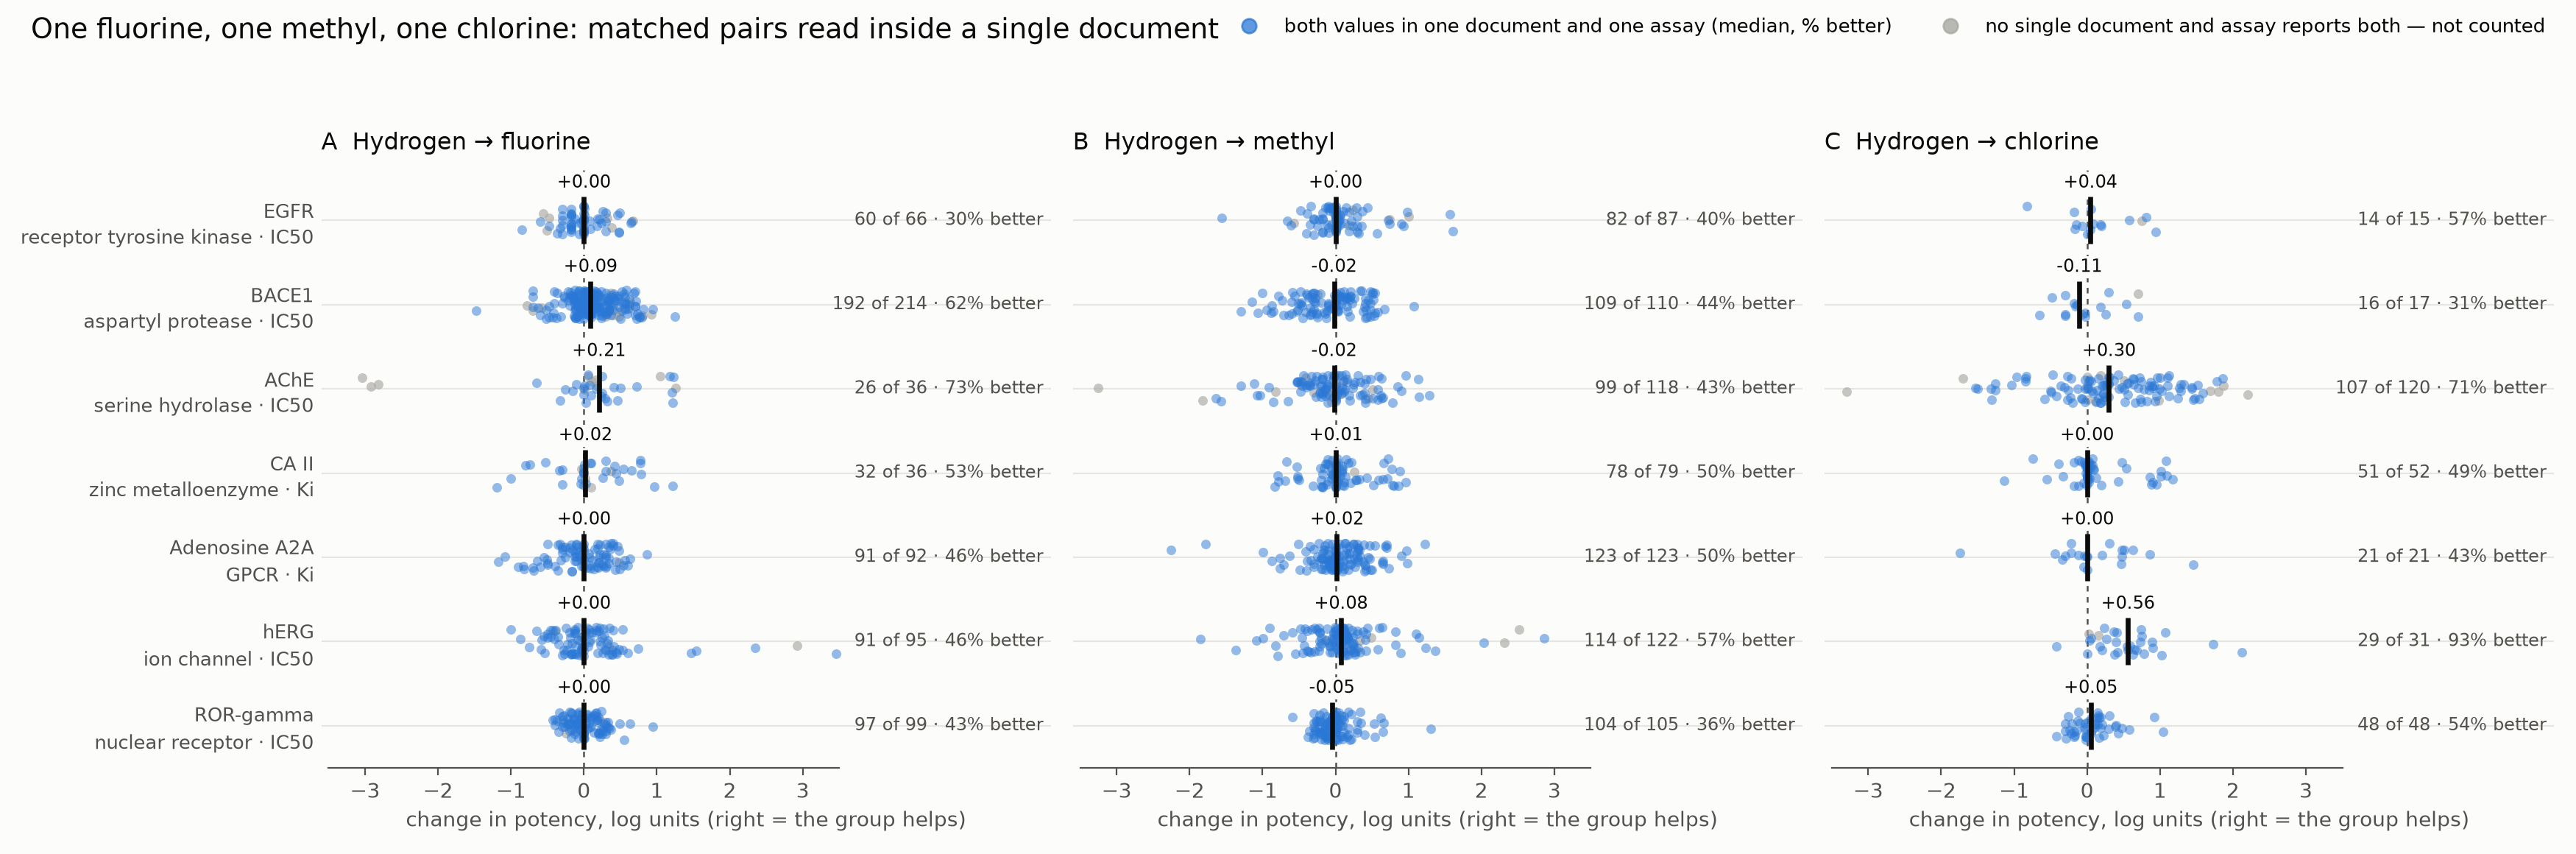

In [ ]:
# Code 1: Pair table with the document check, and the figure
# The code is in plot_transformation_effects.py, next to this notebook (163 lines).
from plot_transformation_effects import *

rows = build_rows([replay.result(i) for i in range(10, 31)], [replay.result(i) for i in range(31, 38)])
write_csv(rows)
plot(rows)
summary(rows)

In [ ]:
# Code 2: The medians and tenfold counts quoted
# The code is in transformation_tables.py, next to this notebook (46 lines).
from transformation_tables import *

from plot_transformation_effects import build_rows
rows = build_rows([replay.result(i) for i in range(10, 31)], [replay.result(i) for i in range(31, 38)])
median_table(rows)
tenfold_table(rows)

**🧠 Assistant**

No, and the rule does not change that answer, which is itself worth knowing. Across a kinase, a protease, a hydrolase, a metalloenzyme, a GPCR, an ion channel and a nuclear receptor, these three changes make **1,686 matched pairs**, and **1,584 of them (94%) have a patent or paper that reports both compounds under one assay name**. Read inside those documents, a fluorine and a methyl still do essentially nothing at the median, everywhere; a chlorine does one specific thing on one target (and a second, softer one on another).

| Target (class · type) | Fluorine | Methyl | Chlorine |
|---|---|---|---|
| EGFR (kinase · IC50) | 0.00 (60) | 0.00 (82) | +0.04 (14) |
| BACE1 (aspartyl protease · IC50) | +0.09 (192) | −0.02 (109) | −0.11 (16) |
| AChE (serine hydrolase · IC50) | +0.21 (26) | −0.02 (99) | +0.30 (107) |
| CA II (zinc metalloenzyme · Ki) | +0.02 (32) | +0.01 (78) | 0.00 (51) |
| Adenosine A2A (GPCR · Ki) | 0.00 (91) | +0.02 (123) | 0.00 (21) |
| hERG (ion channel · IC50) | 0.00 (91) | +0.08 (114) | +0.56 (29) |
| ROR-γ (nuclear receptor · IC50) | 0.00 (97) | −0.05 (104) | +0.05 (48) |

Median change in potency in log units, over the pairs that survive the check; the count is in brackets. The figure below shows every pair behind these numbers, with the unverifiable ones in grey.

**The flat result is robust.** Across all seven targets the fluorine median over all pairs is 0.00 as the database reports it and +0.01 when the rule is applied, and the methyl median stays at 0.00. Whatever a fluorine is worth in your series, the protein class does not predict it, and this is not an artefact of mixing laboratories: it survives when every pair is read from one table.

**What the rule changes is the tails, not the middle.** Counting pairs that move potency by more than tenfold in either direction:

| Pairs | As the database reports them | Read inside one document |
|---|---|---|
| Fluorine (638 → 589 checked) | 31 | 16 |
| Methyl (744 → 709) | 39 | 30 |
| Chlorine (304 → 286) | 43 | 40 |

About half the dramatic fluorine results disappear, and the worst of them go first: the most negative fluorine pair in the whole set, −3.05, a fluorine apparently costing a thousandfold, was one compound's best value in one paper set against another compound's best value in another. Read inside documents, nothing below −1.48 survives. The discarded pairs are not a random sample either: they lean positive (median +0.11, 63% improved, against 0.00 and 48% for the checked ones, on the database-wide numbers) and 6 of the 31 tenfold-plus fluorine moves sit in the 8% of fluorine pairs the rule throws away.

**AChE is where this bites.** It is the only target where the check fails often: 10 of its 36 fluorine pairs have no shared document, and those 10 carry 5 of the 11 tenfold-plus moves. Its ligands come almost entirely from small academic papers (only one of its 125 checked fluorine and methyl pairs sits in a patent), and the same compound measured in two of those papers is the classic source of a spurious effect. After the check its fluorine median rises from +0.08 to +0.21 on 26 pairs, a cleaner number, but one you should not lean on.

**The chlorine column is the finding that survives everything.** On hERG, 29 of 31 chlorine pairs are single-document, and 93% of them show stronger block, median +0.56 (3.6-fold), maximum +2.12. For hERG "stronger" is worse: this is the antitarget, and a chlorine reliably makes it worse while a fluorine on the same channel does nothing (median 0.00 over 91 pairs). That is the lipophilicity story in one row (a chlorine adds roughly 0.7 to logP, a fluorine about 0.14), and it is now measured inside single documents rather than across them. AChE's chlorine behaves the same way (+0.30 over 107 pairs, 71% improved), which I would read as a series effect rather than a class rule; the other five targets sit between −0.11 and +0.05.

**Two honest notes on the method.** Reading inside one document does not always shrink a difference. For hERG's fluorines the largest within-document move (+3.46) is bigger than anything the database-wide comparison showed (+2.92), and CA II's chlorine goes from 4 tenfold-plus moves to 6. The rule changes which two numbers you compare; it is not a smoothing filter. And where several documents report both compounds, this takes the middle document's answer, not the most dramatic one. For an effect size that is the right choice; for hunting cliffs it would not be.

**How this was answered**
- search_targets resolved each of the seven targets (ROR-γ needed a second search, "Nuclear receptor ROR-gamma", after "RAR-related orphan receptor gamma" found nothing), and the tool picked each one's most measured exact type.
- matched_molecular_pairs was called for each of the seven targets with transformation set to [H][*:1] >> F[*:1], [H][*:1] >> C[*:1] and [H][*:1] >> Cl[*:1], max_compounds: 1500: 21 calls, each returning the individual pairs with both compounds' ids and best values.
- For each target, one run_sql call listed, for every pair behind those calls, each document and assay name that reports both compounds, with the change recomputed from that document's own two values. A pair counts only when one document reports both compounds under one assay name.
- The 1,686 pairs, with the document and assay behind each and both versions of its delta, are in transformation_deltas.csv; plot_transformation_effects.py builds that file from the tool results and draws the figure.

**Try next**
- "What did the rule cost on each target?" (the follow-up below)
- "Do the same for a trifluoromethyl" (one more transformation through the same 21-call pattern)

Example 4.3 applies the same rule to activity cliffs, where it removes a third of the list rather than 6%.

## Exchange 2

**👤 User**

What did the rule cost me on each target, and which of these targets can I trust it on at all?

In [ ]:
# Call 38 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (3532,4626),(3570,3571),(3772,3773),(4567,4595),(4567,50077238),(4777,4781),(4777,50077231),(31826,50656500),(112499,50033375),(170461,170475),(170461,170482),(170461,170503),(170461,170542),(170529,170484),(170539,170540),(173427,173430),(199995,199967),(200335,200489),(200335,200490),(200335,200630),(200489,199996),(200490,200478),(200491,200487),(200630,200627),(200791,200792),(200801,200800),(200810,200809),(228124,228125),(249900,250051),(264129,264160),(332539,332540),(332539,332541),(414541,414577),(504411,504414),(504414,504415),(504535,505778),(504535,505786),(505411,505782),(505412,505411),(505500,505445),(505500,505446),(505542,504514),(505542,505541),(505610,505572),(505684,505683),(505706,505635),(505715,505710),(505735,505676),(505748,505708),(505769,505785),(505775,505403),(505786,505792),(505792,505775),(505794,505915),(505805,505843),(505805,506032),(505818,505929),(505819,505932),(505822,505988),(505824,505822),(505824,505948),(505831,505846),(505843,505854),(505846,505798),(505854,505824),(505874,505835),(505881,505882),(505888,505884),(505901,506022),(505902,505821),(505902,506023),(505903,505886),(505910,505878),(505922,505879),(505940,505976),(505945,505888),(505957,505948),(505957,505953),(505960,505880),(505976,505941),(506048,506164),(506062,506119),(506066,505831),(506066,505998),(506095,506126),(506119,506122),(506123,506124),(506126,506123),(506146,506150),(506196,506213),(506214,506213),(506221,505982),(506226,506051),(506228,506221),(506229,506228),(506247,506166),(561454,561455),(717483,717518),(717491,717526),(717495,717497),(717499,717500),(717499,717503),(717505,717525),(717518,717517),(790061,790039),(790085,790086),(50029668,50260360),(50077230,50077234),(50077243,50077242),(50077244,50237049),(50123170,50123171),(50123196,332539),(50123203,332542),(50159347,294480),(50179509,31826),(50182695,4566),(50210162,50383051),(50276123,50276101),(50276123,50276104),(50322823,50033373),(50326514,50326513),(50383283,50383287),(50391086,50391088),(50405281,50405287),(50405282,50405288),(50458058,50458062),(50458060,50458067),(50532912,50532911),(50532912,50532914),(50557554,50645677),(50558376,50558393),(50558385,50558386),(50558403,50558411),(50558419,50558412),(50579857,50579860),(50579857,50579861),(50582238,50582243),(50592743,50592741),(50592745,50592754),(50592746,50592752),(50592746,50592755),(50598683,50598684),(50600260,50600262),(50600261,50600259),(50600274,50600281),(50600274,50600282),(50600274,50600283),(50602101,50602103),(50605425,50605422),(50613861,50613848),(50613862,50613848),(50615093,50615094),(50615098,50615097),(50618649,50618653),(50618651,50618654),(50618651,50618655),(50618660,50618662),(50621967,50621968),(50630522,50630523),(50630530,50630531),(50643838,50643841),(50646573,50646575),(50654304,50654307),(50657777,50657778),(50667495,50667496),(50667501,50667502),(50667504,50667505),(50667512,50667513)), v AS (SELECT monomerid, source_id, min(value) AS nm FROM activity WHERE polymerid = 520 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id) SELECT p.a AS monomerid_from, p.b AS monomerid_to, count(*) AS n_documents FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id GROUP BY p.a, p.b ORDER BY p.a, p.b
    
"""
await replay.call(38, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='f1776e58f12a44eb9f38ddd2c4aba6e0f26183370549e75cf58ccc59fe31808a')

**Call 38** · `run_sql` · recorded result · sha256 `f1776e58f12a…`

_158 rows_

| monomerid_from | monomerid_to | n_documents |
| --- | --- | --- |
| 3570 | 3571 | 1 |
| 3772 | 3773 | 1 |
| 4567 | 4595 | 2 |
| 4567 | 50077238 | 2 |
| 4777 | 4781 | 1 |
| 4777 | 50077231 | 1 |
| 170461 | 170475 | 1 |
| 170461 | 170482 | 1 |
| 170461 | 170503 | 1 |
| 170461 | 170542 | 1 |
| 170529 | 170484 | 1 |
| 170539 | 170540 | 1 |
| 173427 | 173430 | 1 |
| 199995 | 199967 | 1 |
| 200335 | 200489 | 1 |
| 200335 | 200490 | 1 |
| 200335 | 200630 | 1 |
| 200489 | 199996 | 1 |
| 200490 | 200478 | 1 |
| 200491 | 200487 | 1 |
| 200630 | 200627 | 1 |
| 200791 | 200792 | 1 |
| 200801 | 200800 | 1 |
| 200810 | 200809 | 1 |
| 228124 | 228125 | 1 |
| 249900 | 250051 | 1 |
| 264129 | 264160 | 1 |
| 332539 | 332540 | 2 |
| 332539 | 332541 | 2 |
| 414541 | 414577 | 1 |
| 504411 | 504414 | 1 |
| 504414 | 504415 | 1 |
| 504535 | 505778 | 1 |
| 504535 | 505786 | 1 |
| 505411 | 505782 | 1 |
| 505412 | 505411 | 1 |
| 505500 | 505445 | 1 |
| 505500 | 505446 | 1 |
| 505542 | 504514 | 1 |
| 505542 | 505541 | 1 |
| 505610 | 505572 | 1 |
| 505684 | 505683 | 1 |
| 505706 | 505635 | 1 |
| 505715 | 505710 | 1 |
| 505735 | 505676 | 1 |
| 505748 | 505708 | 1 |
| 505769 | 505785 | 1 |
| 505775 | 505403 | 1 |
| 505786 | 505792 | 1 |
| 505792 | 505775 | 1 |
| 505794 | 505915 | 1 |
| 505805 | 505843 | 1 |
| 505805 | 506032 | 1 |
| 505818 | 505929 | 1 |
| 505819 | 505932 | 1 |
| 505822 | 505988 | 1 |
| 505824 | 505822 | 1 |
| 505824 | 505948 | 1 |
| 505831 | 505846 | 1 |
| 505843 | 505854 | 1 |
| 505846 | 505798 | 1 |
| 505854 | 505824 | 1 |
| 505874 | 505835 | 1 |
| 505881 | 505882 | 1 |
| 505888 | 505884 | 1 |
| 505901 | 506022 | 1 |
| 505902 | 505821 | 1 |
| 505902 | 506023 | 1 |
| 505903 | 505886 | 1 |
| 505910 | 505878 | 1 |
| 505922 | 505879 | 1 |
| 505940 | 505976 | 1 |
| 505945 | 505888 | 1 |
| 505957 | 505948 | 1 |
| 505957 | 505953 | 1 |
| 505960 | 505880 | 1 |
| 505976 | 505941 | 1 |
| 506048 | 506164 | 1 |
| 506062 | 506119 | 1 |
| 506066 | 505831 | 1 |
| 506066 | 505998 | 1 |
| 506095 | 506126 | 1 |
| 506119 | 506122 | 1 |
| 506123 | 506124 | 1 |
| 506126 | 506123 | 1 |
| 506146 | 506150 | 1 |
| 506196 | 506213 | 1 |
| 506214 | 506213 | 1 |
| 506221 | 505982 | 1 |
| 506226 | 506051 | 1 |
| 506228 | 506221 | 1 |
| 506229 | 506228 | 1 |
| 506247 | 506166 | 1 |
| 561454 | 561455 | 2 |
| 717483 | 717518 | 1 |
| 717491 | 717526 | 1 |
| 717495 | 717497 | 1 |
| 717499 | 717500 | 1 |
| 717499 | 717503 | 1 |
| 717505 | 717525 | 1 |
| 717518 | 717517 | 1 |
| 790061 | 790039 | 1 |
| 790085 | 790086 | 1 |
| 50029668 | 50260360 | 2 |
| 50077230 | 50077234 | 1 |
| 50077243 | 50077242 | 1 |
| 50123170 | 50123171 | 1 |
| 50182695 | 4566 | 1 |
| 50276123 | 50276101 | 1 |
| 50276123 | 50276104 | 1 |
| 50322823 | 50033373 | 1 |
| 50326514 | 50326513 | 1 |
| 50383283 | 50383287 | 1 |
| 50391086 | 50391088 | 1 |
| 50405281 | 50405287 | 1 |
| 50405282 | 50405288 | 1 |
| 50458058 | 50458062 | 1 |
| 50458060 | 50458067 | 1 |
| 50532912 | 50532911 | 1 |
| 50532912 | 50532914 | 1 |
| 50558376 | 50558393 | 1 |
| 50558385 | 50558386 | 1 |
| 50558403 | 50558411 | 1 |
| 50558419 | 50558412 | 1 |
| 50579857 | 50579860 | 1 |
| 50579857 | 50579861 | 1 |
| 50582238 | 50582243 | 2 |
| 50592743 | 50592741 | 3 |
| 50592745 | 50592754 | 1 |
| 50592746 | 50592752 | 1 |
| 50592746 | 50592755 | 1 |
| 50598683 | 50598684 | 1 |
| 50600260 | 50600262 | 1 |
| 50600261 | 50600259 | 1 |
| 50600274 | 50600281 | 1 |
| 50600274 | 50600282 | 1 |
| 50600274 | 50600283 | 1 |
| 50602101 | 50602103 | 1 |
| 50605425 | 50605422 | 2 |
| 50613861 | 50613848 | 1 |
| 50613862 | 50613848 | 1 |
| 50615093 | 50615094 | 1 |
| 50615098 | 50615097 | 1 |
| 50618649 | 50618653 | 2 |
| 50618651 | 50618654 | 2 |
| 50618651 | 50618655 | 1 |
| 50618660 | 50618662 | 1 |
| 50621967 | 50621968 | 2 |
| 50630522 | 50630523 | 1 |
| 50630530 | 50630531 | 1 |
| 50643838 | 50643841 | 1 |
| 50646573 | 50646575 | 2 |
| 50654304 | 50654307 | 1 |
| 50657777 | 50657778 | 1 |
| 50667495 | 50667496 | 1 |
| 50667501 | 50667502 | 1 |
| 50667504 | 50667505 | 1 |
| 50667512 | 50667513 | 1 |


In [ ]:
# Call 39 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (18751,19476),(26502,26788),(116233,116236),(124132,124133),(124132,124138),(124132,124170),(124133,124168),(124135,124136),(124143,124135),(124170,124168),(124174,124177),(134360,50012653),(134445,134463),(134448,134445),(136738,136863),(136738,155120),(136739,136829),(136740,136824),(136744,136863),(136834,136859),(136849,136848),(136855,136850),(150686,150688),(150686,150691),(150687,150689),(150688,150693),(150690,150692),(150690,400643),(150691,150693),(153632,50457586),(171399,171401),(171399,171477),(171461,171462),(171461,171477),(171565,171401),(171565,171462),(171587,171581),(171645,171587),(171645,171651),(171645,171683),(171651,171581),(195117,195118),(195422,195418),(195422,195423),(204940,50462001),(210070,116292),(214835,214839),(214835,214960),(214835,215026),(214839,214961),(214844,214835),(214844,214997),(214960,214961),(214996,214966),(214996,214995),(214997,214960),(220806,220783),(220827,220826),(220828,220825),(220836,220858),(220839,220799),(220840,220798),(220854,220856),(220854,220859),(223395,223400),(228399,228414),(228399,228415),(228399,230001),(228400,228425),(228419,229990),(228425,229992),(228440,228474),(228473,228472),(228474,228476),(228868,229050),(229582,230011),(230017,228478),(230018,228479),(312913,312921),(312938,223381),(312938,312941),(338836,338843),(338836,338844),(372703,372734),(372742,372741),(372742,372743),(372742,372921),(372811,372815),(372818,372819),(372823,372830),(372829,372833),(372881,372883),(372921,372920),(400331,400979),(400607,150692),(400607,400643),(403754,195119),(403754,195132),(403754,195133),(404165,195379),(477920,477924),(501187,501188),(501187,501350),(501188,501357),(501192,501239),(501197,501247),(501241,501259),(501289,501280),(501323,501353),(501350,501357),(589192,589194),(589194,589195),(589195,589184),(589206,589202),(589207,589169),(705373,705445),(705384,705378),(705388,705444),(705388,50510782),(705398,705413),(705403,705396),(705407,705425),(705410,705437),(705416,705414),(705419,705443),(705419,705450),(705420,705414),(705427,705450),(705444,705451),(705473,705527),(705474,705528),(705478,705529),(705486,705863),(705488,705489),(705490,705491),(705493,705491),(705497,705489),(705501,705743),(705507,705808),(705519,705517),(705557,50510972),(705558,705559),(705560,705559),(705564,705558),(705564,705560),(705564,705565),(705565,705559),(705566,705567),(705566,705569),(705569,705553),(705574,705576),(705590,705589),(705636,705715),(705654,705658),(705656,705662),(705659,705661),(705672,705880),(705674,705915),(705676,705740),(705677,705734),(705679,705742),(705680,705679),(705682,705686),(705685,705677),(705687,705819),(705688,705488),(705690,705679),(705691,705740),(705692,50510980),(705693,705819),(705694,705704),(705694,705945),(705694,50510977),(705695,705407),(705695,705692),(705695,50510978),(705696,705694),(705696,705703),(705696,50510993),(705697,705680),(705697,705690),(705698,705687),(705698,705693),(705699,705676),(705699,705691),(705700,705688),(705701,705753),(705703,705704),(705704,705735),(705705,705939),(705705,50510985),(705706,705736),(705707,705940),(705707,50510974),(705707,50559903),(705708,705706),(705708,705917),(705708,50510976),(705709,705737),(705710,705734),(705711,705677),(705711,705710),(705725,705724),(705733,705719),(705740,705762),(705741,705744),(705744,705760),(705758,705748),(705785,705794),(705801,705798),(705802,705795),(705803,50510992),(705839,705883),(705840,705493),(705847,705575),(705847,705851),(705850,705876),(705851,705850),(705851,705914),(705852,705841),(705853,705789),(705859,50510983),(705861,705788),(705861,705891),(705868,705893),(705873,705846),(705873,705919),(705874,705800),(705879,705878),(705882,705888),(705882,705918),(705883,705496),(705886,705889),(705895,705935),(705899,705613),(705899,50510985),(705910,705904),(705913,705948),(705914,705873),(705923,705935),(705927,705895),(705927,705923),(705928,705894),(705930,705902),(705931,705705),(705931,705899),(705938,705899),(50012617,195119),(50012617,195132),(50012617,195133),(50012660,228439),(50012660,228440),(50012660,228443),(50012660,230025),(50031628,50031627),(50032728,50032731),(50032728,50032733),(50032733,50032734),(50032742,50032744),(50061580,50061731),(50061581,50032737),(50061582,50061735),(50061584,50061775),(50061585,50061780),(50061587,50061831),(50061588,50061874),(50061590,50061890),(50061591,50061580),(50061591,50061592),(50061591,50061893),(50061592,50061728),(50061594,50510991),(50061599,50061738),(50061890,50061729),(50061890,50061730),(50061890,50061965),(50061893,50061728),(50061893,50061731),(50131807,50131808),(50169365,50169366),(50264185,50264186),(50264195,50264184),(50383838,50392770),(50383838,50392782),(50383839,50392782),(50383839,50392783),(50383845,50383847),(50383854,50383856),(50386515,50386513),(50387054,50387056),(50392776,50383838),(50392776,50383839),(50392776,50392777),(50393088,50398268),(50393099,136830),(50393099,50393106),(50393100,50393107),(50397688,50397707),(50397688,50397708),(50397688,50397709),(50397692,50397689),(50397692,50397704),(50397692,50397712),(50398312,50392776),(50432608,124137),(50432608,124167),(50432615,50432614),(50462005,204994),(50501811,50567456),(50501819,50501816),(50510782,705451),(50510783,501235),(50510783,501285),(50510974,705409),(50510975,705614),(50510975,705902),(50510976,705736),(50510976,705920),(50510977,705735),(50510978,705425),(50510978,50510980),(50510979,705396),(50510984,50510972),(50510986,705737),(50510989,705938),(50510989,50510975),(50510993,705684),(50510993,50510977),(50545178,50545179),(50559903,705409),(50569345,50569350),(50569346,50510820),(50569348,50569349),(50579814,50579806),(50580213,50510779),(50583315,50583324),(50596248,50596252),(50596252,50596254),(50610551,50610552),(50610556,50610557),(50610558,50610559)), v AS (SELECT monomerid, source_id, min(value) AS nm FROM activity WHERE polymerid = 5093 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id) SELECT p.a AS monomerid_from, p.b AS monomerid_to, count(*) AS n_documents FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id GROUP BY p.a, p.b ORDER BY p.a, p.b
    
"""
await replay.call(39, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='f0e75e23b3f43a8aa1eb793ff3209faa96548e31f478e4b34cd78bf1c311b333')

**Call 39** · `run_sql` · recorded result · sha256 `f0e75e23b3f4…`

_317 rows_

| monomerid_from | monomerid_to | n_documents |
| --- | --- | --- |
| 18751 | 19476 | 1 |
| 26502 | 26788 | 2 |
| 116233 | 116236 | 3 |
| 124132 | 124133 | 1 |
| 124132 | 124138 | 1 |
| 124132 | 124170 | 1 |
| 124133 | 124168 | 1 |
| 124135 | 124136 | 1 |
| 124143 | 124135 | 1 |
| 124170 | 124168 | 1 |
| 124174 | 124177 | 1 |
| 134360 | 50012653 | 2 |
| 134445 | 134463 | 1 |
| 134448 | 134445 | 1 |
| 136738 | 136863 | 1 |
| 136739 | 136829 | 1 |
| 136740 | 136824 | 1 |
| 136744 | 136863 | 1 |
| 136834 | 136859 | 1 |
| 136849 | 136848 | 1 |
| 136855 | 136850 | 1 |
| 150686 | 150688 | 2 |
| 150686 | 150691 | 2 |
| 150687 | 150689 | 1 |
| 150688 | 150693 | 3 |
| 150690 | 150692 | 1 |
| 150691 | 150693 | 2 |
| 153632 | 50457586 | 1 |
| 171399 | 171401 | 1 |
| 171399 | 171477 | 1 |
| 171461 | 171462 | 1 |
| 171461 | 171477 | 1 |
| 171565 | 171401 | 1 |
| 171565 | 171462 | 1 |
| 171587 | 171581 | 1 |
| 171645 | 171587 | 1 |
| 171645 | 171651 | 1 |
| 171645 | 171683 | 1 |
| 171651 | 171581 | 1 |
| 195117 | 195118 | 1 |
| 195422 | 195418 | 1 |
| 195422 | 195423 | 1 |
| 204940 | 50462001 | 1 |
| 210070 | 116292 | 1 |
| 214835 | 214839 | 1 |
| 214835 | 214960 | 1 |
| 214835 | 215026 | 1 |
| 214839 | 214961 | 1 |
| 214844 | 214835 | 1 |
| 214844 | 214997 | 1 |
| 214960 | 214961 | 1 |
| 214996 | 214966 | 1 |
| 214996 | 214995 | 1 |
| 214997 | 214960 | 1 |
| 220806 | 220783 | 1 |
| 220827 | 220826 | 1 |
| 220828 | 220825 | 1 |
| 220836 | 220858 | 1 |
| 220839 | 220799 | 1 |
| 220840 | 220798 | 1 |
| 220854 | 220856 | 1 |
| 220854 | 220859 | 1 |
| 223395 | 223400 | 2 |
| 228399 | 228414 | 1 |
| 228399 | 228415 | 1 |
| 228399 | 230001 | 1 |
| 228400 | 228425 | 1 |
| 228419 | 229990 | 1 |
| 228425 | 229992 | 1 |
| 228440 | 228474 | 1 |
| 228473 | 228472 | 1 |
| 228474 | 228476 | 1 |
| 228868 | 229050 | 1 |
| 229582 | 230011 | 1 |
| 230017 | 228478 | 1 |
| 230018 | 228479 | 1 |
| 312913 | 312921 | 1 |
| 312938 | 223381 | 1 |
| 312938 | 312941 | 1 |
| 338836 | 338843 | 1 |
| 338836 | 338844 | 1 |
| 372703 | 372734 | 1 |
| 372742 | 372741 | 1 |
| 372742 | 372743 | 1 |
| 372742 | 372921 | 1 |
| 372811 | 372815 | 1 |
| 372818 | 372819 | 1 |
| 372823 | 372830 | 1 |
| 372829 | 372833 | 1 |
| 372881 | 372883 | 1 |
| 372921 | 372920 | 1 |
| 400331 | 400979 | 2 |
| 400607 | 400643 | 1 |
| 403754 | 195119 | 1 |
| 403754 | 195132 | 1 |
| 403754 | 195133 | 1 |
| 404165 | 195379 | 1 |
| 477920 | 477924 | 1 |
| 501187 | 501188 | 1 |
| 501187 | 501350 | 1 |
| 501188 | 501357 | 1 |
| 501192 | 501239 | 1 |
| 501197 | 501247 | 1 |
| 501241 | 501259 | 1 |
| 501289 | 501280 | 1 |
| 501323 | 501353 | 1 |
| 501350 | 501357 | 1 |
| 589192 | 589194 | 1 |
| 589194 | 589195 | 1 |
| 589195 | 589184 | 1 |
| 589206 | 589202 | 1 |
| 589207 | 589169 | 1 |
| 705373 | 705445 | 1 |
| 705384 | 705378 | 1 |
| 705388 | 705444 | 1 |
| 705388 | 50510782 | 1 |
| 705398 | 705413 | 1 |
| 705403 | 705396 | 1 |
| 705407 | 705425 | 1 |
| 705410 | 705437 | 1 |
| 705416 | 705414 | 1 |
| 705419 | 705443 | 1 |
| 705419 | 705450 | 1 |
| 705420 | 705414 | 1 |
| 705427 | 705450 | 1 |
| 705444 | 705451 | 1 |
| 705473 | 705527 | 1 |
| 705474 | 705528 | 1 |
| 705478 | 705529 | 1 |
| 705486 | 705863 | 1 |
| 705488 | 705489 | 1 |
| 705490 | 705491 | 1 |
| 705493 | 705491 | 1 |
| 705497 | 705489 | 1 |
| 705501 | 705743 | 1 |
| 705507 | 705808 | 1 |
| 705519 | 705517 | 1 |
| 705557 | 50510972 | 1 |
| 705558 | 705559 | 1 |
| 705560 | 705559 | 1 |
| 705564 | 705558 | 1 |
| 705564 | 705560 | 1 |
| 705564 | 705565 | 1 |
| 705565 | 705559 | 1 |
| 705566 | 705567 | 1 |
| 705566 | 705569 | 1 |
| 705569 | 705553 | 1 |
| 705574 | 705576 | 1 |
| 705590 | 705589 | 1 |
| 705636 | 705715 | 1 |
| 705654 | 705658 | 1 |
| 705656 | 705662 | 1 |
| 705659 | 705661 | 1 |
| 705672 | 705880 | 1 |
| 705674 | 705915 | 1 |
| 705676 | 705740 | 1 |
| 705677 | 705734 | 1 |
| 705679 | 705742 | 1 |
| 705680 | 705679 | 1 |
| 705682 | 705686 | 1 |
| 705685 | 705677 | 1 |
| 705687 | 705819 | 1 |
| 705688 | 705488 | 1 |
| 705690 | 705679 | 1 |
| 705691 | 705740 | 1 |
| 705692 | 50510980 | 1 |
| 705693 | 705819 | 1 |
| 705694 | 705704 | 1 |
| 705694 | 705945 | 1 |
| 705694 | 50510977 | 1 |
| 705695 | 705407 | 1 |
| 705695 | 705692 | 1 |
| 705695 | 50510978 | 1 |
| 705696 | 705694 | 1 |
| 705696 | 705703 | 1 |
| 705697 | 705680 | 1 |
| 705697 | 705690 | 1 |
| 705698 | 705687 | 1 |
| 705698 | 705693 | 1 |
| 705699 | 705676 | 1 |
| 705699 | 705691 | 1 |
| 705700 | 705688 | 1 |
| 705701 | 705753 | 1 |
| 705703 | 705704 | 1 |
| 705704 | 705735 | 1 |
| 705705 | 705939 | 1 |
| 705705 | 50510985 | 1 |
| 705706 | 705736 | 1 |
| 705707 | 705940 | 1 |
| 705707 | 50510974 | 1 |
| 705707 | 50559903 | 1 |
| 705708 | 705706 | 1 |
| 705708 | 705917 | 1 |
| 705708 | 50510976 | 1 |
| 705709 | 705737 | 1 |
| 705710 | 705734 | 1 |
| 705711 | 705677 | 1 |
| 705711 | 705710 | 1 |
| 705725 | 705724 | 1 |
| 705733 | 705719 | 1 |
| 705740 | 705762 | 1 |
| 705741 | 705744 | 1 |
| 705744 | 705760 | 1 |
| 705758 | 705748 | 1 |
| 705785 | 705794 | 1 |
| 705801 | 705798 | 1 |
| 705802 | 705795 | 1 |
| 705803 | 50510992 | 1 |
| 705839 | 705883 | 1 |
| 705840 | 705493 | 1 |
| 705847 | 705575 | 1 |
| 705847 | 705851 | 1 |
| 705850 | 705876 | 1 |
| 705851 | 705850 | 1 |
| 705851 | 705914 | 1 |
| 705852 | 705841 | 1 |
| 705853 | 705789 | 1 |
| 705861 | 705788 | 1 |
| 705861 | 705891 | 1 |
| 705868 | 705893 | 1 |
| 705873 | 705846 | 1 |
| 705873 | 705919 | 1 |
| 705874 | 705800 | 1 |
| 705879 | 705878 | 1 |
| 705882 | 705888 | 1 |
| 705882 | 705918 | 1 |
| 705883 | 705496 | 1 |
| 705886 | 705889 | 1 |
| 705895 | 705935 | 1 |
| 705899 | 705613 | 1 |
| 705899 | 50510985 | 1 |
| 705910 | 705904 | 1 |
| 705913 | 705948 | 1 |
| 705914 | 705873 | 1 |
| 705923 | 705935 | 1 |
| 705927 | 705895 | 1 |
| 705927 | 705923 | 1 |
| 705928 | 705894 | 1 |
| 705930 | 705902 | 1 |
| 705931 | 705705 | 1 |
| 705931 | 705899 | 1 |
| 705938 | 705899 | 1 |
| 50012660 | 228439 | 1 |
| 50012660 | 228440 | 1 |
| 50012660 | 228443 | 1 |
| 50012660 | 230025 | 1 |
| 50031628 | 50031627 | 1 |
| 50032728 | 50032731 | 1 |
| 50032728 | 50032733 | 1 |
| 50032733 | 50032734 | 1 |
| 50032742 | 50032744 | 1 |
| 50061581 | 50032737 | 1 |
| 50061591 | 50061580 | 1 |
| 50061591 | 50061592 | 1 |
| 50061890 | 50061729 | 1 |
| 50061890 | 50061730 | 1 |
| 50061890 | 50061965 | 1 |
| 50061893 | 50061728 | 1 |
| 50061893 | 50061731 | 1 |
| 50131807 | 50131808 | 1 |
| 50169365 | 50169366 | 1 |
| 50264185 | 50264186 | 1 |
| 50264195 | 50264184 | 1 |
| 50383838 | 50392770 | 1 |
| 50383838 | 50392782 | 1 |
| 50383839 | 50392782 | 1 |
| 50383839 | 50392783 | 1 |
| 50383845 | 50383847 | 1 |
| 50383854 | 50383856 | 1 |
| 50386515 | 50386513 | 1 |
| 50387054 | 50387056 | 1 |
| 50392776 | 50383838 | 1 |
| 50392776 | 50383839 | 2 |
| 50392776 | 50392777 | 1 |
| 50393088 | 50398268 | 1 |
| 50393099 | 136830 | 1 |
| 50393099 | 50393106 | 2 |
| 50393100 | 50393107 | 1 |
| 50397688 | 50397707 | 1 |
| 50397688 | 50397708 | 1 |
| 50397688 | 50397709 | 1 |
| 50397692 | 50397689 | 1 |
| 50397692 | 50397704 | 1 |
| 50397692 | 50397712 | 1 |
| 50398312 | 50392776 | 1 |
| 50432608 | 124137 | 1 |
| 50432608 | 124167 | 1 |
| 50432615 | 50432614 | 1 |
| 50462005 | 204994 | 1 |
| 50501811 | 50567456 | 1 |
| 50501819 | 50501816 | 1 |
| 50510782 | 705451 | 1 |
| 50510783 | 501235 | 1 |
| 50510783 | 501285 | 1 |
| 50510974 | 705409 | 1 |
| 50510976 | 705736 | 1 |
| 50510976 | 705920 | 1 |
| 50510977 | 705735 | 1 |
| 50510978 | 705425 | 1 |
| 50510978 | 50510980 | 2 |
| 50510979 | 705396 | 1 |
| 50510984 | 50510972 | 2 |
| 50510986 | 705737 | 1 |
| 50510989 | 705938 | 1 |
| 50510989 | 50510975 | 1 |
| 50510993 | 50510977 | 1 |
| 50545178 | 50545179 | 1 |
| 50559903 | 705409 | 1 |
| 50569345 | 50569350 | 1 |
| 50569348 | 50569349 | 1 |
| 50579814 | 50579806 | 1 |
| 50583315 | 50583324 | 1 |
| 50596248 | 50596252 | 1 |
| 50596252 | 50596254 | 1 |
| 50610551 | 50610552 | 1 |
| 50610556 | 50610557 | 1 |
| 50610558 | 50610559 | 1 |


In [ ]:
# Call 40 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (8961,8985),(8961,8987),(8961,8992),(8961,50279983),(8961,50279984),(8961,50279995),(8961,50280623),(9007,9009),(9007,50523376),(9009,9012),(9020,9021),(9408,50004037),(10507,10512),(10583,10587),(10584,10588),(10585,10589),(10586,10590),(10608,10610),(10614,10616),(10622,10611),(10686,50077259),(10688,50077262),(10692,10916),(10692,10932),(10742,10743),(10913,50486319),(10916,10917),(10917,10918),(10918,10933),(10932,10935),(10932,10938),(10933,10936),(10933,10939),(10949,50218528),(10958,10959),(10958,10974),(10959,10961),(10959,10976),(10959,10977),(10959,10978),(10961,10973),(10972,50014109),(10974,10976),(10974,10978),(10974,10981),(10974,10982),(11023,50326246),(11023,50596649),(132071,132074),(132071,132081),(132083,132085),(132083,132086),(132084,132087),(132084,132088),(327447,327448),(327447,50079362),(327447,50657573),(50004000,50326246),(50004000,50596649),(50004018,50003999),(50004027,50004028),(50005758,50005761),(50005761,50005762),(50005777,50005758),(50008558,50008541),(50008558,50008544),(50008558,50008556),(50008558,50008560),(50008558,50008564),(50008558,50008567),(50008579,50008570),(50027471,50379272),(50028679,50028681),(50028679,50028693),(50028680,50028682),(50028680,50028694),(50028681,50028691),(50028682,50028692),(50028683,50028685),(50028693,50028691),(50028694,50028692),(50032393,50032382),(50037138,50039203),(50037138,50039204),(50037138,50039215),(50037138,50039223),(50037138,50039226),(50037138,50039227),(50037141,50039222),(50037171,50037173),(50037173,50037141),(50038733,50318746),(50038733,50318755),(50039222,50039231),(50039716,50039728),(50039717,50154794),(50039728,50039729),(50060470,50280625),(50060470,50280626),(50060470,50280627),(50073114,50133471),(50079861,50094626),(50079861,50094633),(50079867,50094628),(50079867,50094633),(50094626,50094631),(50094628,50094631),(50094629,50094630),(50094633,50094631),(50099570,50099596),(50099591,50099570),(50099602,50523387),(50102726,50102729),(50102729,50102743),(50107891,50094626),(50107891,50094628),(50107891,50094629),(50107892,10592),(50107892,50079861),(50107892,50079867),(50107892,50107891),(50107892,50200340),(50108990,50108991),(50108992,50027471),(50108992,50108994),(50108993,50108990),(50108993,50108995),(50108994,50379272),(50108995,50108991),(50117595,50117612),(50117620,50117618),(50124872,50124879),(50124874,50124872),(50124874,50124881),(50124876,50281126),(50124881,50124879),(50124881,50124880),(50124882,50124881),(50138750,50138731),(50154768,50154780),(50154771,50154774),(50225209,50371198),(50225210,50371197),(50225215,50371199),(50238212,50606806),(50238219,50238220),(50238225,50238213),(50238225,50238223),(50238225,50238224),(50238225,50238235),(50238236,50238216),(50271140,50271142),(50271189,50271191),(50271190,50271192),(50291635,50291636),(50298402,50298403),(50298405,50298406),(50298409,50298408),(50304320,50304323),(50304327,50304329),(50318731,9022),(50318732,9023),(50318745,50038733),(50318746,50318754),(50318755,50318754),(50318860,10922),(50318863,10925),(50318866,10928),(50318869,10931),(50321917,50321918),(50322766,50322768),(50351015,50351016),(50351020,50351015),(50379265,50027470),(50379273,10597),(50380537,50380541),(50380542,50380551),(50380543,50380550),(50380544,50380549),(50380545,50380559),(50380546,50380558),(50380553,50380552),(50380555,50380547),(50386424,50189331),(50389383,50389382),(50433314,8985),(50433314,8987),(50433314,8992),(50433314,50279983),(50433314,50279984),(50433314,50279995),(50433314,50280623),(50456687,50456690),(50456687,50456696),(50456688,50456691),(50456688,50456692),(50456689,50456690),(50456689,50456691),(50456697,50456687),(50456697,50456688),(50456697,50456689),(50456698,50456693),(50456698,50456694),(50456699,50456700),(50465093,50465100),(50465101,50465096),(50486452,50486489),(50486452,50486506),(50507210,50507209),(50507213,50507211),(50523371,50523393),(50523376,9012),(50541051,50541052),(50556390,50556405),(50556390,50556407),(50556400,50556399),(50556407,50556408),(50560210,50560218),(50560211,50560217),(50563377,50563378),(50563377,50563379),(50563381,50563382),(50563389,50563390),(50563389,50563391),(50574586,50574587),(50574586,50574588),(50574586,50574589),(50587054,50587063),(50587055,50587058),(50587056,50587057),(50587059,50587064),(50587066,50587061),(50610549,50610547),(50610550,50610548),(50610551,50610552),(50610556,50610557),(50610558,50610559),(50618903,50618906),(50634776,50029944),(50634776,50204751),(50634776,50204754),(50634776,50204831),(50634776,50204835),(50640647,50640649),(50640647,50640651),(50653583,50653584),(50653583,50653587),(50653588,50653589),(50653588,50653592),(50653612,50653613),(50653612,50653614),(50653612,50653615),(50653612,50653618),(50653613,50653616),(50653613,50653619),(50653614,50653617),(50653614,50653620),(50653615,50653616),(50653615,50653617),(50653618,50653619),(50653618,50653620),(50653621,50653622),(50653621,50653623),(50653621,50653624),(50653621,50653627),(50653622,50653625),(50653622,50653628),(50653623,50653626),(50653623,50653629),(50653624,50653625),(50653624,50653626),(50653627,50653628),(50653627,50653629),(50663938,50663936)), v AS (SELECT monomerid, source_id, min(value) AS nm FROM activity WHERE polymerid = 3619 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id) SELECT p.a AS monomerid_from, p.b AS monomerid_to, count(*) AS n_documents FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id GROUP BY p.a, p.b ORDER BY p.a, p.b
    
"""
await replay.call(40, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='e16eba98b6d67d1c9c5a966a2c760c52a499cb257a0ac674120c6f93980566c8')

**Call 40** · `run_sql` · recorded result · sha256 `e16eba98b6d6…`

_234 rows_

| monomerid_from | monomerid_to | n_documents |
| --- | --- | --- |
| 8961 | 8985 | 4 |
| 8961 | 8987 | 13 |
| 8961 | 8992 | 3 |
| 8961 | 50279983 | 1 |
| 8961 | 50279984 | 2 |
| 8961 | 50279995 | 1 |
| 8961 | 50280623 | 1 |
| 9007 | 9009 | 1 |
| 9009 | 9012 | 1 |
| 9020 | 9021 | 1 |
| 9408 | 50004037 | 1 |
| 10507 | 10512 | 1 |
| 10583 | 10587 | 2 |
| 10584 | 10588 | 2 |
| 10585 | 10589 | 2 |
| 10586 | 10590 | 2 |
| 10608 | 10610 | 1 |
| 10614 | 10616 | 2 |
| 10622 | 10611 | 3 |
| 10692 | 10916 | 2 |
| 10692 | 10932 | 2 |
| 10742 | 10743 | 1 |
| 10916 | 10917 | 2 |
| 10917 | 10918 | 2 |
| 10918 | 10933 | 2 |
| 10932 | 10935 | 2 |
| 10932 | 10938 | 2 |
| 10933 | 10936 | 2 |
| 10933 | 10939 | 2 |
| 10949 | 50218528 | 3 |
| 10958 | 10959 | 4 |
| 10958 | 10974 | 1 |
| 10959 | 10961 | 3 |
| 10959 | 10976 | 1 |
| 10959 | 10977 | 1 |
| 10959 | 10978 | 2 |
| 10961 | 10973 | 2 |
| 10974 | 10976 | 1 |
| 10974 | 10978 | 1 |
| 10974 | 10981 | 1 |
| 10974 | 10982 | 1 |
| 132071 | 132074 | 1 |
| 132071 | 132081 | 1 |
| 132083 | 132085 | 1 |
| 132083 | 132086 | 1 |
| 132084 | 132087 | 1 |
| 132084 | 132088 | 1 |
| 327447 | 327448 | 2 |
| 327447 | 50079362 | 2 |
| 327447 | 50657573 | 1 |
| 50004000 | 50326246 | 1 |
| 50004018 | 50003999 | 1 |
| 50004027 | 50004028 | 1 |
| 50005758 | 50005761 | 1 |
| 50005761 | 50005762 | 1 |
| 50005777 | 50005758 | 1 |
| 50008558 | 50008541 | 1 |
| 50008558 | 50008544 | 1 |
| 50008558 | 50008556 | 1 |
| 50008558 | 50008560 | 1 |
| 50008558 | 50008564 | 1 |
| 50008558 | 50008567 | 1 |
| 50008579 | 50008570 | 1 |
| 50027471 | 50379272 | 1 |
| 50028679 | 50028681 | 1 |
| 50028679 | 50028693 | 1 |
| 50028680 | 50028682 | 1 |
| 50028680 | 50028694 | 1 |
| 50028681 | 50028691 | 1 |
| 50028682 | 50028692 | 1 |
| 50028683 | 50028685 | 1 |
| 50028693 | 50028691 | 1 |
| 50028694 | 50028692 | 1 |
| 50032393 | 50032382 | 1 |
| 50037138 | 50039203 | 1 |
| 50037138 | 50039204 | 1 |
| 50037138 | 50039215 | 1 |
| 50037138 | 50039223 | 1 |
| 50037138 | 50039226 | 1 |
| 50037138 | 50039227 | 1 |
| 50037141 | 50039222 | 1 |
| 50037171 | 50037173 | 1 |
| 50037173 | 50037141 | 1 |
| 50038733 | 50318746 | 1 |
| 50038733 | 50318755 | 1 |
| 50039222 | 50039231 | 1 |
| 50039716 | 50039728 | 5 |
| 50039717 | 50154794 | 1 |
| 50039728 | 50039729 | 4 |
| 50060470 | 50280625 | 1 |
| 50060470 | 50280626 | 1 |
| 50060470 | 50280627 | 1 |
| 50073114 | 50133471 | 1 |
| 50079861 | 50094626 | 1 |
| 50079861 | 50094633 | 1 |
| 50079867 | 50094628 | 1 |
| 50079867 | 50094633 | 1 |
| 50094626 | 50094631 | 1 |
| 50094628 | 50094631 | 1 |
| 50094629 | 50094630 | 1 |
| 50094633 | 50094631 | 1 |
| 50099570 | 50099596 | 1 |
| 50099591 | 50099570 | 1 |
| 50099602 | 50523387 | 1 |
| 50102726 | 50102729 | 2 |
| 50102729 | 50102743 | 1 |
| 50107892 | 50107891 | 1 |
| 50108990 | 50108991 | 1 |
| 50108992 | 50108994 | 1 |
| 50108993 | 50108990 | 1 |
| 50108993 | 50108995 | 1 |
| 50108995 | 50108991 | 1 |
| 50117595 | 50117612 | 1 |
| 50117620 | 50117618 | 1 |
| 50124872 | 50124879 | 1 |
| 50124874 | 50124872 | 1 |
| 50124874 | 50124881 | 1 |
| 50124876 | 50281126 | 1 |
| 50124881 | 50124879 | 1 |
| 50124881 | 50124880 | 1 |
| 50124882 | 50124881 | 1 |
| 50138750 | 50138731 | 1 |
| 50154768 | 50154780 | 1 |
| 50154771 | 50154774 | 1 |
| 50225209 | 50371198 | 1 |
| 50225210 | 50371197 | 1 |
| 50225215 | 50371199 | 1 |
| 50238212 | 50606806 | 1 |
| 50238219 | 50238220 | 1 |
| 50238225 | 50238213 | 1 |
| 50238225 | 50238223 | 1 |
| 50238225 | 50238224 | 1 |
| 50238225 | 50238235 | 1 |
| 50238236 | 50238216 | 1 |
| 50271140 | 50271142 | 1 |
| 50271189 | 50271191 | 1 |
| 50271190 | 50271192 | 1 |
| 50291635 | 50291636 | 1 |
| 50298402 | 50298403 | 1 |
| 50298405 | 50298406 | 1 |
| 50298409 | 50298408 | 1 |
| 50304320 | 50304323 | 1 |
| 50304327 | 50304329 | 1 |
| 50318745 | 50038733 | 1 |
| 50318746 | 50318754 | 1 |
| 50318755 | 50318754 | 1 |
| 50321917 | 50321918 | 1 |
| 50322766 | 50322768 | 1 |
| 50351015 | 50351016 | 1 |
| 50351020 | 50351015 | 1 |
| 50379265 | 50027470 | 1 |
| 50380537 | 50380541 | 1 |
| 50380542 | 50380551 | 1 |
| 50380543 | 50380550 | 1 |
| 50380544 | 50380549 | 1 |
| 50380545 | 50380559 | 1 |
| 50380546 | 50380558 | 1 |
| 50380553 | 50380552 | 1 |
| 50380555 | 50380547 | 1 |
| 50389383 | 50389382 | 1 |
| 50456687 | 50456690 | 1 |
| 50456687 | 50456696 | 1 |
| 50456688 | 50456691 | 1 |
| 50456688 | 50456692 | 1 |
| 50456689 | 50456690 | 1 |
| 50456689 | 50456691 | 1 |
| 50456697 | 50456687 | 1 |
| 50456697 | 50456688 | 1 |
| 50456697 | 50456689 | 1 |
| 50456698 | 50456693 | 1 |
| 50456698 | 50456694 | 1 |
| 50456699 | 50456700 | 1 |
| 50465093 | 50465100 | 1 |
| 50465101 | 50465096 | 1 |
| 50507210 | 50507209 | 1 |
| 50507213 | 50507211 | 1 |
| 50523371 | 50523393 | 1 |
| 50541051 | 50541052 | 1 |
| 50556390 | 50556405 | 1 |
| 50556390 | 50556407 | 1 |
| 50556400 | 50556399 | 1 |
| 50556407 | 50556408 | 1 |
| 50560210 | 50560218 | 1 |
| 50560211 | 50560217 | 1 |
| 50563377 | 50563378 | 1 |
| 50563377 | 50563379 | 1 |
| 50563381 | 50563382 | 1 |
| 50563389 | 50563390 | 1 |
| 50563389 | 50563391 | 1 |
| 50574586 | 50574587 | 1 |
| 50574586 | 50574588 | 1 |
| 50574586 | 50574589 | 1 |
| 50587054 | 50587063 | 1 |
| 50587055 | 50587058 | 1 |
| 50587056 | 50587057 | 1 |
| 50587059 | 50587064 | 1 |
| 50587066 | 50587061 | 1 |
| 50610549 | 50610547 | 1 |
| 50610550 | 50610548 | 1 |
| 50610551 | 50610552 | 1 |
| 50610556 | 50610557 | 1 |
| 50610558 | 50610559 | 1 |
| 50618903 | 50618906 | 1 |
| 50640647 | 50640649 | 1 |
| 50640647 | 50640651 | 1 |
| 50653583 | 50653584 | 1 |
| 50653583 | 50653587 | 1 |
| 50653588 | 50653589 | 1 |
| 50653588 | 50653592 | 1 |
| 50653612 | 50653613 | 1 |
| 50653612 | 50653614 | 1 |
| 50653612 | 50653615 | 1 |
| 50653612 | 50653618 | 1 |
| 50653613 | 50653616 | 1 |
| 50653613 | 50653619 | 1 |
| 50653614 | 50653617 | 1 |
| 50653614 | 50653620 | 1 |
| 50653615 | 50653616 | 1 |
| 50653615 | 50653617 | 1 |
| 50653618 | 50653619 | 1 |
| 50653618 | 50653620 | 1 |
| 50653621 | 50653622 | 1 |
| 50653621 | 50653623 | 1 |
| 50653621 | 50653624 | 1 |
| 50653621 | 50653627 | 1 |
| 50653622 | 50653625 | 1 |
| 50653622 | 50653628 | 1 |
| 50653623 | 50653626 | 1 |
| 50653623 | 50653629 | 1 |
| 50653624 | 50653625 | 1 |
| 50653624 | 50653626 | 1 |
| 50653627 | 50653628 | 1 |
| 50653627 | 50653629 | 1 |
| 50663938 | 50663936 | 1 |


In [ ]:
# Call 41 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (10870,11621),(10870,11622),(10880,50331833),(10884,50041027),(11397,11400),(11400,11406),(11400,11409),(11401,11407),(11615,11616),(11615,11617),(11621,11625),(11622,11625),(11622,11628),(11623,11626),(11623,11629),(11624,11627),(11624,11630),(14718,14736),(14722,14737),(14727,14728),(14728,14729),(14728,14730),(14729,14731),(14730,14732),(14735,14733),(33280,50136096),(210935,210936),(50012207,50012208),(50013789,50143605),(50017728,50017725),(50017728,50017726),(50017729,50017728),(50017732,50017729),(50037243,50037237),(50037243,50037239),(50041027,50041045),(50041041,10884),(50041048,50041037),(50054650,50054648),(50094806,50094836),(50094809,50094807),(50098106,50098101),(50098106,50098102),(50107375,50107371),(50107375,50107372),(50107375,50107374),(50116578,50116580),(50130739,50130740),(50130751,50130752),(50135609,50135629),(50135622,50135603),(50135626,50135620),(50135627,50135611),(50136093,50136080),(50140309,50139130),(50143815,50143805),(50144820,16670),(50144828,50094347),(50146749,50094392),(50167364,50167371),(50167364,50167372),(50174518,50174348),(50174518,50174426),(50174518,50174429),(50180239,50180238),(50180247,50180239),(50180247,50180243),(50180247,50180244),(50190139,50190138),(50197815,50197814),(50197816,50197819),(50211596,50211601),(50237365,50237370),(50239271,50239272),(50239271,50239280),(50239281,50239275),(50239281,50239277),(50252992,50252996),(50252998,50252996),(50261599,50261607),(50261600,50261607),(50280336,50564139),(50331833,50331834),(50331833,50331835),(50331835,16668),(50415863,50423787),(50423787,50423788),(50423788,50423789),(50457342,50457335),(50492464,50492460),(50492464,50492462),(50492465,50492461),(50492465,50492470),(50495063,50495058),(50504621,50504622),(50507823,50507821),(50507827,50507826),(50507827,50507828),(50507830,50507834),(50511590,50511591),(50513292,50513293),(50515558,50515559),(50515558,50515563),(50515804,50515838),(50515814,50515804),(50515814,50515815),(50515814,50515835),(50515815,50515838),(50523334,50523352),(50523335,50523339),(50523344,50523332),(50523351,50523342),(50527082,50527086),(50527082,50527096),(50527088,50527090),(50527096,50527084),(50538704,50538706),(50538704,50538708),(50564139,50564141),(50566698,50566712),(50566699,50566702),(50566699,50566713),(50566702,50566716),(50566705,50566719),(50566708,50566710),(50566708,50566722),(50566709,50566723),(50566710,50566724),(50566711,50566725),(50566713,50566716),(50566722,50566724),(50574149,50574150),(50585408,50585411),(50585408,50585415),(50585411,50585416),(50585415,50585419),(50585421,50585423),(50588838,50588841),(50588838,50588844),(50588839,50588842),(50588839,50588845),(50588840,221998),(50588840,50588843),(50588855,50588857),(50588857,50588858),(50588866,50588867),(50588887,50588888),(50588949,50588950),(50588949,50588952),(50588958,50588959),(50588958,50588960),(50588958,50588962),(50589019,50589021),(50589026,50589011),(50589063,50589064),(50596541,50596542),(50621320,50621322),(50621320,50621325),(50621320,50621326),(50621320,50621330),(50621325,50621327),(50621326,50621327),(50621326,50621328),(50624917,50624918),(50640719,50640721),(50642791,50642793),(50642791,50642795)), v AS (SELECT monomerid, source_id, min(value) AS nm FROM activity WHERE polymerid = 1193 AND affinity_type = 'Ki' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id) SELECT p.a AS monomerid_from, p.b AS monomerid_to, count(*) AS n_documents FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id GROUP BY p.a, p.b ORDER BY p.a, p.b
    
"""
await replay.call(41, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='1d725ea7ba517bfc3b3498770e6ff253d3e0cbacb2f4149c0a05246793e78a4f')

**Call 41** · `run_sql` · recorded result · sha256 `1d725ea7ba51…`

_162 rows_

| monomerid_from | monomerid_to | n_documents |
| --- | --- | --- |
| 10870 | 11621 | 1 |
| 10870 | 11622 | 1 |
| 10880 | 50331833 | 1 |
| 10884 | 50041027 | 1 |
| 11397 | 11400 | 1 |
| 11400 | 11406 | 1 |
| 11400 | 11409 | 1 |
| 11401 | 11407 | 1 |
| 11615 | 11616 | 2 |
| 11615 | 11617 | 2 |
| 11621 | 11625 | 1 |
| 11622 | 11625 | 1 |
| 11622 | 11628 | 1 |
| 11623 | 11626 | 1 |
| 11623 | 11629 | 1 |
| 11624 | 11627 | 1 |
| 11624 | 11630 | 1 |
| 14718 | 14736 | 1 |
| 14722 | 14737 | 1 |
| 14727 | 14728 | 1 |
| 14728 | 14729 | 1 |
| 14728 | 14730 | 1 |
| 14729 | 14731 | 1 |
| 14730 | 14732 | 1 |
| 14735 | 14733 | 1 |
| 33280 | 50136096 | 1 |
| 210935 | 210936 | 2 |
| 50012207 | 50012208 | 1 |
| 50013789 | 50143605 | 1 |
| 50017728 | 50017726 | 1 |
| 50017729 | 50017728 | 1 |
| 50017732 | 50017729 | 1 |
| 50037243 | 50037237 | 1 |
| 50037243 | 50037239 | 1 |
| 50041027 | 50041045 | 1 |
| 50041041 | 10884 | 1 |
| 50041048 | 50041037 | 1 |
| 50054650 | 50054648 | 1 |
| 50094806 | 50094836 | 1 |
| 50094809 | 50094807 | 1 |
| 50098106 | 50098101 | 1 |
| 50098106 | 50098102 | 1 |
| 50107375 | 50107371 | 1 |
| 50107375 | 50107372 | 1 |
| 50107375 | 50107374 | 1 |
| 50116578 | 50116580 | 1 |
| 50130739 | 50130740 | 1 |
| 50130751 | 50130752 | 1 |
| 50135609 | 50135629 | 1 |
| 50135622 | 50135603 | 1 |
| 50135626 | 50135620 | 1 |
| 50135627 | 50135611 | 1 |
| 50136093 | 50136080 | 1 |
| 50140309 | 50139130 | 1 |
| 50143815 | 50143805 | 1 |
| 50167364 | 50167371 | 1 |
| 50167364 | 50167372 | 1 |
| 50174518 | 50174348 | 1 |
| 50174518 | 50174426 | 1 |
| 50174518 | 50174429 | 1 |
| 50180239 | 50180238 | 1 |
| 50180247 | 50180239 | 1 |
| 50180247 | 50180243 | 1 |
| 50180247 | 50180244 | 1 |
| 50190139 | 50190138 | 1 |
| 50197815 | 50197814 | 1 |
| 50197816 | 50197819 | 1 |
| 50211596 | 50211601 | 1 |
| 50237365 | 50237370 | 1 |
| 50239271 | 50239272 | 1 |
| 50239271 | 50239280 | 1 |
| 50239281 | 50239275 | 1 |
| 50239281 | 50239277 | 1 |
| 50252992 | 50252996 | 1 |
| 50252998 | 50252996 | 1 |
| 50261599 | 50261607 | 1 |
| 50261600 | 50261607 | 1 |
| 50331833 | 50331834 | 1 |
| 50331833 | 50331835 | 1 |
| 50331835 | 16668 | 1 |
| 50415863 | 50423787 | 1 |
| 50423787 | 50423788 | 1 |
| 50423788 | 50423789 | 1 |
| 50457342 | 50457335 | 1 |
| 50492464 | 50492460 | 2 |
| 50492464 | 50492462 | 2 |
| 50492465 | 50492461 | 2 |
| 50492465 | 50492470 | 2 |
| 50495063 | 50495058 | 1 |
| 50504621 | 50504622 | 2 |
| 50507823 | 50507821 | 2 |
| 50507827 | 50507826 | 1 |
| 50507827 | 50507828 | 1 |
| 50507830 | 50507834 | 1 |
| 50511590 | 50511591 | 2 |
| 50513292 | 50513293 | 1 |
| 50515558 | 50515559 | 1 |
| 50515558 | 50515563 | 1 |
| 50515804 | 50515838 | 1 |
| 50515814 | 50515804 | 1 |
| 50515814 | 50515815 | 3 |
| 50515814 | 50515835 | 1 |
| 50515815 | 50515838 | 3 |
| 50523334 | 50523352 | 1 |
| 50523335 | 50523339 | 1 |
| 50523344 | 50523332 | 1 |
| 50523351 | 50523342 | 1 |
| 50527082 | 50527086 | 1 |
| 50527082 | 50527096 | 1 |
| 50527088 | 50527090 | 1 |
| 50527096 | 50527084 | 1 |
| 50538704 | 50538706 | 1 |
| 50538704 | 50538708 | 2 |
| 50564139 | 50564141 | 1 |
| 50566698 | 50566712 | 1 |
| 50566699 | 50566702 | 1 |
| 50566699 | 50566713 | 1 |
| 50566702 | 50566716 | 1 |
| 50566705 | 50566719 | 1 |
| 50566708 | 50566710 | 1 |
| 50566708 | 50566722 | 1 |
| 50566709 | 50566723 | 1 |
| 50566710 | 50566724 | 1 |
| 50566711 | 50566725 | 1 |
| 50566713 | 50566716 | 1 |
| 50566722 | 50566724 | 1 |
| 50574149 | 50574150 | 1 |
| 50585408 | 50585411 | 1 |
| 50585408 | 50585415 | 1 |
| 50585411 | 50585416 | 1 |
| 50585415 | 50585419 | 1 |
| 50585421 | 50585423 | 1 |
| 50588838 | 50588841 | 1 |
| 50588838 | 50588844 | 1 |
| 50588839 | 50588842 | 1 |
| 50588839 | 50588845 | 1 |
| 50588840 | 221998 | 1 |
| 50588840 | 50588843 | 1 |
| 50588855 | 50588857 | 1 |
| 50588857 | 50588858 | 1 |
| 50588866 | 50588867 | 1 |
| 50588887 | 50588888 | 1 |
| 50588949 | 50588950 | 1 |
| 50588949 | 50588952 | 1 |
| 50588958 | 50588959 | 1 |
| 50588958 | 50588960 | 1 |
| 50588958 | 50588962 | 1 |
| 50589019 | 50589021 | 1 |
| 50589026 | 50589011 | 1 |
| 50589063 | 50589064 | 1 |
| 50596541 | 50596542 | 1 |
| 50621320 | 50621322 | 1 |
| 50621320 | 50621325 | 1 |
| 50621320 | 50621326 | 1 |
| 50621320 | 50621330 | 1 |
| 50621325 | 50621327 | 1 |
| 50621326 | 50621327 | 1 |
| 50621326 | 50621328 | 1 |
| 50624917 | 50624918 | 1 |
| 50640719 | 50640721 | 1 |
| 50642791 | 50642793 | 1 |
| 50642791 | 50642795 | 1 |


In [ ]:
# Call 42 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (26234,26235),(26237,26241),(26242,26243),(35784,35843),(35785,35784),(35785,35786),(35786,35829),(35786,35843),(35829,35830),(35829,35832),(35833,35835),(35837,35838),(35837,35839),(35843,35830),(128306,128307),(156370,156361),(156371,156362),(156373,156364),(303259,303246),(303259,303263),(303260,303255),(303260,303264),(303261,303264),(303297,303248),(471620,471640),(471637,471636),(493749,493757),(493749,493770),(493768,50382498),(493770,493769),(508525,508651),(508538,508539),(508538,508543),(508539,508541),(508543,508654),(508555,508558),(508618,508630),(508675,508676),(508705,508704),(508708,508710),(577292,577283),(616053,616058),(616053,616065),(616056,616057),(616065,616074),(616070,616060),(616074,616075),(616077,616080),(616080,616078),(616082,616094),(616084,616093),(616085,616082),(616088,616095),(616094,616096),(616097,616102),(616098,616101),(616103,616107),(616104,616108),(616140,616142),(616143,616145),(616146,616148),(618722,618830),(618723,618729),(618723,618770),(618730,618965),(618731,618837),(618732,618964),(618734,618849),(618734,618875),(618734,618949),(618734,618952),(618746,618912),(618748,618777),(618752,618731),(618770,618836),(618770,618955),(618777,618838),(618789,618945),(618790,618839),(618867,618869),(618902,618917),(618908,618961),(618917,618916),(618949,618867),(618952,618951),(618958,618959),(761355,761425),(761371,761367),(761383,761371),(761398,761400),(761398,761404),(761398,761411),(761399,761400),(761401,761398),(761401,761399),(761413,761409),(761417,761413),(761417,761420),(761420,761409),(792984,792983),(50011294,50563134),(50051242,50094688),(50079329,50079321),(50079329,50079322),(50082416,50051242),(50082417,50082416),(50094701,50082417),(50108681,50108680),(50139653,50139655),(50139653,50139748),(50139653,50139751),(50139653,50139752),(50139748,50139777),(50139751,50139777),(50139752,50139776),(50139778,50139780),(50147638,50147655),(50147638,50147656),(50152233,50256298),(50161342,50317013),(50165056,50165064),(50168099,50168108),(50176058,50176055),(50200984,50201020),(50201017,303246),(50201017,303255),(50202772,50202765),(50202773,50202769),(50202785,50202768),(50202787,50202788),(50202986,50202983),(50202986,50202991),(50202988,50202985),(50202990,50202985),(50202990,50202999),(50202992,50202988),(50202992,50202990),(50202993,50202992),(50202993,50202994),(50202993,50202996),(50202996,50202990),(50210801,50210813),(50224350,50224363),(50235042,50235044),(50235042,50235046),(50235043,50235046),(50235052,50235053),(50237064,50237076),(50237064,50237083),(50237073,50237070),(50237085,50237088),(50237095,50237086),(50238381,50238380),(50238388,50238381),(50238959,50377475),(50239036,50377556),(50239036,50377557),(50239036,50377558),(50239036,50377566),(50243659,50243695),(50243698,50242873),(50252061,50252063),(50252113,50252163),(50252164,50252165),(50252166,50252210),(50256093,50256094),(50256202,50256299),(50266416,50255246),(50275660,50275800),(50275694,50275743),(50275801,50275745),(50275803,50275856),(50275803,50275961),(50275856,50275857),(50275912,50275962),(50275913,50275963),(50294502,50294503),(50294502,50294504),(50294502,50294505),(50294502,50294506),(50294502,50294507),(50294502,50294508),(50298526,50298499),(50298527,50298500),(50298530,50298498),(50309479,50309480),(50309481,50309482),(50315538,50315539),(50315539,50315540),(50315542,50315543),(50315542,50315544),(50315542,50315545),(50316992,50316993),(50317007,50317008),(50317022,50317023),(50335694,50335695),(50335695,50335696),(50340052,50340051),(50372560,50372565),(50372560,50372566),(50377483,50377482),(50377492,50238959),(50377492,50377491),(50377501,50377483),(50377501,50377502),(50377502,50377482),(50377512,50165069),(50377529,50377528),(50377549,50377529),(50377549,50377538),(50377549,50377540),(50382492,50382493),(50382498,493771),(50382498,50382496),(50394722,50394718),(50394722,50394720),(50457087,50457095),(50457087,50457107),(50457088,50457086),(50457088,50594659),(50457095,50457102),(50457095,50457108),(50457099,50457098),(50457105,50457091),(50457107,50457094),(50493147,50493148),(50493151,50493147),(50493154,50493157),(50494430,50494431),(50508674,50508672),(50542171,50542172),(50563124,50563128),(50563124,50563129),(50563126,50011294),(50580276,50580311),(50580284,50580285)), v AS (SELECT monomerid, source_id, min(value) AS nm FROM activity WHERE polymerid = 2130 AND affinity_type = 'Ki' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id) SELECT p.a AS monomerid_from, p.b AS monomerid_to, count(*) AS n_documents FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id GROUP BY p.a, p.b ORDER BY p.a, p.b
    
"""
await replay.call(42, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='c6671b88d880df3b3b02d14f83b21266c6d48ba9b1e72e4ce06c52196c05c72d')

**Call 42** · `run_sql` · recorded result · sha256 `c6671b88d880…`

_235 rows_

| monomerid_from | monomerid_to | n_documents |
| --- | --- | --- |
| 26234 | 26235 | 1 |
| 26237 | 26241 | 1 |
| 26242 | 26243 | 1 |
| 35784 | 35843 | 1 |
| 35785 | 35784 | 1 |
| 35785 | 35786 | 1 |
| 35786 | 35829 | 1 |
| 35786 | 35843 | 1 |
| 35829 | 35830 | 1 |
| 35829 | 35832 | 1 |
| 35833 | 35835 | 1 |
| 35837 | 35838 | 1 |
| 35837 | 35839 | 1 |
| 35843 | 35830 | 1 |
| 128306 | 128307 | 1 |
| 156370 | 156361 | 1 |
| 156371 | 156362 | 1 |
| 156373 | 156364 | 1 |
| 303259 | 303246 | 1 |
| 303259 | 303263 | 1 |
| 303260 | 303255 | 1 |
| 303260 | 303264 | 1 |
| 303261 | 303264 | 1 |
| 303297 | 303248 | 1 |
| 471620 | 471640 | 1 |
| 471637 | 471636 | 1 |
| 493749 | 493757 | 1 |
| 493749 | 493770 | 1 |
| 493768 | 50382498 | 1 |
| 493770 | 493769 | 1 |
| 508525 | 508651 | 1 |
| 508538 | 508539 | 1 |
| 508538 | 508543 | 1 |
| 508539 | 508541 | 1 |
| 508543 | 508654 | 1 |
| 508555 | 508558 | 1 |
| 508618 | 508630 | 1 |
| 508675 | 508676 | 1 |
| 508705 | 508704 | 1 |
| 508708 | 508710 | 1 |
| 577292 | 577283 | 1 |
| 616053 | 616058 | 1 |
| 616053 | 616065 | 1 |
| 616056 | 616057 | 1 |
| 616065 | 616074 | 1 |
| 616070 | 616060 | 1 |
| 616074 | 616075 | 1 |
| 616077 | 616080 | 1 |
| 616080 | 616078 | 1 |
| 616082 | 616094 | 1 |
| 616084 | 616093 | 1 |
| 616085 | 616082 | 1 |
| 616088 | 616095 | 1 |
| 616094 | 616096 | 1 |
| 616097 | 616102 | 1 |
| 616098 | 616101 | 1 |
| 616103 | 616107 | 1 |
| 616104 | 616108 | 1 |
| 616140 | 616142 | 1 |
| 616143 | 616145 | 1 |
| 616146 | 616148 | 1 |
| 618722 | 618830 | 1 |
| 618723 | 618729 | 1 |
| 618723 | 618770 | 1 |
| 618730 | 618965 | 1 |
| 618731 | 618837 | 1 |
| 618732 | 618964 | 1 |
| 618734 | 618849 | 1 |
| 618734 | 618875 | 1 |
| 618734 | 618949 | 1 |
| 618734 | 618952 | 1 |
| 618746 | 618912 | 1 |
| 618748 | 618777 | 1 |
| 618752 | 618731 | 1 |
| 618770 | 618836 | 1 |
| 618770 | 618955 | 1 |
| 618777 | 618838 | 1 |
| 618789 | 618945 | 1 |
| 618790 | 618839 | 1 |
| 618867 | 618869 | 1 |
| 618902 | 618917 | 1 |
| 618908 | 618961 | 1 |
| 618917 | 618916 | 1 |
| 618949 | 618867 | 1 |
| 618952 | 618951 | 1 |
| 618958 | 618959 | 1 |
| 761355 | 761425 | 1 |
| 761371 | 761367 | 1 |
| 761383 | 761371 | 1 |
| 761398 | 761400 | 1 |
| 761398 | 761404 | 1 |
| 761398 | 761411 | 1 |
| 761399 | 761400 | 1 |
| 761401 | 761398 | 1 |
| 761401 | 761399 | 1 |
| 761413 | 761409 | 1 |
| 761417 | 761413 | 1 |
| 761417 | 761420 | 1 |
| 761420 | 761409 | 1 |
| 792984 | 792983 | 1 |
| 50011294 | 50563134 | 1 |
| 50051242 | 50094688 | 2 |
| 50079329 | 50079321 | 1 |
| 50079329 | 50079322 | 1 |
| 50082416 | 50051242 | 2 |
| 50082417 | 50082416 | 3 |
| 50094701 | 50082417 | 2 |
| 50108681 | 50108680 | 1 |
| 50139653 | 50139655 | 1 |
| 50139653 | 50139748 | 1 |
| 50139653 | 50139751 | 1 |
| 50139653 | 50139752 | 1 |
| 50139748 | 50139777 | 1 |
| 50139751 | 50139777 | 1 |
| 50139752 | 50139776 | 1 |
| 50139778 | 50139780 | 1 |
| 50147638 | 50147655 | 1 |
| 50147638 | 50147656 | 1 |
| 50152233 | 50256298 | 1 |
| 50161342 | 50317013 | 1 |
| 50165056 | 50165064 | 1 |
| 50168099 | 50168108 | 1 |
| 50176058 | 50176055 | 1 |
| 50200984 | 50201020 | 2 |
| 50201017 | 303246 | 1 |
| 50201017 | 303255 | 1 |
| 50202772 | 50202765 | 1 |
| 50202773 | 50202769 | 1 |
| 50202785 | 50202768 | 1 |
| 50202787 | 50202788 | 1 |
| 50202986 | 50202983 | 1 |
| 50202986 | 50202991 | 1 |
| 50202988 | 50202985 | 1 |
| 50202990 | 50202985 | 1 |
| 50202990 | 50202999 | 1 |
| 50202992 | 50202988 | 1 |
| 50202992 | 50202990 | 1 |
| 50202993 | 50202992 | 1 |
| 50202993 | 50202994 | 1 |
| 50202993 | 50202996 | 1 |
| 50202996 | 50202990 | 1 |
| 50210801 | 50210813 | 1 |
| 50224350 | 50224363 | 1 |
| 50235042 | 50235044 | 1 |
| 50235042 | 50235046 | 2 |
| 50235043 | 50235046 | 1 |
| 50235052 | 50235053 | 2 |
| 50237064 | 50237076 | 1 |
| 50237064 | 50237083 | 1 |
| 50237073 | 50237070 | 1 |
| 50237085 | 50237088 | 1 |
| 50237095 | 50237086 | 1 |
| 50238381 | 50238380 | 1 |
| 50238388 | 50238381 | 1 |
| 50238959 | 50377475 | 1 |
| 50239036 | 50377556 | 1 |
| 50239036 | 50377557 | 1 |
| 50239036 | 50377558 | 1 |
| 50239036 | 50377566 | 1 |
| 50243659 | 50243695 | 1 |
| 50243698 | 50242873 | 1 |
| 50252061 | 50252063 | 1 |
| 50252113 | 50252163 | 1 |
| 50252164 | 50252165 | 1 |
| 50252166 | 50252210 | 1 |
| 50256093 | 50256094 | 1 |
| 50256202 | 50256299 | 1 |
| 50266416 | 50255246 | 1 |
| 50275660 | 50275800 | 1 |
| 50275694 | 50275743 | 1 |
| 50275801 | 50275745 | 1 |
| 50275803 | 50275856 | 1 |
| 50275803 | 50275961 | 1 |
| 50275856 | 50275857 | 1 |
| 50275912 | 50275962 | 1 |
| 50275913 | 50275963 | 1 |
| 50294502 | 50294503 | 1 |
| 50294502 | 50294504 | 1 |
| 50294502 | 50294505 | 1 |
| 50294502 | 50294506 | 1 |
| 50294502 | 50294507 | 1 |
| 50294502 | 50294508 | 1 |
| 50298526 | 50298499 | 1 |
| 50298527 | 50298500 | 1 |
| 50298530 | 50298498 | 1 |
| 50309479 | 50309480 | 1 |
| 50309481 | 50309482 | 1 |
| 50315538 | 50315539 | 1 |
| 50315539 | 50315540 | 1 |
| 50315542 | 50315543 | 1 |
| 50315542 | 50315544 | 1 |
| 50315542 | 50315545 | 1 |
| 50316992 | 50316993 | 1 |
| 50317007 | 50317008 | 1 |
| 50317022 | 50317023 | 1 |
| 50335694 | 50335695 | 1 |
| 50335695 | 50335696 | 1 |
| 50340052 | 50340051 | 1 |
| 50372560 | 50372565 | 1 |
| 50372560 | 50372566 | 1 |
| 50377483 | 50377482 | 1 |
| 50377492 | 50238959 | 1 |
| 50377492 | 50377491 | 1 |
| 50377501 | 50377483 | 1 |
| 50377501 | 50377502 | 1 |
| 50377502 | 50377482 | 1 |
| 50377512 | 50165069 | 1 |
| 50377529 | 50377528 | 1 |
| 50377549 | 50377529 | 1 |
| 50377549 | 50377538 | 1 |
| 50377549 | 50377540 | 1 |
| 50382492 | 50382493 | 1 |
| 50382498 | 493771 | 1 |
| 50382498 | 50382496 | 2 |
| 50394722 | 50394718 | 1 |
| 50394722 | 50394720 | 1 |
| 50457087 | 50457095 | 1 |
| 50457087 | 50457107 | 1 |
| 50457088 | 50457086 | 1 |
| 50457095 | 50457102 | 1 |
| 50457095 | 50457108 | 1 |
| 50457099 | 50457098 | 1 |
| 50457105 | 50457091 | 1 |
| 50457107 | 50457094 | 1 |
| 50493147 | 50493148 | 1 |
| 50493151 | 50493147 | 1 |
| 50493154 | 50493157 | 1 |
| 50494430 | 50494431 | 1 |
| 50508674 | 50508672 | 1 |
| 50542171 | 50542172 | 1 |
| 50563124 | 50563128 | 1 |
| 50563124 | 50563129 | 1 |
| 50563126 | 50011294 | 1 |
| 50580276 | 50580311 | 1 |
| 50580284 | 50580285 | 1 |


In [ ]:
# Call 43 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (14001,14003),(24226,50451597),(289617,289641),(300924,300952),(300930,300954),(300930,300987),(300950,300965),(300955,300953),(300955,300962),(300955,300979),(300959,300969),(300959,300978),(300959,300980),(300959,300981),(300961,300975),(300963,300973),(300964,300967),(300969,300963),(300969,300964),(300976,300972),(300977,300968),(300980,300964),(300981,300963),(300982,300961),(300983,300933),(300984,300976),(300992,300993),(300992,436275),(300999,300997),(301001,300953),(301001,300998),(301003,300997),(301007,301006),(310952,310950),(310960,310961),(310962,311027),(310962,50201026),(310977,310984),(310979,310991),(310981,310990),(310986,310987),(310988,310989),(310989,310992),(311032,310990),(311033,50201022),(311033,50201028),(396811,396820),(396811,396827),(396816,396828),(396816,396864),(396817,396818),(396817,396825),(396817,396843),(396817,396848),(396818,396811),(396818,396816),(396818,396826),(396818,396863),(396820,396830),(396822,396829),(396822,396854),(396822,396858),(396825,396826),(396826,396827),(396826,396828),(396826,396834),(396827,396830),(396828,396831),(396835,396836),(396836,396838),(396844,396835),(396848,396863),(396850,396865),(396851,396849),(396861,396859),(396863,396864),(396863,396868),(396865,396866),(396874,396876),(396874,396898),(396876,396877),(396876,396878),(396877,396880),(396878,396879),(396881,396899),(396882,396849),(396882,396884),(396883,396859),(396884,396885),(396886,396889),(396889,396890),(396889,396892),(396890,396888),(396903,398608),(396904,396905),(494073,50616086),(610436,610438),(610439,610436),(610443,610444),(610446,610448),(688394,688396),(688426,688489),(688429,688397),(688429,688409),(688429,688435),(688429,688436),(688429,688443),(688432,688414),(688432,688415),(688460,688469),(688462,688477),(688474,688417),(688476,688471),(688479,688475),(688494,688495),(688498,688493),(50001778,50001786),(50020250,50082380),(50020250,50082381),(50020250,50113633),(50020250,50113830),(50044632,50044630),(50082303,50082380),(50082303,50082381),(50082303,50113633),(50082303,50113830),(50082306,50020250),(50082306,50082303),(50082306,50082304),(50082306,50082389),(50082306,50082391),(50082306,50082409),(50082381,50082382),(50082390,50082379),(50082391,50082380),(50082409,50082381),(50082433,50082384),(50082445,50082385),(50082517,50082387),(50084125,50084144),(50084145,50084126),(50091559,50091556),(50095761,50494716),(50113633,50113634),(50113830,50082382),(50127989,50001786),(50154532,50154520),(50154533,50154521),(50154902,50154843),(50166802,50166788),(50175387,50161093),(50185042,50197135),(50192235,50192247),(50192309,50192098),(50197113,50197136),(50197113,50197144),(50197114,50197113),(50197114,50197124),(50197114,50197139),(50197118,50197119),(50197120,50197123),(50197120,50197129),(50197124,50185040),(50197124,50197144),(50197139,50197136),(50197139,50197146),(50201021,310955),(50201023,310962),(50237799,289617),(50249754,50249755),(50253002,50253003),(50253003,50253031),(50253031,50253032),(50262492,50262526),(50262492,50262538),(50262495,50262496),(50262495,50262518),(50262495,50262537),(50262496,50262497),(50262520,50262492),(50262538,50262527),(50267776,50267777),(50295987,50295989),(50295987,50295990),(50296182,50296183),(50301699,50301700),(50301704,50301705),(50312272,50415714),(50314292,50314294),(50325855,50327248),(50325855,50327249),(50325855,50327250),(50325855,50327265),(50327243,50327244),(50327244,50327266),(50327250,50327267),(50327251,50327272),(50327265,50327267),(50327265,50327270),(50328440,50417124),(50333597,50301081),(50333597,50333613),(50333597,50333614),(50333597,50333615),(50333597,50333618),(50370682,50609447),(50389590,50154530),(50389590,50154531),(50389590,50154532),(50389590,50154533),(50389590,50400519),(50391768,50391781),(50391768,50391786),(50391770,50391760),(50391770,50391763),(50391770,50391764),(50400519,50154520),(50400519,50154521),(50411387,50411390),(50411396,50411390),(50494735,50095760),(50499725,50562530),(50504113,50504110),(50504113,50504111),(50514234,50514233),(50514234,50514248),(50514234,50514259),(50514234,50514273),(50558168,50558167),(50558170,50558169),(50558171,50558170),(50562525,50562526),(50562525,50562531),(50562525,50562532),(50562529,50562536),(50562537,50562527),(50562537,50562533),(50562537,50562534),(50577255,50577259),(50578649,50578654),(50613167,50613169),(50613168,50613170),(50613169,50613165),(50613169,50613172),(50613170,50613166),(50613172,50613173),(50613182,610138),(50613185,50613186)), v AS (SELECT monomerid, source_id, min(value) AS nm FROM activity WHERE polymerid = 2132 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id) SELECT p.a AS monomerid_from, p.b AS monomerid_to, count(*) AS n_documents FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id GROUP BY p.a, p.b ORDER BY p.a, p.b
    
"""
await replay.call(43, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='9fe0369d48a3707fea2509f019de2168ef37d354e31b49151772fab27a1a0d57')

**Call 43** · `run_sql` · recorded result · sha256 `9fe0369d48a3…`

_241 rows_

| monomerid_from | monomerid_to | n_documents |
| --- | --- | --- |
| 14001 | 14003 | 1 |
| 24226 | 50451597 | 1 |
| 289617 | 289641 | 1 |
| 300924 | 300952 | 1 |
| 300930 | 300954 | 1 |
| 300930 | 300987 | 1 |
| 300950 | 300965 | 1 |
| 300955 | 300953 | 2 |
| 300955 | 300962 | 2 |
| 300955 | 300979 | 2 |
| 300959 | 300969 | 1 |
| 300959 | 300978 | 1 |
| 300959 | 300980 | 1 |
| 300959 | 300981 | 1 |
| 300961 | 300975 | 2 |
| 300963 | 300973 | 2 |
| 300964 | 300967 | 1 |
| 300969 | 300963 | 1 |
| 300969 | 300964 | 1 |
| 300976 | 300972 | 2 |
| 300977 | 300968 | 1 |
| 300980 | 300964 | 1 |
| 300981 | 300963 | 1 |
| 300982 | 300961 | 1 |
| 300983 | 300933 | 1 |
| 300984 | 300976 | 2 |
| 300992 | 300993 | 1 |
| 300992 | 436275 | 1 |
| 300999 | 300997 | 2 |
| 301001 | 300953 | 2 |
| 301001 | 300998 | 2 |
| 301003 | 300997 | 2 |
| 301007 | 301006 | 1 |
| 310952 | 310950 | 2 |
| 310960 | 310961 | 2 |
| 310962 | 311027 | 2 |
| 310962 | 50201026 | 2 |
| 310977 | 310984 | 1 |
| 310979 | 310991 | 1 |
| 310981 | 310990 | 1 |
| 310986 | 310987 | 2 |
| 310988 | 310989 | 2 |
| 310989 | 310992 | 2 |
| 311032 | 310990 | 1 |
| 311033 | 50201022 | 2 |
| 311033 | 50201028 | 2 |
| 396811 | 396820 | 2 |
| 396811 | 396827 | 2 |
| 396816 | 396828 | 2 |
| 396816 | 396864 | 2 |
| 396817 | 396818 | 2 |
| 396817 | 396825 | 1 |
| 396817 | 396843 | 2 |
| 396817 | 396848 | 2 |
| 396818 | 396811 | 2 |
| 396818 | 396816 | 2 |
| 396818 | 396826 | 2 |
| 396818 | 396863 | 2 |
| 396820 | 396830 | 2 |
| 396822 | 396829 | 2 |
| 396822 | 396854 | 2 |
| 396822 | 396858 | 2 |
| 396825 | 396826 | 1 |
| 396826 | 396827 | 2 |
| 396826 | 396828 | 2 |
| 396826 | 396834 | 2 |
| 396827 | 396830 | 2 |
| 396828 | 396831 | 2 |
| 396835 | 396836 | 2 |
| 396836 | 396838 | 2 |
| 396844 | 396835 | 2 |
| 396848 | 396863 | 2 |
| 396850 | 396865 | 2 |
| 396851 | 396849 | 2 |
| 396861 | 396859 | 2 |
| 396863 | 396864 | 2 |
| 396863 | 396868 | 2 |
| 396865 | 396866 | 2 |
| 396874 | 396876 | 2 |
| 396874 | 396898 | 2 |
| 396876 | 396877 | 2 |
| 396876 | 396878 | 2 |
| 396877 | 396880 | 2 |
| 396878 | 396879 | 2 |
| 396881 | 396899 | 2 |
| 396882 | 396849 | 2 |
| 396882 | 396884 | 2 |
| 396883 | 396859 | 2 |
| 396884 | 396885 | 2 |
| 396886 | 396889 | 1 |
| 396889 | 396890 | 2 |
| 396889 | 396892 | 2 |
| 396890 | 396888 | 2 |
| 396903 | 398608 | 1 |
| 396904 | 396905 | 1 |
| 494073 | 50616086 | 1 |
| 610436 | 610438 | 1 |
| 610439 | 610436 | 1 |
| 610443 | 610444 | 1 |
| 610446 | 610448 | 1 |
| 688394 | 688396 | 1 |
| 688426 | 688489 | 1 |
| 688429 | 688397 | 1 |
| 688429 | 688409 | 1 |
| 688429 | 688435 | 1 |
| 688429 | 688436 | 1 |
| 688429 | 688443 | 1 |
| 688432 | 688414 | 1 |
| 688432 | 688415 | 1 |
| 688460 | 688469 | 1 |
| 688462 | 688477 | 1 |
| 688474 | 688417 | 1 |
| 688476 | 688471 | 1 |
| 688479 | 688475 | 1 |
| 688494 | 688495 | 1 |
| 688498 | 688493 | 1 |
| 50001778 | 50001786 | 2 |
| 50044632 | 50044630 | 1 |
| 50082303 | 50082380 | 1 |
| 50082303 | 50082381 | 1 |
| 50082303 | 50113633 | 1 |
| 50082306 | 50082303 | 1 |
| 50082306 | 50082304 | 1 |
| 50082306 | 50082389 | 1 |
| 50082306 | 50082391 | 1 |
| 50082306 | 50082409 | 1 |
| 50082381 | 50082382 | 1 |
| 50082390 | 50082379 | 1 |
| 50082391 | 50082380 | 1 |
| 50082409 | 50082381 | 1 |
| 50082433 | 50082384 | 1 |
| 50082445 | 50082385 | 1 |
| 50082517 | 50082387 | 1 |
| 50084125 | 50084144 | 1 |
| 50084145 | 50084126 | 1 |
| 50091559 | 50091556 | 1 |
| 50095761 | 50494716 | 1 |
| 50113633 | 50113634 | 1 |
| 50127989 | 50001786 | 2 |
| 50154532 | 50154520 | 1 |
| 50154533 | 50154521 | 1 |
| 50154902 | 50154843 | 1 |
| 50166802 | 50166788 | 1 |
| 50175387 | 50161093 | 1 |
| 50185042 | 50197135 | 1 |
| 50192235 | 50192247 | 1 |
| 50192309 | 50192098 | 1 |
| 50197113 | 50197136 | 1 |
| 50197113 | 50197144 | 1 |
| 50197114 | 50197113 | 1 |
| 50197114 | 50197124 | 1 |
| 50197114 | 50197139 | 1 |
| 50197118 | 50197119 | 1 |
| 50197120 | 50197123 | 1 |
| 50197120 | 50197129 | 1 |
| 50197124 | 50185040 | 1 |
| 50197124 | 50197144 | 1 |
| 50197139 | 50197136 | 1 |
| 50197139 | 50197146 | 1 |
| 50201021 | 310955 | 2 |
| 50201023 | 310962 | 2 |
| 50237799 | 289617 | 1 |
| 50249754 | 50249755 | 1 |
| 50253002 | 50253003 | 1 |
| 50253003 | 50253031 | 1 |
| 50253031 | 50253032 | 1 |
| 50262492 | 50262526 | 1 |
| 50262492 | 50262538 | 1 |
| 50262495 | 50262496 | 1 |
| 50262495 | 50262518 | 1 |
| 50262495 | 50262537 | 1 |
| 50262496 | 50262497 | 1 |
| 50262520 | 50262492 | 1 |
| 50262538 | 50262527 | 1 |
| 50267776 | 50267777 | 1 |
| 50295987 | 50295989 | 1 |
| 50295987 | 50295990 | 1 |
| 50296182 | 50296183 | 2 |
| 50301699 | 50301700 | 1 |
| 50301704 | 50301705 | 1 |
| 50312272 | 50415714 | 1 |
| 50314292 | 50314294 | 2 |
| 50325855 | 50327248 | 1 |
| 50325855 | 50327249 | 1 |
| 50325855 | 50327250 | 1 |
| 50325855 | 50327265 | 1 |
| 50327243 | 50327244 | 1 |
| 50327244 | 50327266 | 1 |
| 50327250 | 50327267 | 1 |
| 50327251 | 50327272 | 1 |
| 50327265 | 50327267 | 1 |
| 50327265 | 50327270 | 1 |
| 50328440 | 50417124 | 1 |
| 50333597 | 50301081 | 1 |
| 50333597 | 50333613 | 1 |
| 50333597 | 50333614 | 1 |
| 50333597 | 50333615 | 1 |
| 50333597 | 50333618 | 1 |
| 50370682 | 50609447 | 1 |
| 50389590 | 50154530 | 1 |
| 50389590 | 50154531 | 1 |
| 50389590 | 50154532 | 1 |
| 50389590 | 50154533 | 1 |
| 50389590 | 50400519 | 1 |
| 50391768 | 50391781 | 1 |
| 50391768 | 50391786 | 1 |
| 50391770 | 50391760 | 1 |
| 50391770 | 50391763 | 1 |
| 50391770 | 50391764 | 1 |
| 50400519 | 50154520 | 1 |
| 50400519 | 50154521 | 1 |
| 50411387 | 50411390 | 1 |
| 50411396 | 50411390 | 1 |
| 50494735 | 50095760 | 1 |
| 50499725 | 50562530 | 1 |
| 50504113 | 50504110 | 1 |
| 50504113 | 50504111 | 1 |
| 50514234 | 50514233 | 1 |
| 50514234 | 50514248 | 1 |
| 50514234 | 50514259 | 1 |
| 50514234 | 50514273 | 1 |
| 50558168 | 50558167 | 1 |
| 50558170 | 50558169 | 1 |
| 50558171 | 50558170 | 1 |
| 50562525 | 50562526 | 1 |
| 50562525 | 50562531 | 1 |
| 50562525 | 50562532 | 1 |
| 50562529 | 50562536 | 1 |
| 50562537 | 50562527 | 1 |
| 50562537 | 50562533 | 1 |
| 50562537 | 50562534 | 1 |
| 50577255 | 50577259 | 1 |
| 50578649 | 50578654 | 1 |
| 50613167 | 50613169 | 1 |
| 50613168 | 50613170 | 1 |
| 50613169 | 50613165 | 1 |
| 50613169 | 50613172 | 1 |
| 50613170 | 50613166 | 1 |
| 50613172 | 50613173 | 1 |
| 50613182 | 610138 | 1 |
| 50613185 | 50613186 | 1 |


In [ ]:
# Call 44 · run_sql · ran 2026-11-24 04:59:42 UTC
sql = """
    WITH pairs(a, b) AS (VALUES (189877,189879),(189877,189881),(189877,189884),(189897,189873),(189897,189874),(189898,189899),(190324,190326),(285757,285759),(285795,285796),(310628,310630),(310682,310623),(328434,328446),(328435,328448),(328445,328887),(328449,328441),(328473,328477),(328473,328478),(328473,328480),(328473,328882),(328478,328888),(328483,328484),(328486,328480),(328494,328495),(328511,328512),(328552,328551),(328563,328554),(328563,328558),(328563,328951),(328589,328590),(328675,328676),(328675,328677),(328677,328673),(328679,328686),(328686,328769),(328688,328777),(328703,328740),(328711,328712),(328711,328752),(328711,328787),(328712,328756),(328715,328778),(328719,328763),(328722,328766),(328725,328767),(328732,328771),(328733,328773),(328734,328774),(328735,328775),(328742,328772),(328742,328788),(328751,328782),(328751,328784),(328752,328756),(328756,328783),(328771,328758),(328804,328806),(328804,328818),(328804,328845),(328815,328812),(328815,328819),(328815,328884),(328821,328885),(328823,328826),(328837,328840),(328837,328846),(328837,328854),(328846,328852),(328847,328863),(328852,328858),(328852,328870),(328874,328876),(328882,328888),(329723,329729),(332411,332516),(332431,332518),(332432,332520),(332433,332430),(332433,332431),(332433,332517),(332517,332518),(338462,338460),(338469,338467),(344442,344686),(344446,344692),(344447,344442),(344447,344493),(344447,344691),(344449,344689),(344460,344678),(344460,344688),(344461,344496),(344461,344503),(344461,344687),(344465,344464),(344466,344460),(344467,344446),(344467,344480),(344468,344461),(344470,344695),(344474,344530),(344475,344480),(344532,344690),(344543,344547),(344544,344578),(344550,344570),(344691,344686),(352485,352482),(352512,352525),(352512,352534),(352512,352537),(352525,352532),(352532,352533),(352534,352532),(352534,352535),(352535,352533),(352535,352536),(352588,352590),(352614,352619),(352615,352644),(352626,352633),(352626,352635),(352632,352630),(352633,352634),(352635,352634),(352643,352624),(352644,352643),(352653,352650),(352653,359778),(352707,352711),(352707,352712),(352726,352789),(352729,352732),(352733,352729),(352736,352735),(352754,352755),(352754,352758),(352757,352760),(352757,352761),(352775,352726),(359487,359497),(359539,359545),(359544,359539),(359544,359548),(359548,359545),(359550,359535),(359555,359554),(359572,359573),(359606,359607),(359684,352563),(359821,352707),(363749,363750),(363752,363753),(364370,364371),(383405,383433),(383408,383406),(383408,383422),(383408,383430),(383414,383408),(383442,383417),(383442,383433),(383443,383405),(383443,383442),(383449,383455),(383449,383456),(385391,385400),(385391,385454),(385393,385394),(385394,385395),(385396,385399),(385415,385455),(385430,385450),(385431,385452),(385436,385451),(385475,385473),(385484,385509),(385485,385510),(385486,385491),(385486,385512),(385491,385482),(385491,385511),(385504,385505),(385507,385489),(385512,385511),(385534,385529),(392076,392136),(392102,50271674),(392136,392168),(411413,411394),(411413,411409),(411413,411412),(411418,411419),(414262,414248),(414262,414411),(414276,414267),(414280,414277),(414336,414378),(435134,435140),(435135,435139),(435135,50615659),(435136,435135),(435139,435137),(497502,497632),(497508,497532),(497510,497531),(497512,497575),(497513,497576),(497519,497561),(497520,497554),(497521,497559),(497530,497538),(497562,497563),(497572,497590),(497573,497591),(497603,497685),(497603,497686),(497603,497709),(497655,497727),(497655,497742),(497749,497844),(50044254,50112367),(50044255,50112359),(50044255,50112367),(50044255,50112368),(50105928,50105988),(50106007,50106008),(50106301,50509564),(50112360,50112359),(50112364,50112363),(50112366,50112367),(50112586,50112368),(50112590,50044255),(50112590,50112586),(50445895,50287460),(50446288,50446282),(50446288,50446283),(50446290,50446288),(50446290,50446289),(50452843,50452842),(50452853,50452843),(50460080,50458200),(50460097,50460080),(50466893,50466890),(50509564,50509558),(50509564,50509559),(50512490,364370),(50512490,50512498),(50512498,364371),(50512498,50512510),(50543663,50543664),(50543673,285765),(50615659,435137),(50622137,50622139)), v AS (SELECT monomerid, source_id, min(value) AS nm FROM activity WHERE polymerid = 738 AND affinity_type = 'IC50' AND relation = '=' AND unit = 'nM' AND source_id IS NOT NULL AND value > 0 AND monomerid IN (SELECT a FROM pairs UNION SELECT b FROM pairs) GROUP BY monomerid, source_id) SELECT p.a AS monomerid_from, p.b AS monomerid_to, count(*) AS n_documents FROM pairs p JOIN v x ON x.monomerid = p.a JOIN v y ON y.monomerid = p.b AND y.source_id = x.source_id GROUP BY p.a, p.b ORDER BY p.a, p.b
    
"""
await replay.call(44, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='90e01c63c91dd53f1e57ef758cfccf39e291c0fdd30f124b803b00053d19bb95')

**Call 44** · `run_sql` · recorded result · sha256 `90e01c63c91d…`

_249 rows_

| monomerid_from | monomerid_to | n_documents |
| --- | --- | --- |
| 189877 | 189879 | 4 |
| 189877 | 189881 | 4 |
| 189877 | 189884 | 4 |
| 189897 | 189873 | 4 |
| 189897 | 189874 | 4 |
| 189898 | 189899 | 4 |
| 190324 | 190326 | 4 |
| 285757 | 285759 | 1 |
| 285795 | 285796 | 1 |
| 310628 | 310630 | 2 |
| 310682 | 310623 | 2 |
| 328434 | 328446 | 1 |
| 328435 | 328448 | 1 |
| 328445 | 328887 | 1 |
| 328449 | 328441 | 1 |
| 328473 | 328477 | 1 |
| 328473 | 328478 | 1 |
| 328473 | 328480 | 1 |
| 328473 | 328882 | 1 |
| 328478 | 328888 | 1 |
| 328483 | 328484 | 1 |
| 328486 | 328480 | 1 |
| 328494 | 328495 | 1 |
| 328511 | 328512 | 1 |
| 328552 | 328551 | 1 |
| 328563 | 328554 | 1 |
| 328563 | 328558 | 1 |
| 328563 | 328951 | 1 |
| 328589 | 328590 | 1 |
| 328675 | 328676 | 1 |
| 328675 | 328677 | 1 |
| 328677 | 328673 | 1 |
| 328679 | 328686 | 1 |
| 328686 | 328769 | 1 |
| 328688 | 328777 | 1 |
| 328703 | 328740 | 1 |
| 328711 | 328712 | 1 |
| 328711 | 328752 | 1 |
| 328711 | 328787 | 1 |
| 328712 | 328756 | 1 |
| 328715 | 328778 | 1 |
| 328719 | 328763 | 1 |
| 328722 | 328766 | 1 |
| 328725 | 328767 | 1 |
| 328732 | 328771 | 1 |
| 328733 | 328773 | 1 |
| 328734 | 328774 | 1 |
| 328735 | 328775 | 1 |
| 328742 | 328772 | 1 |
| 328742 | 328788 | 1 |
| 328751 | 328782 | 1 |
| 328751 | 328784 | 1 |
| 328752 | 328756 | 1 |
| 328756 | 328783 | 1 |
| 328771 | 328758 | 1 |
| 328804 | 328806 | 1 |
| 328804 | 328818 | 1 |
| 328804 | 328845 | 1 |
| 328815 | 328812 | 1 |
| 328815 | 328819 | 1 |
| 328815 | 328884 | 1 |
| 328821 | 328885 | 1 |
| 328823 | 328826 | 1 |
| 328837 | 328840 | 1 |
| 328837 | 328846 | 1 |
| 328837 | 328854 | 1 |
| 328846 | 328852 | 1 |
| 328847 | 328863 | 1 |
| 328852 | 328858 | 1 |
| 328852 | 328870 | 1 |
| 328874 | 328876 | 1 |
| 328882 | 328888 | 1 |
| 329723 | 329729 | 1 |
| 332411 | 332516 | 1 |
| 332431 | 332518 | 1 |
| 332432 | 332520 | 1 |
| 332433 | 332430 | 1 |
| 332433 | 332431 | 1 |
| 332433 | 332517 | 1 |
| 332517 | 332518 | 1 |
| 338462 | 338460 | 1 |
| 338469 | 338467 | 1 |
| 344442 | 344686 | 1 |
| 344446 | 344692 | 1 |
| 344447 | 344442 | 1 |
| 344447 | 344493 | 1 |
| 344447 | 344691 | 1 |
| 344449 | 344689 | 1 |
| 344460 | 344678 | 1 |
| 344460 | 344688 | 1 |
| 344461 | 344496 | 1 |
| 344461 | 344503 | 1 |
| 344461 | 344687 | 1 |
| 344465 | 344464 | 1 |
| 344466 | 344460 | 1 |
| 344467 | 344446 | 1 |
| 344467 | 344480 | 1 |
| 344468 | 344461 | 1 |
| 344470 | 344695 | 1 |
| 344474 | 344530 | 1 |
| 344475 | 344480 | 1 |
| 344532 | 344690 | 1 |
| 344543 | 344547 | 1 |
| 344544 | 344578 | 1 |
| 344550 | 344570 | 1 |
| 344691 | 344686 | 1 |
| 352485 | 352482 | 3 |
| 352512 | 352525 | 3 |
| 352512 | 352534 | 3 |
| 352512 | 352537 | 3 |
| 352525 | 352532 | 3 |
| 352532 | 352533 | 3 |
| 352534 | 352532 | 3 |
| 352534 | 352535 | 3 |
| 352535 | 352533 | 3 |
| 352535 | 352536 | 3 |
| 352588 | 352590 | 3 |
| 352614 | 352619 | 3 |
| 352615 | 352644 | 3 |
| 352626 | 352633 | 3 |
| 352626 | 352635 | 3 |
| 352632 | 352630 | 3 |
| 352633 | 352634 | 3 |
| 352635 | 352634 | 3 |
| 352643 | 352624 | 3 |
| 352644 | 352643 | 3 |
| 352653 | 352650 | 3 |
| 352653 | 359778 | 2 |
| 352707 | 352711 | 3 |
| 352707 | 352712 | 3 |
| 352726 | 352789 | 2 |
| 352729 | 352732 | 2 |
| 352733 | 352729 | 2 |
| 352736 | 352735 | 3 |
| 352754 | 352755 | 3 |
| 352754 | 352758 | 3 |
| 352757 | 352760 | 3 |
| 352757 | 352761 | 3 |
| 352775 | 352726 | 3 |
| 359487 | 359497 | 1 |
| 359539 | 359545 | 1 |
| 359544 | 359539 | 1 |
| 359544 | 359548 | 1 |
| 359548 | 359545 | 1 |
| 359550 | 359535 | 1 |
| 359555 | 359554 | 1 |
| 359572 | 359573 | 1 |
| 359606 | 359607 | 1 |
| 359684 | 352563 | 1 |
| 359821 | 352707 | 1 |
| 363749 | 363750 | 1 |
| 363752 | 363753 | 1 |
| 364370 | 364371 | 2 |
| 383405 | 383433 | 1 |
| 383408 | 383406 | 1 |
| 383408 | 383422 | 1 |
| 383408 | 383430 | 1 |
| 383414 | 383408 | 1 |
| 383442 | 383417 | 1 |
| 383442 | 383433 | 1 |
| 383443 | 383405 | 1 |
| 383443 | 383442 | 1 |
| 383449 | 383455 | 1 |
| 383449 | 383456 | 1 |
| 385391 | 385400 | 2 |
| 385391 | 385454 | 2 |
| 385393 | 385394 | 2 |
| 385394 | 385395 | 2 |
| 385396 | 385399 | 2 |
| 385415 | 385455 | 2 |
| 385430 | 385450 | 2 |
| 385431 | 385452 | 2 |
| 385436 | 385451 | 2 |
| 385475 | 385473 | 2 |
| 385484 | 385509 | 2 |
| 385485 | 385510 | 2 |
| 385486 | 385491 | 2 |
| 385486 | 385512 | 2 |
| 385491 | 385482 | 2 |
| 385491 | 385511 | 2 |
| 385504 | 385505 | 2 |
| 385507 | 385489 | 2 |
| 385512 | 385511 | 2 |
| 385534 | 385529 | 1 |
| 392076 | 392136 | 1 |
| 392102 | 50271674 | 1 |
| 392136 | 392168 | 1 |
| 411413 | 411394 | 1 |
| 411413 | 411409 | 1 |
| 411413 | 411412 | 1 |
| 411418 | 411419 | 1 |
| 414262 | 414248 | 1 |
| 414262 | 414411 | 1 |
| 414276 | 414267 | 1 |
| 414280 | 414277 | 1 |
| 414336 | 414378 | 1 |
| 435134 | 435140 | 1 |
| 435135 | 435139 | 1 |
| 435136 | 435135 | 1 |
| 435139 | 435137 | 1 |
| 497502 | 497632 | 1 |
| 497508 | 497532 | 1 |
| 497510 | 497531 | 1 |
| 497512 | 497575 | 1 |
| 497513 | 497576 | 1 |
| 497519 | 497561 | 1 |
| 497520 | 497554 | 1 |
| 497521 | 497559 | 1 |
| 497530 | 497538 | 1 |
| 497562 | 497563 | 1 |
| 497572 | 497590 | 1 |
| 497573 | 497591 | 1 |
| 497603 | 497685 | 1 |
| 497603 | 497686 | 1 |
| 497603 | 497709 | 1 |
| 497655 | 497727 | 1 |
| 497655 | 497742 | 1 |
| 497749 | 497844 | 1 |
| 50044254 | 50112367 | 1 |
| 50044255 | 50112359 | 1 |
| 50044255 | 50112367 | 1 |
| 50044255 | 50112368 | 1 |
| 50105928 | 50105988 | 1 |
| 50106007 | 50106008 | 1 |
| 50106301 | 50509564 | 1 |
| 50112360 | 50112359 | 1 |
| 50112364 | 50112363 | 1 |
| 50112366 | 50112367 | 1 |
| 50112586 | 50112368 | 1 |
| 50112590 | 50044255 | 1 |
| 50112590 | 50112586 | 1 |
| 50445895 | 50287460 | 1 |
| 50446288 | 50446282 | 1 |
| 50446288 | 50446283 | 1 |
| 50446290 | 50446288 | 1 |
| 50446290 | 50446289 | 1 |
| 50452843 | 50452842 | 1 |
| 50452853 | 50452843 | 1 |
| 50460080 | 50458200 | 1 |
| 50460097 | 50460080 | 1 |
| 50466893 | 50466890 | 1 |
| 50509564 | 50509558 | 1 |
| 50509564 | 50509559 | 1 |
| 50512490 | 364370 | 1 |
| 50512490 | 50512498 | 1 |
| 50512498 | 364371 | 1 |
| 50512498 | 50512510 | 1 |
| 50543663 | 50543664 | 1 |
| 50622137 | 50622139 | 1 |


In [ ]:
# Code 3: What the rule cost per target
from plot_transformation_effects import build_rows
from transformation_tables import cost_table

cost_table(build_rows([replay.result(i) for i in range(10, 31)], [replay.result(i) for i in range(31, 38)]))

**🧠 Assistant**

It cost very little almost everywhere, and a lot on exactly one target. Of the 1,686 pairs, 102 had no document reporting both compounds under one assay (the grey dots in the figure above), and 42 of those 102 belong to AChE.

| Target | Pairs | Readable inside one document | Documents behind them | Most prolific document |
|---|---|---|---|---|
| Adenosine A2A | 236 | 235 (100%) | 51 (40 papers, 11 patents) | US20230293517-A1, 25 pairs |
| ROR-γ | 252 | 249 (99%) | 33 (12 papers, 21 patents) | US9663502-B2, 61 pairs |
| CA II | 167 | 161 (96%) | 55 (all papers) | PMID 33121862, 18 pairs |
| hERG | 248 | 234 (94%) | 45 (38 papers, 7 patents) | US9981950-B2, 48 pairs |
| EGFR | 168 | 156 (93%) | 46 (35 papers, 11 patents) | US11066414-B2, 61 pairs |
| BACE1 | 341 | 317 (93%) | 49 (30 papers, 19 patents) | US20160046618-A1, 141 pairs |
| AChE | 274 | 232 (85%) | 60 (58 papers, 2 patents) | PMID 39673864, 24 pairs |

**The split by assay name inside a document cost almost nothing:** 12 pairs in total, out of 1,596 that share a document. Patents and papers that report two analogues usually report them in the same table under one protocol; it is worth insisting on, but it is not where the losses are.

**Three targets you can lean on.** Adenosine A2A (235 of 236), ROR-γ (249 of 252) and CA II (161 of 167) lose essentially nothing, and all three give a flat answer for every substituent: nine medians, all between −0.05 and +0.05. Those flat numbers are now worth something, because they are not flat merely from mixing laboratories.

**AChE is the one to distrust, and it is the one with the most interesting-looking result.** Its fluorine pairs are only 72% checkable (26 of 36), and the 10 discarded pairs carry 5 of the 11 tenfold-plus moves; its methyl loses 19 of 118 and its chlorine 13 of 120. Its ligands come from the academic literature almost exclusively (225 of its 232 checked pairs sit in a paper, and only one of its 125 checked fluorine and methyl pairs in a patent) and they are spread over 60 documents, none contributing more than 24 pairs, so a matched pair often links two different research groups' compounds. Its chlorine signal (+0.30 over 107 pairs, 71% improved) survives the check, but 27 of those pairs still move potency more than tenfold: that is a target where a chlorine sometimes matters enormously and sometimes not at all, not a target with a reliable chlorine increment. Being article-based is not itself the problem: CA II is 100% article and 96% checkable. The problem is a crowded literature of close analogues published separately.

**Two targets that are checkable but not independent.** BACE1 keeps 93% of its pairs, but 141 of its 317 come from one patent's FRET assay, and EGFR has 61 of 156 in one patent's high-throughput assay. Across all seven targets the 1,584 checked pairs rest on 338 documents and 362 document-and-assay combinations, and the five biggest of those carry 341 pairs between them. The rule guarantees the two numbers in a pair are comparable; it does not guarantee that 300 pairs are 300 independent observations. For BACE1 the fluorine result (+0.09, 62% improved, 192 pairs) is largely one company's series, so read it as "a fluorine helped in this chemotype" rather than as a property of aspartyl proteases.

**What the rule actually changed.** Nowhere did a median move by more than 0.13 log units: AChE's fluorine (+0.08 → +0.21) is the largest shift on the board, BACE1's methyl (−0.11 → −0.02) the next. The rule buys confidence and tail discipline, not a different central answer: tenfold-plus moves fall from 11 to 4 on AChE's fluorine, 15 to 9 on its methyl, 33 to 27 on its chlorine, 2 to 0 on EGFR's fluorine. On CA II's chlorine it goes the other way, 4 to 6, because within-document comparisons can be sharper than the cross-document ones they replace.

**How this was answered**
- The per-pair table built for the previous answer carries the document and the assay name behind every checked pair, so the costs and the document counts are a group-by over transformation_deltas.csv.
- Seven more run_sql calls (one per target) asked which pairs share a document whatever the assay name, to count what the assay-name condition cost (12 pairs).

**Try next**
- "Show me the 141 BACE1 pairs from US20160046618-A1 as an R-group table" (example 4.1 builds one)
- "Which AChE papers contribute the chlorine pairs that move more than tenfold?"

Example 3.4 drills into a single measurement, assay text and all, when you want to see what one of these documents actually reports.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 44 tool calls. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 4.4 — Transformations across seven target classes, one document at a time, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```